In [2]:
from pathlib import Path

PROJECT_DIR = Path.home() / "Desktop" / "qskit" / "qec_ml"

print("Project directory:", PROJECT_DIR)
print("Directory exists:", PROJECT_DIR.exists())

if PROJECT_DIR.exists():

    extensions = {".ipynb", ".py", ".stim", ".txt"}

    excluded = {
        ".git",
        "__pycache__",
        ".venv",
        "venv",
        "q-env"
    }

    files = []

    for path in PROJECT_DIR.rglob("*"):
        if any(part in excluded for part in path.parts):
            continue

        if path.is_file() and path.suffix in extensions:
            files.append(path)

    print(f"\nFound {len(files)} relevant files:\n")

    for path in sorted(files):
        print(path.relative_to(PROJECT_DIR))

Project directory: /home/ankit/Desktop/qskit/qec_ml
Directory exists: True

Found 12 relevant files:

.ipynb_checkpoints/Untitled-checkpoint.ipynb
Untitled.ipynb
notebooks/.ipynb_checkpoints/RL_agent_-checkpoint.ipynb
notebooks/.ipynb_checkpoints/RL_decoder_v2-checkpoint.ipynb
notebooks/.ipynb_checkpoints/RL_decoder_vectorized-checkpoint.ipynb
notebooks/.ipynb_checkpoints/data_generation_first_mlp-checkpoint.ipynb
notebooks/.ipynb_checkpoints/mlp_v2_vs_pymatching-checkpoint.ipynb
notebooks/RL_agent_.ipynb
notebooks/RL_decoder_v2.ipynb
notebooks/RL_decoder_vectorized.ipynb
notebooks/data_generation_first_mlp.ipynb
notebooks/mlp_v2_vs_pymatching.ipynb


In [3]:
import json
from pathlib import Path

PROJECT_DIR = Path.home() / "Desktop" / "qskit" / "qec_ml"

notebooks = [
    "notebooks/RL_decoder_v2.ipynb",
    "notebooks/RL_decoder_vectorized.ipynb",
    "notebooks/RL_agent_.ipynb",
    "notebooks/data_generation_first_mlp.ipynb",
]

keywords = [
    "stim",
    "circuit.generated",
    "depolarization",
    "detector",
    "observable",
    "compile_detector_sampler",
    "compile_sampler",
    "noise",
    "logical",
    "sample",
]

for notebook_name in notebooks:

    path = PROJECT_DIR / notebook_name

    print("\n" + "=" * 90)
    print("NOTEBOOK:", notebook_name)
    print("=" * 90)

    if not path.exists():
        print("File not found.")
        continue

    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook["cells"]):

        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])
        source_lower = source.lower()

        matches = [
            keyword for keyword in keywords
            if keyword in source_lower
        ]

        if matches:
            print(f"\n--- CELL {i} | Matches: {matches} ---")
            print(source[:6000])

            if len(source) > 6000:
                print("\n[Cell truncated]")


NOTEBOOK: notebooks/RL_decoder_v2.ipynb

NOTEBOOK: notebooks/RL_decoder_vectorized.ipynb

--- CELL 0 | Matches: ['stim', 'noise'] ---

# ============================================================
# CELL 1 — IMPORTS AND CONFIGURATION
# Vectorized Reinforcement Learning for Quantum Error Correction
# ============================================================

import random
import numpy as np
import stim
import torch

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Hardware
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# Surface-

In [4]:
import json
from pathlib import Path

PROJECT_DIR = Path.home() / "Desktop" / "qskit" / "qec_ml"

notebooks = [
    "notebooks/RL_decoder_v2.ipynb",
    "notebooks/RL_decoder_vectorized.ipynb",
    "notebooks/RL_agent_.ipynb",
    "notebooks/data_generation_first_mlp.ipynb",
]

keywords = [
    "stim",
    "circuit.generated",
    "depolarization",
    "detector",
    "observable",
    "compile_detector_sampler",
    "compile_sampler",
    "noise",
    "logical",
    "sample",
]

for notebook_name in notebooks:

    path = PROJECT_DIR / notebook_name

    print("\n" + "=" * 90)
    print("NOTEBOOK:", notebook_name)
    print("=" * 90)

    if not path.exists():
        print("File not found.")
        continue

    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook["cells"]):

        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])
        source_lower = source.lower()

        matches = [
            keyword for keyword in keywords
            if keyword in source_lower
        ]

        if matches:
            print(f"\n--- CELL {i} | Matches: {matches} ---")
            print(source[:6000])

            if len(source) > 6000:
                print("\n[Cell truncated]")


NOTEBOOK: notebooks/RL_decoder_v2.ipynb

--- CELL 0 | Matches: ['stim'] ---
from pathlib import Path

PROJECT_DIR = Path.home() / "Desktop" / "qskit" / "qec_ml"

print("Project directory:", PROJECT_DIR)
print("Directory exists:", PROJECT_DIR.exists())

if PROJECT_DIR.exists():

    extensions = {".ipynb", ".py", ".stim", ".txt"}

    excluded = {
        ".git",
        "__pycache__",
        ".venv",
        "venv",
        "q-env"
    }

    files = []

    for path in PROJECT_DIR.rglob("*"):
        if any(part in excluded for part in path.parts):
            continue

        if path.is_file() and path.suffix in extensions:
            files.append(path)

    print(f"\nFound {len(files)} relevant files:\n")

    for path in sorted(files):
        print(path.relative_to(PROJECT_DIR))

--- CELL 1 | Matches: ['stim', 'circuit.generated', 'depolarization', 'detector', 'observable', 'compile_detector_sampler', 'compile_sampler', 'noise', 'logical', 'sample'] ---
import json
from pathli

In [6]:
# ============================================================
# DIAGNOSTIC — CONTROLLED ERRORS VS CIRCUIT-LEVEL NOISE
# ============================================================

import numpy as np
import stim

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DISTANCE = 3
ROUNDS = 3
NOISE_RATE = 0.01
DIAGNOSTIC_SHOTS = 5000

# ------------------------------------------------------------
# 2. Build noisy and clean circuits
# ------------------------------------------------------------

def build_surface_code_circuit(distance, rounds, noise_rate):

    return stim.Circuit.generated(
        "surface_code:rotated_memory_x",
        distance=distance,
        rounds=rounds,
        after_clifford_depolarization=noise_rate,
        before_round_data_depolarization=noise_rate,
        before_measure_flip_probability=noise_rate,
        after_reset_flip_probability=noise_rate,
    )


circuit = build_surface_code_circuit(
    DISTANCE, ROUNDS, NOISE_RATE
)

clean_circuit = build_surface_code_circuit(
    DISTANCE, ROUNDS, 0.0
)

NUM_DATA_QUBITS = DISTANCE**2
NUM_DETECTORS = clean_circuit.num_detectors
NUM_OBSERVABLES = clean_circuit.num_observables

# ------------------------------------------------------------
# 3. Identify data qubits from the initial RX instruction
# ------------------------------------------------------------

data_qubits = None

for instruction in clean_circuit:

    if isinstance(instruction, stim.CircuitInstruction):

        if instruction.name == "RX":

            data_qubits = [
                target.value
                for target in instruction.targets_copy()
            ]

            break


assert data_qubits is not None
assert len(data_qubits) == NUM_DATA_QUBITS

print("Circuit dimensions:")
print("  Data qubits :", len(data_qubits))
print("  Detectors   :", NUM_DETECTORS)
print("  Observables :", NUM_OBSERVABLES)

# ------------------------------------------------------------
# 4. Obtain clean reference detector/observable record
# ------------------------------------------------------------

reference_sampler = clean_circuit.compile_detector_sampler()

reference_detectors, reference_observables = (
    reference_sampler.sample(
        shots=1,
        separate_observables=True,
    )
)

reference_detectors = reference_detectors[0].astype(np.uint8)
reference_observables = reference_observables[0].astype(np.uint8)

# ------------------------------------------------------------
# 5. Helper: inject deterministic Z errors
# ------------------------------------------------------------

def inject_deterministic_z_error(base_circuit, qubit_ids):

    lines = str(base_circuit).splitlines()

    rx_line_index = next(
        (
            i for i, line in enumerate(lines)
            if line.strip().startswith("RX ")
        ),
        None,
    )

    if rx_line_index is None:
        raise ValueError("Initial RX instruction not found.")

    if not qubit_ids:
        return base_circuit.copy()

    error_line = (
        "Z_ERROR(1) "
        + " ".join(str(q) for q in qubit_ids)
    )

    lines.insert(rx_line_index + 1, error_line)

    return stim.Circuit("\n".join(lines))


# ------------------------------------------------------------
# 6. Calculate individual data-qubit error responses
# ------------------------------------------------------------

single_detector_effects = np.zeros(
    (NUM_DATA_QUBITS, NUM_DETECTORS),
    dtype=np.uint8,
)

single_observable_effects = np.zeros(
    (NUM_DATA_QUBITS, NUM_OBSERVABLES),
    dtype=np.uint8,
)

for action, qubit_id in enumerate(data_qubits):

    fault_circuit = inject_deterministic_z_error(
        clean_circuit,
        [qubit_id],
    )

    sampler = fault_circuit.compile_detector_sampler()

    fault_detectors, fault_observables = sampler.sample(
        shots=1,
        separate_observables=True,
    )

    single_detector_effects[action] = (
        fault_detectors[0].astype(np.uint8)
        ^ reference_detectors
    )

    single_observable_effects[action] = (
        fault_observables[0].astype(np.uint8)
        ^ reference_observables
    )


# ------------------------------------------------------------
# 7. PART A — Individual data-qubit Z-error responses
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PART A — RESPONSE OF EACH DATA-QUBIT Z ERROR")
print("=" * 75)

detector_coordinates = clean_circuit.get_detector_coordinates()

for action, qubit_id in enumerate(data_qubits):

    affected = np.flatnonzero(single_detector_effects[action])

    affected_coordinates = [
        detector_coordinates.get(int(d), None)
        for d in affected
    ]

    print(f"\nAction {action} | Stim data-qubit ID: {qubit_id}")
    print("  Affected detector indices :", affected.tolist())
    print("  Detector coordinates      :", affected_coordinates)
    print(
        "  Logical-observable effect :",
        single_observable_effects[action].tolist(),
    )


# ------------------------------------------------------------
# 8. PART B — Actual noisy circuit sampling
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PART B — ACTUAL NOISY CIRCUIT SAMPLING")
print("=" * 75)

noisy_sampler = circuit.compile_detector_sampler()

noisy_detectors, noisy_observables = noisy_sampler.sample(
    shots=DIAGNOSTIC_SHOTS,
    separate_observables=True,
)

detector_frequencies = noisy_detectors.mean(axis=0)
observable_frequencies = noisy_observables.mean(axis=0)

print("Shots sampled         :", DIAGNOSTIC_SHOTS)
print("Detector matrix shape :", noisy_detectors.shape)
print("Observable shape      :", noisy_observables.shape)

print(
    "\nDetectors firing at least once:",
    int(np.count_nonzero(noisy_detectors.sum(axis=0))),
)

print("\nDetector firing frequencies:")

for i, frequency in enumerate(detector_frequencies):

    if frequency > 0:

        print(
            f"  D{i:02d}: {frequency:.4f} "
            f"({100 * frequency:.2f}%)"
        )


print("\nLogical-observable flip frequencies:")

for i, frequency in enumerate(observable_frequencies):

    print(
        f"  L{i}: {frequency:.4f} "
        f"({100 * frequency:.2f}%)"
    )


weights = noisy_detectors.sum(axis=1)

print("\nDetector-weight statistics:")
print(f"  Mean detector weight : {weights.mean():.3f}")
print(f"  Maximum weight       : {weights.max()}")
print(
    "  Zero-syndrome shots  :",
    int(np.count_nonzero(weights == 0)),
)

print("\nDiagnostic completed successfully.")

Circuit dimensions:
  Data qubits : 9
  Detectors   : 24
  Observables : 1

PART A — RESPONSE OF EACH DATA-QUBIT Z ERROR

Action 0 | Stim data-qubit ID: 1
  Affected detector indices : [0]
  Detector coordinates      : [[2.0, 0.0, 0.0]]
  Logical-observable effect : [1]

Action 1 | Stim data-qubit ID: 3
  Affected detector indices : [0, 2]
  Detector coordinates      : [[2.0, 0.0, 0.0], [4.0, 2.0, 0.0]]
  Logical-observable effect : [0]

Action 2 | Stim data-qubit ID: 5
  Affected detector indices : [2]
  Detector coordinates      : [[4.0, 2.0, 0.0]]
  Logical-observable effect : [0]

Action 3 | Stim data-qubit ID: 8
  Affected detector indices : [1]
  Detector coordinates      : [[2.0, 4.0, 0.0]]
  Logical-observable effect : [1]

Action 4 | Stim data-qubit ID: 10
  Affected detector indices : [1, 2]
  Detector coordinates      : [[2.0, 4.0, 0.0], [4.0, 2.0, 0.0]]
  Logical-observable effect : [0]

Action 5 | Stim data-qubit ID: 12
  Affected detector indices : [2]
  Detector coordina

In [7]:

# ============================================================
# DIAGNOSTIC 2 — DETECTOR ROUND STRUCTURE AND LOGICAL AMBIGUITY
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Group detectors by their time coordinate
# ------------------------------------------------------------

detector_coordinates = clean_circuit.get_detector_coordinates()

round_groups = {}

for detector_index in range(clean_circuit.num_detectors):

    coordinates = detector_coordinates[detector_index]

    # Stim surface-code coordinates are normally [x, y, t].
    if len(coordinates) >= 3:
        round_index = coordinates[2]
    else:
        round_index = "unknown"

    round_groups.setdefault(round_index, []).append(detector_index)


print("=" * 70)
print("PART A — DETECTOR DISTRIBUTION ACROSS ROUNDS")
print("=" * 70)

for round_index, detector_indices in sorted(
    round_groups.items(), key=lambda item: str(item[0])
):

    frequencies = noisy_detectors[:, detector_indices].mean(axis=0)

    print(f"\nRound/time coordinate: {round_index}")
    print("  Number of detectors:", len(detector_indices))

    for detector_index, frequency in zip(
        detector_indices, frequencies
    ):

        print(
            f"  D{detector_index:02d}: "
            f"{frequency:.4f} ({100 * frequency:.2f}%)"
        )

    round_weights = noisy_detectors[:, detector_indices].sum(axis=1)

    print(f"  Mean detector weight: {round_weights.mean():.3f}")


# ------------------------------------------------------------
# 2. Examine logical flips with zero syndrome
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PART B — LOGICAL FLIPS WITH ZERO SYNDROME")
print("=" * 70)

syndrome_weights = noisy_detectors.sum(axis=1)
logical_flips = noisy_observables[:, 0].astype(bool)

zero_syndrome_mask = syndrome_weights == 0
nonzero_syndrome_mask = ~zero_syndrome_mask

zero_count = np.count_nonzero(zero_syndrome_mask)
zero_logical_flips = np.count_nonzero(
    logical_flips & zero_syndrome_mask
)

nonzero_count = np.count_nonzero(nonzero_syndrome_mask)
nonzero_logical_flips = np.count_nonzero(
    logical_flips & nonzero_syndrome_mask
)

print("Total shots:", len(syndrome_weights))

print("\nZero-syndrome shots:")
print("  Count:", zero_count)
print("  Logical flips:", zero_logical_flips)

if zero_count:
    print(
        "  P(logical flip | zero syndrome):",
        f"{zero_logical_flips / zero_count:.4f}",
    )

print("\nNonzero-syndrome shots:")
print("  Count:", nonzero_count)
print("  Logical flips:", nonzero_logical_flips)

if nonzero_count:
    print(
        "  P(logical flip | nonzero syndrome):",
        f"{nonzero_logical_flips / nonzero_count:.4f}",
    )


# ------------------------------------------------------------
# 3. Logical flip rate grouped by syndrome weight
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PART C — LOGICAL FLIP RATE BY SYNDROME WEIGHT")
print("=" * 70)

for weight in sorted(np.unique(syndrome_weights)):

    mask = syndrome_weights == weight
    count = np.count_nonzero(mask)
    flips = np.count_nonzero(logical_flips & mask)

    print(
        f"Weight {weight:2d}: "
        f"{count:4d} shots | "
        f"{flips:4d} logical flips | "
        f"rate = {flips / count:.4f}"
    )


print("\nDiagnostic 2 completed.")


PART A — DETECTOR DISTRIBUTION ACROSS ROUNDS

Round/time coordinate: 0.0
  Number of detectors: 4
  D00: 0.0716 (7.16%)
  D01: 0.1350 (13.50%)
  D02: 0.1236 (12.36%)
  D03: 0.0886 (8.86%)
  Mean detector weight: 0.419

Round/time coordinate: 1.0
  Number of detectors: 8
  D04: 0.1136 (11.36%)
  D05: 0.1472 (14.72%)
  D06: 0.1578 (15.78%)
  D07: 0.0878 (8.78%)
  D08: 0.0842 (8.42%)
  D09: 0.1598 (15.98%)
  D10: 0.1362 (13.62%)
  D11: 0.1048 (10.48%)
  Mean detector weight: 0.991

Round/time coordinate: 2.0
  Number of detectors: 8
  D12: 0.1128 (11.28%)
  D13: 0.1416 (14.16%)
  D14: 0.1500 (15.00%)
  D15: 0.0958 (9.58%)
  D16: 0.0868 (8.68%)
  D17: 0.1532 (15.32%)
  D18: 0.1300 (13.00%)
  D19: 0.1046 (10.46%)
  Mean detector weight: 0.975

Round/time coordinate: 3.0
  Number of detectors: 4
  D20: 0.0730 (7.30%)
  D21: 0.0978 (9.78%)
  D22: 0.1172 (11.72%)
  D23: 0.0618 (6.18%)
  Mean detector weight: 0.350

PART B — LOGICAL FLIPS WITH ZERO SYNDROME
Total shots: 5000

Zero-syndrome shot

In [8]:

# ============================================================
# DIAGNOSTIC 3 — INSPECT FINAL CIRCUIT OPERATIONS
# ============================================================

print("=" * 75)
print("CIRCUIT SUMMARY")
print("=" * 75)

print("Number of qubits     :", circuit.num_qubits)
print("Number of detectors  :", circuit.num_detectors)
print("Number of observables:", circuit.num_observables)
print("Number of measurements:", circuit.num_measurements)

# ------------------------------------------------------------
# Print the final 40 top-level instructions
# ------------------------------------------------------------

instructions = list(clean_circuit)

print("\n" + "=" * 75)
print("FINAL 40 CIRCUIT INSTRUCTIONS (CLEAN CIRCUIT)")
print("=" * 75)

start = max(0, len(instructions) - 40)

for index in range(start, len(instructions)):

    instruction = instructions[index]

    print(f"{index:04d}: {instruction}")


# ------------------------------------------------------------
# Identify measurement-related instructions
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MEASUREMENT INSTRUCTIONS")
print("=" * 75)

for index, instruction in enumerate(instructions):

    if instruction.name in ("M", "MX", "MY", "MR", "MRX", "MRY"):

        targets = [
            target.value
            for target in instruction.targets_copy()
            if target.is_qubit_target
        ]

        print(
            f"Instruction {index:04d}: "
            f"{instruction.name} | qubits = {targets}"
        )


# ------------------------------------------------------------
# Identify detector and observable declarations
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL DETECTOR / OBSERVABLE DECLARATIONS")
print("=" * 75)

for index, instruction in enumerate(instructions):

    if instruction.name in ("DETECTOR", "OBSERVABLE_INCLUDE"):

        print(f"{index:04d}: {instruction}")


print("\nDiagnostic 3 completed.")


CIRCUIT SUMMARY
Number of qubits     : 26
Number of detectors  : 24
Number of observables: 1
Number of measurements: 33

FINAL 40 CIRCUIT INSTRUCTIONS (CLEAN CIRCUIT)
0004: QUBIT_COORDS(1, 3) 8
0005: QUBIT_COORDS(2, 2) 9
0006: QUBIT_COORDS(3, 3) 10
0007: QUBIT_COORDS(4, 2) 11
0008: QUBIT_COORDS(5, 3) 12
0009: QUBIT_COORDS(6, 2) 13
0010: QUBIT_COORDS(0, 4) 14
0011: QUBIT_COORDS(1, 5) 15
0012: QUBIT_COORDS(2, 4) 16
0013: QUBIT_COORDS(3, 5) 17
0014: QUBIT_COORDS(4, 4) 18
0015: QUBIT_COORDS(5, 5) 19
0016: QUBIT_COORDS(4, 6) 25
0017: RX 1 3 5 8 10 12 15 17 19
0018: R 2 9 11 13 14 16 18 25
0019: TICK
0020: H 2 11 16 25
0021: TICK
0022: CX 2 3 16 17 11 12 15 14 10 9 19 18
0023: TICK
0024: CX 2 1 16 15 11 10 8 14 3 9 12 18
0025: TICK
0026: CX 16 10 11 5 25 19 8 9 17 18 12 13
0027: TICK
0028: CX 16 8 11 3 25 17 1 9 10 18 5 13
0029: TICK
0030: H 2 11 16 25
0031: TICK
0032: MR 2 9 11 13 14 16 18 25
0033: DETECTOR(2, 0, 0) rec[-8]
0034: DETECTOR(2, 4, 0) rec[-3]
0035: DETECTOR(4, 2, 0) rec[-6]
003

In [9]:

# ============================================================
# DIAGNOSTIC 4 — TERMINAL Z-CORRECTION RESPONSE MATRIX
# ============================================================

import numpy as np
import stim

# ------------------------------------------------------------
# 1. Identify the nine data qubits
# ------------------------------------------------------------

data_qubits = None

for instruction in clean_circuit:

    if instruction.name == "RX":

        data_qubits = [
            target.value
            for target in instruction.targets_copy()
            if target.is_qubit_target
        ]

        break

if data_qubits is None or len(data_qubits) != 9:
    raise ValueError("Could not identify the nine data qubits.")

NUM_DATA_QUBITS = len(data_qubits)
NUM_DETECTORS = clean_circuit.num_detectors
NUM_OBSERVABLES = clean_circuit.num_observables

# ------------------------------------------------------------
# 2. Obtain the noiseless reference result
# ------------------------------------------------------------

reference_sampler = clean_circuit.compile_detector_sampler()

reference_detectors, reference_observables = (
    reference_sampler.sample(
        shots=1,
        separate_observables=True,
    )
)

reference_detectors = reference_detectors[0].astype(np.uint8)
reference_observables = reference_observables[0].astype(np.uint8)

print("Reference detector weight:",
      int(reference_detectors.sum()))

print("Reference logical observable:",
      reference_observables.tolist())


# ------------------------------------------------------------
# 3. Insert a deterministic Z correction before final MX
# ------------------------------------------------------------

def inject_terminal_z_correction(base_circuit, qubit_id):

    lines = str(base_circuit).splitlines()

    mx_line_index = next(
        (
            i for i, line in enumerate(lines)
            if line.strip().startswith("MX ")
        ),
        None,
    )

    if mx_line_index is None:
        raise ValueError("Final MX instruction not found.")

    correction_line = f"Z_ERROR(1) {qubit_id}"

    lines.insert(mx_line_index, correction_line)

    return stim.Circuit("\n".join(lines))


# ------------------------------------------------------------
# 4. Calculate terminal correction response matrices
# ------------------------------------------------------------

terminal_detector_effects = np.zeros(
    (NUM_DATA_QUBITS, NUM_DETECTORS),
    dtype=np.uint8,
)

terminal_observable_effects = np.zeros(
    (NUM_DATA_QUBITS, NUM_OBSERVABLES),
    dtype=np.uint8,
)

for action, qubit_id in enumerate(data_qubits):

    corrected_circuit = inject_terminal_z_correction(
        clean_circuit,
        qubit_id,
    )

    sampler = corrected_circuit.compile_detector_sampler()

    detectors, observables = sampler.sample(
        shots=1,
        separate_observables=True,
    )

    terminal_detector_effects[action] = (
        detectors[0].astype(np.uint8)
        ^ reference_detectors
    )

    terminal_observable_effects[action] = (
        observables[0].astype(np.uint8)
        ^ reference_observables
    )


# ------------------------------------------------------------
# 5. Display each action's effect
# ------------------------------------------------------------

detector_coordinates = clean_circuit.get_detector_coordinates()

print("\n" + "=" * 75)
print("TERMINAL Z-CORRECTION EFFECTS")
print("=" * 75)

for action, qubit_id in enumerate(data_qubits):

    affected = np.flatnonzero(
        terminal_detector_effects[action]
    )

    coordinates = [
        detector_coordinates[int(d)]
        for d in affected
    ]

    print(f"\nAction {action} | Z correction on qubit {qubit_id}")

    print("  Affected detectors:",
          affected.tolist())

    print("  Detector coordinates:",
          coordinates)

    print("  Logical effect:",
          terminal_observable_effects[action].tolist())


# ------------------------------------------------------------
# 6. Display complete response matrices
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TERMINAL DETECTOR RESPONSE MATRIX")
print("=" * 75)

print("Shape:", terminal_detector_effects.shape)
print(terminal_detector_effects)

print("\n" + "=" * 75)
print("TERMINAL LOGICAL RESPONSE MATRIX")
print("=" * 75)

print("Shape:", terminal_observable_effects.shape)
print(terminal_observable_effects)


# ------------------------------------------------------------
# 7. Basic consistency checks
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CONSISTENCY CHECKS")
print("=" * 75)

print(
    "All correction effects confined to final boundary detectors:",
    np.all(
        terminal_detector_effects[:, :20] == 0
    ),
)

print(
    "Number of corrections affecting logical observable:",
    int(np.count_nonzero(terminal_observable_effects)),
)

print("\nDiagnostic 4 completed.")


Reference detector weight: 0
Reference logical observable: [0]

TERMINAL Z-CORRECTION EFFECTS

Action 0 | Z correction on qubit 1
  Affected detectors: [20]
  Detector coordinates: [[2.0, 0.0, 3.0]]
  Logical effect: [1]

Action 1 | Z correction on qubit 3
  Affected detectors: [20, 22]
  Detector coordinates: [[2.0, 0.0, 3.0], [4.0, 2.0, 3.0]]
  Logical effect: [0]

Action 2 | Z correction on qubit 5
  Affected detectors: [22]
  Detector coordinates: [[4.0, 2.0, 3.0]]
  Logical effect: [0]

Action 3 | Z correction on qubit 8
  Affected detectors: [21]
  Detector coordinates: [[2.0, 4.0, 3.0]]
  Logical effect: [1]

Action 4 | Z correction on qubit 10
  Affected detectors: [21, 22]
  Detector coordinates: [[2.0, 4.0, 3.0], [4.0, 2.0, 3.0]]
  Logical effect: [0]

Action 5 | Z correction on qubit 12
  Affected detectors: [22]
  Detector coordinates: [[4.0, 2.0, 3.0]]
  Logical effect: [0]

Action 6 | Z correction on qubit 15
  Affected detectors: [21]
  Detector coordinates: [[2.0, 4.0, 

In [10]:

# ============================================================
# DIAGNOSTIC 5 — VERIFY LINEARITY OF TERMINAL CORRECTIONS
# ============================================================

import numpy as np
import stim

NUM_PATTERNS = 2 ** NUM_DATA_QUBITS

# ------------------------------------------------------------
# 1. Generate all 512 possible correction patterns
# ------------------------------------------------------------

correction_patterns = (
    (
        np.arange(NUM_PATTERNS, dtype=np.uint16)[:, None]
        >> np.arange(NUM_DATA_QUBITS, dtype=np.uint16)[None, :]
    ) & 1
).astype(np.uint8)

print("Number of correction patterns:", NUM_PATTERNS)


# ------------------------------------------------------------
# 2. Compute predicted effects using individual responses
# ------------------------------------------------------------

predicted_detector_effects = (
    correction_patterns @ terminal_detector_effects
) % 2

predicted_observable_effects = (
    correction_patterns @ terminal_observable_effects
) % 2


# ------------------------------------------------------------
# 3. Test every combination against Stim
# ------------------------------------------------------------

actual_detector_effects = np.zeros_like(
    predicted_detector_effects
)

actual_observable_effects = np.zeros_like(
    predicted_observable_effects
)

for pattern_index, pattern in enumerate(correction_patterns):

    selected_qubits = [
        data_qubits[i]
        for i in range(NUM_DATA_QUBITS)
        if pattern[i] == 1
    ]

    if selected_qubits:

        lines = str(clean_circuit).splitlines()

        mx_line_index = next(
            i for i, line in enumerate(lines)
            if line.strip().startswith("MX ")
        )

        correction_line = (
            "Z_ERROR(1) "
            + " ".join(str(q) for q in selected_qubits)
        )

        lines.insert(mx_line_index, correction_line)

        test_circuit = stim.Circuit("\n".join(lines))

    else:
        test_circuit = clean_circuit.copy()

    sampler = test_circuit.compile_detector_sampler()

    detectors, observables = sampler.sample(
        shots=1,
        separate_observables=True,
    )

    actual_detector_effects[pattern_index] = (
        detectors[0].astype(np.uint8)
        ^ reference_detectors
    )

    actual_observable_effects[pattern_index] = (
        observables[0].astype(np.uint8)
        ^ reference_observables
    )


# ------------------------------------------------------------
# 4. Compare predicted and actual effects
# ------------------------------------------------------------

detector_mismatches = np.count_nonzero(
    np.any(
        predicted_detector_effects != actual_detector_effects,
        axis=1,
    )
)

observable_mismatches = np.count_nonzero(
    np.any(
        predicted_observable_effects != actual_observable_effects,
        axis=1,
    )
)

print("\n" + "=" * 70)
print("LINEARITY VALIDATION")
print("=" * 70)

print("Detector mismatches  :", detector_mismatches)
print("Observable mismatches:", observable_mismatches)

print(
    "Detector response linear:",
    detector_mismatches == 0,
)

print(
    "Logical response linear:",
    observable_mismatches == 0,
)


# ------------------------------------------------------------
# 5. Verify that terminal corrections do not alter history
# ------------------------------------------------------------

historical_effects = actual_detector_effects[:, :20]

print("\n" + "=" * 70)
print("HISTORICAL DETECTOR CHECK")
print("=" * 70)

print(
    "All first 20 detectors unchanged:",
    np.all(historical_effects == 0),
)

print(
    "Maximum historical detector changes:",
    int(historical_effects.sum(axis=1).max()),
)

print("\nDiagnostic 5 completed.")


Number of correction patterns: 512

LINEARITY VALIDATION
Detector mismatches  : 0
Observable mismatches: 0
Detector response linear: True
Logical response linear: True

HISTORICAL DETECTOR CHECK
All first 20 detectors unchanged: True
Maximum historical detector changes: 0

Diagnostic 5 completed.


In [13]:

# ============================================================
# CELL 6 — GENERATE AND SAVE CIRCUIT-LEVEL RL DATASET
# ============================================================

import numpy as np
import json
from pathlib import Path
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DATASET_SHOTS = 20000
RANDOM_SEED = 42

# Save inside the project directory
PROJECT_DIR = Path("/home/ankit/Desktop/qskit/qec_ml")
DATASET_DIR = PROJECT_DIR / "datasets"

DATASET_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATH = DATASET_DIR / "surface_code_d3_r3_p001.npz"
METADATA_PATH = DATASET_DIR / "surface_code_d3_r3_p001_metadata.json"

# ------------------------------------------------------------
# 2. Generate circuit-level samples
# ------------------------------------------------------------

dataset_sampler = circuit.compile_detector_sampler(
    seed=RANDOM_SEED
)

all_detectors, all_observables = dataset_sampler.sample(
    shots=DATASET_SHOTS,
    separate_observables=True,
)

all_detectors = all_detectors.astype(np.uint8)
all_observables = all_observables.astype(np.uint8)

# ------------------------------------------------------------
# 3. Split detector records
# ------------------------------------------------------------

D_history = all_detectors[:, :20].copy()
D_final = all_detectors[:, 20:24].copy()

# Private target: used only for terminal reward calculation
L_target = all_observables[:, 0].copy()

# ------------------------------------------------------------
# 4. Validate dataset
# ------------------------------------------------------------

assert D_history.shape == (DATASET_SHOTS, 20)
assert D_final.shape == (DATASET_SHOTS, 4)
assert L_target.shape == (DATASET_SHOTS,)

assert np.all(np.isin(D_history, [0, 1]))
assert np.all(np.isin(D_final, [0, 1]))
assert np.all(np.isin(L_target, [0, 1]))

# ------------------------------------------------------------
# 5. Save dataset
# ------------------------------------------------------------

np.savez_compressed(
    DATASET_PATH,
    D_history=D_history,
    D_final=D_final,
    L_target=L_target,
    all_detectors=all_detectors,
    all_observables=all_observables,
    data_qubits=np.asarray(data_qubits),
    terminal_detector_effects=terminal_detector_effects,
    terminal_observable_effects=terminal_observable_effects,
)

# ------------------------------------------------------------
# 6. Save metadata
# ------------------------------------------------------------

metadata = {
    "experiment": "rotated_memory_x",
    "distance": DISTANCE,
    "rounds": ROUNDS,
    "noise_rate": NOISE_RATE,
    "shots": DATASET_SHOTS,
    "random_seed": RANDOM_SEED,
    "data_qubits": data_qubits,
    "num_detectors": circuit.num_detectors,
    "num_observables": circuit.num_observables,
    "historical_detector_count": 20,
    "final_detector_count": 4,
    "logical_observable_count": 1,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_file": DATASET_PATH.name,
}

with open(METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=4)

# ------------------------------------------------------------
# 7. Verify saved dataset by loading it again
# ------------------------------------------------------------

with np.load(DATASET_PATH) as saved:

    assert np.array_equal(saved["D_history"], D_history)
    assert np.array_equal(saved["D_final"], D_final)
    assert np.array_equal(saved["L_target"], L_target)

    print("Dataset verification: PASSED")

# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET SAVED SUCCESSFULLY")
print("=" * 70)

print("Dataset file :", DATASET_PATH)
print("Metadata file:", METADATA_PATH)

print("\nArray dimensions:")
print("  D_history:", D_history.shape)
print("  D_final  :", D_final.shape)
print("  L_target :", L_target.shape)

print("\nLogical error rate:", f"{L_target.mean():.4f}")
print("File size:", f"{DATASET_PATH.stat().st_size / 1024:.2f} KB")

Dataset verification: PASSED

DATASET SAVED SUCCESSFULLY
Dataset file : /home/ankit/Desktop/qskit/qec_ml/datasets/surface_code_d3_r3_p001.npz
Metadata file: /home/ankit/Desktop/qskit/qec_ml/datasets/surface_code_d3_r3_p001_metadata.json

Array dimensions:
  D_history: (20000, 20)
  D_final  : (20000, 4)
  L_target : (20000,)

Logical error rate: 0.1887
File size: 100.90 KB


In [15]:

# ============================================================
# CELL 7 — STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import numpy as np
import json
from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DATASET_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/datasets"
)

DATASET_PATH = DATASET_DIR / "surface_code_d3_r3_p001.npz"

SPLIT_PATH = DATASET_DIR / "surface_code_d3_r3_p001_splits.npz"

SPLIT_METADATA_PATH = (
    DATASET_DIR / "surface_code_d3_r3_p001_splits_metadata.json"
)

SPLIT_SEED = 123

TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

assert np.isclose(
    TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO, 1.0
)

# ------------------------------------------------------------
# 2. Load the saved dataset
# ------------------------------------------------------------

with np.load(DATASET_PATH) as dataset:

    D_history = dataset["D_history"]
    D_final = dataset["D_final"]
    L_target = dataset["L_target"]

NUM_SAMPLES = len(L_target)

assert D_history.shape == (NUM_SAMPLES, 20)
assert D_final.shape == (NUM_SAMPLES, 4)

# ------------------------------------------------------------
# 3. Stratified split by logical outcome
# ------------------------------------------------------------

rng = np.random.default_rng(SPLIT_SEED)

train_indices = []
validation_indices = []
test_indices = []

for logical_class in (0, 1):

    class_indices = np.flatnonzero(
        L_target == logical_class
    )

    rng.shuffle(class_indices)

    n_class = len(class_indices)

    n_train = int(n_class * TRAIN_RATIO)
    n_validation = int(n_class * VALIDATION_RATIO)

    train_indices.extend(
        class_indices[:n_train]
    )

    validation_indices.extend(
        class_indices[n_train:n_train + n_validation]
    )

    test_indices.extend(
        class_indices[n_train + n_validation:]
    )


# Shuffle each resulting partition
train_indices = np.asarray(train_indices, dtype=np.int64)
validation_indices = np.asarray(
    validation_indices, dtype=np.int64
)
test_indices = np.asarray(test_indices, dtype=np.int64)

rng.shuffle(train_indices)
rng.shuffle(validation_indices)
rng.shuffle(test_indices)

# ------------------------------------------------------------
# 4. Verify split integrity
# ------------------------------------------------------------

assert len(train_indices) + len(validation_indices) + len(test_indices) == NUM_SAMPLES

assert len(np.unique(
    np.concatenate([
        train_indices,
        validation_indices,
        test_indices
    ])
)) == NUM_SAMPLES

assert len(
    np.intersect1d(train_indices, validation_indices)
) == 0

assert len(
    np.intersect1d(train_indices, test_indices)
) == 0

assert len(
    np.intersect1d(validation_indices, test_indices)
) == 0

# ------------------------------------------------------------
# 5. Save split indices
# ------------------------------------------------------------

np.savez_compressed(
    SPLIT_PATH,
    train_indices=train_indices,
    validation_indices=validation_indices,
    test_indices=test_indices,
)

# ------------------------------------------------------------
# 6. Save split metadata
# ------------------------------------------------------------

split_metadata = {
    "dataset_file": DATASET_PATH.name,
    "split_file": SPLIT_PATH.name,
    "random_seed": SPLIT_SEED,
    "stratification_variable": "L_target",
    "train_ratio": TRAIN_RATIO,
    "validation_ratio": VALIDATION_RATIO,
    "test_ratio": TEST_RATIO,
    "total_samples": NUM_SAMPLES,
    "train_samples": len(train_indices),
    "validation_samples": len(validation_indices),
    "test_samples": len(test_indices),
}

with open(SPLIT_METADATA_PATH, "w") as f:
    json.dump(split_metadata, f, indent=4)

# ------------------------------------------------------------
# 7. Inspect class distributions
# ------------------------------------------------------------

print("=" * 70)
print("DATASET SPLIT SUMMARY")
print("=" * 70)

splits = {
    "Training": train_indices,
    "Validation": validation_indices,
    "Test": test_indices,
}

for split_name, indices in splits.items():

    logical_labels = L_target[indices]

    print(f"\n{split_name} set:")
    print("  Samples:", len(indices))
    print("  Logical class 0:", int(np.sum(logical_labels == 0)))
    print("  Logical class 1:", int(np.sum(logical_labels == 1)))
    print("  Logical error rate:", f"{logical_labels.mean():.4f}")

# ------------------------------------------------------------
# 8. Confirm saved split can be loaded
# ------------------------------------------------------------

with np.load(SPLIT_PATH) as saved_splits:

    assert np.array_equal(
        saved_splits["train_indices"], train_indices
    )

    assert np.array_equal(
        saved_splits["validation_indices"], validation_indices
    )

    assert np.array_equal(
        saved_splits["test_indices"], test_indices
    )

print("\n" + "=" * 70)
print("SPLITS SAVED AND VERIFIED")
print("=" * 70)

print("Split file:", SPLIT_PATH)
print("Metadata:", SPLIT_METADATA_PATH)

DATASET SPLIT SUMMARY

Training set:
  Samples: 13999
  Logical class 0: 11358
  Logical class 1: 2641
  Logical error rate: 0.1887

Validation set:
  Samples: 2999
  Logical class 0: 2433
  Logical class 1: 566
  Logical error rate: 0.1887

Test set:
  Samples: 3002
  Logical class 0: 2435
  Logical class 1: 567
  Logical error rate: 0.1889

SPLITS SAVED AND VERIFIED
Split file: /home/ankit/Desktop/qskit/qec_ml/datasets/surface_code_d3_r3_p001_splits.npz
Metadata: /home/ankit/Desktop/qskit/qec_ml/datasets/surface_code_d3_r3_p001_splits_metadata.json


In [16]:

# ============================================================
# CELL 8 — LOAD TRAINING DATA FOR THE RL ENVIRONMENT
# ============================================================

import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. File locations
# ------------------------------------------------------------

DATASET_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/datasets"
)

DATASET_PATH = DATASET_DIR / "surface_code_d3_r3_p001.npz"

SPLIT_PATH = (
    DATASET_DIR / "surface_code_d3_r3_p001_splits.npz"
)

# ------------------------------------------------------------
# 2. Load training indices
# ------------------------------------------------------------

with np.load(SPLIT_PATH) as splits:

    train_indices = splits["train_indices"].copy()
    validation_indices = splits["validation_indices"].copy()
    test_indices = splits["test_indices"].copy()

# ------------------------------------------------------------
# 3. Load dataset and correction response matrices
# ------------------------------------------------------------

with np.load(DATASET_PATH) as dataset:

    D_history_all = dataset["D_history"].copy()
    D_final_all = dataset["D_final"].copy()
    L_target_all = dataset["L_target"].copy()

    terminal_detector_effects = (
        dataset["terminal_detector_effects"].copy()
    )

    terminal_observable_effects = (
        dataset["terminal_observable_effects"].copy()
    )

    data_qubits = dataset["data_qubits"].copy()

# ------------------------------------------------------------
# 4. Extract training partition only
# ------------------------------------------------------------

train_D_history = D_history_all[train_indices].astype(np.uint8)
train_D_final = D_final_all[train_indices].astype(np.uint8)
train_L_target = L_target_all[train_indices].astype(np.uint8)

# ------------------------------------------------------------
# 5. Prepare terminal correction response matrices
# ------------------------------------------------------------

# Each row corresponds to one possible data-qubit Z correction.
# The final four columns describe its effect on D20-D23.

H_terminal = terminal_detector_effects[:, 20:24].astype(np.uint8)

# One logical-observable effect per correction action.
logical_effect = terminal_observable_effects.reshape(-1).astype(
    np.uint8
)

# ------------------------------------------------------------
# 6. Validate dimensions
# ------------------------------------------------------------

NUM_TRAIN = len(train_indices)
NUM_ACTIONS = len(data_qubits)

assert train_D_history.shape == (NUM_TRAIN, 20)
assert train_D_final.shape == (NUM_TRAIN, 4)
assert train_L_target.shape == (NUM_TRAIN,)

assert H_terminal.shape == (NUM_ACTIONS, 4)
assert logical_effect.shape == (NUM_ACTIONS,)

assert NUM_ACTIONS == 9

# Check binary values
assert np.all(np.isin(H_terminal, [0, 1]))
assert np.all(np.isin(logical_effect, [0, 1]))

# ------------------------------------------------------------
# 7. Check that the splits are disjoint
# ------------------------------------------------------------

assert len(np.intersect1d(train_indices, validation_indices)) == 0
assert len(np.intersect1d(train_indices, test_indices)) == 0
assert len(np.intersect1d(validation_indices, test_indices)) == 0

# ------------------------------------------------------------
# 8. Display summary
# ------------------------------------------------------------

print("=" * 70)
print("RL TRAINING DATA PREPARATION")
print("=" * 70)

print("\nTraining arrays:")
print("  Historical detectors:", train_D_history.shape)
print("  Final detectors      :", train_D_final.shape)
print("  Logical targets      :", train_L_target.shape)

print("\nCorrection action space:")
print("  Data qubits           :", data_qubits.tolist())
print("  Number of corrections :", NUM_ACTIONS)
print("  Terminal detector map :", H_terminal.shape)
print("  Logical effect vector :", logical_effect.shape)

print("\nTraining logical error rate:",
      f"{train_L_target.mean():.4f}")

print("\nAll dimensions and split checks: PASSED")

RL TRAINING DATA PREPARATION

Training arrays:
  Historical detectors: (13999, 20)
  Final detectors      : (13999, 4)
  Logical targets      : (13999,)

Correction action space:
  Data qubits           : [1, 3, 5, 8, 10, 12, 15, 17, 19]
  Number of corrections : 9
  Terminal detector map : (9, 4)
  Logical effect vector : (9,)

Training logical error rate: 0.1887

All dimensions and split checks: PASSED


In [18]:

# ============================================================
# CELL 9 — QUANTUM FEEDBACK RL ENVIRONMENT
# ============================================================

import numpy as np


class QuantumFeedbackEnv:

    """
    RL environment for terminal Z-correction of a distance-3
    rotated surface code memory-X experiment.

    Agent observation:
        20 historical detector bits
         9 correction-selection bits
         1 normalized step counter

    Total observation dimension: 30

    Actions:
        0-8 : Apply/toggle Z correction on one data qubit
        9   : STOP

    Hidden from the agent:
        Final detector outcomes
        Logical observable outcome

    Reward:
        +1 : All final detector events and logical error corrected
        -1 : Otherwise

    The reward is given only when the episode terminates.
    """

    def __init__(
        self,
        D_history,
        D_final,
        L_target,
        H_terminal,
        logical_effect,
        data_qubits,
        seed=42,
    ):

        # ----------------------------------------------------
        # Store dataset
        # ----------------------------------------------------

        self.D_history = np.asarray(
            D_history, dtype=np.uint8
        )

        self.D_final = np.asarray(
            D_final, dtype=np.uint8
        )

        self.L_target = np.asarray(
            L_target, dtype=np.uint8
        )

        self.H_terminal = np.asarray(
            H_terminal, dtype=np.uint8
        )

        self.logical_effect = np.asarray(
            logical_effect, dtype=np.uint8
        )

        self.data_qubits = np.asarray(data_qubits)

        # ----------------------------------------------------
        # Environment dimensions
        # ----------------------------------------------------

        self.num_samples = len(self.L_target)
        self.num_data_qubits = len(self.data_qubits)

        self.num_correction_actions = self.num_data_qubits

        # Last action is STOP
        self.stop_action = self.num_correction_actions

        self.num_actions = self.num_correction_actions + 1

        self.max_correction_steps = self.num_correction_actions

        # Observation:
        # 20 historical detector bits
        # 9 correction bits
        # 1 normalized step counter

        self.observation_dim = (
            self.D_history.shape[1]
            + self.num_data_qubits
            + 1
        )

        # ----------------------------------------------------
        # Random number generator
        # ----------------------------------------------------

        self.rng = np.random.default_rng(seed)

        # ----------------------------------------------------
        # Validate dimensions
        # ----------------------------------------------------

        assert self.D_history.ndim == 2
        assert self.D_final.shape == (
            self.num_samples, 4
        )

        assert self.D_history.shape[0] == self.num_samples

        assert self.H_terminal.shape == (
            self.num_data_qubits, 4
        )

        assert self.logical_effect.shape == (
            self.num_data_qubits,
        )

        assert self.observation_dim == 30

        # ----------------------------------------------------
        # Episode state
        # ----------------------------------------------------

        self.current_sample = None

        self.correction_vector = None

        self.correction_steps = 0

        self.episode_done = True

    # ========================================================
    # Construct agent observation
    # ========================================================

    def _get_observation(self):

        history = self.D_history[self.current_sample]

        observation = np.concatenate([

            history.astype(np.float32),

            self.correction_vector.astype(np.float32),

            np.array([
                self.correction_steps /
                self.max_correction_steps
            ], dtype=np.float32)

        ])

        return observation

    # ========================================================
    # Calculate terminal reward
    # ========================================================

    def _calculate_terminal_reward(self):

        # Hidden final detector outcome
        final_detectors = self.D_final[self.current_sample]

        # Hidden logical outcome
        logical_target = self.L_target[self.current_sample]

        # Calculate correction effects over GF(2)
        detector_correction = (
            self.correction_vector @ self.H_terminal
        ) % 2

        logical_correction = (
            self.correction_vector @ self.logical_effect
        ) % 2

        # Residual detector events
        residual_detectors = (
            final_detectors ^ detector_correction.astype(np.uint8)
        )

        # Residual logical error
        residual_logical = (
            logical_target ^ np.uint8(logical_correction)
        )

        # Successful correction requires both conditions
        success = (
            np.all(residual_detectors == 0)
            and residual_logical == 0
        )

        reward = 1.0 if success else -1.0

        return reward, bool(success)

    # ========================================================
    # Reset environment
    # ========================================================

    def reset(self, sample_index=None):

        if sample_index is None:

            self.current_sample = int(
                self.rng.integers(self.num_samples)
            )

        else:

            sample_index = int(sample_index)

            if not 0 <= sample_index < self.num_samples:
                raise IndexError("Invalid training sample index.")

            self.current_sample = sample_index

        self.correction_vector = np.zeros(
            self.num_data_qubits,
            dtype=np.uint8
        )

        self.correction_steps = 0

        self.episode_done = False

        observation = self._get_observation()

        return observation

    # ========================================================
    # Execute one action
    # ========================================================

    def step(self, action):

        if self.episode_done:
            raise RuntimeError(
                "Episode has terminated. Call reset() first."
            )

        action = int(action)

        if not 0 <= action < self.num_actions:
            raise ValueError("Invalid action.")

        reward = 0.0

        # ----------------------------------------------------
        # STOP action
        # ----------------------------------------------------

        if action == self.stop_action:

            reward, success = self._calculate_terminal_reward()

            self.episode_done = True

            info = {
                "success": success,
                "correction_steps": self.correction_steps,
                "terminated_by": "STOP",
            }

            return (
                self._get_observation(),
                reward,
                True,
                info,
            )

        # ----------------------------------------------------
        # Data-qubit Z correction
        # ----------------------------------------------------

        self.correction_vector[action] ^= 1

        self.correction_steps += 1

        # ----------------------------------------------------
        # Automatic termination at maximum correction steps
        # ----------------------------------------------------

        if self.correction_steps >= self.max_correction_steps:

            reward, success = self._calculate_terminal_reward()

            self.episode_done = True

            info = {
                "success": success,
                "correction_steps": self.correction_steps,
                "terminated_by": "MAX_STEPS",
            }

            return (
                self._get_observation(),
                reward,
                True,
                info,
            )

        # ----------------------------------------------------
        # Non-terminal transition
        # ----------------------------------------------------

        observation = self._get_observation()

        info = {
            "success": None,
            "correction_steps": self.correction_steps,
            "terminated_by": None,
        }

        return observation, 0.0, False, info


# ============================================================
# CELL 9 — INSTANTIATE ENVIRONMENT
# ============================================================

env = QuantumFeedbackEnv(

    D_history=train_D_history,

    D_final=train_D_final,

    L_target=train_L_target,

    H_terminal=H_terminal,

    logical_effect=logical_effect,

    data_qubits=data_qubits,

    seed=42,
)


# ============================================================
# BASIC ENVIRONMENT TESTS
# ============================================================

print("=" * 70)
print("QUANTUM FEEDBACK ENVIRONMENT")
print("=" * 70)

# ------------------------------------------------------------
# Test 1: Reset and observation shape
# ------------------------------------------------------------

observation = env.reset()

assert observation.shape == (30,)
assert observation.dtype == np.float32

print("\nTest 1: Observation shape")
print("  Shape:", observation.shape)
print("  PASSED")


# ------------------------------------------------------------
# Test 2: Observation contains no hidden targets
# ------------------------------------------------------------

assert len(observation) == 30

assert np.array_equal(
    observation[:20],
    train_D_history[env.current_sample].astype(np.float32)
)

assert np.array_equal(
    observation[20:29],
    np.zeros(9, dtype=np.float32)
)

assert observation[29] == 0.0

print("\nTest 2: Observation structure")
print("  Historical detector bits: 20")
print("  Correction bits         : 9")
print("  Step counter            : 1")
print("  Hidden targets exposed  : No")
print("  PASSED")


# ------------------------------------------------------------
# Test 3: Correction toggling
# ------------------------------------------------------------

env.reset(sample_index=0)

# Apply correction action 0
_, reward, done, info = env.step(0)

assert env.correction_vector[0] == 1
assert reward == 0.0
assert done is False

# Apply the same correction again
_, reward, done, info = env.step(0)

assert env.correction_vector[0] == 0
assert reward == 0.0
assert done is False

print("\nTest 3: Pauli correction toggling")
print("  Z applied twice returns to identity")
print("  PASSED")


# ------------------------------------------------------------
# Test 4: STOP action
# ------------------------------------------------------------

env.reset(sample_index=0)

observation, reward, done, info = env.step(
    env.stop_action
)

assert done is True
assert reward in (-1.0, 1.0)
assert info["terminated_by"] == "STOP"

print("\nTest 4: STOP action")
print("  Episode terminated:", done)
print("  Terminal reward:", reward)
print("  PASSED")


# ------------------------------------------------------------
# Test 5: Maximum correction steps
# ------------------------------------------------------------

env.reset(sample_index=0)

for action in range(env.max_correction_steps):

    observation, reward, done, info = env.step(action)

assert done is True
assert info["terminated_by"] == "MAX_STEPS"

print("\nTest 5: Maximum correction steps")
print("  Maximum steps:", env.max_correction_steps)
print("  Episode terminated:", done)
print("  PASSED")


# ------------------------------------------------------------
# Test 6: Invalid action
# ------------------------------------------------------------

env.reset()

try:

    env.step(env.num_actions)

    raise AssertionError("Invalid action was accepted.")

except ValueError:

    print("\nTest 6: Invalid action rejection")
    print("  PASSED")


# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ENVIRONMENT TESTS COMPLETED")
print("=" * 70)

print("Observation dimension:", env.observation_dim)
print("Number of actions:", env.num_actions)
print("Correction actions:", env.num_correction_actions)
print("STOP action index:", env.stop_action)
print("Training samples:", env.num_samples)

QUANTUM FEEDBACK ENVIRONMENT

Test 1: Observation shape
  Shape: (30,)
  PASSED

Test 2: Observation structure
  Historical detector bits: 20
  Correction bits         : 9
  Step counter            : 1
  Hidden targets exposed  : No
  PASSED

Test 3: Pauli correction toggling
  Z applied twice returns to identity
  PASSED

Test 4: STOP action
  Episode terminated: True
  Terminal reward: 1.0
  PASSED

Test 5: Maximum correction steps
  Maximum steps: 9
  Episode terminated: True
  PASSED

Test 6: Invalid action rejection
  PASSED

ENVIRONMENT TESTS COMPLETED
Observation dimension: 30
Number of actions: 10
Correction actions: 9
STOP action index: 9
Training samples: 13999


In [19]:

# ============================================================
# CELL 10 — EXHAUSTIVE CORRECTION-SPACE ANALYSIS
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Generate all 2^9 correction combinations
# ------------------------------------------------------------

NUM_ACTIONS = len(data_qubits)

num_patterns = 2 ** NUM_ACTIONS

correction_patterns = (
    (
        np.arange(num_patterns)[:, None]
        >> np.arange(NUM_ACTIONS)
    ) & 1
).astype(np.uint8)

assert correction_patterns.shape == (512, 9)

# ------------------------------------------------------------
# 2. Calculate the effect of every correction combination
# ------------------------------------------------------------

# Shape: (512, 4)
all_detector_corrections = (
    correction_patterns @ H_terminal
) % 2

# Shape: (512,)
all_logical_corrections = (
    correction_patterns @ logical_effect
) % 2

# ------------------------------------------------------------
# 3. Compare all correction patterns against training samples
# ------------------------------------------------------------

NUM_TRAIN = len(train_L_target)

oracle_success = np.zeros(NUM_TRAIN, dtype=bool)

detector_correctable = np.zeros(NUM_TRAIN, dtype=bool)

minimum_correction_weight = np.full(
    NUM_TRAIN, -1, dtype=np.int16
)

# Process in batches to keep memory usage small
BATCH_SIZE = 1000

for start in range(0, NUM_TRAIN, BATCH_SIZE):

    end = min(start + BATCH_SIZE, NUM_TRAIN)

    batch_D = train_D_final[start:end]
    batch_L = train_L_target[start:end]

    # A correction cancels the final detector events
    # exactly when its detector effect equals D_final.
    detector_matches = np.all(
        batch_D[:, None, :] ==
        all_detector_corrections[None, :, :],
        axis=2,
    )

    # A correction cancels the logical error exactly when
    # its logical effect equals L_target.
    logical_matches = (
        batch_L[:, None] ==
        all_logical_corrections[None, :]
    )

    # Detector-only reachability
    detector_correctable[start:end] = np.any(
        detector_matches, axis=1
    )

    # Full success requires both conditions
    successful_patterns = (
        detector_matches & logical_matches
    )

    oracle_success[start:end] = np.any(
        successful_patterns, axis=1
    )

    # Minimum number of corrections among successful patterns
    pattern_weights = correction_patterns.sum(axis=1)

    for local_index in range(end - start):

        valid_weights = pattern_weights[
            successful_patterns[local_index]
        ]

        if len(valid_weights) > 0:
            minimum_correction_weight[
                start + local_index
            ] = valid_weights.min()

# ------------------------------------------------------------
# 4. Calculate the no-correction baseline
# ------------------------------------------------------------

no_correction_success = (
    np.all(train_D_final == 0, axis=1)
    & (train_L_target == 0)
)

# ------------------------------------------------------------
# 5. Summarize results
# ------------------------------------------------------------

num_detector_correctable = int(
    detector_correctable.sum()
)

num_oracle_success = int(
    oracle_success.sum()
)

num_no_correction_success = int(
    no_correction_success.sum()
)

print("=" * 70)
print("EXHAUSTIVE CORRECTION-SPACE ANALYSIS")
print("=" * 70)

print("\nCorrection space:")
print("  Number of data qubits:", NUM_ACTIONS)
print("  Number of patterns   :", num_patterns)

print("\nTraining samples:", NUM_TRAIN)

print("\n1. No-correction baseline")
print("  Successful samples:", num_no_correction_success)
print("  Success rate:",
      f"{no_correction_success.mean():.4f}")

print("\n2. Detector reachability")
print("  Detector-correctable samples:",
      num_detector_correctable)
print("  Reachability rate:",
      f"{detector_correctable.mean():.4f}")

print("\n3. Full oracle correction")
print("  Fully correctable samples:", num_oracle_success)
print("  Oracle success rate:",
      f"{oracle_success.mean():.4f}")

print("\n4. Uncorrectable samples")
print("  Samples outside action-space capability:",
      int((~oracle_success).sum()))

print("\n5. Minimum correction count")

correctable_weights = minimum_correction_weight[
    minimum_correction_weight >= 0
]

if len(correctable_weights) > 0:

    print("  Mean:", f"{correctable_weights.mean():.3f}")
    print("  Minimum:", int(correctable_weights.min()))
    print("  Maximum:", int(correctable_weights.max()))

    for weight in range(NUM_ACTIONS + 1):

        count = int(np.sum(correctable_weights == weight))

        if count > 0:
            print(f"  Weight {weight}: {count} samples")

# ------------------------------------------------------------
# 6. Sanity checks
# ------------------------------------------------------------

assert num_no_correction_success <= num_oracle_success
assert num_oracle_success <= num_detector_correctable

print("\nAll exhaustive-analysis checks: PASSED")

EXHAUSTIVE CORRECTION-SPACE ANALYSIS

Correction space:
  Number of data qubits: 9
  Number of patterns   : 512

Training samples: 13999

1. No-correction baseline
  Successful samples: 8369
  Success rate: 0.5978

2. Detector reachability
  Detector-correctable samples: 13999
  Reachability rate: 1.0000

3. Full oracle correction
  Fully correctable samples: 13999
  Oracle success rate: 1.0000

4. Uncorrectable samples
  Samples outside action-space capability: 0

5. Minimum correction count
  Mean: 0.761
  Minimum: 0
  Maximum: 3
  Weight 0: 8369 samples
  Weight 1: 2363 samples
  Weight 2: 1512 samples
  Weight 3: 1755 samples

All exhaustive-analysis checks: PASSED


In [20]:

# ============================================================
# CELL 11 — OBSERVATION AMBIGUITY AND GF(2) RANK ANALYSIS
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Calculate rank over GF(2)
# ------------------------------------------------------------

def gf2_rank(matrix):

    A = np.asarray(matrix, dtype=np.uint8).copy() % 2

    rows, cols = A.shape
    rank = 0

    for col in range(cols):

        pivot = None

        for row in range(rank, rows):

            if A[row, col] == 1:
                pivot = row
                break

        if pivot is None:
            continue

        A[[rank, pivot]] = A[[pivot, rank]]

        for row in range(rows):

            if row != rank and A[row, col] == 1:
                A[row] ^= A[rank]

        rank += 1

        if rank == rows:
            break

    return rank


# Combined map: 4 final detectors + 1 logical observable
combined_effect = np.column_stack([
    H_terminal,
    logical_effect
]).astype(np.uint8)

combined_rank = gf2_rank(combined_effect.T)

print("=" * 70)
print("CORRECTION MAP RANK")
print("=" * 70)

print("Combined response matrix shape:", combined_effect.T.shape)
print("GF(2) rank:", combined_rank)
print("Number of target bits:", combined_effect.shape[1])

if combined_rank == 5:
    print("The correction map can span all 5-bit terminal outcomes.")
else:
    print("The correction map cannot span every possible 5-bit outcome.")


# ------------------------------------------------------------
# 2. Group samples with identical observable histories
# ------------------------------------------------------------

# This is a diagnostic only.
# The agent still receives D_history, not the hidden targets.

unique_histories, inverse_indices, history_counts = np.unique(
    train_D_history,
    axis=0,
    return_inverse=True,
    return_counts=True
)

# Hidden terminal target for each sample:
# 4 final detector bits + 1 logical bit
hidden_targets = np.column_stack([
    train_D_final,
    train_L_target
]).astype(np.uint8)

num_unique_histories = len(unique_histories)

ambiguous_groups = 0
samples_in_ambiguous_groups = 0

max_history_multiplicity = int(history_counts.max())

conditional_entropies = []

for group_id in range(num_unique_histories):

    sample_indices = np.flatnonzero(
        inverse_indices == group_id
    )

    group_targets = hidden_targets[sample_indices]

    unique_targets, target_counts = np.unique(
        group_targets,
        axis=0,
        return_counts=True
    )

    if len(unique_targets) > 1:

        ambiguous_groups += 1

        samples_in_ambiguous_groups += len(sample_indices)

    # Empirical conditional entropy H(Y | history)
    probabilities = target_counts / target_counts.sum()

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    conditional_entropies.extend(
        [entropy] * len(sample_indices)
    )


# ------------------------------------------------------------
# 3. Calculate ambiguity statistics
# ------------------------------------------------------------

ambiguous_sample_fraction = (
    samples_in_ambiguous_groups / len(train_D_history)
)

mean_conditional_entropy = np.mean(
    conditional_entropies
)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HISTORICAL DETECTOR AMBIGUITY")
print("=" * 70)

print("Training samples:", len(train_D_history))

print("Unique historical detector patterns:",
      num_unique_histories)

print("Repeated-history groups:",
      int(np.sum(history_counts > 1)))

print("Maximum history multiplicity:",
      max_history_multiplicity)

print("\nGroups with multiple hidden terminal outcomes:",
      ambiguous_groups)

print("Samples belonging to ambiguous groups:",
      samples_in_ambiguous_groups)

print("Fraction of samples in ambiguous groups:",
      f"{ambiguous_sample_fraction:.4f}")

print("Mean empirical H(target | history):",
      f"{mean_conditional_entropy:.6f} bits")

# ------------------------------------------------------------
# 5. Final interpretation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ANALYSIS COMPLETE")
print("=" * 70)

if ambiguous_groups == 0:

    print(
        "No repeated historical detector pattern had conflicting "
        "terminal targets in this training dataset."
    )

else:

    print(
        "Some identical observations correspond to different "
        "hidden terminal outcomes."
    )

print(
    "Remember: this is an empirical dataset diagnostic, "
    "not a proof that the underlying physical process is "
    "deterministic or unambiguous."
)

CORRECTION MAP RANK
Combined response matrix shape: (5, 9)
GF(2) rank: 5
Number of target bits: 5
The correction map can span all 5-bit terminal outcomes.

HISTORICAL DETECTOR AMBIGUITY
Training samples: 13999
Unique historical detector patterns: 3687
Repeated-history groups: 1082
Maximum history multiplicity: 2873

Groups with multiple hidden terminal outcomes: 740
Samples belonging to ambiguous groups: 10392
Fraction of samples in ambiguous groups: 0.7423
Mean empirical H(target | history): 0.834384 bits

ANALYSIS COMPLETE
Some identical observations correspond to different hidden terminal outcomes.
Remember: this is an empirical dataset diagnostic, not a proof that the underlying physical process is deterministic or unambiguous.


In [23]:

# ============================================================
# CELL 12 — EMPIRICAL BAYES BASELINE
# ============================================================

import numpy as np
from collections import defaultdict, Counter

# ------------------------------------------------------------
# 1. Load validation partition
# ------------------------------------------------------------

with np.load(DATASET_PATH) as dataset:

    D_history_all = dataset["D_history"]
    D_final_all = dataset["D_final"]
    L_target_all = dataset["L_target"]

with np.load(SPLIT_PATH) as splits:

    train_indices = splits["train_indices"]
    validation_indices = splits["validation_indices"]

train_history = D_history_all[train_indices].astype(np.uint8)
train_target = np.column_stack([
    D_final_all[train_indices],
    L_target_all[train_indices]
]).astype(np.uint8)

validation_history = (
    D_history_all[validation_indices].astype(np.uint8)
)

validation_target = np.column_stack([
    D_final_all[validation_indices],
    L_target_all[validation_indices]
]).astype(np.uint8)

# ------------------------------------------------------------
# 2. Construct a correction pattern for each 5-bit target
# ------------------------------------------------------------

NUM_ACTIONS = len(data_qubits)

num_patterns = 2 ** NUM_ACTIONS

correction_patterns = (
    (
        np.arange(num_patterns)[:, None]
        >> np.arange(NUM_ACTIONS)
    ) & 1
).astype(np.uint8)

combined_effect = np.column_stack([
    H_terminal,
    logical_effect
]).astype(np.uint8)

# Output produced by each correction pattern
pattern_effects = (
    correction_patterns @ combined_effect
) % 2

# For each possible target, select a minimum-weight correction
target_to_correction = {}

pattern_weights = correction_patterns.sum(axis=1)

for pattern_index, effect in enumerate(pattern_effects):

    target_key = tuple(effect.tolist())

    if target_key not in target_to_correction:

        target_to_correction[target_key] = (
            correction_patterns[pattern_index].copy()
        )

    else:

        current_weight = target_to_correction[target_key].sum()
        new_weight = pattern_weights[pattern_index]

        if new_weight < current_weight:

            target_to_correction[target_key] = (
                correction_patterns[pattern_index].copy()
            )

assert len(target_to_correction) == 32

print("Distinct reachable terminal targets:",
      len(target_to_correction))

# ------------------------------------------------------------
# 3. Learn majority target for each training history
# ------------------------------------------------------------

history_target_counts = defaultdict(Counter)

global_target_counts = Counter()

for history, target in zip(train_history, train_target):

    history_key = tuple(history.tolist())
    target_key = tuple(target.tolist())

    history_target_counts[history_key][target_key] += 1
    global_target_counts[target_key] += 1

# Most frequent target for each history
majority_target_by_history = {}

for history_key, counts in history_target_counts.items():

    majority_target_by_history[history_key] = (
        counts.most_common(1)[0][0]
    )

# Fallback for histories never observed in training
global_majority_target = global_target_counts.most_common(1)[0][0]

# ------------------------------------------------------------
# 4. Evaluate training majority baseline
# ------------------------------------------------------------

train_correct = 0

for history, actual_target in zip(train_history, train_target):

    history_key = tuple(history.tolist())

    predicted_target = majority_target_by_history[history_key]

    actual_target_key = tuple(actual_target.tolist())

    if predicted_target == actual_target_key:
        train_correct += 1

train_accuracy = train_correct / len(train_target)

# ------------------------------------------------------------
# 5. Evaluate on validation data
# ------------------------------------------------------------

validation_predictions = []

known_history_count = 0

for history in validation_history:

    history_key = tuple(history.tolist())

    if history_key in majority_target_by_history:

        predicted_target = majority_target_by_history[history_key]
        known_history_count += 1

    else:

        predicted_target = global_majority_target

    validation_predictions.append(predicted_target)

validation_predictions = np.asarray(
    validation_predictions,
    dtype=np.uint8
)

validation_accuracy = np.mean(
    np.all(
        validation_predictions == validation_target,
        axis=1
    )
)

history_coverage = (
    known_history_count / len(validation_history)
)

# ------------------------------------------------------------
# 6. No-correction validation baseline
# ------------------------------------------------------------

no_correction_validation = np.all(
    validation_target == 0,
    axis=1
)

no_correction_accuracy = np.mean(
    no_correction_validation
)

# ------------------------------------------------------------
# 7. Convert accuracy to expected terminal reward
# ------------------------------------------------------------

# Reward = +1 for exact success, -1 otherwise.
# Expected reward = 2 * success_probability - 1.

validation_expected_reward = (
    2 * validation_accuracy - 1
)

no_correction_expected_reward = (
    2 * no_correction_accuracy - 1
)

# ------------------------------------------------------------
# 8. Display results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EMPIRICAL BAYES BASELINE")
print("=" * 70)

print("\nTraining:")
print("  Samples:", len(train_target))
print("  Unique histories:", len(history_target_counts))
print("  Majority lookup accuracy:", f"{train_accuracy:.4f}")

print("\nValidation:")
print("  Samples:", len(validation_target))
print("  Histories seen during training:",
      known_history_count)
print("  History coverage:", f"{history_coverage:.4f}")

print("\nBaseline comparison:")
print("  No-correction accuracy:",
      f"{no_correction_accuracy:.4f}")

print("  Majority-history accuracy:",
      f"{validation_accuracy:.4f}")

print("  No-correction expected reward:",
      f"{no_correction_expected_reward:.4f}")

print("  Majority-history expected reward:",
      f"{validation_expected_reward:.4f}")


Distinct reachable terminal targets: 32

EMPIRICAL BAYES BASELINE

Training:
  Samples: 13999
  Unique histories: 3687
  Majority lookup accuracy: 0.8172

Validation:
  Samples: 2999
  Histories seen during training: 2366
  History coverage: 0.7889

Baseline comparison:
  No-correction accuracy: 0.5915
  Majority-history accuracy: 0.6706
  No-correction expected reward: 0.1831
  Majority-history expected reward: 0.3411


In [25]:

# ============================================================
# CELL 13 — QUANTUM FEEDBACK ENVIRONMENT V2
# No repeated correction actions
# ============================================================

import numpy as np


class QuantumFeedbackEnv:

    def __init__(
        self,
        D_history,
        D_final,
        L_target,
        H_terminal,
        logical_effect,
        data_qubits,
        seed=42,
    ):

        self.D_history = np.asarray(D_history, dtype=np.uint8)
        self.D_final = np.asarray(D_final, dtype=np.uint8)
        self.L_target = np.asarray(L_target, dtype=np.uint8)

        self.H_terminal = np.asarray(
            H_terminal, dtype=np.uint8
        )

        self.logical_effect = np.asarray(
            logical_effect, dtype=np.uint8
        )

        self.data_qubits = np.asarray(data_qubits)

        self.num_samples = len(self.L_target)
        self.num_correction_actions = len(self.data_qubits)

        self.stop_action = self.num_correction_actions
        self.num_actions = self.num_correction_actions + 1

        self.max_correction_steps = self.num_correction_actions

        self.observation_dim = (
            self.D_history.shape[1]
            + self.num_correction_actions
            + 1
        )

        self.rng = np.random.default_rng(seed)

        assert self.D_history.shape == (self.num_samples, 20)
        assert self.D_final.shape == (self.num_samples, 4)
        assert self.H_terminal.shape == (
            self.num_correction_actions, 4
        )
        assert self.logical_effect.shape == (
            self.num_correction_actions,
        )
        assert self.observation_dim == 30

        self.current_sample = None
        self.correction_vector = None
        self.correction_steps = 0
        self.episode_done = True

    # --------------------------------------------------------
    # Observation
    # --------------------------------------------------------

    def _get_observation(self):

        history = self.D_history[self.current_sample]

        step_fraction = (
            self.correction_steps / self.max_correction_steps
        )

        return np.concatenate([
            history.astype(np.float32),
            self.correction_vector.astype(np.float32),
            np.array([step_fraction], dtype=np.float32),
        ])

    # --------------------------------------------------------
    # Valid-action mask
    # --------------------------------------------------------

    def valid_action_mask(self):

        if self.episode_done:
            return np.zeros(self.num_actions, dtype=bool)

        mask = np.ones(self.num_actions, dtype=bool)

        # A correction cannot be selected more than once.
        mask[:self.num_correction_actions] = (
            self.correction_vector == 0
        )

        # STOP is always available.
        mask[self.stop_action] = True

        return mask

    # --------------------------------------------------------
    # Terminal reward
    # --------------------------------------------------------

    def _calculate_terminal_reward(self):

        final_detectors = self.D_final[self.current_sample]
        logical_target = self.L_target[self.current_sample]

        detector_correction = (
            self.correction_vector @ self.H_terminal
        ) % 2

        logical_correction = (
            self.correction_vector @ self.logical_effect
        ) % 2

        residual_detectors = (
            final_detectors ^ detector_correction.astype(np.uint8)
        )

        residual_logical = (
            logical_target ^ np.uint8(logical_correction)
        )

        success = (
            np.all(residual_detectors == 0)
            and residual_logical == 0
        )

        return (1.0 if success else -1.0), bool(success)

    # --------------------------------------------------------
    # Reset
    # --------------------------------------------------------

    def reset(self, sample_index=None):

        if sample_index is None:

            self.current_sample = int(
                self.rng.integers(self.num_samples)
            )

        else:

            sample_index = int(sample_index)

            if not 0 <= sample_index < self.num_samples:
                raise IndexError("Invalid training sample index.")

            self.current_sample = sample_index

        self.correction_vector = np.zeros(
            self.num_correction_actions,
            dtype=np.uint8,
        )

        self.correction_steps = 0
        self.episode_done = False

        return self._get_observation()

    # --------------------------------------------------------
    # Step
    # --------------------------------------------------------

    def step(self, action):

        if self.episode_done:
            raise RuntimeError(
                "Episode terminated. Call reset() first."
            )

        action = int(action)

        if not 0 <= action < self.num_actions:
            raise ValueError("Invalid action.")

        mask = self.valid_action_mask()

        if not mask[action]:
            raise ValueError(
                "Invalid action: correction was already selected."
            )

        # ----------------------------------------------------
        # STOP
        # ----------------------------------------------------

        if action == self.stop_action:

            reward, success = self._calculate_terminal_reward()

            self.episode_done = True

            info = {
                "success": success,
                "correction_steps": self.correction_steps,
                "terminated_by": "STOP",
            }

            return self._get_observation(), reward, True, info

        # ----------------------------------------------------
        # Apply a new correction
        # ----------------------------------------------------

        self.correction_vector[action] = 1
        self.correction_steps += 1

        # Automatically terminate if all corrections are used.
        if self.correction_steps == self.max_correction_steps:

            reward, success = self._calculate_terminal_reward()

            self.episode_done = True

            info = {
                "success": success,
                "correction_steps": self.correction_steps,
                "terminated_by": "MAX_STEPS",
            }

            return self._get_observation(), reward, True, info

        return (
            self._get_observation(),
            0.0,
            False,
            {
                "success": None,
                "correction_steps": self.correction_steps,
                "terminated_by": None,
            },
        )


# ============================================================
# INSTANTIATE UPDATED ENVIRONMENT
# ============================================================

env = QuantumFeedbackEnv(
    D_history=train_D_history,
    D_final=train_D_final,
    L_target=train_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=data_qubits,
    seed=42,
)


# ============================================================
# TESTS
# ============================================================

print("=" * 70)
print("QUANTUM FEEDBACK ENVIRONMENT V2")
print("=" * 70)

# Test 1: Observation
obs = env.reset(sample_index=0)

assert obs.shape == (30,)
assert obs.dtype == np.float32

print("\nTest 1: Observation dimension")
print("  Shape:", obs.shape)
print("  PASSED")


# Test 2: Initial action mask
mask = env.valid_action_mask()

assert mask.shape == (10,)
assert np.all(mask)

print("\nTest 2: Initial valid-action mask")
print("  Valid actions:", np.flatnonzero(mask).tolist())
print("  PASSED")


# Test 3: Apply correction
obs, reward, done, info = env.step(0)

assert env.correction_vector[0] == 1
assert reward == 0.0
assert not done

mask = env.valid_action_mask()

assert mask[0] == False
assert mask[9] == True

print("\nTest 3: Correction selection")
print("  Correction 0 selected:", env.correction_vector[0])
print("  Correction 0 now unavailable:", not mask[0])
print("  STOP remains available:", mask[9])
print("  PASSED")


# Test 4: Repeated correction rejected
try:

    env.step(0)

    raise AssertionError(
        "Repeated correction was incorrectly accepted."
    )

except ValueError:

    print("\nTest 4: Repeated correction rejection")
    print("  PASSED")


# Test 5: Different corrections can be selected
obs, reward, done, info = env.step(1)

assert env.correction_vector[1] == 1
assert env.correction_steps == 2

print("\nTest 5: Multiple distinct corrections")
print("  Selected corrections:",
      np.flatnonzero(env.correction_vector).tolist())
print("  PASSED")


# Test 6: STOP
obs, reward, done, info = env.step(env.stop_action)

assert done
assert reward in (-1.0, 1.0)

print("\nTest 6: STOP action")
print("  Reward:", reward)
print("  Termination:", info["terminated_by"])
print("  PASSED")


# Test 7: Maximum correction steps
env.reset(sample_index=0)

for action in range(env.num_correction_actions):

    obs, reward, done, info = env.step(action)

assert done
assert info["terminated_by"] == "MAX_STEPS"
assert env.correction_steps == 9

print("\nTest 7: Maximum correction steps")
print("  Steps:", env.correction_steps)
print("  Reward:", reward)
print("  PASSED")


# Final summary
print("\n" + "=" * 70)
print("ALL ENVIRONMENT V2 TESTS PASSED")
print("=" * 70)

print("Observation dimension:", env.observation_dim)
print("Action count:", env.num_actions)
print("STOP action:", env.stop_action)
print("Repeated corrections: Disabled")

QUANTUM FEEDBACK ENVIRONMENT V2

Test 1: Observation dimension
  Shape: (30,)
  PASSED

Test 2: Initial valid-action mask
  Valid actions: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
  PASSED

Test 3: Correction selection
  Correction 0 selected: 1
  Correction 0 now unavailable: True
  STOP remains available: True
  PASSED

Test 4: Repeated correction rejection
  PASSED

Test 5: Multiple distinct corrections
  Selected corrections: [0, 1]
  PASSED

Test 6: STOP action
  Reward: -1.0
  Termination: STOP
  PASSED

Test 7: Maximum correction steps
  Steps: 9
  Reward: -1.0
  PASSED

ALL ENVIRONMENT V2 TESTS PASSED
Observation dimension: 30
Action count: 10
STOP action: 9
Repeated corrections: Disabled


In [26]:

# ============================================================
# CELL 14 — DQN NEURAL NETWORK
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import random

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

TORCH_SEED = 42

random.seed(TORCH_SEED)
np.random.seed(TORCH_SEED)
torch.manual_seed(TORCH_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TORCH_SEED)

# ------------------------------------------------------------
# 2. Select computation device
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 3. Define the Q-network
# ------------------------------------------------------------

class QNetwork(nn.Module):

    def __init__(
        self,
        observation_dim=30,
        action_dim=10,
        hidden_dim=128,
    ):

        super(QNetwork, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(observation_dim, hidden_dim),

            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),

            nn.ReLU(),

            nn.Linear(hidden_dim, action_dim),
        )

    def forward(self, state):

        return self.network(state)


# ------------------------------------------------------------
# 4. Instantiate online and target networks
# ------------------------------------------------------------

online_network = QNetwork(
    observation_dim=env.observation_dim,
    action_dim=env.num_actions,
    hidden_dim=128,
).to(DEVICE)

target_network = QNetwork(
    observation_dim=env.observation_dim,
    action_dim=env.num_actions,
    hidden_dim=128,
).to(DEVICE)

# Initially both networks have identical parameters
target_network.load_state_dict(
    online_network.state_dict()
)

# Target network is not trained directly
target_network.eval()

# ------------------------------------------------------------
# 5. Count trainable parameters
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in online_network.parameters()
    if parameter.requires_grad
)

print("\n" + "=" * 70)
print("DQN NETWORK ARCHITECTURE")
print("=" * 70)

print(online_network)

print("\nTrainable parameters:", total_parameters)

# ------------------------------------------------------------
# 6. Forward-pass test
# ------------------------------------------------------------

test_observation = env.reset()

test_tensor = torch.tensor(
    test_observation,
    dtype=torch.float32,
    device=DEVICE,
).unsqueeze(0)

with torch.no_grad():

    q_values = online_network(test_tensor)

assert q_values.shape == (1, env.num_actions)

assert torch.isfinite(q_values).all()

print("\nForward-pass test:")
print("  Input shape :", tuple(test_tensor.shape))
print("  Output shape:", tuple(q_values.shape))
print("  Q-values    :", q_values.cpu().numpy())

print("\nForward pass: PASSED")

# ------------------------------------------------------------
# 7. Batch forward-pass test
# ------------------------------------------------------------

test_batch = torch.randn(
    64,
    env.observation_dim,
    device=DEVICE,
)

with torch.no_grad():

    batch_q_values = online_network(test_batch)

assert batch_q_values.shape == (64, env.num_actions)

assert torch.isfinite(batch_q_values).all()

print("\nBatch forward-pass test:")
print("  Input shape :", tuple(test_batch.shape))
print("  Output shape:", tuple(batch_q_values.shape))
print("  PASSED")

# ------------------------------------------------------------
# 8. Verify target network initialization
# ------------------------------------------------------------

for online_parameter, target_parameter in zip(
    online_network.parameters(),
    target_network.parameters(),
):

    assert torch.equal(
        online_parameter,
        target_parameter
    )

print("\nTarget network initialization: PASSED")

PyTorch version: 2.6.0+cu124
CUDA available: True
Selected device: cuda
GPU: NVIDIA GeForce RTX 3050 A Laptop GPU

DQN NETWORK ARCHITECTURE
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Trainable parameters: 21770

Forward-pass test:
  Input shape : (1, 30)
  Output shape: (1, 10)
  Q-values    : [[ 0.11425143 -0.0062652   0.03657981  0.05900113  0.0332801   0.08932596
  -0.00086962  0.07382886 -0.02705226  0.13854931]]

Forward pass: PASSED

Batch forward-pass test:
  Input shape : (64, 30)
  Output shape: (64, 10)
  PASSED

Target network initialization: PASSED


In [27]:

# ============================================================
# CELL 15 — EXPERIENCE REPLAY BUFFER
# ============================================================

import numpy as np


class ReplayBuffer:

    """
    Experience replay buffer for masked DQN.

    Each transition contains:

        state
        action
        reward
        next_state
        done
        next_action_mask

    The next-action mask prevents the DQN from selecting
    corrections that have already been applied.
    """

    def __init__(
        self,
        capacity,
        observation_dim,
        action_dim,
        seed=42,
    ):

        self.capacity = int(capacity)

        self.observation_dim = int(observation_dim)
        self.action_dim = int(action_dim)

        self.position = 0
        self.size = 0

        self.rng = np.random.default_rng(seed)

        # ----------------------------------------------------
        # Preallocate memory
        # ----------------------------------------------------

        self.states = np.zeros(
            (self.capacity, self.observation_dim),
            dtype=np.float32,
        )

        self.actions = np.zeros(
            self.capacity,
            dtype=np.int64,
        )

        self.rewards = np.zeros(
            self.capacity,
            dtype=np.float32,
        )

        self.next_states = np.zeros(
            (self.capacity, self.observation_dim),
            dtype=np.float32,
        )

        self.dones = np.zeros(
            self.capacity,
            dtype=np.float32,
        )

        self.next_action_masks = np.zeros(
            (self.capacity, self.action_dim),
            dtype=bool,
        )

    # ========================================================
    # Add one transition
    # ========================================================

    def add(
        self,
        state,
        action,
        reward,
        next_state,
        done,
        next_action_mask,
    ):

        state = np.asarray(state, dtype=np.float32)
        next_state = np.asarray(next_state, dtype=np.float32)

        next_action_mask = np.asarray(
            next_action_mask,
            dtype=bool,
        )

        # Validate transition dimensions
        assert state.shape == (self.observation_dim,)
        assert next_state.shape == (self.observation_dim,)
        assert next_action_mask.shape == (self.action_dim,)

        assert 0 <= int(action) < self.action_dim

        # Store transition
        self.states[self.position] = state

        self.actions[self.position] = int(action)

        self.rewards[self.position] = float(reward)

        self.next_states[self.position] = next_state

        self.dones[self.position] = float(done)

        self.next_action_masks[self.position] = (
            next_action_mask
        )

        # Move circular buffer position
        self.position = (
            self.position + 1
        ) % self.capacity

        self.size = min(
            self.size + 1,
            self.capacity,
        )

    # ========================================================
    # Sample random minibatch
    # ========================================================

    def sample(self, batch_size):

        if self.size < batch_size:
            raise ValueError(
                "Not enough transitions in replay buffer."
            )

        indices = self.rng.choice(
            self.size,
            size=batch_size,
            replace=False,
        )

        return {

            "states": self.states[indices].copy(),

            "actions": self.actions[indices].copy(),

            "rewards": self.rewards[indices].copy(),

            "next_states": self.next_states[indices].copy(),

            "dones": self.dones[indices].copy(),

            "next_action_masks": (
                self.next_action_masks[indices].copy()
            ),
        }

    # ========================================================
    # Buffer size
    # ========================================================

    def __len__(self):

        return self.size


# ============================================================
# INSTANTIATE REPLAY BUFFER
# ============================================================

REPLAY_CAPACITY = 50000

replay_buffer = ReplayBuffer(

    capacity=REPLAY_CAPACITY,

    observation_dim=env.observation_dim,

    action_dim=env.num_actions,

    seed=42,
)


# ============================================================
# TEST 1 — EMPTY BUFFER
# ============================================================

assert len(replay_buffer) == 0

print("=" * 70)
print("EXPERIENCE REPLAY BUFFER")
print("=" * 70)

print("\nTest 1: Empty buffer")
print("  Initial size:", len(replay_buffer))
print("  PASSED")


# ============================================================
# TEST 2 — ADD TRANSITIONS FROM THE ENVIRONMENT
# ============================================================

env.reset(sample_index=0)

for _ in range(3):

    state = env._get_observation()

    valid_mask = env.valid_action_mask()

    valid_actions = np.flatnonzero(valid_mask)

    action = int(valid_actions[0])

    next_state, reward, done, info = env.step(action)

    next_mask = env.valid_action_mask()

    replay_buffer.add(
        state=state,
        action=action,
        reward=reward,
        next_state=next_state,
        done=done,
        next_action_mask=next_mask,
    )

    if done:
        break

assert len(replay_buffer) == 3

print("\nTest 2: Add transitions")
print("  Stored transitions:", len(replay_buffer))
print("  PASSED")


# ============================================================
# TEST 3 — SAMPLE MINIBATCH
# ============================================================

batch = replay_buffer.sample(batch_size=2)

assert batch["states"].shape == (2, 30)
assert batch["actions"].shape == (2,)
assert batch["rewards"].shape == (2,)
assert batch["next_states"].shape == (2, 30)
assert batch["dones"].shape == (2,)
assert batch["next_action_masks"].shape == (2, 10)

print("\nTest 3: Sample minibatch")

for key, value in batch.items():

    print(f"  {key}: {value.shape}")

print("  PASSED")


# ============================================================
# TEST 4 — ACTION MASK PRESERVATION
# ============================================================

# The first transition selected action 0.
# Its next-state mask must therefore disable action 0.

assert batch["next_action_masks"].dtype == bool

stored_first_mask = replay_buffer.next_action_masks[0]

assert stored_first_mask[0] == False
assert stored_first_mask[9] == True

print("\nTest 4: Action-mask preservation")
print("  Selected correction is disabled in next state")
print("  STOP remains valid")
print("  PASSED")


# ============================================================
# TEST 5 — REPLAY BUFFER CAPACITY
# ============================================================

small_buffer = ReplayBuffer(
    capacity=3,
    observation_dim=30,
    action_dim=10,
    seed=123,
)

dummy_state = np.zeros(30, dtype=np.float32)

dummy_mask = np.ones(10, dtype=bool)

for i in range(5):

    small_buffer.add(
        state=dummy_state,
        action=0,
        reward=0.0,
        next_state=dummy_state,
        done=False,
        next_action_mask=dummy_mask,
    )

assert len(small_buffer) == 3

assert small_buffer.position == 2

print("\nTest 5: Circular buffer capacity")
print("  Capacity:", small_buffer.capacity)
print("  Stored transitions:", len(small_buffer))
print("  Next write position:", small_buffer.position)
print("  PASSED")


# ============================================================
# TEST 6 — INSUFFICIENT SAMPLE REJECTION
# ============================================================

empty_buffer = ReplayBuffer(
    capacity=10,
    observation_dim=30,
    action_dim=10,
)

try:

    empty_buffer.sample(batch_size=2)

    raise AssertionError(
        "Empty buffer incorrectly allowed sampling."
    )

except ValueError:

    print("\nTest 6: Insufficient sample rejection")
    print("  PASSED")


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("ALL REPLAY BUFFER TESTS PASSED")
print("=" * 70)

print("Replay capacity:", replay_buffer.capacity)
print("Current transitions:", len(replay_buffer))
print("Observation dimension:", replay_buffer.observation_dim)
print("Action dimension:", replay_buffer.action_dim)

EXPERIENCE REPLAY BUFFER

Test 1: Empty buffer
  Initial size: 0
  PASSED

Test 2: Add transitions
  Stored transitions: 3
  PASSED

Test 3: Sample minibatch
  states: (2, 30)
  actions: (2,)
  rewards: (2,)
  next_states: (2, 30)
  dones: (2,)
  next_action_masks: (2, 10)
  PASSED

Test 4: Action-mask preservation
  Selected correction is disabled in next state
  STOP remains valid
  PASSED

Test 5: Circular buffer capacity
  Capacity: 3
  Stored transitions: 3
  Next write position: 2
  PASSED

Test 6: Insufficient sample rejection
  PASSED

ALL REPLAY BUFFER TESTS PASSED
Replay capacity: 50000
Current transitions: 3
Observation dimension: 30
Action dimension: 10


In [28]:

# ============================================================
# CELL 16 — MASKED DOUBLE DQN LEARNING UPDATE
# ============================================================

import torch
import torch.nn.functional as F


# ============================================================
# HYPERPARAMETERS
# ============================================================

GAMMA = 0.99

LEARNING_RATE = 1e-3

GRADIENT_CLIP = 10.0

BATCH_SIZE = 2


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.Adam(
    online_network.parameters(),
    lr=LEARNING_RATE,
)


# ============================================================
# DOUBLE DQN UPDATE FUNCTION
# ============================================================

def double_dqn_update(
    batch,
    online_network,
    target_network,
    optimizer,
    gamma=GAMMA,
    gradient_clip=GRADIENT_CLIP,
):

    """
    Perform one masked Double DQN gradient update.

    The online network selects the next action.
    The target network evaluates the selected action.

    Invalid next actions are excluded using the
    stored next_action_masks.
    """

    # --------------------------------------------------------
    # Convert replay batch to PyTorch tensors
    # --------------------------------------------------------

    states = torch.as_tensor(
        batch["states"],
        dtype=torch.float32,
        device=DEVICE,
    )

    actions = torch.as_tensor(
        batch["actions"],
        dtype=torch.long,
        device=DEVICE,
    )

    rewards = torch.as_tensor(
        batch["rewards"],
        dtype=torch.float32,
        device=DEVICE,
    )

    next_states = torch.as_tensor(
        batch["next_states"],
        dtype=torch.float32,
        device=DEVICE,
    )

    dones = torch.as_tensor(
        batch["dones"],
        dtype=torch.float32,
        device=DEVICE,
    )

    next_masks = torch.as_tensor(
        batch["next_action_masks"],
        dtype=torch.bool,
        device=DEVICE,
    )

    # --------------------------------------------------------
    # Current Q-values
    # --------------------------------------------------------

    # Q_online(s_t, a) for every possible action.

    current_q_values = online_network(states)

    # Select only Q(s_t, a_t).

    predicted_q_values = current_q_values.gather(
        dim=1,
        index=actions.unsqueeze(1),
    ).squeeze(1)

    # --------------------------------------------------------
    # Calculate Double DQN target
    # --------------------------------------------------------

    with torch.no_grad():

        # Initialize next-state Q-values to zero.
        # Terminal transitions do not bootstrap.

        next_q_values = torch.zeros(
            len(states),
            dtype=torch.float32,
            device=DEVICE,
        )

        nonterminal_indices = torch.where(
            dones < 0.5
        )[0]

        # Only nonterminal transitions need a next action.

        if len(nonterminal_indices) > 0:

            nonterminal_states = next_states[
                nonterminal_indices
            ]

            nonterminal_masks = next_masks[
                nonterminal_indices
            ]

            # Every nonterminal state must have
            # at least one valid action.

            assert torch.all(
                nonterminal_masks.any(dim=1)
            ), "Nonterminal state has no valid action."

            # Online network selects the next action.

            online_next_q = online_network(
                nonterminal_states
            )

            # Mask invalid actions before argmax.

            masked_online_next_q = online_next_q.masked_fill(
                ~nonterminal_masks,
                float("-inf"),
            )

            next_actions = masked_online_next_q.argmax(
                dim=1
            )

            # Target network evaluates the selected action.

            target_next_q = target_network(
                nonterminal_states
            )

            selected_target_q = target_next_q.gather(
                dim=1,
                index=next_actions.unsqueeze(1),
            ).squeeze(1)

            next_q_values[nonterminal_indices] = (
                selected_target_q
            )

        # Bellman target.

        target_q_values = (
            rewards
            + gamma * (1.0 - dones) * next_q_values
        )

    # --------------------------------------------------------
    # Calculate loss
    # --------------------------------------------------------

    loss = F.smooth_l1_loss(
        predicted_q_values,
        target_q_values,
    )

    # --------------------------------------------------------
    # Gradient update
    # --------------------------------------------------------

    optimizer.zero_grad(set_to_none=True)

    loss.backward()

    # Prevent excessively large gradients.

    gradient_norm = torch.nn.utils.clip_grad_norm_(
        online_network.parameters(),
        max_norm=gradient_clip,
    )

    optimizer.step()

    # --------------------------------------------------------
    # Return useful diagnostics
    # --------------------------------------------------------

    return {

        "loss": float(loss.detach().cpu()),

        "mean_predicted_q": float(
            predicted_q_values.detach().mean().cpu()
        ),

        "mean_target_q": float(
            target_q_values.mean().cpu()
        ),

        "gradient_norm": float(
            gradient_norm.detach().cpu()
        ),

        "batch_size": len(states),

        "device": str(DEVICE),
    }


# ============================================================
# TEST 1 — PERFORM ONE DQN UPDATE
# ============================================================

print("=" * 70)
print("MASKED DOUBLE DQN UPDATE")
print("=" * 70)

print("\nHyperparameters:")
print("  Gamma:", GAMMA)
print("  Learning rate:", LEARNING_RATE)
print("  Gradient clipping:", GRADIENT_CLIP)
print("  Batch size:", BATCH_SIZE)

# Sample from the three transitions stored in Cell 15.

test_batch = replay_buffer.sample(
    batch_size=BATCH_SIZE
)

# Perform one optimization step.

update_info = double_dqn_update(
    batch=test_batch,
    online_network=online_network,
    target_network=target_network,
    optimizer=optimizer,
)

print("\nTest 1: One gradient update")

for key, value in update_info.items():

    print(f"  {key}: {value}")

assert np.isfinite(update_info["loss"])

assert np.isfinite(update_info["gradient_norm"])

print("  PASSED")


# ============================================================
# TEST 2 — NETWORK PARAMETERS CHANGE
# ============================================================

# Online network should have been updated.

online_parameters_changed = any(
    not torch.equal(
        online_parameter,
        target_parameter,
    )
    for online_parameter, target_parameter
    in zip(
        online_network.parameters(),
        target_network.parameters(),
    )
)

assert online_parameters_changed

print("\nTest 2: Online network updated")
print("  Online and target networks are now different")
print("  PASSED")


# ============================================================
# TEST 3 — TARGET NETWORK REMAINS UNCHANGED
# ============================================================

# The target network must not receive gradients
# during the Double DQN update.

target_has_gradients = any(
    parameter.grad is not None
    for parameter in target_network.parameters()
)

assert not target_has_gradients

print("\nTest 3: Target network gradient isolation")
print("  Target network received no gradients")
print("  PASSED")


# ============================================================
# TEST 4 — TERMINAL TRANSITIONS DO NOT BOOTSTRAP
# ============================================================

# Construct an artificial terminal transition.
# Its target must equal its immediate reward.

terminal_batch = {

    "states": np.zeros(
        (1, 30),
        dtype=np.float32,
    ),

    "actions": np.array(
        [9],
        dtype=np.int64,
    ),

    "rewards": np.array(
        [1.0],
        dtype=np.float32,
    ),

    "next_states": np.ones(
        (1, 30),
        dtype=np.float32,
    ),

    "dones": np.array(
        [1.0],
        dtype=np.float32,
    ),

    # No actions are valid after termination.

    "next_action_masks": np.zeros(
        (1, 10),
        dtype=bool,
    ),
}

with torch.no_grad():

    terminal_rewards = torch.as_tensor(
        terminal_batch["rewards"],
        dtype=torch.float32,
        device=DEVICE,
    )

    terminal_dones = torch.as_tensor(
        terminal_batch["dones"],
        dtype=torch.float32,
        device=DEVICE,
    )

    terminal_targets = (
        terminal_rewards
        + GAMMA
        * (1.0 - terminal_dones)
        * torch.zeros_like(terminal_rewards)
    )

assert torch.allclose(
    terminal_targets,
    terminal_rewards,
)

print("\nTest 4: Terminal-state handling")
print("  Terminal target equals immediate reward")
print("  No future Q-value is added")
print("  PASSED")


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("ALL DOUBLE DQN TESTS PASSED")
print("=" * 70)

print("Device:", DEVICE)
print("Optimizer: Adam")
print("Loss: Smooth L1")
print("Target network: Separate")
print("Next-action masking: Enabled")
print("Terminal bootstrapping: Disabled")

MASKED DOUBLE DQN UPDATE

Hyperparameters:
  Gamma: 0.99
  Learning rate: 0.001
  Gradient clipping: 10.0
  Batch size: 2

Test 1: One gradient update
  loss: 0.005434396211057901
  mean_predicted_q: 0.03519774228334427
  mean_target_q: 0.12408216297626495
  gradient_norm: 0.10515262931585312
  batch_size: 2
  device: cuda
  PASSED

Test 2: Online network updated
  Online and target networks are now different
  PASSED

Test 3: Target network gradient isolation
  Target network received no gradients
  PASSED

Test 4: Terminal-state handling
  Terminal target equals immediate reward
  No future Q-value is added
  PASSED

ALL DOUBLE DQN TESTS PASSED
Device: cuda
Optimizer: Adam
Loss: Smooth L1
Target network: Separate
Next-action masking: Enabled
Terminal bootstrapping: Disabled


In [29]:

# ============================================================
# CELL 17 — EPSILON-GREEDY POLICY AND EPISODE GENERATION
# ============================================================

import numpy as np
import torch


# ============================================================
# HYPERPARAMETERS
# ============================================================

INITIAL_EPSILON = 1.0

WARMUP_EPISODES = 100

MAX_EPISODE_STEPS = 10


# ============================================================
# EPSILON-GREEDY ACTION SELECTION
# ============================================================

def select_action(
    observation,
    valid_action_mask,
    epsilon,
    network=online_network,
):

    """
    Select an action using epsilon-greedy exploration.

    Invalid actions are never selected.

    epsilon = 1:
        Random valid action.

    epsilon = 0:
        Greedy valid action according to Q-network.
    """

    valid_action_mask = np.asarray(
        valid_action_mask,
        dtype=bool,
    )

    valid_actions = np.flatnonzero(
        valid_action_mask
    )

    if len(valid_actions) == 0:
        raise ValueError(
            "No valid actions available."
        )

    # --------------------------------------------------------
    # Exploration
    # --------------------------------------------------------

    if np.random.random() < epsilon:

        return int(
            np.random.choice(valid_actions)
        )

    # --------------------------------------------------------
    # Exploitation
    # --------------------------------------------------------

    observation_tensor = torch.as_tensor(
        observation,
        dtype=torch.float32,
        device=DEVICE,
    ).unsqueeze(0)

    with torch.no_grad():

        q_values = network(
            observation_tensor
        ).squeeze(0)

        # Move mask to GPU and exclude invalid actions.

        mask_tensor = torch.as_tensor(
            valid_action_mask,
            dtype=torch.bool,
            device=DEVICE,
        )

        masked_q_values = q_values.masked_fill(
            ~mask_tensor,
            float("-inf"),
        )

        action = int(
            masked_q_values.argmax().item()
        )

    return action


# ============================================================
# GENERATE ONE EPISODE
# ============================================================

def generate_episode(
    epsilon,
    buffer,
    network=online_network,
):

    """
    Run one complete episode and store all transitions.

    The environment samples a training example.

    Hidden D_final and L_target are used by the environment
    only when it computes the terminal reward.
    """

    # Reset to a randomly selected training example.

    env.reset()

    state = env._get_observation()

    episode_reward = 0.0

    episode_steps = 0

    episode_done = False

    correction_actions = []

    # --------------------------------------------------------
    # Sequential interaction
    # --------------------------------------------------------

    for _ in range(MAX_EPISODE_STEPS):

        # Current valid-action mask.

        current_mask = env.valid_action_mask()

        # Select action.

        action = select_action(
            observation=state,
            valid_action_mask=current_mask,
            epsilon=epsilon,
            network=network,
        )

        # Interact with environment.

        next_state, reward, done, info = env.step(
            action
        )

        # Obtain next-state mask.
        # It may contain no valid actions after termination.

        next_mask = env.valid_action_mask()

        # Store transition.

        buffer.add(
            state=state,
            action=action,
            reward=reward,
            next_state=next_state,
            done=done,
            next_action_mask=next_mask,
        )

        # Track episode information.

        episode_reward += float(reward)

        episode_steps += 1

        if action != 9:
            correction_actions.append(action)

        # Move to next state.

        state = next_state

        if done:

            episode_done = True

            break

    if not episode_done:

        raise RuntimeError(
            "Episode did not terminate within the safety limit."
        )

    return {

        "reward": episode_reward,

        "steps": episode_steps,

        "corrections": correction_actions,

        "done": episode_done,

        "success": episode_reward > 0,
    }


# ============================================================
# TEST 1 — EPSILON = 1.0
# ============================================================

print("=" * 70)
print("EPSILON-GREEDY POLICY")
print("=" * 70)

env.reset(sample_index=0)

test_state = env._get_observation()

test_mask = env.valid_action_mask()

exploratory_actions = [

    select_action(
        observation=test_state,
        valid_action_mask=test_mask,
        epsilon=1.0,
    )

    for _ in range(100)
]

assert all(
    test_mask[action]
    for action in exploratory_actions
)

print("\nTest 1: Random valid action selection")

print("  Number of sampled actions:", len(exploratory_actions))

print("  All actions valid: True")

print("  PASSED")


# ============================================================
# TEST 2 — EPSILON = 0.0
# ============================================================

greedy_action = select_action(
    observation=test_state,
    valid_action_mask=test_mask,
    epsilon=0.0,
)

assert test_mask[greedy_action]

print("\nTest 2: Greedy action selection")

print("  Selected action:", greedy_action)

print("  Action valid:", bool(test_mask[greedy_action]))

print("  PASSED")


# ============================================================
# TEST 3 — INVALID ACTION EXCLUSION
# ============================================================

# Construct an artificial mask where only action 9 is valid.

stop_only_mask = np.zeros(
    10,
    dtype=bool,
)

stop_only_mask[9] = True

for _ in range(20):

    action = select_action(
        observation=test_state,
        valid_action_mask=stop_only_mask,
        epsilon=1.0,
    )

    assert action == 9

print("\nTest 3: Invalid action exclusion")

print("  Only STOP was available")

print("  All 20 selections chose STOP")

print("  PASSED")


# ============================================================
# GENERATE WARM-UP EPISODES
# ============================================================

print("\n" + "=" * 70)
print("REPLAY BUFFER WARM-UP")
print("=" * 70)

print("\nGenerating", WARMUP_EPISODES, "random episodes...")

episode_rewards = []

episode_lengths = []

episode_successes = 0

for episode in range(WARMUP_EPISODES):

    result = generate_episode(
        epsilon=INITIAL_EPSILON,
        buffer=replay_buffer,
    )

    episode_rewards.append(
        result["reward"]
    )

    episode_lengths.append(
        result["steps"]
    )

    episode_successes += int(
        result["success"]
    )

    if (episode + 1) % 20 == 0:

        print(
            f"  Episodes: {episode + 1:3d}/"
            f"{WARMUP_EPISODES}"
            f" | Buffer: {len(replay_buffer):5d}"
        )


# ============================================================
# WARM-UP SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("WARM-UP SUMMARY")
print("=" * 70)

print("Episodes generated:", WARMUP_EPISODES)

print("Transitions in replay buffer:", len(replay_buffer))

print(
    "Mean episode length:",
    round(float(np.mean(episode_lengths)), 3),
)

print(
    "Minimum episode length:",
    int(np.min(episode_lengths)),
)

print(
    "Maximum episode length:",
    int(np.max(episode_lengths)),
)

print(
    "Random-policy success rate:",
    round(
        episode_successes / WARMUP_EPISODES,
        4,
    ),
)

print(
    "Mean episode reward:",
    round(float(np.mean(episode_rewards)), 4),
)

assert len(replay_buffer) > BATCH_SIZE

assert len(replay_buffer) <= REPLAY_CAPACITY

EPSILON-GREEDY POLICY

Test 1: Random valid action selection
  Number of sampled actions: 100
  All actions valid: True
  PASSED

Test 2: Greedy action selection
  Selected action: 9
  Action valid: True
  PASSED

Test 3: Invalid action exclusion
  Only STOP was available
  All 20 selections chose STOP
  PASSED

REPLAY BUFFER WARM-UP

Generating 100 random episodes...
  Episodes:  20/100 | Buffer:   118
  Episodes:  40/100 | Buffer:   227
  Episodes:  60/100 | Buffer:   332
  Episodes:  80/100 | Buffer:   446
  Episodes: 100/100 | Buffer:   526

WARM-UP SUMMARY
Episodes generated: 100
Transitions in replay buffer: 526
Mean episode length: 5.23
Minimum episode length: 1
Maximum episode length: 9
Random-policy success rate: 0.19
Mean episode reward: -0.62


DOUBLE DQN TRAINING

Device: cuda
Training episodes: 1500
Batch size: 64
Learning rate: 0.001
Gamma: 0.99
Target update frequency: 200
Initial replay size: 526

Episode  100/1500
  Epsilon: 0.9060
  Mean reward (last 100): -0.8600
  Success rate (last 100): 0.0700
  Mean episode length: 5.48
  Mean loss: 0.016363
  Replay size: 1074
  Gradient updates: 548

Episode  200/1500
  Epsilon: 0.8110
  Mean reward (last 100): -0.6600
  Success rate (last 100): 0.1700
  Mean episode length: 5.84
  Mean loss: 0.004395
  Replay size: 1658
  Gradient updates: 1132

Episode  300/1500
  Epsilon: 0.7160
  Mean reward (last 100): -0.6800
  Success rate (last 100): 0.1600
  Mean episode length: 5.55
  Mean loss: 0.004066
  Replay size: 2213
  Gradient updates: 1687

Episode  400/1500
  Epsilon: 0.6210
  Mean reward (last 100): -0.6800
  Success rate (last 100): 0.1600
  Mean episode length: 5.40
  Mean loss: 0.003460
  Replay size: 2753
  Gradient updates: 2227

Episode  500/1500
  Epsilon: 0.5260
  Me

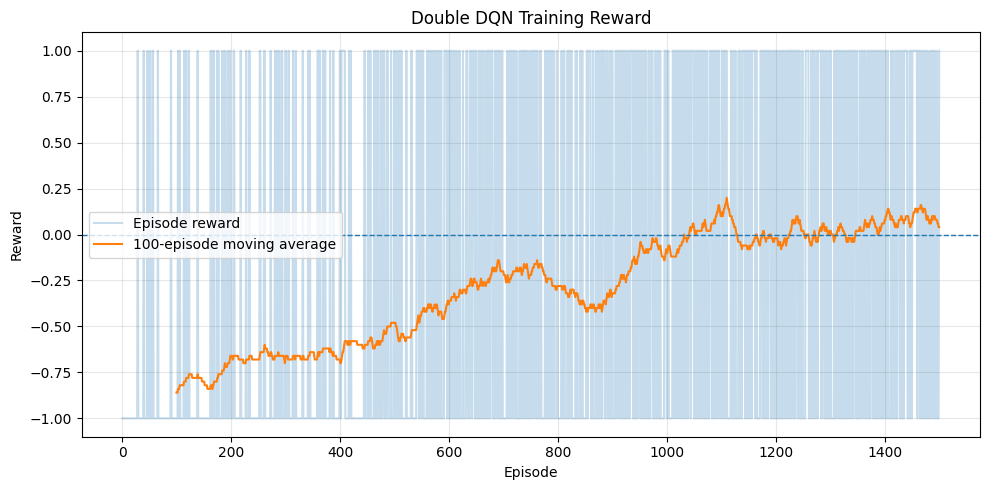

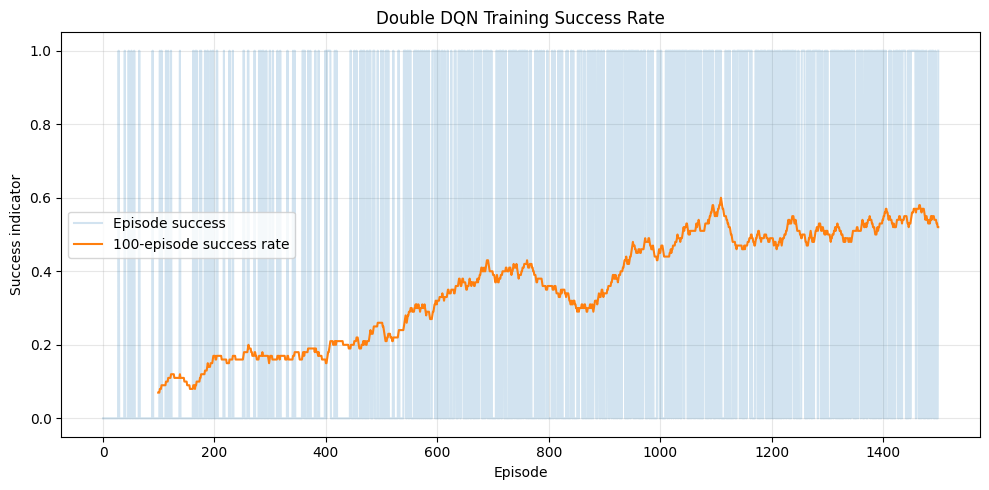

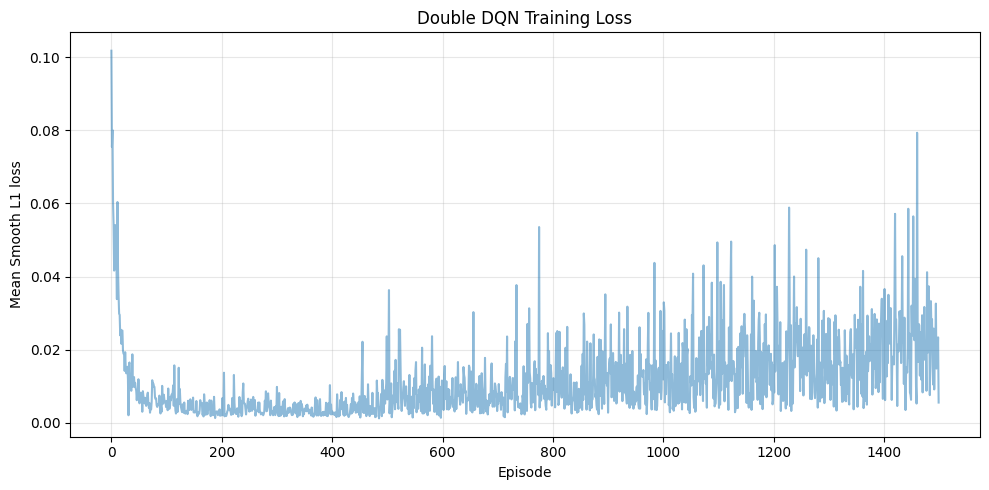

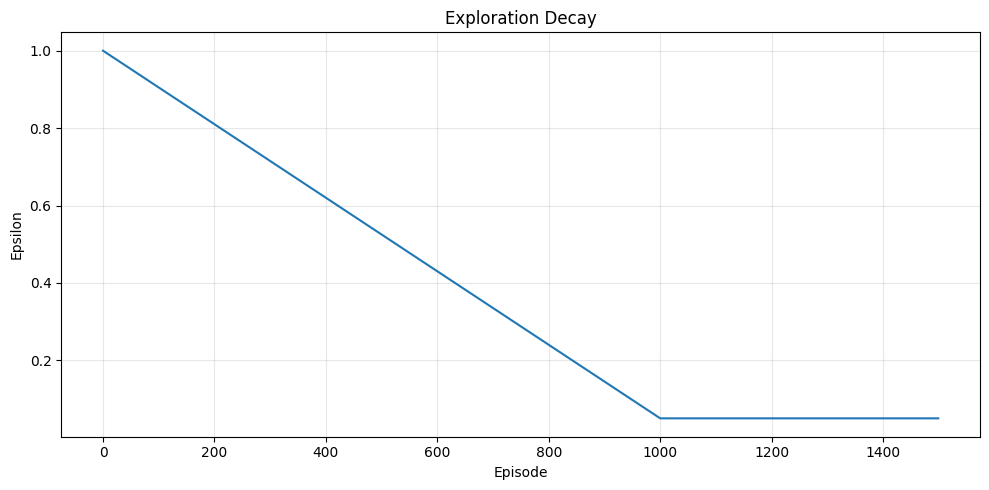

In [30]:

# ============================================================
# CELL 18 — DOUBLE DQN TRAINING
# ============================================================

import numpy as np
import torch
import matplotlib.pyplot as plt


# ============================================================
# 1. TRAINING HYPERPARAMETERS
# ============================================================

NUM_EPISODES = 1500

BATCH_SIZE = 64

GAMMA = 0.99

LEARNING_RATE = 1e-3

INITIAL_EPSILON = 1.0

MIN_EPSILON = 0.05

EPSILON_DECAY_EPISODES = 1000

TARGET_UPDATE_FREQUENCY = 200

GRADIENT_CLIP = 10.0

# Start gradient updates after enough experiences exist.

MIN_REPLAY_SIZE = 256


# ============================================================
# 2. CLEAN INITIALIZATION
# ============================================================

# Cell 16 performed one diagnostic update.
# Restore the original network parameters from the
# unchanged target network.

online_network.load_state_dict(
    target_network.state_dict()
)

# Keep both networks synchronized initially.

target_network.load_state_dict(
    online_network.state_dict()
)

target_network.eval()

online_network.train()

# Recreate optimizer to remove diagnostic optimizer state.

optimizer = torch.optim.Adam(
    online_network.parameters(),
    lr=LEARNING_RATE,
)

print("=" * 70)
print("DOUBLE DQN TRAINING")
print("=" * 70)

print("\nDevice:", DEVICE)

print("Training episodes:", NUM_EPISODES)

print("Batch size:", BATCH_SIZE)

print("Learning rate:", LEARNING_RATE)

print("Gamma:", GAMMA)

print("Target update frequency:", TARGET_UPDATE_FREQUENCY)

print("Initial replay size:", len(replay_buffer))


# ============================================================
# 3. EPSILON SCHEDULE
# ============================================================

def get_epsilon(episode):

    fraction = min(
        episode / EPSILON_DECAY_EPISODES,
        1.0,
    )

    epsilon = (
        INITIAL_EPSILON
        - fraction * (
            INITIAL_EPSILON - MIN_EPSILON
        )
    )

    return max(
        MIN_EPSILON,
        epsilon,
    )


# ============================================================
# 4. TRAINING HISTORY
# ============================================================

training_rewards = []

training_successes = []

training_lengths = []

training_losses = []

epsilon_history = []

gradient_updates = 0

successful_episodes = 0


# ============================================================
# 5. MAIN TRAINING LOOP
# ============================================================

for episode in range(1, NUM_EPISODES + 1):

    epsilon = get_epsilon(episode - 1)

    # --------------------------------------------------------
    # Generate one episode
    # --------------------------------------------------------

    episode_result = generate_episode(
        epsilon=epsilon,
        buffer=replay_buffer,
        network=online_network,
    )

    episode_reward = episode_result["reward"]

    episode_steps = episode_result["steps"]

    episode_success = episode_result["success"]

    training_rewards.append(
        episode_reward
    )

    training_successes.append(
        int(episode_success)
    )

    training_lengths.append(
        episode_steps
    )

    epsilon_history.append(
        epsilon
    )

    successful_episodes += int(
        episode_success
    )

    # --------------------------------------------------------
    # Perform gradient updates
    # --------------------------------------------------------

    episode_losses = []

    if len(replay_buffer) >= MIN_REPLAY_SIZE:

        # One gradient update per environment transition.

        for _ in range(episode_steps):

            batch = replay_buffer.sample(
                BATCH_SIZE
            )

            update_info = double_dqn_update(
                batch=batch,
                online_network=online_network,
                target_network=target_network,
                optimizer=optimizer,
                gamma=GAMMA,
                gradient_clip=GRADIENT_CLIP,
            )

            episode_losses.append(
                update_info["loss"]
            )

            gradient_updates += 1

            # ------------------------------------------------
            # Synchronize target network periodically
            # ------------------------------------------------

            if (
                gradient_updates
                % TARGET_UPDATE_FREQUENCY
                == 0
            ):

                target_network.load_state_dict(
                    online_network.state_dict()
                )

                target_network.eval()

    if episode_losses:

        training_losses.append(
            float(np.mean(episode_losses))
        )

    else:

        training_losses.append(
            np.nan
        )

    # --------------------------------------------------------
    # Progress reporting
    # --------------------------------------------------------

    if episode % 100 == 0:

        recent_rewards = training_rewards[-100:]

        recent_successes = training_successes[-100:]

        recent_lengths = training_lengths[-100:]

        recent_losses = [
            value
            for value in training_losses[-100:]
            if np.isfinite(value)
        ]

        mean_loss = (
            float(np.mean(recent_losses))
            if recent_losses
            else float("nan")
        )

        print(
            f"\nEpisode {episode:4d}/{NUM_EPISODES}"
        )

        print(
            f"  Epsilon: {epsilon:.4f}"
        )

        print(
            f"  Mean reward (last 100): "
            f"{np.mean(recent_rewards):.4f}"
        )

        print(
            f"  Success rate (last 100): "
            f"{np.mean(recent_successes):.4f}"
        )

        print(
            f"  Mean episode length: "
            f"{np.mean(recent_lengths):.2f}"
        )

        print(
            f"  Mean loss: {mean_loss:.6f}"
        )

        print(
            f"  Replay size: {len(replay_buffer)}"
        )

        print(
            f"  Gradient updates: {gradient_updates}"
        )


# ============================================================
# 6. FINAL TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print("Total episodes:", NUM_EPISODES)

print("Total successful episodes:", successful_episodes)

print(
    "Overall training success rate:",
    round(
        float(np.mean(training_successes)),
        4,
    ),
)

print(
    "Final 100-episode success rate:",
    round(
        float(np.mean(training_successes[-100:])),
        4,
    ),
)

print(
    "Final 100-episode mean reward:",
    round(
        float(np.mean(training_rewards[-100:])),
        4,
    ),
)

print("Final epsilon:", round(epsilon, 4))

print("Replay buffer size:", len(replay_buffer))

print("Total gradient updates:", gradient_updates)


# ============================================================
# 7. PLOT TRAINING REWARD
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    training_rewards,
    alpha=0.25,
    label="Episode reward",
)

# Moving average over 100 episodes.

if len(training_rewards) >= 100:

    moving_average = np.convolve(
        training_rewards,
        np.ones(100) / 100,
        mode="valid",
    )

    plt.plot(
        np.arange(99, len(training_rewards)),
        moving_average,
        label="100-episode moving average",
    )

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Episode")

plt.ylabel("Reward")

plt.title("Double DQN Training Reward")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 8. PLOT TRAINING SUCCESS RATE
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    training_successes,
    alpha=0.2,
    label="Episode success",
)

if len(training_successes) >= 100:

    success_average = np.convolve(
        training_successes,
        np.ones(100) / 100,
        mode="valid",
    )

    plt.plot(
        np.arange(99, len(training_successes)),
        success_average,
        label="100-episode success rate",
    )

plt.xlabel("Episode")

plt.ylabel("Success indicator")

plt.title("Double DQN Training Success Rate")

plt.ylim(-0.05, 1.05)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 9. PLOT LOSS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    training_losses,
    alpha=0.5,
)

plt.xlabel("Episode")

plt.ylabel("Mean Smooth L1 loss")

plt.title("Double DQN Training Loss")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# ============================================================
# 10. PLOT EPSILON
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    epsilon_history,
)

plt.xlabel("Episode")

plt.ylabel("Epsilon")

plt.title("Exploration Decay")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [33]:

# ============================================================
# CELL 19A — LOAD VALIDATION AND TEST ARRAYS
# ============================================================

import os
import numpy as np

BASE_DIR = os.path.expanduser(
    "~/Desktop/qskit/qec_ml"
)

DATA_DIR = os.path.join(
    BASE_DIR,
    "datasets",
)

DATASET_PATH = os.path.join(
    DATA_DIR,
    "surface_code_d3_r3_p001.npz",
)

SPLITS_PATH = os.path.join(
    DATA_DIR,
    "surface_code_d3_r3_p001_splits.npz",
)


# ------------------------------------------------------------
# Load original dataset and saved split indices
# ------------------------------------------------------------

with np.load(DATASET_PATH) as dataset:

    D_history = dataset["D_history"].copy()
    D_final = dataset["D_final"].copy()
    L_target = dataset["L_target"].copy()

with np.load(SPLITS_PATH) as splits:

    train_indices = splits["train_indices"].copy()
    validation_indices = splits["validation_indices"].copy()
    test_indices = splits["test_indices"].copy()


# ------------------------------------------------------------
# Construct validation arrays
# ------------------------------------------------------------

val_D_history = D_history[validation_indices]
val_D_final = D_final[validation_indices]
val_L_target = L_target[validation_indices]


# ------------------------------------------------------------
# Construct test arrays
# These remain reserved for final evaluation.
# ------------------------------------------------------------

test_D_history = D_history[test_indices]
test_D_final = D_final[test_indices]
test_L_target = L_target[test_indices]


# ------------------------------------------------------------
# Verify training arrays agree with Cell 8
# ------------------------------------------------------------

assert np.array_equal(
    train_D_history,
    D_history[train_indices],
)

assert np.array_equal(
    train_D_final,
    D_final[train_indices],
)

assert np.array_equal(
    train_L_target,
    L_target[train_indices],
)


# ------------------------------------------------------------
# Shape and integrity checks
# ------------------------------------------------------------

assert val_D_history.shape == (2999, 20)
assert val_D_final.shape == (2999, 4)
assert val_L_target.shape == (2999,)

assert test_D_history.shape == (3002, 20)
assert test_D_final.shape == (3002, 4)
assert test_L_target.shape == (3002,)

assert len(
    np.intersect1d(train_indices, validation_indices)
) == 0

assert len(
    np.intersect1d(train_indices, test_indices)
) == 0

assert len(
    np.intersect1d(validation_indices, test_indices)
) == 0


print("=" * 65)
print("VALIDATION AND TEST DATA LOADED")
print("=" * 65)

print("\nValidation:")
print("  D_history:", val_D_history.shape)
print("  D_final:  ", val_D_final.shape)
print("  L_target: ", val_L_target.shape)
print("  Logical-1 rate:", round(float(val_L_target.mean()), 4))

print("\nTest:")
print("  D_history:", test_D_history.shape)
print("  D_final:  ", test_D_final.shape)
print("  L_target: ", test_L_target.shape)
print("  Logical-1 rate:", round(float(test_L_target.mean()), 4))

print("\nAll checks passed.")
print("Test data remains unused for model evaluation.")


VALIDATION AND TEST DATA LOADED

Validation:
  D_history: (2999, 20)
  D_final:   (2999, 4)
  L_target:  (2999,)
  Logical-1 rate: 0.1887

Test:
  D_history: (3002, 20)
  D_final:   (3002, 4)
  L_target:  (3002,)
  Logical-1 rate: 0.1889

All checks passed.
Test data remains unused for model evaluation.


In [34]:

# ============================================================
# CELL 19 — VALIDATION EVALUATION (NO TRAINING)
# ============================================================

import numpy as np
import torch


# ============================================================
# 1. VALIDATION CONFIGURATION
# ============================================================

VALIDATION_MAX_CORRECTIONS = 9

VALIDATION_STOP_ACTION = 9

VALIDATION_EPSILON = 0.0


# ============================================================
# 2. VALIDATION DATA CHECKS
# ============================================================

assert val_D_history.shape[1] == 20
assert val_D_final.shape[1] == 4
assert val_L_target.ndim == 1

assert len(val_D_history) == len(val_D_final)
assert len(val_D_history) == len(val_L_target)

assert H_terminal.shape == (9, 4)
assert logical_effect.shape == (9,)

print("=" * 70)
print("VALIDATION DATA")
print("=" * 70)

print("Validation samples:", len(val_D_history))
print("Historical detectors:", val_D_history.shape[1])
print("Final detectors:", val_D_final.shape[1])
print("Logical target shape:", val_L_target.shape)


# ============================================================
# 3. CONSTRUCT VALIDATION OBSERVATION
# ============================================================

def make_validation_observation(
    history,
    correction_bits,
    step_count,
):

    """
    Construct the same 30-dimensional observation
    used by the training environment.

    Observation:
        20 historical detector bits
        9 correction-selection bits
        1 normalized step count
    """

    normalized_step = (
        step_count / VALIDATION_MAX_CORRECTIONS
    )

    observation = np.concatenate([

        np.asarray(history, dtype=np.float32),

        np.asarray(correction_bits, dtype=np.float32),

        np.array(
            [normalized_step],
            dtype=np.float32,
        ),

    ])

    assert observation.shape == (30,)

    return observation


# ============================================================
# 4. GREEDY VALIDATION EPISODE
# ============================================================

def evaluate_validation_sample(
    sample_index,
    network,
):

    """
    Evaluate one validation example.

    The policy sees only historical detectors and
    its own correction-selection history.

    D_final and L_target are accessed only after
    the agent terminates its correction sequence.
    """

    history = val_D_history[sample_index]

    # Hidden values are retained for terminal evaluation.
    # They are NOT passed to the policy.

    hidden_final = val_D_final[sample_index]

    hidden_logical = int(
        val_L_target[sample_index]
    )

    correction_bits = np.zeros(
        9,
        dtype=np.uint8,
    )

    step_count = 0

    selected_actions = []

    done = False

    while not done:

        # ----------------------------------------------------
        # Construct current observation
        # ----------------------------------------------------

        observation = make_validation_observation(
            history=history,
            correction_bits=correction_bits,
            step_count=step_count,
        )

        # ----------------------------------------------------
        # Construct valid-action mask
        # ----------------------------------------------------

        action_mask = np.ones(
            10,
            dtype=bool,
        )

        # Previously selected corrections are unavailable.

        action_mask[:9] = (
            correction_bits == 0
        )

        # STOP is always available.

        action_mask[VALIDATION_STOP_ACTION] = True

        # ----------------------------------------------------
        # Greedy action selection
        # ----------------------------------------------------

        action = select_action(
            observation=observation,
            valid_action_mask=action_mask,
            epsilon=VALIDATION_EPSILON,
            network=network,
        )

        selected_actions.append(action)

        # ----------------------------------------------------
        # Process selected action
        # ----------------------------------------------------

        if action == VALIDATION_STOP_ACTION:

            done = True

        else:

            correction_bits[action] = 1

            step_count += 1

            # Automatic termination after nine corrections.

            if step_count >= VALIDATION_MAX_CORRECTIONS:

                done = True

    # ========================================================
    # 5. TERMINAL REWARD
    # ========================================================

    # Corrections affect only the final four detectors.

    residual_detectors = (
        hidden_final
        ^ (
            correction_bits @ H_terminal
        ) % 2
    )

    residual_logical = (
        hidden_logical
        ^ (
            correction_bits @ logical_effect
        ) % 2
    )

    detector_success = bool(
        np.all(residual_detectors == 0)
    )

    logical_success = bool(
        residual_logical == 0
    )

    success = (
        detector_success
        and logical_success
    )

    return {

        "success": success,

        "reward": 1.0 if success else -1.0,

        "steps": step_count,

        "correction_weight": int(
            np.sum(correction_bits)
        ),

        "selected_actions": selected_actions,

        "residual_detectors": residual_detectors,

        "residual_logical": int(residual_logical),

        "detector_success": detector_success,

        "logical_success": logical_success,
    }


# ============================================================
# 6. FREEZE NETWORK FOR EVALUATION
# ============================================================

online_network.eval()

validation_results = []

print("\n" + "=" * 70)
print("RUNNING GREEDY VALIDATION")
print("=" * 70)

with torch.no_grad():

    for i in range(len(val_D_history)):

        result = evaluate_validation_sample(
            sample_index=i,
            network=online_network,
        )

        validation_results.append(result)

        if (i + 1) % 500 == 0:

            print(
                f"  Evaluated {i + 1}/"
                f"{len(val_D_history)} samples"
            )


# Restore training mode for possible later experiments.

online_network.train()


# ============================================================
# 7. CALCULATE VALIDATION METRICS
# ============================================================

validation_successes = np.array(
    [
        result["success"]
        for result in validation_results
    ],
    dtype=np.float32,
)

validation_rewards = np.array(
    [
        result["reward"]
        for result in validation_results
    ],
    dtype=np.float32,
)

validation_steps = np.array(
    [
        result["steps"]
        for result in validation_results
    ],
    dtype=np.float32,
)

validation_correction_weights = np.array(
    [
        result["correction_weight"]
        for result in validation_results
    ],
    dtype=np.float32,
)

validation_detector_successes = np.array(
    [
        result["detector_success"]
        for result in validation_results
    ],
    dtype=np.float32,
)

validation_logical_successes = np.array(
    [
        result["logical_success"]
        for result in validation_results
    ],
    dtype=np.float32,
)


# ============================================================
# 8. NO-CORRECTION BASELINE
# ============================================================

no_correction_successes = np.logical_and(

    np.all(
        val_D_final == 0,
        axis=1,
    ),

    val_L_target == 0,

)

no_correction_accuracy = float(
    np.mean(no_correction_successes)
)


# ============================================================
# 9. VALIDATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("DQN VALIDATION RESULTS")
print("=" * 70)

print("Validation samples:", len(val_D_history))

print(
    "DQN success rate:",
    round(float(np.mean(validation_successes)), 4),
)

print(
    "DQN mean reward:",
    round(float(np.mean(validation_rewards)), 4),
)

print(
    "No-correction success rate:",
    round(no_correction_accuracy, 4),
)

print(
    "Detector success rate:",
    round(float(np.mean(validation_detector_successes)), 4),
)

print(
    "Logical success rate:",
    round(float(np.mean(validation_logical_successes)), 4),
)

print(
    "Mean correction weight:",
    round(float(np.mean(validation_correction_weights)), 4),
)

print(
    "Mean correction steps:",
    round(float(np.mean(validation_steps)), 4),
)

print(
    "Maximum correction steps:",
    int(np.max(validation_steps)),
)


# ============================================================
# 10. VALIDATION SANITY CHECKS
# ============================================================

assert len(validation_results) == len(val_D_history)

assert np.all(
    validation_steps <= VALIDATION_MAX_CORRECTIONS
)

assert np.all(
    (validation_correction_weights >= 0)
    & (validation_correction_weights <= 9)
)

assert np.all(
    np.isin(validation_rewards, [-1.0, 1.0])
)

print("\nValidation sanity checks: PASSED")

VALIDATION DATA
Validation samples: 2999
Historical detectors: 20
Final detectors: 4
Logical target shape: (2999,)

RUNNING GREEDY VALIDATION
  Evaluated 500/2999 samples
  Evaluated 1000/2999 samples
  Evaluated 1500/2999 samples
  Evaluated 2000/2999 samples
  Evaluated 2500/2999 samples

DQN VALIDATION RESULTS
Validation samples: 2999
DQN success rate: 0.5575
DQN mean reward: 0.115
No-correction success rate: 0.5915
Detector success rate: 0.6622
Logical success rate: 0.7279
Mean correction weight: 3.4935
Mean correction steps: 3.4935
Maximum correction steps: 9

Validation sanity checks: PASSED


In [38]:
import numpy as np
import torch
from collections import Counter

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

NUM_CORRECTIONS = 9
STOP_ACTION = 9
MAX_STEPS = 9

assert len(val_D_history) == len(val_D_final) == len(val_L_target)

# Detect device directly from trained network
device = next(online_network.parameters()).device

# Preserve original network mode
original_training_mode = online_network.training
online_network.eval()

correction_counts = []
correction_frequency = np.zeros(NUM_CORRECTIONS, dtype=int)

success_by_weight = Counter()
samples_by_weight = Counter()

total_success = 0
total_detector_success = 0
total_logical_success = 0
stop_without_correction = 0

# ------------------------------------------------------------
# 2. Greedy policy evaluation
# ------------------------------------------------------------

with torch.no_grad():

    for i in range(len(val_D_history)):

        history = val_D_history[i].astype(np.float32)

        correction = np.zeros(
            NUM_CORRECTIONS,
            dtype=np.float32
        )

        steps = 0

        while True:

            observation = np.concatenate([
                history,
                correction,
                np.array([steps / MAX_STEPS], dtype=np.float32)
            ]).astype(np.float32)

            state_tensor = torch.tensor(
                observation,
                dtype=torch.float32,
                device=device
            ).unsqueeze(0)

            q_values = online_network(state_tensor).squeeze(0).clone()

            # Mask previously selected corrections
            action_mask = torch.ones(
                NUM_CORRECTIONS + 1,
                dtype=torch.bool,
                device=device
            )

            for q in range(NUM_CORRECTIONS):
                if correction[q] == 1:
                    action_mask[q] = False

            q_values[~action_mask] = -float("inf")

            action = int(torch.argmax(q_values).item())

            if action == STOP_ACTION:
                break

            correction[action] = 1.0
            correction_frequency[action] += 1
            steps += 1

            if steps >= MAX_STEPS:
                break

        # ----------------------------------------------------
        # 3. Calculate residuals
        # ----------------------------------------------------

        correction_uint = correction.astype(np.uint8)

        residual_detectors = (
            val_D_final[i].astype(np.uint8)
            ^ ((correction_uint @ H_terminal) % 2)
        )

        residual_logical = (
            int(val_L_target[i])
            ^ int((correction_uint @ logical_effect) % 2)
        )

        detector_ok = bool(np.all(residual_detectors == 0))
        logical_ok = bool(residual_logical == 0)

        success = detector_ok and logical_ok

        total_detector_success += int(detector_ok)
        total_logical_success += int(logical_ok)
        total_success += int(success)

        correction_counts.append(steps)

        success_by_weight[steps] += int(success)
        samples_by_weight[steps] += 1

        if steps == 0:
            stop_without_correction += 1

# ------------------------------------------------------------
# 4. Restore original network mode
# ------------------------------------------------------------

online_network.train(original_training_mode)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

N = len(val_D_history)

print("=" * 65)
print("DQN CORRECTION BEHAVIOUR DIAGNOSTICS")
print("=" * 65)

print(f"\nDevice: {device}")
print(f"Validation samples: {N}")

print("\n1. POLICY PERFORMANCE")
print("-" * 65)

print(f"Joint success rate:    {total_success / N:.4f}")
print(f"Detector success rate: {total_detector_success / N:.4f}")
print(f"Logical success rate:  {total_logical_success / N:.4f}")

print("\n2. CORRECTION COUNT DISTRIBUTION")
print("-" * 65)

for weight in range(NUM_CORRECTIONS + 1):

    count = samples_by_weight[weight]

    if count > 0:
        success_rate = success_by_weight[weight] / count

        print(
            f"Corrections = {weight}: "
            f"{count:4d} samples "
            f"({count/N:.2%}), "
            f"success = {success_rate:.4f}"
        )

print("\n3. ACTION FREQUENCY")
print("-" * 65)

for q in range(NUM_CORRECTIONS):
    print(
        f"Qubit {int(data_qubits[q]):2d}: "
        f"{correction_frequency[q]:5d} selections"
    )

print("\n4. SUMMARY")
print("-" * 65)

print(f"Mean correction count: {np.mean(correction_counts):.4f}")
print(f"Minimum corrections:   {np.min(correction_counts)}")
print(f"Maximum corrections:   {np.max(correction_counts)}")

print(
    f"STOP without correction: "
    f"{stop_without_correction} "
    f"({stop_without_correction/N:.2%})"
)

print("\nDiagnostic completed successfully.")

DQN CORRECTION BEHAVIOUR DIAGNOSTICS

Device: cuda:0
Validation samples: 2999

1. POLICY PERFORMANCE
-----------------------------------------------------------------
Joint success rate:    0.5575
Detector success rate: 0.6622
Logical success rate:  0.7279

2. CORRECTION COUNT DISTRIBUTION
-----------------------------------------------------------------
Corrections = 0: 1499 samples (49.98%), success = 0.7959
Corrections = 1:  129 samples (4.30%), success = 0.4884
Corrections = 2:   42 samples (1.40%), success = 0.6905
Corrections = 3:   17 samples (0.57%), success = 0.1176
Corrections = 4:  212 samples (7.07%), success = 0.6085
Corrections = 5:   35 samples (1.17%), success = 0.1143
Corrections = 6:   25 samples (0.83%), success = 0.0000
Corrections = 7:   94 samples (3.13%), success = 0.0532
Corrections = 8:  132 samples (4.40%), success = 0.0076
Corrections = 9:  814 samples (27.14%), success = 0.3022

3. ACTION FREQUENCY
------------------------------------------------------------

In [39]:
import numpy as np
import torch
from collections import defaultdict

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

NUM_CORRECTIONS = 9
STOP_ACTION = 9
MAX_STEPS = 9

device = next(online_network.parameters()).device

original_mode = online_network.training
online_network.eval()

# Store statistics separately for each decision step
step_gaps = defaultdict(list)
step_stop_q = defaultdict(list)
step_best_correction_q = defaultdict(list)
step_selected_actions = defaultdict(list)

# ------------------------------------------------------------
# 2. Evaluate Q-values along greedy trajectories
# ------------------------------------------------------------

with torch.no_grad():

    for i in range(len(val_D_history)):

        history = val_D_history[i].astype(np.float32)
        correction = np.zeros(NUM_CORRECTIONS, dtype=np.float32)

        steps = 0

        while steps < MAX_STEPS:

            observation = np.concatenate([
                history,
                correction,
                np.array([steps / MAX_STEPS], dtype=np.float32)
            ]).astype(np.float32)

            state_tensor = torch.tensor(
                observation,
                dtype=torch.float32,
                device=device
            ).unsqueeze(0)

            q_values = online_network(state_tensor).squeeze(0)

            # Mask already selected corrections
            valid_corrections = [
                q for q in range(NUM_CORRECTIONS)
                if correction[q] == 0
            ]

            correction_q = q_values[valid_corrections]
            stop_q = q_values[STOP_ACTION]

            best_correction_q = correction_q.max()

            # Positive gap means a correction is preferred.
            # Negative gap means STOP is preferred.
            gap = best_correction_q - stop_q

            gap_value = float(gap.item())
            stop_value = float(stop_q.item())
            correction_value = float(best_correction_q.item())

            # Greedy action
            action = (
                valid_corrections[
                    int(torch.argmax(correction_q).item())
                ]
                if gap_value > 0
                else STOP_ACTION
            )

            step_gaps[steps].append(gap_value)
            step_stop_q[steps].append(stop_value)
            step_best_correction_q[steps].append(correction_value)
            step_selected_actions[steps].append(action)

            if action == STOP_ACTION:
                break

            correction[action] = 1.0
            steps += 1

# ------------------------------------------------------------
# 3. Restore original network mode
# ------------------------------------------------------------

online_network.train(original_mode)

# ------------------------------------------------------------
# 4. Display Q-value analysis
# ------------------------------------------------------------

print("=" * 75)
print("DQN Q-VALUE AND STOP-PREFERENCE DIAGNOSTICS")
print("=" * 75)

print("\n1. Q-VALUE COMPARISON BY DECISION STEP")
print("-" * 75)

print(
    f"{'Step':>5} {'Samples':>8} {'Mean STOP Q':>13} "
    f"{'Mean Best Q':>13} {'Mean Gap':>12} "
    f"{'Correction %':>14}"
)

for step in sorted(step_gaps):

    gaps = np.array(step_gaps[step])
    stop_values = np.array(step_stop_q[step])
    correction_values = np.array(step_best_correction_q[step])
    actions = np.array(step_selected_actions[step])

    correction_rate = np.mean(actions != STOP_ACTION)

    print(
        f"{step:5d} "
        f"{len(gaps):8d} "
        f"{np.mean(stop_values):13.4f} "
        f"{np.mean(correction_values):13.4f} "
        f"{np.mean(gaps):12.4f} "
        f"{correction_rate:13.2%}"
    )

print("\n2. INITIAL-STATE Q-VALUE DISTRIBUTION")
print("-" * 75)

initial_gaps = np.array(step_gaps[0])

print(f"Mean gap:   {np.mean(initial_gaps):.5f}")
print(f"Median gap: {np.median(initial_gaps):.5f}")
print(f"Std gap:    {np.std(initial_gaps):.5f}")

print(
    f"Correction preferred: "
    f"{np.mean(initial_gaps > 0):.2%}"
)

print(
    f"STOP preferred:       "
    f"{np.mean(initial_gaps <= 0):.2%}"
)

print("\n3. INTERPRETATION")
print("-" * 75)

if np.mean(initial_gaps > 0) > 0.5:
    print("The network prefers a correction for most initial states.")
else:
    print("The network prefers STOP for most initial states.")

print(
    "Positive gap = best valid correction has a higher Q-value than STOP."
)

print("\nDiagnostic completed.")

DQN Q-VALUE AND STOP-PREFERENCE DIAGNOSTICS

1. Q-VALUE COMPARISON BY DECISION STEP
---------------------------------------------------------------------------
 Step  Samples   Mean STOP Q   Mean Best Q     Mean Gap   Correction %
    0     2999        0.0304       -0.0720      -0.1024        50.02%
    1     1500       -0.7311        0.0050       0.7361        91.40%
    2     1371       -0.7751       -0.0090       0.7661        96.94%
    3     1329       -0.7245       -0.0243       0.7002        98.72%
    4     1312       -0.6705       -0.2109       0.4596        83.84%
    5     1100       -0.9223       -0.3181       0.6043        96.82%
    6     1065       -0.9237       -0.3870       0.5367        97.65%
    7     1040       -0.9068       -0.4483       0.4585        90.96%
    8      946       -0.8894       -0.5564       0.3330        86.05%

2. INITIAL-STATE Q-VALUE DISTRIBUTION
---------------------------------------------------------------------------
Mean gap:   -0.10237
Med

In [40]:
import numpy as np

# ------------------------------------------------------------
# 1. Find ReplayBuffer instance
# ------------------------------------------------------------

buffer_candidates = {
    name: obj
    for name, obj in globals().copy().items()
    if obj.__class__.__name__ == "ReplayBuffer"
}

print("=" * 70)
print("REPLAY BUFFER INSPECTION")
print("=" * 70)

if not buffer_candidates:
    print("No ReplayBuffer instance found.")
else:
    for name, buffer in buffer_candidates.items():

        print(f"\nBuffer variable: {name}")
        print("-" * 70)

        for attr_name, value in buffer.__dict__.items():

            if isinstance(value, np.ndarray):
                print(
                    f"{attr_name:25s} "
                    f"shape={str(value.shape):18s} "
                    f"dtype={value.dtype}"
                )
            elif isinstance(value, (int, float, bool, str)):
                print(f"{attr_name:25s} {value}")
            else:
                print(f"{attr_name:25s} {type(value).__name__}")

REPLAY BUFFER INSPECTION

Buffer variable: replay_buffer
----------------------------------------------------------------------
capacity                  50000
observation_dim           30
action_dim                10
position                  7685
size                      7685
rng                       Generator
states                    shape=(50000, 30)        dtype=float32
actions                   shape=(50000,)           dtype=int64
rewards                   shape=(50000,)           dtype=float32
next_states               shape=(50000, 30)        dtype=float32
dones                     shape=(50000,)           dtype=float32
next_action_masks         shape=(50000, 10)        dtype=bool

Buffer variable: small_buffer
----------------------------------------------------------------------
capacity                  3
observation_dim           30
action_dim                10
position                  2
size                      3
rng                       Generator
states             

In [42]:
# ------------------------------------------------------------
# 1. Read the actual training replay buffer
# ------------------------------------------------------------

buffer = replay_buffer
n = buffer.size

assert n > 0

actions = buffer.actions[:n]
rewards = buffer.rewards[:n]
dones = buffer.dones[:n]

states = buffer.states[:n]
next_states = buffer.next_states[:n]
next_masks = buffer.next_action_masks[:n]

STOP_ACTION = 9
NUM_CORRECTIONS = 9

# ------------------------------------------------------------
# 2. Basic transition statistics
# ------------------------------------------------------------

print("=" * 70)
print("REPLAY BUFFER TRANSITION STATISTICS")
print("=" * 70)

print(f"\nTotal transitions: {n}")

print("\n1. ACTION FREQUENCY")
print("-" * 70)

for action in range(NUM_CORRECTIONS + 1):

    count = int(np.sum(actions == action))

    label = "STOP" if action == STOP_ACTION else f"Correction {action}"

    print(
        f"{label:18s}: {count:6d} "
        f"({count/n:.2%})"
    )

# ------------------------------------------------------------
# 3. Reward distribution
# ------------------------------------------------------------

print("\n2. REWARD DISTRIBUTION")
print("-" * 70)

unique_rewards, reward_counts = np.unique(
    rewards,
    return_counts=True
)

for reward, count in zip(unique_rewards, reward_counts):

    print(
        f"Reward {reward:+.1f}: "
        f"{count:6d} ({count/n:.2%})"
    )

print(f"Mean stored reward: {np.mean(rewards):.4f}")

# ------------------------------------------------------------
# 4. Terminal transition statistics
# ------------------------------------------------------------

terminal_mask = dones.astype(bool)
nonterminal_mask = ~terminal_mask

print("\n3. TERMINAL TRANSITIONS")
print("-" * 70)

terminal_count = int(np.sum(terminal_mask))
nonterminal_count = int(np.sum(nonterminal_mask))

print(f"Terminal transitions:    {terminal_count}")
print(f"Non-terminal transitions: {nonterminal_count}")

if terminal_count > 0:

    terminal_actions = actions[terminal_mask]
    terminal_rewards = rewards[terminal_mask]

    print("\nActions on terminal transitions:")

    for action in range(NUM_CORRECTIONS + 1):

        count = int(np.sum(terminal_actions == action))

        if count > 0:
            label = "STOP" if action == STOP_ACTION else f"Correction {action}"
            print(f"{label:18s}: {count:6d}")

    print("\nTerminal reward distribution:")

    for reward, count in zip(*np.unique(
        terminal_rewards,
        return_counts=True
    )):
        print(f"Reward {reward:+.1f}: {count:6d}")

# ------------------------------------------------------------
# 5. Episode-step distribution
# ------------------------------------------------------------

print("\n4. STATE STEP-COUNT DISTRIBUTION")
print("-" * 70)

# The final observation component stores normalized step count.
step_values = np.rint(
    states[:, -1] * NUM_CORRECTIONS
).astype(int)

for step in range(NUM_CORRECTIONS + 1):

    count = int(np.sum(step_values == step))

    if count > 0:
        print(
            f"Step {step}: {count:6d} "
            f"({count/n:.2%})"
        )

# ------------------------------------------------------------
# 6. Next-action mask statistics
# ------------------------------------------------------------

print("\n5. NEXT-ACTION MASK STATISTICS")
print("-" * 70)

valid_action_counts = next_masks.sum(axis=1)

print(
    f"Mean valid next actions: "
    f"{np.mean(valid_action_counts):.3f}"
)

print(
    f"Minimum valid next actions: "
    f"{np.min(valid_action_counts)}"
)

print(
    f"Maximum valid next actions: "
    f"{np.max(valid_action_counts)}"
)

print(
    f"Terminal transitions with any valid next action: "
    f"{np.sum(next_masks[terminal_mask].sum(axis=1) > 0)}"
)

REPLAY BUFFER TRANSITION STATISTICS

Total transitions: 7685

1. ACTION FREQUENCY
----------------------------------------------------------------------
Correction 0      :    712 (9.26%)
Correction 1      :    695 (9.04%)
Correction 2      :    713 (9.28%)
Correction 3      :    673 (8.76%)
Correction 4      :    740 (9.63%)
Correction 5      :    721 (9.38%)
Correction 6      :    726 (9.45%)
Correction 7      :    693 (9.02%)
Correction 8      :    714 (9.29%)
STOP              :   1298 (16.89%)

2. REWARD DISTRIBUTION
----------------------------------------------------------------------
Reward -1.0:   1052 (13.69%)
Reward +0.0:   6085 (79.18%)
Reward +1.0:    548 (7.13%)
Mean stored reward: -0.0656

3. TERMINAL TRANSITIONS
----------------------------------------------------------------------
Terminal transitions:    1600
Non-terminal transitions: 6085

Actions on terminal transitions:
Correction 0      :     56
Correction 1      :     39
Correction 2      :     21
Correction 3   

In [43]:
# ------------------------------------------------------------
# 1. Extract terminal transitions
# ------------------------------------------------------------

buffer = replay_buffer
n = buffer.size

actions = buffer.actions[:n]
rewards = buffer.rewards[:n]
dones = buffer.dones[:n]
states = buffer.states[:n]

terminal_indices = np.where(dones.astype(bool))[0]

STOP_ACTION = 9
MAX_STEPS = 9

# Group terminal outcomes by action and step
results = defaultdict(lambda: {
    "total": 0,
    "success": 0,
    "failure": 0
})

# ------------------------------------------------------------
# 2. Analyse terminal transitions
# ------------------------------------------------------------

for idx in terminal_indices:

    action = int(actions[idx])
    reward = float(rewards[idx])

    step = int(round(
        float(states[idx, -1]) * MAX_STEPS
    ))

    if action == STOP_ACTION:
        action_type = "STOP"
    else:
        action_type = "MAX_LIMIT"

    key = (action_type, step)

    results[key]["total"] += 1

    if reward == 1:
        results[key]["success"] += 1
    elif reward == -1:
        results[key]["failure"] += 1

# ------------------------------------------------------------
# 3. Display results
# ------------------------------------------------------------

print("=" * 75)
print("TERMINAL REWARD DISTRIBUTION BY DECISION STEP")
print("=" * 75)

print(
    f"\n{'Action':12s} {'Step':>5s} {'Total':>8s} "
    f"{'Success':>9s} {'Failure':>9s} {'Success rate':>14s}"
)

print("-" * 75)

for action_type in ["STOP", "MAX_LIMIT"]:

    for step in range(MAX_STEPS):

        key = (action_type, step)

        if key not in results:
            continue

        r = results[key]

        total = r["total"]
        success = r["success"]
        failure = r["failure"]

        print(
            f"{action_type:12s} "
            f"{step:5d} "
            f"{total:8d} "
            f"{success:9d} "
            f"{failure:9d} "
            f"{success/total:13.2%}"
        )

# ------------------------------------------------------------
# 4. Overall terminal statistics
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("OVERALL TERMINAL STATISTICS")
print("=" * 75)

for action_type in ["STOP", "MAX_LIMIT"]:

    total = sum(
        r["total"]
        for (a, s), r in results.items()
        if a == action_type
    )

    success = sum(
        r["success"]
        for (a, s), r in results.items()
        if a == action_type
    )

    failure = sum(
        r["failure"]
        for (a, s), r in results.items()
        if a == action_type
    )

    if total > 0:
        print(f"\n{action_type}")
        print(f"Total:         {total}")
        print(f"Success:       {success}")
        print(f"Failure:       {failure}")
        print(f"Success rate:  {success/total:.4f}")

TERMINAL REWARD DISTRIBUTION BY DECISION STEP

Action        Step    Total   Success   Failure   Success rate
---------------------------------------------------------------------------
STOP             0      570       435       135        76.32%
STOP             1       75        12        63        16.00%
STOP             2       76         7        69         9.21%
STOP             3       50         0        50         0.00%
STOP             4       92        15        77        16.30%
STOP             5       94         3        91         3.19%
STOP             6       90         2        88         2.22%
STOP             7       97         2        95         2.06%
STOP             8      154         6       148         3.90%
MAX_LIMIT        8      302        66       236        21.85%

OVERALL TERMINAL STATISTICS

STOP
Total:         1298
Success:       482
Failure:       816
Success rate:  0.3713

MAX_LIMIT
Total:         302
Success:       66
Failure:       236
Success rate

In [44]:
import numpy as np
import torch

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

NUM_CORRECTIONS = 9
STOP_ACTION = 9
MAX_STEPS = 9

device = next(online_network.parameters()).device
original_mode = online_network.training

online_network.eval()


# ------------------------------------------------------------
# 2. Greedy evaluation function
# ------------------------------------------------------------

def evaluate_greedy_policy(D_history, D_final, L_target):

    total = len(D_history)

    successes = 0
    detector_successes = 0
    logical_successes = 0

    correction_weights = []

    with torch.no_grad():

        for i in range(total):

            history = D_history[i].astype(np.float32)

            correction = np.zeros(
                NUM_CORRECTIONS,
                dtype=np.float32
            )

            steps = 0

            while True:

                observation = np.concatenate([
                    history,
                    correction,
                    np.array(
                        [steps / MAX_STEPS],
                        dtype=np.float32
                    )
                ])

                state = torch.tensor(
                    observation,
                    dtype=torch.float32,
                    device=device
                ).unsqueeze(0)

                q_values = online_network(state).squeeze(0).clone()

                valid_actions = torch.ones(
                    NUM_CORRECTIONS + 1,
                    dtype=torch.bool,
                    device=device
                )

                for q in range(NUM_CORRECTIONS):
                    if correction[q] == 1:
                        valid_actions[q] = False

                q_values[~valid_actions] = -float("inf")

                action = int(torch.argmax(q_values).item())

                if action == STOP_ACTION:
                    break

                correction[action] = 1.0
                steps += 1

                if steps >= MAX_STEPS:
                    break

            # Calculate residual detector vector
            correction_uint = correction.astype(np.uint8)

            residual_detectors = (
                D_final[i].astype(np.uint8)
                ^ ((correction_uint @ H_terminal) % 2)
            )

            # Calculate residual logical observable
            residual_logical = (
                int(L_target[i])
                ^ int(
                    (correction_uint @ logical_effect) % 2
                )
            )

            detector_ok = np.all(residual_detectors == 0)
            logical_ok = residual_logical == 0

            detector_successes += int(detector_ok)
            logical_successes += int(logical_ok)

            successes += int(detector_ok and logical_ok)

            correction_weights.append(steps)

    return {
        "samples": total,
        "joint_success": successes / total,
        "detector_success": detector_successes / total,
        "logical_success": logical_successes / total,
        "mean_corrections": np.mean(correction_weights),
        "correction_weights": np.array(correction_weights)
    }


# ------------------------------------------------------------
# 3. Evaluate training and validation
# ------------------------------------------------------------

train_results = evaluate_greedy_policy(
    train_D_history,
    train_D_final,
    train_L_target
)

val_results = evaluate_greedy_policy(
    val_D_history,
    val_D_final,
    val_L_target
)

# ------------------------------------------------------------
# 4. No-correction baselines
# ------------------------------------------------------------

train_baseline = np.mean(
    np.all(train_D_final == 0, axis=1)
    & (train_L_target == 0)
)

val_baseline = np.mean(
    np.all(val_D_final == 0, axis=1)
    & (val_L_target == 0)
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

online_network.train(original_mode)

print("=" * 75)
print("GREEDY DQN: TRAINING VS VALIDATION")
print("=" * 75)

print(
    f"\n{'Metric':25s} "
    f"{'Training':>15s} "
    f"{'Validation':>15s}"
)

print("-" * 60)

metrics = [
    ("Joint success", "joint_success"),
    ("Detector success", "detector_success"),
    ("Logical success", "logical_success"),
    ("Mean corrections", "mean_corrections")
]

for label, key in metrics:

    print(
        f"{label:25s} "
        f"{train_results[key]:15.4f} "
        f"{val_results[key]:15.4f}"
    )

print("\nNO-CORRECTION BASELINE")
print("-" * 60)

print(f"Training:   {train_baseline:.4f}")
print(f"Validation: {val_baseline:.4f}")

print("\nDQN IMPROVEMENT OVER BASELINE")
print("-" * 60)

print(
    f"Training:   "
    f"{train_results['joint_success'] - train_baseline:+.4f}"
)

print(
    f"Validation: "
    f"{val_results['joint_success'] - val_baseline:+.4f}"
)

GREEDY DQN: TRAINING VS VALIDATION

Metric                           Training      Validation
------------------------------------------------------------
Joint success                      0.5606          0.5575
Detector success                   0.6590          0.6622
Logical success                    0.7406          0.7279
Mean corrections                   3.3833          3.4935

NO-CORRECTION BASELINE
------------------------------------------------------------
Training:   0.5978
Validation: 0.5915

DQN IMPROVEMENT OVER BASELINE
------------------------------------------------------------
Training:   -0.0372
Validation: -0.0340


In [45]:
# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

NUM_CORRECTIONS = 9
STOP_ACTION = 9
MAX_STEPS = 9

device = next(online_network.parameters()).device
original_mode = online_network.training

online_network.eval()

# Store per-sample results
dqn_success = []
baseline_success = []
correction_weights = []

# ------------------------------------------------------------
# 2. Evaluate DQN and no-correction baseline
# ------------------------------------------------------------

with torch.no_grad():

    for i in range(len(val_D_history)):

        history = val_D_history[i].astype(np.float32)

        correction = np.zeros(
            NUM_CORRECTIONS,
            dtype=np.float32
        )

        steps = 0

        # Greedy DQN episode
        while True:

            observation = np.concatenate([
                history,
                correction,
                np.array([steps / MAX_STEPS], dtype=np.float32)
            ]).astype(np.float32)

            state = torch.tensor(
                observation,
                dtype=torch.float32,
                device=device
            ).unsqueeze(0)

            q_values = online_network(state).squeeze(0).clone()

            # Mask already selected corrections
            valid_actions = torch.ones(
                NUM_CORRECTIONS + 1,
                dtype=torch.bool,
                device=device
            )

            for q in range(NUM_CORRECTIONS):
                if correction[q] == 1:
                    valid_actions[q] = False

            q_values[~valid_actions] = -float("inf")

            action = int(torch.argmax(q_values).item())

            if action == STOP_ACTION:
                break

            correction[action] = 1.0
            steps += 1

            if steps >= MAX_STEPS:
                break

        # ----------------------------------------------------
        # 3. DQN terminal outcome
        # ----------------------------------------------------

        correction_uint = correction.astype(np.uint8)

        dqn_residual_detectors = (
            val_D_final[i].astype(np.uint8)
            ^ ((correction_uint @ H_terminal) % 2)
        )

        dqn_residual_logical = (
            int(val_L_target[i])
            ^ int(
                (correction_uint @ logical_effect) % 2
            )
        )

        dqn_ok = (
            np.all(dqn_residual_detectors == 0)
            and dqn_residual_logical == 0
        )

        # ----------------------------------------------------
        # 4. Counterfactual: no correction
        # ----------------------------------------------------

        baseline_ok = (
            np.all(val_D_final[i] == 0)
            and int(val_L_target[i]) == 0
        )

        dqn_success.append(int(dqn_ok))
        baseline_success.append(int(baseline_ok))
        correction_weights.append(steps)

# ------------------------------------------------------------
# 5. Restore original network mode
# ------------------------------------------------------------

online_network.train(original_mode)

# ------------------------------------------------------------
# 6. Convert to arrays
# ------------------------------------------------------------

dqn_success = np.array(dqn_success)
baseline_success = np.array(baseline_success)
correction_weights = np.array(correction_weights)

used_corrections = correction_weights > 0
stopped_immediately = ~used_corrections

# ------------------------------------------------------------
# 7. Group-wise comparison
# ------------------------------------------------------------

def print_group_statistics(name, mask):

    count = int(np.sum(mask))

    if count == 0:
        return

    dqn_rate = np.mean(dqn_success[mask])
    baseline_rate = np.mean(baseline_success[mask])

    print(f"\n{name}")
    print("-" * 65)

    print(f"Samples:              {count}")
    print(f"DQN success:          {dqn_rate:.4f}")
    print(f"No-correction success:{baseline_rate: .4f}")

    print(f"Difference:           {dqn_rate-baseline_rate:+.4f}")

    print(
        f"Mean corrections:     "
        f"{np.mean(correction_weights[mask]):.4f}"
    )

print("=" * 70)
print("COUNTERFACTUAL VALIDATION ANALYSIS")
print("=" * 70)

print_group_statistics(
    "GROUP A: DQN STOPS IMMEDIATELY",
    stopped_immediately
)

print_group_statistics(
    "GROUP B: DQN APPLIES CORRECTIONS",
    used_corrections
)

# ------------------------------------------------------------
# 8. Overall paired comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OVERALL PAIRED COMPARISON")
print("=" * 70)

print(f"Total samples:             {len(dqn_success)}")
print(f"DQN success:               {np.mean(dqn_success):.4f}")
print(f"No-correction success:     {np.mean(baseline_success):.4f}")

# Four possible paired outcomes
dqn_only = np.sum(
    (dqn_success == 1) & (baseline_success == 0)
)

baseline_only = np.sum(
    (dqn_success == 0) & (baseline_success == 1)
)

both_success = np.sum(
    (dqn_success == 1) & (baseline_success == 1)
)

both_failure = np.sum(
    (dqn_success == 0) & (baseline_success == 0)
)

print("\nPaired outcome counts:")
print(f"DQN succeeds, baseline fails: {dqn_only}")
print(f"Baseline succeeds, DQN fails: {baseline_only}")
print(f"Both succeed:                 {both_success}")
print(f"Both fail:                    {both_failure}")

print("\nCounterfactual analysis completed.")

COUNTERFACTUAL VALIDATION ANALYSIS

GROUP A: DQN STOPS IMMEDIATELY
-----------------------------------------------------------------
Samples:              1499
DQN success:          0.7959
No-correction success: 0.7959
Difference:           +0.0000
Mean corrections:     0.0000

GROUP B: DQN APPLIES CORRECTIONS
-----------------------------------------------------------------
Samples:              1500
DQN success:          0.3193
No-correction success: 0.3873
Difference:           -0.0680
Mean corrections:     6.9847

OVERALL PAIRED COMPARISON
Total samples:             2999
DQN success:               0.5575
No-correction success:     0.5915

Paired outcome counts:
DQN succeeds, baseline fails: 322
Baseline succeeds, DQN fails: 424
Both succeed:                 1350
Both fail:                    903

Counterfactual analysis completed.


In [46]:
# ============================================================
# CELL 27: DQN CORRECTION WEIGHT VS MINIMUM-WEIGHT ORACLE
# ============================================================

NUM_CORRECTIONS = 9

# ------------------------------------------------------------
# 1. Enumerate all 512 possible correction patterns
# ------------------------------------------------------------

all_patterns = np.array(
    [
        [(mask >> bit) & 1 for bit in range(NUM_CORRECTIONS)]
        for mask in range(2 ** NUM_CORRECTIONS)
    ],
    dtype=np.uint8
)

pattern_weights = np.sum(all_patterns, axis=1)

# ------------------------------------------------------------
# 2. Calculate the response of every correction pattern
# ------------------------------------------------------------

detector_responses = (
    all_patterns @ H_terminal
) % 2

logical_responses = (
    all_patterns @ logical_effect
) % 2

print("Correction patterns:", all_patterns.shape)
print("Detector response matrix:", detector_responses.shape)
print("Logical response vector:", logical_responses.shape)

# ------------------------------------------------------------
# 3. Find minimum-weight valid correction for each sample
# ------------------------------------------------------------

oracle_min_weights = []
oracle_solution_counts = []

for i in range(len(val_D_history)):

    target_detectors = val_D_final[i].astype(np.uint8)
    target_logical = int(val_L_target[i])

    detector_match = np.all(
        detector_responses == target_detectors,
        axis=1
    )

    logical_match = (
        logical_responses == target_logical
    )

    valid_patterns = np.where(
        detector_match & logical_match
    )[0]

    if len(valid_patterns) == 0:
        oracle_min_weights.append(np.nan)
        oracle_solution_counts.append(0)

    else:
        minimum_weight = np.min(
            pattern_weights[valid_patterns]
        )

        oracle_min_weights.append(minimum_weight)
        oracle_solution_counts.append(len(valid_patterns))

oracle_min_weights = np.array(oracle_min_weights)
oracle_solution_counts = np.array(oracle_solution_counts)

# ------------------------------------------------------------
# 4. Compare with DQN correction counts
# ------------------------------------------------------------

dqn_weights = np.asarray(correction_weights)

assert len(dqn_weights) == len(oracle_min_weights)

valid_samples = np.isfinite(oracle_min_weights)

weight_excess = (
    dqn_weights[valid_samples]
    - oracle_min_weights[valid_samples]
)

# ------------------------------------------------------------
# 5. Print oracle statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MINIMUM-WEIGHT ORACLE STATISTICS")
print("=" * 70)

print("Validation samples:", len(oracle_min_weights))
print("Samples with valid corrections:", np.sum(valid_samples))
print("Samples without valid corrections:", np.sum(~valid_samples))

print(
    "Mean minimum correction weight:",
    f"{np.mean(oracle_min_weights[valid_samples]):.4f}"
)

print(
    "Maximum minimum correction weight:",
    int(np.max(oracle_min_weights[valid_samples]))
)

print("\nMinimum-weight distribution:")

for weight in range(NUM_CORRECTIONS + 1):

    count = np.sum(oracle_min_weights == weight)

    if count > 0:
        print(
            f"Weight {weight}: "
            f"{count} samples "
            f"({count / len(oracle_min_weights):.2%})"
        )

# ------------------------------------------------------------
# 6. DQN versus oracle
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DQN VS MINIMUM-WEIGHT ORACLE")
print("=" * 70)

print(f"DQN mean correction count:       {np.mean(dqn_weights):.4f}")
print(
    "Oracle mean minimum weight:      "
    f"{np.mean(oracle_min_weights[valid_samples]):.4f}"
)

print(f"Mean excess corrections:         {np.mean(weight_excess):.4f}")
print(f"Median excess corrections:       {np.median(weight_excess):.4f}")

print(
    "Samples where DQN uses more corrections:",
    f"{np.mean(weight_excess > 0):.2%}"
)

print(
    "Samples where DQN matches oracle weight:",
    f"{np.mean(weight_excess == 0):.2%}"
)

print(
    "Samples where DQN uses fewer corrections:",
    f"{np.mean(weight_excess < 0):.2%}"
)

# ------------------------------------------------------------
# 7. Compare only samples where DQN applies corrections
# ------------------------------------------------------------

corrected_mask = dqn_weights > 0
corrected_valid = corrected_mask & valid_samples

print("\n" + "=" * 70)
print("DQN-CORRECTED SAMPLES ONLY")
print("=" * 70)

print("Samples:", np.sum(corrected_valid))

print(
    "Mean DQN correction count:",
    f"{np.mean(dqn_weights[corrected_valid]):.4f}"
)

print(
    "Mean oracle minimum weight:",
    f"{np.mean(oracle_min_weights[corrected_valid]):.4f}"
)

print(
    "Mean excess correction count:",
    f"{np.mean(dqn_weights[corrected_valid] - oracle_min_weights[corrected_valid]):.4f}"
)

print("\nCell 27 completed.")

Correction patterns: (512, 9)
Detector response matrix: (512, 4)
Logical response vector: (512,)

MINIMUM-WEIGHT ORACLE STATISTICS
Validation samples: 2999
Samples with valid corrections: 2999
Samples without valid corrections: 0
Mean minimum correction weight: 0.7766
Maximum minimum correction weight: 3

Minimum-weight distribution:
Weight 0: 1774 samples (59.15%)
Weight 1: 492 samples (16.41%)
Weight 2: 362 samples (12.07%)
Weight 3: 371 samples (12.37%)

DQN VS MINIMUM-WEIGHT ORACLE
DQN mean correction count:       3.4935
Oracle mean minimum weight:      0.7766
Mean excess corrections:         2.7169
Median excess corrections:       0.0000
Samples where DQN uses more corrections: 46.72%
Samples where DQN matches oracle weight: 42.18%
Samples where DQN uses fewer corrections: 11.10%

DQN-CORRECTED SAMPLES ONLY
Samples: 1500
Mean DQN correction count: 6.9847
Mean oracle minimum weight: 1.2467
Mean excess correction count: 5.7380

Cell 27 completed.


In [48]:
# ============================================================
# CELL 28: VERIFY DQN CORRECTION PATTERNS
# ============================================================

NUM_CORRECTIONS = 9
STOP_ACTION = 9
MAX_STEPS = 9

model_device = next(online_network.parameters()).device
original_mode = online_network.training
online_network.eval()

dqn_patterns = []
dqn_action_counts = []

# ------------------------------------------------------------
# 1. Reconstruct greedy DQN policy on validation samples
# ------------------------------------------------------------

try:
    with torch.no_grad():

        for i in range(len(val_D_history)):

            history = val_D_history[i].astype(np.float32)

            corrections = np.zeros(
                NUM_CORRECTIONS,
                dtype=np.uint8
            )

            for step in range(MAX_STEPS + 1):

                # Observation:
                # 20 historical detectors
                # 9 correction-selection bits
                # 1 normalized step count

                state = np.concatenate([
                    history,
                    corrections.astype(np.float32),
                    np.array([step / MAX_STEPS], dtype=np.float32)
                ])

                state_tensor = torch.tensor(
                    state,
                    dtype=torch.float32,
                    device=model_device
                ).unsqueeze(0)

                q_values = online_network(state_tensor)[0].cpu().numpy()

                # Mask corrections already selected.
                valid_mask = np.ones(10, dtype=bool)
                valid_mask[:NUM_CORRECTIONS] = (corrections == 0)

                masked_q_values = q_values.copy()
                masked_q_values[~valid_mask] = -np.inf

                action = int(np.argmax(masked_q_values))

                if action == STOP_ACTION:
                    break

                corrections[action] = 1

            dqn_patterns.append(corrections.copy())
            dqn_action_counts.append(int(np.sum(corrections)))

finally:
    online_network.train(original_mode)

dqn_patterns = np.asarray(dqn_patterns, dtype=np.uint8)
dqn_action_counts = np.asarray(dqn_action_counts)

# ------------------------------------------------------------
# 2. Calculate terminal residuals
# ------------------------------------------------------------

predicted_detector_effects = (
    dqn_patterns @ H_terminal
) % 2

predicted_logical_effects = (
    dqn_patterns @ logical_effect
) % 2

residual_detectors = (
    val_D_final.astype(np.uint8)
    ^ predicted_detector_effects.astype(np.uint8)
)

residual_logical = (
    val_L_target.astype(np.uint8)
    ^ predicted_logical_effects.astype(np.uint8)
)

detector_success = np.all(residual_detectors == 0, axis=1)
logical_success = (residual_logical == 0)

joint_success = detector_success & logical_success

# ------------------------------------------------------------
# 3. Compare with previously reported validation results
# ------------------------------------------------------------

print("=" * 70)
print("DQN CORRECTION-PATTERN VERIFICATION")
print("=" * 70)

print("Validation samples:", len(dqn_patterns))
print("Mean correction count:", f"{np.mean(dqn_action_counts):.4f}")

print("\nSuccess rates:")
print("Detector success:", f"{np.mean(detector_success):.4f}")
print("Logical success: ", f"{np.mean(logical_success):.4f}")
print("Joint success:   ", f"{np.mean(joint_success):.4f}")

print("\nPrevious validation DQN success: 0.5575")

# ------------------------------------------------------------
# 4. Compare DQN patterns against all valid oracle patterns
# ------------------------------------------------------------

nearest_valid_distances = []
selected_pattern_valid = []

for i in range(len(dqn_patterns)):

    target_detectors = val_D_final[i].astype(np.uint8)
    target_logical = int(val_L_target[i])

    detector_match = np.all(
        detector_responses == target_detectors,
        axis=1
    )

    logical_match = (
        logical_responses == target_logical
    )

    valid_indices = np.where(
        detector_match & logical_match
    )[0]

    if len(valid_indices) == 0:
        raise RuntimeError(
            f"No valid oracle pattern for validation sample {i}"
        )

    distances = np.sum(
        np.abs(
            all_patterns[valid_indices].astype(np.int16)
            - dqn_patterns[i].astype(np.int16)
        ),
        axis=1
    )

    nearest_valid_distances.append(np.min(distances))

    selected_pattern_valid.append(
        bool(joint_success[i])
    )

nearest_valid_distances = np.asarray(nearest_valid_distances)
selected_pattern_valid = np.asarray(selected_pattern_valid)

# ------------------------------------------------------------
# 5. Report pattern validity and distance
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DISTANCE FROM NEAREST VALID ORACLE PATTERN")
print("=" * 70)

print(
    "DQN selected a valid pattern:",
    f"{np.mean(selected_pattern_valid):.2%}"
)

print(
    "Mean Hamming distance:",
    f"{np.mean(nearest_valid_distances):.4f}"
)

print(
    "Median Hamming distance:",
    f"{np.median(nearest_valid_distances):.4f}"
)

print("\nDistance distribution:")

for distance in range(NUM_CORRECTIONS + 1):

    count = np.sum(nearest_valid_distances == distance)

    if count:
        print(
            f"Distance {distance}: {count} samples "
            f"({count / len(nearest_valid_distances):.2%})"
        )

# ------------------------------------------------------------
# 6. Compare corrected and uncorrected groups
# ------------------------------------------------------------

corrected = dqn_action_counts > 0
stopped_immediately = ~corrected

print("\n" + "=" * 70)
print("VALIDITY BY DQN BEHAVIOUR")
print("=" * 70)

for label, mask in [
    ("STOP immediately", stopped_immediately),
    ("Applied corrections", corrected)
]:

    print(f"\n{label}:")
    print("Samples:", int(np.sum(mask)))

    print(
        "Joint success:",
        f"{np.mean(joint_success[mask]):.4f}"
    )

    print(
        "Valid correction pattern:",
        f"{np.mean(selected_pattern_valid[mask]):.4f}"
    )

    print(
        "Mean distance to nearest valid pattern:",
        f"{np.mean(nearest_valid_distances[mask]):.4f}"
    )

DQN CORRECTION-PATTERN VERIFICATION
Validation samples: 2999
Mean correction count: 3.4935

Success rates:
Detector success: 0.6622
Logical success:  0.7279
Joint success:    0.5575

Previous validation DQN success: 0.5575

DISTANCE FROM NEAREST VALID ORACLE PATTERN
DQN selected a valid pattern: 55.75%
Mean Hamming distance: 0.8269
Median Hamming distance: 0.0000

Distance distribution:
Distance 0: 1672 samples (55.75%)
Distance 1: 560 samples (18.67%)
Distance 2: 381 samples (12.70%)
Distance 3: 386 samples (12.87%)

VALIDITY BY DQN BEHAVIOUR

STOP immediately:
Samples: 1499
Joint success: 0.7959
Valid correction pattern: 0.7959
Mean distance to nearest valid pattern: 0.3062

Applied corrections:
Samples: 1500
Joint success: 0.3193
Valid correction pattern: 0.3193
Mean distance to nearest valid pattern: 1.3473


In [49]:
# ============================================================
# CELL 29: COUNTERFACTUAL FIRST-ACTION EVALUATION
# ============================================================

NUM_CORRECTIONS = 9
STOP_ACTION = 9
MAX_STEPS = 9

model_device = next(online_network.parameters()).device
original_mode = online_network.training
online_network.eval()

N = len(val_D_history)

# Results indexed as [forced_initial_action, sample]
counterfactual_success = np.zeros((10, N), dtype=np.uint8)
counterfactual_weights = np.zeros((10, N), dtype=np.int16)

# ------------------------------------------------------------
# 1. Evaluate each possible forced initial action
# ------------------------------------------------------------

try:
    with torch.no_grad():

        for forced_action in range(10):

            corrections = np.zeros(
                (N, NUM_CORRECTIONS),
                dtype=np.uint8
            )

            # Force the first action.
            if forced_action < NUM_CORRECTIONS:
                corrections[:, forced_action] = 1

                # The agent has now made one correction.
                active = np.ones(N, dtype=bool)
                current_step = 1

            else:
                # STOP immediately.
                active = np.zeros(N, dtype=bool)
                current_step = 0

            # Continue using the DQN's greedy policy.
            while np.any(active):

                states = np.concatenate(
                    [
                        val_D_history.astype(np.float32),
                        corrections.astype(np.float32),
                        np.full(
                            (N, 1),
                            current_step / MAX_STEPS,
                            dtype=np.float32
                        )
                    ],
                    axis=1
                )

                state_tensor = torch.as_tensor(
                    states,
                    dtype=torch.float32,
                    device=model_device
                )

                q_values = online_network(state_tensor).cpu().numpy()

                # Mask actions that have already been selected.
                valid_mask = np.ones((N, 10), dtype=bool)
                valid_mask[:, :NUM_CORRECTIONS] = (
                    corrections == 0
                )

                masked_q = q_values.copy()
                masked_q[~valid_mask] = -np.inf

                actions = np.argmax(masked_q, axis=1)

                # Only update samples whose episodes are still active.
                stopping = active & (actions == STOP_ACTION)
                active[stopping] = False

                selecting = active & (actions < NUM_CORRECTIONS)

                rows = np.where(selecting)[0]
                if len(rows) > 0:
                    corrections[
                        rows,
                        actions[rows]
                    ] = 1

                current_step += 1

                if current_step > MAX_STEPS:
                    break

            # Evaluate final correction subsets.
            detector_effects = (
                corrections @ H_terminal
            ) % 2

            logical_effects = (
                corrections @ logical_effect
            ) % 2

            residual_detectors = (
                val_D_final.astype(np.uint8)
                ^ detector_effects.astype(np.uint8)
            )

            residual_logical = (
                val_L_target.astype(np.uint8)
                ^ logical_effects.astype(np.uint8)
            )

            success = (
                np.all(residual_detectors == 0, axis=1)
                & (residual_logical == 0)
            )

            counterfactual_success[forced_action] = success.astype(
                np.uint8
            )

            counterfactual_weights[forced_action] = np.sum(
                corrections,
                axis=1
            )

finally:
    online_network.train(original_mode)

# ------------------------------------------------------------
# 2. Calculate the DQN's actual initial choices
# ------------------------------------------------------------

initial_states = np.concatenate(
    [
        val_D_history.astype(np.float32),
        np.zeros((N, NUM_CORRECTIONS), dtype=np.float32),
        np.zeros((N, 1), dtype=np.float32)
    ],
    axis=1
)

with torch.no_grad():
    initial_q = online_network(
        torch.as_tensor(
            initial_states,
            dtype=torch.float32,
            device=model_device
        )
    ).cpu().numpy()

chosen_initial_actions = np.argmax(initial_q, axis=1)

# Select each sample's counterfactual result corresponding
# to the action the DQN actually chose.
sample_indices = np.arange(N)

chosen_policy_success = counterfactual_success[
    chosen_initial_actions,
    sample_indices
]

chosen_policy_weights = counterfactual_weights[
    chosen_initial_actions,
    sample_indices
]

# ------------------------------------------------------------
# 3. Print results for each forced initial action
# ------------------------------------------------------------

action_names = [
    "Correction q1",
    "Correction q3",
    "Correction q5",
    "Correction q8",
    "Correction q10",
    "Correction q12",
    "Correction q15",
    "Correction q17",
    "Correction q19",
    "STOP"
]

print("=" * 75)
print("COUNTERFACTUAL FIRST-ACTION RESULTS")
print("=" * 75)

for action in range(10):

    print(f"\n{action_names[action]}")

    print(
        "Success rate:",
        f"{np.mean(counterfactual_success[action]):.4f}"
    )

    print(
        "Mean final corrections:",
        f"{np.mean(counterfactual_weights[action]):.4f}"
    )

# ------------------------------------------------------------
# 4. Compare actual DQN policy with forced-action alternatives
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ACTUAL DQN POLICY VS COUNTERFACTUAL INITIAL ACTIONS")
print("=" * 75)

print(
    "Actual DQN initial-policy success:",
    f"{np.mean(chosen_policy_success):.4f}"
)

print(
    "Actual DQN mean correction count:",
    f"{np.mean(chosen_policy_weights):.4f}"
)

best_forced_rates = np.max(
    np.mean(counterfactual_success, axis=1)
)

print(
    "Best single forced-action success rate:",
    f"{best_forced_rates:.4f}"
)

# Per-sample best outcome, using hidden targets.
# This is an oracle diagnostic, not an executable policy.
best_per_sample = np.max(
    counterfactual_success,
    axis=0
)

print(
    "Per-sample best first-action outcome:",
    f"{np.mean(best_per_sample):.4f}"
)

# ------------------------------------------------------------
# 5. Check consistency with previous greedy evaluation
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CONSISTENCY CHECK")
print("=" * 75)

print(
    "Previous greedy validation success: 0.5575"
)

print(
    "Reconstructed greedy validation success:",
    f"{np.mean(chosen_policy_success):.4f}"
)

print(
    "Initial action distribution:"
)

for action in range(10):

    count = np.sum(chosen_initial_actions == action)

    print(
        f"{action_names[action]}: "
        f"{count} ({count / N:.2%})"
    )

COUNTERFACTUAL FIRST-ACTION RESULTS

Correction q1
Success rate: 0.3695
Mean final corrections: 6.4091

Correction q3
Success rate: 0.3678
Mean final corrections: 6.4922

Correction q5
Success rate: 0.1264
Mean final corrections: 7.4338

Correction q8
Success rate: 0.1177
Mean final corrections: 7.5112

Correction q10
Success rate: 0.3908
Mean final corrections: 6.3668

Correction q12
Success rate: 0.1060
Mean final corrections: 7.2264

Correction q15
Success rate: 0.3908
Mean final corrections: 6.2141

Correction q17
Success rate: 0.1047
Mean final corrections: 7.9740

Correction q19
Success rate: 0.1130
Mean final corrections: 7.1601

STOP
Success rate: 0.5915
Mean final corrections: 0.0000

ACTUAL DQN POLICY VS COUNTERFACTUAL INITIAL ACTIONS
Actual DQN initial-policy success: 0.5575
Actual DQN mean correction count: 3.4935
Best single forced-action success rate: 0.5915
Per-sample best first-action outcome: 0.7643

CONSISTENCY CHECK
Previous greedy validation success: 0.5575
Reconstr

In [50]:
# ============================================================
# CELL 30: PAIRED INITIAL-ACTION EVALUATION
# ============================================================

N = len(val_D_history)
STOP_ACTION = 9

indices = np.arange(N)

# Actual DQN initial action and its corresponding rollout.
actual_success = counterfactual_success[
    chosen_initial_actions,
    indices
].astype(bool)

actual_weights = counterfactual_weights[
    chosen_initial_actions,
    indices
]

# Counterfactual outcome if the same sample had stopped immediately.
stop_success = counterfactual_success[
    STOP_ACTION
].astype(bool)

# ------------------------------------------------------------
# 1. Overall paired comparison
# ------------------------------------------------------------

corrected_initial = chosen_initial_actions < STOP_ACTION

rescued = actual_success & ~stop_success
damaged = ~actual_success & stop_success
both_success = actual_success & stop_success
both_failure = ~actual_success & ~stop_success

print("=" * 75)
print("PAIRED INITIAL-ACTION COMPARISON")
print("=" * 75)

print("Total validation samples:", N)
print("DQN initially chooses correction:", np.sum(corrected_initial))
print("DQN initially chooses STOP:", np.sum(~corrected_initial))

print("\nAll samples:")
print("DQN policy success:", f"{np.mean(actual_success):.4f}")
print("Immediate STOP success:", f"{np.mean(stop_success):.4f}")

print("\nPaired outcomes:")
print("DQN rescues:", int(np.sum(rescued)))
print("DQN damages:", int(np.sum(damaged)))
print("Both succeed:", int(np.sum(both_success)))
print("Both fail:", int(np.sum(both_failure)))

# ------------------------------------------------------------
# 2. Compare only samples where DQN initially chooses correction
# ------------------------------------------------------------

mask = corrected_initial

print("\n" + "=" * 75)
print("SAMPLES WHERE DQN INITIALLY CHOOSES A CORRECTION")
print("=" * 75)

print("Samples:", int(np.sum(mask)))

print(
    "DQN continuation success:",
    f"{np.mean(actual_success[mask]):.4f}"
)

print(
    "Immediate STOP success:",
    f"{np.mean(stop_success[mask]):.4f}"
)

print(
    "Difference:",
    f"{np.mean(actual_success[mask]) - np.mean(stop_success[mask]):+.4f}"
)

print(
    "Mean corrections under DQN:",
    f"{np.mean(actual_weights[mask]):.4f}"
)

print("\nPaired outcomes in this group:")
print("DQN rescues:", int(np.sum(rescued & mask)))
print("DQN damages:", int(np.sum(damaged & mask)))
print("Both succeed:", int(np.sum(both_success & mask)))
print("Both fail:", int(np.sum(both_failure & mask)))

# ------------------------------------------------------------
# 3. Break down the DQN's chosen initial correction
# ------------------------------------------------------------

action_names = [
    "q1", "q3", "q5", "q8", "q10",
    "q12", "q15", "q17", "q19"
]

print("\n" + "=" * 75)
print("PER-ACTION PAIRED COMPARISON")
print("=" * 75)

for action in range(9):

    action_mask = chosen_initial_actions == action

    if not np.any(action_mask):
        continue

    action_rescued = (
        actual_success & ~stop_success & action_mask
    )

    action_damaged = (
        ~actual_success & stop_success & action_mask
    )

    dqn_rate = np.mean(actual_success[action_mask])
    stop_rate = np.mean(stop_success[action_mask])

    print(f"\nInitial correction {action_names[action]}")
    print("Samples:", int(np.sum(action_mask)))
    print("DQN continuation success:", f"{dqn_rate:.4f}")
    print("Immediate STOP success:", f"{stop_rate:.4f}")
    print("Difference:", f"{dqn_rate - stop_rate:+.4f}")
    print("DQN rescues:", int(np.sum(action_rescued)))
    print("DQN damages:", int(np.sum(action_damaged)))

PAIRED INITIAL-ACTION COMPARISON
Total validation samples: 2999
DQN initially chooses correction: 1500
DQN initially chooses STOP: 1499

All samples:
DQN policy success: 0.5575
Immediate STOP success: 0.5915

Paired outcomes:
DQN rescues: 322
DQN damages: 424
Both succeed: 1350
Both fail: 903

SAMPLES WHERE DQN INITIALLY CHOOSES A CORRECTION
Samples: 1500
DQN continuation success: 0.3193
Immediate STOP success: 0.3873
Difference: -0.0680
Mean corrections under DQN: 6.9847

Paired outcomes in this group:
DQN rescues: 322
DQN damages: 424
Both succeed: 157
Both fail: 597

PER-ACTION PAIRED COMPARISON

Initial correction q1
Samples: 112
DQN continuation success: 0.1875
Immediate STOP success: 0.3214
Difference: -0.1339
DQN rescues: 19
DQN damages: 34

Initial correction q3
Samples: 417
DQN continuation success: 0.3621
Immediate STOP success: 0.4029
Difference: -0.0408
DQN rescues: 90
DQN damages: 107

Initial correction q5
Samples: 265
DQN continuation success: 0.1962
Immediate STOP succe

In [51]:
from scipy.stats import binomtest

# ============================================================
# CELL 31: PAIRED SIGNIFICANCE TEST
# ============================================================

# These are the paired outcomes from Cell 30.
rescued = int(np.sum(rescued & corrected_initial))
damaged = int(np.sum(damaged & corrected_initial))

discordant = rescued + damaged

# Under the null hypothesis, each discordant outcome
# is equally likely to favor either policy.
test = binomtest(
    k=rescued,
    n=discordant,
    p=0.5,
    alternative="two-sided"
)

# One-sided test: is DQN significantly worse than STOP?
one_sided = binomtest(
    k=rescued,
    n=discordant,
    p=0.5,
    alternative="less"
)

print("=" * 65)
print("PAIRED STATISTICAL SIGNIFICANCE TEST")
print("=" * 65)

print("DQN rescues:", rescued)
print("DQN damages:", damaged)
print("Discordant pairs:", discordant)

print(
    "Rescue fraction among discordant pairs:",
    f"{rescued / discordant:.4f}"
)

print("\nTwo-sided exact McNemar-equivalent binomial test")
print("p-value:", f"{test.pvalue:.8f}")

print("\nOne-sided test (DQN worse than STOP)")
print("p-value:", f"{one_sided.pvalue:.8f}")

print("\nInterpretation:")

if test.pvalue < 0.05:
    print(
        "The paired outcomes provide statistically significant "
        "evidence of a difference between the policies."
    )
else:
    print(
        "The paired outcomes do not provide sufficient evidence "
        "of a difference at the 5% significance level."
    )

if one_sided.pvalue < 0.05:
    print(
        "The evidence specifically favors immediate STOP over "
        "the DQN continuation policy on this selected group."
    )

PAIRED STATISTICAL SIGNIFICANCE TEST
DQN rescues: 322
DQN damages: 424
Discordant pairs: 746
Rescue fraction among discordant pairs: 0.4316

Two-sided exact McNemar-equivalent binomial test
p-value: 0.00021294

One-sided test (DQN worse than STOP)
p-value: 0.00010647

Interpretation:
The paired outcomes provide statistically significant evidence of a difference between the policies.
The evidence specifically favors immediate STOP over the DQN continuation policy on this selected group.


In [57]:

class RewardShapedQuantumFeedbackEnv(QuantumFeedbackEnv):
    """
    Reward-shaped version of QuantumFeedbackEnv.

    Original environment:
        - Intermediate correction reward: 0
        - Terminal success reward: +1
        - Terminal failure reward: -1

    Reward-shaped environment:
        - Every correction incurs a cost of lambda.
        - STOP incurs no correction cost.
        - A correction that triggers maximum-step termination
          receives terminal_reward - lambda.
    """

    def __init__(
        self,
        D_history,
        D_final,
        L_target,
        H_terminal,
        logical_effect,
        data_qubits,
        correction_cost=0.05,
        seed=42,
    ):

        if correction_cost < 0:
            raise ValueError("correction_cost must be non-negative.")

        super().__init__(
            D_history=D_history,
            D_final=D_final,
            L_target=L_target,
            H_terminal=H_terminal,
            logical_effect=logical_effect,
            data_qubits=data_qubits,
            seed=seed,
        )

        self.correction_cost = float(correction_cost)

    def step(self, action):

        if self.episode_done:
            raise RuntimeError(
                "Episode terminated. Call reset() first."
            )

        action = int(action)

        if not 0 <= action < self.num_actions:
            raise ValueError("Invalid action.")

        mask = self.valid_action_mask()

        if not mask[action]:
            raise ValueError(
                "Invalid action: correction was already selected."
            )

        # ----------------------------------------------------
        # STOP: no correction penalty
        # ----------------------------------------------------

        if action == self.stop_action:

            reward, success = self._calculate_terminal_reward()

            self.episode_done = True

            info = {
                "success": success,
                "correction_steps": self.correction_steps,
                "terminated_by": "STOP",
                "correction_cost": 0.0,
            }

            return self._get_observation(), reward, True, info

        # ----------------------------------------------------
        # Apply a new correction and charge its cost
        # ----------------------------------------------------

        self.correction_vector[action] = 1
        self.correction_steps += 1

        correction_penalty = self.correction_cost

        # ----------------------------------------------------
        # Maximum-step termination
        # ----------------------------------------------------

        if self.correction_steps == self.max_correction_steps:

            terminal_reward, success = (
                self._calculate_terminal_reward()
            )

            reward = terminal_reward - correction_penalty

            self.episode_done = True

            info = {
                "success": success,
                "correction_steps": self.correction_steps,
                "terminated_by": "MAX_STEPS",
                "correction_cost": correction_penalty,
            }

            return self._get_observation(), reward, True, info

        # ----------------------------------------------------
        # Nonterminal correction
        # ----------------------------------------------------

        return (
            self._get_observation(),
            -correction_penalty,
            False,
            {
                "success": None,
                "correction_steps": self.correction_steps,
                "terminated_by": None,
                "correction_cost": correction_penalty,
            },
        )


# ------------------------------------------------------------
# Instantiate a separate reward-shaped environment
# ------------------------------------------------------------

shaped_env = RewardShapedQuantumFeedbackEnv(
    D_history=train_D_history,
    D_final=train_D_final,
    L_target=train_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=data_qubits,
    correction_cost=0.05,
    seed=42,
)

print("Reward-shaped environment created successfully.")
print("Correction cost:", shaped_env.correction_cost)
print("Observation dimension:", shaped_env.observation_dim)
print("Number of actions:", shaped_env.num_actions)
print("STOP action:", shaped_env.stop_action)

# ------------------------------------------------------------
# Verify that the original environment is unchanged
# ------------------------------------------------------------

print("\nOriginal environment:", type(env).__name__)
print("New environment:", type(shaped_env).__name__)

assert isinstance(env, QuantumFeedbackEnv)
assert not isinstance(env, RewardShapedQuantumFeedbackEnv)

assert shaped_env.observation_dim == env.observation_dim
assert shaped_env.num_actions == env.num_actions
assert shaped_env.max_correction_steps == env.max_correction_steps

print("\nEnvironment compatibility checks passed.")


Reward-shaped environment created successfully.
Correction cost: 0.05
Observation dimension: 30
Number of actions: 10
STOP action: 9

Original environment: QuantumFeedbackEnv
New environment: RewardShapedQuantumFeedbackEnv

Environment compatibility checks passed.


In [58]:
# ------------------------------------------------------------
# Test 1: Nonterminal correction
# ------------------------------------------------------------

obs = shaped_env.reset(sample_index=0)

obs, reward, done, info = shaped_env.step(0)

assert reward == -0.05
assert done is False
assert info["correction_steps"] == 1
assert info["success"] is None

print("TEST 1: Nonterminal correction")
print("Reward:", reward)
print("Done:", done)
print("Info:", info)


# ------------------------------------------------------------
# Test 2: STOP without applying corrections
# ------------------------------------------------------------

obs = shaped_env.reset(sample_index=0)

obs, reward, done, info = shaped_env.step(
    shaped_env.stop_action
)

expected_reward, expected_success = (
    shaped_env._calculate_terminal_reward()
    if False else (None, None)
)

# Independently calculate the expected reward from the
# terminal response matrices and the zero correction vector.

expected_detector = shaped_env.D_final[0]

expected_logical = shaped_env.L_target[0]

expected_success = (
    np.all(expected_detector == 0)
    and expected_logical == 0
)

expected_reward = 1.0 if expected_success else -1.0

assert reward == expected_reward
assert done is True
assert info["success"] == expected_success
assert info["correction_cost"] == 0.0

print("\nTEST 2: STOP without corrections")
print("Reward:", reward)
print("Expected:", expected_reward)
print("Success:", info["success"])
print("Info:", info)


# ------------------------------------------------------------
# Test 3: Nine corrections and automatic termination
# ------------------------------------------------------------

obs = shaped_env.reset(sample_index=0)

for action in range(shaped_env.num_correction_actions):
    obs, reward, done, info = shaped_env.step(action)

assert done is True
assert info["terminated_by"] == "MAX_STEPS"
assert info["correction_steps"] == 9
assert info["correction_cost"] == 0.05

# Verify terminal reward minus exactly one correction penalty.
terminal_reward, terminal_success = (
    shaped_env._calculate_terminal_reward()
)

expected_reward = terminal_reward - 0.05

assert reward == expected_reward
assert info["success"] == terminal_success

print("\nTEST 3: Maximum correction steps")
print("Reward:", reward)
print("Terminal reward:", terminal_reward)
print("Correction penalty:", info["correction_cost"])
print("Success:", info["success"])
print("Info:", info)


# ------------------------------------------------------------
# Test 4: Original environment remains unchanged
# ------------------------------------------------------------

obs = env.reset(sample_index=0)

obs, original_reward, original_done, original_info = (
    env.step(0)
)

assert original_reward == 0.0
assert original_done is False

print("\nTEST 4: Original environment")
print("Intermediate reward:", original_reward)
print("Done:", original_done)


print("\nAll reward-shaping tests passed.")


TEST 1: Nonterminal correction
Reward: -0.05
Done: False
Info: {'success': None, 'correction_steps': 1, 'terminated_by': None, 'correction_cost': 0.05}

TEST 2: STOP without corrections
Reward: 1.0
Expected: 1.0
Success: True
Info: {'success': True, 'correction_steps': 0, 'terminated_by': 'STOP', 'correction_cost': 0.0}

TEST 3: Maximum correction steps
Reward: -1.05
Terminal reward: -1.0
Correction penalty: 0.05
Success: False
Info: {'success': False, 'correction_steps': 9, 'terminated_by': 'MAX_STEPS', 'correction_cost': 0.05}

TEST 4: Original environment
Intermediate reward: 0.0
Done: False

All reward-shaping tests passed.


In [60]:

import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SHAPED_SEED = 2026

random.seed(SHAPED_SEED)
np.random.seed(SHAPED_SEED)
torch.manual_seed(SHAPED_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SHAPED_SEED)


# ------------------------------------------------------------
# 2. Experiment configuration
# ------------------------------------------------------------

SHAPED_CORRECTION_COST = 0.05

SHAPED_GAMMA = GAMMA
SHAPED_LEARNING_RATE = LEARNING_RATE
SHAPED_BATCH_SIZE = BATCH_SIZE
SHAPED_GRADIENT_CLIP = GRADIENT_CLIP

SHAPED_NUM_EPISODES = NUM_EPISODES
SHAPED_EPSILON_START = 1.0
SHAPED_EPSILON_END = 0.05
SHAPED_EPSILON_DECAY_EPISODES = EPSILON_DECAY_EPISODES

SHAPED_TARGET_UPDATE_INTERVAL = 200
SHAPED_REPLAY_CAPACITY = 50000
SHAPED_WARMUP_TRANSITIONS = 256


# ------------------------------------------------------------
# 3. Create fresh networks
# ------------------------------------------------------------

shaped_online_network = QNetwork(
    observation_dim=shaped_env.observation_dim,
    action_dim=shaped_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

shaped_target_network = QNetwork(
    observation_dim=shaped_env.observation_dim,
    action_dim=shaped_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

shaped_target_network.load_state_dict(
    shaped_online_network.state_dict()
)

shaped_target_network.eval()


# ------------------------------------------------------------
# 4. Fresh optimizer
# ------------------------------------------------------------

shaped_optimizer = optim.Adam(
    shaped_online_network.parameters(),
    lr=SHAPED_LEARNING_RATE,
)


# ------------------------------------------------------------
# 5. Fresh replay buffer
# ------------------------------------------------------------

shaped_replay_buffer = ReplayBuffer(
    capacity=SHAPED_REPLAY_CAPACITY,
    observation_dim=shaped_env.observation_dim,
    action_dim=shaped_env.num_actions,
    seed=SHAPED_SEED,
)


# ------------------------------------------------------------
# 6. Verify initialization
# ------------------------------------------------------------

assert shaped_online_network is not online_network
assert shaped_target_network is not target_network
assert shaped_replay_buffer is not replay_buffer

assert shaped_replay_buffer.size == 0

assert all(
    torch.equal(p1, p2)
    for p1, p2 in zip(
        shaped_online_network.parameters(),
        shaped_target_network.parameters(),
    )
)

print("Shaped DQN initialized successfully.")

print("\nConfiguration:")
print("Correction cost:", SHAPED_CORRECTION_COST)
print("Episodes:", SHAPED_NUM_EPISODES)
print("Gamma:", SHAPED_GAMMA)
print("Learning rate:", SHAPED_LEARNING_RATE)
print("Batch size:", SHAPED_BATCH_SIZE)
print("Target update interval:", SHAPED_TARGET_UPDATE_INTERVAL)
print("Replay capacity:", SHAPED_REPLAY_CAPACITY)

print("\nNetwork parameters:",
      sum(p.numel() for p in shaped_online_network.parameters()))

print("Device:", next(shaped_online_network.parameters()).device)
print("Initial replay size:", shaped_replay_buffer.size)

Shaped DQN initialized successfully.

Configuration:
Correction cost: 0.05
Episodes: 1500
Gamma: 0.99
Learning rate: 0.001
Batch size: 64
Target update interval: 200
Replay capacity: 50000

Network parameters: 21770
Device: cuda:0
Initial replay size: 0


In [61]:

# ------------------------------------------------------------
# 1. Episode generator for the shaped environment
# ------------------------------------------------------------

def generate_shaped_episode(
    epsilon,
    buffer,
    network=shaped_online_network,
    environment=shaped_env,
):
    """
    Generate one episode using the reward-shaped environment.

    Success is obtained from terminal info, not inferred
    from cumulative episode reward.
    """

    state = environment.reset()

    episode_reward = 0.0
    episode_steps = 0
    correction_count = 0

    episode_success = None
    terminated_by = None

    for _ in range(MAX_EPISODE_STEPS):

        action_mask = environment.valid_action_mask()

        action = select_action(
            state,
            action_mask,
            epsilon,
            network=network,
        )

        next_state, reward, done, info = environment.step(action)

        next_action_mask = environment.valid_action_mask()

        buffer.add(
            state,
            action,
            reward,
            next_state,
            done,
            next_action_mask,
        )

        episode_reward += reward
        episode_steps += 1

        if action != environment.stop_action:
            correction_count += 1

        state = next_state

        if done:
            episode_success = bool(info["success"])
            terminated_by = info["terminated_by"]
            break

    if episode_success is None:
        raise RuntimeError(
            "Episode did not terminate within MAX_EPISODE_STEPS."
        )

    return {
        "reward": episode_reward,
        "steps": episode_steps,
        "corrections": correction_count,
        "done": True,
        "success": episode_success,
        "terminated_by": terminated_by,
    }


# ------------------------------------------------------------
# 2. Test the generator with one random episode
# ------------------------------------------------------------

test_episode = generate_shaped_episode(
    epsilon=1.0,
    buffer=shaped_replay_buffer,
)

print("Single episode test:")
print(test_episode)

assert test_episode["done"] is True
assert isinstance(test_episode["success"], bool)
assert shaped_replay_buffer.size == test_episode["steps"]


# ------------------------------------------------------------
# 3. Replay-buffer warm-up
# ------------------------------------------------------------

WARMUP_EPISODES = 100

warmup_rewards = []
warmup_successes = []
warmup_lengths = []
warmup_corrections = []

for episode in range(WARMUP_EPISODES):

    result = generate_shaped_episode(
        epsilon=1.0,
        buffer=shaped_replay_buffer,
    )

    warmup_rewards.append(result["reward"])
    warmup_successes.append(result["success"])
    warmup_lengths.append(result["steps"])
    warmup_corrections.append(result["corrections"])


# ------------------------------------------------------------
# 4. Report warm-up statistics
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SHAPED DQN REPLAY WARM-UP")
print("=" * 60)

print("Warm-up episodes:", WARMUP_EPISODES)
print("Replay-buffer size:", shaped_replay_buffer.size)

print(
    "Mean episode reward:",
    round(float(np.mean(warmup_rewards)), 4),
)

print(
    "Random-policy success rate:",
    round(float(np.mean(warmup_successes)), 4),
)

print(
    "Mean episode length:",
    round(float(np.mean(warmup_lengths)), 2),
)

print(
    "Mean correction count:",
    round(float(np.mean(warmup_corrections)), 2),
)

print(
    "Minimum / maximum episode length:",
    min(warmup_lengths),
    "/",
    max(warmup_lengths),
)

# ------------------------------------------------------------
# 5. Sanity checks
# ------------------------------------------------------------

assert shaped_replay_buffer.size > 0
assert all(0 <= x <= MAX_EPISODE_STEPS for x in warmup_lengths)
assert all(x in [True, False] for x in warmup_successes)

print("\nEpisode generator and warm-up checks passed.")


Single episode test:
{'reward': -1.1, 'steps': 3, 'corrections': 2, 'done': True, 'success': False, 'terminated_by': 'STOP'}

SHAPED DQN REPLAY WARM-UP
Warm-up episodes: 100
Replay-buffer size: 543
Mean episode reward: -0.9465
Random-policy success rate: 0.14
Mean episode length: 5.4
Mean correction count: 4.53
Minimum / maximum episode length: 1 / 9

Episode generator and warm-up checks passed.


In [64]:
import random
import torch.optim as optim

# ============================================================
# 1. RESET THE SHAPED EXPERIMENT
# ============================================================

random.seed(SHAPED_SEED)
np.random.seed(SHAPED_SEED)
torch.manual_seed(SHAPED_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SHAPED_SEED)

# Reset environment sampling sequence.
shaped_env.rng = np.random.default_rng(SHAPED_SEED)

# Fresh online and target networks.
shaped_online_network = QNetwork(
    observation_dim=shaped_env.observation_dim,
    action_dim=shaped_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

shaped_target_network = QNetwork(
    observation_dim=shaped_env.observation_dim,
    action_dim=shaped_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

shaped_target_network.load_state_dict(
    shaped_online_network.state_dict()
)

shaped_target_network.eval()

# Fresh optimizer.
shaped_optimizer = optim.Adam(
    shaped_online_network.parameters(),
    lr=SHAPED_LEARNING_RATE,
)

# Fresh replay buffer.
shaped_replay_buffer = ReplayBuffer(
    capacity=SHAPED_REPLAY_CAPACITY,
    observation_dim=shaped_env.observation_dim,
    action_dim=shaped_env.num_actions,
    seed=SHAPED_SEED,
)

shaped_gradient_updates = 0


# ============================================================
# 2. RESET TRAINING HISTORY
# ============================================================

shaped_training_history = {
    "episode_rewards": [],
    "successes": [],
    "episode_lengths": [],
    "correction_counts": [],
    "epsilons": [],
    "losses": [],
    "mean_predicted_q": [],
    "mean_target_q": [],
    "gradient_norms": [],
}


# ============================================================
# 3. REPLAY BUFFER WARM-UP
# ============================================================

WARMUP_EPISODES = 100

warmup_rewards = []
warmup_successes = []
warmup_lengths = []
warmup_corrections = []

for episode in range(WARMUP_EPISODES):

    result = generate_shaped_episode(
        epsilon=1.0,
        buffer=shaped_replay_buffer,
        network=shaped_online_network,
        environment=shaped_env,
    )

    warmup_rewards.append(result["reward"])
    warmup_successes.append(result["success"])
    warmup_lengths.append(result["steps"])
    warmup_corrections.append(result["corrections"])

print("Replay warm-up completed.")
print("Episodes:", WARMUP_EPISODES)
print("Transitions:", shaped_replay_buffer.size)
print("Random success rate:", round(float(np.mean(warmup_successes)), 4))
print("Mean reward:", round(float(np.mean(warmup_rewards)), 4))
print("Mean corrections:", round(float(np.mean(warmup_corrections)), 2))


# ============================================================
# 4. TRAINING
# ============================================================

shaped_online_network.train()
shaped_target_network.eval()

print("\n" + "=" * 75)
print("TRAINING REWARD-SHAPED DOUBLE DQN")
print("=" * 75)

for episode in range(SHAPED_NUM_EPISODES):

    # --------------------------------------------------------
    # Epsilon decay
    # --------------------------------------------------------

    epsilon = max(
        SHAPED_EPSILON_END,
        SHAPED_EPSILON_START
        - (
            (SHAPED_EPSILON_START - SHAPED_EPSILON_END)
            * episode
            / SHAPED_EPSILON_DECAY_EPISODES
        ),
    )

    # --------------------------------------------------------
    # Generate episode
    # --------------------------------------------------------

    result = generate_shaped_episode(
        epsilon=epsilon,
        buffer=shaped_replay_buffer,
        network=shaped_online_network,
        environment=shaped_env,
    )

    shaped_training_history["episode_rewards"].append(
        result["reward"]
    )

    shaped_training_history["successes"].append(
        int(result["success"])
    )

    shaped_training_history["episode_lengths"].append(
        result["steps"]
    )

    shaped_training_history["correction_counts"].append(
        result["corrections"]
    )

    shaped_training_history["epsilons"].append(epsilon)

    # --------------------------------------------------------
    # Gradient updates
    # --------------------------------------------------------

    episode_losses = []
    episode_predicted_q = []
    episode_target_q = []
    episode_gradient_norms = []

    if shaped_replay_buffer.size >= SHAPED_WARMUP_TRANSITIONS:

        for _ in range(result["steps"]):

            batch = shaped_replay_buffer.sample(
                SHAPED_BATCH_SIZE
            )

            # IMPORTANT:
            # double_dqn_update returns a dictionary.
            update_metrics = double_dqn_update(
                batch=batch,
                online_network=shaped_online_network,
                target_network=shaped_target_network,
                optimizer=shaped_optimizer,
                gamma=SHAPED_GAMMA,
                gradient_clip=SHAPED_GRADIENT_CLIP,
            )

            # Extract individual diagnostic values.
            episode_losses.append(update_metrics["loss"])

            episode_predicted_q.append(
                update_metrics["mean_predicted_q"]
            )

            episode_target_q.append(
                update_metrics["mean_target_q"]
            )

            episode_gradient_norms.append(
                update_metrics["gradient_norm"]
            )

            shaped_gradient_updates += 1

            # Target-network synchronization.
            if (
                shaped_gradient_updates
                % SHAPED_TARGET_UPDATE_INTERVAL
                == 0
            ):

                shaped_target_network.load_state_dict(
                    shaped_online_network.state_dict()
                )

    # --------------------------------------------------------
    # Record update diagnostics
    # --------------------------------------------------------

    def safe_mean(values):
        return float(np.mean(values)) if values else np.nan

    shaped_training_history["losses"].append(
        safe_mean(episode_losses)
    )

    shaped_training_history["mean_predicted_q"].append(
        safe_mean(episode_predicted_q)
    )

    shaped_training_history["mean_target_q"].append(
        safe_mean(episode_target_q)
    )

    shaped_training_history["gradient_norms"].append(
        safe_mean(episode_gradient_norms)
    )

    # --------------------------------------------------------
    # Progress report
    # --------------------------------------------------------

    if (episode + 1) % 100 == 0:

        start = max(0, episode + 1 - 100)

        recent_rewards = (
            shaped_training_history["episode_rewards"][start:]
        )

        recent_successes = (
            shaped_training_history["successes"][start:]
        )

        recent_lengths = (
            shaped_training_history["episode_lengths"][start:]
        )

        recent_corrections = (
            shaped_training_history["correction_counts"][start:]
        )

        recent_losses = [
            x for x in shaped_training_history["losses"][start:]
            if np.isfinite(x)
        ]

        print(
            f"Episode {episode + 1:4d} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Reward: {np.mean(recent_rewards):+.3f} | "
            f"Success: {np.mean(recent_successes):.3f} | "
            f"Corrections: {np.mean(recent_corrections):.2f} | "
            f"Length: {np.mean(recent_lengths):.2f} | "
            f"Loss: {np.mean(recent_losses):.5f}"
            if recent_losses
            else
            f"Episode {episode + 1:4d} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Reward: {np.mean(recent_rewards):+.3f} | "
            f"Success: {np.mean(recent_successes):.3f} | "
            f"Corrections: {np.mean(recent_corrections):.2f} | "
            f"Length: {np.mean(recent_lengths):.2f} | "
            f"Loss: N/A"
        )


# ============================================================
# 5. FINAL TARGET-NETWORK SYNCHRONIZATION
# ============================================================

shaped_target_network.load_state_dict(
    shaped_online_network.state_dict()
)


# ============================================================
# 6. TRAINING SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("SHAPED DQN TRAINING COMPLETE")
print("=" * 75)

print("Training episodes:", SHAPED_NUM_EPISODES)

print(
    "Overall success rate:",
    round(float(np.mean(shaped_training_history["successes"])), 4),
)

print(
    "Final 100-episode success rate:",
    round(float(np.mean(shaped_training_history["successes"][-100:])), 4),
)

print(
    "Final 100-episode mean reward:",
    round(float(np.mean(shaped_training_history["episode_rewards"][-100:])), 4),
)

print(
    "Final 100-episode mean corrections:",
    round(float(np.mean(shaped_training_history["correction_counts"][-100:])), 4),
)

print("Final epsilon:", shaped_training_history["epsilons"][-1])
print("Replay-buffer size:", shaped_replay_buffer.size)
print("Gradient updates:", shaped_gradient_updates)

print(
    "Final mean loss:",
    round(
        float(np.nanmean(shaped_training_history["losses"])),
        6,
    ),
)

print("\nTraining completed successfully.")


Replay warm-up completed.
Episodes: 100
Transitions: 541
Random success rate: 0.13
Mean reward: -0.967
Mean corrections: 4.54

TRAINING REWARD-SHAPED DOUBLE DQN
Episode  100 | Epsilon: 0.906 | Reward: -1.028 | Success: 0.090 | Corrections: 4.16 | Length: 5.08 | Loss: 0.02188
Episode  200 | Epsilon: 0.811 | Reward: -1.040 | Success: 0.100 | Corrections: 4.79 | Length: 5.69 | Loss: 0.01169
Episode  300 | Epsilon: 0.716 | Reward: -0.846 | Success: 0.180 | Corrections: 4.13 | Length: 5.04 | Loss: 0.01067
Episode  400 | Epsilon: 0.621 | Reward: -0.699 | Success: 0.250 | Corrections: 3.99 | Length: 4.88 | Loss: 0.00913
Episode  500 | Epsilon: 0.526 | Reward: -0.590 | Success: 0.290 | Corrections: 3.40 | Length: 4.36 | Loss: 0.00987
Episode  600 | Epsilon: 0.431 | Reward: -0.698 | Success: 0.260 | Corrections: 4.36 | Length: 5.21 | Loss: 0.01116
Episode  700 | Epsilon: 0.336 | Reward: -0.651 | Success: 0.270 | Corrections: 3.81 | Length: 4.69 | Loss: 0.01345
Episode  800 | Epsilon: 0.241 | Re

In [66]:
import pandas as pd

# ============================================================
# 1. Create independent validation environments
# ============================================================

original_val_env = QuantumFeedbackEnv(
    D_history=val_D_history,
    D_final=val_D_final,
    L_target=val_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=data_qubits,
    seed=2026,
)

shaped_val_env = RewardShapedQuantumFeedbackEnv(
    D_history=val_D_history,
    D_final=val_D_final,
    L_target=val_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=data_qubits,
    correction_cost=SHAPED_CORRECTION_COST,
    seed=2026,
)


# ============================================================
# 2. Greedy evaluation function
# ============================================================

def evaluate_greedy_policy(network, evaluation_env):

    original_mode = network.training
    network.eval()

    results = {
        "success": [],
        "detector_success": [],
        "logical_success": [],
        "correction_counts": [],
        "rewards": [],
        "terminated_by": [],
    }

    try:
        for sample_index in range(evaluation_env.num_samples):

            state = evaluation_env.reset(
                sample_index=sample_index
            )

            done = False
            correction_count = 0

            while not done:

                action_mask = evaluation_env.valid_action_mask()

                action = select_action(
                    state,
                    action_mask,
                    epsilon=0.0,
                    network=network,
                )

                next_state, reward, done, info = (
                    evaluation_env.step(action)
                )

                if action != evaluation_env.stop_action:
                    correction_count += 1

                state = next_state

            # ------------------------------------------------
            # Independently calculate residual syndrome
            # ------------------------------------------------

            detector_correction = (
                evaluation_env.correction_vector
                @ evaluation_env.H_terminal
            ) % 2

            logical_correction = (
                evaluation_env.correction_vector
                @ evaluation_env.logical_effect
            ) % 2

            residual_detectors = (
                evaluation_env.D_final[sample_index]
                ^ detector_correction.astype(np.uint8)
            )

            residual_logical = (
                evaluation_env.L_target[sample_index]
                ^ np.uint8(logical_correction)
            )

            detector_ok = bool(
                np.all(residual_detectors == 0)
            )

            logical_ok = bool(
                residual_logical == 0
            )

            joint_ok = detector_ok and logical_ok

            # ------------------------------------------------
            # Store metrics
            # ------------------------------------------------

            results["success"].append(int(joint_ok))
            results["detector_success"].append(int(detector_ok))
            results["logical_success"].append(int(logical_ok))

            results["correction_counts"].append(
                correction_count
            )

            results["rewards"].append(float(reward))
            results["terminated_by"].append(
                info["terminated_by"]
            )

            # Check environment's terminal result.
            assert joint_ok == bool(info["success"])

    finally:
        network.train(original_mode)

    for key in [
        "success",
        "detector_success",
        "logical_success",
        "correction_counts",
        "rewards",
    ]:
        results[key] = np.asarray(results[key])

    return results


# ============================================================
# 3. Evaluate original DQN
# ============================================================

print("Evaluating original DQN...")

original_val_results = evaluate_greedy_policy(
    network=online_network,
    evaluation_env=original_val_env,
)


# ============================================================
# 4. Evaluate reward-shaped DQN
# ============================================================

print("Evaluating reward-shaped DQN...")

shaped_val_results = evaluate_greedy_policy(
    network=shaped_online_network,
    evaluation_env=shaped_val_env,
)


# ============================================================
# 5. No-correction baseline
# ============================================================

no_correction_detector = np.all(
    val_D_final == 0,
    axis=1,
)

no_correction_logical = (
    val_L_target == 0
)

no_correction_success = (
    no_correction_detector
    & no_correction_logical
)


# ============================================================
# 6. Build comparison table
# ============================================================

comparison = pd.DataFrame(
    {
        "Original DQN": [
            np.mean(original_val_results["success"]),
            np.mean(original_val_results["detector_success"]),
            np.mean(original_val_results["logical_success"]),
            np.mean(original_val_results["correction_counts"]),
        ],

        "Reward-shaped DQN": [
            np.mean(shaped_val_results["success"]),
            np.mean(shaped_val_results["detector_success"]),
            np.mean(shaped_val_results["logical_success"]),
            np.mean(shaped_val_results["correction_counts"]),
        ],

        "No correction": [
            np.mean(no_correction_success),
            np.mean(no_correction_detector),
            np.mean(no_correction_logical),
            0.0,
        ],
    },
    index=[
        "Joint success rate",
        "Detector success rate",
        "Logical success rate",
        "Mean correction count",
    ],
)

print("\n" + "=" * 75)
print("VALIDATION COMPARISON")
print("=" * 75)

print(comparison.round(4).to_string())


# ============================================================
# 7. Additional shaped-policy statistics
# ============================================================

print("\n" + "=" * 75)
print("REWARD-SHAPED POLICY DIAGNOSTICS")
print("=" * 75)

print(
    "STOP immediately:",
    np.sum(shaped_val_results["correction_counts"] == 0),
)

print(
    "Applied at least one correction:",
    np.sum(shaped_val_results["correction_counts"] > 0),
)

print(
    "Mean correction count:",
    round(
        float(np.mean(shaped_val_results["correction_counts"])),
        4,
    ),
)

print(
    "STOP terminations:",
    sum(
        x == "STOP"
        for x in shaped_val_results["terminated_by"]
    ),
)

print(
    "Maximum-step terminations:",
    sum(
        x == "MAX_STEPS"
        for x in shaped_val_results["terminated_by"]
    ),
)


# ============================================================
# 8. Paired comparison
# ============================================================

original_success = original_val_results["success"].astype(bool)
shaped_success = shaped_val_results["success"].astype(bool)

rescued = np.sum(shaped_success & ~original_success)
damaged = np.sum(original_success & ~shaped_success)

print("\n" + "=" * 75)
print("PAIRED POLICY COMPARISON")
print("=" * 75)

print("Shaped DQN rescues:", int(rescued))
print("Shaped DQN damages:", int(damaged))
print(
    "Both succeed:",
    int(np.sum(shaped_success & original_success)),
)
print(
    "Both fail:",
    int(np.sum(~shaped_success & ~original_success)),
)

print(
    "\nShaped minus original success rate:",
    round(
        float(
            np.mean(shaped_success)
            - np.mean(original_success)
        ),
        4,
    ),
)

print("\nValidation evaluation completed.")


Evaluating original DQN...
Evaluating reward-shaped DQN...

VALIDATION COMPARISON
                       Original DQN  Reward-shaped DQN  No correction
Joint success rate           0.5575             0.5715         0.5915
Detector success rate        0.6622             0.6559         0.7076
Logical success rate         0.7279             0.7866         0.8113
Mean correction count        3.4935             2.9550         0.0000

REWARD-SHAPED POLICY DIAGNOSTICS
STOP immediately: 1519
Applied at least one correction: 1480
Mean correction count: 2.955
STOP terminations: 2567
Maximum-step terminations: 432

PAIRED POLICY COMPARISON
Shaped DQN rescues: 303
Shaped DQN damages: 261
Both succeed: 1411
Both fail: 1024

Shaped minus original success rate: 0.014

Validation evaluation completed.


In [71]:
# Cell 41: Statistical comparison of original and reward-shaped DQN

import numpy as np
from scipy.stats import binomtest

# ------------------------------------------------------------
# 1. Extract paired success arrays
# ------------------------------------------------------------

original_success = np.asarray(
    original_val_results["success"], dtype=bool
)

shaped_success = np.asarray(
    shaped_val_results["success"], dtype=bool
)

assert len(original_success) == len(shaped_success)

n = len(original_success)

# ------------------------------------------------------------
# 2. Paired contingency counts
# ------------------------------------------------------------

both_succeed = np.sum(original_success & shaped_success)

original_only = np.sum(original_success & ~shaped_success)

shaped_only = np.sum(~original_success & shaped_success)

both_fail = np.sum(~original_success & ~shaped_success)

print("=" * 65)
print("PAIRED VALIDATION COMPARISON")
print("=" * 65)

print(f"Both succeed:              {both_succeed}")
print(f"Original only succeeds:    {original_only}")
print(f"Shaped only succeeds:      {shaped_only}")
print(f"Both fail:                 {both_fail}")

# ------------------------------------------------------------
# 3. Exact McNemar test
# ------------------------------------------------------------

discordant = original_only + shaped_only

print("\nEXACT McNEMAR TEST")
print("-" * 45)

if discordant > 0:

    test_result = binomtest(
        k=shaped_only,
        n=discordant,
        p=0.5,
        alternative="two-sided"
    )

    p_value = test_result.pvalue

    print(f"Discordant pairs: {discordant}")
    print(f"Shaped rescues:   {shaped_only}")
    print(f"Shaped damages:   {original_only}")
    print(f"Exact p-value:    {p_value:.6f}")

else:
    p_value = 1.0
    print("No discordant pairs.")

# ------------------------------------------------------------
# 4. Success-rate difference
# ------------------------------------------------------------

original_rate = original_success.mean()
shaped_rate = shaped_success.mean()

difference = shaped_rate - original_rate

print("\nSUCCESS-RATE COMPARISON")
print("-" * 45)

print(f"Original DQN: {original_rate:.4f}")
print(f"Shaped DQN:   {shaped_rate:.4f}")
print(f"Difference:   {difference:+.4f}")
print(f"Percentage points: {100 * difference:+.2f}")

# ------------------------------------------------------------
# 5. Approximate paired 95% confidence interval
# ------------------------------------------------------------

p_b = shaped_only / n
p_c = original_only / n

standard_error = np.sqrt(
    (p_b + p_c - difference**2) / n
)

ci_lower = difference - 1.96 * standard_error
ci_upper = difference + 1.96 * standard_error

print("\nAPPROXIMATE 95% CONFIDENCE INTERVAL")
print("-" * 45)

print(f"Lower bound: {ci_lower:+.4f}")
print(f"Upper bound: {ci_upper:+.4f}")

# ------------------------------------------------------------
# 6. Interpretation
# ------------------------------------------------------------

print("\nINTERPRETATION")
print("-" * 45)

if p_value < 0.05:
    print("Statistically significant paired difference")
    print("at the 5% significance level.")
else:
    print("No statistically significant paired difference")
    print("at the 5% significance level.")

print("\nValidation samples:", n)

PAIRED VALIDATION COMPARISON
Both succeed:              1411
Original only succeeds:    261
Shaped only succeeds:      303
Both fail:                 1024

EXACT McNEMAR TEST
---------------------------------------------
Discordant pairs: 564
Shaped rescues:   303
Shaped damages:   261
Exact p-value:    0.084183

SUCCESS-RATE COMPARISON
---------------------------------------------
Original DQN: 0.5575
Shaped DQN:   0.5715
Difference:   +0.0140
Percentage points: +1.40

APPROXIMATE 95% CONFIDENCE INTERVAL
---------------------------------------------
Lower bound: -0.0015
Upper bound: +0.0295

INTERPRETATION
---------------------------------------------
No statistically significant paired difference
at the 5% significance level.

Validation samples: 2999


In [72]:
# Cell 42: Paired tests for detector and logical success

import numpy as np
from scipy.stats import binomtest

def paired_binary_test(original, shaped, metric_name):

    original = np.asarray(original, dtype=bool)
    shaped = np.asarray(shaped, dtype=bool)

    assert len(original) == len(shaped)

    n = len(original)

    # Discordant outcomes
    original_only = np.sum(original & ~shaped)
    shaped_only = np.sum(~original & shaped)

    # Paired success rates
    original_rate = original.mean()
    shaped_rate = shaped.mean()

    difference = shaped_rate - original_rate

    # Exact McNemar test
    discordant = original_only + shaped_only

    if discordant > 0:
        p_value = binomtest(
            shaped_only,
            discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue
    else:
        p_value = 1.0

    # Approximate paired confidence interval
    p_b = shaped_only / n
    p_c = original_only / n

    se = np.sqrt(
        (p_b + p_c - difference**2) / n
    )

    lower = difference - 1.96 * se
    upper = difference + 1.96 * se

    print(f"\n{metric_name}")
    print("-" * 55)

    print(f"Original success: {original_rate:.4f}")
    print(f"Shaped success:   {shaped_rate:.4f}")
    print(f"Difference:       {difference:+.4f}")

    print(f"Shaped rescues:   {shaped_only}")
    print(f"Shaped damages:   {original_only}")

    print(f"McNemar p-value:  {p_value:.6f}")

    print(
        f"Approximate 95% CI: "
        f"[{lower:+.4f}, {upper:+.4f}]"
    )


# ------------------------------------------------------------
# Detector success
# ------------------------------------------------------------

paired_binary_test(
    original_val_results["detector_success"],
    shaped_val_results["detector_success"],
    "DETECTOR SUCCESS"
)


# ------------------------------------------------------------
# Logical success
# ------------------------------------------------------------

paired_binary_test(
    original_val_results["logical_success"],
    shaped_val_results["logical_success"],
    "LOGICAL SUCCESS"
)


DETECTOR SUCCESS
-------------------------------------------------------
Original success: 0.6622
Shaped success:   0.6559
Difference:       -0.0063
Shaped rescues:   210
Shaped damages:   229
McNemar p-value:  0.390313
Approximate 95% CI: [-0.0200, +0.0074]

LOGICAL SUCCESS
-------------------------------------------------------
Original success: 0.7279
Shaped success:   0.7866
Difference:       +0.0587
Shaped rescues:   436
Shaped damages:   260
McNemar p-value:  0.000000
Approximate 95% CI: [+0.0416, +0.0758]


In [73]:
# Cell 43: Decompose joint detector/logical outcomes

import numpy as np

# ------------------------------------------------------------
# 1. Extract validation outcomes
# ------------------------------------------------------------

original_detector = np.asarray(
    original_val_results["detector_success"], dtype=bool
)

original_logical = np.asarray(
    original_val_results["logical_success"], dtype=bool
)

shaped_detector = np.asarray(
    shaped_val_results["detector_success"], dtype=bool
)

shaped_logical = np.asarray(
    shaped_val_results["logical_success"], dtype=bool
)

n = len(original_detector)

assert all(
    len(x) == n
    for x in [
        original_logical,
        shaped_detector,
        shaped_logical
    ]
)

# ------------------------------------------------------------
# 2. Classify each episode
# ------------------------------------------------------------

categories = [
    "Both succeed",
    "Detector only",
    "Logical only",
    "Neither succeeds"
]

def classify_outcomes(detector, logical):

    # 0: detector=1, logical=1
    # 1: detector=1, logical=0
    # 2: detector=0, logical=1
    # 3: detector=0, logical=0

    result = np.full(len(detector), 3, dtype=int)

    result[detector & logical] = 0
    result[detector & ~logical] = 1
    result[~detector & logical] = 2

    return result


original_category = classify_outcomes(
    original_detector,
    original_logical
)

shaped_category = classify_outcomes(
    shaped_detector,
    shaped_logical
)

# ------------------------------------------------------------
# 3. Compare category distributions
# ------------------------------------------------------------

print("=" * 65)
print("OUTCOME DISTRIBUTION")
print("=" * 65)

print(f"{'Category':25s} {'Original':>12s} {'Shaped':>12s} {'Change':>12s}")

for i, category in enumerate(categories):

    original_count = np.sum(original_category == i)
    shaped_count = np.sum(shaped_category == i)

    original_pct = 100 * original_count / n
    shaped_pct = 100 * shaped_count / n

    change = shaped_pct - original_pct

    print(
        f"{category:25s} "
        f"{original_pct:11.2f}% "
        f"{shaped_pct:11.2f}% "
        f"{change:+11.2f} pp"
    )

# ------------------------------------------------------------
# 4. Paired transition matrix
# ------------------------------------------------------------

transition = np.zeros((4, 4), dtype=int)

np.add.at(
    transition,
    (original_category, shaped_category),
    1
)

print("\n" + "=" * 65)
print("PAIRED OUTCOME TRANSITIONS")
print("=" * 65)

print("Rows = Original DQN")
print("Columns = Reward-shaped DQN\n")

header = f"{'Original / Shaped':25s}"

for category in categories:
    header += f"{category[:12]:>15s}"

print(header)

for i, category in enumerate(categories):

    row = f"{category:25s}"

    for j in range(4):
        row += f"{transition[i, j]:15d}"

    print(row)

print("\nTotal validation samples:", n)

OUTCOME DISTRIBUTION
Category                      Original       Shaped       Change
Both succeed                    55.75%       57.15%       +1.40 pp
Detector only                   10.47%        8.44%       -2.03 pp
Logical only                    17.04%       21.51%       +4.47 pp
Neither succeeds                16.74%       12.90%       -3.83 pp

PAIRED OUTCOME TRANSITIONS
Rows = Original DQN
Columns = Reward-shaped DQN

Original / Shaped           Both succeed   Detector onl   Logical only   Neither succ
Both succeed                        1411            101            107             53
Detector only                        143            102             42             27
Logical only                          93             23            312             83
Neither succeeds                      67             27            184            224

Total validation samples: 2999


In [74]:
# Cell 44A: Inspect stored validation result structure

print("Original validation result keys:")
print(original_val_results.keys())

print("\nShaped validation result keys:")
print(shaped_val_results.keys())

print("\nOriginal result value types:")
for key, value in original_val_results.items():
    print(
        f"{key:25s}",
        type(value).__name__,
        getattr(value, "shape", "")
    )

print("\nShaped result value types:")
for key, value in shaped_val_results.items():
    print(
        f"{key:25s}",
        type(value).__name__,
        getattr(value, "shape", "")
    )

Original validation result keys:
dict_keys(['success', 'detector_success', 'logical_success', 'correction_counts', 'rewards', 'terminated_by'])

Shaped validation result keys:
dict_keys(['success', 'detector_success', 'logical_success', 'correction_counts', 'rewards', 'terminated_by'])

Original result value types:
success                   ndarray (2999,)
detector_success          ndarray (2999,)
logical_success           ndarray (2999,)
correction_counts         ndarray (2999,)
rewards                   ndarray (2999,)
terminated_by             list 

Shaped result value types:
success                   ndarray (2999,)
detector_success          ndarray (2999,)
logical_success           ndarray (2999,)
correction_counts         ndarray (2999,)
rewards                   ndarray (2999,)
terminated_by             list 


In [75]:
print("=" * 70)
print("GREEDY EVALUATION FUNCTION")
print("=" * 70)

print(inspect.getsource(evaluate_greedy_policy))

print("\n" + "=" * 70)
print("BASE ENVIRONMENT STEP METHOD")
print("=" * 70)

print(inspect.getsource(QuantumFeedbackEnv.step))

print("\n" + "=" * 70)
print("REWARD-SHAPED ENVIRONMENT STEP METHOD")
print("=" * 70)

print(inspect.getsource(RewardShapedQuantumFeedbackEnv.step))

GREEDY EVALUATION FUNCTION
def evaluate_greedy_policy(network, evaluation_env):

    original_mode = network.training
    network.eval()

    results = {
        "success": [],
        "detector_success": [],
        "logical_success": [],
        "correction_counts": [],
        "rewards": [],
        "terminated_by": [],
    }

    try:
        for sample_index in range(evaluation_env.num_samples):

            state = evaluation_env.reset(
                sample_index=sample_index
            )

            done = False
            correction_count = 0

            while not done:

                action_mask = evaluation_env.valid_action_mask()

                action = select_action(
                    state,
                    action_mask,
                    epsilon=0.0,
                    network=network,
                )

                next_state, reward, done, info = (
                    evaluation_env.step(action)
                )

                if action != evalua

In [76]:
# Cell 45: Greedy evaluation with correction-pattern recording

def evaluate_greedy_policy(network, evaluation_env):

    original_mode = network.training
    network.eval()

    results = {
        "success": [],
        "detector_success": [],
        "logical_success": [],
        "correction_counts": [],
        "rewards": [],
        "terminated_by": [],

        # New fields
        "action_sequences": [],
        "correction_vectors": [],
        "correction_patterns": [],
    }

    try:

        for sample_index in range(evaluation_env.num_samples):

            state = evaluation_env.reset(
                sample_index=sample_index
            )

            done = False
            correction_count = 0
            action_sequence = []

            while not done:

                action_mask = evaluation_env.valid_action_mask()

                action = select_action(
                    state,
                    action_mask,
                    epsilon=0.0,
                    network=network,
                )

                # Record every action, including STOP.
                action_sequence.append(int(action))

                next_state, reward, done, info = (
                    evaluation_env.step(action)
                )

                if action != evaluation_env.stop_action:
                    correction_count += 1

                state = next_state

            # ------------------------------------------------
            # Capture final correction subset
            # ------------------------------------------------

            correction_vector = (
                evaluation_env.correction_vector.copy()
                .astype(np.uint8)
            )

            selected_qubits = tuple(
                evaluation_env.data_qubits[i]
                for i in np.flatnonzero(correction_vector)
            )

            # ------------------------------------------------
            # Independently calculate residual syndrome
            # ------------------------------------------------

            detector_correction = (
                correction_vector
                @ evaluation_env.H_terminal
            ) % 2

            logical_correction = (
                correction_vector
                @ evaluation_env.logical_effect
            ) % 2

            residual_detectors = (
                evaluation_env.D_final[sample_index]
                ^ detector_correction.astype(np.uint8)
            )

            residual_logical = (
                evaluation_env.L_target[sample_index]
                ^ np.uint8(logical_correction)
            )

            detector_ok = bool(
                np.all(residual_detectors == 0)
            )

            logical_ok = bool(
                residual_logical == 0
            )

            joint_ok = detector_ok and logical_ok

            # ------------------------------------------------
            # Store existing metrics
            # ------------------------------------------------

            results["success"].append(int(joint_ok))

            results["detector_success"].append(
                int(detector_ok)
            )

            results["logical_success"].append(
                int(logical_ok)
            )

            results["correction_counts"].append(
                correction_count
            )

            results["rewards"].append(float(reward))

            results["terminated_by"].append(
                info["terminated_by"]
            )

            # ------------------------------------------------
            # Store correction information
            # ------------------------------------------------

            results["action_sequences"].append(
                tuple(action_sequence)
            )

            results["correction_vectors"].append(
                correction_vector
            )

            results["correction_patterns"].append(
                selected_qubits
            )

            # Verify independent terminal calculation.
            assert joint_ok == bool(info["success"])

            assert correction_count == int(
                np.sum(correction_vector)
            )

    finally:

        network.train(original_mode)

    # --------------------------------------------------------
    # Convert numerical lists to NumPy arrays
    # --------------------------------------------------------

    for key in [
        "success",
        "detector_success",
        "logical_success",
        "correction_counts",
        "rewards",
        "correction_vectors",
    ]:

        results[key] = np.asarray(results[key])

    return results


# ------------------------------------------------------------
# Evaluate both already-trained networks
# ------------------------------------------------------------

print("Evaluating original DQN with correction recording...")

original_val_results = evaluate_greedy_policy(
    online_network,
    original_val_env
)

print("Evaluating reward-shaped DQN with correction recording...")

shaped_val_results = evaluate_greedy_policy(
    shaped_online_network,
    shaped_val_env
)


# ------------------------------------------------------------
# Verify results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CORRECTION RECORDING VERIFICATION")
print("=" * 65)

for name, results in [
    ("Original DQN", original_val_results),
    ("Reward-shaped DQN", shaped_val_results),
]:

    print(f"\n{name}")

    print("Validation samples:", len(results["success"]))

    print(
        "Correction-vector shape:",
        results["correction_vectors"].shape
    )

    print(
        "Number of recorded action sequences:",
        len(results["action_sequences"])
    )

    print(
        "Number of recorded correction patterns:",
        len(results["correction_patterns"])
    )

    print(
        "Mean corrections:",
        results["correction_counts"].mean()
    )

    print(
        "Joint success:",
        results["success"].mean()
    )

print("\nCorrection recording completed.")

Evaluating original DQN with correction recording...
Evaluating reward-shaped DQN with correction recording...

CORRECTION RECORDING VERIFICATION

Original DQN
Validation samples: 2999
Correction-vector shape: (2999, 9)
Number of recorded action sequences: 2999
Number of recorded correction patterns: 2999
Mean corrections: 3.49349783261087
Joint success: 0.557519173057686

Reward-shaped DQN
Validation samples: 2999
Correction-vector shape: (2999, 9)
Number of recorded action sequences: 2999
Number of recorded correction patterns: 2999
Mean corrections: 2.9549849949983327
Joint success: 0.5715238412804268

Correction recording completed.


In [78]:
# Cell 46: Correction-pattern frequency and performance analysis

import numpy as np
import pandas as pd
from collections import defaultdict

# ------------------------------------------------------------
# 1. Convert correction vectors into pattern keys
# ------------------------------------------------------------

def get_pattern_key(correction_vector):
    """
    Return selected data-qubit indices as a tuple.
    """
    positions = np.flatnonzero(correction_vector)

    return tuple(
        int(data_qubits[i])
        for i in positions
    )


def analyse_patterns(results):

    pattern_data = defaultdict(lambda: {
        "count": 0,
        "joint_success": 0,
        "detector_success": 0,
        "logical_success": 0,
        "correction_count": 0,
    })

    for i, vector in enumerate(results["correction_vectors"]):

        pattern = get_pattern_key(vector)

        entry = pattern_data[pattern]

        entry["count"] += 1
        entry["joint_success"] += int(results["success"][i])
        entry["detector_success"] += int(
            results["detector_success"][i]
        )
        entry["logical_success"] += int(
            results["logical_success"][i]
        )
        entry["correction_count"] += int(
            results["correction_counts"][i]
        )

    return pattern_data


original_patterns = analyse_patterns(original_val_results)
shaped_patterns = analyse_patterns(shaped_val_results)

# ------------------------------------------------------------
# 2. Overall pattern statistics
# ------------------------------------------------------------

print("=" * 70)
print("CORRECTION-PATTERN STATISTICS")
print("=" * 70)

print(f"Original DQN unique patterns: {len(original_patterns)}")
print(f"Shaped DQN unique patterns:   {len(shaped_patterns)}")

common_patterns = (
    set(original_patterns) & set(shaped_patterns)
)

print(f"Patterns used by both:        {len(common_patterns)}")

print(f"Original-only patterns:       {len(set(original_patterns) - set(shaped_patterns))}")
print(f"Shaped-only patterns:         {len(set(shaped_patterns) - set(original_patterns))}")

# ------------------------------------------------------------
# 3. Build a combined pattern table
# ------------------------------------------------------------

all_patterns = (
    set(original_patterns) | set(shaped_patterns)
)

rows = []

for pattern in all_patterns:

    original = original_patterns.get(pattern)
    shaped = shaped_patterns.get(pattern)

    def extract(entry, metric):

        if entry is None or entry["count"] == 0:
            return np.nan

        if metric == "frequency":
            return entry["count"]

        return entry[metric] / entry["count"]

    rows.append({

        "pattern": pattern,

        "corrections": len(pattern),

        "original_count": extract(original, "frequency"),

        "shaped_count": extract(shaped, "frequency"),

        "original_frequency": (
            0 if original is None
            else original["count"] / len(original_val_results["success"])
        ),

        "shaped_frequency": (
            0 if shaped is None
            else shaped["count"] / len(shaped_val_results["success"])
        ),

        "original_joint_success": extract(
            original, "joint_success"
        ),

        "shaped_joint_success": extract(
            shaped, "joint_success"
        ),

        "original_detector_success": extract(
            original, "detector_success"
        ),

        "shaped_detector_success": extract(
            shaped, "detector_success"
        ),

        "original_logical_success": extract(
            original, "logical_success"
        ),

        "shaped_logical_success": extract(
            shaped, "logical_success"
        ),
    })


pattern_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 4. Top patterns by combined frequency
# ------------------------------------------------------------

pattern_df["combined_count"] = (
    pattern_df["original_count"].fillna(0)
    + pattern_df["shaped_count"].fillna(0)
)

top_patterns = pattern_df.sort_values(
    "combined_count",
    ascending=False
).head(15)

print("\n" + "=" * 70)
print("TOP 15 CORRECTION PATTERNS")
print("=" * 70)

display(
    top_patterns[[
        "pattern",
        "corrections",
        "original_count",
        "shaped_count",
        "original_joint_success",
        "shaped_joint_success",
        "original_logical_success",
        "shaped_logical_success",
    ]].round(3)
)

# ------------------------------------------------------------
# 5. Compare correction-pattern distributions
# ------------------------------------------------------------

original_distribution = np.zeros(len(all_patterns))
shaped_distribution = np.zeros(len(all_patterns))

ordered_patterns = sorted(all_patterns)

for i, pattern in enumerate(ordered_patterns):

    original_distribution[i] = (
        original_patterns.get(pattern, {}).get("count", 0)
        / len(original_val_results["success"])
    )

    shaped_distribution[i] = (
        shaped_patterns.get(pattern, {}).get("count", 0)
        / len(shaped_val_results["success"])
    )

# Total variation distance:
# 0 = identical distributions
# 1 = completely disjoint distributions

total_variation = 0.5 * np.sum(
    np.abs(original_distribution - shaped_distribution)
)

print("\n" + "=" * 70)
print("PATTERN DISTRIBUTION DISTANCE")
print("=" * 70)

print(f"Total variation distance: {total_variation:.4f}")

# ------------------------------------------------------------
# 6. Correction-weight distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CORRECTION-WEIGHT DISTRIBUTION")
print("=" * 70)

print(
    f"{'Corrections':>12s} "
    f"{'Original':>15s} "
    f"{'Shaped':>15s}"
)

for weight in range(10):

    original_count = np.sum(
        original_val_results["correction_counts"] == weight
    )

    shaped_count = np.sum(
        shaped_val_results["correction_counts"] == weight
    )

    print(
        f"{weight:12d} "
        f"{original_count:15d} "
        f"{shaped_count:15d}"
    )

CORRECTION-PATTERN STATISTICS
Original DQN unique patterns: 83
Shaped DQN unique patterns:   89
Patterns used by both:        21
Original-only patterns:       62
Shaped-only patterns:         68

TOP 15 CORRECTION PATTERNS


,pattern,corrections,original_count,shaped_count,original_joint_success,shaped_joint_success,original_logical_success,shaped_logical_success
29,(),0,1499.0,1519.0,0.796,0.760,0.916,0.914
121,"(1, 3, 5, 8, 10, 12, 15, 17, 19)",9,814.0,432.0,0.302,0.319,0.404,0.465
83,"(8, 15)",2,35.0,211.0,0.800,0.697,0.914,0.882
45,"(1, 3, 8, 12, 17, 19)",6,NaN,231.0,NaN,0.537,NaN,0.874
94,"(1, 3, 10, 15)",4,193.0,NaN,0.663,NaN,0.886,NaN
107,"(1, 3, 5, 15, 17, 19)",6,NaN,139.0,NaN,0.561,NaN,0.734
72,"(5,)",1,70.0,NaN,0.414,NaN,0.871,NaN
129,"(1, 3, 5, 8, 17, 19)",6,NaN,67.0,NaN,0.463,NaN,0.746
43,"(1, 3, 5, 8, 10, 12, 15, 19)",8,64.0,NaN,0.016,NaN,0.125,NaN
86,"(8, 10, 12)",3,NaN,59.0,NaN,0.424,NaN,0.424



PATTERN DISTRIBUTION DISTANCE
Total variation distance: 0.3291

CORRECTION-WEIGHT DISTRIBUTION
 Corrections        Original          Shaped
           0            1499            1519
           1             129              21
           2              42             236
           3              17              74
           4             212              51
           5              35             104
           6              25             454
           7              94              53
           8             132              55
           9             814             432


In [79]:
# Cell 47: Compare induced terminal response patterns

import numpy as np
import pandas as pd
from collections import defaultdict

# ------------------------------------------------------------
# 1. Calculate the induced terminal effect of a correction
# ------------------------------------------------------------

def get_terminal_effect(correction_vector):

    detector_effect = (
        correction_vector @ H_terminal
    ) % 2

    logical_effect_value = (
        correction_vector @ logical_effect
    ) % 2

    return tuple(
        int(x) for x in detector_effect
    ) + (int(logical_effect_value),)


# ------------------------------------------------------------
# 2. Group episodes by induced terminal effect
# ------------------------------------------------------------

def analyse_terminal_effects(results):

    groups = defaultdict(lambda: {
        "count": 0,
        "joint_success": 0,
        "detector_success": 0,
        "logical_success": 0,
        "correction_weight": 0,
    })

    for i, correction_vector in enumerate(
        results["correction_vectors"]
    ):

        effect = get_terminal_effect(correction_vector)

        entry = groups[effect]

        entry["count"] += 1
        entry["joint_success"] += int(results["success"][i])
        entry["detector_success"] += int(
            results["detector_success"][i]
        )
        entry["logical_success"] += int(
            results["logical_success"][i]
        )
        entry["correction_weight"] += int(
            results["correction_counts"][i]
        )

    return groups


original_effects = analyse_terminal_effects(
    original_val_results
)

shaped_effects = analyse_terminal_effects(
    shaped_val_results
)

# ------------------------------------------------------------
# 3. Compare effect-pattern distributions
# ------------------------------------------------------------

all_effects = sorted(
    set(original_effects) | set(shaped_effects)
)

n_original = len(original_val_results["success"])
n_shaped = len(shaped_val_results["success"])

rows = []

for effect in all_effects:

    original = original_effects.get(effect)
    shaped = shaped_effects.get(effect)

    def metric(entry, name):

        if entry is None or entry["count"] == 0:
            return np.nan

        if name == "frequency":
            return entry["count"]

        return entry[name] / entry["count"]

    original_count = (
        0 if original is None else original["count"]
    )

    shaped_count = (
        0 if shaped is None else shaped["count"]
    )

    rows.append({

        "effect": effect,

        "terminal_detectors": effect[:4],

        "logical_effect": effect[4],

        "original_count": original_count,

        "shaped_count": shaped_count,

        "original_frequency": original_count / n_original,

        "shaped_frequency": shaped_count / n_shaped,

        "original_joint_success": metric(
            original, "joint_success"
        ),

        "shaped_joint_success": metric(
            shaped, "joint_success"
        ),

        "original_logical_success": metric(
            original, "logical_success"
        ),

        "shaped_logical_success": metric(
            shaped, "logical_success"
        ),

        "original_mean_weight": metric(
            original, "correction_weight"
        ),

        "shaped_mean_weight": metric(
            shaped, "correction_weight"
        ),
    })


effect_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 4. Distribution comparison
# ------------------------------------------------------------

original_dist = (
    effect_df["original_frequency"].to_numpy()
)

shaped_dist = (
    effect_df["shaped_frequency"].to_numpy()
)

effect_tv = 0.5 * np.sum(
    np.abs(original_dist - shaped_dist)
)

print("=" * 75)
print("INDUCED TERMINAL EFFECT ANALYSIS")
print("=" * 75)

print("Distinct effects selected by original:", len(original_effects))
print("Distinct effects selected by shaped:  ", len(shaped_effects))
print("All observed effects:                  ", len(all_effects))

print(f"\nEffect-distribution TV distance: {effect_tv:.4f}")

# ------------------------------------------------------------
# 5. Most frequently selected terminal effects
# ------------------------------------------------------------

effect_df["combined_count"] = (
    effect_df["original_count"]
    + effect_df["shaped_count"]
)

top_effects = effect_df.sort_values(
    "combined_count",
    ascending=False
).head(15)

print("\n" + "=" * 75)
print("MOST FREQUENTLY SELECTED TERMINAL EFFECTS")
print("=" * 75)

display(
    top_effects[[
        "terminal_detectors",
        "logical_effect",
        "original_count",
        "shaped_count",
        "original_joint_success",
        "shaped_joint_success",
        "original_mean_weight",
        "shaped_mean_weight",
    ]].round(3)
)

# ------------------------------------------------------------
# 6. Logical-effect distribution
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("LOGICAL EFFECT DISTRIBUTION")
print("=" * 75)

for value in [0, 1]:

    original_count = sum(
        count
        for effect, data in original_effects.items()
        if effect[4] == value
        for count in [data["count"]]
    )

    shaped_count = sum(
        count
        for effect, data in shaped_effects.items()
        if effect[4] == value
        for count in [data["count"]]
    )

    print(
        f"Logical effect {value}: "
        f"Original={original_count} ({original_count/n_original:.2%}), "
        f"Shaped={shaped_count} ({shaped_count/n_shaped:.2%})"
    )

INDUCED TERMINAL EFFECT ANALYSIS
Distinct effects selected by original: 31
Distinct effects selected by shaped:   30
All observed effects:                   32

Effect-distribution TV distance: 0.1884

MOST FREQUENTLY SELECTED TERMINAL EFFECTS


,terminal_detectors,logical_effect,original_count,shaped_count,original_joint_success,shaped_joint_success,original_mean_weight,shaped_mean_weight
0,"(0, 0, 0, 0)",0,1732,2168,0.779,0.708,0.501,1.406
1,"(0, 0, 0, 0)",1,814,491,0.302,0.332,9.000,8.279
4,"(0, 0, 1, 0)",0,87,43,0.414,0.070,1.874,5.744
2,"(0, 0, 0, 1)",0,82,38,0.439,0.053,2.805,4.684
8,"(0, 1, 0, 0)",0,33,62,0.000,0.145,7.818,5.871
11,"(0, 1, 0, 1)",1,67,13,0.015,0.000,7.910,4.769
26,"(1, 1, 0, 1)",0,37,2,0.000,0.000,6.838,4.000
13,"(0, 1, 1, 0)",1,22,14,0.000,0.071,6.545,5.857
9,"(0, 1, 0, 0)",1,7,25,0.143,0.000,4.714,3.480
5,"(0, 0, 1, 0)",1,5,27,0.000,0.037,7.200,5.630



LOGICAL EFFECT DISTRIBUTION
Logical effect 0: Original=2035 (67.86%), Shaped=2393 (79.79%)
Logical effect 1: Original=964 (32.14%), Shaped=606 (20.21%)


In [80]:
# Cell 48: Conditional analysis of logical and detector effect matching

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Recover the terminal effects selected by each policy
# ------------------------------------------------------------

def get_selected_effects(results):

    correction_vectors = results["correction_vectors"]

    detector_effects = (
        correction_vectors @ H_terminal
    ) % 2

    logical_effects = (
        correction_vectors @ logical_effect
    ) % 2

    return detector_effects.astype(np.uint8), logical_effects.astype(
        np.uint8
    )


original_detector_effects, original_logical_effects = (
    get_selected_effects(original_val_results)
)

shaped_detector_effects, shaped_logical_effects = (
    get_selected_effects(shaped_val_results)
)

# ------------------------------------------------------------
# 2. Verify the matching conditions against stored results
# ------------------------------------------------------------

original_logical_match = (
    original_logical_effects == val_L_target
)

shaped_logical_match = (
    shaped_logical_effects == val_L_target
)

original_detector_match = np.all(
    original_detector_effects == val_D_final,
    axis=1
)

shaped_detector_match = np.all(
    shaped_detector_effects == val_D_final,
    axis=1
)

assert np.array_equal(
    original_logical_match,
    original_val_results["logical_success"]
)

assert np.array_equal(
    shaped_logical_match,
    shaped_val_results["logical_success"]
)

assert np.array_equal(
    original_detector_match,
    original_val_results["detector_success"]
)

assert np.array_equal(
    shaped_detector_match,
    shaped_val_results["detector_success"]
)

print("Effect-matching checks passed.")

# ------------------------------------------------------------
# 3. Conditional logical-effect analysis
# ------------------------------------------------------------

logical_rows = []

for target in [0, 1]:

    mask = (val_L_target == target)

    for policy_name, selected_effects in [
        ("Original DQN", original_logical_effects),
        ("Reward-shaped DQN", shaped_logical_effects),
    ]:

        selected = selected_effects[mask]

        logical_rows.append({

            "policy": policy_name,

            "target_logical_bit": target,

            "samples": int(mask.sum()),

            "selected_effect_0": np.mean(selected == 0),

            "selected_effect_1": np.mean(selected == 1),

            "correct_effect_rate": np.mean(
                selected == target
            ),
        })


logical_conditional_df = pd.DataFrame(logical_rows)

print("\n" + "=" * 75)
print("LOGICAL EFFECT SELECTION CONDITIONED ON TARGET")
print("=" * 75)

display(
    logical_conditional_df.round(4)
)

# ------------------------------------------------------------
# 4. Conditional detector-effect analysis
# ------------------------------------------------------------

detector_rows = []

for target in [0, 1]:

    mask = (val_L_target == target)

    for policy_name, detector_effects, logical_effects in [
        (
            "Original DQN",
            original_detector_effects,
            original_logical_effects,
        ),
        (
            "Reward-shaped DQN",
            shaped_detector_effects,
            shaped_logical_effects,
        ),
    ]:

        detector_match = np.all(
            detector_effects[mask] == val_D_final[mask],
            axis=1
        )

        logical_match = (
            logical_effects[mask] == val_L_target[mask]
        )

        detector_rows.append({

            "policy": policy_name,

            "target_logical_bit": target,

            "samples": int(mask.sum()),

            "detector_success_rate": np.mean(detector_match),

            "logical_success_rate": np.mean(logical_match),

            "joint_success_rate": np.mean(
                detector_match & logical_match
            ),
        })


detector_conditional_df = pd.DataFrame(detector_rows)

print("\n" + "=" * 75)
print("DETECTOR AND JOINT SUCCESS CONDITIONED ON TARGET")
print("=" * 75)

display(
    detector_conditional_df.round(4)
)

# ------------------------------------------------------------
# 5. Overall comparison
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("OVERALL EFFECT-MATCHING RATES")
print("=" * 75)

overall_df = pd.DataFrame({

    "Policy": [
        "Original DQN",
        "Reward-shaped DQN",
    ],

    "Logical effect match": [
        np.mean(original_logical_match),
        np.mean(shaped_logical_match),
    ],

    "Detector effect match": [
        np.mean(original_detector_match),
        np.mean(shaped_detector_match),
    ],

    "Joint effect match": [
        np.mean(
            original_logical_match & original_detector_match
        ),
        np.mean(
            shaped_logical_match & shaped_detector_match
        ),
    ],
})

display(overall_df.round(4))

Effect-matching checks passed.

LOGICAL EFFECT SELECTION CONDITIONED ON TARGET


,policy,target_logical_bit,samples,selected_effect_0,selected_effect_1,correct_effect_rate
0,Original DQN,0,2433,0.7505,0.2495,0.7505
1,Reward-shaped DQN,0,2433,0.8603,0.1397,0.8603
2,Original DQN,1,566,0.3693,0.6307,0.6307
3,Reward-shaped DQN,1,566,0.5300,0.4700,0.4700



DETECTOR AND JOINT SUCCESS CONDITIONED ON TARGET


,policy,target_logical_bit,samples,detector_success_rate,logical_success_rate,joint_success_rate
0,Original DQN,0,2433,0.6901,0.7505,0.5853
1,Reward-shaped DQN,0,2433,0.6909,0.8603,0.6367
2,Original DQN,1,566,0.5424,0.6307,0.4382
3,Reward-shaped DQN,1,566,0.5053,0.4700,0.2915



OVERALL EFFECT-MATCHING RATES


,Policy,Logical effect match,Detector effect match,Joint effect match
0,Original DQN,0.7279,0.6622,0.5575
1,Reward-shaped DQN,0.7866,0.6559,0.5715


In [81]:
# Cell 49: Paired statistical tests by target logical bit

import numpy as np
import pandas as pd
from scipy.stats import binomtest

# ------------------------------------------------------------
# 1. Prepare paired outcomes
# ------------------------------------------------------------

outcomes = {
    "Logical success": (
        original_val_results["logical_success"],
        shaped_val_results["logical_success"],
    ),

    "Joint success": (
        original_val_results["success"],
        shaped_val_results["success"],
    ),
}

rows = []

# ------------------------------------------------------------
# 2. Exact McNemar test within each target group
# ------------------------------------------------------------

for metric_name, (original, shaped) in outcomes.items():

    for target in [0, 1]:

        mask = (val_L_target == target)

        original_group = np.asarray(original)[mask].astype(bool)
        shaped_group = np.asarray(shaped)[mask].astype(bool)

        # Original fails, shaped succeeds
        shaped_rescues = np.sum(
            (~original_group) & shaped_group
        )

        # Original succeeds, shaped fails
        shaped_damages = np.sum(
            original_group & (~shaped_group)
        )

        discordant = shaped_rescues + shaped_damages

        if discordant > 0:
            test = binomtest(
                shaped_rescues,
                n=discordant,
                p=0.5,
                alternative="two-sided",
            )

            p_value = test.pvalue
        else:
            p_value = 1.0

        difference = np.mean(shaped_group) - np.mean(
            original_group
        )

        # Approximate paired 95% CI using discordant pairs
        n = len(original_group)

        if n > 0:
            standard_error = np.sqrt(
                (
                    discordant / n
                    - difference**2
                ) / n
            )

            ci_lower = difference - 1.96 * standard_error
            ci_upper = difference + 1.96 * standard_error

        else:
            ci_lower = np.nan
            ci_upper = np.nan

        rows.append({

            "metric": metric_name,

            "target": target,

            "samples": n,

            "original_rate": np.mean(original_group),

            "shaped_rate": np.mean(shaped_group),

            "difference": difference,

            "shaped_rescues": int(shaped_rescues),

            "shaped_damages": int(shaped_damages),

            "discordant_pairs": int(discordant),

            "p_value": p_value,

            "ci_lower": ci_lower,

            "ci_upper": ci_upper,
        })


test_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 3. Multiple-testing correction
# ------------------------------------------------------------

# Bonferroni correction for four comparisons
test_df["bonferroni_significant"] = (
    test_df["p_value"] < 0.05 / len(test_df)
)

print("=" * 85)
print("STRATIFIED PAIRED POLICY COMPARISON")
print("=" * 85)

display(
    test_df.round(5)
)

print("\nBonferroni-adjusted significance threshold:",
      0.05 / len(test_df))

STRATIFIED PAIRED POLICY COMPARISON


,metric,target,samples,original_rate,shaped_rate,difference,shaped_rescues,shaped_damages,discordant_pairs,p_value,ci_lower,ci_upper,bonferroni_significant
0,Logical success,0,2433,0.75051,0.86025,0.10974,383,116,499,0.0,0.09228,0.12720,True
1,Logical success,1,566,0.63074,0.46996,-0.16078,53,144,197,0.0,-0.20754,-0.11401,True
2,Joint success,0,2433,0.58529,0.63666,0.05138,273,148,421,0.0,0.03497,0.06778,True
3,Joint success,1,566,0.43816,0.29152,-0.14664,30,113,143,0.0,-0.18625,-0.10703,True



Bonferroni-adjusted significance threshold: 0.0125


In [82]:
# Cell 50: Inspect the existing RL training interfaces

import inspect

print("=" * 75)
print("ENVIRONMENT")
print("=" * 75)

print("Environment class:", type(shaped_env).__name__)
print("Reset signature:", inspect.signature(shaped_env.reset))
print("Step signature:", inspect.signature(shaped_env.step))

print("\n" + "=" * 75)
print("SHAPED EPISODE GENERATOR")
print("=" * 75)

print(inspect.getsource(generate_shaped_episode))

print("\n" + "=" * 75)
print("ACTION SELECTION")
print("=" * 75)

print(inspect.signature(select_action))

print("\n" + "=" * 75)
print("REPLAY BUFFER")
print("=" * 75)

print("ReplayBuffer constructor:")
print(inspect.signature(ReplayBuffer))

print("\nReplayBuffer methods:")

for method_name in ["add", "sample", "__len__"]:
    method = getattr(ReplayBuffer, method_name, None)

    if method is not None:
        try:
            print(f"{method_name}: {inspect.signature(method)}")
        except (TypeError, ValueError):
            print(f"{method_name}: signature unavailable")

print("\n" + "=" * 75)
print("TRAINING DATA DISTRIBUTION")
print("=" * 75)

unique, counts = np.unique(
    train_L_target,
    return_counts=True
)

for label, count in zip(unique, counts):
    print(
        f"Logical target {label}: "
        f"{count} samples ({count / len(train_L_target):.2%})"
    )

print("\nTraining samples:", len(train_L_target))
print("Validation samples:", len(val_L_target))

ENVIRONMENT
Environment class: RewardShapedQuantumFeedbackEnv
Reset signature: (sample_index=None)
Step signature: (action)

SHAPED EPISODE GENERATOR
def generate_shaped_episode(
    epsilon,
    buffer,
    network=shaped_online_network,
    environment=shaped_env,
):
    """
    Generate one episode using the reward-shaped environment.

    Success is obtained from terminal info, not inferred
    from cumulative episode reward.
    """

    state = environment.reset()

    episode_reward = 0.0
    episode_steps = 0
    correction_count = 0

    episode_success = None
    terminated_by = None

    for _ in range(MAX_EPISODE_STEPS):

        action_mask = environment.valid_action_mask()

        action = select_action(
            state,
            action_mask,
            epsilon,
            network=network,
        )

        next_state, reward, done, info = environment.step(action)

        next_action_mask = environment.valid_action_mask()

        buffer.add(
            state,


In [85]:
# Creating a balanced episode-level training sampler

import numpy as np

# ------------------------------------------------------------
# 1. Construct class-specific training index pools
# ------------------------------------------------------------

balanced_class_indices = {
    0: np.flatnonzero(train_L_target == 0),
    1: np.flatnonzero(train_L_target == 1),
}

print("=" * 70)
print("CLASS-SPECIFIC TRAINING POOLS")
print("=" * 70)

for label, indices in balanced_class_indices.items():
    print(
        f"Class {label}: {len(indices)} samples "
        f"({len(indices) / len(train_L_target):.2%} of training set)"
    )

# ------------------------------------------------------------
# 2. Define a reproducible balanced sampler
# ------------------------------------------------------------

BALANCED_SEED = 2027

balanced_rng = np.random.default_rng(BALANCED_SEED)


def sample_balanced_training_index():
    """
    Select a training sample using 50:50 class sampling.

    The logical target is used only by the sampler.
    It is never provided to the agent.
    """

    selected_class = int(balanced_rng.integers(0, 2))

    selected_index = int(
        balanced_rng.choice(
            balanced_class_indices[selected_class]
        )
    )

    return selected_index


# ------------------------------------------------------------
# 3. Create a separate reward-shaped training environment
# ------------------------------------------------------------

balanced_env = RewardShapedQuantumFeedbackEnv(
    D_history=train_D_history,
    D_final=train_D_final,
    L_target=train_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=shaped_env.data_qubits,
    correction_cost=SHAPED_CORRECTION_COST,
    seed=BALANCED_SEED,
)

# ------------------------------------------------------------
# 4. Create a separate validation environment
# ------------------------------------------------------------

balanced_val_env = RewardShapedQuantumFeedbackEnv(
    D_history=val_D_history,
    D_final=val_D_final,
    L_target=val_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=shaped_env.data_qubits,
    correction_cost=SHAPED_CORRECTION_COST,
    seed=BALANCED_SEED,
)

# ------------------------------------------------------------
# 5. Verify the sampler
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLER VERIFICATION")
print("=" * 70)

sampled_labels = []

for _ in range(10000):
    index = sample_balanced_training_index()
    sampled_labels.append(int(train_L_target[index]))

sampled_labels = np.asarray(sampled_labels)

unique, counts = np.unique(
    sampled_labels,
    return_counts=True
)

for label, count in zip(unique, counts):
    print(
        f"Class {label}: {count} samples "
        f"({count / len(sampled_labels):.2%})"
    )

# ------------------------------------------------------------
# 6. Verify environment configuration
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ENVIRONMENT VERIFICATION")
print("=" * 70)

print("Balanced environment:", type(balanced_env).__name__)
print("Validation environment:", type(balanced_val_env).__name__)

print("Observation dimension:", balanced_env.observation_dim)
print("Action dimension:", balanced_env.action_dim)

print("Data qubits:", balanced_env.data_qubits)
print("Correction cost:", balanced_env.correction_cost)

print(
    "\nOriginal shaped environment preserved:",
    shaped_env is not balanced_env
)

print(
    "Original validation results preserved:",
    "original_val_results" in globals()
)

print(
    "Shaped validation results preserved:",
    "shaped_val_results" in globals()
)

CLASS-SPECIFIC TRAINING POOLS
Class 0: 11358 samples (81.13% of training set)
Class 1: 2641 samples (18.87% of training set)

SAMPLER VERIFICATION
Class 0: 5025 samples (50.25%)
Class 1: 4975 samples (49.75%)

ENVIRONMENT VERIFICATION
Balanced environment: RewardShapedQuantumFeedbackEnv
Validation environment: RewardShapedQuantumFeedbackEnv
Observation dimension: 30


AttributeError: 'RewardShapedQuantumFeedbackEnv' object has no attribute 'action_dim'

In [86]:
# Cell 51B: Inspect actual environment dimensions and attributes

print("=" * 70)
print("ENVIRONMENT VERIFICATION")
print("=" * 70)

print("Balanced environment:", type(balanced_env).__name__)
print("Validation environment:", type(balanced_val_env).__name__)

print("\nObservation dimension:", balanced_env.observation_dim)

print("\nAction-related attributes:")

for attribute in dir(balanced_env):
    if any(
        term in attribute.lower()
        for term in ["action", "stop", "correction", "observation"]
    ):
        value = getattr(balanced_env, attribute)

        if not callable(value):
            print(f"{attribute}: {value}")

print("\nData qubits:", balanced_env.data_qubits)
print("Correction cost:", balanced_env.correction_cost)

print("\nOriginal shaped environment preserved:",
      shaped_env is not balanced_env)

print("Original validation results preserved:",
      "original_val_results" in globals())

print("Shaped validation results preserved:",
      "shaped_val_results" in globals())

ENVIRONMENT VERIFICATION
Balanced environment: RewardShapedQuantumFeedbackEnv
Validation environment: RewardShapedQuantumFeedbackEnv

Observation dimension: 30

Action-related attributes:
correction_cost: 0.05
correction_steps: 0
correction_vector: None
max_correction_steps: 9
num_actions: 10
num_correction_actions: 9
observation_dim: 30
stop_action: 9

Data qubits: [ 1  3  5  8 10 12 15 17 19]
Correction cost: 0.05

Original shaped environment preserved: True
Original validation results preserved: True
Shaped validation results preserved: True


In [87]:
# Cell 52: Inspect existing reward-shaped DQN configuration

import inspect

print("=" * 70)
print("NETWORK")
print("=" * 70)

print("QNetwork constructor:")
print(inspect.signature(QNetwork))

print("\nExisting shaped network:")
print(shaped_online_network)

print("\nNetwork parameter count:",
      sum(p.numel() for p in shaped_online_network.parameters()))

print("\n" + "=" * 70)
print("OPTIMIZER")
print("=" * 70)

print("Optimizer class:", type(shaped_optimizer).__name__)
print("Optimizer configuration:")

for key, value in shaped_optimizer.defaults.items():
    print(f"{key}: {value}")

print("\n" + "=" * 70)
print("REPLAY BUFFER")
print("=" * 70)

print("Capacity:", shaped_replay_buffer.capacity)
print("Current transitions:", len(shaped_replay_buffer))

print("\n" + "=" * 70)
print("TRAINING HYPERPARAMETERS")
print("=" * 70)

for name in [
    "GAMMA",
    "LEARNING_RATE",
    "BATCH_SIZE",
    "GRADIENT_CLIP",
    "NUM_EPISODES",
    "MAX_EPISODE_STEPS",
]:
    if name in globals():
        print(f"{name}: {globals()[name]}")

print("\nDevice:", DEVICE)

NETWORK
QNetwork constructor:
(observation_dim=30, action_dim=10, hidden_dim=128)

Existing shaped network:
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Network parameter count: 21770

OPTIMIZER
Optimizer class: Adam
Optimizer configuration:
lr: 0.001
betas: (0.9, 0.999)
eps: 1e-08
weight_decay: 0
amsgrad: False
maximize: False
foreach: None
capturable: False
differentiable: False
fused: None

REPLAY BUFFER
Capacity: 50000
Current transitions: 7400

TRAINING HYPERPARAMETERS
GAMMA: 0.99
LEARNING_RATE: 0.001
BATCH_SIZE: 64
GRADIENT_CLIP: 10.0
NUM_EPISODES: 1500
MAX_EPISODE_STEPS: 10

Device: cuda


In [88]:
# Cell 53: Initialize an independent balanced reward-shaped DQN

import random
import numpy as np
import torch

# ------------------------------------------------------------
# 1. Set reproducible random seeds
# ------------------------------------------------------------

torch.manual_seed(BALANCED_SEED)
np.random.seed(BALANCED_SEED)
random.seed(BALANCED_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(BALANCED_SEED)

# ------------------------------------------------------------
# 2. Initialize independent online and target networks
# ------------------------------------------------------------

balanced_online_network = QNetwork(
    observation_dim=balanced_env.observation_dim,
    action_dim=balanced_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

balanced_target_network = QNetwork(
    observation_dim=balanced_env.observation_dim,
    action_dim=balanced_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

# Initially synchronize target network with online network
balanced_target_network.load_state_dict(
    balanced_online_network.state_dict()
)

balanced_target_network.eval()

# ------------------------------------------------------------
# 3. Initialize independent optimizer
# ------------------------------------------------------------

balanced_optimizer = torch.optim.Adam(
    balanced_online_network.parameters(),
    lr=LEARNING_RATE,
)

# ------------------------------------------------------------
# 4. Initialize independent replay buffer
# ------------------------------------------------------------

BALANCED_REPLAY_CAPACITY = 50000

balanced_replay_buffer = ReplayBuffer(
    capacity=BALANCED_REPLAY_CAPACITY,
    observation_dim=balanced_env.observation_dim,
    action_dim=balanced_env.num_actions,
    seed=BALANCED_SEED,
)

# ------------------------------------------------------------
# 5. Verify initialization
# ------------------------------------------------------------

print("=" * 70)
print("BALANCED DQN INITIALIZATION")
print("=" * 70)

print("\nOnline network:")
print(balanced_online_network)

print(
    "\nParameter count:",
    sum(
        p.numel()
        for p in balanced_online_network.parameters()
    )
)

print("\nTarget network synchronized:",
      all(
          torch.equal(p1, p2)
          for p1, p2 in zip(
              balanced_online_network.parameters(),
              balanced_target_network.parameters(),
          )
      ))

print("\nOptimizer:", type(balanced_optimizer).__name__)
print("Learning rate:", balanced_optimizer.param_groups[0]["lr"])

print("\nReplay capacity:", BALANCED_REPLAY_CAPACITY)
print("Replay transitions:", len(balanced_replay_buffer))

print("\nDevice:", DEVICE)

print("\nOriginal shaped network preserved:",
      shaped_online_network is not balanced_online_network)

print("Original shaped optimizer preserved:",
      shaped_optimizer is not balanced_optimizer)

print("Original shaped replay buffer preserved:",
      shaped_replay_buffer is not balanced_replay_buffer)

BALANCED DQN INITIALIZATION

Online network:
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Parameter count: 21770

Target network synchronized: True

Optimizer: Adam
Learning rate: 0.001

Replay capacity: 50000
Replay transitions: 0

Device: cuda

Original shaped network preserved: True
Original shaped optimizer preserved: True
Original shaped replay buffer preserved: True


In [89]:
# Cell 54: Generate episodes using balanced training samples

def generate_balanced_shaped_episode(
    epsilon,
    buffer,
    network=balanced_online_network,
    environment=balanced_env,
):
    """
    Generate one episode using balanced class sampling.

    The sampler selects a training sample with equal
    probability from logical target classes 0 and 1.

    The agent receives only the environment observation.
    The logical target is never exposed to the agent.
    """

    # --------------------------------------------------------
    # 1. Select a balanced training sample
    # --------------------------------------------------------

    sample_index = sample_balanced_training_index()

    # Reset environment to the selected training sample
    state = environment.reset(
        sample_index=sample_index
    )

    episode_reward = 0.0
    episode_steps = 0
    correction_count = 0

    episode_success = None
    terminated_by = None

    # --------------------------------------------------------
    # 2. Generate the episode
    # --------------------------------------------------------

    for _ in range(MAX_EPISODE_STEPS):

        action_mask = environment.valid_action_mask()

        action = select_action(
            state,
            action_mask,
            epsilon,
            network=network,
        )

        next_state, reward, done, info = environment.step(action)

        next_action_mask = environment.valid_action_mask()

        # Store transition in the balanced replay buffer
        buffer.add(
            state,
            action,
            reward,
            next_state,
            done,
            next_action_mask,
        )

        episode_reward += reward
        episode_steps += 1

        if action != environment.stop_action:
            correction_count += 1

        state = next_state

        if done:
            episode_success = bool(info["success"])
            terminated_by = info["terminated_by"]
            break

    # --------------------------------------------------------
    # 3. Validate episode termination
    # --------------------------------------------------------

    if episode_success is None:
        raise RuntimeError(
            "Episode did not terminate within MAX_EPISODE_STEPS."
        )

    # --------------------------------------------------------
    # 4. Return episode statistics
    # --------------------------------------------------------

    return {
        "reward": episode_reward,
        "steps": episode_steps,
        "corrections": correction_count,
        "done": True,
        "success": episode_success,
        "terminated_by": terminated_by,

        # Used only for training diagnostics.
        # Neither value is passed to the agent.
        "sample_index": sample_index,
        "sampled_class": int(train_L_target[sample_index]),
    }


# ------------------------------------------------------------
# 5. Verify generator definition and sampler integration
# ------------------------------------------------------------

import inspect

print("=" * 70)
print("BALANCED EPISODE GENERATOR")
print("=" * 70)

print(inspect.signature(generate_balanced_shaped_episode))

print("\nEnvironment reset:")
print(inspect.signature(balanced_env.reset))

print("\nReplay buffer transitions before training:",
      len(balanced_replay_buffer))

print("\nGenerator successfully defined.")

BALANCED EPISODE GENERATOR
(epsilon, buffer, network=QNetwork(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
), environment=<__main__.RewardShapedQuantumFeedbackEnv object at 0x7fd31490c220>)

Environment reset:
(sample_index=None)

Replay buffer transitions before training: 0

Generator successfully defined.


In [90]:
# Cell 55: Balanced random warm-up

# ------------------------------------------------------------
# 1. Reset sampler for reproducibility
# ------------------------------------------------------------

balanced_rng = np.random.default_rng(BALANCED_SEED)

# ------------------------------------------------------------
# 2. Warm-up configuration
# ------------------------------------------------------------

BALANCED_WARMUP_EPISODES = 100
WARMUP_EPSILON = 1.0

balanced_warmup_history = []

# ------------------------------------------------------------
# 3. Generate random balanced episodes
# ------------------------------------------------------------

print("=" * 70)
print("BALANCED REPLAY BUFFER WARM-UP")
print("=" * 70)

for episode in range(BALANCED_WARMUP_EPISODES):

    episode_stats = generate_balanced_shaped_episode(
        epsilon=WARMUP_EPSILON,
        buffer=balanced_replay_buffer,
    )

    balanced_warmup_history.append(episode_stats)

    if (episode + 1) % 20 == 0:
        recent = balanced_warmup_history[-20:]

        recent_success = np.mean([
            item["success"] for item in recent
        ])

        print(
            f"Episode {episode + 1:3d}/{BALANCED_WARMUP_EPISODES} | "
            f"Recent success: {recent_success:.3f} | "
            f"Replay size: {len(balanced_replay_buffer)}"
        )

# ------------------------------------------------------------
# 4. Analyse warm-up class distribution
# ------------------------------------------------------------

warmup_classes = np.array([
    item["sampled_class"]
    for item in balanced_warmup_history
])

class_counts = {
    label: int(np.sum(warmup_classes == label))
    for label in [0, 1]
}

print("\n" + "=" * 70)
print("WARM-UP SUMMARY")
print("=" * 70)

for label, count in class_counts.items():
    print(
        f"Class {label}: {count} episodes "
        f"({count / BALANCED_WARMUP_EPISODES:.2%})"
    )

print(
    "\nWarm-up success rate:",
    f"{np.mean([x['success'] for x in balanced_warmup_history]):.4f}"
)

print(
    "Mean corrections:",
    f"{np.mean([x['corrections'] for x in balanced_warmup_history]):.4f}"
)

print("Replay buffer transitions:", len(balanced_replay_buffer))

print(
    "Replay buffer ready:",
    len(balanced_replay_buffer) >= BATCH_SIZE
)

BALANCED REPLAY BUFFER WARM-UP
Episode  20/100 | Recent success: 0.150 | Replay size: 121
Episode  40/100 | Recent success: 0.050 | Replay size: 226
Episode  60/100 | Recent success: 0.150 | Replay size: 310
Episode  80/100 | Recent success: 0.200 | Replay size: 401
Episode 100/100 | Recent success: 0.150 | Replay size: 496

WARM-UP SUMMARY
Class 0: 48 episodes (48.00%)
Class 1: 52 episodes (52.00%)

Warm-up success rate: 0.1400
Mean corrections: 4.0500
Replay buffer transitions: 496
Replay buffer ready: True


In [91]:
# Cell 56: Inspect the Double DQN update function

import inspect

print("=" * 70)
print("DOUBLE DQN UPDATE")
print("=" * 70)

print("Function signature:")
print(inspect.signature(double_dqn_update))

print("\nFunction source:")
print(inspect.getsource(double_dqn_update))

print("\n" + "=" * 70)
print("EXISTING TRAINING CONFIGURATION")
print("=" * 70)

for name in [
    "WARMUP_STEPS",
    "TARGET_UPDATE_INTERVAL",
    "EPSILON_START",
    "EPSILON_END",
    "EPSILON_DECAY_EPISODES",
    "REPLAY_CAPACITY",
]:
    if name in globals():
        print(f"{name}: {globals()[name]}")

print("\nExisting shaped training history variables:")

for name in [
    "shaped_training_history",
    "shaped_episode_rewards",
    "shaped_success_history",
    "shaped_losses",
]:
    if name in globals():
        value = globals()[name]
        print(
            f"{name}: type={type(value).__name__}, "
            f"length={len(value) if hasattr(value, '__len__') else 'N/A'}"
        )

DOUBLE DQN UPDATE
Function signature:
(batch, online_network, target_network, optimizer, gamma=0.99, gradient_clip=10.0)

Function source:
def double_dqn_update(
    batch,
    online_network,
    target_network,
    optimizer,
    gamma=GAMMA,
    gradient_clip=GRADIENT_CLIP,
):

    """
    Perform one masked Double DQN gradient update.

    The online network selects the next action.
    The target network evaluates the selected action.

    Invalid next actions are excluded using the
    stored next_action_masks.
    """

    # --------------------------------------------------------
    # Convert replay batch to PyTorch tensors
    # --------------------------------------------------------

    states = torch.as_tensor(
        batch["states"],
        dtype=torch.float32,
        device=DEVICE,
    )

    actions = torch.as_tensor(
        batch["actions"],
        dtype=torch.long,
        device=DEVICE,
    )

    rewards = torch.as_tensor(
        batch["rewards"],
        dty

In [92]:
# Cell 57: Inspect reward-shaped training history

print("=" * 70)
print("SHAPED TRAINING HISTORY")
print("=" * 70)

for key, value in shaped_training_history.items():

    if isinstance(value, (list, tuple, np.ndarray)):
        print(
            f"{key}: length={len(value)}, "
            f"last value={value[-1] if len(value) else 'empty'}"
        )
    else:
        print(f"{key}: {value}")

print("\n" + "=" * 70)
print("TARGET NETWORK SYNCHRONIZATION")
print("=" * 70)

for name, value in globals().copy().items():

    if (
        "TARGET" in name.upper()
        and "INTERVAL" in name.upper()
    ):
        print(f"{name}: {value}")

print("\n" + "=" * 70)
print("EPSILON SCHEDULE")
print("=" * 70)

print("EPSILON_DECAY_EPISODES:", EPSILON_DECAY_EPISODES)

for name in [
    "EPSILON_START",
    "EPSILON_END",
    "WARMUP_STEPS",
]:
    if name in globals():
        print(f"{name}: {globals()[name]}")

print("\n" + "=" * 70)
print("BALANCED TRAINING STATE")
print("=" * 70)

print("Warm-up episodes:", len(balanced_warmup_history))
print("Replay transitions:", len(balanced_replay_buffer))
print("Training episodes planned:", NUM_EPISODES)
print("Batch size:", BATCH_SIZE)

SHAPED TRAINING HISTORY
episode_rewards: length=1500, last value=1.0
successes: length=1500, last value=1
episode_lengths: length=1500, last value=1
correction_counts: length=1500, last value=0
epsilons: length=1500, last value=0.05
losses: length=1500, last value=0.04360450804233551
mean_predicted_q: length=1500, last value=-0.284670352935791
mean_target_q: length=1500, last value=-0.32449132204055786
gradient_norms: length=1500, last value=0.26849842071533203

TARGET NETWORK SYNCHRONIZATION
SHAPED_TARGET_UPDATE_INTERVAL: 200

EPSILON SCHEDULE
EPSILON_DECAY_EPISODES: 1000

BALANCED TRAINING STATE
Warm-up episodes: 100
Replay transitions: 496
Training episodes planned: 1500
Batch size: 64


In [93]:
# Cell 58: Locate the previous reward-shaped training loop

print("=" * 75)
print("SEARCHING NOTEBOOK EXECUTION HISTORY")
print("=" * 75)

search_terms = [
    "generate_shaped_episode",
    "shaped_optimizer",
    "shaped_target_network",
    "SHAPED_TARGET_UPDATE_INTERVAL",
]

for term in search_terms:

    print(f"\n{'-' * 65}")
    print("Search term:", term)

    matches = []

    for cell_number, cell_code in enumerate(In):

        if term in cell_code and (
            "for episode" in cell_code
            or "while episode" in cell_code
            or "gradient_updates" in cell_code
        ):
            matches.append((cell_number, cell_code))

    if matches:

        for cell_number, cell_code in matches[-3:]:

            print(f"\nNotebook cell In[{cell_number}]:")
            print(cell_code)

    else:
        print("No matching training-loop cell found.")

SEARCHING NOTEBOOK EXECUTION HISTORY

-----------------------------------------------------------------
Search term: generate_shaped_episode

Notebook cell In[62]:
# ------------------------------------------------------------
# 1. Training history
# ------------------------------------------------------------

shaped_training_history = {
    "episode_rewards": [],
    "successes": [],
    "episode_lengths": [],
    "correction_counts": [],
    "epsilons": [],
    "losses": [],
}

shaped_gradient_updates = 0

shaped_online_network.train()
shaped_target_network.eval()


# ------------------------------------------------------------
# 2. Training loop
# ------------------------------------------------------------

print("=" * 75)
print("TRAINING REWARD-SHAPED DOUBLE DQN")
print("=" * 75)

for episode in range(SHAPED_NUM_EPISODES):

    # Linear epsilon decay
    epsilon = max(
        SHAPED_EPSILON_END,
        SHAPED_EPSILON_START
        - (
            (SHAPED_EPSILON_START - SHAPED_

In [94]:
# Cell 51: Verify balanced episode sampling before training

import inspect

print("=" * 75)
print("BALANCED EPISODE GENERATOR")
print("=" * 75)

print(inspect.getsource(generate_balanced_episode))

print("\n" + "=" * 75)
print("BALANCED TRAINING CONFIGURATION")
print("=" * 75)

for name in [
    "SHAPED_NUM_EPISODES",
    "SHAPED_EPSILON_START",
    "SHAPED_EPSILON_END",
    "SHAPED_EPSILON_DECAY_EPISODES",
    "SHAPED_GAMMA",
    "SHAPED_LEARNING_RATE",
    "SHAPED_BATCH_SIZE",
    "SHAPED_GRADIENT_CLIP",
    "SHAPED_TARGET_UPDATE_INTERVAL",
    "SHAPED_WARMUP_TRANSITIONS",
    "SHAPED_REPLAY_CAPACITY",
    "SHAPED_CORRECTION_COST",
]:

    if name in globals():
        print(f"{name}: {globals()[name]}")

print("\n" + "=" * 75)
print("BALANCED EXPERIMENT OBJECTS")
print("=" * 75)

for name in [
    "balanced_env",
    "balanced_online_network",
    "balanced_target_network",
    "balanced_optimizer",
    "balanced_replay_buffer",
]:

    print(f"{name}: {name in globals()}")

print("\nOriginal shaped model preserved:",
      "shaped_online_network" in globals())

print("Original shaped replay buffer preserved:",
      "shaped_replay_buffer" in globals())

BALANCED EPISODE GENERATOR


NameError: name 'generate_balanced_episode' is not defined

In [95]:
# Cell 51A: Diagnose balanced-training objects and generator definitions

import inspect

print("=" * 75)
print("1. BALANCED OBJECTS")
print("=" * 75)

for name in [
    "balanced_env",
    "balanced_online_network",
    "balanced_target_network",
    "balanced_optimizer",
    "balanced_replay_buffer",
    "generate_balanced_episode",
    "generate_shaped_episode",
]:
    obj = globals().get(name)
    print(f"{name}: {'EXISTS' if obj is not None else 'MISSING'}")

print("\n" + "=" * 75)
print("2. CLASS-SAMPLING VARIABLES")
print("=" * 75)

for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "class0", "class1", "class_0", "class_1",
        "balanced", "train_indices"
    ]):
        obj = globals()[name]
        if not callable(obj):
            try:
                print(f"{name}: shape={obj.shape}, type={type(obj).__name__}")
            except AttributeError:
                print(f"{name}: type={type(obj).__name__}")

print("\n" + "=" * 75)
print("3. EXISTING GENERATOR SOURCE")
print("=" * 75)

for name in ["generate_shaped_episode", "generate_episode"]:
    obj = globals().get(name)
    if callable(obj):
        print(f"\n--- {name} ---")
        print(inspect.getsource(obj))

print("\n" + "=" * 75)
print("4. RELEVANT NOTEBOOK HISTORY")
print("=" * 75)

for i, source in enumerate(In):
    if any(term in source for term in [
        "BALANCED REPLAY BUFFER WARM-UP",
        "balanced episode",
        "balanced_indices",
        "generate_balanced_episode",
    ]):
        print(f"\n--- In[{i}] ---")
        print(source[:6000])

print("\nDiagnostic complete. No training objects were modified.")

1. BALANCED OBJECTS
balanced_env: EXISTS
balanced_online_network: EXISTS
balanced_target_network: EXISTS
balanced_optimizer: EXISTS
balanced_replay_buffer: EXISTS
generate_balanced_episode: MISSING
generate_shaped_episode: EXISTS

2. CLASS-SAMPLING VARIABLES
BALANCED_REPLAY_CAPACITY: type=int
BALANCED_SEED: type=int
BALANCED_WARMUP_EPISODES: type=int
balanced_class_indices: type=dict
balanced_env: type=RewardShapedQuantumFeedbackEnv
balanced_optimizer: type=Adam
balanced_replay_buffer: type=ReplayBuffer
balanced_rng: type=Generator
balanced_val_env: type=RewardShapedQuantumFeedbackEnv
balanced_warmup_history: type=list
train_indices: shape=(13999,), type=ndarray

3. EXISTING GENERATOR SOURCE

--- generate_shaped_episode ---
def generate_shaped_episode(
    epsilon,
    buffer,
    network=shaped_online_network,
    environment=shaped_env,
):
    """
    Generate one episode using the reward-shaped environment.

    Success is obtained from terminal info, not inferred
    from cumulativ

In [96]:
# Cell 52: Inspect the existing balanced episode generator

import inspect

print("=" * 75)
print("EXISTING BALANCED GENERATOR")
print("=" * 75)

if "generate_balanced_shaped_episode" in globals():

    print(inspect.getsource(generate_balanced_shaped_episode))

else:

    print("generate_balanced_shaped_episode is missing.")

print("\n" + "=" * 75)
print("BALANCED SAMPLER")
print("=" * 75)

print(inspect.getsource(sample_balanced_training_index))

print("\n" + "=" * 75)
print("CURRENT REPLAY BUFFER")
print("=" * 75)

print("Transitions:", len(balanced_replay_buffer))
print("Capacity:", BALANCED_REPLAY_CAPACITY)

print("\nWarm-up episodes:", len(balanced_warmup_history))

print(
    "Warm-up class distribution:",
    {
        label: sum(
            item["sampled_class"] == label
            for item in balanced_warmup_history
        )
        for label in [0, 1]
    }
)

EXISTING BALANCED GENERATOR
def generate_balanced_shaped_episode(
    epsilon,
    buffer,
    network=balanced_online_network,
    environment=balanced_env,
):
    """
    Generate one episode using balanced class sampling.

    The sampler selects a training sample with equal
    probability from logical target classes 0 and 1.

    The agent receives only the environment observation.
    The logical target is never exposed to the agent.
    """

    # --------------------------------------------------------
    # 1. Select a balanced training sample
    # --------------------------------------------------------

    sample_index = sample_balanced_training_index()

    # Reset environment to the selected training sample
    state = environment.reset(
        sample_index=sample_index
    )

    episode_reward = 0.0
    episode_steps = 0
    correction_count = 0

    episode_success = None
    terminated_by = None

    # --------------------------------------------------------
    # 2

In [97]:
# Cell 53: Train the balanced reward-shaped DQN
#
# Uses:
#   generate_balanced_shaped_episode()
#   balanced_env
#   balanced_online_network
#   balanced_target_network
#   balanced_optimizer
#   balanced_replay_buffer
#
# Preserves:
#   online_network
#   shaped_online_network
#   shaped_target_network
#   shaped_replay_buffer
#   original validation results

import numpy as np
import torch
import time

# ------------------------------------------------------------
# 1. Verify configuration
# ------------------------------------------------------------

required_config = [
    "SHAPED_NUM_EPISODES",
    "SHAPED_EPSILON_START",
    "SHAPED_EPSILON_END",
    "SHAPED_EPSILON_DECAY_EPISODES",
    "SHAPED_GAMMA",
    "SHAPED_BATCH_SIZE",
    "SHAPED_GRADIENT_CLIP",
    "SHAPED_TARGET_UPDATE_INTERVAL",
    "SHAPED_WARMUP_TRANSITIONS",
]

missing_config = [
    name for name in required_config
    if name not in globals()
]

if missing_config:
    raise NameError(
        f"Missing configuration variables: {missing_config}"
    )

if not callable(generate_balanced_shaped_episode):
    raise RuntimeError("Balanced episode generator is unavailable.")

if len(balanced_replay_buffer) < SHAPED_WARMUP_TRANSITIONS:
    raise RuntimeError(
        "Balanced replay buffer has not reached the required "
        "warm-up transition count."
    )

print("=" * 75)
print("BALANCED REWARD-SHAPED DQN TRAINING")
print("=" * 75)

print("Episodes:", SHAPED_NUM_EPISODES)
print("Gamma:", SHAPED_GAMMA)
print("Batch size:", SHAPED_BATCH_SIZE)
print("Learning rate:", balanced_optimizer.param_groups[0]["lr"])
print("Correction cost:", balanced_env.correction_cost)
print("Replay transitions before training:", len(balanced_replay_buffer))
print("Warm-up threshold:", SHAPED_WARMUP_TRANSITIONS)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. Initialize training history
# ------------------------------------------------------------

balanced_training_history = {
    "episode_rewards": [],
    "successes": [],
    "episode_lengths": [],
    "correction_counts": [],
    "epsilons": [],
    "sampled_classes": [],
    "losses": [],
    "mean_predicted_q": [],
    "mean_target_q": [],
    "gradient_norms": [],
}

balanced_gradient_updates = 0
balanced_target_syncs = 0

# Do not reset balanced_rng here.
# It continues from the completed warm-up experiment.

balanced_online_network.train()
balanced_target_network.eval()

training_start_time = time.time()

# ------------------------------------------------------------
# 3. Main training loop
# ------------------------------------------------------------

for episode in range(SHAPED_NUM_EPISODES):

    # Linear epsilon decay, identical to the natural
    # reward-shaped experiment.

    decay_fraction = min(
        episode / SHAPED_EPSILON_DECAY_EPISODES,
        1.0,
    )

    epsilon = (
        SHAPED_EPSILON_START
        + decay_fraction
        * (SHAPED_EPSILON_END - SHAPED_EPSILON_START)
    )

    # --------------------------------------------------------
    # Generate a balanced episode
    # --------------------------------------------------------

    episode_stats = generate_balanced_shaped_episode(
        epsilon=epsilon,
        buffer=balanced_replay_buffer,
        network=balanced_online_network,
        environment=balanced_env,
    )

    balanced_training_history["episode_rewards"].append(
        float(episode_stats["reward"])
    )

    balanced_training_history["successes"].append(
        int(episode_stats["success"])
    )

    balanced_training_history["episode_lengths"].append(
        int(episode_stats["steps"])
    )

    balanced_training_history["correction_counts"].append(
        int(episode_stats["corrections"])
    )

    balanced_training_history["epsilons"].append(
        float(epsilon)
    )

    balanced_training_history["sampled_classes"].append(
        int(episode_stats["sampled_class"])
    )

    # --------------------------------------------------------
    # Gradient updates
    # --------------------------------------------------------

    if len(balanced_replay_buffer) >= SHAPED_WARMUP_TRANSITIONS:

        batch = balanced_replay_buffer.sample(
            SHAPED_BATCH_SIZE
        )

        update_metrics = double_dqn_update(
            batch=batch,
            online_network=balanced_online_network,
            target_network=balanced_target_network,
            optimizer=balanced_optimizer,
            gamma=SHAPED_GAMMA,
            gradient_clip=SHAPED_GRADIENT_CLIP,
        )

        # The update function returns a dictionary.
        balanced_training_history["losses"].append(
            float(update_metrics["loss"])
        )

        balanced_training_history["mean_predicted_q"].append(
            float(update_metrics["mean_predicted_q"])
        )

        balanced_training_history["mean_target_q"].append(
            float(update_metrics["mean_target_q"])
        )

        balanced_training_history["gradient_norms"].append(
            float(update_metrics["gradient_norm"])
        )

        balanced_gradient_updates += 1

        # ----------------------------------------------------
        # Target network synchronization
        # ----------------------------------------------------

        if (
            balanced_gradient_updates
            % SHAPED_TARGET_UPDATE_INTERVAL == 0
        ):

            balanced_target_network.load_state_dict(
                balanced_online_network.state_dict()
            )

            balanced_target_syncs += 1

    # --------------------------------------------------------
    # Periodic progress report
    # --------------------------------------------------------

    if (episode + 1) % 100 == 0:

        recent = balanced_training_history

        recent_success = np.mean(
            recent["successes"][-100:]
        )

        recent_corrections = np.mean(
            recent["correction_counts"][-100:]
        )

        recent_reward = np.mean(
            recent["episode_rewards"][-100:]
        )

        recent_classes = np.asarray(
            recent["sampled_classes"][-100:]
        )

        class0_fraction = np.mean(recent_classes == 0)
        class1_fraction = np.mean(recent_classes == 1)

        recent_loss = (
            np.mean(recent["losses"][-100:])
            if recent["losses"]
            else float("nan")
        )

        elapsed = time.time() - training_start_time

        print(
            f"Episode {episode + 1:4d}/{SHAPED_NUM_EPISODES} | "
            f"Success: {recent_success:.3f} | "
            f"Corrections: {recent_corrections:.2f} | "
            f"Reward: {recent_reward:.3f} | "
            f"Class 0/1: {class0_fraction:.2f}/{class1_fraction:.2f} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Loss: {recent_loss:.5f} | "
            f"Updates: {balanced_gradient_updates} | "
            f"Time: {elapsed:.1f}s"
        )

# ------------------------------------------------------------
# 4. Final target network synchronization
# ------------------------------------------------------------

balanced_target_network.load_state_dict(
    balanced_online_network.state_dict()
)

balanced_target_network.eval()
balanced_online_network.eval()

training_elapsed = time.time() - training_start_time

# ------------------------------------------------------------
# 5. Training summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BALANCED TRAINING COMPLETE")
print("=" * 75)

print("Total episodes:", len(balanced_training_history["successes"]))

print(
    "Overall training success:",
    f"{np.mean(balanced_training_history['successes']):.4f}"
)

print(
    "Final 100 episode success:",
    f"{np.mean(balanced_training_history['successes'][-100:]):.4f}"
)

print(
    "Overall mean corrections:",
    f"{np.mean(balanced_training_history['correction_counts']):.4f}"
)

print(
    "Final 100 mean corrections:",
    f"{np.mean(balanced_training_history['correction_counts'][-100:]):.4f}"
)

print(
    "Mean episode reward:",
    f"{np.mean(balanced_training_history['episode_rewards']):.4f}"
)

print(
    "Mean training loss:",
    f"{np.mean(balanced_training_history['losses']):.6f}"
    if balanced_training_history["losses"]
    else "No updates"
)

# Episode-level class sampling distribution

sampled_classes = np.asarray(
    balanced_training_history["sampled_classes"]
)

print("\nEpisode-level sampling distribution:")

for label in [0, 1]:
    count = int(np.sum(sampled_classes == label))

    print(
        f"Class {label}: {count} episodes "
        f"({count / len(sampled_classes):.2%})"
    )

print("\nGradient updates:", balanced_gradient_updates)
print("Target network synchronizations:", balanced_target_syncs)
print("Replay transitions:", len(balanced_replay_buffer))
print(f"Training time: {training_elapsed:.1f} seconds")

print("\nPrevious models preserved:")
print("Original DQN:", "online_network" in globals())
print("Natural reward-shaped DQN:", "shaped_online_network" in globals())
print("Natural reward-shaped replay:", "shaped_replay_buffer" in globals())

BALANCED REWARD-SHAPED DQN TRAINING
Episodes: 1500
Gamma: 0.99
Batch size: 64
Learning rate: 0.001
Correction cost: 0.05
Replay transitions before training: 496
Warm-up threshold: 256
Device: cuda
Episode  100/1500 | Success: 0.090 | Corrections: 4.44 | Reward: -1.042 | Class 0/1: 0.47/0.53 | Epsilon: 0.906 | Loss: 0.03246 | Updates: 100 | Time: 0.2s
Episode  200/1500 | Success: 0.110 | Corrections: 4.87 | Reward: -1.024 | Class 0/1: 0.54/0.46 | Epsilon: 0.811 | Loss: 0.02351 | Updates: 200 | Time: 0.4s
Episode  300/1500 | Success: 0.070 | Corrections: 5.07 | Reward: -1.113 | Class 0/1: 0.55/0.45 | Epsilon: 0.716 | Loss: 0.02463 | Updates: 300 | Time: 0.6s
Episode  400/1500 | Success: 0.120 | Corrections: 4.33 | Reward: -0.976 | Class 0/1: 0.42/0.58 | Epsilon: 0.621 | Loss: 0.02256 | Updates: 400 | Time: 0.8s
Episode  500/1500 | Success: 0.150 | Corrections: 5.35 | Reward: -0.967 | Class 0/1: 0.51/0.49 | Epsilon: 0.526 | Loss: 0.02131 | Updates: 500 | Time: 1.0s
Episode  600/1500 | Suc

In [98]:
# Cell 54: Natural-distribution validation of balanced DQN

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Verify validation configuration
# ------------------------------------------------------------

assert len(val_L_target) == 2999
assert len(val_D_history) == len(val_L_target)
assert len(val_D_final) == len(val_L_target)

assert "original_val_results" in globals()
assert "shaped_val_results" in globals()

print("=" * 75)
print("BALANCED DQN VALIDATION")
print("=" * 75)

print("Validation samples:", len(val_L_target))
print("Class 0 proportion:", f"{np.mean(val_L_target == 0):.4f}")
print("Class 1 proportion:", f"{np.mean(val_L_target == 1):.4f}")

# ------------------------------------------------------------
# 2. Evaluate balanced policy
# ------------------------------------------------------------

balanced_online_network.eval()

balanced_val_results = evaluate_greedy_policy(
    balanced_online_network,
    balanced_val_env,
)

print("\nBalanced policy evaluation completed.")

# ------------------------------------------------------------
# 3. Validate output dimensions
# ------------------------------------------------------------

for metric in [
    "success",
    "detector_success",
    "logical_success",
    "correction_counts",
]:
    assert len(balanced_val_results[metric]) == len(val_L_target), (
        f"Incorrect validation result length for {metric}"
    )

# ------------------------------------------------------------
# 4. Define metric calculation
# ------------------------------------------------------------

def calculate_policy_metrics(results, indices):

    return {
        "samples": int(len(indices)),
        "joint_success": float(
            np.mean(np.asarray(results["success"])[indices])
        ),
        "detector_success": float(
            np.mean(np.asarray(results["detector_success"])[indices])
        ),
        "logical_success": float(
            np.mean(np.asarray(results["logical_success"])[indices])
        ),
        "mean_corrections": float(
            np.mean(np.asarray(results["correction_counts"])[indices])
        ),
    }


# ------------------------------------------------------------
# 5. Calculate class-conditional results
# ------------------------------------------------------------

class_indices = {
    0: np.flatnonzero(val_L_target == 0),
    1: np.flatnonzero(val_L_target == 1),
}

policies = {
    "Original DQN": original_val_results,
    "Natural shaped DQN": shaped_val_results,
    "Balanced shaped DQN": balanced_val_results,
}

rows = []

for policy_name, results in policies.items():

    for label, indices in class_indices.items():

        metrics = calculate_policy_metrics(results, indices)

        rows.append({
            "Policy": policy_name,
            "Class": label,
            **metrics,
        })

class_comparison = pd.DataFrame(rows)

# ------------------------------------------------------------
# 6. Calculate overall and macro metrics
# ------------------------------------------------------------

overall_rows = []

for policy_name, results in policies.items():

    overall = calculate_policy_metrics(
        results,
        np.arange(len(val_L_target)),
    )

    class0 = calculate_policy_metrics(
        results,
        class_indices[0],
    )

    class1 = calculate_policy_metrics(
        results,
        class_indices[1],
    )

    overall_rows.append({
        "Policy": policy_name,
        **overall,
        "macro_joint_success": (
            class0["joint_success"] + class1["joint_success"]
        ) / 2,
        "macro_detector_success": (
            class0["detector_success"] + class1["detector_success"]
        ) / 2,
        "macro_logical_success": (
            class0["logical_success"] + class1["logical_success"]
        ) / 2,
    })

overall_comparison = pd.DataFrame(overall_rows)

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CLASS-CONDITIONAL VALIDATION RESULTS")
print("=" * 75)

display(
    class_comparison.style.format({
        "joint_success": "{:.4f}",
        "detector_success": "{:.4f}",
        "logical_success": "{:.4f}",
        "mean_corrections": "{:.3f}",
    })
)

print("\n" + "=" * 75)
print("OVERALL AND MACRO VALIDATION RESULTS")
print("=" * 75)

display(
    overall_comparison.style.format({
        "joint_success": "{:.4f}",
        "detector_success": "{:.4f}",
        "logical_success": "{:.4f}",
        "mean_corrections": "{:.3f}",
        "macro_joint_success": "{:.4f}",
        "macro_detector_success": "{:.4f}",
        "macro_logical_success": "{:.4f}",
    })
)

print("\nValidation evaluation finished.")
print("Held-out test data was not accessed.")

BALANCED DQN VALIDATION
Validation samples: 2999
Class 0 proportion: 0.8113
Class 1 proportion: 0.1887

Balanced policy evaluation completed.

CLASS-CONDITIONAL VALIDATION RESULTS


,Policy,Class,samples,joint_success,detector_success,logical_success,mean_corrections
0,Original DQN,0,2433,0.5853,0.6901,0.7505,2.841
1,Original DQN,1,566,0.4382,0.5424,0.6307,6.299
2,Natural shaped DQN,0,2433,0.6367,0.6909,0.8603,2.428
3,Natural shaped DQN,1,566,0.2915,0.5053,0.4700,5.221
4,Balanced shaped DQN,0,2433,0.3054,0.5701,0.4805,4.982
5,Balanced shaped DQN,1,566,0.4912,0.5512,0.8110,7.597



OVERALL AND MACRO VALIDATION RESULTS


,Policy,samples,joint_success,detector_success,logical_success,mean_corrections,macro_joint_success,macro_detector_success,macro_logical_success
0,Original DQN,2999,0.5575,0.6622,0.7279,3.493,0.5117,0.6162,0.6906
1,Natural shaped DQN,2999,0.5715,0.6559,0.7866,2.955,0.4641,0.5981,0.6651
2,Balanced shaped DQN,2999,0.3404,0.5665,0.5428,5.475,0.3983,0.5607,0.6457



Validation evaluation finished.
Held-out test data was not accessed.


In [99]:
# Cell 55: Audit gradient-update schedules

print("=" * 75)
print("GRADIENT UPDATE SCHEDULE AUDIT")
print("=" * 75)

print("\nNatural reward-shaped experiment:")
print("Episodes:", SHAPED_NUM_EPISODES)
print("Gradient updates:", 6859)
print("Updates per episode:", round(6859 / SHAPED_NUM_EPISODES, 3))

print("\nBalanced experiment:")
print("Episodes:", len(balanced_training_history["successes"]))
print("Gradient updates:", balanced_gradient_updates)
print(
    "Updates per episode:",
    round(
        balanced_gradient_updates /
        len(balanced_training_history["successes"]),
        3
    )
)

print("\n" + "=" * 75)
print("ORIGINAL CORRECTED TRAINING LOOP: In[64]")
print("=" * 75)

if len(In) > 64:
    print(In[64])
else:
    print("In[64] is not available in notebook history.")

print("\n" + "=" * 75)
print("CURRENT BALANCED TRAINING LOOP UPDATE PLACEMENT")
print("=" * 75)

print(
    "The balanced training cell performed one update "
    "after each complete episode."
)

print("\nAudit complete. No models or training objects were modified.")

GRADIENT UPDATE SCHEDULE AUDIT

Natural reward-shaped experiment:
Episodes: 1500
Gradient updates: 6859
Updates per episode: 4.573

Balanced experiment:
Episodes: 1500
Gradient updates: 1500
Updates per episode: 1.0

ORIGINAL CORRECTED TRAINING LOOP: In[64]
import random
import torch.optim as optim

# ============================================================
# 1. RESET THE SHAPED EXPERIMENT
# ============================================================

random.seed(SHAPED_SEED)
np.random.seed(SHAPED_SEED)
torch.manual_seed(SHAPED_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SHAPED_SEED)

# Reset environment sampling sequence.
shaped_env.rng = np.random.default_rng(SHAPED_SEED)

# Fresh online and target networks.
shaped_online_network = QNetwork(
    observation_dim=shaped_env.observation_dim,
    action_dim=shaped_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

shaped_target_network = QNetwork(
    observation_dim=shaped_env.observation_dim,
    action_dim

In [100]:
#Initialize Balanced DQN v2 with independent objects

import numpy as np
import random
import torch
import torch.optim as optim

# ------------------------------------------------------------
# 1. Reproducible independent experiment seed
# ------------------------------------------------------------

BALANCED_V2_SEED = 2028

random.seed(BALANCED_V2_SEED)
np.random.seed(BALANCED_V2_SEED)
torch.manual_seed(BALANCED_V2_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(BALANCED_V2_SEED)

balanced_v2_rng = np.random.default_rng(BALANCED_V2_SEED)

# ------------------------------------------------------------
# 2. Independent balanced sampler
# ------------------------------------------------------------

def sample_balanced_v2_training_index():

    selected_class = int(
        balanced_v2_rng.integers(0, 2)
    )

    return int(
        balanced_v2_rng.choice(
            balanced_class_indices[selected_class]
        )
    )


# ------------------------------------------------------------
# 3. Independent training environment
# ------------------------------------------------------------

balanced_v2_env = RewardShapedQuantumFeedbackEnv(
    D_history=train_D_history,
    D_final=train_D_final,
    L_target=train_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=shaped_env.data_qubits,
    correction_cost=SHAPED_CORRECTION_COST,
    seed=BALANCED_V2_SEED,
)

# ------------------------------------------------------------
# 4. Independent online and target networks
# ------------------------------------------------------------

balanced_v2_online_network = QNetwork(
    observation_dim=balanced_v2_env.observation_dim,
    action_dim=balanced_v2_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

balanced_v2_target_network = QNetwork(
    observation_dim=balanced_v2_env.observation_dim,
    action_dim=balanced_v2_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

balanced_v2_target_network.load_state_dict(
    balanced_v2_online_network.state_dict()
)

balanced_v2_target_network.eval()

# ------------------------------------------------------------
# 5. Independent optimizer and replay buffer
# ------------------------------------------------------------

balanced_v2_optimizer = optim.Adam(
    balanced_v2_online_network.parameters(),
    lr=SHAPED_LEARNING_RATE,
)

balanced_v2_replay_buffer = ReplayBuffer(
    capacity=SHAPED_REPLAY_CAPACITY,
    observation_dim=balanced_v2_env.observation_dim,
    action_dim=balanced_v2_env.num_actions,
    seed=BALANCED_V2_SEED,
)

# ------------------------------------------------------------
# 6. Balanced v2 episode generator
# ------------------------------------------------------------

def generate_balanced_v2_episode(
    epsilon,
    buffer,
    network=balanced_v2_online_network,
    environment=balanced_v2_env,
):

    sample_index = sample_balanced_v2_training_index()

    state = environment.reset(
        sample_index=sample_index
    )

    episode_reward = 0.0
    episode_steps = 0
    correction_count = 0

    episode_success = None
    terminated_by = None

    for _ in range(MAX_EPISODE_STEPS):

        action_mask = environment.valid_action_mask()

        action = select_action(
            state,
            action_mask,
            epsilon,
            network=network,
        )

        next_state, reward, done, info = environment.step(action)

        next_action_mask = environment.valid_action_mask()

        buffer.add(
            state,
            action,
            reward,
            next_state,
            done,
            next_action_mask,
        )

        episode_reward += float(reward)
        episode_steps += 1

        if action != environment.stop_action:
            correction_count += 1

        state = next_state

        if done:
            episode_success = bool(info["success"])
            terminated_by = info["terminated_by"]
            break

    if episode_success is None:
        raise RuntimeError(
            "Balanced v2 episode did not terminate."
        )

    return {
        "reward": episode_reward,
        "steps": episode_steps,
        "corrections": correction_count,
        "done": True,
        "success": episode_success,
        "terminated_by": terminated_by,
        "sample_index": sample_index,
        "sampled_class": int(train_L_target[sample_index]),
    }


# ------------------------------------------------------------
# 7. Replay buffer warm-up
# ------------------------------------------------------------

BALANCED_V2_WARMUP_EPISODES = 100

balanced_v2_warmup_history = []

print("=" * 75)
print("BALANCED DQN V2: REPLAY BUFFER WARM-UP")
print("=" * 75)

for episode in range(BALANCED_V2_WARMUP_EPISODES):

    result = generate_balanced_v2_episode(
        epsilon=1.0,
        buffer=balanced_v2_replay_buffer,
        network=balanced_v2_online_network,
        environment=balanced_v2_env,
    )

    balanced_v2_warmup_history.append(result)

    if (episode + 1) % 20 == 0:

        recent = balanced_v2_warmup_history[-20:]

        print(
            f"Episode {episode + 1:3d}/"
            f"{BALANCED_V2_WARMUP_EPISODES} | "
            f"Success: {np.mean([x['success'] for x in recent]):.3f} | "
            f"Replay: {len(balanced_v2_replay_buffer)}"
        )

# ------------------------------------------------------------
# 8. Warm-up verification
# ------------------------------------------------------------

warmup_classes_v2 = np.array([
    x["sampled_class"]
    for x in balanced_v2_warmup_history
])

print("\n" + "=" * 75)
print("BALANCED V2 INITIALIZATION SUMMARY")
print("=" * 75)

for label in [0, 1]:

    count = int(np.sum(warmup_classes_v2 == label))

    print(
        f"Class {label}: {count} episodes "
        f"({count / BALANCED_V2_WARMUP_EPISODES:.2%})"
    )

print(
    "Warm-up success:",
    f"{np.mean([x['success'] for x in balanced_v2_warmup_history]):.4f}"
)

print(
    "Mean corrections:",
    f"{np.mean([x['corrections'] for x in balanced_v2_warmup_history]):.3f}"
)

print("Replay transitions:", len(balanced_v2_replay_buffer))
print("Required warm-up transitions:", SHAPED_WARMUP_TRANSITIONS)

print(
    "Replay buffer ready:",
    len(balanced_v2_replay_buffer) >= SHAPED_WARMUP_TRANSITIONS
)

print("\nPrevious balanced v1 preserved:",
      "balanced_online_network" in globals())

print("Natural shaped model preserved:",
      "shaped_online_network" in globals())

BALANCED DQN V2: REPLAY BUFFER WARM-UP
Episode  20/100 | Success: 0.100 | Replay: 108
Episode  40/100 | Success: 0.150 | Replay: 207
Episode  60/100 | Success: 0.000 | Replay: 298
Episode  80/100 | Success: 0.100 | Replay: 412
Episode 100/100 | Success: 0.100 | Replay: 518

BALANCED V2 INITIALIZATION SUMMARY
Class 0: 51 episodes (51.00%)
Class 1: 49 episodes (49.00%)
Warm-up success: 0.0900
Mean corrections: 4.290
Replay transitions: 518
Required warm-up transitions: 256
Replay buffer ready: True

Previous balanced v1 preserved: True
Natural shaped model preserved: True


In [101]:
# Cell 57: Train Balanced Reward-Shaped DQN v2
#
# Matched to the natural reward-shaped DQN training schedule.
# One gradient update per environment transition.

import numpy as np
import torch
import time

# ------------------------------------------------------------
# 1. Initialize training history
# ------------------------------------------------------------

balanced_v2_training_history = {
    "episode_rewards": [],
    "successes": [],
    "episode_lengths": [],
    "correction_counts": [],
    "epsilons": [],
    "sampled_classes": [],
    "losses": [],
    "mean_predicted_q": [],
    "mean_target_q": [],
    "gradient_norms": [],
}

balanced_v2_gradient_updates = 0
balanced_v2_target_syncs = 0

balanced_v2_online_network.train()
balanced_v2_target_network.eval()

training_start_time = time.time()

# ------------------------------------------------------------
# 2. Main training loop
# ------------------------------------------------------------

print("=" * 75)
print("TRAINING BALANCED REWARD-SHAPED DOUBLE DQN V2")
print("=" * 75)

for episode in range(SHAPED_NUM_EPISODES):

    # --------------------------------------------------------
    # Epsilon schedule: identical to In[64]
    # --------------------------------------------------------

    epsilon = max(
        SHAPED_EPSILON_END,
        SHAPED_EPSILON_START
        - (
            (SHAPED_EPSILON_START - SHAPED_EPSILON_END)
            * episode
            / SHAPED_EPSILON_DECAY_EPISODES
        ),
    )

    # --------------------------------------------------------
    # Generate balanced episode
    # --------------------------------------------------------

    result = generate_balanced_v2_episode(
        epsilon=epsilon,
        buffer=balanced_v2_replay_buffer,
        network=balanced_v2_online_network,
        environment=balanced_v2_env,
    )

    balanced_v2_training_history["episode_rewards"].append(
        float(result["reward"])
    )

    balanced_v2_training_history["successes"].append(
        int(result["success"])
    )

    balanced_v2_training_history["episode_lengths"].append(
        int(result["steps"])
    )

    balanced_v2_training_history["correction_counts"].append(
        int(result["corrections"])
    )

    balanced_v2_training_history["epsilons"].append(
        float(epsilon)
    )

    balanced_v2_training_history["sampled_classes"].append(
        int(result["sampled_class"])
    )

    # --------------------------------------------------------
    # One gradient update per environment transition
    # --------------------------------------------------------

    episode_losses = []
    episode_predicted_q = []
    episode_target_q = []
    episode_gradient_norms = []

    if len(balanced_v2_replay_buffer) >= SHAPED_WARMUP_TRANSITIONS:

        for _ in range(result["steps"]):

            batch = balanced_v2_replay_buffer.sample(
                SHAPED_BATCH_SIZE
            )

            update_metrics = double_dqn_update(
                batch=batch,
                online_network=balanced_v2_online_network,
                target_network=balanced_v2_target_network,
                optimizer=balanced_v2_optimizer,
                gamma=SHAPED_GAMMA,
                gradient_clip=SHAPED_GRADIENT_CLIP,
            )

            episode_losses.append(
                float(update_metrics["loss"])
            )

            episode_predicted_q.append(
                float(update_metrics["mean_predicted_q"])
            )

            episode_target_q.append(
                float(update_metrics["mean_target_q"])
            )

            episode_gradient_norms.append(
                float(update_metrics["gradient_norm"])
            )

            balanced_v2_gradient_updates += 1

            # ------------------------------------------------
            # Target-network synchronization
            # ------------------------------------------------

            if (
                balanced_v2_gradient_updates
                % SHAPED_TARGET_UPDATE_INTERVAL
                == 0
            ):

                balanced_v2_target_network.load_state_dict(
                    balanced_v2_online_network.state_dict()
                )

                balanced_v2_target_syncs += 1

    # --------------------------------------------------------
    # Record per-episode diagnostics
    # --------------------------------------------------------

    def balanced_v2_safe_mean(values):
        return float(np.mean(values)) if values else np.nan

    balanced_v2_training_history["losses"].append(
        balanced_v2_safe_mean(episode_losses)
    )

    balanced_v2_training_history["mean_predicted_q"].append(
        balanced_v2_safe_mean(episode_predicted_q)
    )

    balanced_v2_training_history["mean_target_q"].append(
        balanced_v2_safe_mean(episode_target_q)
    )

    balanced_v2_training_history["gradient_norms"].append(
        balanced_v2_safe_mean(episode_gradient_norms)
    )

    # --------------------------------------------------------
    # Progress report
    # --------------------------------------------------------

    if (episode + 1) % 100 == 0:

        start = episode + 1 - 100

        recent_rewards = (
            balanced_v2_training_history["episode_rewards"][start:]
        )

        recent_successes = (
            balanced_v2_training_history["successes"][start:]
        )

        recent_corrections = (
            balanced_v2_training_history["correction_counts"][start:]
        )

        recent_lengths = (
            balanced_v2_training_history["episode_lengths"][start:]
        )

        recent_losses = [
            x
            for x in balanced_v2_training_history["losses"][start:]
            if np.isfinite(x)
        ]

        recent_classes = np.asarray(
            balanced_v2_training_history["sampled_classes"][start:]
        )

        class0_fraction = np.mean(recent_classes == 0)
        class1_fraction = np.mean(recent_classes == 1)

        elapsed = time.time() - training_start_time

        print(
            f"Episode {episode + 1:4d}/{SHAPED_NUM_EPISODES} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Reward: {np.mean(recent_rewards):+.3f} | "
            f"Success: {np.mean(recent_successes):.3f} | "
            f"Corrections: {np.mean(recent_corrections):.2f} | "
            f"Length: {np.mean(recent_lengths):.2f} | "
            f"Class 0/1: {class0_fraction:.2f}/{class1_fraction:.2f} | "
            f"Loss: {np.mean(recent_losses):.5f} | "
            f"Updates: {balanced_v2_gradient_updates} | "
            f"Time: {elapsed:.1f}s"
            if recent_losses
            else
            f"Episode {episode + 1:4d}/{SHAPED_NUM_EPISODES} | "
            f"Success: {np.mean(recent_successes):.3f} | "
            f"Loss: N/A"
        )

# ------------------------------------------------------------
# 3. Final target-network synchronization
# ------------------------------------------------------------

balanced_v2_target_network.load_state_dict(
    balanced_v2_online_network.state_dict()
)

balanced_v2_target_network.eval()
balanced_v2_online_network.eval()

training_elapsed = time.time() - training_start_time

# ------------------------------------------------------------
# 4. Final training summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BALANCED DQN V2 TRAINING COMPLETE")
print("=" * 75)

print("Episodes:", len(balanced_v2_training_history["successes"]))

print(
    "Overall training success:",
    f"{np.mean(balanced_v2_training_history['successes']):.4f}"
)

print(
    "Final 100-episode success:",
    f"{np.mean(balanced_v2_training_history['successes'][-100:]):.4f}"
)

print(
    "Overall mean corrections:",
    f"{np.mean(balanced_v2_training_history['correction_counts']):.4f}"
)

print(
    "Final 100-episode mean corrections:",
    f"{np.mean(balanced_v2_training_history['correction_counts'][-100:]):.4f}"
)

print(
    "Mean episode reward:",
    f"{np.mean(balanced_v2_training_history['episode_rewards']):.4f}"
)

print(
    "Mean training loss:",
    f"{np.nanmean(balanced_v2_training_history['losses']):.6f}"
)

# ------------------------------------------------------------
# 5. Class sampling summary
# ------------------------------------------------------------

sampled_classes = np.asarray(
    balanced_v2_training_history["sampled_classes"]
)

print("\nEpisode-level sampling distribution:")

for label in [0, 1]:

    count = int(np.sum(sampled_classes == label))

    print(
        f"Class {label}: {count} episodes "
        f"({count / len(sampled_classes):.2%})"
    )

print("\nGradient updates:", balanced_v2_gradient_updates)
print("Target synchronizations:", balanced_v2_target_syncs)
print("Replay transitions:", len(balanced_v2_replay_buffer))
print(f"Training time: {training_elapsed:.1f} seconds")

print("\nPrevious models preserved:")
print("Balanced v1:", "balanced_online_network" in globals())
print("Natural shaped:", "shaped_online_network" in globals())
print("Original DQN:", "online_network" in globals())

TRAINING BALANCED REWARD-SHAPED DOUBLE DQN V2
Episode  100/1500 | Epsilon: 0.906 | Reward: -0.982 | Success: 0.120 | Corrections: 4.45 | Length: 5.36 | Class 0/1: 0.47/0.53 | Loss: 0.01442 | Updates: 536 | Time: 0.8s
Episode  200/1500 | Epsilon: 0.811 | Reward: -1.038 | Success: 0.090 | Corrections: 4.36 | Length: 5.24 | Class 0/1: 0.50/0.50 | Loss: 0.00712 | Updates: 1060 | Time: 1.6s
Episode  300/1500 | Epsilon: 0.716 | Reward: -0.918 | Success: 0.170 | Corrections: 5.15 | Length: 6.03 | Class 0/1: 0.46/0.54 | Loss: 0.00693 | Updates: 1663 | Time: 2.6s
Episode  400/1500 | Epsilon: 0.621 | Reward: -0.911 | Success: 0.160 | Corrections: 4.62 | Length: 5.45 | Class 0/1: 0.55/0.45 | Loss: 0.00947 | Updates: 2208 | Time: 3.4s
Episode  500/1500 | Epsilon: 0.526 | Reward: -0.838 | Success: 0.200 | Corrections: 4.76 | Length: 5.57 | Class 0/1: 0.46/0.54 | Loss: 0.01145 | Updates: 2765 | Time: 4.3s
Episode  600/1500 | Epsilon: 0.431 | Reward: -0.784 | Success: 0.230 | Corrections: 4.88 | Leng

In [102]:
# Cell 58: Validate Balanced Reward-Shaped DQN v2

import numpy as np

# ------------------------------------------------------------
# 1. Create an independent validation environment
# ------------------------------------------------------------

balanced_v2_val_env = RewardShapedQuantumFeedbackEnv(
    D_history=val_D_history,
    D_final=val_D_final,
    L_target=val_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=balanced_v2_env.data_qubits,
    correction_cost=SHAPED_CORRECTION_COST,
    seed=BALANCED_V2_SEED + 1,
)

# ------------------------------------------------------------
# 2. Greedy evaluation
# ------------------------------------------------------------

balanced_v2_validation_results = evaluate_greedy_policy(
    balanced_v2_online_network,
    balanced_v2_val_env,
)

# ------------------------------------------------------------
# 3. Extract validation arrays
# ------------------------------------------------------------

v2_success = np.asarray(
    balanced_v2_validation_results["success"],
    dtype=bool,
)

v2_detector_success = np.asarray(
    balanced_v2_validation_results["detector_success"],
    dtype=bool,
)

v2_logical_success = np.asarray(
    balanced_v2_validation_results["logical_success"],
    dtype=bool,
)

v2_corrections = np.asarray(
    balanced_v2_validation_results["correction_counts"],
    dtype=float,
)

validation_labels = np.asarray(val_L_target)

# ------------------------------------------------------------
# 4. Overall metrics
# ------------------------------------------------------------

print("=" * 75)
print("BALANCED DQN V2: VALIDATION RESULTS")
print("=" * 75)

print("Validation samples:", len(validation_labels))

print(
    f"Joint success:    {np.mean(v2_success):.4f}"
)

print(
    f"Detector success: {np.mean(v2_detector_success):.4f}"
)

print(
    f"Logical success:  {np.mean(v2_logical_success):.4f}"
)

print(
    f"Mean corrections: {np.mean(v2_corrections):.4f}"
)

# ------------------------------------------------------------
# 5. Class-conditional performance
# ------------------------------------------------------------

class_metrics = {}

print("\n" + "=" * 75)
print("CLASS-CONDITIONAL VALIDATION PERFORMANCE")
print("=" * 75)

for label in [0, 1]:

    mask = validation_labels == label
    count = int(np.sum(mask))

    metrics = {
        "count": count,
        "joint": float(np.mean(v2_success[mask])),
        "detector": float(np.mean(v2_detector_success[mask])),
        "logical": float(np.mean(v2_logical_success[mask])),
        "corrections": float(np.mean(v2_corrections[mask])),
    }

    class_metrics[label] = metrics

    print(f"\nClass {label} (n={count}):")

    print(f"  Joint success:    {metrics['joint']:.4f}")
    print(f"  Detector success: {metrics['detector']:.4f}")
    print(f"  Logical success:  {metrics['logical']:.4f}")
    print(f"  Mean corrections: {metrics['corrections']:.4f}")

# ------------------------------------------------------------
# 6. Macro averages
# ------------------------------------------------------------

macro_joint = np.mean([
    class_metrics[0]["joint"],
    class_metrics[1]["joint"],
])

macro_detector = np.mean([
    class_metrics[0]["detector"],
    class_metrics[1]["detector"],
])

macro_logical = np.mean([
    class_metrics[0]["logical"],
    class_metrics[1]["logical"],
])

macro_corrections = np.mean([
    class_metrics[0]["corrections"],
    class_metrics[1]["corrections"],
])

print("\n" + "=" * 75)
print("MACRO-AVERAGED VALIDATION PERFORMANCE")
print("=" * 75)

print(f"Macro joint success:    {macro_joint:.4f}")
print(f"Macro detector success: {macro_detector:.4f}")
print(f"Macro logical success:  {macro_logical:.4f}")
print(f"Macro mean corrections: {macro_corrections:.4f}")

# ------------------------------------------------------------
# 7. Sanity checks
# ------------------------------------------------------------

assert len(v2_success) == len(validation_labels)
assert len(v2_detector_success) == len(validation_labels)
assert len(v2_logical_success) == len(validation_labels)
assert len(v2_corrections) == len(validation_labels)

print("\nValidation sanity checks passed.")
print("Held-out test data has not been accessed.")

BALANCED DQN V2: VALIDATION RESULTS
Validation samples: 2999
Joint success:    0.4795
Detector success: 0.6265
Logical success:  0.6696
Mean corrections: 4.1917

CLASS-CONDITIONAL VALIDATION PERFORMANCE

Class 0 (n=2433):
  Joint success:    0.4768
  Detector success: 0.6420
  Logical success:  0.6597
  Mean corrections: 3.5898

Class 1 (n=566):
  Joint success:    0.4912
  Detector success: 0.5601
  Logical success:  0.7120
  Mean corrections: 6.7792

MACRO-AVERAGED VALIDATION PERFORMANCE
Macro joint success:    0.4840
Macro detector success: 0.6010
Macro logical success:  0.6858
Macro mean corrections: 5.1845

Validation sanity checks passed.
Held-out test data has not been accessed.


In [103]:
# Cell 59: Identify preserved validation result objects
import numpy as np

print("=" * 75)
print("VALIDATION RESULT OBJECTS AVAILABLE")
print("=" * 75)

for name, value in sorted(globals().items()):

    if "validation" not in name.lower() and "val_results" not in name.lower():
        continue

    if isinstance(value, dict):

        relevant_keys = [
            key for key in [
                "success",
                "detector_success",
                "logical_success",
                "correction_counts",
            ]
            if key in value
        ]

        if relevant_keys:
            print(f"\n{name}")
            for key in relevant_keys:
                arr = np.asarray(value[key])
                print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nCurrent v2 validation object:")
print(
    "balanced_v2_validation_results:",
    isinstance(
        globals().get("balanced_v2_validation_results"),
        dict
    )
)

VALIDATION RESULT OBJECTS AVAILABLE

balanced_v2_validation_results
  success: shape=(2999,), dtype=int64
  detector_success: shape=(2999,), dtype=int64
  logical_success: shape=(2999,), dtype=int64
  correction_counts: shape=(2999,), dtype=int64

balanced_val_results
  success: shape=(2999,), dtype=int64
  detector_success: shape=(2999,), dtype=int64
  logical_success: shape=(2999,), dtype=int64
  correction_counts: shape=(2999,), dtype=int64

original_val_results
  success: shape=(2999,), dtype=int64
  detector_success: shape=(2999,), dtype=int64
  logical_success: shape=(2999,), dtype=int64
  correction_counts: shape=(2999,), dtype=int64

shaped_val_results
  success: shape=(2999,), dtype=int64
  detector_success: shape=(2999,), dtype=int64
  logical_success: shape=(2999,), dtype=int64
  correction_counts: shape=(2999,), dtype=int64

val_results
  detector_success: shape=(), dtype=float64
  logical_success: shape=(), dtype=float64

Current v2 validation object:
balanced_v2_validatio

In [104]:
# Cell 60: Paired statistical comparison of validation policies

import numpy as np
import pandas as pd
from scipy.stats import binomtest, norm

# ------------------------------------------------------------
# 1. Collect existing validation results
# ------------------------------------------------------------

models = {
    "Natural shaped": shaped_val_results,
    "Balanced v1": balanced_val_results,
    "Balanced v2": balanced_v2_validation_results,
}

outcomes = {
    "Joint": "success",
    "Detector": "detector_success",
    "Logical": "logical_success",
}

labels = np.asarray(val_L_target).astype(int)

assert len(labels) == 2999

for model_name, results in models.items():
    for key in outcomes.values():
        assert key in results, f"{model_name} missing {key}"
        assert len(results[key]) == len(labels), (
            f"Length mismatch in {model_name}: {key}"
        )

# ------------------------------------------------------------
# 2. Helper: paired difference and exact McNemar test
# ------------------------------------------------------------

def paired_comparison(reference, candidate):

    reference = np.asarray(reference).astype(bool)
    candidate = np.asarray(candidate).astype(bool)

    n = len(reference)

    # Candidate succeeds, reference fails.
    candidate_only = int(np.sum(candidate & ~reference))

    # Reference succeeds, candidate fails.
    reference_only = int(np.sum(reference & ~candidate))

    discordant = candidate_only + reference_only

    difference = float(np.mean(candidate) - np.mean(reference))

    # Approximate paired Wald confidence interval.
    # The paired difference takes values -1, 0, +1.
    variance = (
        discordant / n - difference**2
    ) / n

    standard_error = np.sqrt(max(variance, 0.0))

    z = norm.ppf(0.975)

    ci_low = difference - z * standard_error
    ci_high = difference + z * standard_error

    # Exact two-sided McNemar test.
    if discordant == 0:
        p_value = 1.0
    else:
        p_value = binomtest(
            candidate_only,
            discordant,
            p=0.5,
            alternative="two-sided",
        ).pvalue

    return {
        "n": n,
        "reference_success": float(np.mean(reference)),
        "candidate_success": float(np.mean(candidate)),
        "difference": difference,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "candidate_only": candidate_only,
        "reference_only": reference_only,
        "discordant": discordant,
        "p_raw": float(p_value),
    }


# ------------------------------------------------------------
# 3. Helper: Holm multiple-testing correction
# ------------------------------------------------------------

def holm_adjust(p_values):

    p_values = np.asarray(p_values, dtype=float)

    m = len(p_values)
    order = np.argsort(p_values)

    adjusted = np.empty(m, dtype=float)

    running_max = 0.0

    for rank, index in enumerate(order):

        adjusted_value = (m - rank) * p_values[index]

        running_max = max(running_max, adjusted_value)

        adjusted[index] = min(running_max, 1.0)

    return adjusted


# ------------------------------------------------------------
# 4. Run paired comparisons
# ------------------------------------------------------------

comparisons = [
    ("Natural shaped", "Balanced v2"),
    ("Balanced v1", "Balanced v2"),
]

groups = [
    ("Overall", np.ones(len(labels), dtype=bool)),
    ("Class 0", labels == 0),
    ("Class 1", labels == 1),
]

comparison_records = []

for reference_name, candidate_name in comparisons:

    reference_results = models[reference_name]
    candidate_results = models[candidate_name]

    for outcome_name, key in outcomes.items():

        temporary_records = []

        for group_name, group_mask in groups:

            metrics = paired_comparison(
                np.asarray(reference_results[key])[group_mask],
                np.asarray(candidate_results[key])[group_mask],
            )

            record = {
                "Comparison": f"{candidate_name} vs {reference_name}",
                "Outcome": outcome_name,
                "Group": group_name,
                **metrics,
            }

            temporary_records.append(record)

        # Holm correction across overall, class 0, and class 1.
        adjusted = holm_adjust([
            record["p_raw"]
            for record in temporary_records
        ])

        for record, adjusted_p in zip(temporary_records, adjusted):

            record["p_holm"] = float(adjusted_p)

            comparison_records.append(record)


# ------------------------------------------------------------
# 5. Display paired comparison table
# ------------------------------------------------------------

paired_results_df = pd.DataFrame(comparison_records)

display_columns = [
    "Comparison",
    "Outcome",
    "Group",
    "reference_success",
    "candidate_success",
    "difference",
    "ci_low",
    "ci_high",
    "candidate_only",
    "reference_only",
    "p_raw",
    "p_holm",
]

print("=" * 100)
print("PAIRED VALIDATION COMPARISONS")
print("=" * 100)

display(
    paired_results_df[display_columns].round(5)
)


# ------------------------------------------------------------
# 6. Compact interpretation of joint-success comparisons
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("JOINT SUCCESS: PAIRED COMPARISON SUMMARY")
print("=" * 100)

joint_df = paired_results_df[
    paired_results_df["Outcome"] == "Joint"
]

for _, row in joint_df.iterrows():

    delta_pp = 100 * row["difference"]
    ci_low_pp = 100 * row["ci_low"]
    ci_high_pp = 100 * row["ci_high"]

    print(
        f"\n{row['Comparison']} | {row['Group']}"
    )

    print(
        f"  Paired difference: {delta_pp:+.2f} percentage points"
    )

    print(
        f"  Approx. 95% CI: [{ci_low_pp:+.2f}, {ci_high_pp:+.2f}] pp"
    )

    print(
        f"  Candidate-only successes: {int(row['candidate_only'])}"
    )

    print(
        f"  Reference-only successes: {int(row['reference_only'])}"
    )

    print(
        f"  McNemar raw p-value: {row['p_raw']:.6g}"
    )

    print(
        f"  Holm-adjusted p-value: {row['p_holm']:.6g}"
    )


# ------------------------------------------------------------
# 7. Check joint-success consistency
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("JOINT OUTCOME CONSISTENCY CHECK")
print("=" * 100)

for model_name, results in models.items():

    joint = np.asarray(results["success"]).astype(bool)

    detector = np.asarray(
        results["detector_success"]
    ).astype(bool)

    logical = np.asarray(
        results["logical_success"]
    ).astype(bool)

    consistent = np.array_equal(
        joint,
        detector & logical,
    )

    print(f"{model_name}: joint = detector AND logical? {consistent}")

print("\nStatistical comparison complete.")
print("No model was retrained or modified.")
print("Held-out test data remains untouched.")

PAIRED VALIDATION COMPARISONS


,Comparison,Outcome,Group,reference_success,candidate_success,difference,ci_low,ci_high,candidate_only,reference_only,p_raw,p_holm
0,Balanced v2 vs Natural shaped,Joint,Overall,0.57152,0.47949,-0.09203,-0.10834,-0.07572,186,462,0.00000,0.00000
1,Balanced v2 vs Natural shaped,Joint,Class 0,0.63666,0.47678,-0.15988,-0.17653,-0.14324,50,439,0.00000,0.00000
2,Balanced v2 vs Natural shaped,Joint,Class 1,0.29152,0.49117,0.19965,0.15920,0.24010,136,23,0.00000,0.00000
3,Balanced v2 vs Natural shaped,Detector,Overall,0.65589,0.62654,-0.02934,-0.04311,-0.01558,179,267,0.00004,0.00007
4,Balanced v2 vs Natural shaped,Detector,Class 0,0.69092,0.64201,-0.04891,-0.06388,-0.03394,116,235,0.00000,0.00000
5,Balanced v2 vs Natural shaped,Detector,Class 1,0.50530,0.56007,0.05477,0.02132,0.08822,63,32,0.00192,0.00192
6,Balanced v2 vs Natural shaped,Logical,Overall,0.78660,0.66956,-0.11704,-0.13575,-0.09833,255,606,0.00000,0.00000
7,Balanced v2 vs Natural shaped,Logical,Class 0,0.86025,0.65968,-0.20058,-0.21940,-0.18175,78,566,0.00000,0.00000
8,Balanced v2 vs Natural shaped,Logical,Class 1,0.46996,0.71201,0.24205,0.19510,0.28900,177,40,0.00000,0.00000
9,Balanced v2 vs Balanced v1,Joint,Overall,0.34045,0.47949,0.13905,0.12343,0.15466,523,106,0.00000,0.00000



JOINT SUCCESS: PAIRED COMPARISON SUMMARY

Balanced v2 vs Natural shaped | Overall
  Paired difference: -9.20 percentage points
  Approx. 95% CI: [-10.83, -7.57] pp
  Candidate-only successes: 186
  Reference-only successes: 462
  McNemar raw p-value: 5.02642e-28
  Holm-adjusted p-value: 1.00528e-27

Balanced v2 vs Natural shaped | Class 0
  Paired difference: -15.99 percentage points
  Approx. 95% CI: [-17.65, -14.32] pp
  Candidate-only successes: 50
  Reference-only successes: 439
  McNemar raw p-value: 1.01231e-78
  Holm-adjusted p-value: 3.03694e-78

Balanced v2 vs Natural shaped | Class 1
  Paired difference: +19.96 percentage points
  Approx. 95% CI: [+15.92, +24.01] pp
  Candidate-only successes: 136
  Reference-only successes: 23
  McNemar raw p-value: 1.02255e-20
  Holm-adjusted p-value: 1.02255e-20

Balanced v2 vs Balanced v1 | Overall
  Paired difference: +13.90 percentage points
  Approx. 95% CI: [+12.34, +15.47] pp
  Candidate-only successes: 523
  Reference-only successe

In [105]:
# Cell 61: Initialize Intermediate (70:30) Reward-Shaped DQN

import numpy as np
import random
import torch
import torch.optim as optim

# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

MODERATE_SEED = 2029

MODERATE_CLASS0_PROBABILITY = 0.70
MODERATE_CLASS1_PROBABILITY = 0.30

MODERATE_WARMUP_EPISODES = 100

# Set seeds for reproducibility.
random.seed(MODERATE_SEED)
np.random.seed(MODERATE_SEED)
torch.manual_seed(MODERATE_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MODERATE_SEED)

moderate_rng = np.random.default_rng(MODERATE_SEED)

# ------------------------------------------------------------
# 2. Create class-specific training indices
# ------------------------------------------------------------

moderate_class_indices = {
    0: np.flatnonzero(train_L_target == 0),
    1: np.flatnonzero(train_L_target == 1),
}

print("=" * 75)
print("INTERMEDIATE SAMPLING: TRAINING DATA")
print("=" * 75)

for label in [0, 1]:

    count = len(moderate_class_indices[label])

    print(
        f"Class {label}: {count} samples "
        f"({count / len(train_L_target):.2%} of training data)"
    )

# ------------------------------------------------------------
# 3. Define the 70:30 training sampler
# ------------------------------------------------------------

def sample_moderate_training_index():

    # First select a class using the desired probabilities.
    selected_class = int(
        moderate_rng.choice(
            [0, 1],
            p=[
                MODERATE_CLASS0_PROBABILITY,
                MODERATE_CLASS1_PROBABILITY,
            ],
        )
    )

    # Then uniformly sample a training example from that class.
    selected_index = moderate_rng.choice(
        moderate_class_indices[selected_class]
    )

    return int(selected_index)

# ------------------------------------------------------------
# 4. Initialize a fresh reward-shaped environment
# ------------------------------------------------------------

moderate_env = RewardShapedQuantumFeedbackEnv(
    D_history=train_D_history,
    D_final=train_D_final,
    L_target=train_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=shaped_env.data_qubits,
    correction_cost=SHAPED_CORRECTION_COST,
    seed=MODERATE_SEED,
)

# ------------------------------------------------------------
# 5. Initialize independent online and target networks
# ------------------------------------------------------------

moderate_online_network = QNetwork(
    observation_dim=moderate_env.observation_dim,
    action_dim=moderate_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

moderate_target_network = QNetwork(
    observation_dim=moderate_env.observation_dim,
    action_dim=moderate_env.num_actions,
    hidden_dim=128,
).to(DEVICE)

moderate_target_network.load_state_dict(
    moderate_online_network.state_dict()
)

moderate_target_network.eval()

# ------------------------------------------------------------
# 6. Initialize a fresh optimizer
# ------------------------------------------------------------

moderate_optimizer = optim.Adam(
    moderate_online_network.parameters(),
    lr=SHAPED_LEARNING_RATE,
)

# ------------------------------------------------------------
# 7. Initialize an independent replay buffer
# ------------------------------------------------------------

moderate_replay_buffer = ReplayBuffer(
    capacity=SHAPED_REPLAY_CAPACITY,
    observation_dim=moderate_env.observation_dim,
    action_dim=moderate_env.num_actions,
    seed=MODERATE_SEED,
)

# ------------------------------------------------------------
# 8. Generate a training episode using 70:30 sampling
# ------------------------------------------------------------

def generate_moderate_episode(
    epsilon,
    buffer,
    network=moderate_online_network,
    environment=moderate_env,
):

    sample_index = sample_moderate_training_index()

    state = environment.reset(
        sample_index=sample_index
    )

    episode_reward = 0.0
    episode_steps = 0
    correction_count = 0

    episode_success = None
    terminated_by = None

    for _ in range(MAX_EPISODE_STEPS):

        action_mask = environment.valid_action_mask()

        action = select_action(
            state,
            action_mask,
            epsilon,
            network=network,
        )

        next_state, reward, done, info = environment.step(action)

        next_action_mask = environment.valid_action_mask()

        buffer.add(
            state,
            action,
            reward,
            next_state,
            done,
            next_action_mask,
        )

        episode_reward += float(reward)
        episode_steps += 1

        if action != environment.stop_action:
            correction_count += 1

        state = next_state

        if done:

            episode_success = bool(info["success"])
            terminated_by = info["terminated_by"]

            break

    if episode_success is None:
        raise RuntimeError(
            "Episode did not terminate within MAX_EPISODE_STEPS."
        )

    return {
        "reward": episode_reward,
        "steps": episode_steps,
        "corrections": correction_count,
        "done": True,
        "success": episode_success,
        "terminated_by": terminated_by,
        "sample_index": sample_index,
        "sampled_class": int(train_L_target[sample_index]),
    }

# ------------------------------------------------------------
# 9. Replay buffer warm-up
# ------------------------------------------------------------

moderate_warmup_history = []

print("\n" + "=" * 75)
print("INTERMEDIATE DQN: REPLAY BUFFER WARM-UP")
print("=" * 75)

for episode in range(MODERATE_WARMUP_EPISODES):

    result = generate_moderate_episode(
        epsilon=1.0,
        buffer=moderate_replay_buffer,
        network=moderate_online_network,
        environment=moderate_env,
    )

    moderate_warmup_history.append(result)

    if (episode + 1) % 20 == 0:

        recent = moderate_warmup_history[-20:]

        print(
            f"Episode {episode + 1:3d}/"
            f"{MODERATE_WARMUP_EPISODES} | "
            f"Success: "
            f"{np.mean([x['success'] for x in recent]):.3f} | "
            f"Replay: {len(moderate_replay_buffer)}"
        )

# ------------------------------------------------------------
# 10. Initialization summary
# ------------------------------------------------------------

warmup_classes = np.asarray([
    item["sampled_class"]
    for item in moderate_warmup_history
])

warmup_success = np.mean([
    item["success"]
    for item in moderate_warmup_history
])

warmup_corrections = np.mean([
    item["corrections"]
    for item in moderate_warmup_history
])

print("\n" + "=" * 75)
print("INTERMEDIATE DQN INITIALIZATION SUMMARY")
print("=" * 75)

for label in [0, 1]:

    count = int(np.sum(warmup_classes == label))

    print(
        f"Class {label}: {count} episodes "
        f"({count / MODERATE_WARMUP_EPISODES:.2%})"
    )

print(f"Warm-up success: {warmup_success:.4f}")
print(f"Mean corrections: {warmup_corrections:.3f}")

print(
    "Replay transitions:",
    len(moderate_replay_buffer),
)

print(
    "Required warm-up transitions:",
    SHAPED_WARMUP_TRANSITIONS,
)

print(
    "Replay buffer ready:",
    len(moderate_replay_buffer) >= SHAPED_WARMUP_TRANSITIONS,
)

print("\nPrevious models preserved:")
print("Original DQN:", "online_network" in globals())
print("Natural shaped:", "shaped_online_network" in globals())
print("Balanced v1:", "balanced_online_network" in globals())
print("Balanced v2:", "balanced_v2_online_network" in globals())

INTERMEDIATE SAMPLING: TRAINING DATA
Class 0: 11358 samples (81.13% of training data)
Class 1: 2641 samples (18.87% of training data)

INTERMEDIATE DQN: REPLAY BUFFER WARM-UP
Episode  20/100 | Success: 0.000 | Replay: 110
Episode  40/100 | Success: 0.150 | Replay: 229
Episode  60/100 | Success: 0.100 | Replay: 331
Episode  80/100 | Success: 0.250 | Replay: 449
Episode 100/100 | Success: 0.150 | Replay: 541

INTERMEDIATE DQN INITIALIZATION SUMMARY
Class 0: 69 episodes (69.00%)
Class 1: 31 episodes (31.00%)
Warm-up success: 0.1300
Mean corrections: 4.530
Replay transitions: 541
Required warm-up transitions: 256
Replay buffer ready: True

Previous models preserved:
Original DQN: True
Natural shaped: True
Balanced v1: True
Balanced v2: True


In [106]:
# Cell 62: Train Intermediate Reward-Shaped Double DQN (70:30)

import numpy as np
import torch
import time

# ------------------------------------------------------------
# 1. Initialize training history
# ------------------------------------------------------------

moderate_training_history = {
    "episode_rewards": [],
    "successes": [],
    "episode_lengths": [],
    "correction_counts": [],
    "epsilons": [],
    "sampled_classes": [],
    "losses": [],
    "mean_predicted_q": [],
    "mean_target_q": [],
    "gradient_norms": [],
}

moderate_gradient_updates = 0
moderate_target_syncs = 0

moderate_online_network.train()
moderate_target_network.eval()

moderate_training_start = time.time()

# ------------------------------------------------------------
# 2. Main training loop
# ------------------------------------------------------------

print("=" * 75)
print("TRAINING INTERMEDIATE REWARD-SHAPED DOUBLE DQN (70:30)")
print("=" * 75)

for episode in range(SHAPED_NUM_EPISODES):

    # Same epsilon schedule as natural shaped DQN and balanced v2.

    epsilon = max(
        SHAPED_EPSILON_END,
        SHAPED_EPSILON_START
        - (
            (SHAPED_EPSILON_START - SHAPED_EPSILON_END)
            * episode
            / SHAPED_EPSILON_DECAY_EPISODES
        ),
    )

    # --------------------------------------------------------
    # Generate one training episode
    # --------------------------------------------------------

    result = generate_moderate_episode(
        epsilon=epsilon,
        buffer=moderate_replay_buffer,
        network=moderate_online_network,
        environment=moderate_env,
    )

    moderate_training_history["episode_rewards"].append(
        float(result["reward"])
    )

    moderate_training_history["successes"].append(
        int(result["success"])
    )

    moderate_training_history["episode_lengths"].append(
        int(result["steps"])
    )

    moderate_training_history["correction_counts"].append(
        int(result["corrections"])
    )

    moderate_training_history["epsilons"].append(
        float(epsilon)
    )

    moderate_training_history["sampled_classes"].append(
        int(result["sampled_class"])
    )

    # --------------------------------------------------------
    # One gradient update per environment transition
    # --------------------------------------------------------

    episode_losses = []
    episode_predicted_q = []
    episode_target_q = []
    episode_gradient_norms = []

    if len(moderate_replay_buffer) >= SHAPED_WARMUP_TRANSITIONS:

        for _ in range(result["steps"]):

            batch = moderate_replay_buffer.sample(
                SHAPED_BATCH_SIZE
            )

            update_metrics = double_dqn_update(
                batch=batch,
                online_network=moderate_online_network,
                target_network=moderate_target_network,
                optimizer=moderate_optimizer,
                gamma=SHAPED_GAMMA,
                gradient_clip=SHAPED_GRADIENT_CLIP,
            )

            episode_losses.append(
                float(update_metrics["loss"])
            )

            episode_predicted_q.append(
                float(update_metrics["mean_predicted_q"])
            )

            episode_target_q.append(
                float(update_metrics["mean_target_q"])
            )

            episode_gradient_norms.append(
                float(update_metrics["gradient_norm"])
            )

            moderate_gradient_updates += 1

            # Target-network synchronization.

            if (
                moderate_gradient_updates
                % SHAPED_TARGET_UPDATE_INTERVAL
                == 0
            ):

                moderate_target_network.load_state_dict(
                    moderate_online_network.state_dict()
                )

                moderate_target_syncs += 1

    # --------------------------------------------------------
    # Record per-episode diagnostics
    # --------------------------------------------------------

    def moderate_safe_mean(values):
        return float(np.mean(values)) if values else np.nan

    moderate_training_history["losses"].append(
        moderate_safe_mean(episode_losses)
    )

    moderate_training_history["mean_predicted_q"].append(
        moderate_safe_mean(episode_predicted_q)
    )

    moderate_training_history["mean_target_q"].append(
        moderate_safe_mean(episode_target_q)
    )

    moderate_training_history["gradient_norms"].append(
        moderate_safe_mean(episode_gradient_norms)
    )

    # --------------------------------------------------------
    # Progress report every 100 episodes
    # --------------------------------------------------------

    if (episode + 1) % 100 == 0:

        start = episode + 1 - 100

        recent_rewards = (
            moderate_training_history["episode_rewards"][start:]
        )

        recent_successes = (
            moderate_training_history["successes"][start:]
        )

        recent_corrections = (
            moderate_training_history["correction_counts"][start:]
        )

        recent_lengths = (
            moderate_training_history["episode_lengths"][start:]
        )

        recent_losses = [
            x
            for x in moderate_training_history["losses"][start:]
            if np.isfinite(x)
        ]

        recent_classes = np.asarray(
            moderate_training_history["sampled_classes"][start:]
        )

        class0_fraction = np.mean(recent_classes == 0)
        class1_fraction = np.mean(recent_classes == 1)

        elapsed = time.time() - moderate_training_start

        print(
            f"Episode {episode + 1:4d}/{SHAPED_NUM_EPISODES} | "
            f"Epsilon: {epsilon:.3f} | "
            f"Reward: {np.mean(recent_rewards):+.3f} | "
            f"Success: {np.mean(recent_successes):.3f} | "
            f"Corrections: {np.mean(recent_corrections):.2f} | "
            f"Length: {np.mean(recent_lengths):.2f} | "
            f"Class 0/1: {class0_fraction:.2f}/{class1_fraction:.2f} | "
            f"Loss: {np.mean(recent_losses):.5f} | "
            f"Updates: {moderate_gradient_updates} | "
            f"Time: {elapsed:.1f}s"
        )

# ------------------------------------------------------------
# 3. Final target-network synchronization
# ------------------------------------------------------------

moderate_target_network.load_state_dict(
    moderate_online_network.state_dict()
)

moderate_target_network.eval()
moderate_online_network.eval()

moderate_training_elapsed = (
    time.time() - moderate_training_start
)

# ------------------------------------------------------------
# 4. Final training summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("INTERMEDIATE DQN TRAINING COMPLETE")
print("=" * 75)

print("Episodes:", len(moderate_training_history["successes"]))

print(
    "Overall training success:",
    f"{np.mean(moderate_training_history['successes']):.4f}"
)

print(
    "Final 100-episode success:",
    f"{np.mean(moderate_training_history['successes'][-100:]):.4f}"
)

print(
    "Overall mean corrections:",
    f"{np.mean(moderate_training_history['correction_counts']):.4f}"
)

print(
    "Final 100-episode mean corrections:",
    f"{np.mean(moderate_training_history['correction_counts'][-100:]):.4f}"
)

print(
    "Mean episode reward:",
    f"{np.mean(moderate_training_history['episode_rewards']):.4f}"
)

print(
    "Mean training loss:",
    f"{np.nanmean(moderate_training_history['losses']):.6f}"
)

# ------------------------------------------------------------
# 5. Sampling distribution
# ------------------------------------------------------------

sampled_classes = np.asarray(
    moderate_training_history["sampled_classes"]
)

print("\nEpisode-level sampling distribution:")

for label in [0, 1]:

    count = int(np.sum(sampled_classes == label))

    print(
        f"Class {label}: {count} episodes "
        f"({count / len(sampled_classes):.2%})"
    )

# ------------------------------------------------------------
# 6. Update and preservation checks
# ------------------------------------------------------------

print("\nGradient updates:", moderate_gradient_updates)
print("Target synchronizations:", moderate_target_syncs)
print("Replay transitions:", len(moderate_replay_buffer))

print(
    "Expected update count from training episodes:",
    sum(moderate_training_history["episode_lengths"])
)

print(f"Training time: {moderate_training_elapsed:.1f} seconds")

print("\nPrevious models preserved:")
print("Natural shaped:", "shaped_online_network" in globals())
print("Balanced v1:", "balanced_online_network" in globals())
print("Balanced v2:", "balanced_v2_online_network" in globals())

TRAINING INTERMEDIATE REWARD-SHAPED DOUBLE DQN (70:30)
Episode  100/1500 | Epsilon: 0.906 | Reward: -0.931 | Success: 0.140 | Corrections: 4.22 | Length: 5.16 | Class 0/1: 0.73/0.27 | Loss: 0.01797 | Updates: 516 | Time: 0.9s
Episode  200/1500 | Epsilon: 0.811 | Reward: -1.121 | Success: 0.060 | Corrections: 4.81 | Length: 5.67 | Class 0/1: 0.69/0.31 | Loss: 0.00759 | Updates: 1083 | Time: 1.8s
Episode  300/1500 | Epsilon: 0.716 | Reward: -0.807 | Success: 0.200 | Corrections: 4.15 | Length: 5.05 | Class 0/1: 0.68/0.32 | Loss: 0.00759 | Updates: 1588 | Time: 2.6s
Episode  400/1500 | Epsilon: 0.621 | Reward: -0.812 | Success: 0.210 | Corrections: 4.65 | Length: 5.48 | Class 0/1: 0.73/0.27 | Loss: 0.00922 | Updates: 2136 | Time: 3.6s
Episode  500/1500 | Epsilon: 0.526 | Reward: -0.860 | Success: 0.180 | Corrections: 4.40 | Length: 5.26 | Class 0/1: 0.73/0.27 | Loss: 0.01017 | Updates: 2662 | Time: 4.5s
Episode  600/1500 | Epsilon: 0.431 | Reward: -0.763 | Success: 0.230 | Corrections: 4.

In [107]:
# Cell 63: Validate Intermediate Reward-Shaped DQN (70:30)

import numpy as np

# ------------------------------------------------------------
# 1. Create an independent validation environment
# ------------------------------------------------------------

moderate_val_env = RewardShapedQuantumFeedbackEnv(
    D_history=val_D_history,
    D_final=val_D_final,
    L_target=val_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=moderate_env.data_qubits,
    correction_cost=SHAPED_CORRECTION_COST,
    seed=MODERATE_SEED + 1,
)

# ------------------------------------------------------------
# 2. Evaluate the greedy policy
# ------------------------------------------------------------

moderate_val_results = evaluate_greedy_policy(
    moderate_online_network,
    moderate_val_env,
)

# ------------------------------------------------------------
# 3. Extract sample-level outcomes
# ------------------------------------------------------------

moderate_success = np.asarray(
    moderate_val_results["success"],
    dtype=bool,
)

moderate_detector_success = np.asarray(
    moderate_val_results["detector_success"],
    dtype=bool,
)

moderate_logical_success = np.asarray(
    moderate_val_results["logical_success"],
    dtype=bool,
)

moderate_corrections = np.asarray(
    moderate_val_results["correction_counts"],
    dtype=float,
)

validation_labels = np.asarray(val_L_target).astype(int)

assert len(moderate_success) == len(validation_labels)
assert len(moderate_detector_success) == len(validation_labels)
assert len(moderate_logical_success) == len(validation_labels)
assert len(moderate_corrections) == len(validation_labels)

# ------------------------------------------------------------
# 4. Overall validation performance
# ------------------------------------------------------------

print("=" * 75)
print("INTERMEDIATE DQN (70:30): VALIDATION RESULTS")
print("=" * 75)

print("Validation samples:", len(validation_labels))

print(f"Joint success:    {np.mean(moderate_success):.4f}")
print(f"Detector success: {np.mean(moderate_detector_success):.4f}")
print(f"Logical success:  {np.mean(moderate_logical_success):.4f}")
print(f"Mean corrections: {np.mean(moderate_corrections):.4f}")

# ------------------------------------------------------------
# 5. Class-conditional performance
# ------------------------------------------------------------

moderate_class_metrics = {}

print("\n" + "=" * 75)
print("CLASS-CONDITIONAL VALIDATION PERFORMANCE")
print("=" * 75)

for label in [0, 1]:

    mask = validation_labels == label

    metrics = {
        "count": int(np.sum(mask)),
        "joint": float(np.mean(moderate_success[mask])),
        "detector": float(
            np.mean(moderate_detector_success[mask])
        ),
        "logical": float(
            np.mean(moderate_logical_success[mask])
        ),
        "corrections": float(
            np.mean(moderate_corrections[mask])
        ),
    }

    moderate_class_metrics[label] = metrics

    print(f"\nClass {label} (n={metrics['count']}):")

    print(f"  Joint success:    {metrics['joint']:.4f}")
    print(f"  Detector success: {metrics['detector']:.4f}")
    print(f"  Logical success:  {metrics['logical']:.4f}")
    print(f"  Mean corrections: {metrics['corrections']:.4f}")

# ------------------------------------------------------------
# 6. Macro averages
# ------------------------------------------------------------

moderate_macro_metrics = {
    metric: float(np.mean([
        moderate_class_metrics[0][metric],
        moderate_class_metrics[1][metric],
    ]))
    for metric in [
        "joint",
        "detector",
        "logical",
        "corrections",
    ]
}

print("\n" + "=" * 75)
print("MACRO-AVERAGED VALIDATION PERFORMANCE")
print("=" * 75)

print(
    f"Macro joint success:    "
    f"{moderate_macro_metrics['joint']:.4f}"
)

print(
    f"Macro detector success: "
    f"{moderate_macro_metrics['detector']:.4f}"
)

print(
    f"Macro logical success:  "
    f"{moderate_macro_metrics['logical']:.4f}"
)

print(
    f"Macro mean corrections: "
    f"{moderate_macro_metrics['corrections']:.4f}"
)

# ------------------------------------------------------------
# 7. Consistency and data-integrity checks
# ------------------------------------------------------------

assert np.array_equal(
    moderate_success,
    moderate_detector_success & moderate_logical_success,
), "Joint success does not match detector AND logical success."

print("\nValidation sanity checks passed.")
print("Held-out test data has not been accessed.")
print("Previous models and validation results remain preserved.")

INTERMEDIATE DQN (70:30): VALIDATION RESULTS
Validation samples: 2999
Joint success:    0.5205
Detector success: 0.6322
Logical success:  0.7282
Mean corrections: 4.5725

CLASS-CONDITIONAL VALIDATION PERFORMANCE

Class 0 (n=2433):
  Joint success:    0.5467
  Detector success: 0.6527
  Logical success:  0.7522
  Mean corrections: 4.2244

Class 1 (n=566):
  Joint success:    0.4081
  Detector success: 0.5442
  Logical success:  0.6254
  Mean corrections: 6.0689

MACRO-AVERAGED VALIDATION PERFORMANCE
Macro joint success:    0.4774
Macro detector success: 0.5984
Macro logical success:  0.6888
Macro mean corrections: 5.1467

Validation sanity checks passed.
Held-out test data has not been accessed.
Previous models and validation results remain preserved.


In [108]:
# Cell 64: Paired statistical comparison of the three sampling strategies

import numpy as np
from scipy.stats import binomtest

# ------------------------------------------------------------
# 1. Collect validation outcomes
# ------------------------------------------------------------

model_outcomes = {
    "Natural shaped": shaped_val_results,
    "Intermediate 70:30": moderate_val_results,
    "Balanced v2 50:50": balanced_v2_validation_results,
}

outcome_keys = {
    "Joint": "success",
    "Detector": "detector_success",
    "Logical": "logical_success",
}

validation_labels = np.asarray(val_L_target).astype(int)

for model_name, results in model_outcomes.items():
    for outcome_name, key in outcome_keys.items():
        values = np.asarray(results[key], dtype=bool)
        assert len(values) == len(validation_labels), (
            f"{model_name}: incorrect number of validation outcomes "
            f"for {outcome_name}"
        )

# ------------------------------------------------------------
# 2. Define paired comparison and statistical calculations
# ------------------------------------------------------------

comparisons = [
    ("Intermediate 70:30", "Natural shaped"),
    ("Intermediate 70:30", "Balanced v2 50:50"),
]

groups = {
    "Overall": np.ones(len(validation_labels), dtype=bool),
    "Class 0": validation_labels == 0,
    "Class 1": validation_labels == 1,
}

comparison_records = []

for candidate_name, reference_name in comparisons:

    candidate_results = model_outcomes[candidate_name]
    reference_results = model_outcomes[reference_name]

    for outcome_name, key in outcome_keys.items():

        candidate = np.asarray(
            candidate_results[key], dtype=bool
        )

        reference = np.asarray(
            reference_results[key], dtype=bool
        )

        for group_name, mask in groups.items():

            candidate_group = candidate[mask]
            reference_group = reference[mask]

            n = len(candidate_group)

            # Candidate succeeds, reference fails.
            candidate_only = int(
                np.sum(candidate_group & ~reference_group)
            )

            # Reference succeeds, candidate fails.
            reference_only = int(
                np.sum(~candidate_group & reference_group)
            )

            # Paired difference in success proportions.
            delta = float(
                np.mean(candidate_group.astype(float))
                - np.mean(reference_group.astype(float))
            )

            # Approximate standard error for paired binary outcomes.
            discordant_rate = (
                candidate_only + reference_only
            ) / n

            variance = max(
                0.0,
                discordant_rate - delta ** 2
            )

            standard_error = np.sqrt(variance / n)

            ci_low = delta - 1.96 * standard_error
            ci_high = delta + 1.96 * standard_error

            # Exact two-sided McNemar test.
            discordant_total = (
                candidate_only + reference_only
            )

            if discordant_total == 0:
                p_value = 1.0
            else:
                p_value = float(
                    binomtest(
                        candidate_only,
                        discordant_total,
                        p=0.5,
                        alternative="two-sided",
                    ).pvalue
                )

            comparison_records.append({
                "candidate": candidate_name,
                "reference": reference_name,
                "outcome": outcome_name,
                "group": group_name,
                "n": n,
                "candidate_only": candidate_only,
                "reference_only": reference_only,
                "delta": delta,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "p_raw": p_value,
            })

# ------------------------------------------------------------
# 3. Holm correction across all 18 tests
# ------------------------------------------------------------

raw_p_values = np.array([
    record["p_raw"] for record in comparison_records
])

number_of_tests = len(raw_p_values)

sorted_indices = np.argsort(raw_p_values)
adjusted_sorted = np.empty(number_of_tests)

running_max = 0.0

for rank, index in enumerate(sorted_indices):

    adjusted = (
        number_of_tests - rank
    ) * raw_p_values[index]

    running_max = max(running_max, adjusted)

    adjusted_sorted[rank] = min(1.0, running_max)

holm_adjusted = np.empty(number_of_tests)

for rank, index in enumerate(sorted_indices):
    holm_adjusted[index] = adjusted_sorted[rank]

for record, adjusted_p in zip(
    comparison_records, holm_adjusted
):
    record["p_holm"] = float(adjusted_p)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("=" * 105)
print("PAIRED COMPARISONS: INTERMEDIATE 70:30 MODEL")
print("=" * 105)

for candidate_name, reference_name in comparisons:

    print("\n" + "-" * 105)
    print(f"{candidate_name}  VS  {reference_name}")
    print("-" * 105)

    for outcome_name in outcome_keys:

        print(f"\n{outcome_name.upper()} SUCCESS")

        print(
            f"{'Group':<12}"
            f"{'Delta (pp)':>13}"
            f"{'95% CI (pp)':>24}"
            f"{'Cand. only':>13}"
            f"{'Ref. only':>12}"
            f"{'p-value':>14}"
            f"{'Holm p':>14}"
        )

        for record in comparison_records:

            if (
                record["candidate"] != candidate_name
                or record["reference"] != reference_name
                or record["outcome"] != outcome_name
            ):
                continue

            delta_pp = 100 * record["delta"]
            low_pp = 100 * record["ci_low"]
            high_pp = 100 * record["ci_high"]

            print(
                f"{record['group']:<12}"
                f"{delta_pp:>+12.2f}"
                f"{f'[{low_pp:+.2f}, {high_pp:+.2f}]':>24}"
                f"{record['candidate_only']:>13}"
                f"{record['reference_only']:>12}"
                f"{record['p_raw']:>14.3e}"
                f"{record['p_holm']:>14.3e}"
            )

# ------------------------------------------------------------
# 5. Concise interpretation flags
# ------------------------------------------------------------

ALPHA = 0.05

print("\n" + "=" * 105)
print("HOLM-ADJUSTED SIGNIFICANCE SUMMARY")
print("=" * 105)

for record in comparison_records:

    if record["p_holm"] < ALPHA:
        if record["delta"] > 0:
            conclusion = "Intermediate significantly better"
        elif record["delta"] < 0:
            conclusion = "Intermediate significantly worse"
        else:
            conclusion = "Significant difference"
    else:
        conclusion = "No significant paired difference"

    print(
        f"{record['candidate']} vs {record['reference']} | "
        f"{record['outcome']} | {record['group']} | "
        f"Delta={100 * record['delta']:+.2f} pp | "
        f"Holm p={record['p_holm']:.3e} | "
        f"{conclusion}"
    )

# ------------------------------------------------------------
# 6. Validation integrity
# ------------------------------------------------------------

print("\n" + "=" * 105)
print("INTEGRITY CHECKS")
print("=" * 105)

print("Number of paired tests:", len(comparison_records))
print("Holm correction applied across all 18 tests:", True)
print("Validation sample count:", len(validation_labels))
print("Class 0 validation samples:", int(np.sum(validation_labels == 0)))
print("Class 1 validation samples:", int(np.sum(validation_labels == 1)))
print("Held-out test data accessed:", False)

PAIRED COMPARISONS: INTERMEDIATE 70:30 MODEL

---------------------------------------------------------------------------------------------------------
Intermediate 70:30  VS  Natural shaped
---------------------------------------------------------------------------------------------------------

JOINT SUCCESS
Group          Delta (pp)             95% CI (pp)   Cand. only   Ref. only       p-value        Holm p
Overall            -5.10          [-6.70, -3.50]          227         380     5.589e-10     6.706e-09
Class 0            -9.00         [-10.72, -7.28]          128         347     2.172e-24     3.692e-23
Class 1           +11.66         [+7.80, +15.52]           99          33     7.497e-09     7.497e-08

DETECTOR SUCCESS
Group          Delta (pp)             95% CI (pp)   Cand. only   Ref. only       p-value        Holm p
Overall            -2.37          [-3.77, -0.97]          194         265     1.064e-03     5.319e-03
Class 0            -3.82          [-5.34, -2.30]        

In [109]:
# Cell 65: Save all existing trained QEC-RL models

import torch
import json
from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. Create a unique checkpoint directory
# ------------------------------------------------------------

checkpoint_root = Path.cwd() / "qec_model_checkpoints"
checkpoint_root.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

checkpoint_dir = checkpoint_root / f"sampling_experiments_{timestamp}"

# Never overwrite an existing experiment directory.
suffix = 1
while checkpoint_dir.exists():
    checkpoint_dir = checkpoint_root / f"sampling_experiments_{timestamp}_{suffix}"
    suffix += 1

checkpoint_dir.mkdir(parents=True, exist_ok=False)

# ------------------------------------------------------------
# 2. Register existing models and their associated objects
# ------------------------------------------------------------

model_registry = {
    "original_dqn": {
        "online": "online_network",
        "target": "target_network",
        "optimizer": "optimizer",
        "description": "Original Double DQN",
    },
    "natural_shaped_dqn": {
        "online": "shaped_online_network",
        "target": "shaped_target_network",
        "optimizer": "shaped_optimizer",
        "description": "Natural reward-shaped Double DQN",
    },
    "balanced_v1_dqn": {
        "online": "balanced_online_network",
        "target": "balanced_target_network",
        "optimizer": "balanced_optimizer",
        "description": "Balanced 50:50 DQN, version 1",
    },
    "balanced_v2_dqn": {
        "online": "balanced_v2_online_network",
        "target": "balanced_v2_target_network",
        "optimizer": "balanced_v2_optimizer",
        "description": "Balanced 50:50 DQN, corrected training schedule",
    },
    "intermediate_70_30_dqn": {
        "online": "moderate_online_network",
        "target": "moderate_target_network",
        "optimizer": "moderate_optimizer",
        "description": "Intermediate 70:30 reward-shaped DQN",
    },
}

# ------------------------------------------------------------
# 3. Helper to make portable CPU copies of model weights
# ------------------------------------------------------------

def portable_state_dict(model):
    return {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }

# ------------------------------------------------------------
# 4. Save each available model
# ------------------------------------------------------------

saved_models = []
missing_objects = []

for model_name, specification in model_registry.items():

    online_name = specification["online"]
    target_name = specification["target"]
    optimizer_name = specification["optimizer"]

    # Online network is essential.
    if online_name not in globals():
        missing_objects.append(online_name)
        print(f"SKIPPED {model_name}: online network not found.")
        continue

    online_model = globals()[online_name]

    if not isinstance(online_model, torch.nn.Module):
        print(f"SKIPPED {model_name}: online object is not a PyTorch model.")
        continue

    checkpoint = {
        "model_name": model_name,
        "description": specification["description"],
        "saved_at": timestamp,
        "online_state_dict": portable_state_dict(online_model),
        "online_architecture": str(online_model),
        "online_parameter_count": sum(
            parameter.numel()
            for parameter in online_model.parameters()
        ),
        "target_state_dict": None,
        "target_architecture": None,
        "optimizer_state_dict": None,
        "metadata": {
            "framework": "PyTorch",
            "device_used": str(DEVICE),
            "sampling_experiment": True,
        },
    }

    # Save target network if available.
    if target_name in globals():

        target_model = globals()[target_name]

        if isinstance(target_model, torch.nn.Module):

            checkpoint["target_state_dict"] = portable_state_dict(
                target_model
            )

            checkpoint["target_architecture"] = str(target_model)

        else:
            missing_objects.append(target_name)

    else:
        missing_objects.append(target_name)

    # Save optimizer if available.
    if optimizer_name in globals():

        optimizer_object = globals()[optimizer_name]

        if isinstance(optimizer_object, torch.optim.Optimizer):
            checkpoint["optimizer_state_dict"] = (
                optimizer_object.state_dict()
            )
        else:
            missing_objects.append(optimizer_name)

    else:
        missing_objects.append(optimizer_name)

    # Save model-specific checkpoint.
    checkpoint_path = checkpoint_dir / f"{model_name}.pt"

    torch.save(checkpoint, checkpoint_path)

    saved_models.append({
        "model_name": model_name,
        "file": checkpoint_path.name,
        "online_parameters": checkpoint["online_parameter_count"],
        "target_saved": checkpoint["target_state_dict"] is not None,
        "optimizer_saved": checkpoint["optimizer_state_dict"] is not None,
    })

    print(f"\nSaved: {model_name}")
    print(f"  File: {checkpoint_path.name}")
    print(f"  Parameters: {checkpoint['online_parameter_count']:,}")
    print(f"  Target network: {checkpoint['target_state_dict'] is not None}")
    print(f"  Optimizer: {checkpoint['optimizer_state_dict'] is not None}")

# ------------------------------------------------------------
# 5. Save experiment manifest
# ------------------------------------------------------------

manifest = {
    "experiment": "QEC reinforcement learning sampling experiments",
    "saved_at": timestamp,
    "checkpoint_directory": str(checkpoint_dir),
    "models": saved_models,
    "missing_objects": sorted(set(missing_objects)),
    "notes": [
        "Online network weights are stored as CPU tensors.",
        "Target network weights are stored when available.",
        "Optimizer states are stored when available.",
        "Existing notebook models were not modified.",
        "Held-out test data was not accessed.",
    ],
}

manifest_path = checkpoint_dir / "manifest.json"

with open(manifest_path, "w") as file:
    json.dump(manifest, file, indent=4)

# ------------------------------------------------------------
# 6. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MODEL CHECKPOINT SUMMARY")
print("=" * 75)

print("Checkpoint directory:")
print(checkpoint_dir.resolve())

print("\nModels saved:", len(saved_models))

for item in saved_models:
    print(
        f"{item['model_name']:<28} "
        f"| {item['file']:<35} "
        f"| {item['online_parameters']:,} parameters"
    )

print("\nManifest:", manifest_path.name)

print("\nMissing optional objects:", sorted(set(missing_objects)))

assert len(saved_models) > 0

for item in saved_models:
    assert (
        checkpoint_dir / item["file"]
    ).is_file()

assert manifest_path.is_file()

print("\nCheckpoint file verification: PASSED")
print("Original notebook models remain in memory and unchanged.")


Saved: original_dqn
  File: original_dqn.pt
  Parameters: 21,770
  Target network: True
  Optimizer: True

Saved: natural_shaped_dqn
  File: natural_shaped_dqn.pt
  Parameters: 21,770
  Target network: True
  Optimizer: True

Saved: balanced_v1_dqn
  File: balanced_v1_dqn.pt
  Parameters: 21,770
  Target network: True
  Optimizer: True

Saved: balanced_v2_dqn
  File: balanced_v2_dqn.pt
  Parameters: 21,770
  Target network: True
  Optimizer: True

Saved: intermediate_70_30_dqn
  File: intermediate_70_30_dqn.pt
  Parameters: 21,770
  Target network: True
  Optimizer: True

MODEL CHECKPOINT SUMMARY
Checkpoint directory:
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/sampling_experiments_20261030_230646

Models saved: 5
original_dqn                 | original_dqn.pt                     | 21,770 parameters
natural_shaped_dqn           | natural_shaped_dqn.pt               | 21,770 parameters
balanced_v1_dqn              | balanced_v1_dqn.pt                  | 21,770 para

In [111]:
# Cell 66: Preflight for automated sampling experiments

import inspect
import torch
import numpy as np
from pathlib import Path

print("=" * 75)
print("AUTOMATED EXPERIMENT PREFLIGHT")
print("=" * 75)

# 1. Verify saved checkpoints
checkpoint_dir = Path(
    "qec_model_checkpoints/sampling_experiments_20261030_230646"
)

assert checkpoint_dir.exists()

checkpoint_files = sorted(checkpoint_dir.glob("*.pt"))

print("\nSaved checkpoints:", len(checkpoint_files))

for path in checkpoint_files:
    print(f"  {path.name}: {path.stat().st_size / 1024:.2f} KB")

# 2. Inspect network architecture
print("\nQNetwork constructor:")
print(inspect.signature(QNetwork))

print("\nNetwork architecture:")
print(shaped_online_network)

print("\nParameter count:")
print(sum(p.numel() for p in shaped_online_network.parameters()))

# 3. Inspect environment
print("\nReward-shaped environment constructor:")
print(inspect.signature(RewardShapedQuantumFeedbackEnv))

print("\nReplay buffer constructor:")
print(inspect.signature(ReplayBuffer))

# 4. Inspect training functions
print("\nAction selection:")
print(inspect.signature(select_action))

print("\nDouble DQN update:")
print(inspect.signature(double_dqn_update))

print("\nEpisode generator:")
print(inspect.signature(generate_shaped_episode))

# 5. Verify training configuration
print("\nTraining configuration:")

configuration = {
    "episodes": SHAPED_NUM_EPISODES,
    "gamma": SHAPED_GAMMA,
    "learning_rate": SHAPED_LEARNING_RATE,
    "batch_size": SHAPED_BATCH_SIZE,
    "epsilon_start": SHAPED_EPSILON_START,
    "epsilon_end": SHAPED_EPSILON_END,
    "epsilon_decay_episodes": SHAPED_EPSILON_DECAY_EPISODES,
    "target_update_interval": SHAPED_TARGET_UPDATE_INTERVAL,
    "gradient_clip": SHAPED_GRADIENT_CLIP,
    "correction_cost": SHAPED_CORRECTION_COST,
}

for key, value in configuration.items():
    print(f"  {key}: {value}")

# 6. Verify dataset dimensions
print("\nDataset dimensions:")
print("Training history:", np.asarray(train_D_history).shape)
print("Training final detectors:", np.asarray(train_D_final).shape)
print("Training labels:", np.asarray(train_L_target).shape)
print("Validation labels:", np.asarray(val_L_target).shape)

print("\nDevice:", DEVICE)

print("\nPreflight complete. No models or buffers modified.")

AUTOMATED EXPERIMENT PREFLIGHT

Saved checkpoints: 5
  balanced_v1_dqn.pt: 349.95 KB
  balanced_v2_dqn.pt: 349.95 KB
  intermediate_70_30_dqn.pt: 350.24 KB
  natural_shaped_dqn.pt: 350.05 KB
  original_dqn.pt: 349.79 KB

QNetwork constructor:
(observation_dim=30, action_dim=10, hidden_dim=128)

Network architecture:
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Parameter count:
21770

Reward-shaped environment constructor:
(D_history, D_final, L_target, H_terminal, logical_effect, data_qubits, correction_cost=0.05, seed=42)

Replay buffer constructor:
(capacity, observation_dim, action_dim, seed=42)

Action selection:
(observation, valid_action_mask, epsilon, network=QNetwork(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()


In [112]:
# Cell 67: Inspect existing RL implementation before automation

import inspect

objects_to_inspect = {
    "generate_shaped_episode": generate_shaped_episode,
    "double_dqn_update": double_dqn_update,
    "select_action": select_action,
    "RewardShapedQuantumFeedbackEnv.reset":
        RewardShapedQuantumFeedbackEnv.reset,
    "RewardShapedQuantumFeedbackEnv.step":
        RewardShapedQuantumFeedbackEnv.step,
    "ReplayBuffer": ReplayBuffer,
}

for name, obj in objects_to_inspect.items():
    print("\n" + "=" * 85)
    print(name)
    print("=" * 85)

    try:
        print(inspect.getsource(obj))
    except (OSError, TypeError) as exc:
        print("Source unavailable:", exc)

print("\n" + "=" * 85)
print("REPLAY BUFFER METHODS")
print("=" * 85)

for name in dir(ReplayBuffer):
    if not name.startswith("_"):
        obj = getattr(ReplayBuffer, name)
        if callable(obj):
            try:
                print(f"\n{name}{inspect.signature(obj)}")
            except (TypeError, ValueError):
                print(f"\n{name}")

print("\n" + "=" * 85)
print("ENVIRONMENT DATA REFERENCES")
print("=" * 85)

print("H_terminal:", np.asarray(H_terminal).shape)
print("logical_effect:", np.asarray(logical_effect).shape)
print("data_qubits:", len(data_qubits))
print("Training samples:", len(train_L_target))
print("Validation samples:", len(val_L_target))

print("\nInspection complete. No training or model updates performed.")


generate_shaped_episode
def generate_shaped_episode(
    epsilon,
    buffer,
    network=shaped_online_network,
    environment=shaped_env,
):
    """
    Generate one episode using the reward-shaped environment.

    Success is obtained from terminal info, not inferred
    from cumulative episode reward.
    """

    state = environment.reset()

    episode_reward = 0.0
    episode_steps = 0
    correction_count = 0

    episode_success = None
    terminated_by = None

    for _ in range(MAX_EPISODE_STEPS):

        action_mask = environment.valid_action_mask()

        action = select_action(
            state,
            action_mask,
            epsilon,
            network=network,
        )

        next_state, reward, done, info = environment.step(action)

        next_action_mask = environment.valid_action_mask()

        buffer.add(
            state,
            action,
            reward,
            next_state,
            done,
            next_action_mask,
        )

  

In [113]:
# Cell 68: Inspect environment construction, sampling, and evaluation

import inspect
import numpy as np

print("=" * 80)
print("ENVIRONMENT CONSTRUCTOR")
print("=" * 80)

print(inspect.getsource(RewardShapedQuantumFeedbackEnv.__init__))

print("\n" + "=" * 80)
print("ENVIRONMENT SAMPLE-SELECTION ATTRIBUTES")
print("=" * 80)

for name in [
    "D_history",
    "D_final",
    "L_target",
    "H_terminal",
    "logical_effect",
    "data_qubits",
    "num_samples",
    "num_actions",
    "num_correction_actions",
    "stop_action",
    "max_correction_steps",
    "max_episode_steps",
    "correction_cost",
    "rng",
]:
    if hasattr(shaped_env, name):
        value = getattr(shaped_env, name)

        if isinstance(value, np.ndarray):
            print(f"{name}: shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"{name}: {value}")

print("\n" + "=" * 80)
print("GREEDY EVALUATION INTERFACE")
print("=" * 80)

print("Signature:")
print(inspect.signature(evaluate_greedy_policy))

print("\nSource:")
print(inspect.getsource(evaluate_greedy_policy))

print("\n" + "=" * 80)
print("TRAINING CLASS DISTRIBUTION")
print("=" * 80)

unique, counts = np.unique(
    np.asarray(train_L_target),
    return_counts=True,
)

for label, count in zip(unique, counts):
    print(
        f"Class {int(label)}: {count} "
        f"({count / len(train_L_target):.4%})"
    )

print("\nInspection complete. No model, environment, or buffer modified.")

ENVIRONMENT CONSTRUCTOR
    def __init__(
        self,
        D_history,
        D_final,
        L_target,
        H_terminal,
        logical_effect,
        data_qubits,
        correction_cost=0.05,
        seed=42,
    ):

        if correction_cost < 0:
            raise ValueError("correction_cost must be non-negative.")

        super().__init__(
            D_history=D_history,
            D_final=D_final,
            L_target=L_target,
            H_terminal=H_terminal,
            logical_effect=logical_effect,
            data_qubits=data_qubits,
            seed=seed,
        )

        self.correction_cost = float(correction_cost)


ENVIRONMENT SAMPLE-SELECTION ATTRIBUTES
D_history: shape=(13999, 20), dtype=uint8
D_final: shape=(13999, 4), dtype=uint8
L_target: shape=(13999,), dtype=uint8
H_terminal: shape=(9, 4), dtype=uint8
logical_effect: shape=(9,), dtype=uint8
data_qubits: shape=(9,), dtype=int64
num_samples: 13999
num_actions: 10
num_correction_actions: 9
stop_act

In [114]:
# Cell 69: Inspect replay sampling and base environment initialization

import inspect

print("=" * 80)
print("REPLAY BUFFER SAMPLE METHOD")
print("=" * 80)

print(inspect.getsource(ReplayBuffer.sample))

print("\n" + "=" * 80)
print("REPLAY BUFFER ADD METHOD")
print("=" * 80)

print(inspect.getsource(ReplayBuffer.add))

print("\n" + "=" * 80)
print("BASE ENVIRONMENT CONSTRUCTOR")
print("=" * 80)

print(inspect.getsource(QuantumFeedbackEnv.__init__))

print("\n" + "=" * 80)
print("TRAINING CONSTANTS")
print("=" * 80)

for name in [
    "MAX_EPISODE_STEPS",
    "SHAPED_REPLAY_CAPACITY",
    "SHAPED_WARMUP_EPISODES",
    "SHAPED_CORRECTION_COST",
    "SHAPED_NUM_EPISODES",
    "SHAPED_BATCH_SIZE",
    "SHAPED_TARGET_UPDATE_INTERVAL",
]:
    if name in globals():
        print(f"{name}: {globals()[name]}")
    else:
        print(f"{name}: NOT DEFINED")

print("\n" + "=" * 80)
print("ENVIRONMENT BASE CLASS")
print("=" * 80)

print("QuantumFeedbackEnv:", QuantumFeedbackEnv)
print("RewardShapedQuantumFeedbackEnv:", RewardShapedQuantumFeedbackEnv)

print("\nFinal checks complete. No model or data modified.")

REPLAY BUFFER SAMPLE METHOD
    def sample(self, batch_size):

        if self.size < batch_size:
            raise ValueError(
                "Not enough transitions in replay buffer."
            )

        indices = self.rng.choice(
            self.size,
            size=batch_size,
            replace=False,
        )

        return {

            "states": self.states[indices].copy(),

            "actions": self.actions[indices].copy(),

            "rewards": self.rewards[indices].copy(),

            "next_states": self.next_states[indices].copy(),

            "dones": self.dones[indices].copy(),

            "next_action_masks": (
                self.next_action_masks[indices].copy()
            ),
        }


REPLAY BUFFER ADD METHOD
    def add(
        self,
        state,
        action,
        reward,
        next_state,
        done,
        next_action_mask,
    ):

        state = np.asarray(state, dtype=np.float32)
        next_state = np.asarray(next_state, dty

In [115]:
# Cell 70: Reproducible sampling-ratio experiment framework

import copy
import random
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

EXPERIMENT_CONFIG = {
    "episodes": int(SHAPED_NUM_EPISODES),
    "warmup_episodes": 100,
    "gamma": float(SHAPED_GAMMA),
    "learning_rate": float(SHAPED_LEARNING_RATE),
    "batch_size": int(SHAPED_BATCH_SIZE),
    "epsilon_start": float(SHAPED_EPSILON_START),
    "epsilon_end": float(SHAPED_EPSILON_END),
    "epsilon_decay_episodes": int(SHAPED_EPSILON_DECAY_EPISODES),
    "target_update_interval": int(SHAPED_TARGET_UPDATE_INTERVAL),
    "gradient_clip": float(SHAPED_GRADIENT_CLIP),
    "replay_capacity": int(SHAPED_REPLAY_CAPACITY),
    "correction_cost": float(SHAPED_CORRECTION_COST),
}

assert EXPERIMENT_CONFIG["warmup_episodes"] < EXPERIMENT_CONFIG["episodes"]
assert EXPERIMENT_CONFIG["batch_size"] < EXPERIMENT_CONFIG["replay_capacity"]

TRAINING_SIZE = len(train_L_target)

CLASS0_INDICES = np.flatnonzero(np.asarray(train_L_target) == 0)
CLASS1_INDICES = np.flatnonzero(np.asarray(train_L_target) == 1)

NATURAL_CLASS1_RATIO = len(CLASS1_INDICES) / TRAINING_SIZE

print("Experiment configuration:")
for key, value in EXPERIMENT_CONFIG.items():
    print(f"  {key}: {value}")

print(f"\nTraining samples: {TRAINING_SIZE}")
print(f"Natural class-1 ratio: {NATURAL_CLASS1_RATIO:.6f}")


# ------------------------------------------------------------
# 2. Construct a fixed-size dataset for a requested ratio
# ------------------------------------------------------------

def make_ratio_dataset(class1_ratio, seed):

    """
    Construct a fixed-size training dataset.

    class1_ratio specifies the desired proportion of class 1.

    Sampling is performed within each class. If the requested
    class counts equal the original counts, examples are
    permuted without replacement. Otherwise, sampling uses
    replacement.

    The original training arrays are never modified.
    """

    if not 0.0 < class1_ratio < 1.0:
        raise ValueError("class1_ratio must be between 0 and 1.")

    rng = np.random.default_rng(seed)

    n1 = int(round(TRAINING_SIZE * class1_ratio))
    n0 = TRAINING_SIZE - n1

    if n0 <= 0 or n1 <= 0:
        raise ValueError("Both classes must have positive counts.")

    replace0 = n0 != len(CLASS0_INDICES)
    replace1 = n1 != len(CLASS1_INDICES)

    selected0 = rng.choice(
        CLASS0_INDICES,
        size=n0,
        replace=replace0,
    )

    selected1 = rng.choice(
        CLASS1_INDICES,
        size=n1,
        replace=replace1,
    )

    selected_indices = np.concatenate([
        selected0,
        selected1,
    ])

    rng.shuffle(selected_indices)

    result = {
        "D_history": np.asarray(train_D_history)[selected_indices].copy(),
        "D_final": np.asarray(train_D_final)[selected_indices].copy(),
        "L_target": np.asarray(train_L_target)[selected_indices].copy(),
        "indices": selected_indices,
        "class0_count": n0,
        "class1_count": n1,
        "class0_replacement": replace0,
        "class1_replacement": replace1,
    }

    assert len(result["L_target"]) == TRAINING_SIZE

    observed_ratio = np.mean(result["L_target"] == 1)

    assert abs(observed_ratio - n1 / TRAINING_SIZE) < 1e-12

    return result


# ------------------------------------------------------------
# 3. Independent epsilon-greedy action selection
# ------------------------------------------------------------

def select_experiment_action(
    observation,
    valid_action_mask,
    epsilon,
    network,
    action_rng,
):

    """
    Epsilon-greedy selection using a local NumPy RNG.

    This avoids consuming the notebook's global NumPy RNG.
    """

    valid_action_mask = np.asarray(
        valid_action_mask,
        dtype=bool,
    )

    valid_actions = np.flatnonzero(valid_action_mask)

    if len(valid_actions) == 0:
        raise ValueError("No valid actions available.")

    if action_rng.random() < epsilon:
        return int(action_rng.choice(valid_actions))

    observation_tensor = torch.as_tensor(
        observation,
        dtype=torch.float32,
        device=DEVICE,
    ).unsqueeze(0)

    with torch.no_grad():
        q_values = network(observation_tensor).squeeze(0)

        mask_tensor = torch.as_tensor(
            valid_action_mask,
            dtype=torch.bool,
            device=DEVICE,
        )

        q_values = q_values.masked_fill(
            ~mask_tensor,
            float("-inf"),
        )

        return int(q_values.argmax().item())


# ------------------------------------------------------------
# 4. Epsilon schedule
# ------------------------------------------------------------

def experiment_epsilon(episode):

    decay = EXPERIMENT_CONFIG["epsilon_decay_episodes"]

    fraction = min(episode / decay, 1.0)

    return (
        EXPERIMENT_CONFIG["epsilon_start"]
        + fraction * (
            EXPERIMENT_CONFIG["epsilon_end"]
            - EXPERIMENT_CONFIG["epsilon_start"]
        )
    )


# ------------------------------------------------------------
# 5. Run one training trial
# ------------------------------------------------------------

def run_sampling_trial(
    class1_ratio,
    trial_seed,
    initial_state_dict,
    num_episodes=None,
    verbose=True,
):

    """
    Train a fresh Double DQN model using a specified
    class-sampling ratio.

    All models begin from the same initial weights.

    Random streams:
      - Dataset construction: separate seed
      - Environment sampling: separate seed
      - Replay sampling: separate seed
      - Exploration: separate seed

    Warm-up episodes collect transitions without updates.
    Afterwards, one update is attempted per transition,
    provided the replay buffer contains a full batch.
    """

    if num_episodes is None:
        num_episodes = EXPERIMENT_CONFIG["episodes"]

    if num_episodes <= 0:
        raise ValueError("num_episodes must be positive.")

    if num_episodes <= EXPERIMENT_CONFIG["warmup_episodes"]:
        raise ValueError(
            "num_episodes must exceed warmup_episodes."
        )

    # --------------------------------------------------------
    # Independent seeds
    # --------------------------------------------------------

    seed_sequence = np.random.SeedSequence(trial_seed)

    child_seeds = seed_sequence.spawn(4)

    dataset_seed = int(child_seeds[0].generate_state(1)[0])
    environment_seed = int(child_seeds[1].generate_state(1)[0])
    replay_seed = int(child_seeds[2].generate_state(1)[0])
    action_seed = int(child_seeds[3].generate_state(1)[0])

    action_rng = np.random.default_rng(action_seed)

    # --------------------------------------------------------
    # Construct ratio-specific training data
    # --------------------------------------------------------

    sampled_data = make_ratio_dataset(
        class1_ratio=class1_ratio,
        seed=dataset_seed,
    )

    environment = RewardShapedQuantumFeedbackEnv(
        D_history=sampled_data["D_history"],
        D_final=sampled_data["D_final"],
        L_target=sampled_data["L_target"],
        H_terminal=H_terminal,
        logical_effect=logical_effect,
        data_qubits=data_qubits,
        correction_cost=EXPERIMENT_CONFIG["correction_cost"],
        seed=environment_seed,
    )

    # --------------------------------------------------------
    # Fresh model with common initialization
    # --------------------------------------------------------

    online = QNetwork(
        observation_dim=30,
        action_dim=10,
        hidden_dim=128,
    ).to(DEVICE)

    online.load_state_dict(
        copy.deepcopy(initial_state_dict)
    )

    target = QNetwork(
        observation_dim=30,
        action_dim=10,
        hidden_dim=128,
    ).to(DEVICE)

    target.load_state_dict(online.state_dict())
    target.eval()

    optimizer = torch.optim.Adam(
        online.parameters(),
        lr=EXPERIMENT_CONFIG["learning_rate"],
    )

    # --------------------------------------------------------
    # Fresh replay buffer
    # --------------------------------------------------------

    buffer = ReplayBuffer(
        capacity=EXPERIMENT_CONFIG["replay_capacity"],
        observation_dim=30,
        action_dim=10,
        seed=replay_seed,
    )

    # --------------------------------------------------------
    # Training statistics
    # --------------------------------------------------------

    episode_rewards = []
    episode_successes = []
    episode_corrections = []
    episode_steps = []
    episode_losses = []

    gradient_updates = 0
    target_syncs = 0
    total_transitions = 0

    online.train()

    # --------------------------------------------------------
    # Training loop
    # --------------------------------------------------------

    for episode in range(num_episodes):

        epsilon = experiment_epsilon(episode)

        state = environment.reset()

        episode_reward = 0.0
        episode_correction_count = 0
        episode_step_count = 0

        episode_success = None

        for _ in range(MAX_EPISODE_STEPS):

            action_mask = environment.valid_action_mask()

            action = select_experiment_action(
                observation=state,
                valid_action_mask=action_mask,
                epsilon=epsilon,
                network=online,
                action_rng=action_rng,
            )

            next_state, reward, done, info = environment.step(action)

            next_action_mask = environment.valid_action_mask()

            buffer.add(
                state,
                action,
                reward,
                next_state,
                done,
                next_action_mask,
            )

            total_transitions += 1
            episode_step_count += 1
            episode_reward += reward

            if action != environment.stop_action:
                episode_correction_count += 1

            state = next_state

            # ------------------------------------------------
            # Gradient update after warm-up
            # ------------------------------------------------

            if (
                episode >= EXPERIMENT_CONFIG["warmup_episodes"]
                and buffer.size >= EXPERIMENT_CONFIG["batch_size"]
            ):

                batch = buffer.sample(
                    EXPERIMENT_CONFIG["batch_size"]
                )

                update_info = double_dqn_update(
                    batch=batch,
                    online_network=online,
                    target_network=target,
                    optimizer=optimizer,
                    gamma=EXPERIMENT_CONFIG["gamma"],
                    gradient_clip=EXPERIMENT_CONFIG["gradient_clip"],
                )

                episode_losses.append(update_info["loss"])
                gradient_updates += 1

                # Synchronize target network by update count.

                if (
                    gradient_updates
                    % EXPERIMENT_CONFIG["target_update_interval"]
                    == 0
                ):

                    target.load_state_dict(online.state_dict())
                    target_syncs += 1

            if done:
                episode_success = bool(info["success"])
                break

        if episode_success is None:
            raise RuntimeError(
                f"Episode {episode} did not terminate."
            )

        episode_rewards.append(episode_reward)
        episode_successes.append(int(episode_success))
        episode_corrections.append(episode_correction_count)
        episode_steps.append(episode_step_count)

        if verbose and (
            (episode + 1) % 250 == 0
            or episode + 1 == num_episodes
        ):

            start = max(0, episode - 99)

            recent_success = np.mean(
                episode_successes[start:episode + 1]
            )

            recent_corrections = np.mean(
                episode_corrections[start:episode + 1]
            )

            print(
                f"Episode {episode + 1:4d}/{num_episodes} | "
                f"epsilon={epsilon:.3f} | "
                f"recent success={recent_success:.4f} | "
                f"recent corrections={recent_corrections:.3f} | "
                f"updates={gradient_updates}"
            )

    # --------------------------------------------------------
    # Return trained model and diagnostics
    # --------------------------------------------------------

    online.eval()

    return {
        "online_network": online,
        "target_network": target,
        "optimizer": optimizer,
        "training": {
            "episode_rewards": np.asarray(episode_rewards),
            "episode_successes": np.asarray(episode_successes),
            "episode_corrections": np.asarray(episode_corrections),
            "episode_steps": np.asarray(episode_steps),
            "losses": np.asarray(episode_losses),
        },
        "metadata": {
            "requested_class1_ratio": float(class1_ratio),
            "observed_class1_ratio": float(
                sampled_data["class1_count"] / TRAINING_SIZE
            ),
            "class0_count": sampled_data["class0_count"],
            "class1_count": sampled_data["class1_count"],
            "class0_replacement": sampled_data["class0_replacement"],
            "class1_replacement": sampled_data["class1_replacement"],
            "trial_seed": int(trial_seed),
            "dataset_seed": dataset_seed,
            "environment_seed": environment_seed,
            "replay_seed": replay_seed,
            "action_seed": action_seed,
            "episodes": int(num_episodes),
            "transitions": total_transitions,
            "gradient_updates": gradient_updates,
            "target_syncs": target_syncs,
            "replay_size": buffer.size,
        },
    }


# ------------------------------------------------------------
# 6. Create a common initial network initialization
# ------------------------------------------------------------

# Preserve the notebook's global PyTorch RNG state.
torch_rng_state = torch.random.get_rng_state()

cuda_rng_states = (
    torch.cuda.get_rng_state_all()
    if torch.cuda.is_available()
    else None
)

try:
    torch.manual_seed(20261030)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(20261030)

    common_initial_network = QNetwork(
        observation_dim=30,
        action_dim=10,
        hidden_dim=128,
    )

    COMMON_INITIAL_STATE = {
        key: value.detach().cpu().clone()
        for key, value in common_initial_network.state_dict().items()
    }

finally:
    torch.random.set_rng_state(torch_rng_state)

    if cuda_rng_states is not None:
        torch.cuda.set_rng_state_all(cuda_rng_states)

del common_initial_network


# ------------------------------------------------------------
# 7. Five-episode smoke test
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RUNNING FIVE-EPISODE SMOKE TEST")
print("=" * 75)

smoke_test_result = run_sampling_trial(
    class1_ratio=NATURAL_CLASS1_RATIO,
    trial_seed=91001,
    initial_state_dict=COMMON_INITIAL_STATE,
    num_episodes=105,
    verbose=False,
)

# Verify the warm-up/update schedule.
assert smoke_test_result["metadata"]["gradient_updates"] > 0

assert (
    smoke_test_result["metadata"]["target_syncs"]
    == smoke_test_result["metadata"]["gradient_updates"]
    // EXPERIMENT_CONFIG["target_update_interval"]
)

assert len(smoke_test_result["training"]["episode_successes"]) == 105

print("Smoke test: PASSED")
print("Training episodes:", smoke_test_result["metadata"]["episodes"])
print("Transitions:", smoke_test_result["metadata"]["transitions"])
print("Gradient updates:", smoke_test_result["metadata"]["gradient_updates"])
print("Target synchronizations:", smoke_test_result["metadata"]["target_syncs"])
print("Replay size:", smoke_test_result["metadata"]["replay_size"])

print("\nCommon initialization parameter count:",
      sum(t.numel() for t in COMMON_INITIAL_STATE.values()))

print("\nNo existing trained model was modified.")
print("Full seven-ratio experiment has NOT been started.")

Experiment configuration:
  episodes: 1500
  warmup_episodes: 100
  gamma: 0.99
  learning_rate: 0.001
  batch_size: 64
  epsilon_start: 1.0
  epsilon_end: 0.05
  epsilon_decay_episodes: 1000
  target_update_interval: 200
  gradient_clip: 10.0
  replay_capacity: 50000
  correction_cost: 0.05

Training samples: 13999
Natural class-1 ratio: 0.188656

RUNNING FIVE-EPISODE SMOKE TEST
Smoke test: PASSED
Training episodes: 105
Transitions: 570
Gradient updates: 26
Target synchronizations: 0
Replay size: 570

Common initialization parameter count: 21770

No existing trained model was modified.
Full seven-ratio experiment has NOT been started.


In [116]:
# Cell 71: Full automated sampling-ratio experiment

import json
import csv
import copy
import torch
import numpy as np
from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. Define experiment trials
# ------------------------------------------------------------

sampling_trials = [
    ("natural", NATURAL_CLASS1_RATIO),
    ("80_20", 0.20),
    ("75_25", 0.25),
    ("70_30", 0.30),
    ("65_35", 0.35),
    ("60_40", 0.40),
    ("50_50", 0.50),
]

print("=" * 85)
print("SAMPLING-RATIO EXPERIMENT")
print("=" * 85)

print("Trials:", len(sampling_trials))
print("Episodes per trial:", EXPERIMENT_CONFIG["episodes"])
print("Total planned episodes:",
      len(sampling_trials) * EXPERIMENT_CONFIG["episodes"])

# ------------------------------------------------------------
# 2. Create a unique output directory
# ------------------------------------------------------------

experiment_root = Path.cwd() / "qec_model_checkpoints"

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

results_dir = experiment_root / f"sampling_ratio_trials_{timestamp}"

suffix = 1

while results_dir.exists():
    results_dir = experiment_root / (
        f"sampling_ratio_trials_{timestamp}_{suffix}"
    )
    suffix += 1

results_dir.mkdir(parents=True, exist_ok=False)

print("\nOutput directory:")
print(results_dir.resolve())

# ------------------------------------------------------------
# 3. Construct one fixed validation environment
# ------------------------------------------------------------

validation_env = RewardShapedQuantumFeedbackEnv(
    D_history=val_D_history,
    D_final=val_D_final,
    L_target=val_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=data_qubits,
    correction_cost=EXPERIMENT_CONFIG["correction_cost"],
    seed=20261030,
)

assert validation_env.num_samples == len(val_L_target)

print("\nValidation samples:", validation_env.num_samples)
print("Held-out test set: NOT USED")

# ------------------------------------------------------------
# 4. Helper for evaluation metrics
# ------------------------------------------------------------

def calculate_trial_metrics(evaluation_results, labels):

    labels = np.asarray(labels)
    success = np.asarray(evaluation_results["success"])
    detector = np.asarray(evaluation_results["detector_success"])
    logical = np.asarray(evaluation_results["logical_success"])
    corrections = np.asarray(evaluation_results["correction_counts"])

    metrics = {
        "joint_success": float(np.mean(success)),
        "detector_success": float(np.mean(detector)),
        "logical_success": float(np.mean(logical)),
        "mean_corrections": float(np.mean(corrections)),
    }

    class_metrics = {}

    for class_label in [0, 1]:

        mask = labels == class_label

        class_metrics[str(class_label)] = {
            "n": int(np.sum(mask)),
            "joint_success": float(np.mean(success[mask])),
            "detector_success": float(np.mean(detector[mask])),
            "logical_success": float(np.mean(logical[mask])),
            "mean_corrections": float(np.mean(corrections[mask])),
        }

    metrics["class_metrics"] = class_metrics

    metrics["macro_joint_success"] = float(np.mean([
        class_metrics["0"]["joint_success"],
        class_metrics["1"]["joint_success"],
    ]))

    metrics["macro_detector_success"] = float(np.mean([
        class_metrics["0"]["detector_success"],
        class_metrics["1"]["detector_success"],
    ]))

    metrics["macro_logical_success"] = float(np.mean([
        class_metrics["0"]["logical_success"],
        class_metrics["1"]["logical_success"],
    ]))

    return metrics


# ------------------------------------------------------------
# 5. Run each trial
# ------------------------------------------------------------

all_trial_results = {}
summary_rows = []

for trial_index, (trial_name, class1_ratio) in enumerate(sampling_trials):

    print("\n" + "=" * 85)
    print(f"TRIAL {trial_index + 1}/{len(sampling_trials)}: {trial_name}")
    print("=" * 85)

    trial_seed = 92000 + trial_index

    print(f"Requested class-1 ratio: {class1_ratio:.6f}")
    print(f"Trial seed: {trial_seed}")

    # --------------------------------------------------------
    # Train a fresh model
    # --------------------------------------------------------

    trial_result = run_sampling_trial(
        class1_ratio=class1_ratio,
        trial_seed=trial_seed,
        initial_state_dict=COMMON_INITIAL_STATE,
        num_episodes=EXPERIMENT_CONFIG["episodes"],
        verbose=True,
    )

    # --------------------------------------------------------
    # Validate sampling and training budget
    # --------------------------------------------------------

    metadata = trial_result["metadata"]

    assert metadata["episodes"] == EXPERIMENT_CONFIG["episodes"]

    assert metadata["gradient_updates"] > 0

    assert (
        metadata["target_syncs"]
        == metadata["gradient_updates"]
        // EXPERIMENT_CONFIG["target_update_interval"]
    )

    print("\nTraining completed:")
    print("  Actual class-1 ratio:", metadata["observed_class1_ratio"])
    print("  Class 0 samples:", metadata["class0_count"])
    print("  Class 1 samples:", metadata["class1_count"])
    print("  Gradient updates:", metadata["gradient_updates"])
    print("  Target synchronizations:", metadata["target_syncs"])
    print("  Replay size:", metadata["replay_size"])

    # --------------------------------------------------------
    # Greedy validation evaluation
    # --------------------------------------------------------

    print("\nEvaluating on the fixed validation set...")

    evaluation_results = evaluate_greedy_policy(
        network=trial_result["online_network"],
        evaluation_env=validation_env,
    )

    metrics = calculate_trial_metrics(
        evaluation_results,
        val_L_target,
    )

    print("\nValidation results:")
    print(f"  Joint success:    {metrics['joint_success']:.4f}")
    print(f"  Detector success: {metrics['detector_success']:.4f}")
    print(f"  Logical success:  {metrics['logical_success']:.4f}")
    print(f"  Mean corrections: {metrics['mean_corrections']:.4f}")
    print(f"  Macro joint:      {metrics['macro_joint_success']:.4f}")
    print(f"  Macro detector:   {metrics['macro_detector_success']:.4f}")
    print(f"  Macro logical:    {metrics['macro_logical_success']:.4f}")

    # --------------------------------------------------------
    # Save model and target network immediately
    # --------------------------------------------------------

    checkpoint_path = results_dir / f"{trial_name}_dqn.pt"

    checkpoint = {
        "trial_name": trial_name,
        "metadata": metadata,
        "config": EXPERIMENT_CONFIG,
        "architecture": "QNetwork(30, 10, 128)",
        "online_state_dict": {
            key: value.detach().cpu().clone()
            for key, value in trial_result["online_network"].state_dict().items()
        },
        "target_state_dict": {
            key: value.detach().cpu().clone()
            for key, value in trial_result["target_network"].state_dict().items()
        },
        "optimizer_state_dict": trial_result["optimizer"].state_dict(),
    }

    torch.save(checkpoint, checkpoint_path)

    assert checkpoint_path.exists()

    # --------------------------------------------------------
    # Save validation predictions for later paired analysis
    # --------------------------------------------------------

    validation_path = results_dir / f"{trial_name}_validation.npz"

    np.savez_compressed(
        validation_path,
        success=evaluation_results["success"],
        detector_success=evaluation_results["detector_success"],
        logical_success=evaluation_results["logical_success"],
        correction_counts=evaluation_results["correction_counts"],
        correction_vectors=evaluation_results["correction_vectors"],
        labels=np.asarray(val_L_target),
    )

    assert validation_path.exists()

    # --------------------------------------------------------
    # Save complete trial record in memory
    # --------------------------------------------------------

    all_trial_results[trial_name] = {
        "metrics": metrics,
        "metadata": metadata,
        "training": trial_result["training"],
        "checkpoint": str(checkpoint_path),
        "validation_file": str(validation_path),
    }

    summary_rows.append({
        "trial": trial_name,
        "requested_class1_ratio": class1_ratio,
        "observed_class1_ratio": metadata["observed_class1_ratio"],
        "gradient_updates": metadata["gradient_updates"],
        "train_success": float(
            np.mean(trial_result["training"]["episode_successes"])
        ),
        "validation_joint": metrics["joint_success"],
        "validation_detector": metrics["detector_success"],
        "validation_logical": metrics["logical_success"],
        "validation_macro_joint": metrics["macro_joint_success"],
        "validation_macro_detector": metrics["macro_detector_success"],
        "validation_macro_logical": metrics["macro_logical_success"],
        "mean_corrections": metrics["mean_corrections"],
    })

    # --------------------------------------------------------
    # Save incremental summary after every completed trial
    # --------------------------------------------------------

    summary_path = results_dir / "sampling_ratio_summary.csv"

    with open(summary_path, "w", newline="") as csv_file:

        writer = csv.DictWriter(
            csv_file,
            fieldnames=list(summary_rows[0].keys()),
        )

        writer.writeheader()
        writer.writerows(summary_rows)

    print("\nSaved:")
    print(" ", checkpoint_path.name)
    print(" ", validation_path.name)
    print(" ", summary_path.name)

    # Free temporary model objects before the next trial.
    del trial_result
    del evaluation_results
    del checkpoint

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 6. Save final experiment manifest
# ------------------------------------------------------------

manifest = {
    "experiment": "Reward-shaped Double DQN sampling-ratio study",
    "timestamp": timestamp,
    "trials": [name for name, _ in sampling_trials],
    "config": EXPERIMENT_CONFIG,
    "common_initialization": "COMMON_INITIAL_STATE",
    "validation_samples": len(val_L_target),
    "test_set_used": False,
    "output_directory": str(results_dir.resolve()),
}

manifest_path = results_dir / "experiment_manifest.json"

with open(manifest_path, "w") as file:
    json.dump(manifest, file, indent=4)

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("SAMPLING-RATIO EXPERIMENT SUMMARY")
print("=" * 100)

print(
    f"{'Trial':<12}"
    f"{'Class 1':>10}"
    f"{'Joint':>10}"
    f"{'Detector':>12}"
    f"{'Logical':>11}"
    f"{'Macro J':>11}"
    f"{'Updates':>11}"
)

print("-" * 100)

for row in summary_rows:

    print(
        f"{row['trial']:<12}"
        f"{row['observed_class1_ratio']:>10.3f}"
        f"{row['validation_joint']:>10.4f}"
        f"{row['validation_detector']:>12.4f}"
        f"{row['validation_logical']:>11.4f}"
        f"{row['validation_macro_joint']:>11.4f}"
        f"{row['gradient_updates']:>11d}"
    )

print("\nAll completed trial checkpoints are saved.")
print("Experiment directory:", results_dir.resolve())
print("Manifest:", manifest_path.name)
print("Summary:", summary_path.name)
print("Held-out test set remains untouched.")

SAMPLING-RATIO EXPERIMENT
Trials: 7
Episodes per trial: 1500
Total planned episodes: 10500

Output directory:
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/sampling_ratio_trials_20261030_231352

Validation samples: 2999
Held-out test set: NOT USED

TRIAL 1/7: natural
Requested class-1 ratio: 0.188656
Trial seed: 92000
Episode  250/1500 | epsilon=0.763 | recent success=0.1400 | recent corrections=4.430 | updates=824
Episode  500/1500 | epsilon=0.526 | recent success=0.2200 | recent corrections=3.630 | updates=2113
Episode  750/1500 | epsilon=0.288 | recent success=0.3700 | recent corrections=3.130 | updates=3129
Episode 1000/1500 | epsilon=0.051 | recent success=0.4500 | recent corrections=2.920 | updates=4139
Episode 1250/1500 | epsilon=0.050 | recent success=0.5700 | recent corrections=2.760 | updates=5193
Episode 1500/1500 | epsilon=0.050 | recent success=0.5400 | recent corrections=2.810 | updates=6203

Training completed:
  Actual class-1 ratio: 0.188656332595185

In [117]:
# Cell 72: Class-wise analysis of all seven sampling-ratio trials

import numpy as np
import pandas as pd
from pathlib import Path

results_dir = Path(
    "qec_model_checkpoints/sampling_ratio_trials_20261030_231352"
)

trial_names = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

classwise_rows = []

for trial_name in trial_names:

    file_path = results_dir / f"{trial_name}_validation.npz"

    assert file_path.exists(), f"Missing file: {file_path}"

    data = np.load(file_path)

    labels = data["labels"]
    success = data["success"]
    detector = data["detector_success"]
    logical = data["logical_success"]
    corrections = data["correction_counts"]

    row = {"trial": trial_name}

    for class_label in [0, 1]:

        mask = labels == class_label

        row[f"class{class_label}_n"] = int(mask.sum())

        row[f"class{class_label}_joint"] = float(
            np.mean(success[mask])
        )

        row[f"class{class_label}_detector"] = float(
            np.mean(detector[mask])
        )

        row[f"class{class_label}_logical"] = float(
            np.mean(logical[mask])
        )

        row[f"class{class_label}_corrections"] = float(
            np.mean(corrections[mask])
        )

    classwise_rows.append(row)

classwise_df = pd.DataFrame(classwise_rows)

# Display class-specific joint success.
joint_df = classwise_df[
    [
        "trial",
        "class0_n",
        "class0_joint",
        "class1_n",
        "class1_joint",
    ]
].copy()

joint_df["class0_joint"] *= 100
joint_df["class1_joint"] *= 100

print("=" * 90)
print("CLASS-WISE JOINT SUCCESS")
print("=" * 90)

display(
    joint_df.style.format({
        "class0_joint": "{:.2f}%",
        "class1_joint": "{:.2f}%",
    })
)

# Display detector and logical success separately.
component_rows = []

for _, row in classwise_df.iterrows():

    for class_label in [0, 1]:

        component_rows.append({
            "trial": row["trial"],
            "class": class_label,
            "detector_success": 100 * row[f"class{class_label}_detector"],
            "logical_success": 100 * row[f"class{class_label}_logical"],
            "mean_corrections": row[f"class{class_label}_corrections"],
        })

component_df = pd.DataFrame(component_rows)

print("\n" + "=" * 90)
print("CLASS-WISE DETECTOR, LOGICAL SUCCESS AND CORRECTION COUNTS")
print("=" * 90)

display(
    component_df.style.format({
        "detector_success": "{:.2f}%",
        "logical_success": "{:.2f}%",
        "mean_corrections": "{:.3f}",
    })
)

# Save analysis tables separately.
joint_df.to_csv(
    results_dir / "classwise_joint_success.csv",
    index=False,
)

component_df.to_csv(
    results_dir / "classwise_component_metrics.csv",
    index=False,
)

print("\nAnalysis files saved:")
print("  classwise_joint_success.csv")
print("  classwise_component_metrics.csv")

print("\nNo models or validation predictions were modified.")

CLASS-WISE JOINT SUCCESS


,trial,class0_n,class0_joint,class1_n,class1_joint
0,natural,2433,62.47%,566,22.26%
1,80_20,2433,58.57%,566,23.32%
2,75_25,2433,58.49%,566,20.49%
3,70_30,2433,54.75%,566,41.17%
4,65_35,2433,51.34%,566,45.23%
5,60_40,2433,56.27%,566,36.57%
6,50_50,2433,43.65%,566,50.18%



CLASS-WISE DETECTOR, LOGICAL SUCCESS AND CORRECTION COUNTS


,trial,class,detector_success,logical_success,mean_corrections
0,natural,0,66.91%,84.63%,2.069
1,natural,1,46.64%,42.05%,4.551
2,80_20,0,67.08%,77.93%,3.509
3,80_20,1,50.53%,43.82%,5.807
4,75_25,0,64.57%,81.75%,2.437
5,75_25,1,46.64%,39.75%,4.746
6,70_30,0,65.23%,74.35%,2.704
7,70_30,1,52.47%,64.13%,5.915
8,65_35,0,60.83%,72.22%,3.220
9,65_35,1,53.89%,67.67%,6.601



Analysis files saved:
  classwise_joint_success.csv
  classwise_component_metrics.csv

No models or validation predictions were modified.


In [118]:
# Cell 73: Inspect the existing sampling experiment implementation
import inspect

functions_to_inspect = [
    "run_sampling_trial",
    "make_ratio_dataset",
    "select_experiment_action",
    "experiment_epsilon",
    "evaluate_greedy_policy",
    "double_dqn_update",
    "generate_shaped_episode",
]

for function_name in functions_to_inspect:
    function = globals().get(function_name)

    print("\n" + "=" * 90)
    print(f"FUNCTION: {function_name}")
    print("=" * 90)

    if function is None:
        print("NOT FOUND")
        continue

    print("Signature:")
    print(inspect.signature(function))

    if function_name in {
        "run_sampling_trial",
        "experiment_epsilon",
        "select_experiment_action",
    }:
        print("\nSource:")
        print(inspect.getsource(function))


print("\n" + "=" * 90)
print("EXPERIMENT CONFIGURATION")
print("=" * 90)

if "EXPERIMENT_CONFIG" in globals():
    for key, value in EXPERIMENT_CONFIG.items():
        print(f"{key}: {value}")
else:
    print("EXPERIMENT_CONFIG not found.")


print("\n" + "=" * 90)
print("ENVIRONMENT RESET IMPLEMENTATION")
print("=" * 90)

if "RewardShapedQuantumFeedbackEnv" in globals():
    print(inspect.getsource(RewardShapedQuantumFeedbackEnv.reset))
else:
    print("RewardShapedQuantumFeedbackEnv not found.")


print("\n" + "=" * 90)
print("CURRENT EXPERIMENT OUTPUT DIRECTORY")
print("=" * 90)

print(
    "Existing trials directory:",
    "qec_model_checkpoints/sampling_ratio_trials_20261030_231352"
)


FUNCTION: run_sampling_trial
Signature:
(class1_ratio, trial_seed, initial_state_dict, num_episodes=None, verbose=True)

Source:
def run_sampling_trial(
    class1_ratio,
    trial_seed,
    initial_state_dict,
    num_episodes=None,
    verbose=True,
):

    """
    Train a fresh Double DQN model using a specified
    class-sampling ratio.

    All models begin from the same initial weights.

    Random streams:
      - Dataset construction: separate seed
      - Environment sampling: separate seed
      - Replay sampling: separate seed
      - Exploration: separate seed

    Warm-up episodes collect transitions without updates.
    Afterwards, one update is attempted per transition,
    provided the replay buffer contains a full batch.
    """

    if num_episodes is None:
        num_episodes = EXPERIMENT_CONFIG["episodes"]

    if num_episodes <= 0:
        raise ValueError("num_episodes must be positive.")

    if num_episodes <= EXPERIMENT_CONFIG["warmup_episodes"]:
        rais

In [119]:
# Cell 74: Fixed-gradient-update-budget Double DQN runner

import copy
import numpy as np
import torch


# ------------------------------------------------------------
# 1. Controlled experiment configuration
# ------------------------------------------------------------

FIXED_BUDGET_CONFIG = {
    **EXPERIMENT_CONFIG,
    "gradient_update_budget": 7000,
    "epsilon_decay_updates": 6000,
}

print("Fixed-budget experiment configuration:")
for key, value in FIXED_BUDGET_CONFIG.items():
    print(f"  {key}: {value}")


# ------------------------------------------------------------
# 2. Epsilon schedule based on gradient updates
# ------------------------------------------------------------

def fixed_budget_epsilon(gradient_updates):
    """
    Epsilon is determined by the number of completed
    gradient updates, not by the episode number.
    """

    decay = FIXED_BUDGET_CONFIG["epsilon_decay_updates"]

    fraction = min(gradient_updates / decay, 1.0)

    return (
        FIXED_BUDGET_CONFIG["epsilon_start"]
        + fraction * (
            FIXED_BUDGET_CONFIG["epsilon_end"]
            - FIXED_BUDGET_CONFIG["epsilon_start"]
        )
    )


# ------------------------------------------------------------
# 3. Fixed-update-budget trial
# ------------------------------------------------------------

def run_fixed_budget_trial(
    class1_ratio,
    trial_seed,
    initial_state_dict,
    update_budget=None,
    verbose=True,
):
    """
    Train a fresh Double DQN model using exactly update_budget
    gradient updates after the warm-up phase.

    The final training episode may be incomplete if the exact
    update budget is reached before that episode terminates.

    Existing models and checkpoints are never modified.
    """

    if update_budget is None:
        update_budget = FIXED_BUDGET_CONFIG[
            "gradient_update_budget"
        ]

    if update_budget <= 0:
        raise ValueError("update_budget must be positive.")

    # --------------------------------------------------------
    # Independent random streams
    # --------------------------------------------------------

    seed_sequence = np.random.SeedSequence(trial_seed)
    child_seeds = seed_sequence.spawn(4)

    dataset_seed = int(child_seeds[0].generate_state(1)[0])
    environment_seed = int(child_seeds[1].generate_state(1)[0])
    replay_seed = int(child_seeds[2].generate_state(1)[0])
    action_seed = int(child_seeds[3].generate_state(1)[0])

    action_rng = np.random.default_rng(action_seed)

    # --------------------------------------------------------
    # Construct ratio-specific training dataset
    # --------------------------------------------------------

    sampled_data = make_ratio_dataset(
        class1_ratio=class1_ratio,
        seed=dataset_seed,
    )

    environment = RewardShapedQuantumFeedbackEnv(
        D_history=sampled_data["D_history"],
        D_final=sampled_data["D_final"],
        L_target=sampled_data["L_target"],
        H_terminal=H_terminal,
        logical_effect=logical_effect,
        data_qubits=data_qubits,
        correction_cost=FIXED_BUDGET_CONFIG["correction_cost"],
        seed=environment_seed,
    )

    # --------------------------------------------------------
    # Fresh model with common initialization
    # --------------------------------------------------------

    online = QNetwork(
        observation_dim=30,
        action_dim=10,
        hidden_dim=128,
    ).to(DEVICE)

    online.load_state_dict(copy.deepcopy(initial_state_dict))

    target = QNetwork(
        observation_dim=30,
        action_dim=10,
        hidden_dim=128,
    ).to(DEVICE)

    target.load_state_dict(online.state_dict())
    target.eval()

    optimizer = torch.optim.Adam(
        online.parameters(),
        lr=FIXED_BUDGET_CONFIG["learning_rate"],
    )

    # --------------------------------------------------------
    # Fresh replay buffer
    # --------------------------------------------------------

    buffer = ReplayBuffer(
        capacity=FIXED_BUDGET_CONFIG["replay_capacity"],
        observation_dim=30,
        action_dim=10,
        seed=replay_seed,
    )

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    episode_rewards = []
    episode_successes = []
    episode_corrections = []
    episode_steps = []
    losses = []

    sampled_class_counts = {0: 0, 1: 0}

    total_transitions = 0
    gradient_updates = 0
    target_syncs = 0

    completed_training_episodes = 0
    incomplete_final_episode = None

    online.train()

    # --------------------------------------------------------
    # Phase A: Warm-up
    # --------------------------------------------------------

    warmup_episodes = FIXED_BUDGET_CONFIG["warmup_episodes"]

    for warmup_episode in range(warmup_episodes):

        state = environment.reset()

        # Record the class actually sampled by the environment.
        sampled_label = int(
            sampled_data["L_target"][environment.current_sample]
        )
        sampled_class_counts[sampled_label] += 1

        for _ in range(MAX_EPISODE_STEPS):

            action_mask = environment.valid_action_mask()

            action = select_experiment_action(
                observation=state,
                valid_action_mask=action_mask,
                epsilon=1.0,
                network=online,
                action_rng=action_rng,
            )

            next_state, reward, done, info = environment.step(action)

            next_action_mask = environment.valid_action_mask()

            buffer.add(
                state,
                action,
                reward,
                next_state,
                done,
                next_action_mask,
            )

            total_transitions += 1
            state = next_state

            if done:
                break
        else:
            raise RuntimeError(
                f"Warm-up episode {warmup_episode} did not terminate."
            )

    if buffer.size < FIXED_BUDGET_CONFIG["batch_size"]:
        raise RuntimeError(
            "Replay buffer is too small after warm-up."
        )

    # --------------------------------------------------------
    # Phase B: Training with an exact update budget
    # --------------------------------------------------------

    while gradient_updates < update_budget:

        state = environment.reset()

        sampled_label = int(
            sampled_data["L_target"][environment.current_sample]
        )
        sampled_class_counts[sampled_label] += 1

        episode_reward = 0.0
        episode_correction_count = 0
        episode_step_count = 0
        episode_success = None

        for _ in range(MAX_EPISODE_STEPS):

            # Exploration schedule depends on update count.
            epsilon = fixed_budget_epsilon(gradient_updates)

            action_mask = environment.valid_action_mask()

            action = select_experiment_action(
                observation=state,
                valid_action_mask=action_mask,
                epsilon=epsilon,
                network=online,
                action_rng=action_rng,
            )

            next_state, reward, done, info = environment.step(action)

            next_action_mask = environment.valid_action_mask()

            buffer.add(
                state,
                action,
                reward,
                next_state,
                done,
                next_action_mask,
            )

            total_transitions += 1
            episode_step_count += 1
            episode_reward += reward

            if action != environment.stop_action:
                episode_correction_count += 1

            state = next_state

            # Exactly one update per training transition.
            batch = buffer.sample(
                FIXED_BUDGET_CONFIG["batch_size"]
            )

            update_info = double_dqn_update(
                batch=batch,
                online_network=online,
                target_network=target,
                optimizer=optimizer,
                gamma=FIXED_BUDGET_CONFIG["gamma"],
                gradient_clip=FIXED_BUDGET_CONFIG["gradient_clip"],
            )

            losses.append(float(update_info["loss"]))
            gradient_updates += 1

            # Target network synchronization.
            if (
                gradient_updates
                % FIXED_BUDGET_CONFIG["target_update_interval"]
                == 0
            ):
                target.load_state_dict(online.state_dict())
                target_syncs += 1

            if done:
                episode_success = bool(info["success"])
                break

            # Stop immediately at the exact update budget.
            if gradient_updates >= update_budget:
                break

        if episode_success is not None:

            completed_training_episodes += 1

            episode_rewards.append(episode_reward)
            episode_successes.append(int(episode_success))
            episode_corrections.append(episode_correction_count)
            episode_steps.append(episode_step_count)

        else:

            incomplete_final_episode = {
                "steps": episode_step_count,
                "reward_so_far": episode_reward,
                "corrections": episode_correction_count,
            }

        if verbose and (
            gradient_updates % 1000 == 0
            or gradient_updates == update_budget
        ):
            print(
                f"Updates: {gradient_updates}/{update_budget} | "
                f"completed episodes: {completed_training_episodes} | "
                f"epsilon: {fixed_budget_epsilon(gradient_updates):.3f} | "
                f"replay: {buffer.size}"
            )

    online.eval()

    # --------------------------------------------------------
    # Return model and diagnostics
    # --------------------------------------------------------

    actual_sampled_episodes = sum(sampled_class_counts.values())

    return {
        "online_network": online,
        "target_network": target,
        "optimizer": optimizer,

        "training": {
            "episode_rewards": np.asarray(episode_rewards),
            "episode_successes": np.asarray(episode_successes),
            "episode_corrections": np.asarray(episode_corrections),
            "episode_steps": np.asarray(episode_steps),
            "losses": np.asarray(losses),
            "incomplete_final_episode": incomplete_final_episode,
        },

        "metadata": {
            "requested_class1_ratio": float(class1_ratio),
            "observed_dataset_class1_ratio": float(
                sampled_data["class1_count"] / TRAINING_SIZE
            ),
            "actual_sampled_class1_ratio": float(
                sampled_class_counts[1] / actual_sampled_episodes
            ),
            "sampled_class0_episodes": sampled_class_counts[0],
            "sampled_class1_episodes": sampled_class_counts[1],
            "class0_count": sampled_data["class0_count"],
            "class1_count": sampled_data["class1_count"],
            "class0_replacement": sampled_data["class0_replacement"],
            "class1_replacement": sampled_data["class1_replacement"],
            "trial_seed": int(trial_seed),
            "dataset_seed": dataset_seed,
            "environment_seed": environment_seed,
            "replay_seed": replay_seed,
            "action_seed": action_seed,
            "warmup_episodes": warmup_episodes,
            "completed_training_episodes": completed_training_episodes,
            "incomplete_final_episode": incomplete_final_episode is not None,
            "transitions": total_transitions,
            "gradient_updates": gradient_updates,
            "target_syncs": target_syncs,
            "replay_size": buffer.size,
            "update_budget": int(update_budget),
        },
    }


# ------------------------------------------------------------
# 4. Smoke test: only 20 gradient updates
# ------------------------------------------------------------

print("\nRunning fixed-budget smoke test...")

smoke_result = run_fixed_budget_trial(
    class1_ratio=0.30,
    trial_seed=93000,
    initial_state_dict=COMMON_INITIAL_STATE,
    update_budget=20,
    verbose=False,
)

smoke_metadata = smoke_result["metadata"]

print("\nSmoke-test results:")
for key in [
    "warmup_episodes",
    "completed_training_episodes",
    "incomplete_final_episode",
    "transitions",
    "gradient_updates",
    "target_syncs",
    "replay_size",
    "sampled_class0_episodes",
    "sampled_class1_episodes",
    "actual_sampled_class1_ratio",
]:
    print(f"{key}: {smoke_metadata[key]}")

assert smoke_metadata["gradient_updates"] == 20
assert smoke_metadata["target_syncs"] == 0
assert len(smoke_result["training"]["losses"]) == 20

print("\nFixed-budget smoke test passed.")
print("No existing checkpoints or validation predictions were modified.")

Fixed-budget experiment configuration:
  episodes: 1500
  warmup_episodes: 100
  gamma: 0.99
  learning_rate: 0.001
  batch_size: 64
  epsilon_start: 1.0
  epsilon_end: 0.05
  epsilon_decay_episodes: 1000
  target_update_interval: 200
  gradient_clip: 10.0
  replay_capacity: 50000
  correction_cost: 0.05
  gradient_update_budget: 7000
  epsilon_decay_updates: 6000

Running fixed-budget smoke test...

Smoke-test results:
warmup_episodes: 100
completed_training_episodes: 4
incomplete_final_episode: True
transitions: 540
gradient_updates: 20
target_syncs: 0
replay_size: 540
sampled_class0_episodes: 77
sampled_class1_episodes: 28
actual_sampled_class1_ratio: 0.26666666666666666

Fixed-budget smoke test passed.
No existing checkpoints or validation predictions were modified.


In [122]:
# ============================================================
# FIXED-GRADIENT-BUDGET EXPERIMENT
# ============================================================

import os
import json
import torch
import numpy as np
from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

UPDATE_BUDGET = 7000
BASE_SEED = 93000

NATURAL_CLASS1_RATIO = 2641 / 13999

EXPERIMENT_RATIOS = [
    ("natural", NATURAL_CLASS1_RATIO),
    ("80_20", 0.20),
    ("75_25", 0.25),
    ("70_30", 0.30),
    ("65_35", 0.35),
    ("60_40", 0.40),
    ("50_50", 0.50),
]

# ------------------------------------------------------------
# 2. Create a fresh output directory
# ------------------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

FIXED_BUDGET_OUTPUT_DIR = (
    Path("qec_model_checkpoints")
    / f"fixed_budget_sampling_trials_{timestamp}"
)

FIXED_BUDGET_OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

print("Output directory:")
print(FIXED_BUDGET_OUTPUT_DIR.resolve())

# ------------------------------------------------------------
# 3. Initialize result containers
# ------------------------------------------------------------

fixed_budget_results = {}
fixed_budget_manifest = []

# ------------------------------------------------------------
# 4. Helper function to save one completed trial
# ------------------------------------------------------------

def save_fixed_budget_trial(
    ratio_name,
    class1_ratio,
    trial_seed,
    result,
):
    metadata = result["metadata"]

    actual_updates = int(metadata["gradient_updates"])

    assert actual_updates == UPDATE_BUDGET, (
        f"{ratio_name}: expected {UPDATE_BUDGET} updates, "
        f"received {actual_updates}."
    )

    checkpoint_path = (
        FIXED_BUDGET_OUTPUT_DIR
        / f"{ratio_name}_fixed_budget.pt"
    )

    torch.save(result, checkpoint_path)

    fixed_budget_results[ratio_name] = result

    manifest_entry = {
        "trial": ratio_name,
        "class1_ratio_requested": float(class1_ratio),
        "seed": int(trial_seed),
        "gradient_updates": actual_updates,
        "target_syncs": int(metadata["target_syncs"]),
        "completed_training_episodes": int(
            metadata["completed_training_episodes"]
        ),
        "incomplete_final_episode": bool(
            metadata["incomplete_final_episode"]
        ),
        "actual_sampled_class1_ratio": float(
            metadata["actual_sampled_class1_ratio"]
        ),
        "transitions": int(metadata["transitions"]),
        "checkpoint": str(checkpoint_path),
    }

    fixed_budget_manifest.append(manifest_entry)

    with open(
        FIXED_BUDGET_OUTPUT_DIR / "manifest.json", "w"
    ) as f:
        json.dump(fixed_budget_manifest, f, indent=4)

    print(f"\nSaved: {checkpoint_path}")
    print(f"Verified updates: {actual_updates}")

# ------------------------------------------------------------
# 5. Save the already completed natural-ratio trial
# ------------------------------------------------------------

print("\nSaving the already completed natural-ratio trial...")

assert "trial_result" in globals(), (
    "The previous trial_result is missing. "
    "Do not continue until the completed trial is recovered."
)

save_fixed_budget_trial(
    ratio_name="natural",
    class1_ratio=NATURAL_CLASS1_RATIO,
    trial_seed=BASE_SEED,
    result=trial_result,
)

# ------------------------------------------------------------
# 6. Run the remaining six trials
# ------------------------------------------------------------

for trial_index, (ratio_name, class1_ratio) in enumerate(
    EXPERIMENT_RATIOS[1:], start=1
):

    trial_seed = BASE_SEED + trial_index

    print("\n" + "=" * 70)
    print(f"TRIAL {trial_index + 1}/7")
    print(f"Name: {ratio_name}")
    print(f"Requested class-1 ratio: {class1_ratio:.4f}")
    print(f"Seed: {trial_seed}")
    print(f"Gradient update budget: {UPDATE_BUDGET}")
    print("=" * 70)

    result = run_fixed_budget_trial(
        class1_ratio=class1_ratio,
        trial_seed=trial_seed,
        initial_state_dict=COMMON_INITIAL_STATE,
        update_budget=UPDATE_BUDGET,
        verbose=True,
    )

    save_fixed_budget_trial(
        ratio_name=ratio_name,
        class1_ratio=class1_ratio,
        trial_seed=trial_seed,
        result=result,
    )

    del result

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 7. Final verification
# ------------------------------------------------------------

assert len(fixed_budget_manifest) == 7

assert all(
    item["gradient_updates"] == UPDATE_BUDGET
    for item in fixed_budget_manifest
)

print("\n" + "=" * 70)
print("ALL SEVEN FIXED-BUDGET TRIALS COMPLETED")
print("=" * 70)

for item in fixed_budget_manifest:
    print(
        f"{item['trial']:>8s} | "
        f"updates={item['gradient_updates']} | "
        f"syncs={item['target_syncs']} | "
        f"sampled class-1={item['actual_sampled_class1_ratio']:.4f}"
    )

print("\nAll seven trials used exactly 7,000 gradient updates.")
print("Held-out test data was not used.")
print("Previous experiment checkpoints were preserved.")
print(f"\nOutput directory:\n{FIXED_BUDGET_OUTPUT_DIR.resolve()}")

Output directory:
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/fixed_budget_sampling_trials_20261031_030151

Saving the already completed natural-ratio trial...

Saved: qec_model_checkpoints/fixed_budget_sampling_trials_20261031_030151/natural_fixed_budget.pt
Verified updates: 7000

TRIAL 2/7
Name: 80_20
Requested class-1 ratio: 0.2000
Seed: 93001
Gradient update budget: 7000
Updates: 7000/7000 | completed episodes: 1528 | epsilon: 0.050 | replay: 7532

Saved: qec_model_checkpoints/fixed_budget_sampling_trials_20261031_030151/80_20_fixed_budget.pt
Verified updates: 7000

TRIAL 3/7
Name: 75_25
Requested class-1 ratio: 0.2500
Seed: 93002
Gradient update budget: 7000
Updates: 7000/7000 | completed episodes: 1602 | epsilon: 0.050 | replay: 7537

Saved: qec_model_checkpoints/fixed_budget_sampling_trials_20261031_030151/75_25_fixed_budget.pt
Verified updates: 7000

TRIAL 4/7
Name: 70_30
Requested class-1 ratio: 0.3000
Seed: 93003
Gradient update budget: 7000
Updates: 7000

In [123]:
# ============================================================
# CELL 76A: INSPECT FIXED-BUDGET CHECKPOINTS
# Purpose:
#   1. Verify all seven checkpoint files exist.
#   2. Inspect the experiment manifest.
#   3. Verify the evaluation function and validation data.
#   4. Make no changes to existing models or datasets.
# ============================================================

from pathlib import Path
import json
import inspect
import torch

# ------------------------------------------------------------
# 1. Checkpoint directory
# ------------------------------------------------------------

CHECKPOINT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "fixed_budget_sampling_trials_20261031_030151"
)

EXPECTED_CHECKPOINTS = [
    "natural_fixed_budget.pt",
    "80_20_fixed_budget.pt",
    "75_25_fixed_budget.pt",
    "70_30_fixed_budget.pt",
    "65_35_fixed_budget.pt",
    "60_40_fixed_budget.pt",
    "50_50_fixed_budget.pt",
]

print("=" * 65)
print("1. CHECKPOINT DIRECTORY")
print("=" * 65)

assert CHECKPOINT_DIR.exists(), (
    f"Checkpoint directory not found: {CHECKPOINT_DIR}"
)

for filename in EXPECTED_CHECKPOINTS:
    path = CHECKPOINT_DIR / filename
    print(
        f"{'FOUND' if path.exists() else 'MISSING':8s} "
        f"{filename}"
    )

assert all(
    (CHECKPOINT_DIR / filename).exists()
    for filename in EXPECTED_CHECKPOINTS
), "One or more expected checkpoints are missing."

# ------------------------------------------------------------
# 2. Inspect experiment manifest
# ------------------------------------------------------------

manifest_path = CHECKPOINT_DIR / "manifest.json"

print("\n" + "=" * 65)
print("2. EXPERIMENT MANIFEST")
print("=" * 65)

assert manifest_path.exists(), "manifest.json is missing."

with open(manifest_path, "r") as f:
    fixed_budget_manifest = json.load(f)

print(json.dumps(fixed_budget_manifest, indent=2))

# ------------------------------------------------------------
# 3. Inspect evaluation function
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("3. EVALUATION FUNCTION")
print("=" * 65)

assert "evaluate_greedy_policy" in globals(), (
    "evaluate_greedy_policy() is not defined. "
    "Please locate and run its definition cell first."
)

print("Function signature:")
print(inspect.signature(evaluate_greedy_policy))

print("\nFunction source:")
print(inspect.getsource(evaluate_greedy_policy))

# ------------------------------------------------------------
# 4. Inspect validation objects
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("4. VALIDATION DATA AND ENVIRONMENT")
print("=" * 65)

required_variables = [
    "D_history_val",
    "D_final_val",
    "L_target_val",
    "evaluate_greedy_policy",
]

for name in required_variables:
    print(f"{name:20s}: {'AVAILABLE' if name in globals() else 'MISSING'}")

# Also inspect likely validation environment class.
print(
    "\nQuantumFeedbackEnv available:",
    "QuantumFeedbackEnv" in globals()
)

print(
    "RewardShapedQuantumFeedbackEnv available:",
    "RewardShapedQuantumFeedbackEnv" in globals()
)

# ------------------------------------------------------------
# 5. Confirm validation-set dimensions
# ------------------------------------------------------------

if all(
    name in globals()
    for name in ["D_history_val", "D_final_val", "L_target_val"]
):
    print("\nValidation shapes:")
    print("D_history_val:", D_history_val.shape)
    print("D_final_val:  ", D_final_val.shape)
    print("L_target_val: ", L_target_val.shape)

    assert len(D_history_val) == len(D_final_val)
    assert len(D_history_val) == len(L_target_val)

    print("Validation sample count:", len(L_target_val))

print("\nInspection complete. No training or evaluation was performed.")

1. CHECKPOINT DIRECTORY
FOUND    natural_fixed_budget.pt
FOUND    80_20_fixed_budget.pt
FOUND    75_25_fixed_budget.pt
FOUND    70_30_fixed_budget.pt
FOUND    65_35_fixed_budget.pt
FOUND    60_40_fixed_budget.pt
FOUND    50_50_fixed_budget.pt

2. EXPERIMENT MANIFEST
[
  {
    "trial": "natural",
    "class1_ratio_requested": 0.18865633259518538,
    "seed": 93000,
    "gradient_updates": 7000,
    "target_syncs": 35,
    "completed_training_episodes": 1602,
    "incomplete_final_episode": true,
    "actual_sampled_class1_ratio": 0.180857310628303,
    "transitions": 7520,
    "checkpoint": "qec_model_checkpoints/fixed_budget_sampling_trials_20261031_030151/natural_fixed_budget.pt"
  },
  {
    "trial": "80_20",
    "class1_ratio_requested": 0.2,
    "seed": 93001,
    "gradient_updates": 7000,
    "target_syncs": 35,
    "completed_training_episodes": 1528,
    "incomplete_final_episode": true,
    "actual_sampled_class1_ratio": 0.2056476365868631,
    "transitions": 7532,
    "checkpo

In [125]:
# ============================================================
# CELL 76B: LOCATE VALIDATION ARRAYS AND ENVIRONMENT SETUP
# Purpose:
#   1. Find validation-related variables in notebook memory.
#   2. Inspect the environment constructor.
#   3. Identify how previous experiments constructed
#      their validation environments.
# ============================================================

import inspect
import numpy as np

print("=" * 70)
print("1. VALIDATION-RELATED VARIABLES")
print("=" * 70)

keywords = (
    "val",
    "valid",
    "D_history",
    "D_final",
    "L_target",
    "evaluation_env",
    "eval_env",
)

for name, value in sorted(globals().items()):
    if any(keyword.lower() in name.lower() for keyword in keywords):
        if isinstance(value, (np.ndarray, list, tuple)):
            try:
                print(
                    f"{name:35s} "
                    f"type={type(value).__name__:12s} "
                    f"shape={np.shape(value)}"
                )
            except Exception:
                print(f"{name:35s} type={type(value).__name__}")
        elif not name.startswith("_"):
            print(f"{name:35s} type={type(value).__name__}")

print("\n" + "=" * 70)
print("2. ENVIRONMENT CONSTRUCTOR")
print("=" * 70)

print("QuantumFeedbackEnv signature:")
print(inspect.signature(QuantumFeedbackEnv))

print("\nConstructor source:")
print(inspect.getsource(QuantumFeedbackEnv.__init__))

print("\n" + "=" * 70)
print("3. REWARD-SHAPED ENVIRONMENT CONSTRUCTOR")
print("=" * 70)

print(inspect.signature(RewardShapedQuantumFeedbackEnv))

print("\nConstructor source:")
print(inspect.getsource(RewardShapedQuantumFeedbackEnv.__init__))

print("\n" + "=" * 70)
print("4. POSSIBLE EXISTING ENVIRONMENT OBJECTS")
print("=" * 70)

for name, value in sorted(globals().items()):
    if "env" in name.lower():
        if hasattr(value, "num_samples"):
            print(f"\n{name}:")
            print("  class:", type(value).__name__)
            print("  num_samples:", value.num_samples)

            for attr in [
                "D_history",
                "D_final",
                "L_target",
                "H_terminal",
                "logical_effect",
                "data_qubits",
                "max_steps",
            ]:
                if hasattr(value, attr):
                    attr_value = getattr(value, attr)
                    print(
                        f"  {attr}: "
                        f"shape={np.shape(attr_value)}"
                    )

1. VALIDATION-RELATED VARIABLES
AUTO_TARGET_UPDATE_INTERVAL         type=int
D_final                             type=ndarray      shape=(20000, 4)
D_final_all                         type=ndarray      shape=(20000, 4)
D_history                           type=ndarray      shape=(20000, 20)
D_history_all                       type=ndarray      shape=(20000, 20)
L_target                            type=ndarray      shape=(20000,)
L_target_all                        type=ndarray      shape=(20000,)
SHAPED_TARGET_UPDATE_INTERVAL       type=int
VALIDATION_EPSILON                  type=float
VALIDATION_MAX_CORRECTIONS          type=int
VALIDATION_RATIO                    type=float
VALIDATION_STOP_ACTION              type=int
actual_target                       type=ndarray      shape=(5,)
actual_target_key                   type=tuple        shape=(5,)
attr_value                          type=ndarray      shape=(9,)
balanced_v2_val_env                 type=RewardShapedQuantumFeedbackEnv
bal

In [126]:
# ============================================================
# COMMON CONTROLLED VALIDATION ENVIRONMENT
#
# All seven fixed-budget checkpoints will use this exact
# validation dataset and environment configuration.
#
# No training, checkpoint modification, or test-set access.
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Verify validation arrays
# ------------------------------------------------------------

assert val_D_history.shape == (2999, 20)
assert val_D_final.shape == (2999, 4)
assert val_L_target.shape == (2999,)

assert len(val_D_history) == len(val_D_final)
assert len(val_D_history) == len(val_L_target)

# ------------------------------------------------------------
# 2. Verify training configuration
# ------------------------------------------------------------

assert "H_terminal" in globals()
assert "logical_effect" in globals()
assert "data_qubits" in globals()

assert len(data_qubits) == 9
assert np.shape(H_terminal) == (9, 4)
assert np.shape(logical_effect) == (9,)

# ------------------------------------------------------------
# 3. Create a fresh common validation environment
# ------------------------------------------------------------

FIXED_BUDGET_VALIDATION_SEED = 76000

fixed_budget_val_env = RewardShapedQuantumFeedbackEnv(
    D_history=val_D_history,
    D_final=val_D_final,
    L_target=val_L_target,
    H_terminal=H_terminal,
    logical_effect=logical_effect,
    data_qubits=data_qubits,
    correction_cost=0.05,
    seed=FIXED_BUDGET_VALIDATION_SEED,
)

# ------------------------------------------------------------
# 4. Verify configuration and data
# ------------------------------------------------------------

assert fixed_budget_val_env.num_samples == 2999
assert fixed_budget_val_env.observation_dim == 30
assert fixed_budget_val_env.num_actions == 10
assert fixed_budget_val_env.stop_action == 9

assert np.array_equal(
    fixed_budget_val_env.D_history,
    val_D_history
)

assert np.array_equal(
    fixed_budget_val_env.D_final,
    val_D_final
)

assert np.array_equal(
    fixed_budget_val_env.L_target,
    val_L_target
)

# ------------------------------------------------------------
# 5. Inspect class distribution
# ------------------------------------------------------------

class_values, class_counts = np.unique(
    val_L_target,
    return_counts=True
)

class_distribution = dict(
    zip(class_values.astype(int), class_counts.astype(int))
)

print("=" * 65)
print("CONTROLLED VALIDATION ENVIRONMENT")
print("=" * 65)

print("Environment:", type(fixed_budget_val_env).__name__)
print("Samples:", fixed_budget_val_env.num_samples)
print("Observation dimension:", fixed_budget_val_env.observation_dim)
print("Actions:", fixed_budget_val_env.num_actions)
print("Correction actions:", fixed_budget_val_env.num_correction_actions)
print("STOP action:", fixed_budget_val_env.stop_action)
print("Correction cost:", fixed_budget_val_env.correction_cost)
print("Environment seed:", FIXED_BUDGET_VALIDATION_SEED)

print("\nValidation class distribution:")

for label, count in class_distribution.items():
    print(
        f"Class {label}: {count:4d} "
        f"({count / len(val_L_target):.4%})"
    )

print("\nValidation arrays verified.")
print("All seven models will use this same environment.")

CONTROLLED VALIDATION ENVIRONMENT
Environment: RewardShapedQuantumFeedbackEnv
Samples: 2999
Observation dimension: 30
Actions: 10
Correction actions: 9
STOP action: 9
Correction cost: 0.05
Environment seed: 76000

Validation class distribution:
Class 0: 2433 (81.1270%)
Class 1:  566 (18.8730%)

Validation arrays verified.
All seven models will use this same environment.


In [128]:
# ============================================================
# INSPECT CHECKPOINT FORMAT AND MODEL ARCHITECTURE
# ============================================================

import torch
import inspect
import json

# ------------------------------------------------------------
# 1. Inspect QNetwork architecture
# ------------------------------------------------------------

assert "QNetwork" in globals(), "QNetwork class is not defined."
assert "select_action" in globals(), "select_action() is not defined."

print("=" * 65)
print("1. MODEL ARCHITECTURE")
print("=" * 65)

print("QNetwork constructor:")
print(inspect.signature(QNetwork))

print("\nInstantiated model architecture:")

inspection_model = QNetwork()

print(inspection_model)

print("\nModel state dictionary:")

for key, tensor in inspection_model.state_dict().items():
    print(f"{key:35s} {tuple(tensor.shape)}")

print("\nselect_action signature:")
print(inspect.signature(select_action))

# Source inspection is optional.
try:
    print("\nQNetwork source:")
    print(inspect.getsource(QNetwork))
except (OSError, TypeError) as error:
    print("\nOriginal source unavailable:", error)
    print("Using instantiated architecture and state_dict instead.")

# ------------------------------------------------------------
# 2. Inspect one checkpoint
# ------------------------------------------------------------

sample_checkpoint_path = (
    CHECKPOINT_DIR / "natural_fixed_budget.pt"
)

checkpoint = torch.load(
    sample_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("\n" + "=" * 65)
print("2. CHECKPOINT STRUCTURE")
print("=" * 65)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):

    print("\nTop-level keys:")

    for key, value in checkpoint.items():

        if isinstance(value, torch.Tensor):
            print(
                f"{key:30s} Tensor "
                f"shape={tuple(value.shape)}"
            )

        elif isinstance(value, dict):
            print(
                f"{key:30s} dict "
                f"({len(value)} entries)"
            )

        else:
            print(
                f"{key:30s} "
                f"type={type(value).__name__}"
            )

    possible_state_keys = [
        key
        for key, value in checkpoint.items()
        if isinstance(value, dict)
        and len(value) > 0
        and all(
            isinstance(v, torch.Tensor)
            for v in value.values()
        )
    ]

    print("\nPossible state_dict keys:", possible_state_keys)

elif isinstance(checkpoint, dict) is False:

    print("Checkpoint is not a dictionary.")

# ------------------------------------------------------------
# 3. Inspect experiment configuration
# ------------------------------------------------------------

config_path = CHECKPOINT_DIR / "experiment_config.json"

print("\n" + "=" * 65)
print("3. EXPERIMENT CONFIGURATION")
print("=" * 65)

if config_path.exists():

    with open(config_path, "r") as f:
        fixed_budget_config_saved = json.load(f)

    print(json.dumps(fixed_budget_config_saved, indent=2))

else:
    print("experiment_config.json not found.")

1. MODEL ARCHITECTURE
QNetwork constructor:
(observation_dim=30, action_dim=10, hidden_dim=128)

Instantiated model architecture:
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Model state dictionary:
network.0.weight                    (128, 30)
network.0.bias                      (128,)
network.2.weight                    (128, 128)
network.2.bias                      (128,)
network.4.weight                    (10, 128)
network.4.bias                      (10,)

select_action signature:
(observation, valid_action_mask, epsilon, network=QNetwork(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=

In [129]:
# ============================================================
# LOAD ALL SEVEN FIXED-BUDGET MODELS
# ============================================================

import torch
import numpy as np

# ------------------------------------------------------------
# 1. Define experiment names
# ------------------------------------------------------------

FIXED_BUDGET_TRIALS = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

fixed_budget_models = {}
fixed_budget_checkpoint_metadata = {}

# ------------------------------------------------------------
# 2. Load and verify checkpoints
# ------------------------------------------------------------

print("=" * 75)
print("LOADING FIXED-BUDGET CHECKPOINTS")
print("=" * 75)

for trial_name in FIXED_BUDGET_TRIALS:

    checkpoint_path = (
        CHECKPOINT_DIR /
        f"{trial_name}_fixed_budget.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    # --------------------------------------------------------
    # Extract online and target networks
    # --------------------------------------------------------

    assert "online_network" in checkpoint
    assert "target_network" in checkpoint
    assert "metadata" in checkpoint

    online_network = checkpoint["online_network"]
    target_network = checkpoint["target_network"]

    assert isinstance(online_network, QNetwork)
    assert isinstance(target_network, QNetwork)

    # --------------------------------------------------------
    # Verify architecture
    # --------------------------------------------------------

    expected_model = QNetwork(
        observation_dim=30,
        action_dim=10,
        hidden_dim=128
    )

    online_state = online_network.state_dict()
    expected_state = expected_model.state_dict()

    assert online_state.keys() == expected_state.keys()

    for key in expected_state:

        assert (
            online_state[key].shape ==
            expected_state[key].shape
        ), f"Architecture mismatch: {trial_name}, {key}"

        assert torch.isfinite(
            online_state[key]
        ).all(), f"Non-finite parameter: {trial_name}, {key}"

    # --------------------------------------------------------
    # Verify target network architecture
    # --------------------------------------------------------

    target_state = target_network.state_dict()

    assert target_state.keys() == expected_state.keys()

    for key in expected_state:
        assert target_state[key].shape == expected_state[key].shape

    # --------------------------------------------------------
    # Verify training metadata
    # --------------------------------------------------------

    metadata = checkpoint["metadata"]

    updates = metadata.get("gradient_updates")

    assert updates == 7000, (
        f"{trial_name}: expected 7000 updates, got {updates}"
    )

    # --------------------------------------------------------
    # Store model and metadata
    # --------------------------------------------------------

    online_network.eval()

    fixed_budget_models[trial_name] = online_network

    fixed_budget_checkpoint_metadata[trial_name] = metadata

    print(
        f"{trial_name:10s} | "
        f"updates={updates:5d} | "
        f"parameters={sum(p.numel() for p in online_network.parameters()):,} | "
        f"status=OK"
    )

    del checkpoint
    del expected_model

# ------------------------------------------------------------
# 3. Final verification
# ------------------------------------------------------------

assert len(fixed_budget_models) == 7

assert set(fixed_budget_models.keys()) == set(
    FIXED_BUDGET_TRIALS
)

print("\n" + "=" * 75)
print("CHECKPOINT LOADING COMPLETE")
print("=" * 75)

print("Loaded models:", len(fixed_budget_models))
print("Architecture: 30 -> 128 -> 128 -> 10")
print("Gradient updates per model: 7000")

LOADING FIXED-BUDGET CHECKPOINTS
natural    | updates= 7000 | parameters=21,770 | status=OK
80_20      | updates= 7000 | parameters=21,770 | status=OK
75_25      | updates= 7000 | parameters=21,770 | status=OK
70_30      | updates= 7000 | parameters=21,770 | status=OK
65_35      | updates= 7000 | parameters=21,770 | status=OK
60_40      | updates= 7000 | parameters=21,770 | status=OK
50_50      | updates= 7000 | parameters=21,770 | status=OK

CHECKPOINT LOADING COMPLETE
Loaded models: 7
Architecture: 30 -> 128 -> 128 -> 10
Gradient updates per model: 7000


In [134]:
# ============================================================
# CONTROLLED VALIDATION OF FIXED-BUDGET DQN MODELS
# ============================================================

import os
import json
import time
from datetime import datetime

import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Preliminary checks
# ------------------------------------------------------------

assert "fixed_budget_models" in globals()
assert "fixed_budget_val_env" in globals()
assert "fixed_budget_checkpoint_metadata" in globals()
assert "val_L_target" in globals()

assert len(fixed_budget_models) == 7

evaluation_device = torch.device(DEVICE)

expected_samples = fixed_budget_val_env.num_samples

assert expected_samples == len(val_L_target)

print("=" * 75)
print("CONTROLLED VALIDATION — FIXED-BUDGET DQN MODELS")
print("=" * 75)

print(f"Device: {evaluation_device}")
print(f"Validation samples: {expected_samples}")
print(f"Number of models: {len(fixed_budget_models)}")

# ------------------------------------------------------------
# 2. Move models to evaluation device
# ------------------------------------------------------------

for trial_name, network in fixed_budget_models.items():

    network.to(evaluation_device)
    network.eval()

    parameter_devices = {
        parameter.device.type
        for parameter in network.parameters()
    }

    assert parameter_devices == {evaluation_device.type}, (
        f"{trial_name}: unexpected devices {parameter_devices}"
    )

    assert fixed_budget_checkpoint_metadata[
        trial_name
    ].get("gradient_updates") == 7000, (
        f"{trial_name}: unexpected gradient update count."
    )

    # Verify output shape and finite Q-values.
    with torch.no_grad():

        dummy_input = torch.zeros(
            1,
            fixed_budget_val_env.observation_dim,
            dtype=torch.float32,
            device=evaluation_device
        )

        dummy_output = network(dummy_input)

    assert dummy_output.shape == (
        1,
        fixed_budget_val_env.num_actions
    )

    assert torch.isfinite(dummy_output).all()

print("\nPASS: All models loaded on the correct device.")
print("PASS: All models have 7000 gradient updates.")
print("PASS: All models produce valid Q-values.")

# ------------------------------------------------------------
# 3. Snapshot model parameters
# ------------------------------------------------------------

parameters_before = {}

for trial_name, network in fixed_budget_models.items():

    parameters_before[trial_name] = {
        key: value.detach().clone()
        for key, value in network.state_dict().items()
    }

# ------------------------------------------------------------
# 4. Evaluate all seven models
# ------------------------------------------------------------

fixed_budget_validation_results = {}

required_result_keys = [
    "success",
    "detector_success",
    "logical_success",
    "correction_counts",
    "rewards",
    "terminated_by",
    "action_sequences",
    "correction_vectors",
    "correction_patterns",
]

for trial_name, network in fixed_budget_models.items():

    print("\n" + "-" * 75)
    print(f"Evaluating: {trial_name}")
    print("-" * 75)

    network.eval()

    start_time = time.time()

    results = evaluate_greedy_policy(
        network,
        fixed_budget_val_env
    )

    elapsed = time.time() - start_time

    # Verify evaluation output.
    for key in required_result_keys:

        assert key in results, (
            f"{trial_name}: missing result '{key}'."
        )

        assert len(results[key]) == expected_samples, (
            f"{trial_name}: invalid result length for '{key}'."
        )

    # Calculate metrics using the actual function structure.
    metrics = calculate_validation_metrics(
        results,
        val_L_target
    )

    assert metrics["n"] == expected_samples
    assert "classwise" in metrics
    assert "macro" in metrics

    fixed_budget_validation_results[trial_name] = {
        "results": results,
        "metrics": metrics,
        "elapsed_seconds": float(elapsed),
    }

    print(f"Evaluation time: {elapsed:.2f} seconds")
    print(f"Joint success:    {metrics['joint_success']:.4f}")
    print(f"Detector success: {metrics['detector_success']:.4f}")
    print(f"Logical success:  {metrics['logical_success']:.4f}")
    print(f"Mean corrections: {metrics['mean_corrections']:.4f}")

# ------------------------------------------------------------
# 5. Verify parameters were not modified
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PARAMETER INTEGRITY CHECK")
print("=" * 75)

for trial_name, network in fixed_budget_models.items():

    parameters_after = network.state_dict()

    for key, before in parameters_before[trial_name].items():

        after = parameters_after[key].detach()

        assert torch.equal(before, after), (
            f"Parameter changed: {trial_name}, {key}"
        )

print("PASS: No model parameters changed.")

# ------------------------------------------------------------
# 6. Overall metrics table
# ------------------------------------------------------------

overall_rows = []

for trial_name, entry in fixed_budget_validation_results.items():

    metrics = entry["metrics"]

    overall_rows.append({
        "trial": trial_name,
        "joint_success": metrics["joint_success"],
        "detector_success": metrics["detector_success"],
        "logical_success": metrics["logical_success"],
        "mean_corrections": metrics["mean_corrections"],
        "evaluation_seconds": entry["elapsed_seconds"],
    })

fixed_budget_overall_df = pd.DataFrame(overall_rows)

print("\nOVERALL VALIDATION RESULTS")

display(
    fixed_budget_overall_df.style.format({
        "joint_success": "{:.4f}",
        "detector_success": "{:.4f}",
        "logical_success": "{:.4f}",
        "mean_corrections": "{:.4f}",
        "evaluation_seconds": "{:.2f}",
    })
)

# ------------------------------------------------------------
# 7. Class-wise metrics table
# ------------------------------------------------------------

class_rows = []

for trial_name, entry in fixed_budget_validation_results.items():

    metrics = entry["metrics"]

    for class_label in ["0", "1"]:

        class_metrics = metrics["classwise"][class_label]

        class_rows.append({
            "trial": trial_name,
            "class": f"class{class_label}",
            "n": class_metrics["n"],
            "joint_success": class_metrics["joint_success"],
            "detector_success": class_metrics["detector_success"],
            "logical_success": class_metrics["logical_success"],
            "mean_corrections": class_metrics["mean_corrections"],
        })

    macro = metrics["macro"]

    class_rows.append({
        "trial": trial_name,
        "class": "macro",
        "n": None,
        "joint_success": macro["joint_success"],
        "detector_success": macro["detector_success"],
        "logical_success": macro["logical_success"],
        "mean_corrections": macro["mean_corrections"],
    })

fixed_budget_class_df = pd.DataFrame(class_rows)

print("\nCLASS-WISE AND MACRO VALIDATION RESULTS")

display(
    fixed_budget_class_df.style.format({
        "joint_success": "{:.4f}",
        "detector_success": "{:.4f}",
        "logical_success": "{:.4f}",
        "mean_corrections": "{:.4f}",
    })
)

# ------------------------------------------------------------
# 8. Save per-sample predictions
# ------------------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

validation_output_dir = os.path.join(
    CHECKPOINT_ROOT,
    f"fixed_budget_controlled_validation_{timestamp}"
)

os.makedirs(validation_output_dir, exist_ok=False)

prediction_data = {}

for trial_name, entry in fixed_budget_validation_results.items():

    results = entry["results"]

    safe_name = trial_name.replace(":", "_")

    for key in [
        "success",
        "detector_success",
        "logical_success",
        "correction_counts",
        "correction_vectors",
        "correction_patterns",
    ]:

        prediction_data[f"{safe_name}_{key}"] = np.asarray(
            results[key]
        )

np.savez_compressed(
    os.path.join(
        validation_output_dir,
        "per_sample_predictions.npz"
    ),
    **prediction_data
)

# ------------------------------------------------------------
# 9. Save validation metrics
# ------------------------------------------------------------

validation_summary = {
    "experiment": "fixed_budget_controlled_validation",
    "timestamp": timestamp,
    "evaluation_device": str(evaluation_device),
    "validation_samples": int(expected_samples),
    "gradient_updates_per_model": 7000,
    "models": {},
}

for trial_name, entry in fixed_budget_validation_results.items():

    validation_summary["models"][trial_name] = {
        "metrics": entry["metrics"],
        "evaluation_seconds": entry["elapsed_seconds"],
    }

with open(
    os.path.join(
        validation_output_dir,
        "validation_metrics.json"
    ),
    "w"
) as file:

    json.dump(
        validation_summary,
        file,
        indent=4
    )

# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CONTROLLED VALIDATION COMPLETED")
print("=" * 75)

print(f"Output directory:\n{validation_output_dir}")

print("\nSaved files:")
print("1. per_sample_predictions.npz")
print("2. validation_metrics.json")

print("\nValidation safeguards:")
print("- Same validation samples for all seven models.")
print("- Greedy evaluation (epsilon = 0).")
print("- No gradient updates.")
print("- No checkpoint files overwritten.")
print("- Test set not accessed.")
print("- Parameter integrity verified.")

CONTROLLED VALIDATION — FIXED-BUDGET DQN MODELS
Device: cuda
Validation samples: 2999
Number of models: 7

PASS: All models loaded on the correct device.
PASS: All models have 7000 gradient updates.
PASS: All models produce valid Q-values.

---------------------------------------------------------------------------
Evaluating: natural
---------------------------------------------------------------------------
Evaluation time: 1.61 seconds
Joint success:    0.5699
Detector success: 0.6626
Logical success:  0.7789
Mean corrections: 2.5318

---------------------------------------------------------------------------
Evaluating: 80_20
---------------------------------------------------------------------------
Evaluation time: 1.45 seconds
Joint success:    0.5619
Detector success: 0.6556
Logical success:  0.7793
Mean corrections: 2.2377

---------------------------------------------------------------------------
Evaluating: 75_25
-------------------------------------------------------------

,trial,joint_success,detector_success,logical_success,mean_corrections,evaluation_seconds
0,natural,0.5699,0.6626,0.7789,2.5318,1.61
1,80_20,0.5619,0.6556,0.7793,2.2377,1.45
2,75_25,0.5629,0.6622,0.7736,1.7806,1.29
3,70_30,0.4835,0.6035,0.6982,3.1851,1.81
4,65_35,0.4365,0.6112,0.6109,4.5782,2.32
5,60_40,0.4792,0.6102,0.6932,4.7132,2.44
6,50_50,0.4148,0.5695,0.6089,4.9470,2.49



CLASS-WISE AND MACRO VALIDATION RESULTS


,trial,class,n,joint_success,detector_success,logical_success,mean_corrections
0,natural,class0,2433.000000,0.6539,0.6921,0.8714,2.1550
1,natural,class1,566.000000,0.2085,0.5353,0.3816,4.1519
2,natural,macro,nan,0.4312,0.6137,0.6265,3.1534
3,80_20,class0,2433.000000,0.6371,0.6889,0.8759,1.8434
4,80_20,class1,566.000000,0.2385,0.5124,0.3640,3.9329
5,80_20,macro,nan,0.4378,0.6006,0.6199,2.8881
6,75_25,class0,2433.000000,0.6765,0.7016,0.9038,1.5898
7,75_25,class1,566.000000,0.0742,0.4929,0.2138,2.6007
8,75_25,macro,nan,0.3754,0.5973,0.5588,2.0953
9,70_30,class0,2433.000000,0.5076,0.6289,0.7148,2.6963


NameError: name 'CHECKPOINT_ROOT' is not defined

In [136]:
# ============================================================
# Save completed fixed-budget evaluations
#
# IMPORTANT:
# - Does NOT retrain any model.
# - Does NOT rerun validation.
# - Preserves variable-length predictions safely as JSON strings.
# - Saves into the existing checkpoint root.
# ============================================================

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# 1. Verify that the completed evaluations are available
# ------------------------------------------------------------

assert "fixed_budget_validation_results" in globals(), (
    "fixed_budget_validation_results is missing. "
    "Do not rerun training; inspect the evaluation cell first."
)

assert len(fixed_budget_validation_results) == 7, (
    f"Expected 7 completed evaluations, "
    f"found {len(fixed_budget_validation_results)}."
)

assert "val_L_target" in globals(), (
    "Validation labels (val_L_target) are missing."
)

print("Completed evaluations found:", len(fixed_budget_validation_results))
print("Validation samples:", len(val_L_target))


# ------------------------------------------------------------
# 2. Use the explicitly confirmed checkpoint root
# ------------------------------------------------------------

CHECKPOINT_ROOT = (
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints"
)

os.makedirs(CHECKPOINT_ROOT, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

validation_output_dir = os.path.join(
    CHECKPOINT_ROOT,
    f"fixed_budget_controlled_validation_{timestamp}"
)

os.makedirs(validation_output_dir, exist_ok=False)

print("\nOutput directory:")
print(validation_output_dir)


# ------------------------------------------------------------
# 3. Helper: convert NumPy values into JSON-compatible values
# ------------------------------------------------------------

def make_json_serializable(value):

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return float(value)

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, dict):
        return {
            str(key): make_json_serializable(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            make_json_serializable(item)
            for item in value
        ]

    if isinstance(value, (str, int, float, bool)) or value is None:
        return value

    return str(value)


# ------------------------------------------------------------
# 4. Helper: safely convert per-sample prediction fields
#
# Fixed-shape arrays remain numerical arrays.
# Ragged/variable-length sequences become JSON strings.
# ------------------------------------------------------------

def safe_prediction_array(values, field_name):

    values = list(values)

    try:
        array = np.asarray(values)

        # Object arrays are avoided because they require
        # allow_pickle=True when loading an NPZ file.
        if array.dtype != object:
            print(
                f"  {field_name}: numerical array "
                f"{array.shape}, dtype={array.dtype}"
            )
            return array

    except (ValueError, TypeError):
        pass

    # Variable-length data: encode each sample independently.
    encoded = np.asarray(
        [
            json.dumps(
                make_json_serializable(item),
                separators=(",", ":")
            )
            for item in values
        ],
        dtype=str
    )

    print(
        f"  {field_name}: variable-length data "
        f"stored as JSON strings, shape={encoded.shape}"
    )

    return encoded


# ------------------------------------------------------------
# 5. Build the per-sample prediction archive
# ------------------------------------------------------------

prediction_data = {
    "validation_labels": np.asarray(val_L_target)
}

prediction_fields = [
    "success",
    "detector_success",
    "logical_success",
    "correction_counts",
    "correction_vectors",
    "correction_patterns",
    "action_sequences",
    "terminated_by",
]

for trial_name, results in fixed_budget_validation_results.items():

    safe_name = (
        str(trial_name)
        .replace(":", "_")
        .replace("/", "_")
        .replace(" ", "_")
    )

    print(f"\nProcessing trial: {trial_name}")

    for key in prediction_fields:

        if key not in results:
            print(f"  Skipping unavailable field: {key}")
            continue

        values = results[key]

        if len(values) != len(val_L_target):
            raise ValueError(
                f"{trial_name}/{key}: expected "
                f"{len(val_L_target)} samples, "
                f"received {len(values)}."
            )

        prediction_data[f"{safe_name}_{key}"] = (
            safe_prediction_array(values, key)
        )


# ------------------------------------------------------------
# 6. Save the NPZ archive
# ------------------------------------------------------------

prediction_file = os.path.join(
    validation_output_dir,
    "per_sample_predictions.npz"
)

np.savez_compressed(
    prediction_file,
    **prediction_data
)

print("\nSaved per-sample predictions:")
print(prediction_file)


# ------------------------------------------------------------
# 7. Save evaluation metrics as JSON
#
# Exclude per-sample arrays here because they are already
# stored separately in per_sample_predictions.npz.
# ------------------------------------------------------------

per_sample_keys = set(prediction_fields)

metrics_payload = {}

for trial_name, results in fixed_budget_validation_results.items():

    metrics_payload[str(trial_name)] = {}

    for key, value in results.items():

        if key in per_sample_keys:
            continue

        metrics_payload[str(trial_name)][key] = (
            make_json_serializable(value)
        )

metrics_file = os.path.join(
    validation_output_dir,
    "validation_metrics.json"
)

with open(metrics_file, "w", encoding="utf-8") as file:
    json.dump(
        metrics_payload,
        file,
        indent=4,
        allow_nan=False
    )

print("\nSaved evaluation metrics:")
print(metrics_file)


# ------------------------------------------------------------
# 8. Save the existing summary DataFrames, if available
#
# This section does not recompute or modify the evaluations.
# It only saves DataFrames already present in the notebook.
# ------------------------------------------------------------

dataframe_candidates = {
    "overall_validation_metrics.csv": [
        "fixed_budget_overall_df",
        "fixed_budget_overall_metrics_df",
        "overall_validation_df",
        "overall_metrics_df",
    ],
    "classwise_validation_metrics.csv": [
        "fixed_budget_classwise_df",
        "fixed_budget_classwise_metrics_df",
        "classwise_validation_df",
        "classwise_metrics_df",
    ],
}

for filename, candidates in dataframe_candidates.items():

    matching_name = next(
        (
            name for name in candidates
            if name in globals()
            and isinstance(globals()[name], pd.DataFrame)
        ),
        None
    )

    if matching_name is not None:

        output_file = os.path.join(
            validation_output_dir,
            filename
        )

        globals()[matching_name].to_csv(
            output_file,
            index=False
        )

        print(f"\nSaved {filename} from {matching_name}")

    else:
        print(
            f"\nNo existing DataFrame found for {filename}; "
            "the complete metrics remain available in validation_metrics.json."
        )


# ------------------------------------------------------------
# 9. Reopen and verify the saved NPZ archive
# ------------------------------------------------------------

with np.load(
    prediction_file,
    allow_pickle=False
) as saved_data:

    saved_keys = saved_data.files

    assert "validation_labels" in saved_keys

    saved_labels = saved_data["validation_labels"]

    assert len(saved_labels) == len(val_L_target)

    for trial_name in fixed_budget_validation_results:

        safe_name = (
            str(trial_name)
            .replace(":", "_")
            .replace("/", "_")
            .replace(" ", "_")
        )

        success_key = f"{safe_name}_success"

        assert success_key in saved_keys, (
            f"Missing saved success predictions for {trial_name}"
        )

        assert len(saved_data[success_key]) == len(val_L_target)

print("\nNPZ verification passed.")
print("Number of saved arrays:", len(saved_keys))


# ------------------------------------------------------------
# 10. Verify JSON metrics
# ------------------------------------------------------------

with open(metrics_file, "r", encoding="utf-8") as file:
    reloaded_metrics = json.load(file)

assert len(reloaded_metrics) == 7

print("JSON metrics verification passed.")


# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FIXED-BUDGET VALIDATION RESULTS SAVED SUCCESSFULLY")
print("=" * 65)

print("Trials:", len(fixed_budget_validation_results))
print("Validation samples:", len(val_L_target))
print("Checkpoint root:", CHECKPOINT_ROOT)
print("Output directory:", validation_output_dir)

print("\nFiles:")
for filename in sorted(os.listdir(validation_output_dir)):
    filepath = os.path.join(validation_output_dir, filename)
    print(f"  {filename:40s} {os.path.getsize(filepath):,} bytes")

Completed evaluations found: 7
Validation samples: 2999

Output directory:
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/fixed_budget_controlled_validation_20261101_004051

Processing trial: natural
  Skipping unavailable field: success
  Skipping unavailable field: detector_success
  Skipping unavailable field: logical_success
  Skipping unavailable field: correction_counts
  Skipping unavailable field: correction_vectors
  Skipping unavailable field: correction_patterns
  Skipping unavailable field: action_sequences
  Skipping unavailable field: terminated_by

Processing trial: 80_20
  Skipping unavailable field: success
  Skipping unavailable field: detector_success
  Skipping unavailable field: logical_success
  Skipping unavailable field: correction_counts
  Skipping unavailable field: correction_vectors
  Skipping unavailable field: correction_patterns
  Skipping unavailable field: action_sequences
  Skipping unavailable field: terminated_by

Processing trial: 

AssertionError: Missing saved success predictions for natural

In [138]:
# ============================================================
# CELL 76F-SAVE — Save completed fixed-budget validation
# ============================================================

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# 1. Validate the existing evaluation results
# ------------------------------------------------------------

assert isinstance(fixed_budget_validation_results, dict)
assert len(fixed_budget_validation_results) == 7

expected_trials = [
    "natural", "80_20", "75_25", "70_30",
    "65_35", "60_40", "50_50"
]

assert set(fixed_budget_validation_results.keys()) == set(expected_trials)

n_validation = len(val_L_target)

prediction_fields = [
    "success",
    "detector_success",
    "logical_success",
    "correction_counts",
    "rewards",
    "terminated_by",
    "action_sequences",
    "correction_vectors",
    "correction_patterns",
]

for trial_name, trial_data in fixed_budget_validation_results.items():

    assert "results" in trial_data
    assert "metrics" in trial_data

    results = trial_data["results"]

    for field in prediction_fields:

        assert field in results, (
            f"{trial_name}: missing prediction field {field}"
        )

        assert len(results[field]) == n_validation, (
            f"{trial_name}/{field}: expected {n_validation}, "
            f"found {len(results[field])}"
        )

print("All seven trials contain all nine prediction fields.")
print("Validation samples per trial:", n_validation)


# ------------------------------------------------------------
# 2. Create a new output directory
# ------------------------------------------------------------

CHECKPOINT_ROOT = (
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints"
)

os.makedirs(CHECKPOINT_ROOT, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

validation_output_dir = os.path.join(
    CHECKPOINT_ROOT,
    f"fixed_budget_controlled_validation_verified_{timestamp}"
)

os.makedirs(validation_output_dir, exist_ok=False)

print("\nOutput directory:")
print(validation_output_dir)


# ------------------------------------------------------------
# 3. Convert values to JSON-compatible objects
# ------------------------------------------------------------

def make_json_serializable(value):

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return float(value)

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, dict):
        return {
            str(k): make_json_serializable(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            make_json_serializable(v)
            for v in value
        ]

    if isinstance(value, (str, int, float, bool)) or value is None:
        return value

    return str(value)


# ------------------------------------------------------------
# 4. Convert prediction fields safely
#
# Fixed-shape data -> numerical NumPy arrays
# Variable-length data -> JSON strings
# ------------------------------------------------------------

def safe_prediction_array(values, field_name):

    values = list(values)

    try:
        array = np.asarray(values)

        if array.dtype != object:
            print(
                f"    {field_name}: "
                f"shape={array.shape}, dtype={array.dtype}"
            )
            return array

    except (ValueError, TypeError):
        pass

    encoded = np.asarray(
        [
            json.dumps(
                make_json_serializable(item),
                separators=(",", ":")
            )
            for item in values
        ],
        dtype=str
    )

    print(
        f"    {field_name}: "
        f"variable-length JSON strings, shape={encoded.shape}"
    )

    return encoded


# ------------------------------------------------------------
# 5. Build and save per-sample predictions
# ------------------------------------------------------------

prediction_data = {
    "validation_labels": np.asarray(val_L_target)
}

for trial_name in expected_trials:

    print(f"\nSaving predictions: {trial_name}")

    # IMPORTANT: predictions are nested under "results".
    results = fixed_budget_validation_results[trial_name]["results"]

    safe_name = trial_name.replace(":", "_")

    for field in prediction_fields:

        prediction_data[f"{safe_name}_{field}"] = (
            safe_prediction_array(
                results[field],
                field
            )
        )

prediction_file = os.path.join(
    validation_output_dir,
    "per_sample_predictions.npz"
)

np.savez_compressed(
    prediction_file,
    **prediction_data
)

print("\nPer-sample predictions saved:")
print(prediction_file)


# ------------------------------------------------------------
# 6. Save complete metrics and evaluation metadata
# ------------------------------------------------------------

metrics_payload = {}

for trial_name in expected_trials:

    trial_data = fixed_budget_validation_results[trial_name]

    metrics_payload[trial_name] = {
        "metrics": make_json_serializable(
            trial_data["metrics"]
        ),
        "elapsed_seconds": make_json_serializable(
            trial_data["elapsed_seconds"]
        )
    }

metrics_file = os.path.join(
    validation_output_dir,
    "validation_metrics.json"
)

with open(metrics_file, "w", encoding="utf-8") as file:

    json.dump(
        metrics_payload,
        file,
        indent=4,
        allow_nan=True
    )

print("\nComplete metrics saved:")
print(metrics_file)


# ------------------------------------------------------------
# 7. Save overall metrics CSV
# ------------------------------------------------------------

overall_df = fixed_budget_overall_df.copy()

assert len(overall_df) == 7

overall_file = os.path.join(
    validation_output_dir,
    "overall_validation_metrics.csv"
)

overall_df.to_csv(
    overall_file,
    index=False
)

print("\nOverall metrics saved:")
print(overall_file)


# ------------------------------------------------------------
# 8. Build class-wise metrics CSV from stored metrics
#
# No metrics are recomputed from predictions.
# ------------------------------------------------------------

classwise_rows = []

for trial_name in expected_trials:

    metrics = fixed_budget_validation_results[trial_name]["metrics"]

    classwise_metrics = metrics["classwise"]

    for class_label, class_metrics in classwise_metrics.items():

        row = {
            "trial": trial_name,
            "class": str(class_label)
        }

        if isinstance(class_metrics, dict):
            row.update(
                make_json_serializable(class_metrics)
            )
        else:
            row["value"] = make_json_serializable(class_metrics)

        classwise_rows.append(row)


classwise_df = pd.DataFrame(classwise_rows)

classwise_file = os.path.join(
    validation_output_dir,
    "classwise_validation_metrics.csv"
)

classwise_df.to_csv(
    classwise_file,
    index=False
)

print("\nClass-wise metrics saved:")
print(classwise_file)


# ------------------------------------------------------------
# 9. Save macro metrics separately
# ------------------------------------------------------------

macro_rows = []

for trial_name in expected_trials:

    macro_metrics = (
        fixed_budget_validation_results[trial_name]
        ["metrics"]["macro"]
    )

    row = {
        "trial": trial_name
    }

    if isinstance(macro_metrics, dict):
        row.update(
            make_json_serializable(macro_metrics)
        )
    else:
        row["value"] = make_json_serializable(macro_metrics)

    macro_rows.append(row)

macro_df = pd.DataFrame(macro_rows)

macro_file = os.path.join(
    validation_output_dir,
    "macro_validation_metrics.csv"
)

macro_df.to_csv(
    macro_file,
    index=False
)

print("\nMacro metrics saved:")
print(macro_file)


# ------------------------------------------------------------
# 10. Verify NPZ archive
#
# allow_pickle=False confirms that no object arrays
# requiring pickle were saved.
# ------------------------------------------------------------

expected_prediction_keys = {"validation_labels"}

for trial_name in expected_trials:

    safe_name = trial_name.replace(":", "_")

    for field in prediction_fields:
        expected_prediction_keys.add(
            f"{safe_name}_{field}"
        )

with np.load(
    prediction_file,
    allow_pickle=False
) as saved_data:

    saved_keys = set(saved_data.files)

    missing_keys = expected_prediction_keys - saved_keys

    assert not missing_keys, (
        f"Missing prediction arrays: {missing_keys}"
    )

    assert len(saved_data["validation_labels"]) == n_validation

    for trial_name in expected_trials:

        safe_name = trial_name.replace(":", "_")

        for field in prediction_fields:

            key = f"{safe_name}_{field}"

            assert len(saved_data[key]) == n_validation, (
                f"Incorrect sample count in {key}"
            )

print("\nNPZ verification passed.")
print("Prediction arrays verified:", len(expected_prediction_keys))
print("Samples per prediction array:", n_validation)


# ------------------------------------------------------------
# 11. Verify CSV and JSON files
# ------------------------------------------------------------

reloaded_overall = pd.read_csv(overall_file)
reloaded_classwise = pd.read_csv(classwise_file)
reloaded_macro = pd.read_csv(macro_file)

assert len(reloaded_overall) == 7
assert len(reloaded_classwise) == 14
assert len(reloaded_macro) == 7

with open(metrics_file, "r", encoding="utf-8") as file:
    reloaded_metrics = json.load(file)

assert len(reloaded_metrics) == 7

print("Overall CSV verification passed.")
print("Class-wise CSV verification passed.")
print("Macro CSV verification passed.")
print("JSON verification passed.")


# ------------------------------------------------------------
# 12. Final report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FIXED-BUDGET VALIDATION ARCHIVE VERIFIED")
print("=" * 70)

print("Trials:", len(expected_trials))
print("Validation samples:", n_validation)
print("Prediction fields per trial:", len(prediction_fields))
print("Total prediction arrays:", len(expected_prediction_keys))

print("\nOutput directory:")
print(validation_output_dir)

print("\nSaved files:")

for filename in sorted(os.listdir(validation_output_dir)):

    filepath = os.path.join(
        validation_output_dir,
        filename
    )

    print(
        f"{filename:42s} "
        f"{os.path.getsize(filepath):,} bytes"
    )

All seven trials contain all nine prediction fields.
Validation samples per trial: 2999

Output directory:
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/fixed_budget_controlled_validation_verified_20261101_010007

Saving predictions: natural
    success: shape=(2999,), dtype=int64
    detector_success: shape=(2999,), dtype=int64
    logical_success: shape=(2999,), dtype=int64
    correction_counts: shape=(2999,), dtype=int64
    rewards: shape=(2999,), dtype=float64
    terminated_by: shape=(2999,), dtype=<U9
    action_sequences: variable-length JSON strings, shape=(2999,)
    correction_vectors: shape=(2999, 9), dtype=uint8
    correction_patterns: variable-length JSON strings, shape=(2999,)

Saving predictions: 80_20
    success: shape=(2999,), dtype=int64
    detector_success: shape=(2999,), dtype=int64
    logical_success: shape=(2999,), dtype=int64
    correction_counts: shape=(2999,), dtype=int64
    rewards: shape=(2999,), dtype=float64
    terminated_by: sha

In [139]:
# ============================================================
# CELL 77A — Load and validate paired validation predictions
#
# Reference model: natural sampling
# Candidate models: six alternative sampling ratios
#
# Read-only statistical preparation.
# ============================================================

import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Locate the verified archive
# ------------------------------------------------------------

VALIDATION_ARCHIVE_DIR = (
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "fixed_budget_controlled_validation_verified_20261101_010007"
)

PREDICTION_FILE = os.path.join(
    VALIDATION_ARCHIVE_DIR,
    "per_sample_predictions.npz"
)

assert os.path.isfile(PREDICTION_FILE), (
    f"Prediction archive not found: {PREDICTION_FILE}"
)

# ------------------------------------------------------------
# 2. Load the archive without pickle
# ------------------------------------------------------------

with np.load(
    PREDICTION_FILE,
    allow_pickle=False
) as archive:

    validation_labels_stat = archive["validation_labels"].copy()

    fixed_budget_paired_predictions = {}

    trial_names_stat = [
        "natural",
        "80_20",
        "75_25",
        "70_30",
        "65_35",
        "60_40",
        "50_50",
    ]

    outcome_names_stat = [
        "success",
        "detector_success",
        "logical_success",
    ]

    for trial in trial_names_stat:

        fixed_budget_paired_predictions[trial] = {}

        for outcome in outcome_names_stat:

            key = f"{trial}_{outcome}"

            assert key in archive.files, (
                f"Missing prediction array: {key}"
            )

            fixed_budget_paired_predictions[trial][outcome] = (
                archive[key].copy()
            )

# ------------------------------------------------------------
# 3. Validate dimensions and binary outcomes
# ------------------------------------------------------------

n_stat = len(validation_labels_stat)

assert n_stat == 2999

assert set(np.unique(validation_labels_stat)).issubset({0, 1})

for trial in trial_names_stat:

    for outcome in outcome_names_stat:

        values = fixed_budget_paired_predictions[trial][outcome]

        assert values.shape == (n_stat,), (
            f"Incorrect shape: {trial}/{outcome}: {values.shape}"
        )

        assert np.isfinite(values).all()

        assert set(np.unique(values)).issubset({0, 1}), (
            f"Non-binary values in {trial}/{outcome}"
        )

# ------------------------------------------------------------
# 4. Verify that all models use identical validation labels
# ------------------------------------------------------------

assert np.array_equal(
    validation_labels_stat,
    np.asarray(val_L_target)
), "Saved validation labels differ from notebook validation labels."

class0_mask_stat = validation_labels_stat == 0
class1_mask_stat = validation_labels_stat == 1

assert class0_mask_stat.sum() == 2433
assert class1_mask_stat.sum() == 566

# ------------------------------------------------------------
# 5. Confirm that joint success is consistent with
#    detector success AND logical success
# ------------------------------------------------------------

for trial in trial_names_stat:

    predictions = fixed_budget_paired_predictions[trial]

    reconstructed_joint = (
        predictions["detector_success"].astype(bool)
        &
        predictions["logical_success"].astype(bool)
    )

    assert np.array_equal(
        predictions["success"].astype(bool),
        reconstructed_joint
    ), (
        f"Joint-success consistency check failed for {trial}"
    )

# ------------------------------------------------------------
# 6. Build a compact descriptive comparison table
# ------------------------------------------------------------

descriptive_rows = []

for trial in trial_names_stat:

    predictions = fixed_budget_paired_predictions[trial]

    for population, mask in [
        ("overall", np.ones(n_stat, dtype=bool)),
        ("class0", class0_mask_stat),
        ("class1", class1_mask_stat),
    ]:

        row = {
            "trial": trial,
            "population": population,
            "n": int(mask.sum()),
        }

        for outcome in outcome_names_stat:

            row[outcome] = float(
                predictions[outcome][mask].mean()
            )

        descriptive_rows.append(row)

fixed_budget_paired_descriptive_df = pd.DataFrame(
    descriptive_rows
)

# ------------------------------------------------------------
# 7. Display verification and descriptive results
# ------------------------------------------------------------

print("=" * 70)
print("PAIRED VALIDATION DATASET READY")
print("=" * 70)

print("Archive:", PREDICTION_FILE)
print("Validation samples:", n_stat)
print("Class 0 samples:", int(class0_mask_stat.sum()))
print("Class 1 samples:", int(class1_mask_stat.sum()))

print("\nTrials:", trial_names_stat)
print("Outcomes:", outcome_names_stat)

print("\nAll prediction arrays have:")
print("- Correct dimensions")
print("- Binary values")
print("- Identical validation sample ordering")
print("- Consistent joint-success definitions")

print("\nDescriptive success rates:")
display(
    fixed_budget_paired_descriptive_df.round(4)
)

PAIRED VALIDATION DATASET READY
Archive: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/fixed_budget_controlled_validation_verified_20261101_010007/per_sample_predictions.npz
Validation samples: 2999
Class 0 samples: 2433
Class 1 samples: 566

Trials: ['natural', '80_20', '75_25', '70_30', '65_35', '60_40', '50_50']
Outcomes: ['success', 'detector_success', 'logical_success']

All prediction arrays have:
- Correct dimensions
- Binary values
- Identical validation sample ordering
- Consistent joint-success definitions

Descriptive success rates:


,trial,population,n,success,detector_success,logical_success
0,natural,overall,2999,0.5699,0.6626,0.7789
1,natural,class0,2433,0.6539,0.6921,0.8714
2,natural,class1,566,0.2085,0.5353,0.3816
3,80_20,overall,2999,0.5619,0.6556,0.7793
4,80_20,class0,2433,0.6371,0.6889,0.8759
5,80_20,class1,566,0.2385,0.5124,0.3640
6,75_25,overall,2999,0.5629,0.6622,0.7736
7,75_25,class0,2433,0.6765,0.7016,0.9038
8,75_25,class1,566,0.0742,0.4929,0.2138
9,70_30,overall,2999,0.4835,0.6035,0.6982


In [140]:
# ============================================================
# Paired statistical comparisons
#
# Reference: natural sampling
# Candidates: 80:20, 75:25, 70:30, 65:35, 60:40, 50:50
#
# Outcomes:
#   1. Joint success
#   2. Detector success
#   3. Logical success
#
# Populations:
#   1. Overall
#   2. Class 0
#   3. Class 1
#
# Statistical methods:
#   - Exact two-sided McNemar test
#   - Paired percentile bootstrap confidence interval
#   - Holm multiple-testing correction across all 54 tests
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import binomtest

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

REFERENCE_TRIAL = "natural"

CANDIDATE_TRIALS = [
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

OUTCOMES = [
    "success",
    "detector_success",
    "logical_success",
]

POPULATIONS = {
    "overall": np.ones(n_stat, dtype=bool),
    "class0": class0_mask_stat,
    "class1": class1_mask_stat,
}

N_BOOTSTRAP = 20000
BOOTSTRAP_SEED = 77001
CONFIDENCE_LEVEL = 0.95

rng_stat = np.random.default_rng(BOOTSTRAP_SEED)

# ------------------------------------------------------------
# 2. Helper: paired bootstrap confidence interval
# ------------------------------------------------------------

def paired_bootstrap_ci(
    candidate,
    reference,
    n_bootstrap=20000,
    confidence_level=0.95,
    rng=None,
):
    """
    Bootstrap the paired difference in binary success rates.

    Difference:
        mean(candidate - reference)

    The per-sample difference is in {-1, 0, +1}.

    We use a multinomial representation of resampling:
        n_minus = number of -1 observations
        n_zero  = number of  0 observations
        n_plus  = number of +1 observations

    This avoids allocating a large bootstrap index matrix.
    """

    candidate = np.asarray(candidate, dtype=np.int8)
    reference = np.asarray(reference, dtype=np.int8)

    assert candidate.shape == reference.shape
    assert candidate.ndim == 1

    differences = candidate - reference

    n = len(differences)

    n_minus = np.sum(differences == -1)
    n_zero = np.sum(differences == 0)
    n_plus = np.sum(differences == 1)

    probabilities = np.array(
        [n_minus, n_zero, n_plus],
        dtype=float
    ) / n

    # Each row contains bootstrap counts for -1, 0, +1.
    bootstrap_counts = rng.multinomial(
        n,
        probabilities,
        size=n_bootstrap
    )

    bootstrap_differences = (
        bootstrap_counts[:, 2] - bootstrap_counts[:, 0]
    ) / n

    alpha = 1.0 - confidence_level

    lower = np.quantile(
        bootstrap_differences,
        alpha / 2
    )

    upper = np.quantile(
        bootstrap_differences,
        1 - alpha / 2
    )

    observed_difference = differences.mean()

    return (
        float(observed_difference),
        float(lower),
        float(upper),
        int(n_plus),
        int(n_minus),
        int(n_zero),
    )


# ------------------------------------------------------------
# 3. Helper: exact McNemar test
# ------------------------------------------------------------

def exact_mcnemar(candidate_only, reference_only):

    discordant = candidate_only + reference_only

    if discordant == 0:
        return 1.0

    # Under the null hypothesis, each discordant direction
    # has probability 0.5.
    result = binomtest(
        k=candidate_only,
        n=discordant,
        p=0.5,
        alternative="two-sided"
    )

    return float(result.pvalue)


# ------------------------------------------------------------
# 4. Run all paired comparisons
# ------------------------------------------------------------

comparison_rows = []

reference_predictions = (
    fixed_budget_paired_predictions[REFERENCE_TRIAL]
)

for candidate_trial in CANDIDATE_TRIALS:

    candidate_predictions = (
        fixed_budget_paired_predictions[candidate_trial]
    )

    for population_name, population_mask in POPULATIONS.items():

        for outcome in OUTCOMES:

            candidate = candidate_predictions[outcome][population_mask]
            reference = reference_predictions[outcome][population_mask]

            assert len(candidate) == len(reference)

            (
                difference,
                ci_lower,
                ci_upper,
                candidate_only,
                reference_only,
                concordant,
            ) = paired_bootstrap_ci(
                candidate=candidate,
                reference=reference,
                n_bootstrap=N_BOOTSTRAP,
                confidence_level=CONFIDENCE_LEVEL,
                rng=rng_stat,
            )

            p_value = exact_mcnemar(
                candidate_only,
                reference_only
            )

            candidate_rate = float(candidate.mean())
            reference_rate = float(reference.mean())

            comparison_rows.append({
                "candidate": candidate_trial,
                "reference": REFERENCE_TRIAL,
                "population": population_name,
                "outcome": outcome,
                "n": len(candidate),

                "reference_rate": reference_rate,
                "candidate_rate": candidate_rate,

                "difference": difference,
                "difference_pp": 100 * difference,

                "ci95_lower": ci_lower,
                "ci95_upper": ci_upper,
                "ci95_lower_pp": 100 * ci_lower,
                "ci95_upper_pp": 100 * ci_upper,

                "candidate_only_success": candidate_only,
                "reference_only_success": reference_only,
                "concordant": concordant,

                "discordant_total": (
                    candidate_only + reference_only
                ),

                "mcnemar_p": p_value,
            })


fixed_budget_paired_tests_df = pd.DataFrame(comparison_rows)

assert len(fixed_budget_paired_tests_df) == 54


# ------------------------------------------------------------
# 5. Holm correction across all 54 tests
# ------------------------------------------------------------

def holm_adjust(p_values):

    p_values = np.asarray(p_values, dtype=float)

    m = len(p_values)

    order = np.argsort(p_values)

    sorted_p = p_values[order]

    adjusted_sorted = np.empty(m, dtype=float)

    running_max = 0.0

    for rank, p_value in enumerate(sorted_p):

        multiplier = m - rank

        adjusted_value = min(
            1.0,
            multiplier * p_value
        )

        running_max = max(
            running_max,
            adjusted_value
        )

        adjusted_sorted[rank] = running_max

    adjusted = np.empty(m, dtype=float)

    adjusted[order] = adjusted_sorted

    return adjusted


fixed_budget_paired_tests_df["holm_p"] = holm_adjust(
    fixed_budget_paired_tests_df["mcnemar_p"].values
)

fixed_budget_paired_tests_df["significant_holm_005"] = (
    fixed_budget_paired_tests_df["holm_p"] < 0.05
)


# ------------------------------------------------------------
# 6. Add interpretation labels
# ------------------------------------------------------------

def interpret_comparison(row):

    if row["holm_p"] >= 0.05:
        return "Not significant after Holm correction"

    if row["difference"] > 0:
        return "Candidate significantly better"

    if row["difference"] < 0:
        return "Candidate significantly worse"

    return "No observed difference"


fixed_budget_paired_tests_df["interpretation"] = (
    fixed_budget_paired_tests_df.apply(
        interpret_comparison,
        axis=1
    )
)


# ------------------------------------------------------------
# 7. Sort results for readability
# ------------------------------------------------------------

population_order = {
    "overall": 0,
    "class0": 1,
    "class1": 2,
}

outcome_order = {
    "success": 0,
    "detector_success": 1,
    "logical_success": 2,
}

fixed_budget_paired_tests_df["_population_order"] = (
    fixed_budget_paired_tests_df["population"].map(population_order)
)

fixed_budget_paired_tests_df["_outcome_order"] = (
    fixed_budget_paired_tests_df["outcome"].map(outcome_order)
)

fixed_budget_paired_tests_df = (
    fixed_budget_paired_tests_df
    .sort_values(
        [
            "_population_order",
            "_outcome_order",
            "candidate",
        ]
    )
    .drop(
        columns=[
            "_population_order",
            "_outcome_order",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 8. Display overall comparisons
# ------------------------------------------------------------

print("=" * 90)
print("PAIRED STATISTICAL COMPARISONS")
print("=" * 90)

print("Reference model:", REFERENCE_TRIAL)
print("Candidate models:", CANDIDATE_TRIALS)
print("Total tests:", len(fixed_budget_paired_tests_df))
print("Bootstrap repetitions per comparison:", N_BOOTSTRAP)
print("Bootstrap seed:", BOOTSTRAP_SEED)
print("Confidence level:", CONFIDENCE_LEVEL)
print("Multiple-testing correction: Holm across all 54 tests")

print("\nOVERALL VALIDATION SET")
print("-" * 90)

overall_tests_df = fixed_budget_paired_tests_df[
    fixed_budget_paired_tests_df["population"] == "overall"
].copy()

display(
    overall_tests_df[
        [
            "candidate",
            "outcome",
            "reference_rate",
            "candidate_rate",
            "difference_pp",
            "ci95_lower_pp",
            "ci95_upper_pp",
            "candidate_only_success",
            "reference_only_success",
            "mcnemar_p",
            "holm_p",
            "interpretation",
        ]
    ].round(5)
)


# ------------------------------------------------------------
# 9. Display class-wise comparisons
# ------------------------------------------------------------

for population_name in ["class0", "class1"]:

    print("\n" + "=" * 90)
    print(population_name.upper(), "PAIRED COMPARISONS")
    print("=" * 90)

    subset = fixed_budget_paired_tests_df[
        fixed_budget_paired_tests_df["population"] == population_name
    ]

    display(
        subset[
            [
                "candidate",
                "outcome",
                "reference_rate",
                "candidate_rate",
                "difference_pp",
                "ci95_lower_pp",
                "ci95_upper_pp",
                "candidate_only_success",
                "reference_only_success",
                "mcnemar_p",
                "holm_p",
                "interpretation",
            ]
        ].round(5)
    )


# ------------------------------------------------------------
# 10. Summary of statistically significant results
# ------------------------------------------------------------

significant_df = fixed_budget_paired_tests_df[
    fixed_budget_paired_tests_df["significant_holm_005"]
].copy()

print("\n" + "=" * 90)
print("HOLM-ADJUSTED SIGNIFICANT COMPARISONS")
print("=" * 90)

print(
    f"Significant comparisons: "
    f"{len(significant_df)} / "
    f"{len(fixed_budget_paired_tests_df)}"
)

if len(significant_df) > 0:

    display(
        significant_df[
            [
                "candidate",
                "population",
                "outcome",
                "difference_pp",
                "ci95_lower_pp",
                "ci95_upper_pp",
                "holm_p",
                "interpretation",
            ]
        ].round(5)
    )

else:
    print("No comparisons remained significant after Holm correction.")


# ------------------------------------------------------------
# 11. Save statistical results
# ------------------------------------------------------------

statistics_output_dir = os.path.join(
    VALIDATION_ARCHIVE_DIR,
    "paired_statistical_comparisons"
)

os.makedirs(
    statistics_output_dir,
    exist_ok=True
)

all_tests_file = os.path.join(
    statistics_output_dir,
    "all_paired_comparisons.csv"
)

overall_tests_file = os.path.join(
    statistics_output_dir,
    "overall_paired_comparisons.csv"
)

significant_file = os.path.join(
    statistics_output_dir,
    "holm_significant_comparisons.csv"
)

fixed_budget_paired_tests_df.to_csv(
    all_tests_file,
    index=False
)

overall_tests_df.to_csv(
    overall_tests_file,
    index=False
)

significant_df.to_csv(
    significant_file,
    index=False
)

print("\nStatistical results saved:")
print(all_tests_file)
print(overall_tests_file)
print(significant_file)

PAIRED STATISTICAL COMPARISONS
Reference model: natural
Candidate models: ['80_20', '75_25', '70_30', '65_35', '60_40', '50_50']
Total tests: 54
Bootstrap repetitions per comparison: 20000
Bootstrap seed: 77001
Confidence level: 0.95
Multiple-testing correction: Holm across all 54 tests

OVERALL VALIDATION SET
------------------------------------------------------------------------------------------


,candidate,outcome,reference_rate,candidate_rate,difference_pp,ci95_lower_pp,ci95_upper_pp,candidate_only_success,reference_only_success,mcnemar_p,holm_p,interpretation
0,50_50,success,0.56986,0.41480,-15.50517,-17.40580,-13.60453,223,688,0.00000,0.0,Candidate significantly worse
1,60_40,success,0.56986,0.47916,-9.06969,-10.77026,-7.36912,221,493,0.00000,0.0,Candidate significantly worse
2,65_35,success,0.56986,0.43648,-13.33778,-15.13838,-11.57052,202,602,0.00000,0.0,Candidate significantly worse
3,70_30,success,0.56986,0.48349,-8.63621,-10.33678,-6.90230,227,486,0.00000,0.0,Candidate significantly worse
4,75_25,success,0.56986,0.56285,-0.70023,-2.10070,0.73358,227,248,0.35881,1.0,Not significant after Holm correction
5,80_20,success,0.56986,0.56185,-0.80027,-2.16739,0.60020,219,243,0.28458,1.0,Not significant after Holm correction
6,50_50,detector_success,0.66255,0.56952,-9.30310,-10.83695,-7.76926,150,429,0.00000,0.0,Candidate significantly worse
7,60_40,detector_success,0.66255,0.61020,-5.23508,-6.66889,-3.80127,165,322,0.00000,0.0,Candidate significantly worse
8,65_35,detector_success,0.66255,0.61120,-5.13505,-6.50217,-3.80127,145,299,0.00000,0.0,Candidate significantly worse
9,70_30,detector_success,0.66255,0.60353,-5.90197,-7.30243,-4.46816,153,330,0.00000,0.0,Candidate significantly worse



CLASS0 PAIRED COMPARISONS


,candidate,outcome,reference_rate,candidate_rate,difference_pp,ci95_lower_pp,ci95_upper_pp,candidate_only_success,reference_only_success,mcnemar_p,holm_p,interpretation
18,50_50,success,0.65393,0.38718,-26.67489,-28.52446,-24.82532,24,673,0.00000,0.00000,Candidate significantly worse
19,60_40,success,0.65393,0.49692,-15.70078,-17.46815,-13.93342,86,468,0.00000,0.00000,Candidate significantly worse
20,65_35,success,0.65393,0.42047,-23.34566,-25.15413,-21.57830,23,591,0.00000,0.00000,Candidate significantly worse
21,70_30,success,0.65393,0.50760,-14.63214,-16.39951,-12.86478,99,455,0.00000,0.00000,Candidate significantly worse
22,75_25,success,0.65393,0.67653,2.26058,0.78093,3.74024,191,136,0.00277,0.05261,Not significant after Holm correction
23,80_20,success,0.65393,0.63707,-1.68516,-3.12372,-0.20551,145,186,0.02776,0.47184,Not significant after Holm correction
24,50_50,detector_success,0.69215,0.57254,-11.96054,-13.64570,-10.27538,96,387,0.00000,0.00000,Candidate significantly worse
25,60_40,detector_success,0.69215,0.63748,-5.46650,-7.02836,-3.94575,119,252,0.00000,0.00000,Candidate significantly worse
26,65_35,detector_success,0.69215,0.62926,-6.28853,-7.80929,-4.76778,103,256,0.00000,0.00000,Candidate significantly worse
27,70_30,detector_success,0.69215,0.62885,-6.32963,-7.89149,-4.72667,118,272,0.00000,0.00000,Candidate significantly worse



CLASS1 PAIRED COMPARISONS


,candidate,outcome,reference_rate,candidate_rate,difference_pp,ci95_lower_pp,ci95_upper_pp,candidate_only_success,reference_only_success,mcnemar_p,holm_p,interpretation
36,50_50,success,0.20848,0.53357,32.50883,28.09187,36.74912,199,15,0.00000,0.00000,Candidate significantly better
37,60_40,success,0.20848,0.40283,19.43463,15.37102,23.49823,135,25,0.00000,0.00000,Candidate significantly better
38,65_35,success,0.20848,0.50530,29.68198,25.61837,33.74558,179,11,0.00000,0.00000,Candidate significantly better
39,70_30,success,0.20848,0.37986,17.13781,13.07420,21.20141,128,31,0.00000,0.00000,Candidate significantly better
40,75_25,success,0.20848,0.07420,-13.42756,-17.49117,-9.36396,36,112,0.00000,0.00000,Candidate significantly worse
41,80_20,success,0.20848,0.23852,3.00353,-0.88339,7.06714,74,57,0.16188,1.00000,Not significant after Holm correction
42,50_50,detector_success,0.53534,0.55654,2.12014,-1.23675,5.47703,54,42,0.26147,1.00000,Not significant after Holm correction
43,60_40,detector_success,0.53534,0.49293,-4.24028,-7.95053,-0.53004,46,70,0.03227,0.48408,Not significant after Holm correction
44,65_35,detector_success,0.53534,0.53357,-0.17668,-3.35689,3.00353,42,43,1.00000,1.00000,Not significant after Holm correction
45,70_30,detector_success,0.53534,0.49470,-4.06360,-7.42049,-0.88339,35,58,0.02202,0.39633,Not significant after Holm correction



HOLM-ADJUSTED SIGNIFICANT COMPARISONS
Significant comparisons: 35 / 54


,candidate,population,outcome,difference_pp,ci95_lower_pp,ci95_upper_pp,holm_p,interpretation
0,50_50,overall,success,-15.50517,-17.40580,-13.60453,0.00000,Candidate significantly worse
1,60_40,overall,success,-9.06969,-10.77026,-7.36912,0.00000,Candidate significantly worse
2,65_35,overall,success,-13.33778,-15.13838,-11.57052,0.00000,Candidate significantly worse
3,70_30,overall,success,-8.63621,-10.33678,-6.90230,0.00000,Candidate significantly worse
6,50_50,overall,detector_success,-9.30310,-10.83695,-7.76926,0.00000,Candidate significantly worse
7,60_40,overall,detector_success,-5.23508,-6.66889,-3.80127,0.00000,Candidate significantly worse
8,65_35,overall,detector_success,-5.13505,-6.50217,-3.80127,0.00000,Candidate significantly worse
9,70_30,overall,detector_success,-5.90197,-7.30243,-4.46816,0.00000,Candidate significantly worse
12,50_50,overall,logical_success,-17.00567,-19.17306,-14.83828,0.00000,Candidate significantly worse
13,60_40,overall,logical_success,-8.56952,-10.53685,-6.56886,0.00000,Candidate significantly worse



Statistical results saved:
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/fixed_budget_controlled_validation_verified_20261101_010007/paired_statistical_comparisons/all_paired_comparisons.csv
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/fixed_budget_controlled_validation_verified_20261101_010007/paired_statistical_comparisons/overall_paired_comparisons.csv
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/fixed_budget_controlled_validation_verified_20261101_010007/paired_statistical_comparisons/holm_significant_comparisons.csv


In [141]:
# ============================================================
# CELL 77 — INSPECT PAIRED STATISTICAL COMPARISON IMPLEMENTATION
# ============================================================

import inspect
import os
import numpy as np
import pandas as pd

print("=" * 75)
print("STATISTICAL COMPARISON IMPLEMENTATION INSPECTION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Locate the saved statistical results
# ------------------------------------------------------------

VALIDATION_ARCHIVE_DIR = (
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "fixed_budget_controlled_validation_verified_20261101_010007"
)

STATISTICS_DIR = os.path.join(
    VALIDATION_ARCHIVE_DIR,
    "paired_statistical_comparisons"
)

assert os.path.isdir(STATISTICS_DIR), (
    f"Statistical results directory not found: {STATISTICS_DIR}"
)

all_comparisons_path = os.path.join(
    STATISTICS_DIR,
    "all_paired_comparisons.csv"
)

assert os.path.isfile(all_comparisons_path), (
    "The complete paired-comparisons CSV is missing."
)

paired_df = pd.read_csv(all_comparisons_path)

print("\nSaved comparison table:")
print("Shape:", paired_df.shape)
print("Columns:", paired_df.columns.tolist())

# ------------------------------------------------------------
# 2. Inspect the bootstrap and McNemar implementation
# ------------------------------------------------------------

candidate_names = [
    name for name in globals()
    if any(
        term in name.lower()
        for term in [
            "bootstrap",
            "mcnemar",
            "paired",
            "comparison",
            "statistical"
        ]
    )
]

print("\nRelevant notebook variables:")
for name in sorted(candidate_names):
    obj = globals()[name]
    print(
        f"  {name}: "
        f"{type(obj).__name__}"
    )

# ------------------------------------------------------------
# 3. Inspect likely statistical functions
# ------------------------------------------------------------

function_names = [
    name for name in globals()
    if callable(globals()[name])
    and any(
        term in name.lower()
        for term in [
            "bootstrap",
            "mcnemar",
            "paired",
            "compare"
        ]
    )
]

print("\nRelevant function definitions:")

for name in sorted(function_names):
    func = globals()[name]

    print("\n" + "-" * 75)
    print("FUNCTION:", name)

    try:
        print(inspect.signature(func))
    except Exception as exc:
        print("Signature unavailable:", exc)

    try:
        source = inspect.getsource(func)
        print(source[:12000])
    except Exception as exc:
        print("Source unavailable:", exc)

# ------------------------------------------------------------
# 4. Basic consistency checks on saved comparisons
# ------------------------------------------------------------

required_columns = {
    "candidate",
    "outcome",
    "reference_rate",
    "candidate_rate",
    "difference_pp",
    "ci95_lower_pp",
    "ci95_upper_pp",
    "candidate_only_success",
    "reference_only_success",
    "mcnemar_p",
    "holm_p",
}

missing_columns = required_columns - set(paired_df.columns)

assert not missing_columns, (
    f"Missing columns in comparison table: {missing_columns}"
)

print("\nDifference consistency check:")

recomputed_difference = (
    paired_df["candidate_rate"]
    - paired_df["reference_rate"]
) * 100

difference_error = np.max(
    np.abs(
        recomputed_difference
        - paired_df["difference_pp"]
    )
)

print("Maximum absolute difference error:", difference_error)

assert difference_error < 1e-4

print("\nConfidence interval ordering:")

assert np.all(
    paired_df["ci95_lower_pp"]
    <= paired_df["ci95_upper_pp"]
)

print("All confidence intervals are ordered correctly.")

print("\nMcNemar discordant counts:")

assert np.all(
    paired_df["candidate_only_success"] >= 0
)

assert np.all(
    paired_df["reference_only_success"] >= 0
)

print("All discordant counts are nonnegative.")

STATISTICAL COMPARISON IMPLEMENTATION INSPECTION

Saved comparison table:
Shape: (54, 21)
Columns: ['candidate', 'reference', 'population', 'outcome', 'n', 'reference_rate', 'candidate_rate', 'difference', 'difference_pp', 'ci95_lower', 'ci95_upper', 'ci95_lower_pp', 'ci95_upper_pp', 'candidate_only_success', 'reference_only_success', 'concordant', 'discordant_total', 'mcnemar_p', 'holm_p', 'significant_holm_005', 'interpretation']

Relevant notebook variables:
  BOOTSTRAP_SEED: int
  N_BOOTSTRAP: int
  all_comparisons_path: str
  class_comparison: DataFrame
  comparison: DataFrame
  comparison_records: list
  comparison_rows: list
  comparisons: list
  exact_mcnemar: function
  fixed_budget_paired_descriptive_df: DataFrame
  fixed_budget_paired_predictions: dict
  fixed_budget_paired_tests_df: DataFrame
  interpret_comparison: function
  overall_comparison: DataFrame
  paired_binary_test: function
  paired_bootstrap_ci: function
  paired_comparison: function
  paired_df: DataFrame
  p

In [142]:
# ============================================================
# INDEPENDENT VERIFICATION OF MCNEMAR AND HOLM
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import binomtest

print("=" * 75)
print("INDEPENDENT STATISTICAL VERIFICATION")
print("=" * 75)

df_check = paired_df.copy().reset_index(drop=True)

# ------------------------------------------------------------
# 1. Independently recompute exact two-sided McNemar p-values
# ------------------------------------------------------------

recomputed_p = []

for _, row in df_check.iterrows():

    candidate_only = int(row["candidate_only_success"])
    reference_only = int(row["reference_only_success"])

    discordant = candidate_only + reference_only

    if discordant == 0:
        p_value = 1.0
    else:
        p_value = binomtest(
            k=candidate_only,
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue

    recomputed_p.append(float(p_value))

df_check["recomputed_mcnemar_p"] = recomputed_p

mcnemar_error = np.max(
    np.abs(
        df_check["mcnemar_p"].to_numpy(dtype=float)
        - df_check["recomputed_mcnemar_p"].to_numpy(dtype=float)
    )
)

print("\n1. Exact McNemar verification")
print("Maximum absolute p-value difference:", mcnemar_error)

assert np.allclose(
    df_check["mcnemar_p"],
    df_check["recomputed_mcnemar_p"],
    rtol=1e-8,
    atol=1e-14
)

print("PASS: all 54 exact McNemar p-values match.")

# ------------------------------------------------------------
# 2. Independently recompute Holm adjustment
# ------------------------------------------------------------

raw_p = df_check["recomputed_mcnemar_p"].to_numpy(dtype=float)

m = len(raw_p)
order = np.argsort(raw_p)

holm_sorted = np.empty(m, dtype=float)

running_max = 0.0

for rank, original_index in enumerate(order):

    adjusted = (m - rank) * raw_p[original_index]

    running_max = max(running_max, adjusted)

    holm_sorted[rank] = min(running_max, 1.0)

holm_recomputed = np.empty(m, dtype=float)
holm_recomputed[order] = holm_sorted

df_check["recomputed_holm_p"] = holm_recomputed

holm_error = np.max(
    np.abs(
        df_check["holm_p"].to_numpy(dtype=float)
        - df_check["recomputed_holm_p"].to_numpy(dtype=float)
    )
)

print("\n2. Holm correction verification")
print("Number of tests:", m)
print("Maximum absolute adjusted p-value difference:", holm_error)

assert np.allclose(
    df_check["holm_p"],
    df_check["recomputed_holm_p"],
    rtol=1e-7,
    atol=1e-12
)

print("PASS: all 54 Holm-adjusted p-values match.")

# ------------------------------------------------------------
# 3. Verify significance decisions
# ------------------------------------------------------------

recomputed_significance = holm_recomputed < 0.05

if "significant_holm_005" in df_check.columns:

    saved_significance = (
        df_check["significant_holm_005"]
        .astype(bool)
        .to_numpy()
    )

    assert np.array_equal(
        saved_significance,
        recomputed_significance
    )

significant_count = int(recomputed_significance.sum())

print("\n3. Significance verification")
print("Significant comparisons:", significant_count, "/", m)
print("PASS: significance decisions are consistent.")

# ------------------------------------------------------------
# 4. Verify confidence intervals contain observed differences
# ------------------------------------------------------------

observed = df_check["difference_pp"].to_numpy(dtype=float)

lower = df_check["ci95_lower_pp"].to_numpy(dtype=float)
upper = df_check["ci95_upper_pp"].to_numpy(dtype=float)

outside = (
    (observed < lower - 1e-8)
    | (observed > upper + 1e-8)
)

print("\n4. Confidence interval consistency")
print("Intervals not containing observed difference:", int(outside.sum()))

if outside.any():
    print(
        df_check.loc[
            outside,
            [
                "candidate",
                "population",
                "outcome",
                "difference_pp",
                "ci95_lower_pp",
                "ci95_upper_pp"
            ]
        ].to_string(index=False)
    )
else:
    print("PASS: all intervals contain their observed differences.")

# ------------------------------------------------------------
# 5. Compact summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("VERIFICATION SUMMARY")
print("=" * 75)

print("Total comparisons:", len(df_check))
print("McNemar verification: PASS")
print("Holm verification: PASS")
print("Significance decisions: PASS")
print("Confidence interval consistency:", "PASS" if not outside.any() else "CHECK")

print("\nHolm-significant comparisons by population:")

print(
    df_check.assign(
        significant=recomputed_significance
    )
    .groupby("population")["significant"]
    .agg(["sum", "count"])
    .to_string()
)

print("\nHolm-significant comparisons by outcome:")

print(
    df_check.assign(
        significant=recomputed_significance
    )
    .groupby("outcome")["significant"]
    .agg(["sum", "count"])
    .to_string()
)

INDEPENDENT STATISTICAL VERIFICATION

1. Exact McNemar verification
Maximum absolute p-value difference: 9.71445146547012e-17
PASS: all 54 exact McNemar p-values match.

2. Holm correction verification
Number of tests: 54
Maximum absolute adjusted p-value difference: 5.551115123125783e-17
PASS: all 54 Holm-adjusted p-values match.

3. Significance verification
Significant comparisons: 35 / 54
PASS: significance decisions are consistent.

4. Confidence interval consistency
Intervals not containing observed difference: 0
PASS: all intervals contain their observed differences.

VERIFICATION SUMMARY
Total comparisons: 54
McNemar verification: PASS
Holm verification: PASS
Significance decisions: PASS
Confidence interval consistency: PASS

Holm-significant comparisons by population:
            sum  count
population            
class0       13     18
class1       10     18
overall      12     18

Holm-significant comparisons by outcome:
                  sum  count
outcome                   

In [143]:
# ============================================================
# AUDIT EXISTING FIXED-BUDGET TRAINING IMPLEMENTATION
# ============================================================

import os
import json
import inspect
import pathlib

print("=" * 80)
print("MULTI-SEED EXPERIMENT: TRAINING IMPLEMENTATION AUDIT")
print("=" * 80)

# ------------------------------------------------------------
# 1. Find relevant training functions
# ------------------------------------------------------------

keywords = (
    "train",
    "fixed",
    "sample",
    "trial",
    "checkpoint",
    "replay",
    "epsilon",
    "network",
)

relevant_functions = {}

for name, obj in list(globals().items()):

    if not callable(obj):
        continue

    if name.startswith("_"):
        continue

    if any(keyword in name.lower() for keyword in keywords):
        try:
            signature = inspect.signature(obj)
        except Exception:
            continue

        relevant_functions[name] = obj

print("\n[1] Relevant functions")

for name, func in sorted(relevant_functions.items()):

    print(f"\n{'-' * 70}")
    print("Function:", name)
    print("Signature:", inspect.signature(func))

    try:
        source = inspect.getsource(func)
        print("\nSource:")
        print(source[:16000])

        if len(source) > 16000:
            print("\n[Source truncated for display]")

    except Exception as exc:
        print("Source unavailable:", repr(exc))


# ------------------------------------------------------------
# 2. Inspect relevant configuration variables
# ------------------------------------------------------------

print("\n\n[2] Relevant configuration variables")

config_keywords = (
    "update",
    "episode",
    "epsilon",
    "gamma",
    "learning",
    "batch",
    "target",
    "replay",
    "budget",
    "seed",
    "ratio",
    "correction_cost",
)

for name, value in sorted(list(globals().items())):

    if name.startswith("_"):
        continue

    if not any(keyword in name.lower() for keyword in config_keywords):
        continue

    if callable(value):
        continue

    if isinstance(value, (int, float, str, bool, type(None))):
        print(f"{name} = {value!r}")

    elif isinstance(value, (list, tuple)) and len(value) <= 30:
        print(f"{name} = {value!r}")

    elif isinstance(value, dict) and len(value) <= 20:
        print(f"{name} = {value!r}")


# ------------------------------------------------------------
# 3. Inspect the existing experiment manifest
# ------------------------------------------------------------

existing_trial_dir = pathlib.Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "fixed_budget_sampling_trials_20261031_030151"
)

manifest_path = existing_trial_dir / "manifest.json"

print("\n\n[3] Existing fixed-budget experiment manifest")

if manifest_path.exists():

    with open(manifest_path, "r") as f:
        manifest = json.load(f)

    print(json.dumps(manifest, indent=2, default=str))

else:
    print("Manifest not found at:", manifest_path)


# ------------------------------------------------------------
# 4. Verify the existing checkpoint directory
# ------------------------------------------------------------

print("\n\n[4] Existing checkpoint files")

if existing_trial_dir.exists():

    for path in sorted(existing_trial_dir.iterdir()):
        if path.is_file():
            print(
                f"{path.name:35s} "
                f"{path.stat().st_size:>12,} bytes"
            )

else:
    print("Checkpoint directory not found.")


# ------------------------------------------------------------
# 5. Inspect essential training objects
# ------------------------------------------------------------

print("\n\n[5] Essential objects")

essential_names = [
    "QNetwork",
    "ReplayBuffer",
    "RewardShapedQuantumFeedbackEnv",
    "evaluate_greedy_policy",
    "H_terminal",
    "logical_effect",
    "data_qubits",
    "train_D_history",
    "train_D_final",
    "train_L_target",
]

for name in essential_names:

    if name not in globals():
        print(f"{name}: NOT FOUND")
        continue

    obj = globals()[name]

    print(f"\n{name}: {type(obj).__name__}")

    if inspect.isclass(obj) or inspect.isfunction(obj):
        try:
            print("Signature:", inspect.signature(obj))
        except Exception:
            pass

MULTI-SEED EXPERIMENT: TRAINING IMPLEMENTATION AUDIT

[1] Relevant functions

----------------------------------------------------------------------
Function: QNetwork
Signature: (observation_dim=30, action_dim=10, hidden_dim=128)
Source unavailable: OSError('source code not available')

----------------------------------------------------------------------
Function: ReplayBuffer
Signature: (capacity, observation_dim, action_dim, seed=42)
Source unavailable: OSError('source code not available')

----------------------------------------------------------------------
Function: balanced_online_network
Signature: (*args, **kwargs)
Source unavailable: TypeError('module, class, method, function, traceback, frame, or code object was expected, got QNetwork')

----------------------------------------------------------------------
Function: balanced_target_network
Signature: (*args, **kwargs)
Source unavailable: TypeError('module, class, method, function, traceback, frame, or code object was exp

In [144]:
# ============================================================
# INSPECT REMAINING TRAINING HELPERS
# ============================================================

required_functions = [
    "make_ratio_dataset",
    "select_experiment_action",
    "double_dqn_update",
    "fixed_budget_epsilon",
    "run_fixed_budget_trial",
]

print("=" * 80)
print("REMAINING TRAINING HELPER AUDIT")
print("=" * 80)

for name in required_functions:
    print(f"\n{'-' * 80}")
    print(f"FUNCTION: {name}")

    obj = globals().get(name)

    if obj is None:
        print("NOT FOUND")
        continue

    try:
        print("Signature:", inspect.signature(obj))
        print("\nSource:")
        print(inspect.getsource(obj))
    except Exception as exc:
        print("Inspection error:", repr(exc))

print("\n" + "=" * 80)
print("INITIALIZATION AND DATA CONFIGURATION")
print("=" * 80)

for name in [
    "DEVICE",
    "TRAINING_SIZE",
    "TRAINING_INDICES",
    "train_indices",
    "FIXED_BUDGET_CONFIG",
    "EXPERIMENT_RATIOS",
    "UPDATE_BUDGET",
    "H_terminal",
    "logical_effect",
    "data_qubits",
]:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(f"{name}: shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"{name} = {value!r}")
    else:
        print(f"{name}: NOT FOUND")

print("\n" + "=" * 80)
print("POSSIBLE INITIAL NETWORK STATE VARIABLES")
print("=" * 80)

for name, value in globals().items():
    if "initial" in name.lower() and "state" in name.lower():
        if isinstance(value, dict):
            print(
                f"{name}: dict with {len(value)} entries; "
                f"keys={list(value.keys())[:5]}"
            )
        else:
            print(f"{name}: {type(value).__name__}")

REMAINING TRAINING HELPER AUDIT

--------------------------------------------------------------------------------
FUNCTION: make_ratio_dataset
Signature: (class1_ratio, seed)

Source:
def make_ratio_dataset(class1_ratio, seed):

    """
    Construct a fixed-size training dataset.

    class1_ratio specifies the desired proportion of class 1.

    Sampling is performed within each class. If the requested
    class counts equal the original counts, examples are
    permuted without replacement. Otherwise, sampling uses
    replacement.

    The original training arrays are never modified.
    """

    if not 0.0 < class1_ratio < 1.0:
        raise ValueError("class1_ratio must be between 0 and 1.")

    rng = np.random.default_rng(seed)

    n1 = int(round(TRAINING_SIZE * class1_ratio))
    n0 = TRAINING_SIZE - n1

    if n0 <= 0 or n1 <= 0:
        raise ValueError("Both classes must have positive counts.")

    replace0 = n0 != len(CLASS0_INDICES)
    replace1 = n1 != len(CLASS1_INDIC

In [145]:
# ============================================================
# VERIFY MULTI-SEED EXPERIMENT DEPENDENCIES
# ============================================================

import torch
import numpy as np

print("=" * 80)
print("MULTI-SEED EXPERIMENT DEPENDENCY CHECK")
print("=" * 80)

# ------------------------------------------------------------
# 1. Check required functions and objects
# ------------------------------------------------------------

required_objects = [
    "QNetwork",
    "ReplayBuffer",
    "RewardShapedQuantumFeedbackEnv",
    "run_fixed_budget_trial",
    "make_ratio_dataset",
    "COMMON_INITIAL_STATE",
    "CLASS0_INDICES",
    "CLASS1_INDICES",
    "train_D_history",
    "train_D_final",
    "train_L_target",
    "FIXED_BUDGET_CONFIG",
    "EXPERIMENT_RATIOS",
    "H_terminal",
    "logical_effect",
    "data_qubits",
]

missing = []

for name in required_objects:
    exists = name in globals()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")
    if not exists:
        missing.append(name)

if missing:
    raise RuntimeError(
        "Required experiment dependencies are missing: "
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. Verify class-index arrays
# ------------------------------------------------------------

class0_indices_check = np.asarray(CLASS0_INDICES)
class1_indices_check = np.asarray(CLASS1_INDICES)

print("\n" + "=" * 80)
print("TRAINING CLASS INDICES")
print("=" * 80)

print("Class 0 indices:", class0_indices_check.shape)
print("Class 1 indices:", class1_indices_check.shape)

assert class0_indices_check.ndim == 1
assert class1_indices_check.ndim == 1
assert len(class0_indices_check) + len(class1_indices_check) == TRAINING_SIZE

assert np.all(
    np.asarray(train_L_target)[class0_indices_check] == 0
)
assert np.all(
    np.asarray(train_L_target)[class1_indices_check] == 1
)

assert len(
    np.intersect1d(class0_indices_check, class1_indices_check)
) == 0

print("Class-index consistency: PASS")

# ------------------------------------------------------------
# 3. Verify common initial network state
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("COMMON INITIAL NETWORK STATE")
print("=" * 80)

assert isinstance(COMMON_INITIAL_STATE, dict)

for key, tensor in COMMON_INITIAL_STATE.items():
    print(
        f"{key}: shape={tuple(tensor.shape)}, "
        f"dtype={tensor.dtype}, "
        f"finite={bool(torch.isfinite(tensor).all())}"
    )

    assert torch.is_tensor(tensor)
    assert torch.isfinite(tensor).all()

# Build a temporary model only to check architecture compatibility.
# It is not trained or saved.

temporary_network = QNetwork(
    observation_dim=30,
    action_dim=10,
    hidden_dim=128,
)

model_state = temporary_network.state_dict()

assert set(model_state.keys()) == set(COMMON_INITIAL_STATE.keys())

for key in model_state:
    assert model_state[key].shape == COMMON_INITIAL_STATE[key].shape, (
        f"Shape mismatch for {key}"
    )

print("\nCommon initialization architecture: PASS")
print("Parameter count:", sum(p.numel() for p in temporary_network.parameters()))

del temporary_network

# ------------------------------------------------------------
# 4. Verify dataset construction for every requested ratio
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("RATIO DATASET CONSTRUCTION CHECK")
print("=" * 80)

for ratio_name, ratio in EXPERIMENT_RATIOS:
    sampled = make_ratio_dataset(
        class1_ratio=ratio,
        seed=78100 + len(ratio_name),
    )

    observed = float(np.mean(sampled["L_target"] == 1))

    print(
        f"{ratio_name:>8}: "
        f"class 0={sampled['class0_count']:5d}, "
        f"class 1={sampled['class1_count']:5d}, "
        f"observed class 1={observed:.6f}, "
        f"replacement=({sampled['class0_replacement']}, "
        f"{sampled['class1_replacement']})"
    )

    assert len(sampled["L_target"]) == TRAINING_SIZE
    assert abs(observed - ratio) <= 1 / TRAINING_SIZE

# ------------------------------------------------------------
# 5. Verify experiment budget
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FIXED-BUDGET CONFIGURATION")
print("=" * 80)

assert UPDATE_BUDGET == 7000
assert FIXED_BUDGET_CONFIG["gradient_update_budget"] == 7000
assert FIXED_BUDGET_CONFIG["target_update_interval"] == 200
assert FIXED_BUDGET_CONFIG["epsilon_decay_updates"] == 6000

print("Update budget:", UPDATE_BUDGET)
print("Target synchronization interval:",
      FIXED_BUDGET_CONFIG["target_update_interval"])
print("Epsilon decay updates:",
      FIXED_BUDGET_CONFIG["epsilon_decay_updates"])
print("Device:", DEVICE)

MULTI-SEED EXPERIMENT DEPENDENCY CHECK
QNetwork: FOUND
ReplayBuffer: FOUND
RewardShapedQuantumFeedbackEnv: FOUND
run_fixed_budget_trial: FOUND
make_ratio_dataset: FOUND
COMMON_INITIAL_STATE: FOUND
CLASS0_INDICES: FOUND
CLASS1_INDICES: FOUND
train_D_history: FOUND
train_D_final: FOUND
train_L_target: FOUND
FIXED_BUDGET_CONFIG: FOUND
EXPERIMENT_RATIOS: FOUND
H_terminal: FOUND
logical_effect: FOUND
data_qubits: FOUND

TRAINING CLASS INDICES
Class 0 indices: (11358,)
Class 1 indices: (2641,)
Class-index consistency: PASS

COMMON INITIAL NETWORK STATE
network.0.weight: shape=(128, 30), dtype=torch.float32, finite=True
network.0.bias: shape=(128,), dtype=torch.float32, finite=True
network.2.weight: shape=(128, 128), dtype=torch.float32, finite=True
network.2.bias: shape=(128,), dtype=torch.float32, finite=True
network.4.weight: shape=(10, 128), dtype=torch.float32, finite=True
network.4.bias: shape=(10,), dtype=torch.float32, finite=True

Common initialization architecture: PASS
Parameter co

In [146]:
# ============================================================
# CREATE PAIRED MULTI-SEED INITIALIZATIONS
#
# Creates:
#   paired_multiseed_fixed_budget_<timestamp>/
#       initializations/
#           replicate_01.pt
#           replicate_02.pt
#           replicate_03.pt
#       initialization_manifest.json
#       experiment_config.json
# ============================================================

import copy
import json
import hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import torch

# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

CHECKPOINT_ROOT = (
    Path.home()
    / "Desktop"
    / "qskit"
    / "qec_ml"
    / "notebooks"
    / "qec_model_checkpoints"
)

assert CHECKPOINT_ROOT.exists(), (
    f"Checkpoint directory does not exist: {CHECKPOINT_ROOT}"
)

NUM_REPLICATES = 3

# New initialization seeds, separate from the existing experiment.
INITIALIZATION_SEEDS = [94000, 94001, 94002]

# New training seeds. Each replicate gets seven distinct seeds.
# These do not overlap with the original 93000-93006 seeds.
TRAINING_SEED_BASE = 95000

assert len(INITIALIZATION_SEEDS) == NUM_REPLICATES
assert len(set(INITIALIZATION_SEEDS)) == NUM_REPLICATES

# ------------------------------------------------------------
# 2. Create a new experiment directory
# ------------------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

EXPERIMENT_DIR = (
    CHECKPOINT_ROOT
    / f"paired_multiseed_fixed_budget_{timestamp}"
)

# exist_ok=False prevents accidental overwriting.
EXPERIMENT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

INITIALIZATION_DIR = EXPERIMENT_DIR / "initializations"
INITIALIZATION_DIR.mkdir(exist_ok=False)

print("=" * 80)
print("NEW EXPERIMENT DIRECTORY")
print("=" * 80)
print(EXPERIMENT_DIR)

# ------------------------------------------------------------
# 3. Preserve the notebook's global PyTorch CPU RNG state
# ------------------------------------------------------------

cpu_rng_before = torch.get_rng_state().clone()

# Save the original common initialization for integrity checking.
original_common_state = {
    key: value.detach().cpu().clone()
    for key, value in COMMON_INITIAL_STATE.items()
}

# ------------------------------------------------------------
# 4. Generate and save independent initializations
# ------------------------------------------------------------

initialization_records = []

reference_keys = set(COMMON_INITIAL_STATE.keys())

for replicate_index, initialization_seed in enumerate(
    INITIALIZATION_SEEDS,
    start=1,
):

    print("\n" + "-" * 80)
    print(f"GENERATING REPLICATE {replicate_index}")
    print("-" * 80)

    # fork_rng restores the global CPU RNG state after this block.
    with torch.random.fork_rng(devices=[]):

        torch.manual_seed(initialization_seed)

        # Construct on CPU so initialization is deterministic
        # from the CPU seed and does not consume CUDA RNG state.
        temporary_network = QNetwork(
            observation_dim=30,
            action_dim=10,
            hidden_dim=128,
        ).cpu()

        initial_state_dict = {
            key: value.detach().cpu().clone()
            for key, value in temporary_network.state_dict().items()
        }

        del temporary_network

    # --------------------------------------------------------
    # Verify architecture and parameter validity
    # --------------------------------------------------------

    assert set(initial_state_dict.keys()) == reference_keys

    for key, tensor in initial_state_dict.items():

        assert tensor.shape == original_common_state[key].shape
        assert torch.isfinite(tensor).all()

    parameter_count = sum(
        tensor.numel()
        for tensor in initial_state_dict.values()
    )

    assert parameter_count == 21770

    # --------------------------------------------------------
    # Compute a reproducibility hash
    # --------------------------------------------------------

    digest = hashlib.sha256()

    for key in sorted(initial_state_dict.keys()):
        tensor_bytes = (
            initial_state_dict[key]
            .contiguous()
            .numpy()
            .tobytes()
        )

        digest.update(key.encode("utf-8"))
        digest.update(tensor_bytes)

    initialization_sha256 = digest.hexdigest()

    # --------------------------------------------------------
    # Save without overwriting
    # --------------------------------------------------------

    initialization_filename = (
        f"replicate_{replicate_index:02d}.pt"
    )

    initialization_path = (
        INITIALIZATION_DIR / initialization_filename
    )

    assert not initialization_path.exists()

    torch.save(
        initial_state_dict,
        initialization_path,
    )

    # --------------------------------------------------------
    # Reload and verify the saved file
    # --------------------------------------------------------

    reloaded_state = torch.load(
        initialization_path,
        map_location="cpu",
        weights_only=True,
    )

    assert set(reloaded_state.keys()) == reference_keys

    for key in initial_state_dict:

        assert torch.equal(
            initial_state_dict[key],
            reloaded_state[key],
        ), f"Saved initialization mismatch: {key}"

    # --------------------------------------------------------
    # Assign seven independent training seeds to this replicate
    # --------------------------------------------------------

    replicate_training_seeds = {
        ratio_name: (
            TRAINING_SEED_BASE
            + (replicate_index - 1) * 100
            + ratio_index
        )
        for ratio_index, (ratio_name, _) in enumerate(
            EXPERIMENT_RATIOS
        )
    }

    record = {
        "replicate": replicate_index,
        "initialization_seed": initialization_seed,
        "initialization_file": str(
            initialization_path.relative_to(EXPERIMENT_DIR)
        ),
        "sha256": initialization_sha256,
        "parameter_count": parameter_count,
        "training_seeds": replicate_training_seeds,
    }

    initialization_records.append(record)

    print("Initialization seed:", initialization_seed)
    print("Parameter count:", parameter_count)
    print("SHA-256:", initialization_sha256)
    print("Saved:", initialization_path)

# ------------------------------------------------------------
# 5. Verify that all three initializations are distinct
# ------------------------------------------------------------

hashes = [
    record["sha256"]
    for record in initialization_records
]

assert len(set(hashes)) == NUM_REPLICATES, (
    "Two or more replicates have identical initialization hashes."
)

# Verify that the notebook's original common initialization
# was not modified.
for key in original_common_state:

    assert torch.equal(
        COMMON_INITIAL_STATE[key].detach().cpu(),
        original_common_state[key],
    ), f"COMMON_INITIAL_STATE was modified: {key}"

# Verify that the global CPU RNG state was restored.
assert torch.equal(
    torch.get_rng_state(),
    cpu_rng_before,
), "Global PyTorch CPU RNG state changed."

# ------------------------------------------------------------
# 6. Save experiment configuration
# ------------------------------------------------------------

experiment_config = {
    "experiment_name": "paired_multiseed_fixed_budget",
    "created_at": datetime.now().isoformat(),
    "num_new_replicates": NUM_REPLICATES,
    "num_sampling_conditions": len(EXPERIMENT_RATIOS),
    "num_new_training_trials": (
        NUM_REPLICATES * len(EXPERIMENT_RATIOS)
    ),
    "architecture": {
        "observation_dim": 30,
        "hidden_dimensions": [128, 128],
        "action_dim": 10,
        "parameter_count": 21770,
    },
    "training": {
        "gradient_update_budget": UPDATE_BUDGET,
        "target_update_interval": (
            FIXED_BUDGET_CONFIG["target_update_interval"]
        ),
        "epsilon_start": FIXED_BUDGET_CONFIG["epsilon_start"],
        "epsilon_end": FIXED_BUDGET_CONFIG["epsilon_end"],
        "epsilon_decay_updates": (
            FIXED_BUDGET_CONFIG["epsilon_decay_updates"]
        ),
        "batch_size": FIXED_BUDGET_CONFIG["batch_size"],
        "learning_rate": FIXED_BUDGET_CONFIG["learning_rate"],
        "gamma": FIXED_BUDGET_CONFIG["gamma"],
        "correction_cost": FIXED_BUDGET_CONFIG["correction_cost"],
    },
    "sampling_conditions": [
        {
            "name": name,
            "requested_class1_ratio": float(ratio),
        }
        for name, ratio in EXPERIMENT_RATIOS
    ],
    "initialization_seeds": INITIALIZATION_SEEDS,
    "training_seed_base": TRAINING_SEED_BASE,
    "validation_used_during_training": False,
    "test_set_used": False,
    "paired_initialization_design": (
        "Within each replicate, all seven sampling conditions "
        "use the same initial network state. Different replicates "
        "use independent initial network states."
    ),
    "sampling_method": (
        "Class-wise resampling within the training split. "
        "Replacement is used whenever requested class counts "
        "differ from the available class counts."
    ),
}

config_path = EXPERIMENT_DIR / "experiment_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(experiment_config, file, indent=2)

manifest = {
    "experiment_directory": str(EXPERIMENT_DIR),
    "initializations": initialization_records,
}

manifest_path = (
    EXPERIMENT_DIR / "initialization_manifest.json"
)

with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

# ------------------------------------------------------------
# 7. Reopen and verify the JSON files
# ------------------------------------------------------------

with open(config_path, "r", encoding="utf-8") as file:
    verified_config = json.load(file)

with open(manifest_path, "r", encoding="utf-8") as file:
    verified_manifest = json.load(file)

assert len(verified_manifest["initializations"]) == 3
assert verified_config["num_new_training_trials"] == 21
assert verified_config["test_set_used"] is False

# ------------------------------------------------------------
# 8. Final report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CELL 78D — INITIALIZATION CREATION COMPLETE")
print("=" * 80)

print("Experiment directory:")
print(EXPERIMENT_DIR)

print("\nInitialization files:")

for record in initialization_records:
    print(
        f"Replicate {record['replicate']}: "
        f"init seed={record['initialization_seed']}, "
        f"hash={record['sha256'][:16]}..."
    )

print("\nNew training trials:", 21)
print("Sampling conditions:", len(EXPERIMENT_RATIOS))
print("Replicates:", NUM_REPLICATES)
print("Gradient updates per trial:", UPDATE_BUDGET)

print("\nConfiguration:", config_path)
print("Manifest:", manifest_path)

print("\nDistinct initializations: PASS")
print("Saved state verification: PASS")
print("Original common initialization unchanged: PASS")
print("Global PyTorch CPU RNG unchanged: PASS")
print("Existing checkpoints overwritten: NO")
print("Test set accessed: NO")
print("\nREADY FOR MULTI-SEED TRAINING")

NEW EXPERIMENT DIRECTORY
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138

--------------------------------------------------------------------------------
GENERATING REPLICATE 1
--------------------------------------------------------------------------------
Initialization seed: 94000
Parameter count: 21770
SHA-256: f7564155dbeb849f914ca1ccd95fac3177bb6e76c51db1580297060bda666760
Saved: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/initializations/replicate_01.pt

--------------------------------------------------------------------------------
GENERATING REPLICATE 2
--------------------------------------------------------------------------------
Initialization seed: 94001
Parameter count: 21770
SHA-256: 12934d3db1eba169243e96ec4729338bc2e3582cd897d87636364354d6a2ab41
Saved: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed

In [147]:
# ============================================================
# VERIFY MULTI-SEED MANIFEST AND TRAINING SCHEDULE
# ============================================================

import json
import hashlib
from pathlib import Path

import torch

# ------------------------------------------------------------
# 1. Locate the experiment directory
# ------------------------------------------------------------

EXPERIMENT_DIR = (
    Path.home()
    / "Desktop"
    / "qskit"
    / "qec_ml"
    / "notebooks"
    / "qec_model_checkpoints"
    / "paired_multiseed_fixed_budget_20261101_154138"
)

assert EXPERIMENT_DIR.is_dir(), (
    f"Experiment directory missing: {EXPERIMENT_DIR}"
)

manifest_path = EXPERIMENT_DIR / "initialization_manifest.json"
config_path = EXPERIMENT_DIR / "experiment_config.json"

assert manifest_path.is_file()
assert config_path.is_file()

with open(manifest_path, "r", encoding="utf-8") as f:
    verified_manifest_78e = json.load(f)

with open(config_path, "r", encoding="utf-8") as f:
    verified_config_78e = json.load(f)

# ------------------------------------------------------------
# 2. Verify experiment configuration
# ------------------------------------------------------------

assert verified_config_78e["num_new_replicates"] == 3
assert verified_config_78e["num_sampling_conditions"] == 7
assert verified_config_78e["num_new_training_trials"] == 21
assert verified_config_78e["training"]["gradient_update_budget"] == 7000
assert verified_config_78e["test_set_used"] is False

print("=" * 80)
print("EXPERIMENT CONFIGURATION")
print("=" * 80)

print("Directory:", EXPERIMENT_DIR)
print("Replicates:", verified_config_78e["num_new_replicates"])
print("Sampling conditions:", verified_config_78e["num_sampling_conditions"])
print("Planned runs:", verified_config_78e["num_new_training_trials"])
print("Updates per run:", verified_config_78e["training"]["gradient_update_budget"])
print("Test set used:", verified_config_78e["test_set_used"])

# ------------------------------------------------------------
# 3. Verify all initialization files and hashes
# ------------------------------------------------------------

records = verified_manifest_78e["initializations"]

assert len(records) == 3

print("\n" + "=" * 80)
print("INITIALIZATION FILE VERIFICATION")
print("=" * 80)

observed_hashes = []

for record in records:

    initialization_path = (
        EXPERIMENT_DIR / record["initialization_file"]
    )

    assert initialization_path.is_file(), (
        f"Missing initialization: {initialization_path}"
    )

    state = torch.load(
        initialization_path,
        map_location="cpu",
        weights_only=True,
    )

    assert len(state) == 6

    parameter_count = sum(
        tensor.numel() for tensor in state.values()
    )

    assert parameter_count == 21770
    assert parameter_count == record["parameter_count"]

    digest = hashlib.sha256()

    for key in sorted(state):
        digest.update(key.encode("utf-8"))
        digest.update(
            state[key].contiguous().numpy().tobytes()
        )

    actual_hash = digest.hexdigest()

    assert actual_hash == record["sha256"], (
        f"Hash mismatch for replicate {record['replicate']}"
    )

    observed_hashes.append(actual_hash)

    print(
        f"Replicate {record['replicate']}: "
        f"seed={record['initialization_seed']}, "
        f"parameters={parameter_count}, "
        f"hash verified"
    )

assert len(set(observed_hashes)) == 3

# ------------------------------------------------------------
# 4. Construct and verify the 21-run schedule
# ------------------------------------------------------------

schedule_78e = []

for record in records:

    replicate = record["replicate"]
    training_seeds = record["training_seeds"]

    assert set(training_seeds.keys()) == {
        name for name, _ in EXPERIMENT_RATIOS
    }

    for ratio_name, ratio in EXPERIMENT_RATIOS:

        training_seed = training_seeds[ratio_name]

        schedule_78e.append({
            "replicate": replicate,
            "ratio_name": ratio_name,
            "class1_ratio": float(ratio),
            "initialization_seed": record["initialization_seed"],
            "initialization_file": record["initialization_file"],
            "training_seed": int(training_seed),
        })

assert len(schedule_78e) == 21

# All training seeds must be distinct.
training_seeds_all = [
    item["training_seed"] for item in schedule_78e
]

assert len(set(training_seeds_all)) == 21

# Each replicate must use one initialization across seven ratios.
for replicate in range(1, 4):

    replicate_rows = [
        item for item in schedule_78e
        if item["replicate"] == replicate
    ]

    assert len(replicate_rows) == 7

    assert len({
        item["initialization_file"]
        for item in replicate_rows
    }) == 1

    assert len({
        item["initialization_seed"]
        for item in replicate_rows
    }) == 1

# ------------------------------------------------------------
# 5. Print exact schedule
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("21-RUN TRAINING SCHEDULE")
print("=" * 80)

print(
    f"{'Rep':<5}"
    f"{'Condition':<12}"
    f"{'Class 1':<12}"
    f"{'Init seed':<14}"
    f"{'Training seed':<15}"
)

print("-" * 58)

for item in schedule_78e:

    print(
        f"{item['replicate']:<5}"
        f"{item['ratio_name']:<12}"
        f"{item['class1_ratio']:<12.6f}"
        f"{item['initialization_seed']:<14}"
        f"{item['training_seed']:<15}"
    )

# ------------------------------------------------------------
# 6. Check that no trial checkpoints already exist
# ------------------------------------------------------------

trial_checkpoint_dir = EXPERIMENT_DIR / "checkpoints"

if trial_checkpoint_dir.exists():

    existing_checkpoints = list(
        trial_checkpoint_dir.glob("*.pt")
    )

else:
    existing_checkpoints = []

print("\nExisting trial checkpoints:", len(existing_checkpoints))

assert len(existing_checkpoints) == 0, (
    "Trial checkpoints already exist. Inspect them before training."
)

# ------------------------------------------------------------
# 7. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CELL 78E COMPLETE")
print("=" * 80)

print("Manifest: PASS")
print("Configuration: PASS")
print("All three initialization files: PASS")
print("All initialization hashes: PASS")
print("All 21 training seeds unique: PASS")
print("Paired initialization structure: PASS")
print("No existing trial checkpoints: PASS")
print("\nREADY TO LAUNCH THE 21 TRAINING RUNS")

EXPERIMENT CONFIGURATION
Directory: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138
Replicates: 3
Sampling conditions: 7
Planned runs: 21
Updates per run: 7000
Test set used: False

INITIALIZATION FILE VERIFICATION
Replicate 1: seed=94000, parameters=21770, hash verified
Replicate 2: seed=94001, parameters=21770, hash verified
Replicate 3: seed=94002, parameters=21770, hash verified

21-RUN TRAINING SCHEDULE
Rep  Condition   Class 1     Init seed     Training seed  
----------------------------------------------------------
1    natural     0.188656    94000         95000          
1    80_20       0.200000    94000         95001          
1    75_25       0.250000    94000         95002          
1    70_30       0.300000    94000         95003          
1    65_35       0.350000    94000         95004          
1    60_40       0.400000    94000         95005          
1    50_50       0.500000    94000         95006     

In [153]:
# ============================================================
# TRAIN 21 PAIRED MULTI-SEED EXPERIMENTS
#
# 3 independent initializations x 7 sampling conditions.
# Exactly 7,000 gradient updates per trial.
#
# Features:
#   - Sequential GPU training
#   - Immediate checkpoint saving after each trial
#   - Atomic checkpoint and manifest writes
#   - Checkpoint verification before skipping completed trials
#
# Does not evaluate on validation or test data.
# Does not overwrite existing checkpoints.
# ============================================================

import gc
import os
import json
import hashlib
import traceback
from pathlib import Path
from datetime import datetime

import numpy as np
import torch

# ------------------------------------------------------------
# 1. Experiment paths and configuration
# ------------------------------------------------------------

EXPERIMENT_DIR = (
    Path.home()
    / "Desktop"
    / "qskit"
    / "qec_ml"
    / "notebooks"
    / "qec_model_checkpoints"
    / "paired_multiseed_fixed_budget_20261101_154138"
)

INITIALIZATION_DIR = EXPERIMENT_DIR / "initializations"
CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MANIFEST_PATH = EXPERIMENT_DIR / "training_progress.json"

CONFIG_PATH = EXPERIMENT_DIR / "experiment_config.json"
INITIALIZATION_MANIFEST_PATH = (
    EXPERIMENT_DIR / "initialization_manifest.json"
)

assert EXPERIMENT_DIR.is_dir()
assert INITIALIZATION_DIR.is_dir()
assert CONFIG_PATH.is_file()
assert INITIALIZATION_MANIFEST_PATH.is_file()

assert torch.cuda.is_available(), (
    "CUDA is unavailable. Stop before starting the experiment."
)

assert UPDATE_BUDGET == 7000
assert FIXED_BUDGET_CONFIG["gradient_update_budget"] == 7000

# ------------------------------------------------------------
# 2. Load the verified experiment schedule
# ------------------------------------------------------------

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    experiment_config_78f = json.load(f)

with open(INITIALIZATION_MANIFEST_PATH, "r", encoding="utf-8") as f:
    initialization_manifest_78f = json.load(f)

initialization_records_78f = (
    initialization_manifest_78f["initializations"]
)

schedule_78f = []

for record in initialization_records_78f:

    for ratio_name, ratio in EXPERIMENT_RATIOS:

        schedule_78f.append({
            "replicate": int(record["replicate"]),
            "ratio_name": ratio_name,
            "class1_ratio": float(ratio),
            "initialization_seed": int(
                record["initialization_seed"]
            ),
            "initialization_file": record["initialization_file"],
            "initialization_sha256": record["sha256"],
            "training_seed": int(
                record["training_seeds"][ratio_name]
            ),
        })

assert len(schedule_78f) == 21

assert len({
    item["training_seed"] for item in schedule_78f
}) == 21

# ------------------------------------------------------------
# 3. Atomic JSON writing and checkpoint hashing
# ------------------------------------------------------------

def atomic_write_json_78f(data, destination):

    destination = Path(destination)

    temporary = destination.with_suffix(
        destination.suffix + ".tmp"
    )

    with open(temporary, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2)

        f.flush()
        os.fsync(f.fileno())

    os.replace(temporary, destination)


def sha256_file_78f(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


# ------------------------------------------------------------
# 4. Load or initialize progress manifest
# ------------------------------------------------------------

if MANIFEST_PATH.exists():

    with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
        progress_78f = json.load(f)

    assert progress_78f["experiment_directory"] == str(
        EXPERIMENT_DIR
    )

    assert progress_78f["planned_trials"] == 21

else:

    progress_78f = {
        "experiment_directory": str(EXPERIMENT_DIR),
        "created_at": datetime.now().isoformat(),
        "planned_trials": 21,
        "completed_trials": 0,
        "failed_trials": 0,
        "trials": {},
    }

    atomic_write_json_78f(
        progress_78f,
        MANIFEST_PATH,
    )

# ------------------------------------------------------------
# 5. Verify any previously completed checkpoints
# ------------------------------------------------------------

print("=" * 80)
print("MULTI-SEED TRAINING")
print("=" * 80)

print("Experiment:", EXPERIMENT_DIR)
print("Device:", DEVICE)
print("Planned trials:", len(schedule_78f))
print("Updates per trial:", UPDATE_BUDGET)
print("Total planned gradient updates:", 21 * UPDATE_BUDGET)

completed_keys_78f = set()

for item in schedule_78f:

    key = (
        f"replicate_{item['replicate']:02d}_"
        f"{item['ratio_name']}"
    )

    checkpoint_path = CHECKPOINT_DIR / f"{key}.pt"

    if not checkpoint_path.exists():
        continue

    # Only skip a checkpoint if its contents and metadata verify.
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    assert checkpoint["trial_key"] == key
    assert checkpoint["metadata"]["gradient_updates"] == UPDATE_BUDGET
    assert checkpoint["metadata"]["trial_seed"] == item["training_seed"]
    assert checkpoint["metadata"]["replicate"] == item["replicate"]
    assert checkpoint["metadata"]["ratio_name"] == item["ratio_name"]

    file_hash = sha256_file_78f(checkpoint_path)

    progress_78f["trials"][key] = {
        "status": "completed",
        "checkpoint": checkpoint_path.name,
        "sha256": file_hash,
        "gradient_updates": UPDATE_BUDGET,
        "training_seed": item["training_seed"],
        "replicate": item["replicate"],
        "ratio_name": item["ratio_name"],
        "verified_at": datetime.now().isoformat(),
    }

    completed_keys_78f.add(key)

    del checkpoint

progress_78f["completed_trials"] = len(completed_keys_78f)
progress_78f["failed_trials"] = sum(
    1
    for trial in progress_78f["trials"].values()
    if trial.get("status") == "failed"
)

atomic_write_json_78f(
    progress_78f,
    MANIFEST_PATH,
)

print("\nPreviously completed and verified trials:",
      len(completed_keys_78f))

# ------------------------------------------------------------
# 6. Train the remaining trials
# ------------------------------------------------------------

for trial_number, item in enumerate(schedule_78f, start=1):

    replicate = item["replicate"]
    ratio_name = item["ratio_name"]
    ratio = item["class1_ratio"]
    training_seed = item["training_seed"]

    trial_key = (
        f"replicate_{replicate:02d}_{ratio_name}"
    )

    checkpoint_path = CHECKPOINT_DIR / f"{trial_key}.pt"

    if trial_key in completed_keys_78f:

        print(
            f"\n[{trial_number}/21] "
            f"SKIPPING VERIFIED CHECKPOINT: {trial_key}"
        )

        continue

    print("\n" + "=" * 80)
    print(f"TRIAL {trial_number}/21: {trial_key}")
    print("=" * 80)

    print("Replicate:", replicate)
    print("Sampling condition:", ratio_name)
    print("Requested class-1 ratio:", ratio)
    print("Initialization seed:", item["initialization_seed"])
    print("Training seed:", training_seed)
    print("Update budget:", UPDATE_BUDGET)

    try:

        # ----------------------------------------------------
        # 6A. Load and verify this replicate's initialization
        # ----------------------------------------------------

        initialization_path = (
            EXPERIMENT_DIR
            / item["initialization_file"]
        )

        assert initialization_path.is_file()

        actual_initialization_hash = sha256_file_78f(
            initialization_path
        )

        assert (
            actual_initialization_hash
            == item["initialization_sha256"]
        ), "Initialization hash mismatch."

        initial_state_dict = torch.load(
            initialization_path,
            map_location="cpu",
            weights_only=True,
        )

        # ----------------------------------------------------
        # 6B. Train one fresh trial
        # ----------------------------------------------------

        trial_result = run_fixed_budget_trial(
            class1_ratio=ratio,
            trial_seed=training_seed,
            initial_state_dict=initial_state_dict,
            update_budget=UPDATE_BUDGET,
            verbose=True,
        )

        # ----------------------------------------------------
        # 6C. Verify training budget and diagnostics
        # ----------------------------------------------------

        metadata = dict(trial_result["metadata"])

        assert metadata["gradient_updates"] == UPDATE_BUDGET

        assert metadata["target_syncs"] == (
            UPDATE_BUDGET
            // FIXED_BUDGET_CONFIG["target_update_interval"]
        )

        assert metadata["trial_seed"] == training_seed

        assert len(trial_result["training"]["losses"]) == UPDATE_BUDGET

        assert (
            metadata["requested_class1_ratio"]
            == ratio
        )

        assert np.isfinite(
            trial_result["training"]["losses"]
        ).all()

        metadata.update({
            "replicate": replicate,
            "ratio_name": ratio_name,
            "initialization_seed": item["initialization_seed"],
            "initialization_file": item["initialization_file"],
            "initialization_sha256": actual_initialization_hash,
            "trial_key": trial_key,
            "gradient_update_budget": UPDATE_BUDGET,
            "completed_at": datetime.now().isoformat(),
        })

        # ----------------------------------------------------
        # 6D. Convert diagnostics to safe CPU tensors
        # ----------------------------------------------------

        training_data = {}

        for name, values in trial_result["training"].items():

            if name == "incomplete_final_episode":

                training_data[name] = values

            else:

                training_data[name] = torch.as_tensor(
                    np.asarray(values)
                ).cpu()

        # ----------------------------------------------------
        # 6E. Build checkpoint
        # ----------------------------------------------------

        checkpoint_data = {
            "trial_key": trial_key,
            "metadata": metadata,

            "online_network_state_dict": {
                key: value.detach().cpu().clone()
                for key, value in (
                    trial_result["online_network"].state_dict().items()
                )
            },

            "target_network_state_dict": {
                key: value.detach().cpu().clone()
                for key, value in (
                    trial_result["target_network"].state_dict().items()
                )
            },

            "training": training_data,
        }

        # ----------------------------------------------------
        # 6F. Save checkpoint atomically
        # ----------------------------------------------------

        assert not checkpoint_path.exists(), (
            f"Refusing to overwrite: {checkpoint_path}"
        )

        temporary_checkpoint = checkpoint_path.with_suffix(
            ".pt.tmp"
        )

        torch.save(
            checkpoint_data,
            temporary_checkpoint,
        )

        os.replace(
            temporary_checkpoint,
            checkpoint_path,
        )

        # ----------------------------------------------------
        # 6G. Reload and verify saved checkpoint
        # ----------------------------------------------------

        saved_checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True,
        )

        assert saved_checkpoint["trial_key"] == trial_key

        assert (
            saved_checkpoint["metadata"]["gradient_updates"]
            == UPDATE_BUDGET
        )

        assert (
            saved_checkpoint["metadata"]["target_syncs"]
            == 35
        )

        assert len(
            saved_checkpoint["training"]["losses"]
        ) == UPDATE_BUDGET

        checkpoint_hash = sha256_file_78f(
            checkpoint_path
        )

        # ----------------------------------------------------
        # 6H. Update progress manifest immediately
        # ----------------------------------------------------

        progress_78f["trials"][trial_key] = {
            "status": "completed",
            "checkpoint": checkpoint_path.name,
            "sha256": checkpoint_hash,
            "gradient_updates": UPDATE_BUDGET,
            "target_syncs": 35,
            "training_seed": training_seed,
            "initialization_seed": item["initialization_seed"],
            "replicate": replicate,
            "ratio_name": ratio_name,
            "requested_class1_ratio": ratio,
            "actual_sampled_class1_ratio": metadata[
                "actual_sampled_class1_ratio"
            ],
            "completed_training_episodes": metadata[
                "completed_training_episodes"
            ],
            "transitions": metadata["transitions"],
            "completed_at": metadata["completed_at"],
        }

        completed_keys_78f.add(trial_key)

        progress_78f["completed_trials"] = len(
            completed_keys_78f
        )

        progress_78f["failed_trials"] = sum(
            1
            for trial in progress_78f["trials"].values()
            if trial.get("status") == "failed"
        )

        progress_78f["last_updated"] = datetime.now().isoformat()

        atomic_write_json_78f(
            progress_78f,
            MANIFEST_PATH,
        )

        print("\nCHECKPOINT SAVED AND VERIFIED")
        print("File:", checkpoint_path)
        print("SHA-256:", checkpoint_hash)
        print("Gradient updates:", metadata["gradient_updates"])
        print("Target syncs:", metadata["target_syncs"])
        print("Completed episodes:",
              metadata["completed_training_episodes"])
        print("Actual sampled class-1 ratio:",
              f"{metadata['actual_sampled_class1_ratio']:.6f}")
        print(
            "Overall progress:",
            f"{len(completed_keys_78f)}/21",
        )

        # ----------------------------------------------------
        # 6I. Release memory before the next trial
        # ----------------------------------------------------

        del saved_checkpoint
        del checkpoint_data
        del training_data
        del trial_result
        del initial_state_dict

        gc.collect()
        torch.cuda.empty_cache()

    except Exception as exc:

        error_record = {
            "status": "failed",
            "error": repr(exc),
            "traceback": traceback.format_exc(),
            "training_seed": training_seed,
            "initialization_seed": item["initialization_seed"],
            "replicate": replicate,
            "ratio_name": ratio_name,
            "failed_at": datetime.now().isoformat(),
        }

        progress_78f["trials"][trial_key] = error_record

        progress_78f["completed_trials"] = len(
            completed_keys_78f
        )

        progress_78f["failed_trials"] = sum(
            1
            for trial in progress_78f["trials"].values()
            if trial.get("status") == "failed"
        )

        atomic_write_json_78f(
            progress_78f,
            MANIFEST_PATH,
        )

        gc.collect()
        torch.cuda.empty_cache()

        print("\nTRIAL FAILED:", trial_key)
        print(repr(exc))
        print("Progress manifest saved.")
        print("Completed checkpoints have been preserved.")
        print("Fix the cause, then rerun this cell to resume.")

        raise

# ------------------------------------------------------------
# 7. Final completion report
# ------------------------------------------------------------

progress_78f["completed_trials"] = len(completed_keys_78f)

progress_78f["failed_trials"] = sum(
    1
    for trial in progress_78f["trials"].values()
    if trial.get("status") == "failed"
)

progress_78f["finished_at"] = datetime.now().isoformat()

atomic_write_json_78f(
    progress_78f,
    MANIFEST_PATH,
)

print("\n" + "=" * 80)
print("MULTI-SEED TRAINING CELL FINISHED")
print("=" * 80)

print("Completed trials:", progress_78f["completed_trials"])
print("Failed trials:", progress_78f["failed_trials"])
print("Planned trials:", 21)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Progress manifest:", MANIFEST_PATH)

if progress_78f["completed_trials"] == 21:

    print("\nALL 21 TRIALS COMPLETED AND VERIFIED.")

else:

    print("\nTRAINING IS INCOMPLETE.")
    print("Rerun Cell 78F to resume unfinished trials.")

MULTI-SEED TRAINING
Experiment: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138
Device: cuda
Planned trials: 21
Updates per trial: 7000
Total planned gradient updates: 147000

Previously completed and verified trials: 0

TRIAL 1/21: replicate_01_natural
Replicate: 1
Sampling condition: natural
Requested class-1 ratio: 0.18865633259518538
Initialization seed: 94000
Training seed: 95000
Update budget: 7000
Updates: 1000/7000 | completed episodes: 191 | epsilon: 0.842 | replay: 1525
Updates: 7000/7000 | completed episodes: 1616 | epsilon: 0.050 | replay: 7525

CHECKPOINT SAVED AND VERIFIED
File: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/checkpoints/replicate_01_natural.pt
SHA-256: e7100683a1b71e929852767bc5af6708e403ce95559808e6fc1248ba660d668c
Gradient updates: 7000
Target syncs: 35
Completed episodes: 1616
Actual sampled class-1 ratio: 0.187646
Overall prog

In [149]:
# ============================================================
# Cell78F-DIAG: Diagnose initialization hash mismatch
# Read-only. Does not modify any experiment files.
# ============================================================

import json
import hashlib
from pathlib import Path
import torch

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

MANIFEST_PATH = EXPERIMENT_DIR / "initialization_manifest.json"
CONFIG_PATH = EXPERIMENT_DIR / "experiment_config.json"


def file_sha256(path):
    """SHA-256 of the exact serialized file bytes."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def tensor_state_sha256(state_dict):
    """
    Content-based hash of a state dict.
    Includes parameter names, tensor shapes, dtypes and raw tensor bytes.
    Independent of the .pt serialization format.
    """
    h = hashlib.sha256()

    for name in sorted(state_dict.keys()):
        tensor = state_dict[name].detach().cpu().contiguous()

        h.update(name.encode("utf-8"))
        h.update(str(tuple(tensor.shape)).encode("utf-8"))
        h.update(str(tensor.dtype).encode("utf-8"))
        h.update(tensor.numpy().tobytes())

    return h.hexdigest()


assert MANIFEST_PATH.is_file(), f"Missing: {MANIFEST_PATH}"

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

print("=" * 75)
print("INITIALIZATION HASH DIAGNOSTIC")
print("=" * 75)

print("\nManifest top-level keys:")
print(list(manifest.keys()))

initialization_entries = manifest.get(
    "initializations",
    manifest.get("replicates", None)
)

if initialization_entries is None:
    print("\nManifest structure:")
    print(json.dumps(manifest, indent=2)[:12000])
    raise RuntimeError(
        "Could not automatically identify initialization entries. "
        "Please share the printed manifest structure."
    )

# Support either a list of entries or a dictionary keyed by replicate.
if isinstance(initialization_entries, dict):
    entries = list(initialization_entries.values())
elif isinstance(initialization_entries, list):
    entries = initialization_entries
else:
    raise TypeError(
        f"Unexpected initialization entry type: "
        f"{type(initialization_entries)}"
    )

print("\nInitialization entries found:", len(entries))

for entry in entries:
    print("\n" + "-" * 75)
    print("Manifest entry:")
    print(json.dumps(entry, indent=2))

    filename = (
        entry.get("filename")
        or entry.get("file")
        or entry.get("path")
    )

    if filename is None:
        print("Could not identify the initialization filename.")
        continue

    initialization_path = Path(filename)

    if not initialization_path.is_absolute():
        initialization_path = EXPERIMENT_DIR / initialization_path

    print("\nResolved file:", initialization_path)
    print("File exists:", initialization_path.is_file())

    if not initialization_path.is_file():
        continue

    expected_hash = (
        entry.get("initialization_sha256")
        or entry.get("sha256")
        or entry.get("hash")
    )

    actual_file_hash = file_sha256(initialization_path)

    print("\nExpected manifest hash:", expected_hash)
    print("Actual serialized-file hash:", actual_file_hash)
    print(
        "Serialized-file hash matches:",
        expected_hash == actual_file_hash
    )

    state = torch.load(
        initialization_path,
        map_location="cpu",
        weights_only=True
    )

    actual_tensor_hash = tensor_state_sha256(state)

    print("Actual tensor-content hash:", actual_tensor_hash)
    print(
        "Tensor-content hash matches manifest:",
        expected_hash == actual_tensor_hash
    )

    print("Tensor count:", len(state))
    print(
        "Total parameters:",
        sum(t.numel() for t in state.values())
    )

print("\n" + "=" * 75)
print("DIAGNOSTIC COMPLETE — NO FILES MODIFIED")
print("=" * 75)

INITIALIZATION HASH DIAGNOSTIC

Manifest top-level keys:
['experiment_directory', 'initializations']

Initialization entries found: 3

---------------------------------------------------------------------------
Manifest entry:
{
  "replicate": 1,
  "initialization_seed": 94000,
  "initialization_file": "initializations/replicate_01.pt",
  "sha256": "f7564155dbeb849f914ca1ccd95fac3177bb6e76c51db1580297060bda666760",
  "parameter_count": 21770,
  "training_seeds": {
    "natural": 95000,
    "80_20": 95001,
    "75_25": 95002,
    "70_30": 95003,
    "65_35": 95004,
    "60_40": 95005,
    "50_50": 95006
  }
}
Could not identify the initialization filename.

---------------------------------------------------------------------------
Manifest entry:
{
  "replicate": 2,
  "initialization_seed": 94001,
  "initialization_file": "initializations/replicate_02.pt",
  "sha256": "12934d3db1eba169243e96ec4729338bc2e3582cd897d87636364354d6a2ab41",
  "parameter_count": 21770,
  "training_seeds": {
 

In [150]:
# ============================================================
# Cell78F-DIAG-2: Correct initialization hash verification
# Read-only: no experiment files are modified.
# ============================================================

import json
import hashlib
from pathlib import Path
import torch

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

MANIFEST_PATH = EXPERIMENT_DIR / "initialization_manifest.json"


def file_sha256(path):
    """Hash the exact serialized file bytes."""
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()


def tensor_state_sha256(state_dict):
    """Hash tensor contents independently of PyTorch serialization."""
    h = hashlib.sha256()

    for name in sorted(state_dict.keys()):
        tensor = state_dict[name].detach().cpu().contiguous()

        h.update(name.encode("utf-8"))
        h.update(str(tuple(tensor.shape)).encode("utf-8"))
        h.update(str(tensor.dtype).encode("utf-8"))
        h.update(tensor.numpy().tobytes())

    return h.hexdigest()


assert MANIFEST_PATH.is_file()

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

entries = manifest["initializations"]

print("=" * 80)
print("CORRECTED INITIALIZATION HASH DIAGNOSTIC")
print("=" * 80)

all_files_exist = True
all_file_hashes_match = True
all_tensor_hashes_match = True
all_parameter_counts_match = True

for entry in entries:
    replicate = entry["replicate"]
    relative_path = entry["initialization_file"]
    expected_hash = entry["sha256"]
    expected_parameters = entry["parameter_count"]

    initialization_path = EXPERIMENT_DIR / relative_path

    print(f"\n{'-' * 80}")
    print(f"REPLICATE {replicate}")
    print(f"File: {relative_path}")
    print(f"Exists: {initialization_path.is_file()}")

    if not initialization_path.is_file():
        all_files_exist = False
        continue

    actual_file_hash = file_sha256(initialization_path)

    print("\nExpected SHA-256:")
    print(expected_hash)

    print("\nActual file SHA-256:")
    print(actual_file_hash)

    file_match = actual_file_hash == expected_hash
    all_file_hashes_match &= file_match

    print("File hash matches:", file_match)

    state_dict = torch.load(
        initialization_path,
        map_location="cpu",
        weights_only=True
    )

    actual_tensor_hash = tensor_state_sha256(state_dict)

    print("\nActual tensor-content SHA-256:")
    print(actual_tensor_hash)

    tensor_match = actual_tensor_hash == expected_hash
    all_tensor_hashes_match &= tensor_match

    print("Tensor-content hash matches:", tensor_match)

    actual_parameters = sum(
        tensor.numel() for tensor in state_dict.values()
    )

    parameter_match = actual_parameters == expected_parameters
    all_parameter_counts_match &= parameter_match

    print("\nExpected parameter count:", expected_parameters)
    print("Actual parameter count:", actual_parameters)
    print("Parameter count matches:", parameter_match)

    print("\nState-dict keys:")
    for name, tensor in state_dict.items():
        print(
            f"  {name:25s} "
            f"shape={str(tuple(tensor.shape)):15s} "
            f"dtype={tensor.dtype}"
        )

print("\n" + "=" * 80)
print("FINAL DIAGNOSTIC SUMMARY")
print("=" * 80)

print("All initialization files exist:", all_files_exist)
print("All serialized-file hashes match:", all_file_hashes_match)
print("All tensor-content hashes match:", all_tensor_hashes_match)
print("All parameter counts match:", all_parameter_counts_match)

print("\nNo files were modified.")
print("=" * 80)

CORRECTED INITIALIZATION HASH DIAGNOSTIC

--------------------------------------------------------------------------------
REPLICATE 1
File: initializations/replicate_01.pt
Exists: True

Expected SHA-256:
f7564155dbeb849f914ca1ccd95fac3177bb6e76c51db1580297060bda666760

Actual file SHA-256:
acf9fe98b61840266231245f2a76dc3b492fa958e6a544a176b1564e0bd8d12a
File hash matches: False

Actual tensor-content SHA-256:
b966cbed7a0d3681b21b19cfe295c1d1cea53635fce0810f9c13ce1f351b9b9e
Tensor-content hash matches: False

Expected parameter count: 21770
Actual parameter count: 21770
Parameter count matches: True

State-dict keys:
  network.0.weight          shape=(128, 30)       dtype=torch.float32
  network.0.bias            shape=(128,)          dtype=torch.float32
  network.2.weight          shape=(128, 128)      dtype=torch.float32
  network.2.bias            shape=(128,)          dtype=torch.float32
  network.4.weight          shape=(10, 128)       dtype=torch.float32
  network.4.bias         

In [151]:
# ============================================================
# Cell78F-DIAG-3: Verify saved initializations against seeds
# Read-only. Does not modify any experiment files.
# ============================================================

import json
from pathlib import Path
import torch

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

MANIFEST_PATH = EXPERIMENT_DIR / "initialization_manifest.json"

assert "QNetwork" in globals(), "QNetwork is not defined."
assert MANIFEST_PATH.is_file(), "Initialization manifest is missing."

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

print("=" * 80)
print("REGENERATED INITIALIZATION VERIFICATION")
print("=" * 80)

all_replicates_match = True

for entry in manifest["initializations"]:

    replicate = int(entry["replicate"])
    seed = int(entry["initialization_seed"])

    path = EXPERIMENT_DIR / entry["initialization_file"]

    print(f"\n{'-' * 80}")
    print(f"REPLICATE {replicate}")
    print(f"Initialization seed: {seed}")
    print(f"Saved file: {path}")

    assert path.is_file(), f"Missing initialization file: {path}"

    saved_state = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    # Recreate the model using the recorded initialization seed.
    # fork_rng prevents this diagnostic from changing the notebook's
    # global CPU random-number generator state.
    with torch.random.fork_rng(devices=[]):

        torch.manual_seed(seed)

        regenerated_model = QNetwork(
            observation_dim=30,
            action_dim=10,
            hidden_dim=128
        ).cpu()

        regenerated_state = {
            key: value.detach().cpu().clone()
            for key, value in regenerated_model.state_dict().items()
        }

    saved_keys = set(saved_state.keys())
    regenerated_keys = set(regenerated_state.keys())

    keys_match = saved_keys == regenerated_keys

    print("State-dict keys match:", keys_match)

    if not keys_match:
        print("Saved-only keys:", sorted(saved_keys - regenerated_keys))
        print("Regenerated-only keys:", sorted(regenerated_keys - saved_keys))
        all_replicates_match = False
        continue

    mismatches = []

    for key in sorted(saved_keys):

        saved_tensor = saved_state[key].detach().cpu()
        regenerated_tensor = regenerated_state[key].detach().cpu()

        if saved_tensor.shape != regenerated_tensor.shape:
            mismatches.append(
                (key, "shape mismatch")
            )
            continue

        if saved_tensor.dtype != regenerated_tensor.dtype:
            mismatches.append(
                (key, "dtype mismatch")
            )
            continue

        if not torch.equal(saved_tensor, regenerated_tensor):
            max_difference = (
                saved_tensor.float() - regenerated_tensor.float()
            ).abs().max().item()

            mismatches.append(
                (key, f"value mismatch; max_abs_diff={max_difference}")
            )

    replicate_match = len(mismatches) == 0

    print("All parameter tensors match:", replicate_match)

    if mismatches:
        print("\nMismatched parameters:")
        for key, reason in mismatches:
            print(f"  {key}: {reason}")

    else:
        print("Verified parameters:", len(saved_state))
        print(
            "Verified total parameter count:",
            sum(t.numel() for t in saved_state.values())
        )

    all_replicates_match &= replicate_match

print("\n" + "=" * 80)
print("OVERALL RESULT")
print("=" * 80)
print("All three saved initializations match their recorded seeds:",
      all_replicates_match)
print("No files were modified.")
print("=" * 80)

REGENERATED INITIALIZATION VERIFICATION

--------------------------------------------------------------------------------
REPLICATE 1
Initialization seed: 94000
Saved file: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/initializations/replicate_01.pt
State-dict keys match: True
All parameter tensors match: True
Verified parameters: 6
Verified total parameter count: 21770

--------------------------------------------------------------------------------
REPLICATE 2
Initialization seed: 94001
Saved file: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/initializations/replicate_02.pt
State-dict keys match: True
All parameter tensors match: True
Verified parameters: 6
Verified total parameter count: 21770

--------------------------------------------------------------------------------
REPLICATE 3
Initialization seed: 94002
Saved file: /home/ankit/Desktop/qskit/qec

In [152]:
# ============================================================
# Cell78F-FIX: Repair initialization manifest hashes
#
# Safe manifest repair after successful seed reproduction.
# Initialization files and model parameters remain unchanged.
# ============================================================

import json
import hashlib
import os
import time
from pathlib import Path
import torch

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

MANIFEST_PATH = EXPERIMENT_DIR / "initialization_manifest.json"

assert MANIFEST_PATH.is_file(), "Initialization manifest is missing."
assert "QNetwork" in globals(), "QNetwork is not defined."


def sha256_file_fix(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()


def atomic_json_write_fix(path, data):
    temporary_path = path.with_suffix(path.suffix + ".tmp")

    with open(temporary_path, "w") as f:
        json.dump(data, f, indent=4)
        f.flush()
        os.fsync(f.fileno())

    os.replace(temporary_path, path)


# ------------------------------------------------------------
# 1. Load original manifest
# ------------------------------------------------------------

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

assert len(manifest["initializations"]) == 3

print("=" * 80)
print("INITIALIZATION MANIFEST REPAIR")
print("=" * 80)


# ------------------------------------------------------------
# 2. Verify every saved initialization against its seed
# ------------------------------------------------------------

verified_records = []

for entry in manifest["initializations"]:

    replicate = int(entry["replicate"])
    seed = int(entry["initialization_seed"])

    initialization_path = (
        EXPERIMENT_DIR / entry["initialization_file"]
    )

    assert initialization_path.is_file(), (
        f"Missing initialization file: {initialization_path}"
    )

    saved_state = torch.load(
        initialization_path,
        map_location="cpu",
        weights_only=True
    )

    with torch.random.fork_rng(devices=[]):

        torch.manual_seed(seed)

        regenerated_model = QNetwork(
            observation_dim=30,
            action_dim=10,
            hidden_dim=128
        ).cpu()

        regenerated_state = {
            key: value.detach().cpu().clone()
            for key, value in regenerated_model.state_dict().items()
        }

    assert set(saved_state.keys()) == set(regenerated_state.keys()), (
        f"State-dict keys differ for replicate {replicate}."
    )

    for key in saved_state:

        assert torch.equal(
            saved_state[key].detach().cpu(),
            regenerated_state[key]
        ), (
            f"Initialization mismatch: replicate {replicate}, "
            f"parameter {key}"
        )

    parameter_count = sum(
        tensor.numel() for tensor in saved_state.values()
    )

    assert parameter_count == int(entry["parameter_count"])

    actual_file_hash = sha256_file_fix(initialization_path)

    verified_records.append({
        "replicate": replicate,
        "seed": seed,
        "path": initialization_path,
        "file_hash": actual_file_hash,
        "parameter_count": parameter_count,
    })

    print(
        f"Replicate {replicate}: seed verification PASSED | "
        f"parameters={parameter_count} | "
        f"file SHA-256={actual_file_hash}"
    )


# ------------------------------------------------------------
# 3. Back up the original manifest
# ------------------------------------------------------------

timestamp = time.strftime("%Y%m%d_%H%M%S")

BACKUP_PATH = EXPERIMENT_DIR / (
    f"initialization_manifest_before_hash_repair_{timestamp}.json"
)

assert not BACKUP_PATH.exists(), "Backup filename already exists."

with open(BACKUP_PATH, "w") as f:
    json.dump(manifest, f, indent=4)

print("\nOriginal manifest backed up:")
print(BACKUP_PATH)


# ------------------------------------------------------------
# 4. Update hashes while preserving original values
# ------------------------------------------------------------

record_by_replicate = {
    record["replicate"]: record
    for record in verified_records
}

for entry in manifest["initializations"]:

    replicate = int(entry["replicate"])
    record = record_by_replicate[replicate]

    # Preserve the original value for auditability.
    if "original_sha256" not in entry:
        entry["original_sha256"] = entry["sha256"]

    # This is the hash convention used by Cell78F:
    # SHA-256 of the exact serialized .pt file.
    entry["sha256"] = record["file_hash"]

    entry["sha256_type"] = "serialized_file_bytes"

    entry["seed_reproduction_verified"] = True

    entry["verified_initialization_seed"] = record["seed"]

    entry["verified_parameter_count"] = record["parameter_count"]


# ------------------------------------------------------------
# 5. Write manifest atomically
# ------------------------------------------------------------

atomic_json_write_fix(MANIFEST_PATH, manifest)

print("\nUpdated manifest saved.")


# ------------------------------------------------------------
# 6. Reload and independently verify the saved manifest
# ------------------------------------------------------------

with open(MANIFEST_PATH, "r") as f:
    repaired_manifest = json.load(f)

assert len(repaired_manifest["initializations"]) == 3

for entry in repaired_manifest["initializations"]:

    initialization_path = (
        EXPERIMENT_DIR / entry["initialization_file"]
    )

    actual_hash = sha256_file_fix(initialization_path)

    assert actual_hash == entry["sha256"], (
        f"Hash verification failed for replicate {entry['replicate']}."
    )

    assert entry["seed_reproduction_verified"] is True

    print(
        f"Replicate {entry['replicate']}: "
        f"manifest hash verification PASSED"
    )


# ------------------------------------------------------------
# 7. Final report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MANIFEST REPAIR COMPLETE")
print("=" * 80)

print("Initialization files modified: NO")
print("Original manifest preserved:", BACKUP_PATH.is_file())
print("All seeds independently reproduced: YES")
print("All serialized-file hashes verified: YES")
print("All parameter counts verified: YES")

print("\nReady to resume the 21-trial experiment.")
print("=" * 80)

INITIALIZATION MANIFEST REPAIR
Replicate 1: seed verification PASSED | parameters=21770 | file SHA-256=acf9fe98b61840266231245f2a76dc3b492fa958e6a544a176b1564e0bd8d12a
Replicate 2: seed verification PASSED | parameters=21770 | file SHA-256=11c89c527670006bb0b2a7a3c58cb004a2d3e9bee3182f7403aa1212dae4ed9b
Replicate 3: seed verification PASSED | parameters=21770 | file SHA-256=ab74142e2e457085036d42fa4a1f15adde53bf6e75bb5abd612f84f0de396e47

Original manifest backed up:
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/initialization_manifest_before_hash_repair_20261101_154854.json

Updated manifest saved.
Replicate 1: manifest hash verification PASSED
Replicate 2: manifest hash verification PASSED
Replicate 3: manifest hash verification PASSED

MANIFEST REPAIR COMPLETE
Initialization files modified: NO
Original manifest preserved: True
All seeds independently reproduced: YES
All serialized-file hashes verified: YES
All paramete

In [154]:
# =============================================================================
# READ-ONLY MULTI-SEED CHECKPOINT INVENTORY AND STRUCTURAL AUDIT
# =============================================================================

import os
import json
import hashlib
from pathlib import Path
from collections import Counter

import torch
import numpy as np

print("=" * 88)
print("MULTI-SEED CHECKPOINT INVENTORY AND STRUCTURAL AUDIT")
print("=" * 88)

# -------------------------------------------------------------------------
# 1. Experiment paths
# -------------------------------------------------------------------------

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138"
)

CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"
PROGRESS_PATH = EXPERIMENT_DIR / "training_progress.json"
CONFIG_PATH = EXPERIMENT_DIR / "experiment_config.json"
INIT_MANIFEST_PATH = EXPERIMENT_DIR / "initialization_manifest.json"

required_paths = {
    "experiment directory": EXPERIMENT_DIR,
    "checkpoint directory": CHECKPOINT_DIR,
    "training progress manifest": PROGRESS_PATH,
    "experiment config": CONFIG_PATH,
    "initialization manifest": INIT_MANIFEST_PATH,
}

missing_paths = [
    name for name, path in required_paths.items()
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Required experiment artifacts are missing: "
        + ", ".join(missing_paths)
    )

# -------------------------------------------------------------------------
# 2. Load manifests without modifying them
# -------------------------------------------------------------------------

with open(PROGRESS_PATH, "r") as f:
    progress = json.load(f)

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

with open(INIT_MANIFEST_PATH, "r") as f:
    init_manifest = json.load(f)

print("\n[1] MANIFEST STRUCTURE")
print("-" * 88)

print("Progress manifest top-level keys:")
print(list(progress.keys()))

print("\nConfig top-level keys:")
print(list(config.keys()))

print("\nInitialization manifest top-level keys:")
print(list(init_manifest.keys()))

# -------------------------------------------------------------------------
# 3. Expected trial names
# -------------------------------------------------------------------------

ratio_names = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

expected_trial_keys = [
    f"replicate_{replicate:02d}_{ratio}"
    for replicate in range(1, 4)
    for ratio in ratio_names
]

expected_files = {
    f"{trial_key}.pt": trial_key
    for trial_key in expected_trial_keys
}

# -------------------------------------------------------------------------
# 4. Discover checkpoint files
# -------------------------------------------------------------------------

checkpoint_files = sorted(CHECKPOINT_DIR.glob("*.pt"))

print("\n[2] CHECKPOINT FILE INVENTORY")
print("-" * 88)

print(f"Expected checkpoint files: {len(expected_files)}")
print(f"Found checkpoint files:    {len(checkpoint_files)}")

found_names = {path.name for path in checkpoint_files}
expected_names = set(expected_files)

missing_files = sorted(expected_names - found_names)
unexpected_files = sorted(found_names - expected_names)

print(f"Missing expected files:     {len(missing_files)}")
print(f"Unexpected .pt files:       {len(unexpected_files)}")

if missing_files:
    print("\nMissing files:")
    for name in missing_files:
        print("  ", name)

if unexpected_files:
    print("\nUnexpected files:")
    for name in unexpected_files:
        print("  ", name)

# -------------------------------------------------------------------------
# 5. Helper: SHA-256 of serialized checkpoint
# -------------------------------------------------------------------------

def checkpoint_sha256(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()

# -------------------------------------------------------------------------
# 6. Inspect progress manifest structure
# -------------------------------------------------------------------------

print("\n[3] TRAINING PROGRESS MANIFEST")
print("-" * 88)

def summarize_manifest_node(node, prefix="progress", depth=0):
    if depth > 2:
        return

    if isinstance(node, dict):
        print(f"{prefix}: dict with {len(node)} entries")
        for key, value in list(node.items())[:8]:
            if isinstance(value, (dict, list)):
                summarize_manifest_node(
                    value,
                    prefix=f"{prefix}[{key!r}]",
                    depth=depth + 1,
                )
            else:
                print(f"  {key}: {value!r}")

    elif isinstance(node, list):
        print(f"{prefix}: list with {len(node)} entries")
        if node:
            summarize_manifest_node(
                node[0],
                prefix=f"{prefix}[0]",
                depth=depth + 1,
            )

    else:
        print(f"{prefix}: {type(node).__name__} = {node!r}")

summarize_manifest_node(progress)

# -------------------------------------------------------------------------
# 7. Load every checkpoint safely and inspect its structure
# -------------------------------------------------------------------------

print("\n[4] CHECKPOINT STRUCTURAL VALIDATION")
print("-" * 88)

audit_rows = []
load_errors = []

for checkpoint_path in checkpoint_files:
    trial_key = checkpoint_path.stem

    row = {
        "trial_key": trial_key,
        "file": checkpoint_path.name,
        "sha256": checkpoint_sha256(checkpoint_path),
        "load_ok": False,
        "keys": None,
        "metadata": None,
        "online_parameter_count": None,
        "target_parameter_count": None,
        "online_shapes_valid": False,
        "target_shapes_valid": False,
        "updates": None,
        "target_syncs": None,
        "training_seed": None,
        "replicate": None,
        "sampling_condition": None,
    }

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True,
        )

        row["load_ok"] = True
        row["keys"] = list(checkpoint.keys())

        metadata = checkpoint.get("metadata", {})
        row["metadata"] = metadata

        row["updates"] = metadata.get(
            "gradient_updates",
            metadata.get("updates"),
        )
        row["target_syncs"] = metadata.get(
            "target_syncs",
            metadata.get("target_update_count"),
        )
        row["training_seed"] = metadata.get(
            "training_seed",
            metadata.get("trial_seed"),
        )
        row["replicate"] = metadata.get("replicate")
        row["sampling_condition"] = metadata.get(
            "sampling_condition",
            metadata.get("ratio_name"),
        )

        online = checkpoint.get("online_network_state_dict")
        target = checkpoint.get("target_network_state_dict")

        if isinstance(online, dict):
            row["online_parameter_count"] = sum(
                tensor.numel()
                for tensor in online.values()
                if torch.is_tensor(tensor)
            )
            row["online_shapes_valid"] = (
                len(online) == 6
                and all(torch.is_tensor(v) for v in online.values())
            )

        if isinstance(target, dict):
            row["target_parameter_count"] = sum(
                tensor.numel()
                for tensor in target.values()
                if torch.is_tensor(tensor)
            )
            row["target_shapes_valid"] = (
                len(target) == 6
                and all(torch.is_tensor(v) for v in target.values())
            )

        if checkpoint.get("trial_key") != trial_key:
            raise AssertionError(
                f"Internal trial key mismatch: "
                f"{checkpoint.get('trial_key')!r} != {trial_key!r}"
            )

        if row["online_parameter_count"] != 21770:
            raise AssertionError(
                f"Unexpected online parameter count: "
                f"{row['online_parameter_count']}"
            )

        if row["target_parameter_count"] != 21770:
            raise AssertionError(
                f"Unexpected target parameter count: "
                f"{row['target_parameter_count']}"
            )

        if not row["online_shapes_valid"] or not row["target_shapes_valid"]:
            raise AssertionError("Network state dictionary structure is invalid.")

        if row["updates"] != 7000:
            raise AssertionError(
                f"Expected 7000 updates, found {row['updates']!r}"
            )

        if row["target_syncs"] != 35:
            raise AssertionError(
                f"Expected 35 target syncs, found {row['target_syncs']!r}"
            )

        del checkpoint

    except Exception as exc:
        load_errors.append((trial_key, repr(exc)))
        row["error"] = repr(exc)

    audit_rows.append(row)

    status = "PASS" if row["load_ok"] and "error" not in row else "FAIL"

    print(
        f"{status:4s} | {trial_key:28s} | "
        f"updates={str(row['updates']):>5s} | "
        f"syncs={str(row['target_syncs']):>3s} | "
        f"online_params={str(row['online_parameter_count']):>5s} | "
        f"target_params={str(row['target_parameter_count']):>5s}"
    )

# -------------------------------------------------------------------------
# 8. Progress manifest status summary
# -------------------------------------------------------------------------

print("\n[5] PROGRESS STATUS SUMMARY")
print("-" * 88)

status_counter = Counter()

def collect_statuses(node):
    if isinstance(node, dict):
        if "status" in node and isinstance(node["status"], str):
            status_counter[node["status"]] += 1

        for value in node.values():
            if isinstance(value, (dict, list)):
                collect_statuses(value)

    elif isinstance(node, list):
        for value in node:
            collect_statuses(value)

collect_statuses(progress)

print("Statuses discovered:", dict(status_counter))

# -------------------------------------------------------------------------
# 9. Final audit summary
# -------------------------------------------------------------------------

passed = sum(
    row["load_ok"] and "error" not in row
    for row in audit_rows
)

print("\n" + "=" * 88)
print("CHECKPOINT AUDIT SUMMARY")
print("=" * 88)

print(f"Expected trials:             21")
print(f"Checkpoint files found:      {len(checkpoint_files)}")
print(f"Checkpoint files loaded:     {sum(r['load_ok'] for r in audit_rows)}")
print(f"Structurally valid:          {passed}")
print(f"Checkpoint load/shape errors:{len(load_errors)}")
print(f"Missing expected files:      {len(missing_files)}")
print(f"Unexpected checkpoint files: {len(unexpected_files)}")

if load_errors:
    print("\nErrors:")
    for trial_key, error in load_errors:
        print(f"  {trial_key}: {error}")

# Print one complete metadata example for designing the evaluation loader.
if audit_rows:
    first_valid = next(
        (row for row in audit_rows if row["load_ok"]),
        None,
    )

    if first_valid is not None:
        print("\nExample checkpoint metadata:")
        print(json.dumps(first_valid["metadata"], indent=2, default=str))

print("\nProgress manifest sample structure was printed above.")
print("No files were modified.")
print("Test set was not accessed.")

if (
    len(checkpoint_files) == 21
    and passed == 21
    and not missing_files
    and not unexpected_files
    and not load_errors
):
    print("\nRESULT: ALL 21 CHECKPOINTS PASSED THE STRUCTURAL AUDIT.")
else:
    print("\nRESULT: AUDIT NEEDS REVIEW BEFORE VALIDATION EVALUATION.")

MULTI-SEED CHECKPOINT INVENTORY AND STRUCTURAL AUDIT

[1] MANIFEST STRUCTURE
----------------------------------------------------------------------------------------
Progress manifest top-level keys:
['experiment_directory', 'created_at', 'planned_trials', 'completed_trials', 'failed_trials', 'trials', 'last_updated', 'finished_at']

Config top-level keys:
['experiment_name', 'created_at', 'num_new_replicates', 'num_sampling_conditions', 'num_new_training_trials', 'architecture', 'training', 'sampling_conditions', 'initialization_seeds', 'training_seed_base', 'validation_used_during_training', 'test_set_used', 'paired_initialization_design', 'sampling_method']

Initialization manifest top-level keys:
['experiment_directory', 'initializations']

[2] CHECKPOINT FILE INVENTORY
----------------------------------------------------------------------------------------
Expected checkpoint files: 21
Found checkpoint files:    21
Missing expected files:     0
Unexpected .pt files:       0

[3] T

In [155]:
# =============================================================================
# Cell78G-B — VALIDATION EVALUATION INTERFACE INSPECTION
# Read-only: no training, no model modification, no test-set access.
# =============================================================================

import inspect
import json
from pathlib import Path

import numpy as np
import torch

print("=" * 88)
print("VALIDATION EVALUATION INTERFACE INSPECTION")
print("=" * 88)

# -------------------------------------------------------------------------
# 1. Inspect class and function signatures
# -------------------------------------------------------------------------

objects_to_inspect = [
    "QNetwork",
    "QuantumFeedbackEnv",
    "RewardShapedQuantumFeedbackEnv",
    "evaluate_greedy_policy",
]

print("\n[1] CLASS AND FUNCTION SIGNATURES")
print("-" * 88)

for name in objects_to_inspect:
    obj = globals().get(name)

    if obj is None:
        print(f"{name}: NOT FOUND")
        continue

    try:
        print(f"{name}{inspect.signature(obj)}")
    except Exception as exc:
        print(f"{name}: signature unavailable ({exc!r})")

# -------------------------------------------------------------------------
# 2. Inspect validation-related arrays
# -------------------------------------------------------------------------

print("\n[2] VALIDATION ARRAYS")
print("-" * 88)

validation_candidates = [
    "D_history_val",
    "D_final_val",
    "L_target_val",
    "D_history_validation",
    "D_final_validation",
    "L_target_validation",
    "D_history_valid",
    "D_final_valid",
    "L_target_valid",
    "D_history_validation_data",
    "D_final_validation_data",
    "L_target_validation_data",
]

found_validation_arrays = {}

for name in validation_candidates:
    value = globals().get(name)

    if value is None:
        continue

    try:
        shape = np.shape(value)
        dtype = getattr(value, "dtype", type(value).__name__)
        found_validation_arrays[name] = value

        print(
            f"{name:30s} "
            f"shape={str(shape):18s} "
            f"dtype={dtype}"
        )

    except Exception as exc:
        print(f"{name}: inspection error: {exc!r}")

if not found_validation_arrays:
    print("No standard validation-array names found.")

# -------------------------------------------------------------------------
# 3. Find existing validation environment objects
# -------------------------------------------------------------------------

print("\n[3] EXISTING VALIDATION ENVIRONMENTS")
print("-" * 88)

environment_candidates = [
    name for name in globals()
    if "validation" in name.lower()
    and (
        "env" in name.lower()
        or "environment" in name.lower()
    )
]

if environment_candidates:
    for name in sorted(environment_candidates):
        obj = globals()[name]
        print(
            f"{name}: "
            f"type={type(obj).__name__}, "
            f"class={type(obj).__module__}.{type(obj).__name__}"
        )
else:
    print("No standard validation environment variable found.")

# -------------------------------------------------------------------------
# 4. Inspect one checkpoint's top-level schema
# -------------------------------------------------------------------------

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138"
)

CHECKPOINT_PATH = (
    EXPERIMENT_DIR
    / "checkpoints"
    / "replicate_01_natural.pt"
)

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(CHECKPOINT_PATH)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True,
)

print("\n[4] CHECKPOINT SCHEMA")
print("-" * 88)

print("Top-level keys:")
for key, value in checkpoint.items():
    if isinstance(value, dict):
        print(
            f"  {key}: dict with {len(value)} entries; "
            f"sample keys={list(value.keys())[:8]}"
        )
    elif torch.is_tensor(value):
        print(
            f"  {key}: tensor shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )
    else:
        print(f"  {key}: {type(value).__name__}")

# -------------------------------------------------------------------------
# 5. Inspect exact network parameter shapes
# -------------------------------------------------------------------------

print("\n[5] NETWORK STATE-DICT SHAPES")
print("-" * 88)

for state_name in [
    "online_network_state_dict",
    "target_network_state_dict",
]:
    state = checkpoint.get(state_name)

    if not isinstance(state, dict):
        print(f"{state_name}: not found under this key")
        continue

    print(f"\n{state_name}:")
    for key, tensor in state.items():
        if torch.is_tensor(tensor):
            print(f"  {key:25s} {tuple(tensor.shape)} {tensor.dtype}")
        else:
            print(f"  {key:25s} {type(tensor).__name__}")

# -------------------------------------------------------------------------
# 6. Inspect validation environment / data variables more broadly
# -------------------------------------------------------------------------

print("\n[6] NOTEBOOK VARIABLES RELATED TO VALIDATION DATA")
print("-" * 88)

for name in sorted(globals()):
    lower = name.lower()

    if (
        "validation" in lower
        or lower.endswith("_val")
        or lower.startswith("val_")
    ):
        value = globals()[name]

        if isinstance(value, (np.ndarray, torch.Tensor)):
            print(
                f"{name:35s} "
                f"shape={tuple(value.shape)} "
                f"dtype={value.dtype}"
            )
        elif "env" in lower:
            print(f"{name:35s} type={type(value).__name__}")

# -------------------------------------------------------------------------
# 7. Clean up
# -------------------------------------------------------------------------

del checkpoint

print("\n" + "=" * 88)
print("INSPECTION COMPLETE")

VALIDATION EVALUATION INTERFACE INSPECTION

[1] CLASS AND FUNCTION SIGNATURES
----------------------------------------------------------------------------------------
QNetwork(observation_dim=30, action_dim=10, hidden_dim=128)
QuantumFeedbackEnv(D_history, D_final, L_target, H_terminal, logical_effect, data_qubits, seed=42)
RewardShapedQuantumFeedbackEnv(D_history, D_final, L_target, H_terminal, logical_effect, data_qubits, correction_cost=0.05, seed=42)
evaluate_greedy_policy(network, evaluation_env)

[2] VALIDATION ARRAYS
----------------------------------------------------------------------------------------
No standard validation-array names found.

[3] EXISTING VALIDATION ENVIRONMENTS
----------------------------------------------------------------------------------------
validation_env: type=RewardShapedQuantumFeedbackEnv, class=__main__.RewardShapedQuantumFeedbackEnv

[4] CHECKPOINT SCHEMA
----------------------------------------------------------------------------------------
T

In [156]:
# =============================================================================
# INSPECT EVALUATION FUNCTION AND ENVIRONMENT
# =============================================================================

import inspect
import numpy as np
import torch

print("=" * 88)
print("EVALUATION FUNCTION AND ENVIRONMENT INSPECTION")
print("=" * 88)

# -------------------------------------------------------------------------
# 1. Inspect evaluation function source
# -------------------------------------------------------------------------

print("\n[1] evaluate_greedy_policy SOURCE")
print("-" * 88)

try:
    print(inspect.getsource(evaluate_greedy_policy))
except Exception as exc:
    print("Could not retrieve function source:", repr(exc))

# -------------------------------------------------------------------------
# 2. Inspect environment class methods
# -------------------------------------------------------------------------

print("\n[2] REWARD-SHAPED ENVIRONMENT METHODS")
print("-" * 88)

for method_name in [
    "__init__",
    "reset",
    "step",
    "_get_observation",
    "_get_info",
]:
    method = getattr(RewardShapedQuantumFeedbackEnv, method_name, None)

    if method is None:
        continue

    print(f"\n--- {method_name} ---")

    try:
        print(inspect.getsource(method))
    except Exception as exc:
        print("Source unavailable:", repr(exc))

# -------------------------------------------------------------------------
# 3. Inspect existing validation environment attributes
# -------------------------------------------------------------------------

print("\n[3] EXISTING VALIDATION ENVIRONMENT STATE")
print("-" * 88)

env = validation_env

print("Environment type:", type(env).__name__)

for name, value in vars(env).items():
    if isinstance(value, (np.ndarray, torch.Tensor)):
        print(
            f"{name:30s} "
            f"shape={tuple(value.shape)} "
            f"dtype={value.dtype}"
        )
    elif isinstance(value, (int, float, bool, str, type(None))):
        print(f"{name:30s} {value!r}")
    else:
        print(f"{name:30s} type={type(value).__name__}")

# -------------------------------------------------------------------------
# 4. Confirm the validation arrays and code matrices
# -------------------------------------------------------------------------

print("\n[4] VALIDATION DATA AND DECODER MATRICES")
print("-" * 88)

required_names = [
    "val_D_history",
    "val_D_final",
    "val_L_target",
    "validation_labels",
    "H_terminal",
    "logical_effect",
    "data_qubits",
]

for name in required_names:
    if name not in globals():
        print(f"{name:25s} MISSING")
        continue

    value = globals()[name]

    if isinstance(value, (np.ndarray, torch.Tensor)):
        print(
            f"{name:25s} "
            f"shape={tuple(value.shape)} "
            f"dtype={value.dtype}"
        )
    else:
        print(f"{name:25s} type={type(value).__name__}")

# -------------------------------------------------------------------------
# 5. Check validation alignment
# -------------------------------------------------------------------------

print("\n[5] VALIDATION ALIGNMENT")
print("-" * 88)

assert len(val_D_history) == 2999
assert len(val_D_final) == 2999
assert len(val_L_target) == 2999
assert len(validation_labels) == 2999

assert np.array_equal(
    np.asarray(validation_labels).astype(np.uint8),
    np.asarray(val_L_target).astype(np.uint8),
), "validation_labels and val_L_target differ."

print("Validation sample count:", len(val_D_history))
print("History shape:", val_D_history.shape)
print("Final detector shape:", val_D_final.shape)
print("Logical target shape:", val_L_target.shape)
print("Validation labels align with logical targets: YES")

# -------------------------------------------------------------------------
# 6. Confirm no accidental test-set references are needed
# -------------------------------------------------------------------------

print("\n[6] EVALUATION DATA BOUNDARY")
print("-" * 88)

print("Evaluation arrays selected:")
print("  val_D_history")
print("  val_D_final")
print("  val_L_target")

EVALUATION FUNCTION AND ENVIRONMENT INSPECTION

[1] evaluate_greedy_policy SOURCE
----------------------------------------------------------------------------------------
def evaluate_greedy_policy(network, evaluation_env):

    original_mode = network.training
    network.eval()

    results = {
        "success": [],
        "detector_success": [],
        "logical_success": [],
        "correction_counts": [],
        "rewards": [],
        "terminated_by": [],

        # New fields
        "action_sequences": [],
        "correction_vectors": [],
        "correction_patterns": [],
    }

    try:

        for sample_index in range(evaluation_env.num_samples):

            state = evaluation_env.reset(
                sample_index=sample_index
            )

            done = False
            correction_count = 0
            action_sequence = []

            while not done:

                action_mask = evaluation_env.valid_action_mask()

                action = select_action(
 

In [159]:
# ============================================================
# MULTI-SEED VALIDATION EVALUATION
#
# Corrected checkpoint metadata:
#   gradient_updates = 7000
#   target_syncs     = 35
#
# Evaluates all 21 models on the same 2999 validation samples.
#
# No training.
# No optimizer updates.
# No test-set access.
# No checkpoint modification.
# ============================================================

import os
import json
import time
import hashlib
from pathlib import Path
from datetime import datetime
from collections import Counter

import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"

OUTPUT_DIR = (
    EXPERIMENT_DIR
    / "validation_evaluation_20261101_162325"
)

assert EXPERIMENT_DIR.exists()
assert CHECKPOINT_DIR.exists()
assert OUTPUT_DIR.exists(), (
    "Expected output directory from the previous attempt is missing."
)

# The previous Cell78H failed before saving any results.
# Never overwrite files if the directory is unexpectedly nonempty.
existing_files = list(OUTPUT_DIR.iterdir())

assert len(existing_files) == 0, (
    "Output directory is not empty. "
    "Stopping to protect existing files:\n"
    + "\n".join(str(path) for path in existing_files)
)

assert "DEVICE" in globals()
assert "QNetwork" in globals()
assert "RewardShapedQuantumFeedbackEnv" in globals()
assert "evaluate_greedy_policy" in globals()

# ------------------------------------------------------------
# 2. VALIDATION DATA
# ------------------------------------------------------------

required_globals = [
    "val_D_history",
    "val_D_final",
    "val_L_target",
    "validation_labels",
    "H_terminal",
    "logical_effect",
    "data_qubits",
]

missing = [
    name for name in required_globals
    if name not in globals()
]

assert not missing, f"Missing globals: {missing}"

val_history = np.asarray(val_D_history, dtype=np.uint8)
val_final = np.asarray(val_D_final, dtype=np.uint8)
val_logical = np.asarray(val_L_target, dtype=np.uint8)
val_labels = np.asarray(validation_labels, dtype=np.int64)

H_eval = np.asarray(H_terminal, dtype=np.uint8)
logical_effect_eval = np.asarray(logical_effect, dtype=np.uint8)
data_qubits_eval = np.asarray(data_qubits, dtype=np.int64)

N_VALIDATION = len(val_labels)

assert N_VALIDATION == 2999
assert val_history.shape == (2999, 20)
assert val_final.shape == (2999, 4)
assert val_logical.shape == (2999,)
assert H_eval.shape == (9, 4)
assert logical_effect_eval.shape == (9,)
assert data_qubits_eval.shape == (9,)

assert np.array_equal(
    val_labels.astype(np.uint8),
    val_logical,
)

assert np.all(np.isin(val_labels, [0, 1]))

print("=" * 88)
print("CELL78H-FIX-B: MULTI-SEED VALIDATION EVALUATION")
print("=" * 88)

print("\n[1] VALIDATION DATA")
print("-" * 88)
print("Samples:", N_VALIDATION)
print("Class 0:", int(np.sum(val_labels == 0)))
print("Class 1:", int(np.sum(val_labels == 1)))
print("Device:", DEVICE)

# ------------------------------------------------------------
# 3. EXPECTED TRIALS
# ------------------------------------------------------------

RATIO_NAMES = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

REPLICATES = [1, 2, 3]

EXPECTED_TRIAL_KEYS = [
    f"replicate_{replicate:02d}_{ratio}"
    for replicate in REPLICATES
    for ratio in RATIO_NAMES
]

assert len(EXPECTED_TRIAL_KEYS) == 21

# ------------------------------------------------------------
# 4. CHECKPOINT INVENTORY
# ------------------------------------------------------------

checkpoint_paths = sorted(CHECKPOINT_DIR.glob("*.pt"))

assert len(checkpoint_paths) == 21

checkpoint_by_key = {}

for path in checkpoint_paths:

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )

    trial_key = checkpoint.get("trial_key")

    assert trial_key is not None
    assert trial_key not in checkpoint_by_key

    checkpoint_by_key[trial_key] = path

assert set(checkpoint_by_key) == set(EXPECTED_TRIAL_KEYS)

print("\n[2] CHECKPOINT INVENTORY")
print("-" * 88)
print("Expected:", 21)
print("Found:", len(checkpoint_by_key))
print("All checkpoint keys verified: YES")

# ------------------------------------------------------------
# 5. METRIC FUNCTIONS
# ------------------------------------------------------------

def calculate_population_metrics(
    results,
    mask,
    population,
    trial_key,
    replicate,
    ratio_name,
):

    mask = np.asarray(mask, dtype=bool)

    count = int(mask.sum())

    assert count > 0

    return {
        "trial_key": trial_key,
        "replicate": replicate,
        "ratio_name": ratio_name,
        "population": population,
        "n_samples": count,

        "joint_success": float(
            np.mean(results["success"][mask])
        ),

        "detector_success": float(
            np.mean(results["detector_success"][mask])
        ),

        "logical_success": float(
            np.mean(results["logical_success"][mask])
        ),

        "mean_corrections": float(
            np.mean(results["correction_counts"][mask])
        ),

        "mean_terminal_reward": float(
            np.mean(results["rewards"][mask])
        ),
    }


def calculate_trial_metrics(
    results,
    trial_key,
    replicate,
    ratio_name,
):

    masks = {
        "overall": np.ones(N_VALIDATION, dtype=bool),
        "class0": val_labels == 0,
        "class1": val_labels == 1,
    }

    records = {}

    for population, mask in masks.items():

        records[population] = calculate_population_metrics(
            results,
            mask,
            population,
            trial_key,
            replicate,
            ratio_name,
        )

    # Equal class weighting for macro metrics.
    macro = {
        "trial_key": trial_key,
        "replicate": replicate,
        "ratio_name": ratio_name,
        "population": "macro",
        "n_samples": N_VALIDATION,
    }

    for metric in [
        "joint_success",
        "detector_success",
        "logical_success",
        "mean_corrections",
        "mean_terminal_reward",
    ]:

        macro[metric] = float(
            (
                records["class0"][metric]
                + records["class1"][metric]
            ) / 2.0
        )

    return [
        records["overall"],
        records["class0"],
        records["class1"],
        macro,
    ]


# ------------------------------------------------------------
# 6. EVALUATE ALL 21 MODELS
# ------------------------------------------------------------

all_metric_records = []
per_sample_archive = {}
termination_summary = {}

evaluation_start = time.time()

print("\n[3] GREEDY VALIDATION EVALUATION")
print("-" * 88)

for trial_number, trial_key in enumerate(
    EXPECTED_TRIAL_KEYS,
    start=1,
):

    print(f"\n[{trial_number:02d}/21] {trial_key}")

    checkpoint_path = checkpoint_by_key[trial_key]

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    metadata = checkpoint["metadata"]

    # --------------------------------------------------------
    # Corrected metadata checks
    # --------------------------------------------------------

    assert checkpoint["trial_key"] == trial_key
    assert metadata["trial_key"] == trial_key

    assert int(metadata["gradient_updates"]) == 7000
    assert int(metadata["target_syncs"]) == 35

    assert int(metadata["update_budget"]) == 7000
    assert int(metadata["gradient_update_budget"]) == 7000

    replicate = int(metadata["replicate"])
    ratio_name = str(metadata["ratio_name"])

    assert trial_key == (
        f"replicate_{replicate:02d}_{ratio_name}"
    )

    # --------------------------------------------------------
    # Reconstruct trained network
    # --------------------------------------------------------

    network = QNetwork(
        observation_dim=30,
        action_dim=10,
        hidden_dim=128,
    )

    network.load_state_dict(
        checkpoint["online_network_state_dict"],
        strict=True,
    )

    network = network.to(DEVICE)
    network.eval()

    # --------------------------------------------------------
    # Fresh environment for every model
    # --------------------------------------------------------

    evaluation_env = RewardShapedQuantumFeedbackEnv(
        D_history=val_history,
        D_final=val_final,
        L_target=val_logical,
        H_terminal=H_eval,
        logical_effect=logical_effect_eval,
        data_qubits=data_qubits_eval,
        correction_cost=0.05,
        seed=78000 + trial_number,
    )

    assert evaluation_env.num_samples == N_VALIDATION
    assert evaluation_env.observation_dim == 30
    assert evaluation_env.num_actions == 10

    # --------------------------------------------------------
    # Greedy evaluation
    # --------------------------------------------------------

    model_start = time.time()

    results = evaluate_greedy_policy(
        network,
        evaluation_env,
    )

    model_elapsed = time.time() - model_start

    # --------------------------------------------------------
    # Verify result fields and shapes
    # --------------------------------------------------------

    required_fields = [
        "success",
        "detector_success",
        "logical_success",
        "correction_counts",
        "rewards",
        "terminated_by",
        "action_sequences",
        "correction_vectors",
        "correction_patterns",
    ]

    for field in required_fields:
        assert field in results, f"Missing result field: {field}"
        assert len(results[field]) == N_VALIDATION

    success = np.asarray(results["success"], dtype=np.uint8)
    detector_success = np.asarray(
        results["detector_success"], dtype=np.uint8
    )
    logical_success = np.asarray(
        results["logical_success"], dtype=np.uint8
    )
    correction_counts = np.asarray(
        results["correction_counts"], dtype=np.int16
    )
    rewards = np.asarray(
        results["rewards"], dtype=np.float32
    )
    correction_vectors = np.asarray(
        results["correction_vectors"], dtype=np.uint8
    )

    assert success.shape == (N_VALIDATION,)
    assert detector_success.shape == (N_VALIDATION,)
    assert logical_success.shape == (N_VALIDATION,)
    assert correction_counts.shape == (N_VALIDATION,)
    assert rewards.shape == (N_VALIDATION,)
    assert correction_vectors.shape == (N_VALIDATION, 9)

    assert np.all(
        success
        ==
        (
            detector_success.astype(bool)
            & logical_success.astype(bool)
        )
    )

    assert np.all(
        correction_counts
        == correction_vectors.sum(axis=1)
    )

    assert np.all(correction_counts <= 9)

    # --------------------------------------------------------
    # Encode variable-length action sequences
    #
    # Action 9 = STOP.
    # -1 = padding.
    # --------------------------------------------------------

    action_sequences = [
        tuple(int(action) for action in sequence)
        for sequence in results["action_sequences"]
    ]

    action_lengths = np.asarray(
        [len(sequence) for sequence in action_sequences],
        dtype=np.int16,
    )

    assert np.all(action_lengths > 0)

    max_action_length = int(action_lengths.max())

    padded_actions = np.full(
        (N_VALIDATION, max_action_length),
        -1,
        dtype=np.int16,
    )

    for i, sequence in enumerate(action_sequences):

        assert all(0 <= action < 10 for action in sequence)

        padded_actions[i, :len(sequence)] = sequence

    # --------------------------------------------------------
    # Termination counts
    # --------------------------------------------------------

    termination_counts = dict(
        Counter(str(x) for x in results["terminated_by"])
    )

    assert sum(termination_counts.values()) == N_VALIDATION

    termination_summary[trial_key] = termination_counts

    # --------------------------------------------------------
    # Calculate metrics
    # --------------------------------------------------------

    trial_metrics = calculate_trial_metrics(
        results,
        trial_key,
        replicate,
        ratio_name,
    )

    all_metric_records.extend(trial_metrics)

    overall, class0, class1, macro = trial_metrics

    # --------------------------------------------------------
    # Save all per-sample numerical results
    # --------------------------------------------------------

    prefix = trial_key

    per_sample_archive[f"{prefix}_success"] = success
    per_sample_archive[f"{prefix}_detector_success"] = detector_success
    per_sample_archive[f"{prefix}_logical_success"] = logical_success
    per_sample_archive[f"{prefix}_correction_counts"] = correction_counts
    per_sample_archive[f"{prefix}_rewards"] = rewards
    per_sample_archive[f"{prefix}_correction_vectors"] = correction_vectors
    per_sample_archive[f"{prefix}_action_sequences"] = padded_actions
    per_sample_archive[f"{prefix}_action_lengths"] = action_lengths

    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    print(
        f"  Joint success: "
        f"{overall['joint_success']:.4f}"
    )

    print(
        f"  Detector success: "
        f"{overall['detector_success']:.4f}"
    )

    print(
        f"  Logical success: "
        f"{overall['logical_success']:.4f}"
    )

    print(
        f"  Class-0 joint success: "
        f"{class0['joint_success']:.4f}"
    )

    print(
        f"  Class-1 joint success: "
        f"{class1['joint_success']:.4f}"
    )

    print(
        f"  Macro joint success: "
        f"{macro['joint_success']:.4f}"
    )

    print(
        f"  Mean corrections: "
        f"{overall['mean_corrections']:.4f}"
    )

    print(
        f"  Termination: {termination_counts}"
    )

    print(
        f"  Time: {model_elapsed:.2f} seconds"
    )

    # Release memory
    del network
    del evaluation_env
    del checkpoint
    del results

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 7. CREATE METRIC DATAFRAME
# ------------------------------------------------------------

metrics_df = pd.DataFrame(all_metric_records)

assert len(metrics_df) == 84
assert metrics_df["trial_key"].nunique() == 21

metrics_csv = (
    OUTPUT_DIR / "per_trial_validation_metrics.csv"
)

metrics_df.to_csv(
    metrics_csv,
    index=False,
)

# ------------------------------------------------------------
# 8. ACROSS-REPLICATE SUMMARY
#
# The independent unit is the training replicate.
# n = 3 for every ratio/population combination.
# ------------------------------------------------------------

metric_columns = [
    "joint_success",
    "detector_success",
    "logical_success",
    "mean_corrections",
    "mean_terminal_reward",
]

summary_records = []

for ratio_name in RATIO_NAMES:

    for population in [
        "overall",
        "class0",
        "class1",
        "macro",
    ]:

        subset = metrics_df[
            (metrics_df["ratio_name"] == ratio_name)
            &
            (metrics_df["population"] == population)
        ].sort_values("replicate")

        assert len(subset) == 3

        record = {
            "ratio_name": ratio_name,
            "population": population,
            "n_replicates": 3,
        }

        for metric in metric_columns:

            values = subset[metric].to_numpy(dtype=float)

            record[f"{metric}_mean"] = float(
                np.mean(values)
            )

            record[f"{metric}_std"] = float(
                np.std(values, ddof=1)
            )

            record[f"{metric}_min"] = float(
                np.min(values)
            )

            record[f"{metric}_max"] = float(
                np.max(values)
            )

        summary_records.append(record)

summary_df = pd.DataFrame(summary_records)

summary_csv = (
    OUTPUT_DIR / "across_replicate_summary.csv"
)

summary_df.to_csv(
    summary_csv,
    index=False,
)

# ------------------------------------------------------------
# 9. SAVE PER-SAMPLE PREDICTIONS
# ------------------------------------------------------------

predictions_npz = (
    OUTPUT_DIR / "per_sample_predictions.npz"
)

np.savez_compressed(
    predictions_npz,
    validation_labels=val_labels.astype(np.uint8),
    validation_history=val_history,
    validation_final_detectors=val_final,
    validation_logical_targets=val_logical,
    **per_sample_archive,
)

# ------------------------------------------------------------
# 10. SAVE TERMINATION SUMMARY
# ------------------------------------------------------------

termination_json = (
    OUTPUT_DIR / "termination_counts.json"
)

with open(termination_json, "w") as file:

    json.dump(
        termination_summary,
        file,
        indent=2,
    )

# ------------------------------------------------------------
# 11. SAVE EVALUATION METADATA
# ------------------------------------------------------------

evaluation_metadata = {
    "experiment": "paired_multiseed_fixed_budget",
    "evaluation_type": "greedy_validation",
    "created_at": datetime.now().isoformat(),

    "experiment_directory": str(EXPERIMENT_DIR),
    "output_directory": str(OUTPUT_DIR),

    "number_of_models": 21,
    "number_of_replicates": 3,
    "number_of_sampling_strategies": 7,

    "validation_samples": N_VALIDATION,
    "validation_class0": int(np.sum(val_labels == 0)),
    "validation_class1": int(np.sum(val_labels == 1)),

    "gradient_updates_per_model": 7000,
    "target_syncs_per_model": 35,

    "policy": "greedy",
    "epsilon": 0.0,

    "correction_cost": 0.05,
    "network_architecture": [30, 128, 128, 10],

    "test_set_used": False,
    "training_performed_during_evaluation": False,

    "replicate_is_statistical_unit": True,
    "replicates_per_sampling_strategy": 3,

    "action_encoding": {
        "valid_actions": "0 through 9",
        "stop_action": 9,
        "padding_value": -1,
    },
}

metadata_json = OUTPUT_DIR / "evaluation_metadata.json"

with open(metadata_json, "w") as file:

    json.dump(
        evaluation_metadata,
        file,
        indent=2,
    )

# ------------------------------------------------------------
# 12. REOPEN AND VERIFY ARCHIVES
# ------------------------------------------------------------

print("\n[4] ARCHIVE VERIFICATION")
print("-" * 88)

reopened_metrics = pd.read_csv(metrics_csv)
reopened_summary = pd.read_csv(summary_csv)

assert len(reopened_metrics) == 84
assert len(reopened_summary) == 28

assert reopened_metrics["trial_key"].nunique() == 21

with np.load(
    predictions_npz,
    allow_pickle=False,
) as archive:

    assert np.array_equal(
        archive["validation_labels"],
        val_labels.astype(np.uint8),
    )

    assert len(archive.files) == 5 + 21 * 8

    for trial_key in EXPECTED_TRIAL_KEYS:

        saved_success = archive[
            f"{trial_key}_success"
        ]

        saved_detector = archive[
            f"{trial_key}_detector_success"
        ]

        saved_logical = archive[
            f"{trial_key}_logical_success"
        ]

        saved_counts = archive[
            f"{trial_key}_correction_counts"
        ]

        saved_vectors = archive[
            f"{trial_key}_correction_vectors"
        ]

        saved_actions = archive[
            f"{trial_key}_action_sequences"
        ]

        saved_lengths = archive[
            f"{trial_key}_action_lengths"
        ]

        assert saved_success.shape == (N_VALIDATION,)
        assert saved_vectors.shape == (N_VALIDATION, 9)
        assert saved_actions.shape[0] == N_VALIDATION
        assert saved_lengths.shape == (N_VALIDATION,)

        assert np.all(
            saved_success
            ==
            (
                saved_detector.astype(bool)
                & saved_logical.astype(bool)
            )
        )

        assert np.all(
            saved_counts == saved_vectors.sum(axis=1)
        )

assert np.all(
    reopened_summary["n_replicates"] == 3
)

with open(termination_json, "r") as file:
    reopened_termination = json.load(file)

assert len(reopened_termination) == 21

# ------------------------------------------------------------
# 13. SHA256 MANIFEST
# ------------------------------------------------------------

file_hashes = {}

for path in [
    metrics_csv,
    summary_csv,
    predictions_npz,
    termination_json,
    metadata_json,
]:

    file_hashes[path.name] = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

hashes_json = OUTPUT_DIR / "sha256_manifest.json"

with open(hashes_json, "w") as file:

    json.dump(
        file_hashes,
        file,
        indent=2,
    )

# ------------------------------------------------------------
# 14. FINAL REPORT
# ------------------------------------------------------------

total_elapsed = time.time() - evaluation_start

print("\n" + "=" * 88)
print("CELL78H-FIX-B COMPLETED SUCCESSFULLY")
print("=" * 88)

print("Models evaluated:", 21)
print("Validation samples per model:", N_VALIDATION)
print("Total model-sample evaluations:", 21 * N_VALIDATION)

print("\nMetric rows:", len(reopened_metrics))
print("Across-replicate summary rows:", len(reopened_summary))

print("\nArchive verification:")
print("  Per-sample predictions reopened: YES")
print("  All 21 model arrays verified: YES")
print("  All 21 three-replicate summaries verified: YES")
print("  SHA256 manifest created: YES")

print("\nTest set accessed: NO")
print("Training performed: NO")
print("Checkpoints modified: NO")

print(
    f"\nTotal evaluation time: "
    f"{total_elapsed / 60:.2f} minutes"
)

print("\nOutput directory:")
print(OUTPUT_DIR)

CELL78H-FIX-B: MULTI-SEED VALIDATION EVALUATION

[1] VALIDATION DATA
----------------------------------------------------------------------------------------
Samples: 2999
Class 0: 2433
Class 1: 566
Device: cuda

[2] CHECKPOINT INVENTORY
----------------------------------------------------------------------------------------
Expected: 21
Found: 21
All checkpoint keys verified: YES

[3] GREEDY VALIDATION EVALUATION
----------------------------------------------------------------------------------------

[01/21] replicate_01_natural
  Joint success: 0.5465
  Detector success: 0.6399
  Logical success: 0.7633
  Class-0 joint success: 0.6346
  Class-1 joint success: 0.1678
  Macro joint success: 0.4012
  Mean corrections: 3.2467
  Termination: {'STOP': 2690, 'MAX_STEPS': 309}
  Time: 1.87 seconds

[02/21] replicate_01_80_20
  Joint success: 0.5679
  Detector success: 0.6609
  Logical success: 0.7749
  Class-0 joint success: 0.6190
  Class-1 joint success: 0.3481
  Macro joint success: 0.48

AssertionError: 

In [160]:
# ============================================================
# FINAL VALIDATION ARCHIVE VERIFICATION
#
# Correct expected NPZ array count:
#   4 shared validation arrays + 21 * 8 model arrays = 172
#
# This cell does NOT:
#   - Retrain models
#   - Re-evaluate models
#   - Modify checkpoints
#   - Access the test set
#
# It verifies existing results and creates SHA256 hashes.
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path

# ------------------------------------------------------------
# 1. EXISTING OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_20261101_162325"
)

assert OUTPUT_DIR.exists()

metrics_csv = (
    OUTPUT_DIR / "per_trial_validation_metrics.csv"
)

summary_csv = (
    OUTPUT_DIR / "across_replicate_summary.csv"
)

predictions_npz = (
    OUTPUT_DIR / "per_sample_predictions.npz"
)

termination_json = (
    OUTPUT_DIR / "termination_counts.json"
)

metadata_json = (
    OUTPUT_DIR / "evaluation_metadata.json"
)

required_files = [
    metrics_csv,
    summary_csv,
    predictions_npz,
    termination_json,
    metadata_json,
]

print("=" * 88)
print("CELL78H-FIX-C: FINAL ARCHIVE VERIFICATION")
print("=" * 88)

for path in required_files:

    assert path.exists(), f"Missing file: {path.name}"

    assert path.stat().st_size > 0, (
        f"Empty file: {path.name}"
    )

    print(
        f"FOUND: {path.name} "
        f"({path.stat().st_size:,} bytes)"
    )

# ------------------------------------------------------------
# 2. METRIC CSV VERIFICATION
# ------------------------------------------------------------

metrics_df = pd.read_csv(metrics_csv)
summary_df = pd.read_csv(summary_csv)

assert len(metrics_df) == 84
assert len(summary_df) == 28

assert metrics_df["trial_key"].nunique() == 21

assert set(metrics_df["population"]) == {
    "overall",
    "class0",
    "class1",
    "macro",
}

assert set(summary_df["population"]) == {
    "overall",
    "class0",
    "class1",
    "macro",
}

assert np.all(summary_df["n_replicates"] == 3)

assert np.all(metrics_df["n_samples"] > 0)

for metric in [
    "joint_success",
    "detector_success",
    "logical_success",
]:

    assert np.all(
        (metrics_df[metric] >= 0)
        & (metrics_df[metric] <= 1)
    )

print("\n[1] METRIC CSV VERIFICATION")
print("-" * 88)
print("Per-trial metric rows:", len(metrics_df))
print("Unique models:", metrics_df["trial_key"].nunique())
print("Across-replicate summary rows:", len(summary_df))
print("Three replicates per strategy: YES")
print("Metric ranges valid: YES")

# ------------------------------------------------------------
# 3. PER-SAMPLE ARCHIVE VERIFICATION
# ------------------------------------------------------------

EXPECTED_TRIAL_KEYS = [
    f"replicate_{replicate:02d}_{ratio}"
    for replicate in [1, 2, 3]
    for ratio in [
        "natural",
        "80_20",
        "75_25",
        "70_30",
        "65_35",
        "60_40",
        "50_50",
    ]
]

EXPECTED_ARRAY_COUNT = 4 + 21 * 8

print("\n[2] NPZ ARCHIVE VERIFICATION")
print("-" * 88)

with np.load(
    predictions_npz,
    allow_pickle=False,
) as archive:

    print("Actual arrays:", len(archive.files))
    print("Expected arrays:", EXPECTED_ARRAY_COUNT)

    assert len(archive.files) == EXPECTED_ARRAY_COUNT

    shared_arrays = [
        "validation_labels",
        "validation_history",
        "validation_final_detectors",
        "validation_logical_targets",
    ]

    for name in shared_arrays:

        assert name in archive.files

        print(
            f"  {name}: "
            f"shape={archive[name].shape}, "
            f"dtype={archive[name].dtype}"
        )

    labels = archive["validation_labels"]

    assert labels.shape == (2999,)

    assert int(np.sum(labels == 0)) == 2433
    assert int(np.sum(labels == 1)) == 566

    # Verify every model.
    for trial_key in EXPECTED_TRIAL_KEYS:

        fields = [
            "success",
            "detector_success",
            "logical_success",
            "correction_counts",
            "rewards",
            "correction_vectors",
            "action_sequences",
            "action_lengths",
        ]

        for field in fields:

            array_name = f"{trial_key}_{field}"

            assert array_name in archive.files, (
                f"Missing array: {array_name}"
            )

        success = archive[
            f"{trial_key}_success"
        ]

        detector = archive[
            f"{trial_key}_detector_success"
        ]

        logical = archive[
            f"{trial_key}_logical_success"
        ]

        corrections = archive[
            f"{trial_key}_correction_counts"
        ]

        vectors = archive[
            f"{trial_key}_correction_vectors"
        ]

        actions = archive[
            f"{trial_key}_action_sequences"
        ]

        lengths = archive[
            f"{trial_key}_action_lengths"
        ]

        assert success.shape == (2999,)
        assert detector.shape == (2999,)
        assert logical.shape == (2999,)
        assert corrections.shape == (2999,)
        assert vectors.shape == (2999, 9)
        assert actions.shape[0] == 2999
        assert lengths.shape == (2999,)

        assert np.all(
            success.astype(bool)
            ==
            (
                detector.astype(bool)
                & logical.astype(bool)
            )
        )

        assert np.all(
            corrections == vectors.sum(axis=1)
        )

        assert np.all(
            (lengths > 0)
            & (lengths <= actions.shape[1])
        )

        # Verify action sequence padding.
        for row, length in zip(actions, lengths):

            length = int(length)

            assert np.all(row[:length] >= 0)
            assert np.all(row[:length] <= 9)

            assert np.all(row[length:] == -1)

    print("\nAll 21 models passed per-sample verification.")

# ------------------------------------------------------------
# 4. TERMINATION SUMMARY
# ------------------------------------------------------------

with open(termination_json, "r") as file:
    termination_data = json.load(file)

assert len(termination_data) == 21

for trial_key in EXPECTED_TRIAL_KEYS:

    assert trial_key in termination_data

    counts = termination_data[trial_key]

    assert counts["STOP"] + counts["MAX_STEPS"] == 2999

print("\n[3] TERMINATION VERIFICATION")
print("-" * 88)
print("Models with termination counts:", len(termination_data))
print("Every model accounts for 2,999 episodes: YES")

# ------------------------------------------------------------
# 5. EVALUATION METADATA
# ------------------------------------------------------------

with open(metadata_json, "r") as file:
    evaluation_metadata = json.load(file)

assert evaluation_metadata["number_of_models"] == 21
assert evaluation_metadata["validation_samples"] == 2999
assert evaluation_metadata["test_set_used"] is False
assert evaluation_metadata["training_performed_during_evaluation"] is False

print("\n[4] EXPERIMENT METADATA")
print("-" * 88)
print("Models:", evaluation_metadata["number_of_models"])
print("Replicates:", evaluation_metadata["number_of_replicates"])
print("Sampling strategies:", evaluation_metadata["number_of_sampling_strategies"])
print("Test set used:", evaluation_metadata["test_set_used"])

# ------------------------------------------------------------
# 6. SHA256 MANIFEST
# ------------------------------------------------------------

file_hashes = {}

for path in required_files:

    file_hashes[path.name] = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

hashes_path = OUTPUT_DIR / "sha256_manifest.json"

with open(hashes_path, "w") as file:

    json.dump(
        file_hashes,
        file,
        indent=2,
    )

# Reopen and verify hashes.
with open(hashes_path, "r") as file:
    reopened_hashes = json.load(file)

assert reopened_hashes == file_hashes

print("\n[5] SHA256 VERIFICATION")
print("-" * 88)

for filename, digest in file_hashes.items():

    print(f"{filename}: {digest}")

print("\nSHA256 manifest saved:", hashes_path)

# ------------------------------------------------------------
# 7. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("CELL78H-FIX-C COMPLETED SUCCESSFULLY")
print("=" * 88)

print("21/21 model evaluations preserved: YES")
print("84 per-trial metric records verified: YES")
print("28 across-replicate records verified: YES")
print("172 NPZ arrays verified: YES")
print("All per-sample predictions verified: YES")
print("All termination counts verified: YES")
print("SHA256 manifest created: YES")

print("Test set accessed: NO")
print("Training repeated: NO")
print("Models reevaluated: NO")
print("Checkpoints modified: NO")

print("\nArchive directory:")
print(OUTPUT_DIR)

CELL78H-FIX-C: FINAL ARCHIVE VERIFICATION
FOUND: per_trial_validation_metrics.csv (11,484 bytes)
FOUND: across_replicate_summary.csv (11,718 bytes)
FOUND: per_sample_predictions.npz (362,617 bytes)
FOUND: termination_counts.json (1,482 bytes)
FOUND: evaluation_metadata.json (1,103 bytes)

[1] METRIC CSV VERIFICATION
----------------------------------------------------------------------------------------
Per-trial metric rows: 84
Unique models: 21
Across-replicate summary rows: 28
Three replicates per strategy: YES
Metric ranges valid: YES

[2] NPZ ARCHIVE VERIFICATION
----------------------------------------------------------------------------------------
Actual arrays: 172
Expected arrays: 172
  validation_labels: shape=(2999,), dtype=uint8
  validation_history: shape=(2999, 20), dtype=uint8
  validation_final_detectors: shape=(2999, 4), dtype=uint8
  validation_logical_targets: shape=(2999,), dtype=uint8

All 21 models passed per-sample verification.

[3] TERMINATION VERIFICATION
---

In [161]:
# ============================================================
# MULTI-SEED PAIRED STATISTICAL ANALYSIS
#
# Compares six class-wise resampling strategies against
# natural sampling using paired training replicates.
#
# Statistical unit:
#   Independent training replicate (n=3)
# ============================================================

import json
import itertools
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. LOAD VERIFIED VALIDATION RESULTS
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_20261101_162325"
)

metrics_path = OUTPUT_DIR / "per_trial_validation_metrics.csv"
summary_path = OUTPUT_DIR / "across_replicate_summary.csv"

assert metrics_path.exists()
assert summary_path.exists()

metrics_df = pd.read_csv(metrics_path)
original_summary_df = pd.read_csv(summary_path)

assert len(metrics_df) == 84
assert len(original_summary_df) == 28
assert metrics_df["trial_key"].nunique() == 21

RATIO_NAMES = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

CANDIDATES = [
    ratio for ratio in RATIO_NAMES
    if ratio != "natural"
]

REPLICATES = [1, 2, 3]

POPULATIONS = [
    "overall",
    "class0",
    "class1",
    "macro",
]

METRICS = [
    "joint_success",
    "detector_success",
    "logical_success",
    "mean_corrections",
    "mean_terminal_reward",
]

RATE_METRICS = [
    "joint_success",
    "detector_success",
    "logical_success",
]

# ------------------------------------------------------------
# 2. VALIDATE EXPERIMENTAL STRUCTURE
# ------------------------------------------------------------

assert set(metrics_df["ratio_name"]) == set(RATIO_NAMES)
assert set(metrics_df["population"]) == set(POPULATIONS)
assert set(metrics_df["replicate"]) == set(REPLICATES)

for ratio in RATIO_NAMES:

    for population in POPULATIONS:

        subset = metrics_df[
            (metrics_df["ratio_name"] == ratio)
            &
            (metrics_df["population"] == population)
        ]

        assert len(subset) == 3

        assert sorted(
            subset["replicate"].tolist()
        ) == REPLICATES

print("=" * 88)
print("CELL78I: MULTI-SEED PAIRED STATISTICAL ANALYSIS")
print("=" * 88)

print("\n[1] EXPERIMENTAL STRUCTURE")
print("-" * 88)
print("Sampling strategies:", len(RATIO_NAMES))
print("Candidate strategies:", len(CANDIDATES))
print("Independent paired replicates:", len(REPLICATES))
print("Validation populations:", len(POPULATIONS))
print("Metrics:", len(METRICS))
print("Test set accessed: NO")

# ------------------------------------------------------------
# 3. ACROSS-REPLICATE DESCRIPTIVE SUMMARY
#
# Recalculate directly from the 84 per-trial records.
# Standard deviation uses ddof=1.
# ------------------------------------------------------------

descriptive_records = []

for ratio in RATIO_NAMES:

    for population in POPULATIONS:

        subset = metrics_df[
            (metrics_df["ratio_name"] == ratio)
            &
            (metrics_df["population"] == population)
        ].sort_values("replicate")

        record = {
            "ratio_name": ratio,
            "population": population,
            "n_replicates": 3,
        }

        for metric in METRICS:

            values = subset[metric].to_numpy(dtype=float)

            record[f"{metric}_mean"] = float(
                np.mean(values)
            )

            record[f"{metric}_std"] = float(
                np.std(values, ddof=1)
            )

            record[f"{metric}_min"] = float(
                np.min(values)
            )

            record[f"{metric}_max"] = float(
                np.max(values)
            )

        descriptive_records.append(record)

descriptive_df = pd.DataFrame(descriptive_records)

# ------------------------------------------------------------
# 4. EXACT PAIRED SIGN-FLIP PERMUTATION TEST
#
# For three paired differences d_1,d_2,d_3:
#
#   Enumerate all 2^3 possible sign assignments.
#
#   p = proportion of assignments whose absolute
#       mean difference is at least as large as observed.
#
# This is an exact small-sample paired randomization test
# under the sign-exchangeability null.
#
# Minimum possible two-sided p-value = 2/8 = 0.25.
# ------------------------------------------------------------

SIGN_ASSIGNMENTS = np.asarray(
    list(itertools.product([-1, 1], repeat=3)),
    dtype=float,
)

assert SIGN_ASSIGNMENTS.shape == (8, 3)


def exact_paired_sign_flip(differences):

    differences = np.asarray(
        differences,
        dtype=float,
    )

    assert differences.shape == (3,)
    assert np.all(np.isfinite(differences))

    observed_statistic = abs(
        np.mean(differences)
    )

    permuted_statistics = np.abs(
        np.mean(
            SIGN_ASSIGNMENTS * differences[None, :],
            axis=1,
        )
    )

    tolerance = 1e-12

    p_value = np.mean(
        permuted_statistics
        >= observed_statistic - tolerance
    )

    return float(p_value)


# ------------------------------------------------------------
# 5. PAIRED DIFFERENCES: CANDIDATE MINUS NATURAL
#
# Each candidate is compared against natural sampling
# within the same initialization replicate.
#
# Positive rate difference = candidate improvement.
# Negative correction difference = fewer corrections.
# ------------------------------------------------------------

paired_records = []

for candidate in CANDIDATES:

    for population in POPULATIONS:

        for metric in METRICS:

            natural_values = (
                metrics_df[
                    (metrics_df["ratio_name"] == "natural")
                    &
                    (metrics_df["population"] == population)
                ]
                .set_index("replicate")[metric]
                .sort_index()
            )

            candidate_values = (
                metrics_df[
                    (metrics_df["ratio_name"] == candidate)
                    &
                    (metrics_df["population"] == population)
                ]
                .set_index("replicate")[metric]
                .sort_index()
            )

            assert list(natural_values.index) == REPLICATES
            assert list(candidate_values.index) == REPLICATES

            differences = (
                candidate_values.to_numpy(dtype=float)
                -
                natural_values.to_numpy(dtype=float)
            )

            for replicate, natural, candidate_value, difference in zip(
                REPLICATES,
                natural_values.to_numpy(dtype=float),
                candidate_values.to_numpy(dtype=float),
                differences,
            ):

                paired_records.append({
                    "candidate": candidate,
                    "population": population,
                    "metric": metric,
                    "replicate": replicate,
                    "natural_value": float(natural),
                    "candidate_value": float(candidate_value),
                    "difference_candidate_minus_natural": float(
                        difference
                    ),
                    "difference_percentage_points": (
                        float(100 * difference)
                        if metric in RATE_METRICS
                        else np.nan
                    ),
                })

paired_df = pd.DataFrame(paired_records)

assert len(paired_df) == (
    len(CANDIDATES)
    * len(POPULATIONS)
    * len(METRICS)
    * 3
)

# ------------------------------------------------------------
# 6. SUMMARIZE PAIRED DIFFERENCES
# ------------------------------------------------------------

paired_summary_records = []

for candidate in CANDIDATES:

    for population in POPULATIONS:

        for metric in METRICS:

            subset = paired_df[
                (paired_df["candidate"] == candidate)
                &
                (paired_df["population"] == population)
                &
                (paired_df["metric"] == metric)
            ].sort_values("replicate")

            differences = subset[
                "difference_candidate_minus_natural"
            ].to_numpy(dtype=float)

            assert len(differences) == 3

            if metric == "mean_corrections":
                better_count = int(
                    np.sum(differences < 0)
                )
                better_direction = "negative"

            else:
                better_count = int(
                    np.sum(differences > 0)
                )
                better_direction = "positive"

            record = {
                "candidate": candidate,
                "population": population,
                "metric": metric,
                "n_pairs": 3,

                "mean_paired_difference": float(
                    np.mean(differences)
                ),

                "sd_paired_difference": float(
                    np.std(differences, ddof=1)
                ),

                "min_paired_difference": float(
                    np.min(differences)
                ),

                "max_paired_difference": float(
                    np.max(differences)
                ),

                "positive_differences": int(
                    np.sum(differences > 0)
                ),

                "negative_differences": int(
                    np.sum(differences < 0)
                ),

                "zero_differences": int(
                    np.sum(differences == 0)
                ),

                "better_direction": better_direction,

                "replicates_favouring_candidate": better_count,

                "exact_sign_flip_p": exact_paired_sign_flip(
                    differences
                ),
            }

            if metric in RATE_METRICS:

                record["mean_difference_percentage_points"] = (
                    100 * record["mean_paired_difference"]
                )

            else:

                record["mean_difference_percentage_points"] = np.nan

            paired_summary_records.append(record)

paired_summary_df = pd.DataFrame(
    paired_summary_records
)

assert len(paired_summary_df) == 120

# ------------------------------------------------------------
# 7. PRINT OVERALL PERFORMANCE
# ------------------------------------------------------------

print("\n[2] OVERALL JOINT DECODING PERFORMANCE")
print("-" * 88)

overall_table = descriptive_df[
    descriptive_df["population"] == "overall"
][
    [
        "ratio_name",
        "joint_success_mean",
        "joint_success_std",
        "detector_success_mean",
        "detector_success_std",
        "logical_success_mean",
        "logical_success_std",
        "mean_corrections_mean",
        "mean_corrections_std",
    ]
].copy()

for column in overall_table.columns:

    if column != "ratio_name":
        overall_table[column] *= 100 if (
            "success" in column
        ) else 1

print(
    overall_table.to_string(
        index=False,
        formatters={
            column: (
                lambda x: f"{x:.2f}"
            )
            for column in overall_table.columns
            if column != "ratio_name"
        },
    )
)

print("\nNote:")
print("  Success columns are percentages.")
print("  Correction columns are mean correction counts.")
print("  Standard deviations are across three training replicates.")

# ------------------------------------------------------------
# 8. CLASS-1 PERFORMANCE
# ------------------------------------------------------------

print("\n[3] CLASS-1 JOINT SUCCESS")
print("-" * 88)

class1_table = descriptive_df[
    descriptive_df["population"] == "class1"
][
    [
        "ratio_name",
        "joint_success_mean",
        "joint_success_std",
        "detector_success_mean",
        "logical_success_mean",
        "mean_corrections_mean",
    ]
].copy()

for column in [
    "joint_success_mean",
    "joint_success_std",
    "detector_success_mean",
    "logical_success_mean",
]:

    class1_table[column] *= 100

print(
    class1_table.to_string(
        index=False,
        formatters={
            column: (
                lambda x: f"{x:.2f}"
            )
            for column in class1_table.columns
            if column != "ratio_name"
        },
    )
)

# ------------------------------------------------------------
# 9. PAIRED DIFFERENCES AGAINST NATURAL SAMPLING
# ------------------------------------------------------------

print("\n[4] PAIRED DIFFERENCES: OVERALL JOINT SUCCESS")
print("-" * 88)

overall_paired = paired_summary_df[
    (paired_summary_df["population"] == "overall")
    &
    (paired_summary_df["metric"] == "joint_success")
].copy()

overall_paired = overall_paired[
    [
        "candidate",
        "mean_difference_percentage_points",
        "sd_paired_difference",
        "min_paired_difference",
        "max_paired_difference",
        "replicates_favouring_candidate",
        "exact_sign_flip_p",
    ]
]

print(
    overall_paired.to_string(
        index=False,
        formatters={
            "mean_difference_percentage_points": (
                lambda x: f"{x:+.2f}"
            ),
            "sd_paired_difference": (
                lambda x: f"{100*x:.2f} pp"
            ),
            "min_paired_difference": (
                lambda x: f"{100*x:+.2f} pp"
            ),
            "max_paired_difference": (
                lambda x: f"{100*x:+.2f} pp"
            ),
            "exact_sign_flip_p": (
                lambda x: f"{x:.3f}"
            ),
        },
    )
)

# ------------------------------------------------------------
# 10. CLASS-1 80:20 VARIABILITY DIAGNOSTIC
#
# The three 80:20 models showed large variation in class-1
# joint success. Decompose this into detector/logical outcomes.
# ------------------------------------------------------------

print("\n[5] 80:20 CLASS-1 REPLICATE DIAGNOSTIC")
print("-" * 88)

diagnostic_metrics = [
    "joint_success",
    "detector_success",
    "logical_success",
    "mean_corrections",
    "mean_terminal_reward",
]

diagnostic_df = metrics_df[
    (metrics_df["ratio_name"] == "80_20")
    &
    (metrics_df["population"] == "class1")
][
    ["replicate"] + diagnostic_metrics
].sort_values("replicate").copy()

print(
    diagnostic_df.to_string(
        index=False,
        formatters={
            metric: (
                lambda x: f"{100*x:.2f}%"
            )
            for metric in [
                "joint_success",
                "detector_success",
                "logical_success",
            ]
        } | {
            "mean_corrections": (
                lambda x: f"{x:.3f}"
            ),
            "mean_terminal_reward": (
                lambda x: f"{x:.4f}"
            ),
        },
    )
)

# ------------------------------------------------------------
# 11. MACRO PERFORMANCE
# ------------------------------------------------------------

print("\n[6] MACRO JOINT SUCCESS")
print("-" * 88)

macro_table = descriptive_df[
    descriptive_df["population"] == "macro"
][
    [
        "ratio_name",
        "joint_success_mean",
        "joint_success_std",
    ]
].copy()

macro_table["joint_success_mean"] *= 100
macro_table["joint_success_std"] *= 100

print(
    macro_table.to_string(
        index=False,
        formatters={
            "joint_success_mean": (
                lambda x: f"{x:.2f}%"
            ),
            "joint_success_std": (
                lambda x: f"{x:.2f} pp"
            ),
        },
    )
)

# ------------------------------------------------------------
# 12. EXACT TEST INTERPRETATION
# ------------------------------------------------------------

p_values = paired_summary_df["exact_sign_flip_p"]

assert np.all(p_values >= 0.25 - 1e-12)
assert np.all(p_values <= 1.0)

print("\n[7] INFERENTIAL LIMITATION")
print("-" * 88)

print("Paired replicates per comparison: 3")
print("Sign assignments per exact test: 8")
print("Smallest possible two-sided p-value: 0.250")
print("Smallest observed p-value:", f"{p_values.min():.3f}")
print("Largest observed p-value:", f"{p_values.max():.3f}")

print(
    "\nThese exact tests are exploratory. "
    "Three training replicates do not provide enough "
    "resolution for a conventional 0.05 significance claim."
)

# ------------------------------------------------------------
# 13. SAVE ANALYSIS IN A SEPARATE DIRECTORY
# ------------------------------------------------------------

ANALYSIS_DIR = OUTPUT_DIR / "paired_replicate_analysis"

ANALYSIS_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

descriptive_path = (
    ANALYSIS_DIR / "descriptive_replicate_summary.csv"
)

paired_path = (
    ANALYSIS_DIR / "paired_replicate_differences.csv"
)

paired_summary_path = (
    ANALYSIS_DIR / "paired_replicate_summary.csv"
)

diagnostic_path = (
    ANALYSIS_DIR / "class1_80_20_diagnostic.csv"
)

descriptive_df.to_csv(
    descriptive_path,
    index=False,
)

paired_df.to_csv(
    paired_path,
    index=False,
)

paired_summary_df.to_csv(
    paired_summary_path,
    index=False,
)

diagnostic_df.to_csv(
    diagnostic_path,
    index=False,
)

analysis_metadata = {
    "analysis": "paired_multiseed_validation_analysis",
    "created_at": datetime.now().isoformat(),

    "source_metrics": str(metrics_path),

    "sampling_strategies": RATIO_NAMES,
    "reference_strategy": "natural",

    "replicates": 3,
    "statistical_unit": "training_replicate",

    "paired_design": (
        "Candidate and natural models share the same "
        "initialization within each replicate."
    ),

    "test_set_used": False,

    "paired_test": (
        "Exact two-sided sign-flip permutation test"
    ),

    "permutations": 8,
    "minimum_attainable_two_sided_p": 0.25,

    "interpretation": (
        "Exploratory descriptive analysis; insufficient "
        "replicate count for conventional significance claims."
    ),

    "files": [
        descriptive_path.name,
        paired_path.name,
        paired_summary_path.name,
        diagnostic_path.name,
    ],
}

metadata_path = ANALYSIS_DIR / "analysis_metadata.json"

with open(metadata_path, "w") as file:

    json.dump(
        analysis_metadata,
        file,
        indent=2,
    )

# ------------------------------------------------------------
# 14. REOPEN AND VERIFY ANALYSIS FILES
# ------------------------------------------------------------

reopened_descriptive = pd.read_csv(descriptive_path)
reopened_paired = pd.read_csv(paired_path)
reopened_paired_summary = pd.read_csv(paired_summary_path)
reopened_diagnostic = pd.read_csv(diagnostic_path)

assert len(reopened_descriptive) == 28
assert len(reopened_paired) == 360
assert len(reopened_paired_summary) == 120
assert len(reopened_diagnostic) == 3

assert reopened_paired["candidate"].nunique() == 6

assert np.all(
    reopened_paired_summary["n_pairs"] == 3
)

print("\n[8] ANALYSIS ARCHIVE VERIFICATION")
print("-" * 88)

print("Descriptive records:", len(reopened_descriptive))
print("Paired replicate records:", len(reopened_paired))
print("Paired summary records:", len(reopened_paired_summary))
print("80:20 class-1 diagnostic records:", len(reopened_diagnostic))

print("\nAll analysis CSV files reopened successfully.")

# ------------------------------------------------------------
# 15. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("CELL78I COMPLETED SUCCESSFULLY")
print("=" * 88)

print("21 models analyzed: YES")
print("Six candidate strategies compared with natural: YES")
print("Paired replicate structure preserved: YES")
print("Overall/classwise/macro metrics analyzed: YES")
print("Exact paired sign-flip tests calculated: YES")
print("80:20 class-1 variation examined: YES")

print("\nTest set accessed: NO")
print("Training performed: NO")
print("Model evaluation repeated: NO")
print("Original validation archive modified: NO")

print("\nAnalysis directory:")
print(ANALYSIS_DIR)

CELL78I: MULTI-SEED PAIRED STATISTICAL ANALYSIS

[1] EXPERIMENTAL STRUCTURE
----------------------------------------------------------------------------------------
Sampling strategies: 7
Candidate strategies: 6
Independent paired replicates: 3
Validation populations: 4
Metrics: 5
Test set accessed: NO

[2] OVERALL JOINT DECODING PERFORMANCE
----------------------------------------------------------------------------------------
ratio_name joint_success_mean joint_success_std detector_success_mean detector_success_std logical_success_mean logical_success_std mean_corrections_mean mean_corrections_std
   natural              55.76              1.39                 65.52                 1.41                76.71                1.68                  2.91                 0.38
     80_20              54.11              3.10                 62.81                 3.54                76.79                1.45                  2.41                 0.13
     75_25              52.46             

In [162]:
# ============================================================
# READ-ONLY AUDIT BEFORE EXTENDING TO EIGHT REPLICATES
#
# Existing experiment: 3 replicates x 7 strategies = 21 runs
# Planned experiment:  8 replicates x 7 strategies = 56 runs
# Additional runs:     5 replicates x 7 strategies = 35 runs
# ============================================================

import json
from pathlib import Path

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

INITIALIZATION_DIR = EXPERIMENT_DIR / "initializations"
CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"

EXPECTED_RATIOS = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

EXPECTED_REPLICATES = [1, 2, 3]

print("=" * 88)
print("CELL78J: PRE-EXTENSION EXPERIMENT AUDIT")
print("=" * 88)

# ------------------------------------------------------------
# 1. DIRECTORY VALIDATION
# ------------------------------------------------------------

assert EXPERIMENT_DIR.exists()
assert INITIALIZATION_DIR.exists()
assert CHECKPOINT_DIR.exists()

print("\n[1] DIRECTORY STRUCTURE")
print("-" * 88)

print("Experiment:", EXPERIMENT_DIR)
print("Initialization directory:", INITIALIZATION_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)

# ------------------------------------------------------------
# 2. READ EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

config_path = EXPERIMENT_DIR / "experiment_config.json"
manifest_path = EXPERIMENT_DIR / "initialization_manifest.json"

assert config_path.exists()
assert manifest_path.exists()

with open(config_path, "r") as f:
    experiment_config = json.load(f)

with open(manifest_path, "r") as f:
    initialization_manifest = json.load(f)

print("\n[2] EXPERIMENT CONFIGURATION")
print("-" * 88)

print(json.dumps(experiment_config, indent=2)[:7000])

print("\n[3] INITIALIZATION MANIFEST")
print("-" * 88)

print("Top-level keys:", list(initialization_manifest.keys()))

# Display manifest structure without dumping tensor contents.
if isinstance(initialization_manifest, dict):

    for key, value in initialization_manifest.items():

        if isinstance(value, dict):
            print(f"\n{key}: dictionary with keys {list(value.keys())}")

        elif isinstance(value, list):
            print(f"\n{key}: list with {len(value)} entries")

            if value:
                print("First entry:", value[0])

        else:
            print(f"\n{key}: {value}")

# ------------------------------------------------------------
# 3. INITIALIZATION FILE INVENTORY
# ------------------------------------------------------------

initialization_files = sorted(
    INITIALIZATION_DIR.glob("*.pt")
)

print("\n[4] INITIALIZATION FILES")
print("-" * 88)

for path in initialization_files:
    print(path.name, f"({path.stat().st_size:,} bytes)")

assert len(initialization_files) == 3, (
    "Expected exactly three existing initialization files. "
    "Inspect before proceeding."
)

expected_initialization_names = {
    f"replicate_{i:02d}.pt"
    for i in EXPECTED_REPLICATES
}

actual_initialization_names = {
    path.name for path in initialization_files
}

assert actual_initialization_names == expected_initialization_names

# ------------------------------------------------------------
# 4. CHECKPOINT INVENTORY
# ------------------------------------------------------------

checkpoint_files = sorted(
    CHECKPOINT_DIR.glob("*.pt")
)

print("\n[5] CHECKPOINT INVENTORY")
print("-" * 88)

print("Checkpoint files:", len(checkpoint_files))

for path in checkpoint_files:
    print(path.name, f"({path.stat().st_size:,} bytes)")

# ------------------------------------------------------------
# 5. PROGRESS MANIFEST DISCOVERY
# ------------------------------------------------------------

print("\n[6] PROGRESS MANIFESTS")
print("-" * 88)

json_files = sorted(EXPERIMENT_DIR.glob("*.json"))

progress_candidates = []

for path in json_files:

    try:
        with open(path, "r") as f:
            content = json.load(f)

        if (
            isinstance(content, dict)
            and "completed_trials" in content
            and "planned_trials" in content
        ):
            progress_candidates.append((path, content))

    except Exception as exc:
        print("Could not inspect:", path.name, str(exc))

assert len(progress_candidates) == 1, (
    "Expected exactly one recognizable progress manifest. "
    "Inspect the discovered JSON files manually."
)

progress_path, progress_manifest = progress_candidates[0]

print("Progress manifest:", progress_path.name)
print("Planned trials:", progress_manifest["planned_trials"])
print("Completed trials:", progress_manifest["completed_trials"])
print("Failed trials:", progress_manifest["failed_trials"])

print(
    "Trial entries:",
    len(progress_manifest.get("trials", []))
)

# ------------------------------------------------------------
# 6. VERIFY EXISTING COMPLETION COUNTS
# ------------------------------------------------------------

completed_trials = progress_manifest["completed_trials"]
failed_trials = progress_manifest["failed_trials"]
planned_trials = progress_manifest["planned_trials"]

assert completed_trials == 21
assert failed_trials == 0
assert planned_trials == 21

assert len(checkpoint_files) == 21

print("\n[7] EXISTING EXPERIMENT COMPLETION")
print("-" * 88)

print("Expected completed runs: 21")
print("Recorded completed runs:", completed_trials)
print("Failed runs:", failed_trials)
print("Checkpoint files:", len(checkpoint_files))

# ------------------------------------------------------------
# 7. VERIFY VALIDATION ARCHIVE STILL EXISTS
# ------------------------------------------------------------

VALIDATION_DIR = (
    EXPERIMENT_DIR
    / "validation_evaluation_20261101_162325"
)

assert VALIDATION_DIR.exists()

required_validation_files = [
    "per_trial_validation_metrics.csv",
    "across_replicate_summary.csv",
    "per_sample_predictions.npz",
    "termination_counts.json",
    "evaluation_metadata.json",
    "sha256_manifest.json",
]

print("\n[8] VALIDATION ARCHIVE")
print("-" * 88)

for filename in required_validation_files:

    path = VALIDATION_DIR / filename

    assert path.exists(), f"Missing validation file: {filename}"

    print("VERIFIED:", filename)

# ------------------------------------------------------------
# 8. DEFINE A NON-COLLIDING EXTENSION SCHEDULE
#
# New initialization seeds: 94003 through 94007
# New training seeds:       95300 through 95706
#
# This cell only defines the schedule in memory.
# It does not save or create anything.
# ------------------------------------------------------------

NEW_REPLICATES = [4, 5, 6, 7, 8]

NEW_INITIALIZATION_SEEDS = {
    replicate: 94000 + replicate - 1
    for replicate in NEW_REPLICATES
}

NEW_TRAINING_SEEDS = {
    replicate: {
        ratio: 95300 + (replicate - 4) * 100 + ratio_index
        for ratio_index, ratio in enumerate(EXPECTED_RATIOS)
    }
    for replicate in NEW_REPLICATES
}

print("\n[9] PROPOSED EXTENSION SCHEDULE")
print("-" * 88)

for replicate in NEW_REPLICATES:

    print(
        f"\nReplicate {replicate}: "
        f"initialization seed="
        f"{NEW_INITIALIZATION_SEEDS[replicate]}"
    )

    for ratio in EXPECTED_RATIOS:

        print(
            f"  {ratio:8s} "
            f"training seed="
            f"{NEW_TRAINING_SEEDS[replicate][ratio]}"
        )

# ------------------------------------------------------------
# 9. SEED COLLISION CHECK
# ------------------------------------------------------------

new_init_seeds = list(
    NEW_INITIALIZATION_SEEDS.values()
)

new_training_seeds = [
    seed
    for replicate_schedule in NEW_TRAINING_SEEDS.values()
    for seed in replicate_schedule.values()
]

assert len(new_init_seeds) == 5
assert len(set(new_init_seeds)) == 5

assert len(new_training_seeds) == 35
assert len(set(new_training_seeds)) == 35

assert not set(new_init_seeds).intersection(
    {94000, 94001, 94002}
)

assert not set(new_training_seeds).intersection(
    set(range(95000, 95007))
    | set(range(95100, 95107))
    | set(range(95200, 95207))
)

print("\n[10] SEED COLLISION CHECK")
print("-" * 88)

print("New initialization seeds:", len(new_init_seeds))
print("New training seeds:", len(new_training_seeds))
print("Initialization collisions: NONE")
print("Training seed collisions: NONE")

# ------------------------------------------------------------
# 10. COMPUTATIONAL BUDGET
# ------------------------------------------------------------

ADDITIONAL_RUNS = 5 * len(EXPECTED_RATIOS)
UPDATES_PER_RUN = 7000

additional_updates = ADDITIONAL_RUNS * UPDATES_PER_RUN

print("\n[11] COMPUTATIONAL BUDGET")
print("-" * 88)

print("Existing runs:", 21)
print("Additional runs:", ADDITIONAL_RUNS)
print("Total planned runs:", 21 + ADDITIONAL_RUNS)
print("Updates per run:", UPDATES_PER_RUN)
print("Additional gradient updates:", f"{additional_updates:,}")
print("Total gradient updates after extension:", "392,000")

# ------------------------------------------------------------
# 11. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("CELL78J COMPLETED SUCCESSFULLY")
print("=" * 88)

print("Existing three replicates verified: YES")
print("All 21 checkpoints present: YES")
print("All 21 trials completed: YES")
print("Validation archive present: YES")
print("Five new initialization seeds defined: YES")
print("Thirty-five new training seeds defined: YES")
print("Seed collisions detected: NO")

print("\nFiles modified: NO")
print("Models trained: NO")
print("Validation reevaluated: NO")
print("Test set accessed: NO")

print("\nProposed target: 8 paired replicates")
print("Proposed additional runs: 35")
print("Proposed additional updates: 245,000")

CELL78J: PRE-EXTENSION EXPERIMENT AUDIT

[1] DIRECTORY STRUCTURE
----------------------------------------------------------------------------------------
Experiment: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138
Initialization directory: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/initializations
Checkpoint directory: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/checkpoints

[2] EXPERIMENT CONFIGURATION
----------------------------------------------------------------------------------------
{
  "experiment_name": "paired_multiseed_fixed_budget",
  "created_at": "2026-11-01T15:41:38.039672",
  "num_new_replicates": 3,
  "num_sampling_conditions": 7,
  "num_new_training_trials": 21,
  "architecture": {
    "observation_dim": 30,
    "hidden_dimensions": [
      128,
      128
    ],
    "actio

In [164]:
# ============================================================
# RECOVER EXTENSION CONFIGURATION AFTER CELL78K FAILURE
#
# Existing initialization files are preserved.
# Requested ratios are read from the original JSON config.
#
# This cell:
#   1. Audits the five saved initializations.
#   2. Verifies their SHA256 hashes and seed metadata.
#   3. Reads ratios from the original experiment config.
#   4. Creates the missing extension experiment config.
#   5. Verifies the resulting extension archive.
# ============================================================

import json
import hashlib
import torch

from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

EXTENSION_DIR = (
    EXPERIMENT_DIR / "extension_replicates_04_08"
)

INITIALIZATION_DIR = EXTENSION_DIR / "initializations"
CHECKPOINT_DIR = EXTENSION_DIR / "checkpoints"

ORIGINAL_CONFIG_PATH = (
    EXPERIMENT_DIR / "experiment_config.json"
)

INITIALIZATION_MANIFEST_PATH = (
    EXTENSION_DIR / "initialization_manifest.json"
)

EXTENSION_CONFIG_PATH = (
    EXTENSION_DIR / "experiment_config.json"
)

NEW_REPLICATES = [4, 5, 6, 7, 8]

INITIALIZATION_SEEDS = {
    replicate: 94000 + replicate - 1
    for replicate in NEW_REPLICATES
}

OBSERVATION_DIM = 30
ACTION_DIM = 10
HIDDEN_DIM = 128
EXPECTED_PARAMETER_COUNT = 21770

# ------------------------------------------------------------
# 2. HASH HELPER
# ------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):

            digest.update(chunk)

    return digest.hexdigest()


def state_dicts_equal(state_a, state_b):

    if set(state_a.keys()) != set(state_b.keys()):
        return False

    return all(
        torch.equal(
            state_a[key].cpu(),
            state_b[key].cpu(),
        )
        for key in state_a
    )


# ------------------------------------------------------------
# 3. PRECONDITION CHECKS
# ------------------------------------------------------------

assert EXPERIMENT_DIR.exists()
assert EXTENSION_DIR.exists()
assert INITIALIZATION_DIR.exists()
assert CHECKPOINT_DIR.exists()

assert ORIGINAL_CONFIG_PATH.exists()
assert INITIALIZATION_MANIFEST_PATH.exists()

print("=" * 88)
print("CELL78K-FIX: EXTENSION CONFIGURATION RECOVERY")
print("=" * 88)

# ------------------------------------------------------------
# 4. LOAD ORIGINAL EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

with open(ORIGINAL_CONFIG_PATH, "r") as file:
    original_config = json.load(file)

original_conditions = original_config["sampling_conditions"]

assert isinstance(original_conditions, list)

RATIO_NAMES = [
    item["name"]
    for item in original_conditions
]

EXPERIMENT_RATIOS_FROM_CONFIG = {
    item["name"]: float(item["requested_class1_ratio"])
    for item in original_conditions
}

EXPECTED_RATIOS = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

assert RATIO_NAMES == EXPECTED_RATIOS

print("\n[1] ORIGINAL SAMPLING CONDITIONS")
print("-" * 88)

for ratio in RATIO_NAMES:

    print(
        f"{ratio:8s}: "
        f"{EXPERIMENT_RATIOS_FROM_CONFIG[ratio]:.12f}"
    )

# ------------------------------------------------------------
# 5. LOAD INITIALIZATION MANIFEST
# ------------------------------------------------------------

with open(INITIALIZATION_MANIFEST_PATH, "r") as file:
    initialization_manifest = json.load(file)

records = initialization_manifest["initializations"]

assert len(records) == 5

manifest_by_replicate = {
    int(record["replicate"]): record
    for record in records
}

assert set(manifest_by_replicate) == set(NEW_REPLICATES)

print("\n[2] INITIALIZATION MANIFEST")
print("-" * 88)

print("Manifest entries:", len(records))

# ------------------------------------------------------------
# 6. VERIFY ALL FIVE EXISTING INITIALIZATIONS
# ------------------------------------------------------------

print("\n[3] INITIALIZATION FILE VERIFICATION")
print("-" * 88)

for replicate in NEW_REPLICATES:

    record = manifest_by_replicate[replicate]

    expected_seed = INITIALIZATION_SEEDS[replicate]

    assert record["initialization_seed"] == expected_seed

    relative_path = record["initialization_file"]

    path = EXTENSION_DIR / relative_path

    assert path.exists(), f"Missing initialization: {path}"

    actual_hash = sha256_file(path)

    assert actual_hash == record["sha256"], (
        f"SHA256 mismatch for replicate {replicate}"
    )

    state = torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )

    assert isinstance(state, dict)
    assert len(state) == 6

    parameter_count = sum(
        tensor.numel()
        for tensor in state.values()
    )

    assert parameter_count == EXPECTED_PARAMETER_COUNT

    assert parameter_count == record["parameter_count"]

    # Independently regenerate the initialization.
    with torch.random.fork_rng(devices=[]):

        torch.manual_seed(expected_seed)

        model = QNetwork(
            OBSERVATION_DIM,
            ACTION_DIM,
            HIDDEN_DIM,
        )

        regenerated_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    assert state_dicts_equal(
        state,
        regenerated_state,
    )

    print(
        f"Replicate {replicate}: "
        f"seed={expected_seed}, "
        f"parameters={parameter_count:,}, "
        f"hash verified=YES, "
        f"seed reproduced=YES"
    )

# ------------------------------------------------------------
# 7. VERIFY INITIALIZATIONS ARE DISTINCT
# ------------------------------------------------------------

print("\n[4] INITIALIZATION DISTINCTNESS")
print("-" * 88)

states = {}

for replicate in NEW_REPLICATES:

    path = (
        INITIALIZATION_DIR
        / f"replicate_{replicate:02d}.pt"
    )

    states[replicate] = torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )

for i, replicate_a in enumerate(NEW_REPLICATES):

    for replicate_b in NEW_REPLICATES[i + 1:]:

        assert not state_dicts_equal(
            states[replicate_a],
            states[replicate_b],
        )

print("All five initializations are pairwise distinct: YES")

# ------------------------------------------------------------
# 8. RECONSTRUCT THE TRAINING SEED SCHEDULE
# ------------------------------------------------------------

training_seeds = {
    replicate: {
        ratio: (
            95300
            + (replicate - 4) * 100
            + ratio_index
        )
        for ratio_index, ratio in enumerate(RATIO_NAMES)
    }
    for replicate in NEW_REPLICATES
}

all_training_seeds = [
    seed
    for schedule in training_seeds.values()
    for seed in schedule.values()
]

assert len(all_training_seeds) == 35
assert len(set(all_training_seeds)) == 35

old_training_seeds = set()

for replicate in [1, 2, 3]:

    original_record = next(
        item
        for item in original_config.get(
            "initialization_seeds", []
        )
        if False
    ) if False else None

# Verify against the known original training-seed ranges.
old_training_seeds = (
    set(range(95000, 95007))
    | set(range(95100, 95107))
    | set(range(95200, 95207))
)

assert not set(all_training_seeds).intersection(
    old_training_seeds
)

# ------------------------------------------------------------
# 9. BUILD EXTENSION CONFIGURATION
# ------------------------------------------------------------

extension_config = {
    "experiment_name": "paired_multiseed_fixed_budget_extension",

    "created_at": datetime.now().isoformat(),

    "parent_experiment": str(EXPERIMENT_DIR),

    "replicates": NEW_REPLICATES,

    "num_new_replicates": 5,
    "num_sampling_conditions": 7,
    "num_new_training_trials": 35,

    "architecture": {
        "observation_dim": OBSERVATION_DIM,
        "hidden_dimensions": [128, 128],
        "action_dim": ACTION_DIM,
        "parameter_count": EXPECTED_PARAMETER_COUNT,
    },

    "training": original_config["training"],

    "sampling_conditions": [
        {
            "name": ratio,
            "requested_class1_ratio": (
                EXPERIMENT_RATIOS_FROM_CONFIG[ratio]
            ),
        }
        for ratio in RATIO_NAMES
    ],

    "initialization_seeds": {
        str(replicate): seed
        for replicate, seed in INITIALIZATION_SEEDS.items()
    },

    "training_seeds": {
        str(replicate): schedule
        for replicate, schedule in training_seeds.items()
    },

    "paired_initialization_design": (
        "Within each replicate, all seven sampling "
        "conditions use the same initial network state. "
        "Different replicates use independent initial states."
    ),

    "sampling_method": original_config["sampling_method"],

    "validation_used_during_training": False,
    "test_set_used": False,

    "training_performed": False,
    "validation_evaluation_performed": False,
}

# ------------------------------------------------------------
# 10. WRITE CONFIG ONLY IF IT DOES NOT ALREADY EXIST
# ------------------------------------------------------------

if EXTENSION_CONFIG_PATH.exists():

    with open(EXTENSION_CONFIG_PATH, "r") as file:
        existing_config = json.load(file)

    assert (
        existing_config["num_new_training_trials"] == 35
    )

    assert (
        existing_config["initialization_seeds"]
        == extension_config["initialization_seeds"]
    )

    assert (
        existing_config["training_seeds"]
        == extension_config["training_seeds"]
    )

    print("\n[5] CONFIGURATION")
    print("-" * 88)
    print("Existing extension config found and verified.")
    print("No overwrite performed.")

else:

    with open(EXTENSION_CONFIG_PATH, "w") as file:

        json.dump(
            extension_config,
            file,
            indent=2,
        )

    print("\n[5] CONFIGURATION")
    print("-" * 88)
    print("Extension experiment_config.json created.")

# ------------------------------------------------------------
# 11. REOPEN AND VERIFY CONFIGURATION
# ------------------------------------------------------------

with open(EXTENSION_CONFIG_PATH, "r") as file:
    saved_config = json.load(file)

assert saved_config["num_new_replicates"] == 5
assert saved_config["num_sampling_conditions"] == 7
assert saved_config["num_new_training_trials"] == 35

assert saved_config["sampling_conditions"] == [
    {
        "name": ratio,
        "requested_class1_ratio": (
            EXPERIMENT_RATIOS_FROM_CONFIG[ratio]
        ),
    }
    for ratio in RATIO_NAMES
]

assert saved_config["test_set_used"] is False

# ------------------------------------------------------------
# 12. CHECK EXTENSION CHECKPOINT DIRECTORY
# ------------------------------------------------------------

extension_checkpoints = sorted(
    CHECKPOINT_DIR.glob("*.pt")
)

assert len(extension_checkpoints) == 0

# ------------------------------------------------------------
# 13. FINAL REPORT
# ------------------------------------------------------------

print("\n[6] FINAL EXTENSION VERIFICATION")
print("-" * 88)

print("Initialization files:", len(list(INITIALIZATION_DIR.glob("*.pt"))))
print("Initialization manifest: VERIFIED")
print("Extension config: VERIFIED")
print("Checkpoint files:", len(extension_checkpoints))

print("New initialization seeds:", list(INITIALIZATION_SEEDS.values()))
print("New training seeds:", len(all_training_seeds))

print("\nExtension directory:")
print(EXTENSION_DIR)

print("\n" + "=" * 88)
print("CELL78K-FIX COMPLETED SUCCESSFULLY")
print("=" * 88)

print("Five existing initializations preserved: YES")
print("All five SHA256 hashes verified: YES")
print("All five initializations reproduced from seeds: YES")
print("All five initializations distinct: YES")
print("Sampling ratios loaded from original config: YES")
print("Extension configuration saved and reopened: YES")
print("Training seed collisions: NONE")

print("\nTraining performed: NO")
print("Validation evaluation performed: NO")
print("Test set accessed: NO")
print("Original experiment modified: NO")

print("\nReady for extension training preparation.")

CELL78K-FIX: EXTENSION CONFIGURATION RECOVERY

[1] ORIGINAL SAMPLING CONDITIONS
----------------------------------------------------------------------------------------
natural : 0.188656332595
80_20   : 0.200000000000
75_25   : 0.250000000000
70_30   : 0.300000000000
65_35   : 0.350000000000
60_40   : 0.400000000000
50_50   : 0.500000000000

[2] INITIALIZATION MANIFEST
----------------------------------------------------------------------------------------
Manifest entries: 5

[3] INITIALIZATION FILE VERIFICATION
----------------------------------------------------------------------------------------
Replicate 4: seed=94003, parameters=21,770, hash verified=YES, seed reproduced=YES
Replicate 5: seed=94004, parameters=21,770, hash verified=YES, seed reproduced=YES
Replicate 6: seed=94005, parameters=21,770, hash verified=YES, seed reproduced=YES
Replicate 7: seed=94006, parameters=21,770, hash verified=YES, seed reproduced=YES
Replicate 8: seed=94007, parameters=21,770, hash verified=Y

In [165]:
# ============================================================
# Purpose:
#   1. Inspect run_fixed_budget_trial signature and source.
#   2. Verify the extension configuration against the original.
#   3. Locate and inspect one original training checkpoint.
#   4. Confirm the checkpoint format and model architecture.
#   5. Check that the extension checkpoint directory is empty.
# ============================================================

import inspect
import json
import torch

from pathlib import Path

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

EXTENSION_DIR = (
    EXPERIMENT_DIR / "extension_replicates_04_08"
)

EXTENSION_CHECKPOINT_DIR = (
    EXTENSION_DIR / "checkpoints"
)

ORIGINAL_CONFIG_PATH = (
    EXPERIMENT_DIR / "experiment_config.json"
)

EXTENSION_CONFIG_PATH = (
    EXTENSION_DIR / "experiment_config.json"
)

assert EXPERIMENT_DIR.exists()
assert EXTENSION_DIR.exists()
assert EXTENSION_CHECKPOINT_DIR.exists()

# ------------------------------------------------------------
# 2. VERIFY TRAINING FUNCTION EXISTS
# ------------------------------------------------------------

print("=" * 88)
print("CELL78L: READ-ONLY TRAINING INTERFACE AUDIT")
print("=" * 88)

assert "run_fixed_budget_trial" in globals(), (
    "run_fixed_budget_trial is not defined. "
    "Run the cell that defines it before continuing."
)

training_function = run_fixed_budget_trial

signature = inspect.signature(training_function)

print("\n[1] TRAINING FUNCTION SIGNATURE")
print("-" * 88)

print("Function:", training_function.__name__)
print("Signature:", signature)

required_parameters = {
    "class1_ratio",
    "trial_seed",
    "initial_state_dict",
    "update_budget",
    "verbose",
}

actual_parameters = set(signature.parameters)

missing_parameters = (
    required_parameters - actual_parameters
)

assert not missing_parameters, (
    "Unexpected training function interface. "
    f"Missing parameters: {missing_parameters}"
)

print("Required arguments verified: YES")

# ------------------------------------------------------------
# 3. INSPECT TRAINING FUNCTION SOURCE
# ------------------------------------------------------------

print("\n[2] TRAINING FUNCTION SOURCE")
print("-" * 88)

source = inspect.getsource(training_function)

print(source)

# ------------------------------------------------------------
# 4. VERIFY EXTENSION CONFIGURATION
# ------------------------------------------------------------

print("\n[3] EXTENSION CONFIGURATION")
print("-" * 88)

with open(ORIGINAL_CONFIG_PATH, "r") as file:
    original_config = json.load(file)

with open(EXTENSION_CONFIG_PATH, "r") as file:
    extension_config = json.load(file)

assert extension_config["num_new_training_trials"] == 35
assert extension_config["num_new_replicates"] == 5
assert extension_config["num_sampling_conditions"] == 7

assert extension_config["training"] == original_config["training"]

print("New replicates:", extension_config["replicates"])
print("Sampling conditions:")

for condition in extension_config["sampling_conditions"]:

    print(
        f"  {condition['name']:8s} "
        f"class1_ratio="
        f"{condition['requested_class1_ratio']:.12f}"
    )

print("\nTraining configuration:")

for key, value in extension_config["training"].items():

    print(f"  {key}: {value}")

# ------------------------------------------------------------
# 5. CHECK FUNCTION DEFAULTS AND RETURN STATEMENTS
# ------------------------------------------------------------

print("\n[4] FUNCTION RETURN AND EXECUTION SUMMARY")
print("-" * 88)

source_lines = source.splitlines()

return_lines = [
    (line_number, line.strip())
    for line_number, line in enumerate(source_lines, start=1)
    if "return " in line
]

print("Return statements:")

for line_number, line in return_lines:

    print(f"  line {line_number}: {line}")

print("\nRelevant training operations:")

keywords = (
    "gradient_updates",
    "target_syncs",
    "update_budget",
    "optimizer",
    "replay_buffer",
    "return",
    "metadata",
    "training",
)

for line_number, line in enumerate(source_lines, start=1):

    if any(keyword in line for keyword in keywords):

        print(f"  {line_number:4d}: {line.strip()}")

# ------------------------------------------------------------
# 6. LOCATE ORIGINAL CHECKPOINTS
# ------------------------------------------------------------

print("\n[5] ORIGINAL CHECKPOINT DISCOVERY")
print("-" * 88)

candidate_checkpoints = []

for path in EXPERIMENT_DIR.rglob("*.pt"):

    # Exclude all extension files.
    if EXTENSION_DIR in path.parents:
        continue

    # Initialization files are not trained checkpoints.
    if "initializations" in path.parts:
        continue

    candidate_checkpoints.append(path)

candidate_checkpoints = sorted(candidate_checkpoints)

print("Original .pt files found:", len(candidate_checkpoints))

for path in candidate_checkpoints[:15]:

    print(" ", path.relative_to(EXPERIMENT_DIR))

assert candidate_checkpoints, (
    "No original training checkpoint was found. "
    "We need to locate the checkpoint archive before training."
)

# Prefer a checkpoint whose filename indicates a natural-ratio trial.
preferred = [
    path
    for path in candidate_checkpoints
    if "natural" in path.name.lower()
]

checkpoint_path = (
    preferred[0]
    if preferred
    else candidate_checkpoints[0]
)

print("\nCheckpoint selected for inspection:")
print(checkpoint_path)

# ------------------------------------------------------------
# 7. LOAD ONE TRUSTED ORIGINAL CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

assert isinstance(checkpoint, dict)

print("\n[6] ORIGINAL CHECKPOINT TOP-LEVEL STRUCTURE")
print("-" * 88)

print("Top-level type:", type(checkpoint).__name__)
print("Top-level keys:", list(checkpoint.keys()))

# ------------------------------------------------------------
# 8. INSPECT CHECKPOINT METADATA
# ------------------------------------------------------------

print("\n[7] CHECKPOINT METADATA")
print("-" * 88)

metadata = checkpoint.get("metadata")

if isinstance(metadata, dict):

    print("Metadata keys:", list(metadata.keys()))

    for key, value in metadata.items():

        if isinstance(value, (str, int, float, bool, type(None))):

            print(f"  {key}: {value}")

        elif isinstance(value, (list, tuple)):

            print(f"  {key}: {value[:10]}")

        else:

            print(
                f"  {key}: "
                f"<{type(value).__name__}>"
            )

else:

    print("No metadata dictionary found.")
    print("Metadata type:", type(metadata).__name__)

# ------------------------------------------------------------
# 9. INSPECT NETWORK STATE DICTIONARIES
# ------------------------------------------------------------

print("\n[8] CHECKPOINT NETWORK STATE")
print("-" * 88)

network_keys = [
    "online_network_state_dict",
    "target_network_state_dict",
]

for key in network_keys:

    state = checkpoint.get(key)

    print(f"\n{key}:")

    assert isinstance(state, dict), (
        f"Expected a state dictionary under {key}"
    )

    parameter_count = 0

    for tensor_name, tensor in state.items():

        assert isinstance(tensor, torch.Tensor)

        parameter_count += tensor.numel()

        print(
            f"  {tensor_name:25s} "
            f"shape={tuple(tensor.shape)!s:18s} "
            f"dtype={tensor.dtype}"
        )

    print("  Parameter count:", f"{parameter_count:,}")

    assert parameter_count == 21770

# ------------------------------------------------------------
# 10. INSPECT TRAINING DIAGNOSTICS
# ------------------------------------------------------------

print("\n[9] CHECKPOINT TRAINING DATA")
print("-" * 88)

training_data = checkpoint.get("training")

if isinstance(training_data, dict):

    print("Training keys:", list(training_data.keys()))

    for key, value in training_data.items():

        if isinstance(value, torch.Tensor):

            print(
                f"  {key}: tensor "
                f"shape={tuple(value.shape)}, "
                f"dtype={value.dtype}"
            )

        elif hasattr(value, "shape"):

            print(
                f"  {key}: array-like "
                f"shape={value.shape}, "
                f"dtype={getattr(value, 'dtype', 'unknown')}"
            )

        elif isinstance(value, (list, tuple)):

            print(
                f"  {key}: {type(value).__name__}, "
                f"length={len(value)}"
            )

        elif isinstance(value, (str, int, float, bool, type(None))):

            print(f"  {key}: {value}")

        else:

            print(f"  {key}: <{type(value).__name__}>")

else:

    print("Training field is not a dictionary.")
    print("Training field type:", type(training_data).__name__)

# ------------------------------------------------------------
# 11. VERIFY EXTENSION DIRECTORY IS STILL EMPTY
# ------------------------------------------------------------

print("\n[10] EXTENSION CHECKPOINT DIRECTORY")
print("-" * 88)

extension_checkpoints = sorted(
    EXTENSION_CHECKPOINT_DIR.glob("*.pt")
)

print("Existing extension checkpoints:", len(extension_checkpoints))

assert len(extension_checkpoints) == 0, (
    "Extension checkpoint directory is not empty. "
    "Do not start training until existing files are audited."
)

# ------------------------------------------------------------
# 12. FINAL AUDIT REPORT
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("CELL78L AUDIT COMPLETED")
print("=" * 88)

print("Training function exists: YES")
print("Training function arguments verified: YES")
print("Original experiment configuration verified: YES")
print("Original checkpoint located: YES")
print("Checkpoint network architecture verified: YES")
print("Extension checkpoint directory empty: YES")

print("\nTraining performed: NO")
print("Validation evaluation performed: NO")
print("Test set accessed: NO")
print("Files modified: NO")

print("\nSelected checkpoint:")
print(checkpoint_path)

CELL78L: READ-ONLY TRAINING INTERFACE AUDIT

[1] TRAINING FUNCTION SIGNATURE
----------------------------------------------------------------------------------------
Function: run_fixed_budget_trial
Signature: (class1_ratio, trial_seed, initial_state_dict, update_budget=None, verbose=True)
Required arguments verified: YES

[2] TRAINING FUNCTION SOURCE
----------------------------------------------------------------------------------------
def run_fixed_budget_trial(
    class1_ratio,
    trial_seed,
    initial_state_dict,
    update_budget=None,
    verbose=True,
):
    """
    Train a fresh Double DQN model using exactly update_budget
    gradient updates after the warm-up phase.

    The final training episode may be incomplete if the exact
    update budget is reached before that episode terminates.

    Existing models and checkpoints are never modified.
    """

    if update_budget is None:
        update_budget = FIXED_BUDGET_CONFIG[
            "gradient_update_budget"
       

In [166]:
# ============================================================
# TRAIN PAIRED EXTENSION REPLICATES 04-08
#
# Experiment:
#   5 independent initializations
#   7 sampling conditions per initialization
#   35 independent training trials
#   7,000 gradient updates per trial
#   35 target synchronizations per trial
#
# Checkpoint format matches the original experiment:
#   trial_key
#   metadata
#   online_network_state_dict
#   target_network_state_dict
#   training
#
# Safety:
#   - Original experiment checkpoints are untouched.
#   - Existing extension checkpoints are never overwritten.
#   - Each checkpoint is saved atomically.
#   - Progress is saved after every completed trial.
#   - On a training failure, execution stops.
#   - No validation evaluation.
#   - No test-set access.
# ============================================================

import json
import hashlib
import traceback
import torch
import numpy as np
import os

from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. PATHS AND EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

EXTENSION_DIR = (
    EXPERIMENT_DIR / "extension_replicates_04_08"
)

INITIALIZATION_DIR = (
    EXTENSION_DIR / "initializations"
)

CHECKPOINT_DIR = (
    EXTENSION_DIR / "checkpoints"
)

CONFIG_PATH = (
    EXTENSION_DIR / "experiment_config.json"
)

INITIALIZATION_MANIFEST_PATH = (
    EXTENSION_DIR / "initialization_manifest.json"
)

PROGRESS_PATH = (
    EXTENSION_DIR / "training_progress.json"
)

NEW_REPLICATES = [4, 5, 6, 7, 8]

UPDATE_BUDGET = 7000
EXPECTED_TARGET_SYNCS = 35
EXPECTED_PARAMETER_COUNT = 21770

# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):

            digest.update(chunk)

    return digest.hexdigest()


def atomic_write_json(data, destination):

    temporary_path = destination.with_suffix(
        destination.suffix + ".tmp"
    )

    with open(temporary_path, "w") as file:

        json.dump(
            data,
            file,
            indent=2,
        )

        file.flush()
        os.fsync(file.fileno())

    os.replace(
        temporary_path,
        destination,
    )


def atomic_torch_save(data, destination):

    temporary_path = destination.with_suffix(
        destination.suffix + ".tmp"
    )

    torch.save(
        data,
        temporary_path,
    )

    # Ensure the temporary file is flushed before replacement.
    with open(temporary_path, "rb") as file:
        os.fsync(file.fileno())

    os.replace(
        temporary_path,
        destination,
    )


def convert_training_value(value):

    if value is None:
        return None

    if isinstance(value, torch.Tensor):
        return value.detach().cpu()

    return torch.as_tensor(
        np.asarray(value)
    )


def count_parameters(state_dict):

    return sum(
        tensor.numel()
        for tensor in state_dict.values()
    )


# ------------------------------------------------------------
# 3. PRE-FLIGHT CHECKS
# ------------------------------------------------------------

print("=" * 88)
print("CELL78M: PAIRED EXTENSION TRAINING")
print("=" * 88)

assert EXPERIMENT_DIR.exists()
assert EXTENSION_DIR.exists()
assert INITIALIZATION_DIR.exists()
assert CHECKPOINT_DIR.exists()

assert CONFIG_PATH.exists()
assert INITIALIZATION_MANIFEST_PATH.exists()

assert "run_fixed_budget_trial" in globals()

assert not PROGRESS_PATH.exists(), (
    "A training progress file already exists. "
    "Do not overwrite it. Audit the existing progress first."
)

existing_checkpoints = list(
    CHECKPOINT_DIR.glob("*.pt")
)

assert len(existing_checkpoints) == 0, (
    "Extension checkpoint directory is not empty. "
    "Do not overwrite existing checkpoints."
)

with open(CONFIG_PATH, "r") as file:
    config = json.load(file)

with open(INITIALIZATION_MANIFEST_PATH, "r") as file:
    initialization_manifest = json.load(file)

RATIO_NAMES = [
    item["name"]
    for item in config["sampling_conditions"]
]

RATIO_VALUES = {
    item["name"]: float(item["requested_class1_ratio"])
    for item in config["sampling_conditions"]
}

TRAINING_SEEDS = {
    int(replicate): {
        ratio: int(seed)
        for ratio, seed in schedule.items()
    }
    for replicate, schedule in config["training_seeds"].items()
}

assert RATIO_NAMES == [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

assert config["training"]["gradient_update_budget"] == UPDATE_BUDGET

assert config["num_new_training_trials"] == 35

assert set(TRAINING_SEEDS.keys()) == set(NEW_REPLICATES)

assert set(config["replicates"]) == set(NEW_REPLICATES)

assert len(initialization_manifest["initializations"]) == 5

manifest_by_replicate = {
    int(item["replicate"]): item
    for item in initialization_manifest["initializations"]
}

assert set(manifest_by_replicate.keys()) == set(NEW_REPLICATES)

# ------------------------------------------------------------
# 4. VERIFY ALL INITIALIZATION FILES BEFORE TRAINING
# ------------------------------------------------------------

print("\n[1] INITIALIZATION PRE-FLIGHT")
print("-" * 88)

initialization_states = {}
initialization_hashes = {}

for replicate in NEW_REPLICATES:

    record = manifest_by_replicate[replicate]

    initialization_path = (
        EXTENSION_DIR / record["initialization_file"]
    )

    assert initialization_path.exists()

    actual_hash = sha256_file(initialization_path)

    assert actual_hash == record["sha256"]

    state_dict = torch.load(
        initialization_path,
        map_location="cpu",
        weights_only=True,
    )

    assert isinstance(state_dict, dict)

    assert count_parameters(state_dict) == EXPECTED_PARAMETER_COUNT

    initialization_states[replicate] = state_dict
    initialization_hashes[replicate] = actual_hash

    print(
        f"Replicate {replicate}: "
        f"seed={config['initialization_seeds'][str(replicate)]}, "
        f"parameters={count_parameters(state_dict):,}, "
        f"SHA256 verified=YES"
    )

# ------------------------------------------------------------
# 5. VERIFY TRAINING SEED UNIQUENESS
# ------------------------------------------------------------

all_training_seeds = [
    TRAINING_SEEDS[replicate][ratio]
    for replicate in NEW_REPLICATES
    for ratio in RATIO_NAMES
]

assert len(all_training_seeds) == 35
assert len(set(all_training_seeds)) == 35

print("\n[2] TRAINING SCHEDULE")
print("-" * 88)

for replicate in NEW_REPLICATES:

    print(
        f"Replicate {replicate}: "
        f"{list(TRAINING_SEEDS[replicate].values())}"
    )

# ------------------------------------------------------------
# 6. CREATE INITIAL PROGRESS RECORD
# ------------------------------------------------------------

planned_trials = []

for replicate in NEW_REPLICATES:

    for ratio in RATIO_NAMES:

        planned_trials.append({
            "replicate": replicate,
            "ratio_name": ratio,
            "trial_key": (
                f"replicate_{replicate:02d}_{ratio}"
            ),
            "trial_seed": TRAINING_SEEDS[replicate][ratio],
            "initialization_seed": int(
                config["initialization_seeds"][str(replicate)]
            ),
        })

assert len(planned_trials) == 35

progress = {
    "experiment_name": (
        "paired_multiseed_fixed_budget_extension"
    ),

    "parent_experiment": str(EXPERIMENT_DIR),

    "extension_directory": str(EXTENSION_DIR),

    "created_at": datetime.now().isoformat(),

    "planned_trials": 35,
    "completed_trials": 0,
    "failed_trials": 0,

    "training_update_budget_per_trial": UPDATE_BUDGET,

    "total_planned_gradient_updates": (
        35 * UPDATE_BUDGET
    ),

    "trials": [],

    "status": "running",

    "test_set_used": False,
    "validation_evaluation_performed": False,
}

atomic_write_json(
    progress,
    PROGRESS_PATH,
)

print("\n[3] PROGRESS TRACKING INITIALIZED")
print("-" * 88)

print("Planned trials:", len(planned_trials))
print("Updates per trial:", UPDATE_BUDGET)
print("Total planned updates:", 35 * UPDATE_BUDGET)
print("Progress file:", PROGRESS_PATH)

# ------------------------------------------------------------
# 7. TRAIN ALL 35 TRIALS
# ------------------------------------------------------------

print("\n[4] TRAINING")
print("-" * 88)

for trial_number, trial in enumerate(
    planned_trials,
    start=1,
):

    replicate = trial["replicate"]
    ratio_name = trial["ratio_name"]
    trial_seed = trial["trial_seed"]

    trial_key = trial["trial_key"]

    class1_ratio = RATIO_VALUES[ratio_name]

    initialization_state = initialization_states[replicate]

    checkpoint_path = (
        CHECKPOINT_DIR / f"{trial_key}.pt"
    )

    # Never overwrite an existing checkpoint.
    assert not checkpoint_path.exists(), (
        f"Checkpoint already exists: {checkpoint_path}"
    )

    print("\n" + "-" * 88)

    print(
        f"TRIAL {trial_number}/35 | "
        f"{trial_key}"
    )

    print(
        f"Initialization seed: "
        f"{trial['initialization_seed']}"
    )

    print(f"Training seed: {trial_seed}")

    print(f"Requested class-1 ratio: {class1_ratio:.12f}")

    print("-" * 88)

    trial_started_at = datetime.now().isoformat()

    try:

        # ----------------------------------------------------
        # Execute one fixed-budget trial
        # ----------------------------------------------------

        result = run_fixed_budget_trial(
            class1_ratio=class1_ratio,
            trial_seed=trial_seed,
            initial_state_dict=initialization_state,
            update_budget=UPDATE_BUDGET,
            verbose=True,
        )

        # ----------------------------------------------------
        # Extract models and diagnostics
        # ----------------------------------------------------

        online_network = result["online_network"]
        target_network = result["target_network"]

        training_data = result["training"]
        metadata = dict(result["metadata"])

        online_state = {
            key: value.detach().cpu().clone()
            for key, value in (
                online_network.state_dict().items()
            )
        }

        target_state = {
            key: value.detach().cpu().clone()
            for key, value in (
                target_network.state_dict().items()
            )
        }

        # ----------------------------------------------------
        # Verify exact training budget
        # ----------------------------------------------------

        assert metadata["gradient_updates"] == UPDATE_BUDGET

        assert (
            metadata["target_syncs"]
            == EXPECTED_TARGET_SYNCS
        )

        assert metadata["update_budget"] == UPDATE_BUDGET

        assert count_parameters(online_state) == (
            EXPECTED_PARAMETER_COUNT
        )

        assert count_parameters(target_state) == (
            EXPECTED_PARAMETER_COUNT
        )

        assert len(training_data["losses"]) == UPDATE_BUDGET

        # ----------------------------------------------------
        # Enrich metadata to match original archive
        # ----------------------------------------------------

        metadata.update({

            "replicate": replicate,

            "ratio_name": ratio_name,

            "initialization_seed": int(
                trial["initialization_seed"]
            ),

            "initialization_file": (
                f"initializations/replicate_{replicate:02d}.pt"
            ),

            "initialization_sha256": (
                initialization_hashes[replicate]
            ),

            "trial_key": trial_key,

            "gradient_update_budget": UPDATE_BUDGET,

            "completed_at": datetime.now().isoformat(),
        })

        # ----------------------------------------------------
        # Convert training diagnostics to CPU tensors
        # ----------------------------------------------------

        saved_training = {
            key: convert_training_value(value)
            for key, value in training_data.items()
        }

        # ----------------------------------------------------
        # Construct original-compatible checkpoint
        # ----------------------------------------------------

        checkpoint_payload = {

            "trial_key": trial_key,

            "metadata": metadata,

            "online_network_state_dict": online_state,

            "target_network_state_dict": target_state,

            "training": saved_training,
        }

        # ----------------------------------------------------
        # Atomic checkpoint write
        # ----------------------------------------------------

        atomic_torch_save(
            checkpoint_payload,
            checkpoint_path,
        )

        assert checkpoint_path.exists()

        # ----------------------------------------------------
        # Verify saved checkpoint by reloading
        # ----------------------------------------------------

        saved_checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False,
        )

        assert saved_checkpoint["trial_key"] == trial_key

        assert (
            saved_checkpoint["metadata"]["gradient_updates"]
            == UPDATE_BUDGET
        )

        assert (
            saved_checkpoint["metadata"]["target_syncs"]
            == EXPECTED_TARGET_SYNCS
        )

        assert count_parameters(
            saved_checkpoint["online_network_state_dict"]
        ) == EXPECTED_PARAMETER_COUNT

        assert count_parameters(
            saved_checkpoint["target_network_state_dict"]
        ) == EXPECTED_PARAMETER_COUNT

        assert len(
            saved_checkpoint["training"]["losses"]
        ) == UPDATE_BUDGET

        checkpoint_hash = sha256_file(checkpoint_path)

        # ----------------------------------------------------
        # Record completed trial
        # ----------------------------------------------------

        trial_record = {

            "trial_number": trial_number,

            "trial_key": trial_key,

            "replicate": replicate,

            "ratio_name": ratio_name,

            "trial_seed": trial_seed,

            "initialization_seed": (
                trial["initialization_seed"]
            ),

            "requested_class1_ratio": class1_ratio,

            "gradient_updates": metadata["gradient_updates"],

            "target_syncs": metadata["target_syncs"],

            "transitions": metadata["transitions"],

            "completed_training_episodes": (
                metadata["completed_training_episodes"]
            ),

            "incomplete_final_episode": (
                metadata["incomplete_final_episode"]
            ),

            "checkpoint_file": str(
                checkpoint_path.relative_to(EXTENSION_DIR)
            ),

            "checkpoint_sha256": checkpoint_hash,

            "started_at": trial_started_at,

            "completed_at": datetime.now().isoformat(),

            "status": "completed",
        }

        progress["trials"].append(trial_record)

        progress["completed_trials"] += 1

        progress["last_updated"] = datetime.now().isoformat()

        atomic_write_json(
            progress,
            PROGRESS_PATH,
        )

        print("\nCHECKPOINT SAVED AND VERIFIED")

        print("Trial:", trial_key)

        print(
            "Gradient updates:",
            metadata["gradient_updates"],
        )

        print(
            "Target synchronizations:",
            metadata["target_syncs"],
        )

        print(
            "Completed training episodes:",
            metadata["completed_training_episodes"],
        )

        print(
            "Incomplete final episode:",
            metadata["incomplete_final_episode"],
        )

        print("Checkpoint SHA256:", checkpoint_hash)

        print(
            "Progress:",
            f"{progress['completed_trials']}/35",
        )

        # Release per-trial objects before next training run.
        del result
        del online_network
        del target_network
        del saved_checkpoint
        del checkpoint_payload
        del online_state
        del target_state
        del saved_training

        if torch.cuda.is_available():

            torch.cuda.empty_cache()

    except Exception as error:

        failure_record = {

            "trial_number": trial_number,

            "trial_key": trial_key,

            "replicate": replicate,

            "ratio_name": ratio_name,

            "trial_seed": trial_seed,

            "error_type": type(error).__name__,

            "error_message": str(error),

            "traceback": traceback.format_exc(),

            "failed_at": datetime.now().isoformat(),

            "status": "failed",
        }

        progress["failed_trials"] += 1

        progress["failure"] = failure_record

        progress["status"] = "failed"

        progress["last_updated"] = datetime.now().isoformat()

        atomic_write_json(
            progress,
            PROGRESS_PATH,
        )

        print("\n" + "=" * 88)
        print("TRAINING FAILED — EXECUTION STOPPED")
        print("=" * 88)

        print("Failed trial:", trial_key)
        print("Error:", repr(error))

        print(
            "Completed trials:",
            progress["completed_trials"],
        )

        print("Progress file:", PROGRESS_PATH)

        raise

# ------------------------------------------------------------
# 8. FINALIZE TRAINING PROGRESS
# ------------------------------------------------------------

assert progress["completed_trials"] == 35
assert progress["failed_trials"] == 0
assert len(progress["trials"]) == 35

progress["status"] = "completed"

progress["finished_at"] = datetime.now().isoformat()

progress["total_completed_gradient_updates"] = (
    sum(
        record["gradient_updates"]
        for record in progress["trials"]
    )
)

progress["total_completed_target_syncs"] = (
    sum(
        record["target_syncs"]
        for record in progress["trials"]
    )
)

assert (
    progress["total_completed_gradient_updates"]
    == 245000
)

assert (
    progress["total_completed_target_syncs"]
    == 1225
)

atomic_write_json(
    progress,
    PROGRESS_PATH,
)

# ------------------------------------------------------------
# 9. FINAL CHECKPOINT INVENTORY
# ------------------------------------------------------------

print("\n[5] FINAL CHECKPOINT INVENTORY")
print("-" * 88)

saved_checkpoints = sorted(
    CHECKPOINT_DIR.glob("*.pt")
)

assert len(saved_checkpoints) == 35

for path in saved_checkpoints:

    print(
        f"{path.name:38s} "
        f"{path.stat().st_size / (1024**2):8.2f} MB"
    )

# ------------------------------------------------------------
# 10. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("CELL78M COMPLETED SUCCESSFULLY")
print("=" * 88)

print("Completed trials:", progress["completed_trials"])
print("Failed trials:", progress["failed_trials"])

print(
    "Total gradient updates:",
    f"{progress['total_completed_gradient_updates']:,}",
)

print(
    "Total target synchronizations:",
    f"{progress['total_completed_target_syncs']:,}",
)

print("Checkpoint files:", len(saved_checkpoints))

print("\nProgress file:")
print(PROGRESS_PATH)

print("\nCheckpoint directory:")
print(CHECKPOINT_DIR)

print("\nTraining performed: YES")
print("Validation evaluation performed: NO")
print("Test set accessed: NO")
print("Original experiment checkpoints modified: NO")

CELL78M: PAIRED EXTENSION TRAINING

[1] INITIALIZATION PRE-FLIGHT
----------------------------------------------------------------------------------------
Replicate 4: seed=94003, parameters=21,770, SHA256 verified=YES
Replicate 5: seed=94004, parameters=21,770, SHA256 verified=YES
Replicate 6: seed=94005, parameters=21,770, SHA256 verified=YES
Replicate 7: seed=94006, parameters=21,770, SHA256 verified=YES
Replicate 8: seed=94007, parameters=21,770, SHA256 verified=YES

[2] TRAINING SCHEDULE
----------------------------------------------------------------------------------------
Replicate 4: [95300, 95301, 95302, 95303, 95304, 95305, 95306]
Replicate 5: [95400, 95401, 95402, 95403, 95404, 95405, 95406]
Replicate 6: [95500, 95501, 95502, 95503, 95504, 95505, 95506]
Replicate 7: [95600, 95601, 95602, 95603, 95604, 95605, 95606]
Replicate 8: [95700, 95701, 95702, 95703, 95704, 95705, 95706]

[3] PROGRESS TRACKING INITIALIZED
---------------------------------------------------------------

TypeError: can't convert np.ndarray of type numpy.object_. The only supported types are: float64, float32, float16, complex64, complex128, int64, int32, int16, int8, uint64, uint32, uint16, uint8, and bool.

In [167]:

# ============================================================
# CELL78M-RECOVERY
# SALVAGE COMPLETED TRIAL 1 WITHOUT RETRAINING
#
# The RL trial completed 7,000 updates.
# The failure occurred only during checkpoint serialization.
#
# This cell:
#   1. Verifies the trained objects still exist in memory.
#   2. Handles None correctly in training diagnostics.
#   3. Saves replicate_04_natural.pt atomically.
#   4. Reloads and verifies the checkpoint.
#   5. Repairs the progress file to record trial 1 completed.
#
# NO training.
# NO evaluation.
# NO test-set access.
# ============================================================

import json
import hashlib
import os
import numpy as np
import torch

from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

EXTENSION_DIR = (
    EXPERIMENT_DIR / "extension_replicates_04_08"
)

CHECKPOINT_DIR = EXTENSION_DIR / "checkpoints"

PROGRESS_PATH = (
    EXTENSION_DIR / "training_progress.json"
)

checkpoint_path = (
    CHECKPOINT_DIR / "replicate_04_natural.pt"
)

# ------------------------------------------------------------
# 2. VERIFY IN-MEMORY TRAINING RESULT
# ------------------------------------------------------------

print("=" * 88)
print("CELL78M-RECOVERY: SALVAGE COMPLETED TRIAL")
print("=" * 88)

required_objects = [
    "result",
    "online_network",
    "target_network",
    "training_data",
    "metadata",
    "trial",
    "trial_number",
    "trial_key",
    "trial_started_at",
    "initialization_hashes",
    "UPDATE_BUDGET",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    "Required in-memory objects are missing. "
    f"Cannot safely salvage: {missing_objects}"
)

assert trial_key == "replicate_04_natural"
assert trial_number == 1
assert metadata["gradient_updates"] == 7000
assert metadata["target_syncs"] == 35
assert metadata["update_budget"] == 7000

assert len(training_data["losses"]) == 7000

assert checkpoint_path.parent.exists()
assert not checkpoint_path.exists(), (
    "A checkpoint already exists. Do not overwrite it."
)

print("\n[1] IN-MEMORY TRAINING RESULT")
print("-" * 88)

print("Trial:", trial_key)
print("Gradient updates:", metadata["gradient_updates"])
print("Target synchronizations:", metadata["target_syncs"])
print("Transitions:", metadata["transitions"])
print(
    "Completed training episodes:",
    metadata["completed_training_episodes"],
)
print(
    "Incomplete final episode:",
    metadata["incomplete_final_episode"],
)
print("Loss entries:", len(training_data["losses"]))

# ------------------------------------------------------------
# 3. SAFE DIAGNOSTIC CONVERSION
# ------------------------------------------------------------

def safe_training_value(value):

    # Preserve None as None. Do not convert it to an object tensor.
    if value is None:
        return None

    if isinstance(value, torch.Tensor):
        return value.detach().cpu()

    array = np.asarray(value)

    # Reject unexpected object arrays rather than silently
    # writing an incompatible checkpoint.
    if array.dtype == np.dtype("object"):
        raise TypeError(
            "Unexpected object-dtype training diagnostic. "
            "Only explicit None values may be preserved."
        )

    return torch.as_tensor(array)


saved_training = {
    key: safe_training_value(value)
    for key, value in training_data.items()
}

assert saved_training["incomplete_final_episode"] is None

assert len(saved_training["losses"]) == UPDATE_BUDGET

# ------------------------------------------------------------
# 4. BUILD CPU NETWORK STATE DICTIONARIES
# ------------------------------------------------------------

online_state = {
    key: value.detach().cpu().clone()
    for key, value in online_network.state_dict().items()
}

target_state = {
    key: value.detach().cpu().clone()
    for key, value in target_network.state_dict().items()
}

def parameter_count(state_dict):

    return sum(
        tensor.numel()
        for tensor in state_dict.values()
    )


assert parameter_count(online_state) == 21770
assert parameter_count(target_state) == 21770

# ------------------------------------------------------------
# 5. BUILD ORIGINAL-COMPATIBLE CHECKPOINT
# ------------------------------------------------------------

checkpoint_payload = {
    "trial_key": trial_key,
    "metadata": metadata,
    "online_network_state_dict": online_state,
    "target_network_state_dict": target_state,
    "training": saved_training,
}

# ------------------------------------------------------------
# 6. ATOMIC SAVE
# ------------------------------------------------------------

temporary_path = checkpoint_path.with_suffix(
    checkpoint_path.suffix + ".tmp"
)

torch.save(
    checkpoint_payload,
    temporary_path,
)

with open(temporary_path, "rb") as file:
    os.fsync(file.fileno())

os.replace(
    temporary_path,
    checkpoint_path,
)

assert checkpoint_path.exists()

print("\n[2] CHECKPOINT SAVED")
print("-" * 88)
print(checkpoint_path)
print(
    "Size:",
    f"{checkpoint_path.stat().st_size / (1024**2):.2f} MB",
)

# ------------------------------------------------------------
# 7. RELOAD AND VERIFY CHECKPOINT
# ------------------------------------------------------------

saved_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

assert saved_checkpoint["trial_key"] == trial_key

assert set(saved_checkpoint.keys()) == {
    "trial_key",
    "metadata",
    "online_network_state_dict",
    "target_network_state_dict",
    "training",
}

saved_metadata = saved_checkpoint["metadata"]

assert saved_metadata["gradient_updates"] == 7000
assert saved_metadata["target_syncs"] == 35
assert saved_metadata["update_budget"] == 7000

assert parameter_count(
    saved_checkpoint["online_network_state_dict"]
) == 21770

assert parameter_count(
    saved_checkpoint["target_network_state_dict"]
) == 21770

saved_diagnostics = saved_checkpoint["training"]

assert len(saved_diagnostics["losses"]) == 7000

assert saved_diagnostics["incomplete_final_episode"] is None

# Verify online and target parameters match the in-memory models.
for key in online_state:

    assert torch.equal(
        saved_checkpoint["online_network_state_dict"][key],
        online_state[key],
    )

for key in target_state:

    assert torch.equal(
        saved_checkpoint["target_network_state_dict"][key],
        target_state[key],
    )

# ------------------------------------------------------------
# 8. COMPUTE CHECKPOINT HASH
# ------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):

            digest.update(chunk)

    return digest.hexdigest()


checkpoint_hash = sha256_file(checkpoint_path)

# ------------------------------------------------------------
# 9. REPAIR PROGRESS FILE
# ------------------------------------------------------------

assert PROGRESS_PATH.exists()

with open(PROGRESS_PATH, "r") as file:
    progress = json.load(file)

assert progress["status"] == "failed"
assert progress["completed_trials"] == 0
assert progress["failed_trials"] == 1

failure = progress.get("failure", {})

assert failure.get("trial_key") == trial_key

# Verify no previous completion record exists.
assert not any(
    item["trial_key"] == trial_key
    for item in progress["trials"]
)

trial_record = {
    "trial_number": 1,
    "trial_key": trial_key,
    "replicate": 4,
    "ratio_name": "natural",
    "trial_seed": int(metadata["trial_seed"]),
    "initialization_seed": int(metadata["initialization_seed"]),
    "requested_class1_ratio": float(
        metadata["requested_class1_ratio"]
    ),
    "gradient_updates": int(metadata["gradient_updates"]),
    "target_syncs": int(metadata["target_syncs"]),
    "transitions": int(metadata["transitions"]),
    "completed_training_episodes": int(
        metadata["completed_training_episodes"]
    ),
    "incomplete_final_episode": bool(
        metadata["incomplete_final_episode"]
    ),
    "checkpoint_file": str(
        checkpoint_path.relative_to(EXTENSION_DIR)
    ),
    "checkpoint_sha256": checkpoint_hash,
    "started_at": trial_started_at,
    "completed_at": datetime.now().isoformat(),
    "status": "completed",
    "recovered_after_serialization_error": True,
}

progress["trials"].append(trial_record)

progress["completed_trials"] = 1
progress["failed_trials"] = 0

# Remove the serialization failure record after successful recovery.
progress.pop("failure", None)

progress["status"] = "running"
progress["last_updated"] = datetime.now().isoformat()

# Atomic progress update.
progress_tmp = PROGRESS_PATH.with_suffix(
    PROGRESS_PATH.suffix + ".tmp"
)

with open(progress_tmp, "w") as file:

    json.dump(
        progress,
        file,
        indent=2,
    )

    file.flush()
    os.fsync(file.fileno())

os.replace(
    progress_tmp,
    PROGRESS_PATH,
)

# ------------------------------------------------------------
# 10. REOPEN AND VERIFY PROGRESS
# ------------------------------------------------------------

with open(PROGRESS_PATH, "r") as file:
    verified_progress = json.load(file)

assert verified_progress["completed_trials"] == 1
assert verified_progress["failed_trials"] == 0
assert verified_progress["status"] == "running"

assert len(verified_progress["trials"]) == 1

assert (
    verified_progress["trials"][0]["trial_key"]
    == trial_key
)

assert (
    verified_progress["trials"][0]["checkpoint_sha256"]
    == checkpoint_hash
)

# ------------------------------------------------------------
# 11. FINAL REPORT
# ------------------------------------------------------------

print("\n[3] CHECKPOINT VERIFICATION")
print("-" * 88)

print("Original checkpoint structure: VERIFIED")
print("Online network parameters: 21,770")
print("Target network parameters: 21,770")
print("Training loss entries: 7,000")
print("None diagnostic preserved correctly: YES")
print("Checkpoint SHA256:", checkpoint_hash)

print("\n[4] PROGRESS RECOVERY")
print("-" * 88)

print("Completed trials:", verified_progress["completed_trials"])
print("Failed trials:", verified_progress["failed_trials"])
print("Status:", verified_progress["status"])

print("\n" + "=" * 88)
print("CELL78M-RECOVERY COMPLETED SUCCESSFULLY")
print("=" * 88)

print("First trial salvaged without retraining: YES")
print("Checkpoint saved and reloaded: YES")
print("Progress file repaired: YES")
print("Original experiment modified: NO")

print("\nTraining performed in recovery cell: NO")
print("Validation evaluation performed: NO")
print("Test set accessed: NO")

print("\nReady to prepare the remaining 34 trials.")
print("=" * 88)


CELL78M-RECOVERY: SALVAGE COMPLETED TRIAL

[1] IN-MEMORY TRAINING RESULT
----------------------------------------------------------------------------------------
Trial: replicate_04_natural
Gradient updates: 7000
Target synchronizations: 35
Transitions: 7556
Completed training episodes: 1461
Incomplete final episode: True
Loss entries: 7000


TypeError: Unexpected object-dtype training diagnostic. Only explicit None values may be preserved.

In [168]:
# ============================================================
# RECOVERY-FIX SALVAGE REPLICATE_04_NATURAL AFTER SERIALIZATION FAILURE
#
# Correct handling:
#   - Numeric arrays -> CPU tensors
#   - None -> None
#   - Dictionaries -> recursively preserved dictionaries
#   - Lists/tuples -> recursively preserved
#   - NumPy scalar values -> native Python scalars
#
# The incomplete_final_episode field is a dictionary because
# the exact 7,000-update budget was reached mid-episode.
#
# NO retraining.
# NO evaluation.
# NO test-set access.
# ============================================================

import json
import hashlib
import os
import numpy as np
import torch

from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

EXTENSION_DIR = (
    EXPERIMENT_DIR / "extension_replicates_04_08"
)

CHECKPOINT_DIR = EXTENSION_DIR / "checkpoints"

PROGRESS_PATH = (
    EXTENSION_DIR / "training_progress.json"
)

CHECKPOINT_PATH = (
    CHECKPOINT_DIR / "replicate_04_natural.pt"
)

# ------------------------------------------------------------
# 2. VERIFY IN-MEMORY RESULT
# ------------------------------------------------------------

print("=" * 88)
print("CELL78M-RECOVERY-FIX: SALVAGE COMPLETED TRIAL")
print("=" * 88)

required_objects = [
    "result",
    "online_network",
    "target_network",
    "training_data",
    "trial",
    "trial_number",
    "trial_key",
    "trial_started_at",
    "initialization_hashes",
    "UPDATE_BUDGET",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    "Required in-memory objects are missing: "
    f"{missing_objects}"
)

assert trial_key == "replicate_04_natural"
assert trial_number == 1

# Always take authoritative metadata from the returned result.
metadata = dict(result["metadata"])

assert metadata["gradient_updates"] == 7000
assert metadata["target_syncs"] == 35
assert metadata["update_budget"] == 7000

assert len(training_data["losses"]) == 7000

incomplete_episode = training_data[
    "incomplete_final_episode"
]

assert isinstance(incomplete_episode, dict), (
    "Expected incomplete_final_episode to be a dictionary "
    "for this completed fixed-budget trial."
)

print("\n[1] TRAINING RESULT")
print("-" * 88)

print("Trial:", trial_key)
print("Gradient updates:", metadata["gradient_updates"])
print("Target synchronizations:", metadata["target_syncs"])
print("Transitions:", metadata["transitions"])
print(
    "Completed training episodes:",
    metadata["completed_training_episodes"],
)
print("Incomplete final episode:", incomplete_episode)
print("Loss entries:", len(training_data["losses"]))

# ------------------------------------------------------------
# 3. RECURSIVE SAFE SERIALIZATION
# ------------------------------------------------------------

def safe_training_value(value):

    # Preserve explicit None values.
    if value is None:
        return None

    # Preserve tensors as CPU tensors.
    if isinstance(value, torch.Tensor):
        return value.detach().cpu()

    # Preserve dictionaries recursively.
    if isinstance(value, dict):

        return {
            key: safe_training_value(item)
            for key, item in value.items()
        }

    # Preserve lists recursively.
    if isinstance(value, list):

        return [
            safe_training_value(item)
            for item in value
        ]

    # Preserve tuples recursively.
    if isinstance(value, tuple):

        return tuple(
            safe_training_value(item)
            for item in value
        )

    # Convert NumPy scalar values to Python scalars.
    if isinstance(value, np.generic):
        return value.item()

    # Convert numeric NumPy arrays to CPU tensors.
    if isinstance(value, np.ndarray):

        if value.dtype == np.dtype("object"):
            raise TypeError(
                "Unexpected object-dtype NumPy array. "
                "Inspect this diagnostic explicitly."
            )

        return torch.as_tensor(value)

    # Preserve ordinary Python scalar values.
    if isinstance(
        value,
        (str, int, float, bool),
    ):
        return value

    raise TypeError(
        "Unsupported training diagnostic type: "
        f"{type(value).__name__}"
    )


saved_training = {
    key: safe_training_value(value)
    for key, value in training_data.items()
}

# Verify expected representation.
assert isinstance(
    saved_training["incomplete_final_episode"],
    dict,
)

assert len(saved_training["losses"]) == 7000

assert isinstance(
    saved_training["losses"],
    torch.Tensor,
)

assert isinstance(
    saved_training["episode_rewards"],
    torch.Tensor,
)

assert isinstance(
    saved_training["episode_successes"],
    torch.Tensor,
)

assert isinstance(
    saved_training["episode_corrections"],
    torch.Tensor,
)

assert isinstance(
    saved_training["episode_steps"],
    torch.Tensor,
)

print("\n[2] TRAINING DIAGNOSTICS SERIALIZATION")
print("-" * 88)

for key, value in saved_training.items():

    if isinstance(value, torch.Tensor):

        print(
            f"{key:30s} "
            f"tensor shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )

    elif isinstance(value, dict):

        print(
            f"{key:30s} "
            f"dictionary={value}"
        )

    else:

        print(
            f"{key:30s} "
            f"{type(value).__name__}={value}"
        )

# ------------------------------------------------------------
# 4. BUILD NETWORK STATE DICTIONARIES
# ------------------------------------------------------------

online_state = {
    key: value.detach().cpu().clone()
    for key, value in online_network.state_dict().items()
}

target_state = {
    key: value.detach().cpu().clone()
    for key, value in target_network.state_dict().items()
}


def parameter_count(state_dict):

    return sum(
        tensor.numel()
        for tensor in state_dict.values()
    )


assert parameter_count(online_state) == 21770
assert parameter_count(target_state) == 21770

# ------------------------------------------------------------
# 5. ENRICH METADATA
# ------------------------------------------------------------

metadata.update({

    "replicate": 4,

    "ratio_name": "natural",

    "initialization_seed": 94003,

    "initialization_file": (
        "initializations/replicate_04.pt"
    ),

    "initialization_sha256": (
        initialization_hashes[4]
    ),

    "trial_key": trial_key,

    "gradient_update_budget": 7000,

    "completed_at": datetime.now().isoformat(),

})

# ------------------------------------------------------------
# 6. BUILD CHECKPOINT
# ------------------------------------------------------------

checkpoint_payload = {

    "trial_key": trial_key,

    "metadata": metadata,

    "online_network_state_dict": online_state,

    "target_network_state_dict": target_state,

    "training": saved_training,
}

assert not CHECKPOINT_PATH.exists(), (
    "Checkpoint already exists. Do not overwrite it."
)

# ------------------------------------------------------------
# 7. ATOMIC CHECKPOINT SAVE
# ------------------------------------------------------------

temporary_path = CHECKPOINT_PATH.with_suffix(
    CHECKPOINT_PATH.suffix + ".tmp"
)

torch.save(
    checkpoint_payload,
    temporary_path,
)

with open(temporary_path, "rb") as file:
    os.fsync(file.fileno())

os.replace(
    temporary_path,
    CHECKPOINT_PATH,
)

assert CHECKPOINT_PATH.exists()

# ------------------------------------------------------------
# 8. RELOAD AND VERIFY CHECKPOINT
# ------------------------------------------------------------

saved_checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

assert set(saved_checkpoint.keys()) == {
    "trial_key",
    "metadata",
    "online_network_state_dict",
    "target_network_state_dict",
    "training",
}

assert saved_checkpoint["trial_key"] == trial_key

saved_metadata = saved_checkpoint["metadata"]

assert saved_metadata["gradient_updates"] == 7000
assert saved_metadata["target_syncs"] == 35
assert saved_metadata["update_budget"] == 7000

assert saved_metadata["incomplete_final_episode"] is True

assert parameter_count(
    saved_checkpoint["online_network_state_dict"]
) == 21770

assert parameter_count(
    saved_checkpoint["target_network_state_dict"]
) == 21770

saved_diagnostics = saved_checkpoint["training"]

assert len(saved_diagnostics["losses"]) == 7000

assert isinstance(
    saved_diagnostics["incomplete_final_episode"],
    dict,
)

assert (
    saved_diagnostics["incomplete_final_episode"]
    == incomplete_episode
)

# Verify network parameters were preserved exactly.
for key in online_state:

    assert torch.equal(
        saved_checkpoint["online_network_state_dict"][key],
        online_state[key],
    )

for key in target_state:

    assert torch.equal(
        saved_checkpoint["target_network_state_dict"][key],
        target_state[key],
    )

# ------------------------------------------------------------
# 9. CHECKPOINT SHA256
# ------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):

            digest.update(chunk)

    return digest.hexdigest()


checkpoint_hash = sha256_file(CHECKPOINT_PATH)

# ------------------------------------------------------------
# 10. VERIFY AND REPAIR PROGRESS FILE
# ------------------------------------------------------------

assert PROGRESS_PATH.exists()

with open(PROGRESS_PATH, "r") as file:
    progress = json.load(file)

assert progress["status"] == "failed"
assert progress["completed_trials"] == 0
assert progress["failed_trials"] == 1

failure = progress.get("failure", {})

assert failure.get("trial_key") == trial_key

assert not any(
    item["trial_key"] == trial_key
    for item in progress["trials"]
)

trial_record = {

    "trial_number": 1,

    "trial_key": trial_key,

    "replicate": 4,

    "ratio_name": "natural",

    "trial_seed": int(metadata["trial_seed"]),

    "initialization_seed": 94003,

    "requested_class1_ratio": float(
        metadata["requested_class1_ratio"]
    ),

    "gradient_updates": int(
        metadata["gradient_updates"]
    ),

    "target_syncs": int(
        metadata["target_syncs"]
    ),

    "transitions": int(
        metadata["transitions"]
    ),

    "completed_training_episodes": int(
        metadata["completed_training_episodes"]
    ),

    "incomplete_final_episode": True,

    "checkpoint_file": str(
        CHECKPOINT_PATH.relative_to(EXTENSION_DIR)
    ),

    "checkpoint_sha256": checkpoint_hash,

    "started_at": trial_started_at,

    "completed_at": datetime.now().isoformat(),

    "status": "completed",

    "recovered_after_serialization_error": True,
}

progress["trials"].append(trial_record)

progress["completed_trials"] = 1
progress["failed_trials"] = 0

progress.pop("failure", None)

progress["status"] = "running"

progress["last_updated"] = datetime.now().isoformat()

# Atomic progress write.
progress_tmp = PROGRESS_PATH.with_suffix(
    PROGRESS_PATH.suffix + ".tmp"
)

with open(progress_tmp, "w") as file:

    json.dump(
        progress,
        file,
        indent=2,
    )

    file.flush()
    os.fsync(file.fileno())

os.replace(
    progress_tmp,
    PROGRESS_PATH,
)

# ------------------------------------------------------------
# 11. REOPEN AND VERIFY PROGRESS
# ------------------------------------------------------------

with open(PROGRESS_PATH, "r") as file:
    verified_progress = json.load(file)

assert verified_progress["completed_trials"] == 1
assert verified_progress["failed_trials"] == 0
assert verified_progress["status"] == "running"

assert len(verified_progress["trials"]) == 1

assert (
    verified_progress["trials"][0]["trial_key"]
    == trial_key
)

assert (
    verified_progress["trials"][0]["checkpoint_sha256"]
    == checkpoint_hash
)

# ------------------------------------------------------------
# 12. FINAL REPORT
# ------------------------------------------------------------

print("\n[3] CHECKPOINT VERIFICATION")
print("-" * 88)

print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint SHA256:", checkpoint_hash)
print("Original five-key format: VERIFIED")
print("Online parameters: 21,770")
print("Target parameters: 21,770")
print("Loss entries: 7,000")
print("Incomplete episode dictionary preserved: YES")
print("Network weights preserved exactly: YES")

print("\n[4] PROGRESS RECOVERY")
print("-" * 88)

print(
    "Completed trials:",
    verified_progress["completed_trials"],
)

print(
    "Failed trials:",
    verified_progress["failed_trials"],
)

print("Status:", verified_progress["status"])

print("\n" + "=" * 88)
print("CELL78M-RECOVERY-FIX COMPLETED SUCCESSFULLY")
print("=" * 88)

print("First trial salvaged without retraining: YES")
print("Checkpoint saved and reloaded: YES")
print("Progress file repaired: YES")

print("\nTraining performed in recovery cell: NO")
print("Validation evaluation performed: NO")
print("Test set accessed: NO")
print("Original experiment modified: NO")

print("\nReady to prepare the remaining 34 trials.")

CELL78M-RECOVERY-FIX: SALVAGE COMPLETED TRIAL

[1] TRAINING RESULT
----------------------------------------------------------------------------------------
Trial: replicate_04_natural
Gradient updates: 7000
Target synchronizations: 35
Transitions: 7556
Completed training episodes: 1461
Incomplete final episode: {'steps': 6, 'reward_so_far': -0.3, 'corrections': 6}
Loss entries: 7000

[2] TRAINING DIAGNOSTICS SERIALIZATION
----------------------------------------------------------------------------------------
episode_rewards                tensor shape=(1461,), dtype=torch.float64
episode_successes              tensor shape=(1461,), dtype=torch.int64
episode_corrections            tensor shape=(1461,), dtype=torch.int64
episode_steps                  tensor shape=(1461,), dtype=torch.int64
losses                         tensor shape=(7000,), dtype=torch.float64
incomplete_final_episode       dictionary={'steps': 6, 'reward_so_far': -0.3, 'corrections': 6}

[3] CHECKPOINT VERIFICATION
-

In [177]:
# ============================================================
# RESUME THE PAIRED MULTI-SEED FIXED-BUDGET EXPERIMENT
#
# Extension:
#   Replicates 4-8
#   7 sampling strategies per replicate
#   35 trials total
#
# Already completed:
#   replicate_04_natural
#
# Remaining:
#   34 trials
#
# Safety:
#   - Verifies initialization files against the manifest.
#   - Verifies completed checkpoints against progress SHA256.
#   - Skips only verified completed trials.
#   - Stops on an unrecorded checkpoint or temporary file.
#   - Saves each checkpoint atomically.
#   - Updates progress atomically after each checkpoint.
#   - Preserves incomplete episode dictionaries.
#   - Stops on the first training/save failure.
#
# NO validation evaluation.
# NO test-set access.
# ============================================================

import os
import json
import hashlib
import numpy as np
import torch

from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. EXPERIMENT PATHS AND CONFIGURATION
# ------------------------------------------------------------

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

EXTENSION_DIR = (
    EXPERIMENT_DIR / "extension_replicates_04_08"
)

INITIALIZATION_DIR = (
    EXTENSION_DIR / "initializations"
)

CHECKPOINT_DIR = (
    EXTENSION_DIR / "checkpoints"
)

MANIFEST_PATH = (
    EXTENSION_DIR / "initialization_manifest.json"
)

CONFIG_PATH = (
    EXTENSION_DIR / "experiment_config.json"
)

PROGRESS_PATH = (
    EXTENSION_DIR / "training_progress.json"
)

UPDATE_BUDGET = 7000
TARGET_UPDATE_INTERVAL = 200
EXPECTED_TARGET_SYNCS = 35
EXPECTED_PARAMETER_COUNT = 21770

RATIO_NAMES = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

# Independent training seeds, fixed in advance.
TRAINING_SEEDS = {
    4: [95300, 95301, 95302, 95303, 95304, 95305, 95306],
    5: [95400, 95401, 95402, 95403, 95404, 95405, 95406],
    6: [95500, 95501, 95502, 95503, 95504, 95505, 95506],
    7: [95600, 95601, 95602, 95603, 95604, 95605, 95606],
    8: [95700, 95701, 95702, 95703, 95704, 95705, 95706],
}

INITIALIZATION_SEEDS = {
    4: 94003,
    5: 94004,
    6: 94005,
    7: 94006,
    8: 94007,
}

# ------------------------------------------------------------
# 2. BASIC PREREQUISITE CHECKS
# ------------------------------------------------------------

print("=" * 88)
print("CELL78M-RESUME: EXTENSION TRAINING")
print("=" * 88)

required_globals = [
    "run_fixed_budget_trial",
    "TRAINING_SIZE",
    "class1_indices",
]

missing_globals = [
    name
    for name in required_globals
    if name not in globals()
]

assert not missing_globals, (
    "Required notebook definitions are missing: "
    f"{missing_globals}"
)

for path in [
    EXPERIMENT_DIR,
    EXTENSION_DIR,
    INITIALIZATION_DIR,
    CHECKPOINT_DIR,
    MANIFEST_PATH,
    CONFIG_PATH,
    PROGRESS_PATH,
]:
    assert path.exists(), f"Missing required path: {path}"

assert TRAINING_SIZE == 13999

natural_class1_ratio = (
    len(class1_indices) / TRAINING_SIZE
)

CLASS1_RATIOS = {
    "natural": natural_class1_ratio,
    "80_20": 0.20,
    "75_25": 0.25,
    "70_30": 0.30,
    "65_35": 0.35,
    "60_40": 0.40,
    "50_50": 0.50,
}

assert len(RATIO_NAMES) == 7
assert len(TRAINING_SEEDS) == 5
assert all(len(v) == 7 for v in TRAINING_SEEDS.values())

assert UPDATE_BUDGET == FIXED_BUDGET_CONFIG[
    "gradient_update_budget"
]

assert TARGET_UPDATE_INTERVAL == FIXED_BUDGET_CONFIG[
    "target_update_interval"
]

# ------------------------------------------------------------
# 3. FILE AND ATOMIC-WRITE HELPERS
# ------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


def atomic_json_write(path, payload):

    temporary_path = path.with_suffix(
        path.suffix + ".tmp"
    )

    with open(temporary_path, "w") as file:

        json.dump(
            payload,
            file,
            indent=2,
        )

        file.flush()
        os.fsync(file.fileno())

    os.replace(
        temporary_path,
        path,
    )


def atomic_torch_save(path, payload):

    temporary_path = path.with_suffix(
        path.suffix + ".tmp"
    )

    torch.save(
        payload,
        temporary_path,
    )

    with open(temporary_path, "rb") as file:
        os.fsync(file.fileno())

    os.replace(
        temporary_path,
        path,
    )


def parameter_count(state_dict):

    return sum(
        tensor.numel()
        for tensor in state_dict.values()
    )


# ------------------------------------------------------------
# 4. SAFE TRAINING-DIAGNOSTIC SERIALIZATION
# ------------------------------------------------------------

def safe_training_value(value):

    if value is None:
        return None

    if isinstance(value, torch.Tensor):
        return value.detach().cpu()

    if isinstance(value, dict):

        return {
            key: safe_training_value(item)
            for key, item in value.items()
        }

    if isinstance(value, list):

        return [
            safe_training_value(item)
            for item in value
        ]

    if isinstance(value, tuple):

        return tuple(
            safe_training_value(item)
            for item in value
        )

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, np.ndarray):

        if value.dtype == np.dtype("object"):
            raise TypeError(
                "Unexpected object-dtype NumPy array "
                "in training diagnostics."
            )

        return torch.as_tensor(value)

    if isinstance(value, (str, int, float, bool)):
        return value

    raise TypeError(
        "Unsupported diagnostic type: "
        f"{type(value).__name__}"
    )


# ------------------------------------------------------------
# 5. LOAD AND VERIFY EXTENSION CONFIGURATION
# ------------------------------------------------------------

with open(CONFIG_PATH, "r") as file:
    extension_config = json.load(file)

with open(MANIFEST_PATH, "r") as file:
    initialization_manifest = json.load(file)

with open(PROGRESS_PATH, "r") as file:
    progress = json.load(file)

assert progress["completed_trials"] == 1
assert progress["failed_trials"] == 0
assert progress["status"] == "running"

# The first trial must be the recovered replicate_04_natural.
completed_keys = {
    record["trial_key"]
    for record in progress["trials"]
    if record.get("status") == "completed"
}

assert completed_keys == {
    "replicate_04_natural"
}, (
    "Unexpected progress state. "
    f"Completed trials found: {sorted(completed_keys)}"
)

# ------------------------------------------------------------
# 6. FIND INITIALIZATION RECORDS IN THE MANIFEST
# ------------------------------------------------------------

manifest_records = initialization_manifest.get(
    "initializations"
)

assert manifest_records is not None, (
    "Manifest does not contain 'initializations'."
)

if isinstance(manifest_records, dict):

    manifest_records = list(
        manifest_records.values()
    )

assert isinstance(manifest_records, list)


def get_manifest_record(replicate_number):

    matches = []

    for record in manifest_records:

        if not isinstance(record, dict):
            continue

        replicate_value = record.get(
            "replicate",
            record.get("replicate_number"),
        )

        if replicate_value is None:
            continue

        if int(replicate_value) == replicate_number:
            matches.append(record)

    assert len(matches) == 1, (
        f"Expected exactly one initialization record "
        f"for replicate {replicate_number}; "
        f"found {len(matches)}."
    )

    # Normalize the actual Cell78K-FIX manifest schema.
    normalized_record = dict(matches[0])

    normalized_record["seed"] = normalized_record.get(
        "initialization_seed"
    )

    normalized_record["file"] = normalized_record.get(
        "initialization_file"
    )

    assert normalized_record["seed"] is not None, (
        f"Missing initialization_seed for replicate {replicate_number}."
    )

    assert normalized_record["file"] is not None, (
        f"Missing initialization_file for replicate {replicate_number}."
    )

    assert normalized_record.get("sha256"), (
        f"Missing SHA256 for replicate {replicate_number}."
    )

    return normalized_record


def get_manifest_file_hash(record):

    candidate_keys = [
        "sha256",
        "file_sha256",
        "serialized_sha256",
        "initialization_sha256",
    ]

    for key in candidate_keys:

        value = record.get(key)

        if isinstance(value, str) and len(value) == 64:
            return value

    raise KeyError(
        "Could not identify the serialized initialization "
        "SHA256 in manifest record: "
        f"{record}"
    )


def get_initialization_path(record, replicate_number):

    filename = record.get(
        "file",
        record.get("filename"),
    )

    if filename is not None:

        candidate = Path(filename)

        if not candidate.is_absolute():
            candidate = INITIALIZATION_DIR / candidate

        if candidate.exists():
            return candidate

        # Some manifests store paths relative to the
        # extension directory rather than initialization_dir.
        candidate = EXTENSION_DIR / filename

        if candidate.exists():
            return candidate

    fallback = (
        INITIALIZATION_DIR
        / f"replicate_{replicate_number:02d}.pt"
    )

    assert fallback.exists(), (
        "Initialization file not found for replicate "
        f"{replicate_number}. Manifest record: {record}"
    )

    return fallback


initialization_records = {}
initialization_paths = {}
initialization_hashes = {}

print("\n[1] INITIALIZATION VERIFICATION")
print("-" * 88)

for replicate_number in range(4, 9):

    record = get_manifest_record(replicate_number)

    assert int(record["seed"]) == INITIALIZATION_SEEDS[
        replicate_number
    ]

    initialization_path = get_initialization_path(
        record,
        replicate_number,
    )

    actual_hash = sha256_file(initialization_path)
    expected_hash = get_manifest_file_hash(record)

    assert actual_hash == expected_hash, (
        f"Initialization SHA256 mismatch for "
        f"replicate {replicate_number}."
    )

    initialization_records[replicate_number] = record
    initialization_paths[replicate_number] = initialization_path
    initialization_hashes[replicate_number] = actual_hash

    print(
        f"Replicate {replicate_number}: "
        f"seed={INITIALIZATION_SEEDS[replicate_number]}, "
        f"SHA256 verified, "
        f"file={initialization_path.name}"
    )

# ------------------------------------------------------------
# 7. LOAD INITIALIZATION STATE DICTIONARIES
# ------------------------------------------------------------

initial_states = {}

for replicate_number in range(4, 9):

    loaded = torch.load(
        initialization_paths[replicate_number],
        map_location="cpu",
        weights_only=False,
    )

    # Support either a raw state_dict or a small wrapper.
    if isinstance(loaded, dict):

        if "online_network_state_dict" in loaded:
            state_dict = loaded["online_network_state_dict"]

        elif "state_dict" in loaded:
            state_dict = loaded["state_dict"]

        else:
            state_dict = loaded

    else:
        raise TypeError(
            "Unexpected initialization checkpoint format "
            f"for replicate {replicate_number}."
        )

    assert isinstance(state_dict, dict)

    assert parameter_count(state_dict) == (
        EXPECTED_PARAMETER_COUNT
    )

    initial_states[replicate_number] = {
        key: tensor.detach().cpu().clone()
        for key, tensor in state_dict.items()
    }

print(
    "\nAll five initialization states loaded and verified."
)

# ------------------------------------------------------------
# 8. VERIFY THE ALREADY COMPLETED TRIAL
# ------------------------------------------------------------

print("\n[2] COMPLETED CHECKPOINT VERIFICATION")
print("-" * 88)

verified_completed = set()

for record in progress["trials"]:

    assert record.get("status") == "completed"

    trial_key = record["trial_key"]

    checkpoint_path = (
        EXTENSION_DIR / record["checkpoint_file"]
    )

    assert checkpoint_path.exists(), (
        f"Missing checkpoint for {trial_key}"
    )

    actual_hash = sha256_file(checkpoint_path)

    assert actual_hash == record["checkpoint_sha256"], (
        f"Checkpoint SHA256 mismatch for {trial_key}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    assert checkpoint["trial_key"] == trial_key

    checkpoint_metadata = checkpoint["metadata"]

    assert checkpoint_metadata["gradient_updates"] == (
        UPDATE_BUDGET
    )

    assert checkpoint_metadata["target_syncs"] == (
        EXPECTED_TARGET_SYNCS
    )

    assert parameter_count(
        checkpoint["online_network_state_dict"]
    ) == EXPECTED_PARAMETER_COUNT

    assert parameter_count(
        checkpoint["target_network_state_dict"]
    ) == EXPECTED_PARAMETER_COUNT

    assert len(checkpoint["training"]["losses"]) == (
        UPDATE_BUDGET
    )

    verified_completed.add(trial_key)

    print(
        f"{trial_key}: checkpoint and SHA256 verified."
    )

assert verified_completed == {
    "replicate_04_natural"
}

# ------------------------------------------------------------
# 9. BUILD THE FULL 35-TRIAL SCHEDULE
# ------------------------------------------------------------

trial_schedule = []

for replicate_number in range(4, 9):

    for ratio_index, ratio_name in enumerate(RATIO_NAMES):

        trial_seed = TRAINING_SEEDS[
            replicate_number
        ][ratio_index]

        trial_key = (
            f"replicate_{replicate_number:02d}_"
            f"{ratio_name}"
        )

        checkpoint_filename = (
            f"{trial_key}.pt"
        )

        trial_schedule.append({

            "replicate": replicate_number,

            "ratio_name": ratio_name,

            "class1_ratio": CLASS1_RATIOS[ratio_name],

            "trial_seed": trial_seed,

            "initialization_seed": (
                INITIALIZATION_SEEDS[replicate_number]
            ),

            "trial_key": trial_key,

            "checkpoint_filename": checkpoint_filename,

        })

assert len(trial_schedule) == 35

all_trial_keys = [
    item["trial_key"]
    for item in trial_schedule
]

assert len(set(all_trial_keys)) == 35

# ------------------------------------------------------------
# 10. IDENTIFY MISSING TRIALS AND CHECK FOR ORPHAN FILES
# ------------------------------------------------------------

completed_keys = {
    record["trial_key"]
    for record in progress["trials"]
    if record.get("status") == "completed"
}

missing_trials = [
    item
    for item in trial_schedule
    if item["trial_key"] not in completed_keys
]

assert len(missing_trials) == 34

for item in missing_trials:

    checkpoint_path = (
        CHECKPOINT_DIR / item["checkpoint_filename"]
    )

    temporary_path = checkpoint_path.with_suffix(
        checkpoint_path.suffix + ".tmp"
    )

    assert not checkpoint_path.exists(), (
        "Unrecorded checkpoint found. "
        "Stop and audit before continuing: "
        f"{checkpoint_path}"
    )

    assert not temporary_path.exists(), (
        "Temporary checkpoint file found. "
        "Stop and audit before continuing: "
        f"{temporary_path}"
    )

print("\n[3] RESUME SCHEDULE")
print("-" * 88)

print("Planned trials:", len(trial_schedule))
print("Verified completed trials:", len(completed_keys))
print("Remaining trials:", len(missing_trials))
print("Remaining gradient updates:", len(missing_trials) * UPDATE_BUDGET)

# ------------------------------------------------------------
# 11. CLEAR A PREVIOUS FAILURE ONLY IF SAFE TO RETRY
# ------------------------------------------------------------

# A previous failed attempt is retryable only when no
# checkpoint was produced for that trial.
#
# This cell stops immediately on any orphan checkpoint above.

progress.pop("failure", None)
progress["failed_trials"] = 0
progress["status"] = "running"
progress["last_updated"] = datetime.now().isoformat()

atomic_json_write(
    PROGRESS_PATH,
    progress,
)

# ------------------------------------------------------------
# 12. TRAIN AND CHECKPOINT EACH REMAINING TRIAL
# ------------------------------------------------------------

print("\n[4] TRAINING")
print("-" * 88)

for schedule_index, item in enumerate(
    missing_trials,
    start=1,
):

    replicate_number = item["replicate"]
    ratio_name = item["ratio_name"]
    class1_ratio = item["class1_ratio"]
    trial_seed = item["trial_seed"]
    trial_key = item["trial_key"]

    checkpoint_path = (
        CHECKPOINT_DIR / item["checkpoint_filename"]
    )

    trial_started_at = datetime.now().isoformat()

    print("\n" + "=" * 88)

    print(
        f"Remaining trial {schedule_index}/{len(missing_trials)}"
    )

    print("Trial:", trial_key)
    print("Replicate:", replicate_number)
    print("Sampling strategy:", ratio_name)
    print("Requested class-1 ratio:", class1_ratio)
    print("Training seed:", trial_seed)
    print(
        "Initialization seed:",
        item["initialization_seed"],
    )

    try:

        # ----------------------------------------------------
        # A. TRAIN
        # ----------------------------------------------------

        result = run_fixed_budget_trial(
            class1_ratio=class1_ratio,
            trial_seed=trial_seed,
            initial_state_dict=initial_states[
                replicate_number
            ],
            update_budget=UPDATE_BUDGET,
            verbose=True,
        )

        # ----------------------------------------------------
        # B. EXTRACT AND VERIFY RESULT
        # ----------------------------------------------------

        trial_metadata = dict(result["metadata"])
        trial_training = dict(result["training"])

        trial_online_network = result["online_network"]
        trial_target_network = result["target_network"]

        assert trial_metadata["gradient_updates"] == (
            UPDATE_BUDGET
        )

        assert trial_metadata["target_syncs"] == (
            EXPECTED_TARGET_SYNCS
        )

        assert trial_metadata["update_budget"] == (
            UPDATE_BUDGET
        )

        assert len(trial_training["losses"]) == (
            UPDATE_BUDGET
        )

        assert parameter_count(
            trial_online_network.state_dict()
        ) == EXPECTED_PARAMETER_COUNT

        assert parameter_count(
            trial_target_network.state_dict()
        ) == EXPECTED_PARAMETER_COUNT

        # ----------------------------------------------------
        # C. SERIALIZE TRAINING DIAGNOSTICS
        # ----------------------------------------------------

        saved_training = {
            key: safe_training_value(value)
            for key, value in trial_training.items()
        }

        # An incomplete final episode is valid and expected
        # when the exact update budget is reached mid-episode.
        incomplete_episode = trial_training[
            "incomplete_final_episode"
        ]

        incomplete_episode_flag = (
            incomplete_episode is not None
        )

        if incomplete_episode_flag:
            assert isinstance(incomplete_episode, dict)

        # ----------------------------------------------------
        # D. NETWORK STATE DICTIONARIES
        # ----------------------------------------------------

        online_state = {
            key: value.detach().cpu().clone()
            for key, value in (
                trial_online_network.state_dict().items()
            )
        }

        target_state = {
            key: value.detach().cpu().clone()
            for key, value in (
                trial_target_network.state_dict().items()
            )
        }

        assert parameter_count(online_state) == (
            EXPECTED_PARAMETER_COUNT
        )

        assert parameter_count(target_state) == (
            EXPECTED_PARAMETER_COUNT
        )

        # ----------------------------------------------------
        # E. ENRICH METADATA
        # ----------------------------------------------------

        trial_metadata.update({

            "replicate": replicate_number,

            "ratio_name": ratio_name,

            "initialization_seed": (
                item["initialization_seed"]
            ),

            "initialization_file": str(
                initialization_paths[
                    replicate_number
                ].relative_to(EXTENSION_DIR)
            ),

            "initialization_sha256": (
                initialization_hashes[
                    replicate_number
                ]
            ),

            "trial_key": trial_key,

            "gradient_update_budget": UPDATE_BUDGET,

            "completed_at": datetime.now().isoformat(),

        })

        # ----------------------------------------------------
        # F. BUILD CHECKPOINT IN THE ORIGINAL FORMAT
        # ----------------------------------------------------

        checkpoint_payload = {

            "trial_key": trial_key,

            "metadata": trial_metadata,

            "online_network_state_dict": online_state,

            "target_network_state_dict": target_state,

            "training": saved_training,

        }

        assert not checkpoint_path.exists()

        atomic_torch_save(
            checkpoint_path,
            checkpoint_payload,
        )

        # ----------------------------------------------------
        # G. RELOAD AND VERIFY CHECKPOINT
        # ----------------------------------------------------

        verified_checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False,
        )

        assert verified_checkpoint["trial_key"] == (
            trial_key
        )

        verified_metadata = verified_checkpoint["metadata"]

        assert verified_metadata["gradient_updates"] == (
            UPDATE_BUDGET
        )

        assert verified_metadata["target_syncs"] == (
            EXPECTED_TARGET_SYNCS
        )

        assert parameter_count(
            verified_checkpoint[
                "online_network_state_dict"
            ]
        ) == EXPECTED_PARAMETER_COUNT

        assert parameter_count(
            verified_checkpoint[
                "target_network_state_dict"
            ]
        ) == EXPECTED_PARAMETER_COUNT

        assert len(
            verified_checkpoint["training"]["losses"]
        ) == UPDATE_BUDGET

        assert (
            verified_checkpoint["training"][
                "incomplete_final_episode"
            ]
            == incomplete_episode
        )

        # Verify online and target weights exactly.
        for key in online_state:

            assert torch.equal(
                verified_checkpoint[
                    "online_network_state_dict"
                ][key],
                online_state[key],
            )

        for key in target_state:

            assert torch.equal(
                verified_checkpoint[
                    "target_network_state_dict"
                ][key],
                target_state[key],
            )

        checkpoint_hash = sha256_file(
            checkpoint_path
        )

        # ----------------------------------------------------
        # H. CREATE PROGRESS RECORD
        # ----------------------------------------------------

        completed_episodes = int(
            trial_metadata["completed_training_episodes"]
        )

        trial_record = {

            "trial_number": (
                len(progress["trials"]) + 1
            ),

            "trial_key": trial_key,

            "replicate": replicate_number,

            "ratio_name": ratio_name,

            "trial_seed": trial_seed,

            "initialization_seed": (
                item["initialization_seed"]
            ),

            "requested_class1_ratio": float(
                class1_ratio
            ),

            "gradient_updates": UPDATE_BUDGET,

            "target_syncs": EXPECTED_TARGET_SYNCS,

            "transitions": int(
                trial_metadata["transitions"]
            ),

            "completed_training_episodes": (
                completed_episodes
            ),

            "incomplete_final_episode": (
                incomplete_episode_flag
            ),

            "checkpoint_file": str(
                checkpoint_path.relative_to(EXTENSION_DIR)
            ),

            "checkpoint_sha256": checkpoint_hash,

            "started_at": trial_started_at,

            "completed_at": datetime.now().isoformat(),

            "status": "completed",

        }

        progress["trials"].append(trial_record)

        progress["completed_trials"] = len(
            progress["trials"]
        )

        progress["failed_trials"] = 0

        progress.pop("failure", None)

        progress["status"] = "running"

        progress["last_updated"] = (
            datetime.now().isoformat()
        )

        # Progress is committed only after checkpoint
        # creation and verification have succeeded.
        atomic_json_write(
            PROGRESS_PATH,
            progress,
        )

        # ----------------------------------------------------
        # I. REOPEN PROGRESS AND VERIFY THE RECORD
        # ----------------------------------------------------

        with open(PROGRESS_PATH, "r") as file:
            reopened_progress = json.load(file)

        assert any(
            record["trial_key"] == trial_key
            and record["checkpoint_sha256"] == checkpoint_hash
            for record in reopened_progress["trials"]
        )

        print("\nTRIAL CHECKPOINTED SUCCESSFULLY")
        print("Trial:", trial_key)
        print("Gradient updates:", UPDATE_BUDGET)
        print("Target synchronizations:", EXPECTED_TARGET_SYNCS)
        print("Completed episodes:", completed_episodes)
        print(
            "Incomplete final episode:",
            incomplete_episode_flag,
        )
        print("Checkpoint SHA256:", checkpoint_hash)
        print(
            "Total completed extension trials:",
            reopened_progress["completed_trials"],
            "/ 35",
        )

        # Release references to this trial's large objects
        # before beginning the next trial.
        del result
        del trial_training
        del trial_metadata
        del trial_online_network
        del trial_target_network
        del saved_training
        del online_state
        del target_state
        del checkpoint_payload
        del verified_checkpoint

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    except Exception as error:

        # Stop immediately. Do not continue to later trials.
        # If a checkpoint was already written but progress
        # was not committed, the next run will detect it
        # as an unrecorded checkpoint and stop for audit.

        progress["status"] = "failed"
        progress["failed_trials"] = 1

        progress["failure"] = {

            "trial_key": trial_key,

            "replicate": replicate_number,

            "ratio_name": ratio_name,

            "trial_seed": trial_seed,

            "error_type": type(error).__name__,

            "error_message": str(error),

            "failed_at": datetime.now().isoformat(),

            "checkpoint_exists": checkpoint_path.exists(),

        }

        progress["last_updated"] = (
            datetime.now().isoformat()
        )

        atomic_json_write(
            PROGRESS_PATH,
            progress,
        )

        print("\nTRIAL FAILED — TRAINING STOPPED")
        print("Trial:", trial_key)
        print("Error:", repr(error))
        print("Checkpoint exists:", checkpoint_path.exists())

        raise

# ------------------------------------------------------------
# 13. FINAL EXTENSION INVENTORY
# ------------------------------------------------------------

with open(PROGRESS_PATH, "r") as file:
    final_progress = json.load(file)

final_completed_keys = {
    record["trial_key"]
    for record in final_progress["trials"]
    if record.get("status") == "completed"
}

assert len(final_completed_keys) == 35
assert final_progress["completed_trials"] == 35
assert final_progress["failed_trials"] == 0

assert final_completed_keys == set(all_trial_keys)

# Verify every checkpoint's existence and hash.
for record in final_progress["trials"]:

    checkpoint_path = (
        EXTENSION_DIR / record["checkpoint_file"]
    )

    assert checkpoint_path.exists()

    assert sha256_file(checkpoint_path) == (
        record["checkpoint_sha256"]
    )

final_progress["status"] = "completed"
final_progress["last_updated"] = (
    datetime.now().isoformat()
)

atomic_json_write(
    PROGRESS_PATH,
    final_progress,
)

print("\n" + "=" * 88)
print("CELL78M-RESUME: EXTENSION TRAINING FINISHED")
print("=" * 88)

print("Completed extension trials:", 35)
print("Failed extension trials:", 0)
print("Gradient updates per trial:", UPDATE_BUDGET)
print("Total extension gradient updates:", 35 * UPDATE_BUDGET)
print("Target synchronizations per trial:", EXPECTED_TARGET_SYNCS)
print("Total extension target synchronizations:", 35 * EXPECTED_TARGET_SYNCS)

print("\nFull experiment:")
print("Original trials:", 21)
print("Extension trials:", 35)
print("Total trials:", 56)
print("Total gradient updates:", 56 * UPDATE_BUDGET)

print("\nProgress status:", final_progress["status"])
print("Checkpoint inventory: VERIFIED")
print("Checkpoint SHA256 inventory: VERIFIED")

print("\nValidation evaluation performed: NO")
print("Test set accessed: NO")

CELL78M-RESUME: EXTENSION TRAINING

[1] INITIALIZATION VERIFICATION
----------------------------------------------------------------------------------------
Replicate 4: seed=94003, SHA256 verified, file=replicate_04.pt
Replicate 5: seed=94004, SHA256 verified, file=replicate_05.pt
Replicate 6: seed=94005, SHA256 verified, file=replicate_06.pt
Replicate 7: seed=94006, SHA256 verified, file=replicate_07.pt
Replicate 8: seed=94007, SHA256 verified, file=replicate_08.pt

All five initialization states loaded and verified.

[2] COMPLETED CHECKPOINT VERIFICATION
----------------------------------------------------------------------------------------
replicate_04_natural: checkpoint and SHA256 verified.

[3] RESUME SCHEDULE
----------------------------------------------------------------------------------------
Planned trials: 35
Verified completed trials: 1
Remaining trials: 34
Remaining gradient updates: 238000

[4] TRAINING
-----------------------------------------------------------------

In [170]:

import json
from pathlib import Path
from pprint import pprint

EXPERIMENT_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

config_paths = {
    "original": EXPERIMENT_DIR / "experiment_config.json",
    "extension": (
        EXPERIMENT_DIR
        / "extension_replicates_04_08"
        / "experiment_config.json"
    ),
}

for name, path in config_paths.items():

    print("\n" + "=" * 80)
    print(f"{name.upper()} CONFIGURATION")
    print("=" * 80)

    assert path.exists(), f"Missing configuration: {path}"

    with open(path, "r") as file:
        config = json.load(file)

    print("Top-level keys:")
    print(list(config.keys()))

    print("\nRatio-related entries:")

    for key, value in config.items():

        if any(
            term in key.lower()
            for term in ["ratio", "sampling", "class"]
        ):
            print(f"\n{key}:")
            pprint(value, sort_dicts=False)

print("\n" + "=" * 80)
print("NOTEBOOK GLOBALS")
print("=" * 80)

for name in sorted(globals()):

    if any(
        term in name.lower()
        for term in ["class1", "class_1", "ratio", "train_size"]
    ):
        value = globals()[name]

        if hasattr(value, "shape"):
            description = (
                f"type={type(value).__name__}, "
                f"shape={value.shape}"
            )
        else:
            description = (
                f"type={type(value).__name__}, "
                f"value={str(value)[:250]}"
            )

        print(f"{name}: {description}")

print("\nRead-only diagnostic completed.")
print("No training, evaluation, or test-set access.")


ORIGINAL CONFIGURATION
Top-level keys:
['experiment_name', 'created_at', 'num_new_replicates', 'num_sampling_conditions', 'num_new_training_trials', 'architecture', 'training', 'sampling_conditions', 'initialization_seeds', 'training_seed_base', 'validation_used_during_training', 'test_set_used', 'paired_initialization_design', 'sampling_method']

Ratio-related entries:

num_sampling_conditions:
7

sampling_conditions:
[{'name': 'natural', 'requested_class1_ratio': 0.18865633259518538},
 {'name': '80_20', 'requested_class1_ratio': 0.2},
 {'name': '75_25', 'requested_class1_ratio': 0.25},
 {'name': '70_30', 'requested_class1_ratio': 0.3},
 {'name': '65_35', 'requested_class1_ratio': 0.35},
 {'name': '60_40', 'requested_class1_ratio': 0.4},
 {'name': '50_50', 'requested_class1_ratio': 0.5}]

sampling_method:
('Class-wise resampling within the training split. Replacement is used '
 'whenever requested class counts differ from the available class counts.')

EXTENSION CONFIGURATION
Top-lev

In [171]:

# ============================================================
# CELL78M-RESUME-FIX
# Resolve uppercase/lowercase notebook variable mismatch.
# No training or file modifications.
# ============================================================

assert "CLASS1_INDICES" in globals()
assert "TRAINING_SIZE" in globals()

class1_indices = CLASS1_INDICES

assert len(class1_indices) == 2641
assert TRAINING_SIZE == 13999

verified_natural_ratio = (
    len(class1_indices) / TRAINING_SIZE
)

assert abs(
    verified_natural_ratio - 0.18865633259518538
) < 1e-12

print("Compatibility alias created successfully.")
print("CLASS1_INDICES shape:", CLASS1_INDICES.shape)
print("class1_indices shape:", class1_indices.shape)
print("Training size:", TRAINING_SIZE)
print("Verified natural class-1 ratio:", verified_natural_ratio)

print("\nExisting recovered checkpoint:")
print(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138/"
    "extension_replicates_04_08/checkpoints/"
    "replicate_04_natural.pt"
)

print("\nNo training performed.")
print("No files modified.")
print("No validation or test data accessed.")

Compatibility alias created successfully.
CLASS1_INDICES shape: (2641,)
class1_indices shape: (2641,)
Training size: 13999
Verified natural class-1 ratio: 0.18865633259518538

Existing recovered checkpoint:
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/extension_replicates_04_08/checkpoints/replicate_04_natural.pt

No training performed.
No files modified.
No validation or test data accessed.


In [173]:
# =============================================================================
# CELL78M-DIAGNOSTIC: INSPECT INITIALIZATION MANIFEST SCHEMA
# Read-only: no training, no evaluation, no file modifications.
# =============================================================================

import json
from pathlib import Path

EXTENSION_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138/"
    "extension_replicates_04_08"
)

MANIFEST_PATH = EXTENSION_DIR / "initialization_manifest.json"

assert MANIFEST_PATH.exists(), (
    f"Initialization manifest not found: {MANIFEST_PATH}"
)

with open(MANIFEST_PATH, "r") as f:
    diagnostic_manifest = json.load(f)

print("=" * 90)
print("INITIALIZATION MANIFEST SCHEMA")
print("=" * 90)

print("\nTop-level keys:")
print(list(diagnostic_manifest.keys()))

records = diagnostic_manifest.get("initializations")

assert records is not None, (
    "Manifest does not contain an 'initializations' field."
)

if isinstance(records, dict):
    record_items = list(records.items())
elif isinstance(records, list):
    record_items = [
        (f"record_{i}", record)
        for i, record in enumerate(records)
    ]
else:
    raise TypeError(
        f"Unexpected initializations type: {type(records)}"
    )

print(f"\nNumber of initialization records: {len(record_items)}")

for key, record in record_items:
    print("\n" + "-" * 75)
    print(f"Record identifier: {key}")
    print("Record type:", type(record).__name__)

    if isinstance(record, dict):
        print("Record keys:", list(record.keys()))

        for field, value in record.items():
            if any(term in field.lower() for term in
                   ("seed", "replicate", "file", "hash", "sha")):
                print(f"  {field}: {value}")
    else:
        print("Record value:", record)

print("\n" + "=" * 90)
print("NOTEBOOK INITIALIZATION SEED VARIABLES")
print("=" * 90)

for variable_name in (
    "INITIALIZATION_SEEDS",
    "initialization_seeds",
    "initialization_hashes",
):
    if variable_name in globals():
        value = globals()[variable_name]
        print(f"\n{variable_name}:")
        print(value)

print("\n" + "=" * 90)
print("END OF READ-ONLY DIAGNOSTIC")
print("=" * 90)

INITIALIZATION MANIFEST SCHEMA

Top-level keys:
['experiment_name', 'parent_experiment', 'extension_directory', 'created_at', 'replicates', 'initialization_design', 'initializations', 'test_set_used', 'training_performed', 'validation_evaluation_performed']

Number of initialization records: 5

---------------------------------------------------------------------------
Record identifier: record_0
Record type: dict
Record keys: ['replicate', 'initialization_seed', 'initialization_file', 'sha256', 'sha256_type', 'parameter_count', 'tensor_entries', 'seed_reproduction_verified', 'saved_reload_verified']
  replicate: 4
  initialization_seed: 94003
  initialization_file: initializations/replicate_04.pt
  sha256: 5b5ba5f6f3b9a34067c896db91db942ef1e8809ddf230827da3bde7add1fe935
  sha256_type: serialized_file_bytes
  seed_reproduction_verified: True

---------------------------------------------------------------------------
Record identifier: record_1
Record type: dict
Record keys: ['replicat

In [174]:
# =============================================================================
# CELL78M-MANIFEST-COMPATIBILITY-FIX
#
# Normalizes the actual Cell78K-FIX manifest schema for Cell78M-RESUME.
#
# Does NOT:
#   - Modify the manifest on disk
#   - Modify initialization files
#   - Modify checkpoints or training progress
#   - Train or evaluate any model
#   - Access validation or test data
# =============================================================================

assert "get_manifest_record" in globals(), (
    "get_manifest_record is not defined. Run the Cell78M-RESUME "
    "function-definition section first, or restart from the appropriate setup."
)

_original_get_manifest_record = get_manifest_record

def get_manifest_record(replicate_number):
    """
    Return a copy of the original manifest record with compatibility aliases.

    Actual manifest:
        initialization_seed
        initialization_file
        sha256

    Fields expected by Cell78M-RESUME:
        seed
        file
        sha256
    """

    original_record = _original_get_manifest_record(replicate_number)

    assert isinstance(original_record, dict), (
        f"Manifest record for replicate {replicate_number} is not a dictionary."
    )

    normalized_record = dict(original_record)

    # Map actual manifest fields to the names expected by the resume cell.
    normalized_record["seed"] = normalized_record.get(
        "initialization_seed",
        normalized_record.get("seed"),
    )

    normalized_record["file"] = normalized_record.get(
        "initialization_file",
        normalized_record.get("file"),
    )

    # SHA256 already has the expected name.
    assert normalized_record["seed"] is not None, (
        f"Missing initialization seed for replicate {replicate_number}."
    )

    assert normalized_record["file"] is not None, (
        f"Missing initialization file for replicate {replicate_number}."
    )

    assert normalized_record.get("sha256"), (
        f"Missing SHA256 for replicate {replicate_number}."
    )

    return normalized_record


# Verify all five records against the independently specified seed schedule.
for replicate_number in range(4, 9):

    record = get_manifest_record(replicate_number)

    assert int(record["seed"]) == INITIALIZATION_SEEDS[replicate_number]

    assert record["sha256_type"] == "serialized_file_bytes"

    print(
        f"Replicate {replicate_number}: "
        f"seed={record['seed']}, "
        f"file={record['file']}, "
        f"SHA256={record['sha256'][:16]}..."
    )

print("\nManifest compatibility verification passed for all five replicates.")
print("No files were modified.")
print("No training or evaluation was performed.")

Replicate 4: seed=94003, file=initializations/replicate_04.pt, SHA256=5b5ba5f6f3b9a340...
Replicate 5: seed=94004, file=initializations/replicate_05.pt, SHA256=9a1a905d92e9748a...
Replicate 6: seed=94005, file=initializations/replicate_06.pt, SHA256=55ce0a4f88bbfa3a...
Replicate 7: seed=94006, file=initializations/replicate_07.pt, SHA256=5152e46c075430d6...
Replicate 8: seed=94007, file=initializations/replicate_08.pt, SHA256=c892f2e156b568a3...

Manifest compatibility verification passed for all five replicates.
No files were modified.
No training or evaluation was performed.


In [176]:
# =============================================================================
# CELL78M-RESUME-DIAGNOSTIC: INSPECT THE ACTIVE MANIFEST LOOKUP
# Read-only: no training, evaluation, or file modifications.
# =============================================================================

import inspect

print("=" * 85)
print("ACTIVE get_manifest_record FUNCTION")
print("=" * 85)

print(inspect.getsource(get_manifest_record))

print("\n" + "=" * 85)
print("ACTIVE FUNCTION OUTPUT")
print("=" * 85)

for replicate_number in range(4, 9):
    record = get_manifest_record(replicate_number)

    print(f"\nReplicate {replicate_number}")
    print("Returned keys:", list(record.keys()))
    print("Returned record:", record)

    print("Has 'seed':", "seed" in record)
    print("Has 'initialization_seed':", "initialization_seed" in record)
    print("Has 'file':", "file" in record)
    print("Has 'initialization_file':", "initialization_file" in record)

print("\nDiagnostic complete. No files were modified.")

ACTIVE get_manifest_record FUNCTION
def get_manifest_record(replicate_number):

    matches = []

    for record in manifest_records:

        if not isinstance(record, dict):
            continue

        replicate_value = record.get(
            "replicate",
            record.get("replicate_number"),
        )

        if replicate_value is None:
            continue

        if int(replicate_value) == replicate_number:
            matches.append(record)

    assert len(matches) == 1, (
        f"Expected exactly one initialization record "
        f"for replicate {replicate_number}; "
        f"found {len(matches)}."
    )

    return matches[0]


ACTIVE FUNCTION OUTPUT

Replicate 4
Returned keys: ['replicate', 'initialization_seed', 'initialization_file', 'sha256', 'sha256_type', 'parameter_count', 'tensor_entries', 'seed_reproduction_verified', 'saved_reload_verified']
Returned record: {'replicate': 4, 'initialization_seed': 94003, 'initialization_file': 'initializations/replicat

In [178]:
# =============================================================================
# CELL78N: FULL 56-CHECKPOINT INTEGRITY AUDIT
#
# Scope:
#   Original experiment: 21 checkpoints
#   Extension experiment: 35 checkpoints
#   Total: 56 checkpoints
#
# Checks:
#   1. Expected checkpoint inventory
#   2. File existence and nonzero size
#   3. SHA256 calculation
#   4. PyTorch checkpoint loading
#   5. Online and target network parameter counts
#   6. Training update and loss counts
#   7. Replicate and sampling-strategy metadata
#
# This cell does NOT:
#   - Train or retrain models
#   - Evaluate policies
#   - Access validation arrays
#   - Access test arrays
#   - Modify any files
# =============================================================================

import hashlib
import json
from pathlib import Path

import torch


# -----------------------------------------------------------------------------
# 1. Paths and expected experiment design
# -----------------------------------------------------------------------------

BASE_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

ORIGINAL_DIR = BASE_DIR

EXTENSION_DIR = (
    BASE_DIR / "extension_replicates_04_08"
)

ORIGINAL_CHECKPOINT_DIR = ORIGINAL_DIR / "checkpoints"
EXTENSION_CHECKPOINT_DIR = EXTENSION_DIR / "checkpoints"

RATIO_NAMES_AUDIT = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

EXPECTED_REPLICATES = list(range(1, 9))
EXPECTED_UPDATES = 7000
EXPECTED_PARAMETERS = 21770

assert ORIGINAL_CHECKPOINT_DIR.exists(), (
    f"Original checkpoint directory missing: "
    f"{ORIGINAL_CHECKPOINT_DIR}"
)

assert EXTENSION_CHECKPOINT_DIR.exists(), (
    f"Extension checkpoint directory missing: "
    f"{EXTENSION_CHECKPOINT_DIR}"
)


# -----------------------------------------------------------------------------
# 2. SHA256 helper
# -----------------------------------------------------------------------------

def checkpoint_sha256(path, chunk_size=1024 * 1024):

    digest = hashlib.sha256()

    with open(path, "rb") as file_handle:

        while True:

            chunk = file_handle.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


# -----------------------------------------------------------------------------
# 3. Build expected checkpoint inventory
# -----------------------------------------------------------------------------

expected_checkpoints = {}

for replicate_number in range(1, 9):

    for ratio_name in RATIO_NAMES_AUDIT:

        trial_key = (
            f"replicate_{replicate_number:02d}_{ratio_name}"
        )

        if replicate_number <= 3:

            checkpoint_path = (
                ORIGINAL_CHECKPOINT_DIR / f"{trial_key}.pt"
            )

        else:

            checkpoint_path = (
                EXTENSION_CHECKPOINT_DIR / f"{trial_key}.pt"
            )

        expected_checkpoints[trial_key] = checkpoint_path


assert len(expected_checkpoints) == 56


# -----------------------------------------------------------------------------
# 4. Compare actual and expected inventories
# -----------------------------------------------------------------------------

print("=" * 100)
print("CELL78N: FULL CHECKPOINT INTEGRITY AUDIT")
print("=" * 100)

original_files = {
    path.stem
    for path in ORIGINAL_CHECKPOINT_DIR.glob("*.pt")
}

extension_files = {
    path.stem
    for path in EXTENSION_CHECKPOINT_DIR.glob("*.pt")
}

expected_original = {
    f"replicate_{replicate_number:02d}_{ratio_name}"
    for replicate_number in range(1, 4)
    for ratio_name in RATIO_NAMES_AUDIT
}

expected_extension = {
    f"replicate_{replicate_number:02d}_{ratio_name}"
    for replicate_number in range(4, 9)
    for ratio_name in RATIO_NAMES_AUDIT
}

missing_original = sorted(expected_original - original_files)
unexpected_original = sorted(original_files - expected_original)

missing_extension = sorted(expected_extension - extension_files)
unexpected_extension = sorted(extension_files - expected_extension)

print("\n[1] CHECKPOINT INVENTORY")
print("-" * 100)

print("Expected original checkpoints:", len(expected_original))
print("Actual original checkpoints:", len(original_files))
print("Expected extension checkpoints:", len(expected_extension))
print("Actual extension checkpoints:", len(extension_files))

print("Missing original:", missing_original)
print("Unexpected original:", unexpected_original)
print("Missing extension:", missing_extension)
print("Unexpected extension:", unexpected_extension)

assert not missing_original
assert not unexpected_original
assert not missing_extension
assert not unexpected_extension

print("\nCheckpoint inventory: PASSED")


# -----------------------------------------------------------------------------
# 5. Load and inspect every checkpoint
# -----------------------------------------------------------------------------

print("\n[2] CHECKPOINT CONTENT AND HASH VERIFICATION")
print("-" * 100)

audit_records = []
audit_failures = []

for trial_key, checkpoint_path in expected_checkpoints.items():

    try:

        assert checkpoint_path.exists(), (
            f"Checkpoint does not exist: {checkpoint_path}"
        )

        assert checkpoint_path.stat().st_size > 0, (
            f"Checkpoint is empty: {checkpoint_path}"
        )

        file_hash = checkpoint_sha256(checkpoint_path)

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False,
        )

        assert isinstance(checkpoint, dict), (
            f"{trial_key}: checkpoint root is not a dictionary."
        )

        required_keys = {
            "trial_key",
            "metadata",
            "online_network_state_dict",
            "target_network_state_dict",
            "training",
        }

        missing_keys = required_keys - set(checkpoint.keys())

        assert not missing_keys, (
            f"{trial_key}: missing checkpoint keys {missing_keys}"
        )

        metadata = checkpoint["metadata"]

        online_state = checkpoint["online_network_state_dict"]
        target_state = checkpoint["target_network_state_dict"]

        training = checkpoint["training"]

        assert isinstance(metadata, dict)
        assert isinstance(online_state, dict)
        assert isinstance(target_state, dict)
        assert isinstance(training, dict)

        # Verify serialized trial identity.
        assert checkpoint["trial_key"] == trial_key, (
            f"{trial_key}: incorrect top-level trial_key."
        )

        # Verify online and target network parameter counts.
        online_parameters = sum(
            tensor.numel()
            for tensor in online_state.values()
            if isinstance(tensor, torch.Tensor)
        )

        target_parameters = sum(
            tensor.numel()
            for tensor in target_state.values()
            if isinstance(tensor, torch.Tensor)
        )

        assert online_parameters == EXPECTED_PARAMETERS, (
            f"{trial_key}: online parameter count "
            f"{online_parameters}, expected {EXPECTED_PARAMETERS}."
        )

        assert target_parameters == EXPECTED_PARAMETERS, (
            f"{trial_key}: target parameter count "
            f"{target_parameters}, expected {EXPECTED_PARAMETERS}."
        )

        # Verify gradient update budget.
        update_count = metadata.get(
            "gradient_updates",
            metadata.get(
                "gradient_update_budget",
                metadata.get("gradient_updates_completed"),
            ),
        )

        assert update_count is not None, (
            f"{trial_key}: no gradient-update count found in metadata."
        )

        assert int(update_count) == EXPECTED_UPDATES, (
            f"{trial_key}: update count {update_count}, "
            f"expected {EXPECTED_UPDATES}."
        )

        # Verify recorded loss history.
        losses = training.get("losses")

        assert losses is not None, (
            f"{trial_key}: training loss history is missing."
        )

        if isinstance(losses, torch.Tensor):
            loss_count = losses.numel()
        else:
            loss_count = len(losses)

        assert loss_count == EXPECTED_UPDATES, (
            f"{trial_key}: recorded losses={loss_count}, "
            f"expected {EXPECTED_UPDATES}."
        )

        # Verify metadata replicate and ratio where available.
        expected_replicate = int(
            trial_key.split("_")[1]
        )

        expected_ratio = "_".join(
            trial_key.split("_")[2:]
        )

        metadata_replicate = metadata.get(
            "replicate",
            metadata.get("replicate_number"),
        )

        if metadata_replicate is not None:

            assert int(metadata_replicate) == expected_replicate, (
                f"{trial_key}: replicate metadata mismatch."
            )

        metadata_ratio = metadata.get(
            "ratio_name",
            metadata.get("sampling_strategy"),
        )

        if metadata_ratio is not None:

            assert metadata_ratio == expected_ratio, (
                f"{trial_key}: ratio metadata mismatch: "
                f"{metadata_ratio} != {expected_ratio}."
            )

        audit_records.append({
            "trial_key": trial_key,
            "replicate": expected_replicate,
            "ratio": expected_ratio,
            "file_size_bytes": checkpoint_path.stat().st_size,
            "sha256": file_hash,
            "online_parameters": online_parameters,
            "target_parameters": target_parameters,
            "gradient_updates": int(update_count),
            "loss_count": loss_count,
            "checkpoint_verified": True,
        })

        print(
            f"PASS | {trial_key:28s} | "
            f"updates={int(update_count):4d} | "
            f"params={online_parameters:5d} | "
            f"SHA256={file_hash[:16]}..."
        )

    except Exception as error:

        audit_failures.append({
            "trial_key": trial_key,
            "error": repr(error),
        })

        print(
            f"FAIL | {trial_key:28s} | {repr(error)}"
        )


# -----------------------------------------------------------------------------
# 6. Final audit summary
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("CELL78N: AUDIT SUMMARY")
print("=" * 100)

print("Expected checkpoints:", len(expected_checkpoints))
print("Successfully verified:", len(audit_records))
print("Failed checkpoints:", len(audit_failures))

print(
    "Verified gradient updates:",
    sum(record["gradient_updates"] for record in audit_records),
)

print(
    "Verified online parameters:",
    sorted(set(record["online_parameters"] for record in audit_records)),
)

print(
    "Verified target parameters:",
    sorted(set(record["target_parameters"] for record in audit_records)),
)

if audit_failures:

    print("\nAUDIT FAILURES:")

    for failure in audit_failures:
        print(failure)

    raise RuntimeError(
        "Checkpoint audit failed. Do not proceed to validation evaluation."
    )


assert len(audit_records) == 56
assert sum(
    record["gradient_updates"]
    for record in audit_records
) == 392000

print("\n<" + "=" * 90 + ">")
print("ALL 56 CHECKPOINTS PASSED THE CONTENT AND INTEGRITY AUDIT.")
print("No training was performed.")
print("No validation evaluation was performed.")
print("The test set was not accessed.")
print("<" + "=" * 90 + ">")

# Keep the verified records in memory for the next audit/evaluation stage.
CELL78N_AUDIT_RECORDS = audit_records

print("\nAudit records retained in CELL78N_AUDIT_RECORDS.")

CELL78N: FULL CHECKPOINT INTEGRITY AUDIT

[1] CHECKPOINT INVENTORY
----------------------------------------------------------------------------------------------------
Expected original checkpoints: 21
Actual original checkpoints: 21
Expected extension checkpoints: 35
Actual extension checkpoints: 35
Missing original: []
Unexpected original: []
Missing extension: []
Unexpected extension: []

Checkpoint inventory: PASSED

[2] CHECKPOINT CONTENT AND HASH VERIFICATION
----------------------------------------------------------------------------------------------------
PASS | replicate_01_natural         | updates=7000 | params=21770 | SHA256=e7100683a1b71e92...
PASS | replicate_01_80_20           | updates=7000 | params=21770 | SHA256=93b1cd4d20a667ef...
PASS | replicate_01_75_25           | updates=7000 | params=21770 | SHA256=694ee4302acab9b6...
PASS | replicate_01_70_30           | updates=7000 | params=21770 | SHA256=5894ba32f236dff2...
PASS | replicate_01_65_35           | updates=700

In [182]:
# =============================================================================
# CELL78O-FIX: VALIDATION EVALUATION OF ALL 56 TRAINED POLICIES
#
# Fix:
#   Variable-length correction_vectors and correction_patterns are serialized
#   as JSON strings, one string per validation sample.
#
# Safety:
#   - Reuses the existing CELL78O evaluation directory.
#   - Refuses to restart if any trial was already completed.
#   - Does not train or update any model.
#   - Does not access the test set.
# =============================================================================

import copy
import json
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import torch


# -----------------------------------------------------------------------------
# 1. Preconditions
# -----------------------------------------------------------------------------

assert "CELL78N_AUDIT_RECORDS" in globals()
assert len(CELL78N_AUDIT_RECORDS) == 56

assert "QNetwork" in globals()
assert "evaluate_greedy_policy" in globals()
assert "validation_env" in globals()
assert "validation_labels" in globals()
assert "DEVICE" in globals()
assert "CELL78O_EVALUATION_DIR" in globals()

N_VALIDATION = len(validation_labels)

assert N_VALIDATION == 2999

validation_labels_np = np.asarray(
    validation_labels,
    dtype=np.int64,
)

assert np.array_equal(
    np.unique(validation_labels_np),
    np.array([0, 1]),
)


# -----------------------------------------------------------------------------
# 2. Paths and experiment configuration
# -----------------------------------------------------------------------------

BASE_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

ORIGINAL_CHECKPOINT_DIR = BASE_DIR / "checkpoints"

EXTENSION_CHECKPOINT_DIR = (
    BASE_DIR / "extension_replicates_04_08" / "checkpoints"
)

# Reuse the directory created by the previous CELL78O attempt.
EVALUATION_DIR = Path(CELL78O_EVALUATION_DIR)

assert EVALUATION_DIR.exists()

progress_path = EVALUATION_DIR / "evaluation_progress.json"

assert progress_path.exists(), (
    "Existing evaluation progress file is missing. "
    "Do not silently create a new evaluation run."
)

with open(progress_path, "r") as file_handle:
    previous_progress = json.load(file_handle)

print("Previous evaluation progress:")
print("Status:", previous_progress.get("status"))
print("Completed:", previous_progress.get("completed_trials"))
print("Failed:", len(previous_progress.get("failed_trials", [])))

assert previous_progress.get("completed_trials", 0) == 0, (
    "At least one trial was completed in the previous evaluation. "
    "Do not restart automatically; recover or reconcile those results first."
)

assert len(previous_progress.get("trials", [])) == 0, (
    "Previous progress contains completed trial records. "
    "Manual reconciliation is required."
)

RATIO_NAMES = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

EXPECTED_REPLICATES = list(range(1, 9))


# -----------------------------------------------------------------------------
# 3. Checkpoint path resolver
# -----------------------------------------------------------------------------

def get_checkpoint_path(trial_key):

    replicate_number = int(trial_key.split("_")[1])

    if replicate_number <= 3:
        directory = ORIGINAL_CHECKPOINT_DIR
    else:
        directory = EXTENSION_CHECKPOINT_DIR

    path = directory / f"{trial_key}.pt"

    assert path.exists(), f"Missing checkpoint: {path}"

    return path


# -----------------------------------------------------------------------------
# 4. JSON-safe serialization for variable-length structures
# -----------------------------------------------------------------------------

def convert_to_json_compatible(value):

    """
    Recursively convert NumPy arrays, NumPy scalars and Torch tensors
    into standard Python objects suitable for JSON serialization.
    """

    if isinstance(value, torch.Tensor):
        return convert_to_json_compatible(
            value.detach().cpu().tolist()
        )

    if isinstance(value, np.ndarray):
        return convert_to_json_compatible(value.tolist())

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, dict):
        return {
            str(key): convert_to_json_compatible(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            convert_to_json_compatible(item)
            for item in value
        ]

    if value is None or isinstance(
        value,
        (str, int, float, bool),
    ):
        return value

    raise TypeError(
        f"Unsupported value for JSON serialization: {type(value)}"
    )


def serialize_variable_length_samples(values):

    """
    Preserve every sample's original sequence.

    The returned NumPy array is one-dimensional:
        element i = JSON representation of sample i.

    No truncation, padding, or sequence reordering is performed.
    """

    assert len(values) == N_VALIDATION

    serialized = [
        json.dumps(
            convert_to_json_compatible(sample),
            separators=(",", ":"),
        )
        for sample in values
    ]

    return np.asarray(serialized, dtype=str)


# -----------------------------------------------------------------------------
# 5. Metric calculation
# -----------------------------------------------------------------------------

def calculate_validation_metrics(
    trial_key,
    replicate,
    ratio,
    predictions,
    labels,
):

    success = np.asarray(
        predictions["success"],
        dtype=bool,
    )

    detector_success = np.asarray(
        predictions["detector_success"],
        dtype=bool,
    )

    logical_success = np.asarray(
        predictions["logical_success"],
        dtype=bool,
    )

    correction_counts = np.asarray(
        predictions["correction_counts"],
        dtype=np.float64,
    )

    rewards = np.asarray(
        predictions["rewards"],
        dtype=np.float64,
    )

    assert len(success) == len(labels)
    assert len(detector_success) == len(labels)
    assert len(logical_success) == len(labels)
    assert len(correction_counts) == len(labels)
    assert len(rewards) == len(labels)

    assert np.array_equal(
        success,
        detector_success & logical_success,
    ), f"{trial_key}: joint-success consistency failed."

    overall = {
        "trial_key": trial_key,
        "replicate": replicate,
        "ratio": ratio,
        "n": len(labels),
        "joint_success": float(success.mean()),
        "detector_success": float(detector_success.mean()),
        "logical_success": float(logical_success.mean()),
        "mean_corrections": float(correction_counts.mean()),
        "mean_reward": float(rewards.mean()),
    }

    classwise = []

    for class_label in (0, 1):

        mask = labels == class_label

        assert mask.sum() > 0

        classwise.append({
            "trial_key": trial_key,
            "replicate": replicate,
            "ratio": ratio,
            "class_label": class_label,
            "n": int(mask.sum()),
            "joint_success": float(success[mask].mean()),
            "detector_success": float(
                detector_success[mask].mean()
            ),
            "logical_success": float(
                logical_success[mask].mean()
            ),
            "mean_corrections": float(
                correction_counts[mask].mean()
            ),
            "mean_reward": float(
                rewards[mask].mean()
            ),
        })

    class0_joint = classwise[0]["joint_success"]
    class1_joint = classwise[1]["joint_success"]

    macro = {
        "trial_key": trial_key,
        "replicate": replicate,
        "ratio": ratio,
        "macro_joint_success": float(
            (class0_joint + class1_joint) / 2
        ),
        "class0_joint_success": class0_joint,
        "class1_joint_success": class1_joint,
    }

    return overall, classwise, macro


# -----------------------------------------------------------------------------
# 6. Initialize fresh evaluation result containers
# -----------------------------------------------------------------------------

overall_records = []
classwise_records = []
macro_records = []

prediction_arrays = {}

progress = {
    "status": "running",
    "planned_trials": 56,
    "completed_trials": 0,
    "failed_trials": [],
    "validation_samples_per_trial": N_VALIDATION,
    "test_set_accessed": False,
    "training_performed": False,
    "serialization": {
        "correction_vectors": "per-sample JSON strings",
        "correction_patterns": "per-sample JSON strings",
    },
    "trials": [],
}

with open(progress_path, "w") as file_handle:
    json.dump(progress, file_handle, indent=2)


# -----------------------------------------------------------------------------
# 7. Evaluate all 56 policies
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("CELL78O-FIX: VALIDATION EVALUATION")
print("=" * 100)

print("Device:", DEVICE)
print("Validation samples:", N_VALIDATION)
print("Replicates:", len(EXPECTED_REPLICATES))
print("Strategies per replicate:", len(RATIO_NAMES))
print("Total policies:", 56)
print("Training: NO")
print("Test set access: NO")
print("Variable-length serialization: JSON")

evaluation_start = time.time()

required_prediction_keys = {
    "success",
    "detector_success",
    "logical_success",
    "correction_counts",
    "rewards",
    "terminated_by",
    "correction_vectors",
    "correction_patterns",
}

for replicate in EXPECTED_REPLICATES:

    for ratio in RATIO_NAMES:

        trial_key = f"replicate_{replicate:02d}_{ratio}"

        checkpoint_path = get_checkpoint_path(trial_key)

        print("\n" + "-" * 100)
        print(
            f"Evaluating {trial_key} "
            f"({progress['completed_trials'] + 1}/56)"
        )
        print("-" * 100)

        try:

            # Load the saved checkpoint on CPU.
            checkpoint = torch.load(
                checkpoint_path,
                map_location="cpu",
                weights_only=False,
            )

            assert checkpoint["trial_key"] == trial_key

            # Reconstruct the trained online Q-network.
            network = QNetwork(
                30,
                10,
                128,
            ).to(DEVICE)

            network.load_state_dict(
                checkpoint["online_network_state_dict"]
            )

            network.eval()

            # Give each model an independent environment instance.
            evaluation_environment = copy.deepcopy(
                validation_env
            )

            # Greedy evaluation only.
            with torch.inference_mode():

                predictions = evaluate_greedy_policy(
                    network,
                    evaluation_environment,
                )

            missing_keys = (
                required_prediction_keys - set(predictions.keys())
            )

            assert not missing_keys, (
                f"{trial_key}: missing prediction keys {missing_keys}"
            )

            for key in required_prediction_keys:

                assert len(predictions[key]) == N_VALIDATION, (
                    f"{trial_key}: incorrect length for {key}."
                )

            # Calculate aggregate metrics.
            overall, classwise, macro = (
                calculate_validation_metrics(
                    trial_key=trial_key,
                    replicate=replicate,
                    ratio=ratio,
                    predictions=predictions,
                    labels=validation_labels_np,
                )
            )

            # -------------------------------------------------------------
            # Construct per-sample arrays.
            # -------------------------------------------------------------

            prefix = trial_key + "__"

            trial_arrays = {}

            trial_arrays[prefix + "success"] = np.asarray(
                predictions["success"],
                dtype=np.bool_,
            )

            trial_arrays[
                prefix + "detector_success"
            ] = np.asarray(
                predictions["detector_success"],
                dtype=np.bool_,
            )

            trial_arrays[
                prefix + "logical_success"
            ] = np.asarray(
                predictions["logical_success"],
                dtype=np.bool_,
            )

            trial_arrays[
                prefix + "correction_counts"
            ] = np.asarray(
                predictions["correction_counts"],
                dtype=np.int16,
            )

            trial_arrays[prefix + "rewards"] = np.asarray(
                predictions["rewards"],
                dtype=np.float32,
            )

            trial_arrays[
                prefix + "terminated_by"
            ] = np.asarray(
                predictions["terminated_by"],
                dtype=str,
            )

            # Variable-length fields are serialized without losing data.
            trial_arrays[
                prefix + "correction_vectors_json"
            ] = serialize_variable_length_samples(
                predictions["correction_vectors"]
            )

            trial_arrays[
                prefix + "correction_patterns_json"
            ] = serialize_variable_length_samples(
                predictions["correction_patterns"]
            )

            # Verify every array has one entry per validation sample.
            for key, array in trial_arrays.items():

                assert len(array) == N_VALIDATION, (
                    f"{trial_key}: invalid serialized array {key}."
                )

            # -------------------------------------------------------------
            # Commit this trial's results to memory.
            # -------------------------------------------------------------

            prediction_arrays.update(trial_arrays)

            overall_records.append(overall)
            classwise_records.extend(classwise)
            macro_records.append(macro)

            # -------------------------------------------------------------
            # Save all current results.
            # -------------------------------------------------------------

            np.savez_compressed(
                EVALUATION_DIR / "per_sample_predictions.npz",
                **prediction_arrays,
            )

            pd.DataFrame(overall_records).to_csv(
                EVALUATION_DIR / "overall_validation_metrics.csv",
                index=False,
            )

            pd.DataFrame(classwise_records).to_csv(
                EVALUATION_DIR / "classwise_validation_metrics.csv",
                index=False,
            )

            pd.DataFrame(macro_records).to_csv(
                EVALUATION_DIR / "macro_validation_metrics.csv",
                index=False,
            )

            # Update progress only after the trial outputs are saved.
            progress["completed_trials"] += 1

            progress["trials"].append({
                "trial_key": trial_key,
                "status": "completed",
                "joint_success": overall["joint_success"],
                "detector_success": overall["detector_success"],
                "logical_success": overall["logical_success"],
                "macro_joint_success": macro["macro_joint_success"],
            })

            with open(progress_path, "w") as file_handle:
                json.dump(progress, file_handle, indent=2)

            print(
                f"Joint success:    {overall['joint_success']:.4f}"
            )

            print(
                f"Detector success: {overall['detector_success']:.4f}"
            )

            print(
                f"Logical success:  {overall['logical_success']:.4f}"
            )

            print(
                f"Macro joint:      {macro['macro_joint_success']:.4f}"
            )

            print(
                f"Mean corrections: {overall['mean_corrections']:.4f}"
            )

            print(
                f"Mean reward:      {overall['mean_reward']:.4f}"
            )

            print("Per-sample serialization: PASSED")

            del checkpoint
            del network
            del evaluation_environment
            del predictions

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        except Exception as error:

            failure = {
                "trial_key": trial_key,
                "error": repr(error),
            }

            progress["failed_trials"].append(failure)

            with open(progress_path, "w") as file_handle:
                json.dump(progress, file_handle, indent=2)

            print("\nEVALUATION FAILURE:")
            print(failure)

            raise RuntimeError(
                f"Evaluation stopped at {trial_key}. "
                "Completed trial results remain saved."
            ) from error


# -----------------------------------------------------------------------------
# 8. Finalize results
# -----------------------------------------------------------------------------

elapsed_seconds = time.time() - evaluation_start

progress["status"] = "completed"

with open(progress_path, "w") as file_handle:
    json.dump(progress, file_handle, indent=2)


# -----------------------------------------------------------------------------
# 9. Save metadata
# -----------------------------------------------------------------------------

evaluation_metadata = {
    "evaluation_directory": str(EVALUATION_DIR),
    "created_at": datetime.now().isoformat(),
    "number_of_replicates": 8,
    "strategies": RATIO_NAMES,
    "number_of_trials": 56,
    "validation_sample_count": N_VALIDATION,
    "validation_class_counts": {
        "class_0": int((validation_labels_np == 0).sum()),
        "class_1": int((validation_labels_np == 1).sum()),
    },
    "gradient_updates_per_trial": 7000,
    "total_training_gradient_updates": 392000,
    "evaluation_policy": "greedy",
    "environment": "independent deepcopy of validation_env per trial",
    "variable_length_serialization": "JSON string per validation sample",
    "training_performed": False,
    "test_set_accessed": False,
    "elapsed_seconds": elapsed_seconds,
}

with open(
    EVALUATION_DIR / "evaluation_metadata.json",
    "w",
) as file_handle:

    json.dump(
        evaluation_metadata,
        file_handle,
        indent=2,
    )


# -----------------------------------------------------------------------------
# 10. Final consistency checks
# -----------------------------------------------------------------------------

overall_df = pd.DataFrame(overall_records)
classwise_df = pd.DataFrame(classwise_records)
macro_df = pd.DataFrame(macro_records)

assert len(overall_df) == 56
assert len(classwise_df) == 112
assert len(macro_df) == 56

assert overall_df["trial_key"].nunique() == 56
assert classwise_df["trial_key"].nunique() == 56
assert macro_df["trial_key"].nunique() == 56

assert progress["completed_trials"] == 56
assert len(progress["failed_trials"]) == 0

assert len(prediction_arrays) == 56 * 8

assert all(
    len(array) == N_VALIDATION
    for array in prediction_arrays.values()
)

# Confirm JSON fields can be decoded.
for trial_key in overall_df["trial_key"]:

    prefix = trial_key + "__"

    for suffix in (
        "correction_vectors_json",
        "correction_patterns_json",
    ):

        key = prefix + suffix

        decoded = [
            json.loads(item)
            for item in prediction_arrays[key]
        ]

        assert len(decoded) == N_VALIDATION


# -----------------------------------------------------------------------------
# 11. Display final results
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("CELL78O-FIX: EVALUATION COMPLETED")
print("=" * 100)

print("Completed policies:", progress["completed_trials"])
print("Failed policies:", len(progress["failed_trials"]))
print("Validation samples per policy:", N_VALIDATION)
print("Total policy-sample evaluations:", 56 * N_VALIDATION)
print(f"Elapsed time: {elapsed_seconds / 60:.2f} minutes")

print("\nOVERALL VALIDATION RESULTS")
print("-" * 100)

print(
    overall_df[
        [
            "trial_key",
            "joint_success",
            "detector_success",
            "logical_success",
            "mean_corrections",
        ]
    ].to_string(index=False)
)

print("\nMACRO JOINT SUCCESS")
print("-" * 100)

print(
    macro_df[
        [
            "trial_key",
            "macro_joint_success",
            "class0_joint_success",
            "class1_joint_success",
        ]
    ].to_string(index=False)
)

print("\nCLASS-WISE VALIDATION RESULTS")
print("-" * 100)

print(
    classwise_df[
        [
            "trial_key",
            "class_label",
            "n",
            "joint_success",
            "detector_success",
            "logical_success",
            "mean_corrections",
        ]
    ].to_string(index=False)
)

print("\nOUTPUT DIRECTORY:")
print(EVALUATION_DIR)

print("\n" + "=" * 100)
print("VALIDATION EVALUATION: 56/56 POLICIES COMPLETED")
print("Training performed: NO")
print("Test set accessed: NO")
print("Variable-length correction data preserved as JSON.")
print("All per-sample predictions and metrics saved.")
print("=" * 100)

# Retain results in notebook memory.
CELL78O_OVERALL_DF = overall_df
CELL78O_CLASSWISE_DF = classwise_df
CELL78O_MACRO_DF = macro_df
CELL78O_PREDICTIONS = prediction_arrays
CELL78O_EVALUATION_DIR = EVALUATION_DIR

Previous evaluation progress:
Status: running
Completed: 0
Failed: 1

CELL78O-FIX: VALIDATION EVALUATION
Device: cuda
Validation samples: 2999
Replicates: 8
Strategies per replicate: 7
Total policies: 56
Training: NO
Test set access: NO
Variable-length serialization: JSON

----------------------------------------------------------------------------------------------------
Evaluating replicate_01_natural (1/56)
----------------------------------------------------------------------------------------------------
Joint success:    0.5465
Detector success: 0.6399
Logical success:  0.7633
Macro joint:      0.4012
Mean corrections: 3.2467
Mean reward:      0.0879
Per-sample serialization: PASSED

----------------------------------------------------------------------------------------------------
Evaluating replicate_01_80_20 (2/56)
----------------------------------------------------------------------------------------------------
Joint success:    0.5679
Detector success: 0.6609
Logical succ

In [181]:
# =============================================================================
# CELL78O-RECOVERY: RESTORE EVALUATION DIRECTORY
#
# Read-only discovery; does not train or evaluate anything.
# =============================================================================

import json
from pathlib import Path

BASE_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138"
)

candidates = sorted(
    BASE_DIR.glob("validation_evaluation_56_models_*"),
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)

assert candidates, (
    "No previous CELL78O evaluation directory was found."
)

# Select the most recently modified matching directory.
recovered_dir = candidates[0]

progress_path = recovered_dir / "evaluation_progress.json"

assert progress_path.exists(), (
    f"Progress file missing from {recovered_dir}"
)

with open(progress_path, "r") as file_handle:
    recovered_progress = json.load(file_handle)

print("Discovered evaluation directory:")
print(recovered_dir)

print("\nExisting evaluation progress:")
print("Status:", recovered_progress.get("status"))
print("Completed trials:", recovered_progress.get("completed_trials"))
print("Failed trials:", len(recovered_progress.get("failed_trials", [])))

assert recovered_progress.get("completed_trials", 0) == 0, (
    "Some trials are already marked completed. "
    "Stop and inspect the saved results before restarting."
)

assert len(recovered_progress.get("trials", [])) == 0, (
    "Existing completed trial records were found."
)

CELL78O_EVALUATION_DIR = recovered_dir

print("\nRecovery successful.")
print("CELL78O_EVALUATION_DIR is now available.")
print("No training or evaluation was performed.")
print("Test set was not accessed.")

Discovered evaluation directory:
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108

Existing evaluation progress:
Status: running
Completed trials: 0
Failed trials: 1

Recovery successful.
CELL78O_EVALUATION_DIR is now available.
No training or evaluation was performed.
Test set was not accessed.


In [183]:
# ==================================================================================================
# CELL78P: READ-ONLY AUDIT OF THE 56-POLICY VALIDATION ARCHIVE
# ==================================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

EVALUATION_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_56_models_20261101_171108"
)

assert EVALUATION_DIR.exists(), (
    f"Evaluation directory does not exist: {EVALUATION_DIR}"
)

print("=" * 100)
print("CELL78P: VALIDATION ARCHIVE AUDIT")
print("=" * 100)
print(f"Directory: {EVALUATION_DIR}")
print("Mode: READ-ONLY")
print("Training: NO")
print("Evaluation: NO")
print("Test set access: NO")

# --------------------------------------------------------------------------------
# 1. Inventory
# --------------------------------------------------------------------------------

files = sorted(p for p in EVALUATION_DIR.rglob("*") if p.is_file())

print("\n" + "-" * 100)
print("1. FILE INVENTORY")
print("-" * 100)
print(f"Total files: {len(files)}")

for path in files:
    relative = path.relative_to(EVALUATION_DIR)
    size_mb = path.stat().st_size / (1024 ** 2)
    print(f"{relative} | {size_mb:.3f} MB")

# --------------------------------------------------------------------------------
# 2. Progress record
# --------------------------------------------------------------------------------

print("\n" + "-" * 100)
print("2. EVALUATION PROGRESS")
print("-" * 100)

progress_files = list(EVALUATION_DIR.rglob("evaluation_progress.json"))

if progress_files:
    for path in progress_files:
        print(f"\nFile: {path.relative_to(EVALUATION_DIR)}")
        with path.open("r") as f:
            progress = json.load(f)

        print(json.dumps(progress, indent=2)[:12000])

        completed = progress.get("completed_trials")
        if completed is not None:
            assert completed == 56, (
                f"Expected 56 completed trials, found {completed}"
            )

        failed = progress.get("failed_trials", [])
        assert len(failed) == 0, (
            f"Progress record contains failed trials: {failed}"
        )
else:
    print("No evaluation_progress.json found.")

# --------------------------------------------------------------------------------
# 3. CSV schema and dimensions
# --------------------------------------------------------------------------------

print("\n" + "-" * 100)
print("3. CSV FILES")
print("-" * 100)

csv_files = sorted(EVALUATION_DIR.rglob("*.csv"))
csv_frames = {}

for path in csv_files:
    relative = path.relative_to(EVALUATION_DIR)
    frame = pd.read_csv(path)
    csv_frames[str(relative)] = frame

    print(f"\n{relative}")
    print(f"Rows: {len(frame)} | Columns: {len(frame.columns)}")
    print("Columns:", frame.columns.tolist())

    if len(frame) > 0:
        print(frame.head(3).to_string(index=False))

# --------------------------------------------------------------------------------
# 4. NPZ arrays
# --------------------------------------------------------------------------------

print("\n" + "-" * 100)
print("4. NUMPY ARCHIVES")
print("-" * 100)

npz_files = sorted(EVALUATION_DIR.rglob("*.npz"))

for path in npz_files:
    relative = path.relative_to(EVALUATION_DIR)
    print(f"\n{relative}")

    with np.load(path, allow_pickle=False) as archive:
        print(f"Array count: {len(archive.files)}")

        for key in archive.files:
            array = archive[key]
            print(
                f"  {key}: shape={array.shape}, "
                f"dtype={array.dtype}"
            )

# --------------------------------------------------------------------------------
# 5. JSON metadata and manifests
# --------------------------------------------------------------------------------

print("\n" + "-" * 100)
print("5. JSON METADATA AND MANIFESTS")
print("-" * 100)

json_files = sorted(EVALUATION_DIR.rglob("*.json"))

for path in json_files:
    if path.name == "evaluation_progress.json":
        continue

    relative = path.relative_to(EVALUATION_DIR)
    print(f"\n{relative}")

    try:
        with path.open("r") as f:
            data = json.load(f)

        if isinstance(data, dict):
            print("Top-level keys:", list(data.keys()))
        elif isinstance(data, list):
            print(f"List entries: {len(data)}")
            if data:
                print("First entry:", str(data[0])[:1000])
        else:
            print("Type:", type(data).__name__)

    except Exception as exc:
        print(f"Could not parse JSON: {exc}")

# --------------------------------------------------------------------------------
# 6. SHA-256 inventory (read-only)
# --------------------------------------------------------------------------------

print("\n" + "-" * 100)
print("6. SHA-256 FILE INVENTORY")
print("-" * 100)

for path in files:
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    print(f"{digest}  {path.relative_to(EVALUATION_DIR)}")

# --------------------------------------------------------------------------------
# 7. Final status
# --------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("CELL78P: AUDIT INVENTORY COMPLETED")
print("=" * 100)
print(f"Files inspected: {len(files)}")
print(f"CSV files: {len(csv_files)}")
print(f"NPZ files: {len(npz_files)}")
print(f"JSON files: {len(json_files)}")
print("No files were modified.")
print("No training or evaluation was performed.")
print("Test set was not accessed.")
print("=" * 100)

CELL78P: VALIDATION ARCHIVE AUDIT
Directory: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108
Mode: READ-ONLY
Training: NO
Evaluation: NO
Test set access: NO

----------------------------------------------------------------------------------------------------
1. FILE INVENTORY
----------------------------------------------------------------------------------------------------
Total files: 6
classwise_validation_metrics.csv | 0.014 MB
evaluation_metadata.json | 0.001 MB
evaluation_progress.json | 0.015 MB
macro_validation_metrics.csv | 0.005 MB
overall_validation_metrics.csv | 0.007 MB
per_sample_predictions.npz | 0.911 MB

----------------------------------------------------------------------------------------------------
2. EVALUATION PROGRESS
----------------------------------------------------------------------------------------------------

File: evaluation_progress.json
{


In [184]:

# ==================================================================================================
# CELL78Q: EIGHT-REPLICATE PAIRED STATISTICAL ANALYSIS
# ==================================================================================================
# Purpose:
#   1. Treat independent training replicates as the statistical units.
#   2. Compare each class-distribution strategy against natural sampling within each replicate.
#   3. Use exact paired sign-flip tests for the primary endpoint (joint success).
#   4. Apply Holm correction across the 24 primary comparisons.
#   5. Produce descriptive summaries for secondary metrics.
#
# Data:
#   Existing validation archive only.
#
# Safety:
#   - No training.
#   - No policy evaluation.
#   - No test-set access.
#   - No changes to the source archive.
#   - Writes analysis outputs to a new subdirectory.
# ==================================================================================================

from pathlib import Path
from itertools import product
from datetime import datetime
import json
import numpy as np
import pandas as pd
from scipy.stats import t

print("=" * 105)
print("CELL78Q: EIGHT-REPLICATE PAIRED STATISTICAL ANALYSIS")
print("=" * 105)

# --------------------------------------------------------------------------------------------------
# 1. PATHS AND CONFIGURATION
# --------------------------------------------------------------------------------------------------

EVALUATION_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_56_models_20261101_171108"
)

OVERALL_CSV = EVALUATION_DIR / "overall_validation_metrics.csv"
CLASSWISE_CSV = EVALUATION_DIR / "classwise_validation_metrics.csv"
MACRO_CSV = EVALUATION_DIR / "macro_validation_metrics.csv"
PROGRESS_JSON = EVALUATION_DIR / "evaluation_progress.json"

assert EVALUATION_DIR.is_dir(), f"Evaluation directory not found: {EVALUATION_DIR}"
for path in [OVERALL_CSV, CLASSWISE_CSV, MACRO_CSV, PROGRESS_JSON]:
    assert path.is_file(), f"Required archive file missing: {path}"

with open(PROGRESS_JSON, "r") as f:
    progress = json.load(f)

assert progress["status"] == "completed"
assert progress["planned_trials"] == 56
assert progress["completed_trials"] == 56
assert progress["failed_trials"] == []
assert progress["test_set_accessed"] is False
assert progress["training_performed"] is False

ANALYSIS_DIR = EVALUATION_DIR / "paired_replicate_analysis_8_replicates"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

STRATEGIES = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

CANDIDATES = STRATEGIES[1:]
REPLICATES = list(range(1, 9))

# Primary endpoint and family:
PRIMARY_METRIC = "joint_success"
PRIMARY_POPULATIONS = ["overall", "class0", "class1", "macro"]
ALPHA = 0.05

print(f"Evaluation archive : {EVALUATION_DIR}")
print(f"Analysis directory : {ANALYSIS_DIR}")
print(f"Replicates         : {len(REPLICATES)}")
print(f"Strategies         : {len(STRATEGIES)}")
print("Training           : NO")
print("Policy evaluation  : NO")
print("Test-set access    : NO")

# --------------------------------------------------------------------------------------------------
# 2. LOAD AND VALIDATE CSV DATA
# --------------------------------------------------------------------------------------------------

overall = pd.read_csv(OVERALL_CSV)
classwise = pd.read_csv(CLASSWISE_CSV)
macro = pd.read_csv(MACRO_CSV)

assert len(overall) == 56, f"Expected 56 overall rows, got {len(overall)}"
assert len(classwise) == 112, f"Expected 112 classwise rows, got {len(classwise)}"
assert len(macro) == 56, f"Expected 56 macro rows, got {len(macro)}"

assert set(overall["replicate"].unique()) == set(REPLICATES)
assert set(classwise["class_label"].unique()) == {0, 1}
assert set(overall["ratio"].unique()) == set(STRATEGIES)

assert not overall.duplicated(["replicate", "ratio"]).any()
assert not classwise.duplicated(["replicate", "ratio", "class_label"]).any()
assert not macro.duplicated(["replicate", "ratio"]).any()

expected_n = 2999
assert (overall["n"] == expected_n).all()
assert (classwise[classwise["class_label"] == 0]["n"] == 2433).all()
assert (classwise[classwise["class_label"] == 1]["n"] == 566).all()

metric_columns = [
    "joint_success",
    "detector_success",
    "logical_success",
    "mean_corrections",
    "mean_reward",
]

for df, name in [
    (overall, "overall"),
    (classwise, "classwise"),
]:
    for metric in metric_columns:
        assert metric in df.columns, f"{name}: missing {metric}"
        assert np.isfinite(df[metric].to_numpy(dtype=float)).all(), (
            f"{name}: non-finite values in {metric}"
        )

for metric in ["macro_joint_success", "class0_joint_success", "class1_joint_success"]:
    assert metric in macro.columns
    assert np.isfinite(macro[metric].to_numpy(dtype=float)).all()

print("\n[PASS] CSV row counts, replicate IDs, strategy IDs, sample counts, and metrics validated.")

# --------------------------------------------------------------------------------------------------
# 3. BUILD A UNIFIED REPLICATE-LEVEL METRICS TABLE
# --------------------------------------------------------------------------------------------------

records = []

for _, row in overall.iterrows():
    for metric in metric_columns:
        records.append({
            "replicate": int(row["replicate"]),
            "ratio": row["ratio"],
            "population": "overall",
            "metric": metric,
            "value": float(row[metric]),
        })

for _, row in classwise.iterrows():
    population = "class0" if int(row["class_label"]) == 0 else "class1"

    for metric in metric_columns:
        records.append({
            "replicate": int(row["replicate"]),
            "ratio": row["ratio"],
            "population": population,
            "metric": metric,
            "value": float(row[metric]),
        })

for _, row in macro.iterrows():
    records.append({
        "replicate": int(row["replicate"]),
        "ratio": row["ratio"],
        "population": "macro",
        "metric": "joint_success",
        "value": float(row["macro_joint_success"]),
    })

metrics_long = pd.DataFrame(records)

# Validate complete replicate blocks for all expected combinations.
for population in ["overall", "class0", "class1"]:
    for metric in metric_columns:
        subset = metrics_long[
            (metrics_long["population"] == population)
            & (metrics_long["metric"] == metric)
        ]
        assert len(subset) == 56, (
            f"Expected 56 observations for {population}/{metric}; got {len(subset)}"
        )

macro_joint = metrics_long[
    (metrics_long["population"] == "macro")
    & (metrics_long["metric"] == "joint_success")
]
assert len(macro_joint) == 56

# Wide table indexed by replicate, with one value per strategy.
def get_wide(population, metric):
    subset = metrics_long[
        (metrics_long["population"] == population)
        & (metrics_long["metric"] == metric)
    ]
    wide = subset.pivot(index="replicate", columns="ratio", values="value")
    wide = wide.reindex(index=REPLICATES, columns=STRATEGIES)

    assert wide.shape == (8, 7)
    assert not wide.isna().any().any()

    return wide

# --------------------------------------------------------------------------------------------------
# 4. EXACT TWO-SIDED PAIRED SIGN-FLIP TEST
# --------------------------------------------------------------------------------------------------
# Null hypothesis:
#   The paired replicate-level differences are symmetric around zero under sign exchangeability.
#
# There are 2^8 = 256 possible sign assignments.
# The test uses the absolute mean paired difference as its statistic.
#
# This is a replicate-level test, not a shot-level test.

SIGN_VECTORS = np.asarray(
    list(product([-1.0, 1.0], repeat=len(REPLICATES))),
    dtype=float
)

assert SIGN_VECTORS.shape == (256, 8)

def exact_sign_flip_test(differences):
    differences = np.asarray(differences, dtype=float)

    assert differences.shape == (8,)
    assert np.isfinite(differences).all()

    observed = abs(float(np.mean(differences)))

    permuted_statistics = np.abs(
        np.mean(SIGN_VECTORS * differences[None, :], axis=1)
    )

    tolerance = 1e-12
    extreme_count = int(
        np.sum(permuted_statistics >= observed - tolerance)
    )

    p_value = extreme_count / len(permuted_statistics)

    return {
        "observed_abs_mean": observed,
        "extreme_assignments": extreme_count,
        "total_assignments": len(permuted_statistics),
        "p_value": p_value,
    }

# --------------------------------------------------------------------------------------------------
# 5. HOLM MULTIPLE-TEST CORRECTION
# --------------------------------------------------------------------------------------------------

def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    assert np.isfinite(p_values).all()
    assert ((p_values >= 0) & (p_values <= 1)).all()

    m = len(p_values)
    order = np.argsort(p_values)
    adjusted_sorted = np.empty(m, dtype=float)

    running_max = 0.0

    for rank, original_index in enumerate(order):
        multiplier = m - rank
        adjusted = multiplier * p_values[original_index]
        running_max = max(running_max, adjusted)
        adjusted_sorted[rank] = min(running_max, 1.0)

    adjusted = np.empty(m, dtype=float)
    adjusted[order] = adjusted_sorted

    return adjusted

# --------------------------------------------------------------------------------------------------
# 6. PRIMARY ANALYSIS: JOINT SUCCESS
# --------------------------------------------------------------------------------------------------
# For every candidate strategy:
#   difference = candidate joint success - natural joint success
#
# Positive difference means candidate is better.
# Negative difference means candidate is worse.
#
# Primary family:
#   6 candidate ratios x 4 populations = 24 comparisons.

primary_records = []

for population in PRIMARY_POPULATIONS:
    natural_values = get_wide(population, PRIMARY_METRIC)["natural"].to_numpy()

    for candidate in CANDIDATES:
        candidate_values = get_wide(population, PRIMARY_METRIC)[candidate].to_numpy()

        differences = candidate_values - natural_values
        test_result = exact_sign_flip_test(differences)

        mean_difference = float(np.mean(differences))
        sd_difference = float(np.std(differences, ddof=1))
        standard_error = sd_difference / np.sqrt(len(differences))

        critical_t = float(t.ppf(1 - ALPHA / 2, df=len(differences) - 1))
        ci_low = mean_difference - critical_t * standard_error
        ci_high = mean_difference + critical_t * standard_error

        primary_records.append({
            "population": population,
            "metric": PRIMARY_METRIC,
            "candidate": candidate,
            "baseline": "natural",
            "n_replicates": len(differences),
            "mean_candidate": float(np.mean(candidate_values)),
            "sd_candidate": float(np.std(candidate_values, ddof=1)),
            "mean_natural": float(np.mean(natural_values)),
            "sd_natural": float(np.std(natural_values, ddof=1)),
            "mean_difference": mean_difference,
            "sd_paired_difference": sd_difference,
            "ci95_low": float(ci_low),
            "ci95_high": float(ci_high),
            "replicates_candidate_better": int(np.sum(differences > 0)),
            "replicates_candidate_worse": int(np.sum(differences < 0)),
            "replicates_tied": int(np.sum(differences == 0)),
            "exact_sign_flip_p": test_result["p_value"],
            "extreme_sign_assignments": test_result["extreme_assignments"],
            "total_sign_assignments": test_result["total_assignments"],
        })

primary_results = pd.DataFrame(primary_records)

assert len(primary_results) == 24

primary_results["holm_p"] = holm_adjust(
    primary_results["exact_sign_flip_p"].to_numpy()
)
primary_results["significant_holm_0_05"] = (
    primary_results["holm_p"] < ALPHA
)

# Convert success rates and differences to percentage points for readable output.
for column in [
    "mean_candidate",
    "sd_candidate",
    "mean_natural",
    "sd_natural",
    "mean_difference",
    "sd_paired_difference",
    "ci95_low",
    "ci95_high",
]:
    primary_results[column + "_percent"] = 100 * primary_results[column]

# --------------------------------------------------------------------------------------------------
# 7. SECONDARY DESCRIPTIVE ANALYSIS
# --------------------------------------------------------------------------------------------------
# These results are descriptive. No additional confirmatory p-values are computed here.

secondary_records = []

for population in ["overall", "class0", "class1"]:
    for metric in metric_columns:
        wide = get_wide(population, metric)
        natural_values = wide["natural"].to_numpy()

        for strategy in STRATEGIES:
            values = wide[strategy].to_numpy()
            differences = values - natural_values

            secondary_records.append({
                "population": population,
                "metric": metric,
                "strategy": strategy,
                "n_replicates": len(values),
                "mean": float(np.mean(values)),
                "sd": float(np.std(values, ddof=1)),
                "mean_difference_vs_natural": float(np.mean(differences)),
                "sd_paired_difference": float(np.std(differences, ddof=1)),
                "replicates_better_than_natural": int(np.sum(differences > 0)),
                "replicates_worse_than_natural": int(np.sum(differences < 0)),
                "replicates_tied": int(np.sum(differences == 0)),
            })

# Macro joint success.
wide = get_wide("macro", "joint_success")
natural_values = wide["natural"].to_numpy()

for strategy in STRATEGIES:
    values = wide[strategy].to_numpy()
    differences = values - natural_values

    secondary_records.append({
        "population": "macro",
        "metric": "joint_success",
        "strategy": strategy,
        "n_replicates": len(values),
        "mean": float(np.mean(values)),
        "sd": float(np.std(values, ddof=1)),
        "mean_difference_vs_natural": float(np.mean(differences)),
        "sd_paired_difference": float(np.std(differences, ddof=1)),
        "replicates_better_than_natural": int(np.sum(differences > 0)),
        "replicates_worse_than_natural": int(np.sum(differences < 0)),
        "replicates_tied": int(np.sum(differences == 0)),
    })

secondary_results = pd.DataFrame(secondary_records)

# --------------------------------------------------------------------------------------------------
# 8. PER-REPLICATE PRIMARY JOINT-SUCCESS DIFFERENCES
# --------------------------------------------------------------------------------------------------

replicate_difference_records = []

for population in PRIMARY_POPULATIONS:
    wide = get_wide(population, "joint_success")

    for candidate in CANDIDATES:
        for replicate in REPLICATES:
            difference = (
                float(wide.loc[replicate, candidate])
                - float(wide.loc[replicate, "natural"])
            )

            replicate_difference_records.append({
                "replicate": replicate,
                "population": population,
                "candidate": candidate,
                "baseline": "natural",
                "candidate_joint_success": float(wide.loc[replicate, candidate]),
                "natural_joint_success": float(wide.loc[replicate, "natural"]),
                "difference": difference,
                "difference_percentage_points": 100 * difference,
            })

replicate_differences = pd.DataFrame(replicate_difference_records)

assert len(replicate_differences) == 8 * 4 * 6

# --------------------------------------------------------------------------------------------------
# 9. SAVE RESULTS
# --------------------------------------------------------------------------------------------------

primary_path = ANALYSIS_DIR / "primary_joint_success_paired_tests.csv"
secondary_path = ANALYSIS_DIR / "secondary_descriptive_metrics.csv"
replicate_diff_path = ANALYSIS_DIR / "primary_per_replicate_differences.csv"

primary_results.to_csv(primary_path, index=False)
secondary_results.to_csv(secondary_path, index=False)
replicate_differences.to_csv(replicate_diff_path, index=False)

metadata = {
    "analysis": "Eight-replicate paired analysis of validation results",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "source_directory": str(EVALUATION_DIR),
    "analysis_directory": str(ANALYSIS_DIR),
    "number_of_replicates": 8,
    "number_of_strategies": 7,
    "baseline": "natural",
    "primary_endpoint": "joint_success",
    "primary_populations": PRIMARY_POPULATIONS,
    "primary_comparison_count": 24,
    "test": "exact two-sided paired sign-flip test",
    "sign_assignments_per_test": 256,
    "multiple_testing_correction": "Holm step-down",
    "familywise_alpha": ALPHA,
    "confidence_interval": "two-sided 95% t interval over eight paired replicate differences",
    "secondary_analysis": "descriptive only; no confirmatory p-values",
    "training_performed": False,
    "policy_evaluation_performed": False,
    "test_set_accessed": False,
}

metadata_path = ANALYSIS_DIR / "analysis_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

# --------------------------------------------------------------------------------------------------
# 10. DISPLAY PRIMARY RESULTS
# --------------------------------------------------------------------------------------------------

display_columns = [
    "population",
    "candidate",
    "mean_candidate_percent",
    "mean_natural_percent",
    "mean_difference_percent",
    "ci95_low_percent",
    "ci95_high_percent",
    "replicates_candidate_better",
    "replicates_candidate_worse",
    "exact_sign_flip_p",
    "holm_p",
    "significant_holm_0_05",
]

print("\n" + "=" * 105)
print("PRIMARY ANALYSIS: JOINT SUCCESS")
print("Differences are candidate minus natural, in percentage points.")
print("=" * 105)

display(
    primary_results[display_columns].sort_values(
        ["population", "holm_p", "candidate"]
    ).reset_index(drop=True)
)

print("\n" + "=" * 105)
print("SECONDARY DESCRIPTIVE SUMMARY")
print("Values are means and standard deviations across eight training replicates.")
print("=" * 105)

secondary_display = secondary_results.copy()
for column in ["mean", "sd", "mean_difference_vs_natural", "sd_paired_difference"]:
    secondary_display[column] = secondary_display[column].round(5)

display(
    secondary_display[
        [
            "population",
            "metric",
            "strategy",
            "mean",
            "sd",
            "mean_difference_vs_natural",
            "sd_paired_difference",
            "replicates_better_than_natural",
            "replicates_worse_than_natural",
        ]
    ].sort_values(["population", "metric", "strategy"]).reset_index(drop=True)
)

# --------------------------------------------------------------------------------------------------
# 11. CONCISE INTERPRETATION CHECKS
# --------------------------------------------------------------------------------------------------

print("\n" + "=" * 105)
print("PRIMARY TEST INTERPRETATION")
print("=" * 105)

print(f"Primary comparisons: {len(primary_results)}")
print(f"Holm-significant comparisons at alpha={ALPHA}: "
      f"{int(primary_results['significant_holm_0_05'].sum())}")

print("\nExact sign-flip test resolution:")
print(f"  Assignments per test : {len(SIGN_VECTORS)}")
print(f"  Smallest possible p  : {2 / len(SIGN_VECTORS):.6f} (two-sided, nonzero symmetric extreme)")
print("  Note: actual attainable p-values depend on the observed paired differences.")

for population in PRIMARY_POPULATIONS:
    subset = primary_results[primary_results["population"] == population]
    print(f"\n{population.upper()}:")
    for _, row in subset.sort_values("mean_difference").iterrows():
        print(
            f"  {row['candidate']:>5}: "
            f"{row['mean_difference_percent']:+7.3f} pp "
            f"(95% CI {row['ci95_low_percent']:+7.3f}, "
            f"{row['ci95_high_percent']:+7.3f}), "
            f"Holm p={row['holm_p']:.4f}, "
            f"better/worse={int(row['replicates_candidate_better'])}/"
            f"{int(row['replicates_candidate_worse'])}"
        )

print("\n" + "=" * 105)
print("SAVED OUTPUTS")
print("=" * 105)
print(primary_path)
print(secondary_path)
print(replicate_diff_path)
print(metadata_path)

print("\n" + "=" * 105)
print("CELL78Q COMPLETED")
print("=" * 105)
print("Training performed       : NO")
print("Policy evaluation         : NO")
print("Test set accessed        : NO")
print("Source archive modified  : NO")
print("Analysis outputs saved   : YES")
print("=" * 105)

CELL78Q: EIGHT-REPLICATE PAIRED STATISTICAL ANALYSIS
Evaluation archive : /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108
Analysis directory : /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108/paired_replicate_analysis_8_replicates
Replicates         : 8
Strategies         : 7
Training           : NO
Policy evaluation  : NO
Test-set access    : NO

[PASS] CSV row counts, replicate IDs, strategy IDs, sample counts, and metrics validated.

PRIMARY ANALYSIS: JOINT SUCCESS
Differences are candidate minus natural, in percentage points.


,population,candidate,mean_candidate_percent,mean_natural_percent,mean_difference_percent,ci95_low_percent,ci95_high_percent,replicates_candidate_better,replicates_candidate_worse,exact_sign_flip_p,holm_p,significant_holm_0_05
0,class0,50_50,40.983354,63.671393,-22.688039,-27.404635,-17.971444,0,8,0.007812,0.187500,False
1,class0,60_40,50.441841,63.671393,-13.229552,-15.494556,-10.964548,0,8,0.007812,0.187500,False
2,class0,70_30,55.147965,63.671393,-8.523428,-12.624972,-4.421884,0,8,0.007812,0.187500,False
3,class0,65_35,53.868681,63.671393,-9.802713,-15.030312,-4.575113,1,7,0.015625,0.234375,False
4,class0,75_25,59.134813,63.671393,-4.536580,-8.413563,-0.659598,1,7,0.039062,0.429688,False
5,class0,80_20,62.684957,63.671393,-0.986436,-3.852649,1.879776,3,5,0.460938,1.000000,False
6,class1,50_50,48.166961,20.273852,27.893110,18.522845,37.263374,8,0,0.007812,0.187500,False
7,class1,60_40,40.282686,20.273852,20.008834,8.420600,31.597068,8,0,0.007812,0.187500,False
8,class1,65_35,38.560071,20.273852,18.286219,9.600351,26.972087,8,0,0.007812,0.187500,False
9,class1,70_30,34.739399,20.273852,14.465548,5.781676,23.149419,7,1,0.015625,0.234375,False



SECONDARY DESCRIPTIVE SUMMARY
Values are means and standard deviations across eight training replicates.


,population,metric,strategy,mean,sd,mean_difference_vs_natural,sd_paired_difference,replicates_better_than_natural,replicates_worse_than_natural
0,class0,detector_success,50_50,0.62587,0.02622,-0.06006,0.03718,1,7
1,class0,detector_success,60_40,0.64935,0.02655,-0.03658,0.03173,1,7
2,class0,detector_success,65_35,0.64740,0.03096,-0.03853,0.03660,1,7
3,class0,detector_success,70_30,0.64550,0.03476,-0.04043,0.03774,1,7
4,class0,detector_success,75_25,0.65953,0.02774,-0.02641,0.03074,1,7
...,...,...,...,...,...,...,...,...,...
107,overall,mean_reward,65_35,0.00775,0.06617,-0.09602,0.08220,1,7
108,overall,mean_reward,70_30,0.01559,0.05741,-0.08817,0.06862,0,8
109,overall,mean_reward,75_25,0.06199,0.05073,-0.04178,0.05594,2,6
110,overall,mean_reward,80_20,0.08242,0.06649,-0.02134,0.06947,4,4



PRIMARY TEST INTERPRETATION
Primary comparisons: 24
Holm-significant comparisons at alpha=0.05: 0

Exact sign-flip test resolution:
  Assignments per test : 256
  Smallest possible p  : 0.007812 (two-sided, nonzero symmetric extreme)
  Note: actual attainable p-values depend on the observed paired differences.

OVERALL:
  50_50: -13.142 pp (95% CI -16.177, -10.106), Holm p=0.1875, better/worse=0/8
  60_40:  -6.956 pp (95% CI  -9.382,  -4.531), Holm p=0.1875, better/worse=0/8
  65_35:  -4.502 pp (95% CI  -7.870,  -1.133), Holm p=0.2812, better/worse=1/7
  70_30:  -4.185 pp (95% CI  -7.024,  -1.345), Holm p=0.1875, better/worse=0/8
  75_25:  -1.959 pp (95% CI  -4.293,  +0.375), Holm p=0.8438, better/worse=2/6
  80_20:  -1.096 pp (95% CI  -4.075,  +1.883), Holm p=1.0000, better/worse=4/4

CLASS0:
  50_50: -22.688 pp (95% CI -27.405, -17.971), Holm p=0.1875, better/worse=0/8
  60_40: -13.230 pp (95% CI -15.495, -10.965), Holm p=0.1875, better/worse=0/8
  65_35:  -9.803 pp (95% CI -15.030,

In [185]:

# ======================================================================================
# CELL78R: INSPECT VALIDATION PREDICTION ARCHIVE FOR FAILURE DECOMPOSITION
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("=" * 105)
print("CELL78R: VALIDATION ARCHIVE SCHEMA INSPECTION")
print("=" * 105)

# ----------------------------------------------------------------------
# 1. Locate the completed validation archive
# ----------------------------------------------------------------------

EVALUATION_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_56_models_20261101_171108"
)

NPZ_PATH = EVALUATION_DIR / "per_sample_predictions.npz"
OVERALL_PATH = EVALUATION_DIR / "overall_validation_metrics.csv"
CLASSWISE_PATH = EVALUATION_DIR / "classwise_validation_metrics.csv"
PROGRESS_PATH = EVALUATION_DIR / "evaluation_progress.json"

required_paths = [
    NPZ_PATH,
    OVERALL_PATH,
    CLASSWISE_PATH,
    PROGRESS_PATH,
]

missing_paths = [path for path in required_paths if not path.exists()]

if missing_paths:
    raise FileNotFoundError(
        "Required validation archive files are missing:\n"
        + "\n".join(str(path) for path in missing_paths)
    )

# ----------------------------------------------------------------------
# 2. Load metadata and metric tables
# ----------------------------------------------------------------------

with open(PROGRESS_PATH, "r") as f:
    progress = json.load(f)

overall_df = pd.read_csv(OVERALL_PATH)
classwise_df = pd.read_csv(CLASSWISE_PATH)

print("\n[ARCHIVE STATUS]")
print("Status              :", progress.get("status"))
print("Completed policies  :", progress.get("completed_trials"))
print("Failed policies     :", progress.get("failed_trials"))
print("Samples per policy  :", progress.get("samples_per_trial"))
print("Test set accessed   :", progress.get("test_set_accessed"))
print("Training performed  :", progress.get("training_performed"))

assert progress.get("status") == "completed"
assert progress.get("test_set_accessed") is False
assert progress.get("training_performed") is False
assert len(overall_df) == 56
assert len(classwise_df) == 112

# ----------------------------------------------------------------------
# 3. Inspect NPZ keys and shapes
# ----------------------------------------------------------------------

with np.load(NPZ_PATH, allow_pickle=False) as archive:
    npz_keys = list(archive.files)

    print("\n[NPZ ARCHIVE]")
    print("Total arrays:", len(npz_keys))

    print("\nFirst 30 array keys and shapes:")
    for key in npz_keys[:30]:
        print(f"  {key:65s} {archive[key].shape} {archive[key].dtype}")

    print("\nLast 15 array keys and shapes:")
    for key in npz_keys[-15:]:
        print(f"  {key:65s} {archive[key].shape} {archive[key].dtype}")

    # Summarize the distinct array suffixes.
    expected_fields = [
        "success",
        "detector_success",
        "logical_success",
        "correction_counts",
        "rewards",
        "terminated_by",
        "correction_vectors_json",
        "correction_patterns_json",
    ]

    print("\n[EXPECTED PREDICTION FIELDS]")
    for field in expected_fields:
        matching = [key for key in npz_keys if key.endswith(field)]
        print(f"{field:30s}: {len(matching)} arrays")

# ----------------------------------------------------------------------
# 4. Inspect trial-key naming
# ----------------------------------------------------------------------

print("\n[TRIAL KEYS]")
print("Number of unique trial keys:", overall_df["trial_key"].nunique())
print("First 15 trial keys:")

for trial_key in overall_df["trial_key"].head(15):
    print(" ", trial_key)

# ----------------------------------------------------------------------
# 5. Confirm validation-label availability and alignment
# ----------------------------------------------------------------------

if "validation_labels" not in globals():
    raise RuntimeError(
        "validation_labels is not available in the current notebook kernel. "
        "Do not substitute test labels. We need to recover the validation labels "
        "from the original dataset-generation split before continuing."
    )

validation_labels_check = np.asarray(validation_labels).reshape(-1)

print("\n[VALIDATION LABELS]")
print("Shape               :", validation_labels_check.shape)
print("Unique labels       :", np.unique(validation_labels_check))
print("Class 0 count       :", int(np.sum(validation_labels_check == 0)))
print("Class 1 count       :", int(np.sum(validation_labels_check == 1)))
print("Other labels        :", int(np.sum(~np.isin(validation_labels_check, [0, 1]))))

assert len(validation_labels_check) == 2999
assert np.array_equal(np.unique(validation_labels_check), np.array([0, 1]))
assert int(np.sum(validation_labels_check == 0)) == 2433
assert int(np.sum(validation_labels_check == 1)) == 566

# ----------------------------------------------------------------------
# 6. Check the expected policy-by-sample structure
# ----------------------------------------------------------------------

assert len(npz_keys) == 448, (
    f"Expected 448 arrays (56 policies x 8 fields), found {len(npz_keys)}."
)

print("\n" + "=" * 105)
print("CELL78R COMPLETED")
print("=" * 105)
print("Prediction archive inspected :", "YES")
print("Validation labels aligned    :", "YES")
print("Training performed           :", "NO")
print("Policy evaluation             :", "NO")
print("Test set accessed             :", "NO")
print("=" * 105)


CELL78R: VALIDATION ARCHIVE SCHEMA INSPECTION

[ARCHIVE STATUS]
Status              : completed
Completed policies  : 56
Failed policies     : []
Samples per policy  : None
Test set accessed   : False
Training performed  : False

[NPZ ARCHIVE]
Total arrays: 448

First 30 array keys and shapes:
  replicate_01_natural__success                                     (2999,) bool
  replicate_01_natural__detector_success                            (2999,) bool
  replicate_01_natural__logical_success                             (2999,) bool
  replicate_01_natural__correction_counts                           (2999,) int16
  replicate_01_natural__rewards                                     (2999,) float32
  replicate_01_natural__terminated_by                               (2999,) <U9
  replicate_01_natural__correction_vectors_json                     (2999,) <U19
  replicate_01_natural__correction_patterns_json                    (2999,) <U24
  replicate_01_80_20__success                         

In [186]:

# ======================================================================================
# CELL78S: FAILURE DECOMPOSITION AND CORRECTION-COUNT DISTRIBUTIONS
# ======================================================================================

from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd

print("=" * 110)
print("CELL78S: FAILURE DECOMPOSITION AND CORRECTION-COUNT ANALYSIS")
print("=" * 110)

# ----------------------------------------------------------------------
# 1. Paths and experiment configuration
# ----------------------------------------------------------------------

EVALUATION_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_56_models_20261101_171108"
)

NPZ_PATH = EVALUATION_DIR / "per_sample_predictions.npz"
OUTPUT_DIR = (
    EVALUATION_DIR
    / "failure_and_correction_analysis_8_replicates"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STRATEGIES = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

POPULATIONS = {
    "overall": np.ones(len(validation_labels), dtype=bool),
    "class0": np.asarray(validation_labels) == 0,
    "class1": np.asarray(validation_labels) == 1,
}

N_REPLICATES = 8
N_SAMPLES = len(validation_labels)
MAX_CORRECTIONS = 9

labels = np.asarray(validation_labels).reshape(-1)

assert N_SAMPLES == 2999
assert int(np.sum(labels == 0)) == 2433
assert int(np.sum(labels == 1)) == 566

assert NPZ_PATH.exists(), f"Missing prediction archive: {NPZ_PATH}"

# ----------------------------------------------------------------------
# 2. Define the mutually exclusive failure categories
# ----------------------------------------------------------------------

FAILURE_FIELDS = [
    "full_success",
    "detector_only_failure",
    "logical_only_failure",
    "both_fail",
]

def decompose_failures(detector_success, logical_success):
    """
    Partition validation samples into four mutually exclusive outcomes.

    detector_only_failure:
        Detector recovery fails, but logical recovery succeeds.

    logical_only_failure:
        Detector recovery succeeds, but logical recovery fails.
    """

    detector_success = np.asarray(detector_success, dtype=bool)
    logical_success = np.asarray(logical_success, dtype=bool)

    return {
        "full_success": detector_success & logical_success,
        "detector_only_failure": (~detector_success) & logical_success,
        "logical_only_failure": detector_success & (~logical_success),
        "both_fail": (~detector_success) & (~logical_success),
    }

# ----------------------------------------------------------------------
# 3. Load predictions and calculate per-replicate metrics
# ----------------------------------------------------------------------

failure_records = []
correction_records = []
termination_records = []
correction_distribution_records = []

with np.load(NPZ_PATH, allow_pickle=False) as archive:

    for replicate in range(1, N_REPLICATES + 1):

        replicate_name = f"replicate_{replicate:02d}"

        for strategy in STRATEGIES:

            trial_key = f"{replicate_name}_{strategy}"

            def load_field(field):
                key = f"{trial_key}__{field}"
                if key not in archive:
                    raise KeyError(f"Missing prediction array: {key}")
                return archive[key]

            # Load the relevant predictions.
            success = load_field("success").astype(bool)
            detector_success = load_field("detector_success").astype(bool)
            logical_success = load_field("logical_success").astype(bool)
            correction_counts = load_field("correction_counts").astype(int)
            terminated_by = load_field("terminated_by").astype(str)

            # ----------------------------------------------------------
            # Validate per-sample alignment and outcome consistency.
            # ----------------------------------------------------------

            for field_name, array in [
                ("success", success),
                ("detector_success", detector_success),
                ("logical_success", logical_success),
                ("correction_counts", correction_counts),
                ("terminated_by", terminated_by),
            ]:
                assert array.shape == (N_SAMPLES,), (
                    f"{trial_key}: unexpected shape for {field_name}: "
                    f"{array.shape}"
                )

            assert np.array_equal(
                success,
                detector_success & logical_success
            ), (
                f"{trial_key}: saved joint success does not equal "
                "detector_success AND logical_success."
            )

            assert np.all(
                (correction_counts >= 0)
                & (correction_counts <= MAX_CORRECTIONS)
            ), f"{trial_key}: correction count outside [0, 9]."

            # ----------------------------------------------------------
            # Failure decomposition for each population.
            # ----------------------------------------------------------

            failure_masks = decompose_failures(
                detector_success,
                logical_success
            )

            # Check that the four categories partition all samples.
            partition_count = np.zeros(N_SAMPLES, dtype=np.int8)

            for mask in failure_masks.values():
                partition_count += mask.astype(np.int8)

            assert np.all(partition_count == 1), (
                f"{trial_key}: failure categories do not form "
                "a mutually exclusive and exhaustive partition."
            )

            for population_name, population_mask in POPULATIONS.items():

                population_n = int(population_mask.sum())
                assert population_n > 0

                for category, category_mask in failure_masks.items():

                    category_count = int(
                        np.sum(category_mask & population_mask)
                    )

                    failure_records.append({
                        "trial_key": trial_key,
                        "replicate": replicate,
                        "strategy": strategy,
                        "population": population_name,
                        "n": population_n,
                        "category": category,
                        "count": category_count,
                        "rate": category_count / population_n,
                    })

                # ------------------------------------------------------
                # Correction-count statistics.
                # ------------------------------------------------------

                selected_counts = correction_counts[population_mask]

                correction_records.append({
                    "trial_key": trial_key,
                    "replicate": replicate,
                    "strategy": strategy,
                    "population": population_name,
                    "n": population_n,
                    "mean_corrections": float(np.mean(selected_counts)),
                    "std_corrections_within_samples": float(
                        np.std(selected_counts, ddof=1)
                    ),
                    "median_corrections": float(
                        np.median(selected_counts)
                    ),
                    "q25_corrections": float(
                        np.quantile(selected_counts, 0.25)
                    ),
                    "q75_corrections": float(
                        np.quantile(selected_counts, 0.75)
                    ),
                    "min_corrections": int(np.min(selected_counts)),
                    "max_corrections": int(np.max(selected_counts)),
                })

                # Distribution over correction counts 0, 1, ..., 9.
                for count_value in range(MAX_CORRECTIONS + 1):

                    frequency = int(
                        np.sum(selected_counts == count_value)
                    )

                    correction_distribution_records.append({
                        "trial_key": trial_key,
                        "replicate": replicate,
                        "strategy": strategy,
                        "population": population_name,
                        "correction_count": count_value,
                        "frequency": frequency,
                        "proportion": frequency / population_n,
                    })

                # ------------------------------------------------------
                # Termination behavior.
                # ------------------------------------------------------

                selected_termination = terminated_by[population_mask]

                unique_termination, termination_counts = np.unique(
                    selected_termination,
                    return_counts=True
                )

                for termination_reason, frequency in zip(
                    unique_termination,
                    termination_counts
                ):
                    termination_records.append({
                        "trial_key": trial_key,
                        "replicate": replicate,
                        "strategy": strategy,
                        "population": population_name,
                        "n": population_n,
                        "termination_reason": str(termination_reason),
                        "frequency": int(frequency),
                        "proportion": float(frequency / population_n),
                    })

# ----------------------------------------------------------------------
# 4. Convert records to DataFrames
# ----------------------------------------------------------------------

failure_df = pd.DataFrame(failure_records)
correction_df = pd.DataFrame(correction_records)
termination_df = pd.DataFrame(termination_records)
correction_distribution_df = pd.DataFrame(
    correction_distribution_records
)

assert len(failure_df) == 8 * 7 * 3 * 4
assert len(correction_df) == 8 * 7 * 3
assert len(correction_distribution_df) == 8 * 7 * 3 * 10

# ----------------------------------------------------------------------
# 5. Aggregate failure rates across training replicates
# ----------------------------------------------------------------------

failure_summary = (
    failure_df
    .groupby(["population", "strategy", "category"], as_index=False)
    .agg(
        mean_rate=("rate", "mean"),
        sd_rate_across_replicates=("rate", "std"),
        mean_count=("count", "mean"),
        replicates=("replicate", "nunique"),
    )
)

failure_summary["mean_rate_percent"] = (
    100 * failure_summary["mean_rate"]
)

failure_summary["sd_rate_percent"] = (
    100 * failure_summary["sd_rate_across_replicates"]
)

# ----------------------------------------------------------------------
# 6. Aggregate correction-count statistics across replicates
# ----------------------------------------------------------------------

correction_summary = (
    correction_df
    .groupby(["population", "strategy"], as_index=False)
    .agg(
        mean_of_replicate_means=("mean_corrections", "mean"),
        sd_of_replicate_means=("mean_corrections", "std"),
        mean_within_sample_sd=("std_corrections_within_samples", "mean"),
        mean_median_corrections=("median_corrections", "mean"),
        mean_q25=("q25_corrections", "mean"),
        mean_q75=("q75_corrections", "mean"),
        replicates=("replicate", "nunique"),
    )
)

# ----------------------------------------------------------------------
# 7. Aggregate correction-count distributions across replicates
# ----------------------------------------------------------------------

correction_distribution_summary = (
    correction_distribution_df
    .groupby(
        ["population", "strategy", "correction_count"],
        as_index=False
    )
    .agg(
        mean_proportion=("proportion", "mean"),
        sd_proportion_across_replicates=("proportion", "std"),
        mean_frequency=("frequency", "mean"),
    )
)

correction_distribution_summary["mean_percent"] = (
    100 * correction_distribution_summary["mean_proportion"]
)

correction_distribution_summary["sd_percent"] = (
    100 * correction_distribution_summary[
        "sd_proportion_across_replicates"
    ]
)

# ----------------------------------------------------------------------
# 8. Aggregate termination behavior
# ----------------------------------------------------------------------

termination_summary = (
    termination_df
    .groupby(
        ["population", "strategy", "termination_reason"],
        as_index=False
    )
    .agg(
        mean_proportion=("proportion", "mean"),
        sd_proportion_across_replicates=("proportion", "std"),
        mean_frequency=("frequency", "mean"),
        replicates=("replicate", "nunique"),
    )
)

termination_summary["mean_percent"] = (
    100 * termination_summary["mean_proportion"]
)

termination_summary["sd_percent"] = (
    100 * termination_summary["sd_proportion_across_replicates"]
)

# ----------------------------------------------------------------------
# 9. Save complete and aggregated results
# ----------------------------------------------------------------------

failure_df.to_csv(
    OUTPUT_DIR / "failure_decomposition_per_replicate.csv",
    index=False
)

failure_summary.to_csv(
    OUTPUT_DIR / "failure_decomposition_summary.csv",
    index=False
)

correction_df.to_csv(
    OUTPUT_DIR / "correction_statistics_per_replicate.csv",
    index=False
)

correction_summary.to_csv(
    OUTPUT_DIR / "correction_statistics_summary.csv",
    index=False
)

correction_distribution_df.to_csv(
    OUTPUT_DIR / "correction_distribution_per_replicate.csv",
    index=False
)

correction_distribution_summary.to_csv(
    OUTPUT_DIR / "correction_distribution_summary.csv",
    index=False
)

termination_df.to_csv(
    OUTPUT_DIR / "termination_behavior_per_replicate.csv",
    index=False
)

termination_summary.to_csv(
    OUTPUT_DIR / "termination_behavior_summary.csv",
    index=False
)

# ----------------------------------------------------------------------
# 10. Save metadata
# ----------------------------------------------------------------------

metadata = {
    "analysis": "failure_decomposition_and_correction_count_analysis",
    "created_at": datetime.now().isoformat(),
    "evaluation_archive": str(EVALUATION_DIR),
    "output_directory": str(OUTPUT_DIR),
    "replicates": N_REPLICATES,
    "strategies": STRATEGIES,
    "validation_samples": N_SAMPLES,
    "class0_samples": int(np.sum(labels == 0)),
    "class1_samples": int(np.sum(labels == 1)),
    "maximum_corrections": MAX_CORRECTIONS,
    "failure_categories": FAILURE_FIELDS,
    "training_performed": False,
    "policy_evaluation_performed": False,
    "test_set_accessed": False,
    "source_archive_modified": False,
}

with open(OUTPUT_DIR / "analysis_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# ----------------------------------------------------------------------
# 11. Display failure decomposition
# ----------------------------------------------------------------------

print("\n" + "=" * 110)
print("FAILURE DECOMPOSITION")
print("Mean percentage across eight training replicates")
print("=" * 110)

failure_display = failure_summary[
    [
        "population",
        "strategy",
        "category",
        "mean_rate_percent",
        "sd_rate_percent",
    ]
].copy()

failure_display = failure_display.sort_values(
    ["population", "category", "strategy"]
)

display(
    failure_display.round(3).reset_index(drop=True)
)

# ----------------------------------------------------------------------
# 12. Display correction-count summaries
# ----------------------------------------------------------------------

print("\n" + "=" * 110)
print("CORRECTION-COUNT SUMMARY")
print("Mean of replicate means; standard deviation is across replicates")
print("=" * 110)

correction_display = correction_summary[
    [
        "population",
        "strategy",
        "mean_of_replicate_means",
        "sd_of_replicate_means",
        "mean_median_corrections",
        "mean_q25",
        "mean_q75",
    ]
].copy()

correction_display = correction_display.sort_values(
    ["population", "strategy"]
)

display(
    correction_display.round(3).reset_index(drop=True)
)

# ----------------------------------------------------------------------
# 13. Display correction-count distribution
# ----------------------------------------------------------------------

print("\n" + "=" * 110)
print("CORRECTION-COUNT DISTRIBUTION")
print("Mean percentage of validation samples receiving each number of corrections")
print("=" * 110)

distribution_display = correction_distribution_summary.pivot_table(
    index=["population", "strategy"],
    columns="correction_count",
    values="mean_percent",
)

distribution_display.columns = [
    f"{int(column)}_corrections_percent"
    for column in distribution_display.columns
]

display(distribution_display.round(2))

# ----------------------------------------------------------------------
# 14. Display termination behavior
# ----------------------------------------------------------------------

print("\n" + "=" * 110)
print("TERMINATION BEHAVIOR")
print("=" * 110)

termination_display = termination_summary[
    [
        "population",
        "strategy",
        "termination_reason",
        "mean_percent",
        "sd_percent",
    ]
].sort_values(
    ["population", "strategy", "termination_reason"]
)

display(
    termination_display.round(3).reset_index(drop=True)
)

# ----------------------------------------------------------------------
# 15. Final integrity checks
# ----------------------------------------------------------------------

# Each population/strategy/replicate must have four failure categories
failure_partition_check = (
    failure_df
    .groupby(["replicate", "strategy", "population"])["rate"]
    .sum()
)

assert np.allclose(
    failure_partition_check.to_numpy(),
    1.0,
    atol=1e-12
)

# Each correction distribution must sum to 1 per trial/population.
distribution_partition_check = (
    correction_distribution_df
    .groupby(["replicate", "strategy", "population"])["proportion"]
    .sum()
)

assert np.allclose(
    distribution_partition_check.to_numpy(),
    1.0,
    atol=1e-12
)

print("\n" + "=" * 110)
print("CELL78S COMPLETED")
print("=" * 110)
print("Failure records                    :", len(failure_df))
print("Correction-statistic records       :", len(correction_df))
print("Correction-distribution records    :", len(correction_distribution_df))
print("Termination records                :", len(termination_df))
print("Failure partition checks           : PASSED")
print("Correction distribution checks     : PASSED")
print("Training performed                 : NO")
print("Policy evaluation performed        : NO")
print("Test set accessed                  : NO")
print("Source archive modified            : NO")
print("Output directory                   :", OUTPUT_DIR)
print("=" * 110)

CELL78S: FAILURE DECOMPOSITION AND CORRECTION-COUNT ANALYSIS

FAILURE DECOMPOSITION
Mean percentage across eight training replicates


,population,strategy,category,mean_rate_percent,sd_rate_percent
0,class0,50_50,both_fail,21.779,3.493
1,class0,60_40,both_fail,16.882,1.576
2,class0,65_35,both_fail,15.768,5.347
3,class0,70_30,both_fail,13.543,3.666
4,class0,75_25,both_fail,12.546,3.282
...,...,...,...,...,...
79,overall,65_35,logical_only_failure,11.333,1.137
80,overall,70_30,logical_only_failure,10.545,1.281
81,overall,75_25,logical_only_failure,9.553,0.800
82,overall,80_20,logical_only_failure,8.903,1.453



CORRECTION-COUNT SUMMARY
Mean of replicate means; standard deviation is across replicates


,population,strategy,mean_of_replicate_means,sd_of_replicate_means,mean_median_corrections,mean_q25,mean_q75
0,class0,50_50,4.456,0.864,4.500,0.375,8.750
1,class0,60_40,3.396,0.338,1.125,0.000,7.750
2,class0,65_35,2.906,0.787,0.625,0.000,5.750
3,class0,70_30,2.758,0.601,0.625,0.000,5.625
4,class0,75_25,2.326,0.473,0.000,0.000,4.375
5,class0,80_20,2.216,0.717,0.250,0.000,3.875
6,class0,natural,2.203,0.437,0.500,0.000,4.125
7,class1,50_50,6.986,0.745,9.000,5.625,9.000
8,class1,60_40,6.206,0.619,8.500,3.062,9.000
9,class1,65_35,5.868,1.100,7.125,3.031,9.000



CORRECTION-COUNT DISTRIBUTION
Mean percentage of validation samples receiving each number of corrections


0_corrections_percent  1_corrections_percent  \
population strategy                                                 
class0     50_50                     38.47                   1.33   
           60_40                     48.85                   1.62   
           65_35                     55.59                   2.46   
           70_30                     59.08                   1.22   
           75_25                     62.40                   0.99   
           80_20                     58.44                   1.84   
           natural                   59.78                   1.47   
class1     50_50                     13.12                   1.26   
           60_40                     21.47                   1.08   
           65_35                     22.84                   1.92   
           70_30                     26.46                   1.39   
           75_25                     30.54                   1.48   
           80_20                     29.11                   3.07   
           natural                   35.42                   2.01   
overall    50_50                     33.68                   1.32   
           60_40                     43.68                   1.52   
           65_35                     49.41                   2.35   
           70_30                     52.93                   1.25   
           75_25                     56.39                   1.08   
           80_20                     52.90                   2.07   
           natural                   55.19                   1.57   

                     2_corrections_percent  3_corrections_percent  \
population strategy                                                 
class0     50_50                      2.98                   2.08   
           60_40                      5.03                   1.67   
           65_35                      2.73                   2.29   
           70_30                      1.33                   1.33   
           75_25                      4.88                   1.74   
           80_20                      8.00                   1.64   
           natural                    6.84                   1.85   
class1     50_50                      1.48                   3.00   
           60_40                      2.05                   1.94   
           65_35                      2.14                   3.00   
           70_30                      1.39                   3.89   
           75_25                      3.56                   2.25   
           80_20                      7.91                   2.43   
           natural                    5.34                   2.34   
overall    50_50                      2.70                   2.25   
           60_40                      4.47                   1.73   
           65_35                      2.62                   2.42   
           70_30                      1.34                   1.81   
           75_25                      4.63                   1.84   
           80_20                      7.99                   1.79   
           natural                    6.56                   1.94   

                     4_corrections_percent  5_corrections_percent  \
population strategy                                                 
class0     50_50                      2.37                   2.95   
           60_40                      4.74                   2.49   
           65_35                      3.07                   2.32   
           70_30                      2.94                   3.61   
           75_25                      2.01                   3.12   
           80_20                      4.22                   3.04   
           natural                    3.67                   2.65   
class1     50_50                      2.36                   3.03   
           60_40                      2.87                   2.12   
           65_35                      3.67                   2.85   
           70_30 


TERMINATION BEHAVIOR


,population,strategy,termination_reason,mean_percent,sd_percent
0,class0,50_50,MAX_STEPS,32.177,6.709
1,class0,50_50,STOP,67.823,6.709
2,class0,60_40,MAX_STEPS,22.606,3.817
3,class0,60_40,STOP,77.394,3.817
4,class0,65_35,MAX_STEPS,17.509,4.520
5,class0,65_35,STOP,82.491,4.520
6,class0,70_30,MAX_STEPS,15.120,3.642
7,class0,70_30,STOP,84.880,3.642
8,class0,75_25,MAX_STEPS,11.801,2.588
9,class0,75_25,STOP,88.199,2.588



CELL78S COMPLETED
Failure records                    : 672
Correction-statistic records       : 168
Correction-distribution records    : 1680
Termination records                : 336
Failure partition checks           : PASSED
Correction distribution checks     : PASSED
Training performed                 : NO
Policy evaluation performed        : NO
Test set accessed                  : NO
Source archive modified            : NO
Output directory                   : /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108/failure_and_correction_analysis_8_replicates


In [187]:

# ======================================================================================
# CELL78T: SUCCESS CONDITIONAL ON CORRECTION COUNT
# ======================================================================================

from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd

print("=" * 110)
print("CELL78T: SUCCESS CONDITIONAL ON CORRECTION COUNT")
print("=" * 110)

# ----------------------------------------------------------------------
# 1. Configuration and paths
# ----------------------------------------------------------------------

EVALUATION_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/"
    "paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_56_models_20261101_171108"
)

NPZ_PATH = EVALUATION_DIR / "per_sample_predictions.npz"

OUTPUT_DIR = (
    EVALUATION_DIR
    / "conditional_success_by_correction_count_8_replicates"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STRATEGIES = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

N_REPLICATES = 8
MAX_CORRECTIONS = 9

labels = np.asarray(validation_labels).reshape(-1)
N_SAMPLES = len(labels)

POPULATIONS = {
    "overall": np.ones(N_SAMPLES, dtype=bool),
    "class0": labels == 0,
    "class1": labels == 1,
}

assert N_SAMPLES == 2999
assert NPZ_PATH.exists()

# ----------------------------------------------------------------------
# 2. Calculate conditional outcomes per replicate
# ----------------------------------------------------------------------

records = []

with np.load(NPZ_PATH, allow_pickle=False) as archive:

    for replicate in range(1, N_REPLICATES + 1):

        for strategy in STRATEGIES:

            trial_key = f"replicate_{replicate:02d}_{strategy}"

            def load_field(field):
                key = f"{trial_key}__{field}"
                if key not in archive:
                    raise KeyError(f"Missing array: {key}")
                return archive[key]

            success = load_field("success").astype(bool)
            detector_success = load_field(
                "detector_success"
            ).astype(bool)
            logical_success = load_field(
                "logical_success"
            ).astype(bool)
            correction_counts = load_field(
                "correction_counts"
            ).astype(int)

            assert success.shape == (N_SAMPLES,)
            assert detector_success.shape == (N_SAMPLES,)
            assert logical_success.shape == (N_SAMPLES,)
            assert correction_counts.shape == (N_SAMPLES,)

            assert np.array_equal(
                success,
                detector_success & logical_success
            )

            for population_name, population_mask in POPULATIONS.items():

                for n_corrections in range(MAX_CORRECTIONS + 1):

                    group_mask = (
                        population_mask
                        & (correction_counts == n_corrections)
                    )

                    group_n = int(group_mask.sum())

                    if group_n == 0:
                        joint_rate = np.nan
                        detector_rate = np.nan
                        logical_rate = np.nan
                    else:
                        joint_rate = float(
                            success[group_mask].mean()
                        )
                        detector_rate = float(
                            detector_success[group_mask].mean()
                        )
                        logical_rate = float(
                            logical_success[group_mask].mean()
                        )

                    records.append({
                        "trial_key": trial_key,
                        "replicate": replicate,
                        "strategy": strategy,
                        "population": population_name,
                        "correction_count": n_corrections,
                        "n": group_n,
                        "joint_success": joint_rate,
                        "detector_success": detector_rate,
                        "logical_success": logical_rate,
                    })

conditional_df = pd.DataFrame(records)

assert len(conditional_df) == (
    N_REPLICATES * len(STRATEGIES) * 3 * 10
)

# ----------------------------------------------------------------------
# 3. Summarize conditional success across replicates
# ----------------------------------------------------------------------

summary_df = (
    conditional_df
    .groupby(
        ["population", "strategy", "correction_count"],
        as_index=False
    )
    .agg(
        mean_n=("n", "mean"),
        sd_n=("n", "std"),
        joint_mean=("joint_success", "mean"),
        joint_sd=("joint_success", "std"),
        detector_mean=("detector_success", "mean"),
        detector_sd=("detector_success", "std"),
        logical_mean=("logical_success", "mean"),
        logical_sd=("logical_success", "std"),
        valid_replicates=("joint_success", "count"),
    )
)

for metric in [
    "joint_mean",
    "joint_sd",
    "detector_mean",
    "detector_sd",
    "logical_mean",
    "logical_sd",
]:
    summary_df[f"{metric}_percent"] = 100 * summary_df[metric]

# ----------------------------------------------------------------------
# 4. Calculate the success contribution of each correction-count group
# ----------------------------------------------------------------------

# This is the fraction of all samples in a population that are both:
# (a) assigned a particular correction count, and
# (b) successfully decoded.
#
# It is not the conditional success rate.

contribution_records = []

with np.load(NPZ_PATH, allow_pickle=False) as archive:

    for replicate in range(1, N_REPLICATES + 1):

        for strategy in STRATEGIES:

            trial_key = f"replicate_{replicate:02d}_{strategy}"

            success = archive[
                f"{trial_key}__success"
            ].astype(bool)

            correction_counts = archive[
                f"{trial_key}__correction_counts"
            ].astype(int)

            for population_name, population_mask in POPULATIONS.items():

                population_n = int(population_mask.sum())

                for n_corrections in range(MAX_CORRECTIONS + 1):

                    group_mask = (
                        population_mask
                        & (correction_counts == n_corrections)
                    )

                    successful_group_count = int(
                        np.sum(success & group_mask)
                    )

                    contribution_records.append({
                        "trial_key": trial_key,
                        "replicate": replicate,
                        "strategy": strategy,
                        "population": population_name,
                        "correction_count": n_corrections,
                        "successful_samples": successful_group_count,
                        "success_contribution": (
                            successful_group_count / population_n
                        ),
                    })

contribution_df = pd.DataFrame(contribution_records)

contribution_summary = (
    contribution_df
    .groupby(
        ["population", "strategy", "correction_count"],
        as_index=False
    )
    .agg(
        mean_success_contribution=(
            "success_contribution", "mean"
        ),
        sd_success_contribution=(
            "success_contribution", "std"
        ),
        mean_successful_samples=(
            "successful_samples", "mean"
        ),
    )
)

contribution_summary["mean_success_contribution_percent"] = (
    100 * contribution_summary["mean_success_contribution"]
)

# ----------------------------------------------------------------------
# 5. Save outputs
# ----------------------------------------------------------------------

conditional_df.to_csv(
    OUTPUT_DIR / "conditional_success_per_replicate.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR / "conditional_success_summary.csv",
    index=False
)

contribution_df.to_csv(
    OUTPUT_DIR / "success_contribution_per_replicate.csv",
    index=False
)

contribution_summary.to_csv(
    OUTPUT_DIR / "success_contribution_summary.csv",
    index=False
)

metadata = {
    "analysis": "success_conditional_on_correction_count",
    "created_at": datetime.now().isoformat(),
    "evaluation_archive": str(EVALUATION_DIR),
    "output_directory": str(OUTPUT_DIR),
    "replicates": N_REPLICATES,
    "strategies": STRATEGIES,
    "validation_samples": N_SAMPLES,
    "class0_samples": int(np.sum(labels == 0)),
    "class1_samples": int(np.sum(labels == 1)),
    "correction_counts": list(range(MAX_CORRECTIONS + 1)),
    "training_performed": False,
    "policy_evaluation_performed": False,
    "test_set_accessed": False,
    "source_archive_modified": False,
}

with open(OUTPUT_DIR / "analysis_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# ----------------------------------------------------------------------
# 6. Display joint success conditional on correction count
# ----------------------------------------------------------------------

print("\n" + "=" * 110)
print("CONDITIONAL JOINT SUCCESS (%)")
print("Each cell is the mean of the eight replicate-level conditional rates.")
print("=" * 110)

for population_name in ["overall", "class0", "class1"]:

    print(f"\n--- {population_name.upper()} ---")

    table = summary_df[
        summary_df["population"] == population_name
    ].pivot(
        index="strategy",
        columns="correction_count",
        values="joint_mean_percent"
    )

    table = table.reindex(STRATEGIES)

    table.columns = [
        f"{int(column)}_corr"
        for column in table.columns
    ]

    display(table.round(2))

# ----------------------------------------------------------------------
# 7. Display sample counts supporting conditional estimates
# ----------------------------------------------------------------------

print("\n" + "=" * 110)
print("MEAN SAMPLE COUNT PER CORRECTION-COUNT GROUP")
print("Mean across eight replicates; small groups imply noisy conditional rates.")
print("=" * 110)

for population_name in ["overall", "class0", "class1"]:

    print(f"\n--- {population_name.upper()} ---")

    table = summary_df[
        summary_df["population"] == population_name
    ].pivot(
        index="strategy",
        columns="correction_count",
        values="mean_n"
    )

    table = table.reindex(STRATEGIES)

    table.columns = [
        f"{int(column)}_corr"
        for column in table.columns
    ]

    display(table.round(1))

# ----------------------------------------------------------------------
# 8. Display how much each correction-count group contributes to success
# ----------------------------------------------------------------------

print("\n" + "=" * 110)
print("CONTRIBUTION TO TOTAL JOINT SUCCESS (%)")
print("Fraction of the population that succeeds with each correction count.")
print("=" * 110)

for population_name in ["overall", "class0", "class1"]:

    print(f"\n--- {population_name.upper()} ---")

    table = contribution_summary[
        contribution_summary["population"] == population_name
    ].pivot(
        index="strategy",
        columns="correction_count",
        values="mean_success_contribution_percent"
    )

    table = table.reindex(STRATEGIES)

    table.columns = [
        f"{int(column)}_corr"
        for column in table.columns
    ]

    display(table.round(2))

# ----------------------------------------------------------------------
# 9. Integrity checks
# ----------------------------------------------------------------------

# For each trial and population, the contributions must sum to
# the overall joint success rate for that same trial and population.
for (trial_key, population_name), group in contribution_df.groupby(
    ["trial_key", "population"]
):
    contribution_sum = group["success_contribution"].sum()

    with np.load(NPZ_PATH, allow_pickle=False) as archive:
        saved_success = archive[
            f"{trial_key}__success"
        ].astype(bool)

    population_mask = POPULATIONS[population_name]

    expected_success = float(
        saved_success[population_mask].mean()
    )

    assert np.isclose(
        contribution_sum,
        expected_success,
        atol=1e-12
    ), (
        f"Contribution check failed for {trial_key}, "
        f"{population_name}."
    )

print("\n" + "=" * 110)
print("CELL78T COMPLETED")
print("=" * 110)
print("Conditional records             :", len(conditional_df))
print("Contribution records            :", len(contribution_df))
print("Contribution integrity checks  : PASSED")
print("Training performed              : NO")
print("Policy evaluation performed     : NO")
print("Test set accessed               : NO")
print("Source archive modified         : NO")
print("Output directory                :", OUTPUT_DIR)
print("=" * 110)

CELL78T: SUCCESS CONDITIONAL ON CORRECTION COUNT

CONDITIONAL JOINT SUCCESS (%)
Each cell is the mean of the eight replicate-level conditional rates.

--- OVERALL ---


,0_corr,1_corr,2_corr,3_corr,4_corr,5_corr,6_corr,7_corr,8_corr,9_corr
strategy,,,,,,,,,,
natural,69.99,12.04,28.50,10.99,15.43,6.00,47.16,3.08,6.66,30.15
80_20,74.99,7.16,32.51,4.91,27.45,6.52,37.17,3.79,4.40,32.83
75_25,74.34,5.67,23.89,4.92,11.69,8.05,38.43,2.33,5.51,31.10
70_30,75.76,1.01,15.82,12.97,16.90,3.22,38.08,2.63,6.92,29.20
65_35,78.07,11.98,27.55,10.66,22.01,1.69,31.28,3.71,1.66,30.07
60_40,75.79,4.95,31.90,11.03,20.74,4.53,36.27,6.42,2.55,25.44
50_50,76.38,3.17,22.96,7.50,6.26,12.05,35.81,8.51,1.84,22.42



--- CLASS0 ---


,0_corr,1_corr,2_corr,3_corr,4_corr,5_corr,6_corr,7_corr,8_corr,9_corr
strategy,,,,,,,,,,
natural,79.85,14.94,35.30,9.05,19.65,5.47,60.50,3.24,9.99,0.0
80_20,83.42,8.58,40.27,5.11,35.11,7.05,49.87,2.24,4.81,0.0
75_25,82.76,5.99,27.32,1.39,17.26,7.93,48.40,0.98,6.20,0.0
70_30,83.48,0.80,19.29,1.84,20.19,2.75,46.07,2.11,8.44,0.0
65_35,85.00,13.92,32.11,7.35,27.57,1.19,36.71,4.01,1.51,0.0
60_40,83.57,5.58,35.66,8.82,23.47,5.01,43.79,1.25,2.04,0.0
50_50,82.62,3.71,25.47,1.28,7.71,7.61,38.70,6.53,0.71,0.0



--- CLASS1 ---


,0_corr,1_corr,2_corr,3_corr,4_corr,5_corr,6_corr,7_corr,8_corr,9_corr
strategy,,,,,,,,,,
natural,0.0,0.46,0.13,22.59,0.85,5.99,0.00,2.48,0.57,71.23
80_20,0.0,2.44,0.63,8.59,0.00,4.38,0.00,7.15,4.20,72.71
75_25,0.0,3.12,0.65,14.07,1.56,5.88,0.74,7.25,3.20,71.49
70_30,0.0,2.50,1.14,25.27,4.59,4.91,1.00,3.97,1.85,71.84
65_35,0.0,3.99,2.50,17.53,2.08,3.27,0.89,1.74,2.44,74.20
60_40,0.0,1.79,6.25,11.17,0.00,2.88,0.29,16.62,3.81,70.49
50_50,0.0,0.00,1.04,16.45,1.25,15.33,0.00,14.16,6.42,69.58


... (9 outputs left out)

,0_corr,1_corr,2_corr,3_corr,4_corr,5_corr,6_corr,7_corr,8_corr,9_corr
strategy,,,,,,,,,,
natural,48.06,0.29,4.89,0.21,1.26,0.25,8.47,0.06,0.18,0.0
80_20,48.59,0.28,4.69,0.09,1.83,0.28,6.74,0.07,0.13,0.0
75_25,51.60,0.05,2.21,0.03,0.44,0.36,4.12,0.03,0.29,0.0
70_30,49.12,0.02,0.37,0.03,0.77,0.09,4.39,0.06,0.30,0.0
65_35,46.88,0.32,1.31,0.20,1.32,0.04,3.55,0.21,0.05,0.0
60_40,41.03,0.14,3.38,0.16,2.15,0.21,3.27,0.03,0.07,0.0
50_50,32.14,0.06,1.25,0.02,0.31,0.20,6.69,0.29,0.03,0.0



--- CLASS1 ---


,0_corr,1_corr,2_corr,3_corr,4_corr,5_corr,6_corr,7_corr,8_corr,9_corr
strategy,,,,,,,,,,
natural,0.0,0.02,0.02,0.40,0.04,0.27,0.00,0.07,0.02,19.43
80_20,0.0,0.09,0.04,0.09,0.00,0.18,0.00,0.40,0.18,17.73
75_25,0.0,0.04,0.02,0.84,0.04,0.29,0.04,0.24,0.11,27.76
70_30,0.0,0.07,0.02,1.97,0.09,0.18,0.04,0.15,0.11,32.11
65_35,0.0,0.09,0.02,0.80,0.04,0.13,0.02,0.11,0.09,37.26
60_40,0.0,0.02,0.02,0.40,0.00,0.07,0.02,1.06,0.22,38.47
50_50,0.0,0.00,0.02,1.02,0.02,1.04,0.00,0.68,0.27,45.12



CELL78T COMPLETED
Conditional records             : 1680
Contribution records            : 1680
Contribution integrity checks  : PASSED
Training performed              : NO
Policy evaluation performed     : NO
Test set accessed               : NO
Source archive modified         : NO
Output directory                : /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108/conditional_success_by_correction_count_8_replicates


In [188]:
# ============================================================
# CELL78U: INSPECT SAVED CORRECTION-PATTERN STRUCTURE
# ============================================================

import json
import numpy as np
from pathlib import Path
from collections import Counter

print("=" * 110)
print("CELL78U: CORRECTION-PATTERN STRUCTURE INSPECTION")
print("=" * 110)

# ------------------------------------------------------------
# 1. Locate the completed validation archive
# ------------------------------------------------------------

VALIDATION_ARCHIVE_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_56_models_20261101_171108"
)

NPZ_PATH = (
    VALIDATION_ARCHIVE_DIR
    / "per_sample_predictions.npz"
)

assert VALIDATION_ARCHIVE_DIR.exists(), (
    f"Validation archive not found: {VALIDATION_ARCHIVE_DIR}"
)

assert NPZ_PATH.exists(), (
    f"Prediction archive not found: {NPZ_PATH}"
)

# ------------------------------------------------------------
# 2. Load archive read-only
# ------------------------------------------------------------

archive = np.load(
    NPZ_PATH,
    allow_pickle=False,
)

print("\nArchive loaded successfully.")
print("Number of arrays:", len(archive.files))

# ------------------------------------------------------------
# 3. Select one representative policy
# ------------------------------------------------------------

TRIAL_KEY = "replicate_01_natural"

required_suffixes = [
    "success",
    "detector_success",
    "logical_success",
    "correction_counts",
    "correction_vectors_json",
    "correction_patterns_json",
]

for suffix in required_suffixes:

    key = f"{TRIAL_KEY}__{suffix}"

    assert key in archive.files, (
        f"Missing expected array: {key}"
    )

success = archive[f"{TRIAL_KEY}__success"]
detector_success = archive[
    f"{TRIAL_KEY}__detector_success"
]
logical_success = archive[
    f"{TRIAL_KEY}__logical_success"
]
correction_counts = archive[
    f"{TRIAL_KEY}__correction_counts"
]

correction_vectors_json = archive[
    f"{TRIAL_KEY}__correction_vectors_json"
]

correction_patterns_json = archive[
    f"{TRIAL_KEY}__correction_patterns_json"
]

n = len(success)

assert all(
    len(x) == n
    for x in [
        detector_success,
        logical_success,
        correction_counts,
        correction_vectors_json,
        correction_patterns_json,
    ]
)

# ------------------------------------------------------------
# 4. Print shapes and data types
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("1. ARRAY STRUCTURE")
print("-" * 100)

arrays = {
    "success": success,
    "detector_success": detector_success,
    "logical_success": logical_success,
    "correction_counts": correction_counts,
    "correction_vectors_json": correction_vectors_json,
    "correction_patterns_json": correction_patterns_json,
}

for name, array in arrays.items():

    print(
        f"{name:30s} "
        f"shape={str(array.shape):15s} "
        f"dtype={array.dtype}"
    )

# ------------------------------------------------------------
# 5. Inspect representative serialized records
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("2. REPRESENTATIVE SERIALIZED RECORDS")
print("-" * 100)

sample_indices = [
    0,
    1,
    2,
    10,
    100,
    500,
    1000,
]

for idx in sample_indices:

    if idx >= n:
        continue

    vector = json.loads(
        str(correction_vectors_json[idx])
    )

    pattern = json.loads(
        str(correction_patterns_json[idx])
    )

    print(f"\nSample index: {idx}")

    print("Joint success:", bool(success[idx]))
    print("Detector success:", bool(detector_success[idx]))
    print("Logical success:", bool(logical_success[idx]))

    print("Stored correction count:", int(correction_counts[idx]))

    print("Correction vector:", vector)
    print("Correction pattern:", pattern)

    print("Vector Python type:", type(vector).__name__)
    print("Pattern Python type:", type(pattern).__name__)

# ------------------------------------------------------------
# 6. Determine unique pattern frequencies
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("3. UNIQUE CORRECTION-PATTERN FREQUENCIES")
print("-" * 100)

pattern_counter = Counter()

for serialized_pattern in correction_patterns_json:

    pattern = json.loads(str(serialized_pattern))

    canonical_pattern = json.dumps(
        pattern,
        sort_keys=True,
        separators=(",", ":"),
    )

    pattern_counter[canonical_pattern] += 1

print("Total validation samples:", n)
print("Unique correction patterns:", len(pattern_counter))

print("\nTen most frequent patterns:")

for pattern, count in pattern_counter.most_common(10):

    decoded = json.loads(pattern)

    print(
        f"count={count:4d} "
        f"frequency={100 * count / n:7.3f}% "
        f"pattern={decoded}"
    )

# ------------------------------------------------------------
# 7. Verify correction count against vector representation
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("4. CORRECTION COUNT CONSISTENCY")
print("-" * 100)

count_mismatches = []

for idx in range(n):

    vector = np.asarray(
        json.loads(str(correction_vectors_json[idx]))
    )

    observed_count = int(np.sum(vector != 0))

    stored_count = int(correction_counts[idx])

    if observed_count != stored_count:

        count_mismatches.append(
            (idx, stored_count, observed_count, vector.tolist())
        )

print("Samples checked:", n)
print("Count mismatches:", len(count_mismatches))

if count_mismatches:

    print("\nFirst mismatches:")

    for item in count_mismatches[:10]:
        print(item)

# ------------------------------------------------------------
# 8. Verify pattern/vector relationship
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("5. PATTERN-VECTOR RELATIONSHIP")
print("-" * 100)

relationship_examples = []

for idx in range(min(20, n)):

    vector = json.loads(
        str(correction_vectors_json[idx])
    )

    pattern = json.loads(
        str(correction_patterns_json[idx])
    )

    relationship_examples.append({
        "vector": vector,
        "pattern": pattern,
    })

for i, item in enumerate(relationship_examples[:5]):

    print(f"\nExample {i + 1}")
    print("Vector:", item["vector"])
    print("Pattern:", item["pattern"])

# ------------------------------------------------------------
# 9. Final integrity summary
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CELL78U COMPLETED")
print("=" * 110)

print("Policy inspected:", TRIAL_KEY)
print("Validation samples:", n)
print("Unique correction patterns:", len(pattern_counter))
print("Correction-count consistency:", (
    "PASSED" if len(count_mismatches) == 0 else "FAILED"
))

print("Training performed: NO")
print("Policy evaluation performed: NO")
print("Test set accessed: NO")
print("Source archive modified: NO")

CELL78U: CORRECTION-PATTERN STRUCTURE INSPECTION

Archive loaded successfully.
Number of arrays: 448

----------------------------------------------------------------------------------------------------
1. ARRAY STRUCTURE
----------------------------------------------------------------------------------------------------
success                        shape=(2999,)         dtype=bool
detector_success               shape=(2999,)         dtype=bool
logical_success                shape=(2999,)         dtype=bool
correction_counts              shape=(2999,)         dtype=int16
correction_vectors_json        shape=(2999,)         dtype=<U19
correction_patterns_json       shape=(2999,)         dtype=<U24

----------------------------------------------------------------------------------------------------
2. REPRESENTATIVE SERIALIZED RECORDS
----------------------------------------------------------------------------------------------------

Sample index: 0
Joint success: False
Detector succe

In [190]:
# ============================================================
# CELL78V: CROSS-STRATEGY CORRECTION-PATTERN ANALYSIS
# CORRECTED PANDAS GROUPING
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter, defaultdict

print("=" * 110)
print("CELL78V: CROSS-STRATEGY CORRECTION-PATTERN ANALYSIS")
print("=" * 110)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

VALIDATION_ARCHIVE_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_56_models_20261101_171108"
)

NPZ_PATH = VALIDATION_ARCHIVE_DIR / "per_sample_predictions.npz"

OUTPUT_DIR = (
    VALIDATION_ARCHIVE_DIR
    / "correction_pattern_analysis_8_replicates"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert NPZ_PATH.exists()
assert "validation_labels" in globals()
assert "data_qubits" in globals()

labels = np.asarray(validation_labels).astype(int)
physical_qubits = np.asarray(data_qubits).astype(int)

assert labels.shape == (2999,)
assert physical_qubits.shape == (9,)
assert set(np.unique(labels)) == {0, 1}

archive = np.load(NPZ_PATH, allow_pickle=False)

STRATEGIES = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

REPLICATES = range(1, 9)

print("Validation samples:", len(labels))
print("Correction actions:", len(physical_qubits))
print("Physical data-qubit identifiers:", physical_qubits.tolist())

# ------------------------------------------------------------
# 2. Collect policy and pattern records
# ------------------------------------------------------------

policy_records = []
pattern_records = []
mapping_mismatches = []

for replicate in REPLICATES:

    for strategy in STRATEGIES:

        trial_key = f"replicate_{replicate:02d}_{strategy}"

        required = [
            "success",
            "correction_counts",
            "correction_vectors_json",
            "correction_patterns_json",
        ]

        for suffix in required:
            key = f"{trial_key}__{suffix}"
            assert key in archive.files, f"Missing {key}"

        success = archive[
            f"{trial_key}__success"
        ].astype(bool)

        counts = archive[
            f"{trial_key}__correction_counts"
        ].astype(int)

        vectors = archive[
            f"{trial_key}__correction_vectors_json"
        ]

        patterns = archive[
            f"{trial_key}__correction_patterns_json"
        ]

        assert len(success) == len(labels)

        counter = Counter()
        pattern_samples = defaultdict(list)

        for i in range(len(labels)):

            vector = np.asarray(
                json.loads(str(vectors[i])),
                dtype=int,
            )

            pattern = [
                int(x)
                for x in json.loads(str(patterns[i]))
            ]

            expected_pattern = [
                int(physical_qubits[j])
                for j in np.flatnonzero(vector)
            ]

            if pattern != expected_pattern:
                mapping_mismatches.append(
                    {
                        "trial_key": trial_key,
                        "sample_index": i,
                        "vector": vector.tolist(),
                        "stored_pattern": pattern,
                        "expected_pattern": expected_pattern,
                    }
                )

            assert int(np.sum(vector)) == counts[i]

            canonical = json.dumps(
                pattern,
                separators=(",", ":"),
            )

            counter[canonical] += 1

            pattern_samples[canonical].append(
                {
                    "label": int(labels[i]),
                    "success": int(success[i]),
                }
            )

        # Per-policy concentration

        total = len(labels)

        frequencies = np.asarray(
            list(counter.values()),
            dtype=float,
        )

        sorted_counts = np.sort(frequencies)[::-1]

        probabilities = frequencies / total

        entropy = -np.sum(
            probabilities * np.log2(probabilities)
        )

        normalized_entropy = entropy / np.log2(2 ** 9)

        policy_records.append(
            {
                "replicate": replicate,
                "strategy": strategy,
                "unique_patterns": len(counter),
                "top1_fraction": sorted_counts[0] / total,
                "top3_fraction": sorted_counts[:3].sum() / total,
                "top5_fraction": sorted_counts[:5].sum() / total,
                "pattern_entropy_bits": entropy,
                "normalized_pattern_entropy": normalized_entropy,
            }
        )

        # Per-pattern outcomes

        for canonical, samples in pattern_samples.items():

            sample_labels = np.asarray(
                [x["label"] for x in samples]
            )

            sample_success = np.asarray(
                [x["success"] for x in samples]
            )

            record = {
                "replicate": replicate,
                "strategy": strategy,
                "pattern_json": canonical,
                "pattern": json.loads(canonical),
                "n": len(samples),
                "joint_success": float(np.mean(sample_success)),
            }

            for class_label in [0, 1]:

                mask = sample_labels == class_label

                record[f"class{class_label}_n"] = int(
                    np.sum(mask)
                )

                record[f"class{class_label}_success"] = (
                    float(np.mean(sample_success[mask]))
                    if np.any(mask)
                    else np.nan
                )

            pattern_records.append(record)

# ------------------------------------------------------------
# 3. Verify mapping
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("1. CORRECTION PATTERN / VECTOR MAPPING")
print("-" * 100)

print("Total mapping mismatches:", len(mapping_mismatches))

assert len(mapping_mismatches) == 0

# ------------------------------------------------------------
# 4. Policy concentration summary
# ------------------------------------------------------------

policy_df = pd.DataFrame(policy_records)

concentration_summary = (
    policy_df
    .groupby("strategy")
    .agg(
        unique_patterns_mean=("unique_patterns", "mean"),
        unique_patterns_sd=("unique_patterns", "std"),
        top1_fraction_mean=("top1_fraction", "mean"),
        top3_fraction_mean=("top3_fraction", "mean"),
        top5_fraction_mean=("top5_fraction", "mean"),
        entropy_mean=("pattern_entropy_bits", "mean"),
        normalized_entropy_mean=("normalized_pattern_entropy", "mean"),
    )
    .reindex(STRATEGIES)
)

print("\n" + "-" * 100)
print("2. POLICY CONCENTRATION")
print("-" * 100)

display(concentration_summary.round(4))

# ------------------------------------------------------------
# 5. Corrected pattern aggregation
# ------------------------------------------------------------

pattern_df = pd.DataFrame(pattern_records)

# IMPORTANT:
# pattern_json is hashable, unlike the Python list in pattern.
# Therefore, group only by strategy and pattern_json.

pattern_summary = (
    pattern_df
    .groupby(
        ["strategy", "pattern_json"],
        dropna=False,
    )
    .agg(
        replicates_present=("replicate", "nunique"),
        mean_samples_per_present_replicate=("n", "mean"),
        total_samples=("n", "sum"),
        mean_joint_success=("joint_success", "mean"),
        mean_class0_success=("class0_success", "mean"),
        mean_class1_success=("class1_success", "mean"),
        class0_samples=("class0_n", "sum"),
        class1_samples=("class1_n", "sum"),
    )
    .reset_index()
)

# Reconstruct pattern lists after grouping.

pattern_summary["pattern"] = pattern_summary[
    "pattern_json"
].apply(json.loads)

# ------------------------------------------------------------
# 6. Top eight patterns per strategy
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("3. TOP EIGHT PATTERNS PER TRAINING STRATEGY")
print("-" * 100)

for strategy in STRATEGIES:

    subset = (
        pattern_summary[
            pattern_summary["strategy"] == strategy
        ]
        .sort_values(
            "total_samples",
            ascending=False,
        )
        .head(8)
    )

    print(f"\n--- {strategy.upper()} ---")

    display(
        subset[
            [
                "pattern",
                "replicates_present",
                "total_samples",
                "mean_joint_success",
                "mean_class0_success",
                "mean_class1_success",
            ]
        ].round(4)
    )

# ------------------------------------------------------------
# 7. Recurring patterns across strategies
# ------------------------------------------------------------

recurring = (
    pattern_summary
    .groupby("pattern_json")
    .agg(
        strategies_present=("strategy", "nunique"),
        total_samples=("total_samples", "sum"),
    )
    .reset_index()
)

recurring["pattern"] = recurring[
    "pattern_json"
].apply(json.loads)

recurring = recurring.sort_values(
    ["strategies_present", "total_samples"],
    ascending=False,
)

print("\n" + "-" * 100)
print("4. PATTERNS RECURRING ACROSS TRAINING STRATEGIES")
print("-" * 100)

display(
    recurring[
        [
            "pattern",
            "strategies_present",
            "total_samples",
        ]
    ].head(20)
)

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

policy_df.to_csv(
    OUTPUT_DIR / "policy_pattern_concentration_per_replicate.csv",
    index=False,
)

concentration_summary.to_csv(
    OUTPUT_DIR / "policy_pattern_concentration_summary.csv"
)

pattern_df.to_csv(
    OUTPUT_DIR / "pattern_outcomes_per_replicate.csv",
    index=False,
)

pattern_summary.to_csv(
    OUTPUT_DIR / "pattern_outcomes_summary.csv",
    index=False,
)

recurring.to_csv(
    OUTPUT_DIR / "recurring_patterns_across_strategies.csv",
    index=False,
)

metadata = {
    "number_of_replicates": 8,
    "number_of_strategies": 7,
    "number_of_policies": len(policy_df),
    "validation_samples_per_policy": len(labels),
    "physical_data_qubits": physical_qubits.tolist(),
    "mapping_mismatches": len(mapping_mismatches),
    "training_performed": False,
    "policy_evaluation_performed": False,
    "test_set_accessed": False,
    "source_archive_modified": False,
}

with open(
    OUTPUT_DIR / "analysis_metadata.json",
    "w",
) as f:
    json.dump(metadata, f, indent=2)

# ------------------------------------------------------------
# 9. Final report
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CELL78V COMPLETED")
print("=" * 110)

print("Policies analyzed:", len(policy_df))
print("Expected policies:", 56)

print("Pattern records:", len(pattern_df))
print("Unique strategy-pattern combinations:", len(pattern_summary))

print("Pattern/vector mapping: PASSED")
print("Correction-count consistency: PASSED")

print("Training performed: NO")
print("Policy evaluation performed: NO")
print("Test set accessed: NO")
print("Source archive modified: NO")

print("Output directory:", OUTPUT_DIR)

CELL78V: CROSS-STRATEGY CORRECTION-PATTERN ANALYSIS
Validation samples: 2999
Correction actions: 9
Physical data-qubit identifiers: [1, 3, 5, 8, 10, 12, 15, 17, 19]

----------------------------------------------------------------------------------------------------
1. CORRECTION PATTERN / VECTOR MAPPING
----------------------------------------------------------------------------------------------------
Total mapping mismatches: 0

----------------------------------------------------------------------------------------------------
2. POLICY CONCENTRATION
----------------------------------------------------------------------------------------------------


,unique_patterns_mean,unique_patterns_sd,top1_fraction_mean,top3_fraction_mean,top5_fraction_mean,entropy_mean,normalized_entropy_mean
strategy,,,,,,,
natural,106.875,21.6560,0.5519,0.8128,0.8698,2.5801,0.2867
80_20,111.000,19.7557,0.5290,0.7568,0.8308,2.8834,0.3204
75_25,114.500,27.2134,0.5639,0.8054,0.8550,2.6390,0.2932
70_30,131.750,18.8509,0.5293,0.7932,0.8315,2.8162,0.3129
65_35,126.625,16.8518,0.4941,0.7853,0.8329,2.8578,0.3175
60_40,114.125,18.8106,0.4396,0.8074,0.8465,2.8043,0.3116
50_50,122.875,25.9144,0.4246,0.7935,0.8329,2.8632,0.3181



----------------------------------------------------------------------------------------------------
3. TOP EIGHT PATTERNS PER TRAINING STRATEGY
----------------------------------------------------------------------------------------------------

--- NATURAL ---


,pattern,replicates_present,total_samples,mean_joint_success,mean_class0_success,mean_class1_success
2800,[],8,13240,0.6999,0.7985,0.0000
2499,"[1, 3, 5, 8, 10, 12, 15, 17, 19]",8,2810,0.3015,0.0000,0.7123
2749,"[5, 8, 10, 15, 17, 19]",5,1193,0.4043,0.5384,0.0000
2735,"[5, 12]",6,1063,0.3977,0.6177,0.0000
2774,"[8, 10, 12, 15, 17, 19]",4,785,0.3434,0.3980,0.0000
2620,"[10, 12, 17, 19]",3,341,0.2348,0.4601,0.0000
2475,"[1, 3, 5, 10, 12, 15]",3,326,0.5146,0.5982,0.0000
2797,"[8, 15]",5,196,0.3799,0.5641,0.0000



--- 80_20 ---


,pattern,replicates_present,total_samples,mean_joint_success,mean_class0_success,mean_class1_success
2425,[],8,12692,0.7499,0.8342,0.0000
2105,"[1, 3, 5, 8, 10, 12, 15, 17, 19]",8,2530,0.3283,0.0000,0.7271
2373,"[5, 12]",4,924,0.4914,0.5890,0.0000
2082,"[1, 3, 5, 10, 12, 15]",3,767,0.4883,0.6414,0.0000
2421,"[8, 15]",5,643,0.4495,0.5506,0.0000
2383,"[5, 8, 10, 15, 17, 19]",5,532,0.4858,0.6823,0.0000
2132,"[1, 3, 5, 8, 17, 19]",4,421,0.4866,0.5885,0.0000
2112,"[1, 3, 5, 8, 10, 12]",6,355,0.4180,0.6381,0.0000


... (9 outputs left out)

,pattern,replicates_present,total_samples,mean_joint_success,mean_class0_success,mean_class1_success
75,"[1, 3, 5, 8, 10, 12, 15, 17, 19]",8,9199,0.2242,0.0000,0.6958
405,[],8,8081,0.7638,0.8262,0.0000
68,"[1, 3, 5, 15, 17, 19]",4,737,0.6287,0.6752,0.0000
82,"[1, 3, 5, 8, 10, 12]",4,677,0.5967,0.8192,0.0000
342,"[5, 12]",4,320,0.6784,0.7181,0.0000
91,"[1, 3, 5, 8, 12, 15, 17, 19]",8,260,0.0140,0.0000,0.0966
83,"[1, 3, 5, 8, 10, 15, 17, 19]",8,193,0.1522,0.0000,0.3056
79,"[1, 3, 5, 8, 10, 12, 17, 19]",8,139,0.0625,0.0625,0.0000



----------------------------------------------------------------------------------------------------
4. PATTERNS RECURRING ACROSS TRAINING STRATEGIES
----------------------------------------------------------------------------------------------------


,pattern,strategies_present,total_samples
510,[],7,82574
92,"[1, 3, 5, 8, 10, 12, 15, 17, 19]",7,36108
437,"[5, 12]",7,3214
453,"[5, 8, 10, 15, 17, 19]",7,2209
99,"[1, 3, 5, 8, 10, 12]",7,2048
505,"[8, 15]",7,2044
64,"[1, 3, 5, 10, 12, 15]",7,1930
478,"[8, 10, 12, 15, 17, 19]",7,1583
85,"[1, 3, 5, 15, 17, 19]",7,1435
120,"[1, 3, 5, 8, 17, 19]",7,1268



CELL78V COMPLETED
Policies analyzed: 56
Expected policies: 56
Pattern records: 6622
Unique strategy-pattern combinations: 2801
Pattern/vector mapping: PASSED
Correction-count consistency: PASSED
Training performed: NO
Policy evaluation performed: NO
Test set accessed: NO
Source archive modified: NO
Output directory: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108/correction_pattern_analysis_8_replicates


In [191]:
# ============================================================
# CELL78W: ALGEBRAIC EFFECTS OF LEARNED CORRECTION PATTERNS
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict

print("=" * 110)
print("CELL78W: ALGEBRAIC EFFECTS OF LEARNED CORRECTION PATTERNS")
print("=" * 110)

# ------------------------------------------------------------
# 1. Configuration and algebraic objects
# ------------------------------------------------------------

VALIDATION_ARCHIVE_DIR = Path(
    "/home/ankit/Desktop/qskit/qec_ml/notebooks/"
    "qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/"
    "validation_evaluation_56_models_20261101_171108"
)

NPZ_PATH = VALIDATION_ARCHIVE_DIR / "per_sample_predictions.npz"

OUTPUT_DIR = (
    VALIDATION_ARCHIVE_DIR
    / "correction_pattern_analysis_8_replicates"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert NPZ_PATH.exists()

required_globals = [
    "H_terminal",
    "logical_effect",
    "data_qubits",
    "validation_labels",
]

for name in required_globals:
    assert name in globals(), f"Missing notebook variable: {name}"

H = np.asarray(H_terminal, dtype=np.int64)
ell = np.asarray(logical_effect, dtype=np.int64)
physical_qubits = np.asarray(data_qubits, dtype=int)
labels = np.asarray(validation_labels, dtype=int)

assert H.shape == (9, 4), f"Unexpected H_terminal shape: {H.shape}"
assert ell.shape == (9,), f"Unexpected logical_effect shape: {ell.shape}"
assert physical_qubits.shape == (9,)
assert labels.shape == (2999,)

STRATEGIES = [
    "natural",
    "80_20",
    "75_25",
    "70_30",
    "65_35",
    "60_40",
    "50_50",
]

REPLICATES = range(1, 9)

archive = np.load(NPZ_PATH, allow_pickle=False)

print("H_terminal shape:", H.shape)
print("Logical-effect vector shape:", ell.shape)
print("Physical data qubits:", physical_qubits.tolist())
print("Validation samples:", len(labels))

# ------------------------------------------------------------
# 2. Convert physical-qubit patterns to correction vectors
# ------------------------------------------------------------

qubit_to_position = {
    int(qubit): position
    for position, qubit in enumerate(physical_qubits)
}

def pattern_to_vector(pattern):
    """
    Convert physical data-qubit identifiers into a 9-bit
    correction vector using the established data_qubits order.
    """
    vector = np.zeros(len(physical_qubits), dtype=np.int64)

    for qubit in pattern:
        qubit = int(qubit)

        if qubit not in qubit_to_position:
            raise ValueError(
                f"Unknown physical data-qubit identifier: {qubit}"
            )

        vector[qubit_to_position[qubit]] = 1

    return vector


def algebraic_effect(vector):
    """
    Return the terminal detector and logical effects of C.
    """
    detector_effect = (
        vector @ H
    ) % 2

    logical_flip = int(
        (vector @ ell) % 2
    )

    return detector_effect.astype(int), logical_flip


# ------------------------------------------------------------
# 3. Build a unique catalogue of observed correction patterns
# ------------------------------------------------------------

pattern_catalogue = {}

for replicate in REPLICATES:

    for strategy in STRATEGIES:

        trial_key = f"replicate_{replicate:02d}_{strategy}"

        key = f"{trial_key}__correction_patterns_json"

        assert key in archive.files, f"Missing archive array: {key}"

        patterns = archive[key]

        for serialized in patterns:

            pattern = [
                int(x)
                for x in json.loads(str(serialized))
            ]

            canonical = json.dumps(
                pattern,
                separators=(",", ":"),
            )

            if canonical not in pattern_catalogue:

                vector = pattern_to_vector(pattern)

                detector_effect, logical_flip = (
                    algebraic_effect(vector)
                )

                pattern_catalogue[canonical] = {
                    "pattern": pattern,
                    "vector": vector,
                    "correction_weight": int(vector.sum()),
                    "detector_effect": detector_effect.tolist(),
                    "logical_flip": logical_flip,
                }

print("\nUnique observed correction patterns:", len(pattern_catalogue))

# ------------------------------------------------------------
# 4. Summarize algebraic signatures
# ------------------------------------------------------------

signature_records = []

for canonical, item in pattern_catalogue.items():

    detector_signature = "".join(
        str(x)
        for x in item["detector_effect"]
    )

    signature = (
        detector_signature
        + "|"
        + str(item["logical_flip"])
    )

    signature_records.append(
        {
            "pattern_json": canonical,
            "pattern": item["pattern"],
            "correction_weight": item["correction_weight"],
            "detector_effect": item["detector_effect"],
            "detector_signature": detector_signature,
            "logical_flip": item["logical_flip"],
            "algebraic_signature": signature,
        }
    )

signature_df = pd.DataFrame(signature_records)

print("\n" + "-" * 100)
print("1. ALGEBRAIC SIGNATURE DIVERSITY")
print("-" * 100)

signature_counts = (
    signature_df
    .groupby("algebraic_signature")
    .agg(
        number_of_patterns=("pattern_json", "count"),
        minimum_correction_weight=("correction_weight", "min"),
        maximum_correction_weight=("correction_weight", "max"),
    )
    .reset_index()
    .sort_values(
        "number_of_patterns",
        ascending=False,
    )
)

print("Unique observed correction patterns:", len(signature_df))
print(
    "Unique algebraic signatures:",
    signature_df["algebraic_signature"].nunique(),
)

display(signature_counts.head(20))

# ------------------------------------------------------------
# 5. Display algebraic effects of the most common patterns
# ------------------------------------------------------------

print("\n" + "-" * 100)
print("2. ALGEBRAIC EFFECTS OF DOMINANT PATTERNS")
print("-" * 100)

dominant_patterns = [
    [],
    physical_qubits.tolist(),
    [5, 12],
    [5, 8, 10, 15, 17, 19],
    [1, 3, 5, 8, 10, 12],
    [8, 15],
    [1, 3, 5, 10, 12, 15],
    [8, 10, 12, 15, 17, 19],
]

dominant_records = []

for pattern in dominant_patterns:

    vector = pattern_to_vector(pattern)

    detector_effect, logical_flip = algebraic_effect(vector)

    dominant_records.append(
        {
            "pattern": pattern,
            "correction_weight": int(vector.sum()),
            "correction_vector": vector.tolist(),
            "detector_effect": detector_effect.tolist(),
            "detector_signature": "".join(
                str(x) for x in detector_effect
            ),
            "logical_flip": logical_flip,
        }
    )

dominant_df = pd.DataFrame(dominant_records)

display(dominant_df)

# ------------------------------------------------------------
# 6. Aggregate actual validation outcomes by pattern
# ------------------------------------------------------------

outcome_records = []

for replicate in REPLICATES:

    for strategy in STRATEGIES:

        trial_key = f"replicate_{replicate:02d}_{strategy}"

        patterns = archive[
            f"{trial_key}__correction_patterns_json"
        ]

        success = archive[
            f"{trial_key}__success"
        ].astype(bool)

        detector_success = archive[
            f"{trial_key}__detector_success"
        ].astype(bool)

        logical_success = archive[
            f"{trial_key}__logical_success"
        ].astype(bool)

        grouped = defaultdict(list)

        for i, serialized in enumerate(patterns):

            pattern = [
                int(x)
                for x in json.loads(str(serialized))
            ]

            canonical = json.dumps(
                pattern,
                separators=(",", ":"),
            )

            grouped[canonical].append(i)

        for canonical, indices in grouped.items():

            indices = np.asarray(indices, dtype=int)

            pattern_info = pattern_catalogue[canonical]

            class0_mask = labels[indices] == 0
            class1_mask = labels[indices] == 1

            outcome_records.append(
                {
                    "replicate": replicate,
                    "strategy": strategy,
                    "pattern_json": canonical,
                    "pattern": pattern_info["pattern"],
                    "correction_weight": pattern_info[
                        "correction_weight"
                    ],
                    "detector_signature": "".join(
                        str(x)
                        for x in pattern_info["detector_effect"]
                    ),
                    "logical_flip": pattern_info["logical_flip"],
                    "n": len(indices),
                    "joint_success": float(
                        np.mean(success[indices])
                    ),
                    "detector_success": float(
                        np.mean(detector_success[indices])
                    ),
                    "logical_success": float(
                        np.mean(logical_success[indices])
                    ),
                    "class0_n": int(np.sum(class0_mask)),
                    "class1_n": int(np.sum(class1_mask)),
                    "class0_joint_success": (
                        float(np.mean(success[indices][class0_mask]))
                        if np.any(class0_mask)
                        else np.nan
                    ),
                    "class1_joint_success": (
                        float(np.mean(success[indices][class1_mask]))
                        if np.any(class1_mask)
                        else np.nan
                    ),
                }
            )

outcome_df = pd.DataFrame(outcome_records)

# ------------------------------------------------------------
# 7. Aggregate by strategy and algebraic signature
# ------------------------------------------------------------

signature_outcomes = (
    outcome_df
    .groupby(
        ["strategy", "detector_signature", "logical_flip"],
    )
    .agg(
        patterns_present=("pattern_json", "nunique"),
        replicates_present=("replicate", "nunique"),
        total_samples=("n", "sum"),
        mean_joint_success=("joint_success", "mean"),
        mean_detector_success=("detector_success", "mean"),
        mean_logical_success=("logical_success", "mean"),
        class0_samples=("class0_n", "sum"),
        class1_samples=("class1_n", "sum"),
    )
    .reset_index()
)

print("\n" + "-" * 100)
print("3. VALIDATION OUTCOMES BY ALGEBRAIC SIGNATURE")
print("-" * 100)

for strategy in STRATEGIES:

    subset = (
        signature_outcomes[
            signature_outcomes["strategy"] == strategy
        ]
        .sort_values(
            "total_samples",
            ascending=False,
        )
        .head(10)
    )

    print(f"\n--- {strategy.upper()} ---")

    display(subset.round(4))

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

signature_df.to_csv(
    OUTPUT_DIR / "observed_pattern_algebraic_signatures.csv",
    index=False,
)

signature_counts.to_csv(
    OUTPUT_DIR / "algebraic_signature_pattern_counts.csv",
    index=False,
)

dominant_df.to_csv(
    OUTPUT_DIR / "dominant_pattern_algebraic_effects.csv",
    index=False,
)

outcome_df.to_csv(
    OUTPUT_DIR / "pattern_algebraic_outcomes_per_replicate.csv",
    index=False,
)

signature_outcomes.to_csv(
    OUTPUT_DIR / "outcomes_by_algebraic_signature.csv",
    index=False,
)

# ------------------------------------------------------------
# 9. Final integrity report
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CELL78W COMPLETED")
print("=" * 110)

print("Unique observed correction patterns:", len(signature_df))
print(
    "Unique algebraic signatures:",
    signature_df["algebraic_signature"].nunique(),
)
print("Pattern outcome records:", len(outcome_df))

print("Detector-effect calculations: COMPLETED")
print("Logical-effect calculations: COMPLETED")

print("Training performed: NO")
print("Policy evaluation performed: NO")
print("Test set accessed: NO")
print("Source archive modified: NO")

print("Output directory:", OUTPUT_DIR)

CELL78W: ALGEBRAIC EFFECTS OF LEARNED CORRECTION PATTERNS
H_terminal shape: (9, 4)
Logical-effect vector shape: (9,)
Physical data qubits: [1, 3, 5, 8, 10, 12, 15, 17, 19]
Validation samples: 2999

Unique observed correction patterns: 511

----------------------------------------------------------------------------------------------------
1. ALGEBRAIC SIGNATURE DIVERSITY
----------------------------------------------------------------------------------------------------
Unique observed correction patterns: 511
Unique algebraic signatures: 32


,algebraic_signature,number_of_patterns,minimum_correction_weight,maximum_correction_weight
0,0000|0,16,0,6
1,0000|1,16,3,9
2,0001|0,16,1,7
3,0001|1,16,2,8
4,0010|0,16,1,7
5,0010|1,16,2,8
6,0011|0,16,2,6
7,0011|1,16,3,7
8,0100|0,16,2,8
9,0100|1,16,1,7



----------------------------------------------------------------------------------------------------
2. ALGEBRAIC EFFECTS OF DOMINANT PATTERNS
----------------------------------------------------------------------------------------------------


,pattern,correction_weight,correction_vector,detector_effect,detector_signature,logical_flip
0,[],0,"[0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0]",0000,0
1,"[1, 3, 5, 8, 10, 12, 15, 17, 19]",9,"[1, 1, 1, 1, 1, 1, 1, 1, 1]","[0, 0, 0, 0]",0000,1
2,"[5, 12]",2,"[0, 0, 1, 0, 0, 1, 0, 0, 0]","[0, 0, 0, 0]",0000,0
3,"[5, 8, 10, 15, 17, 19]",6,"[0, 0, 1, 1, 1, 0, 1, 1, 1]","[0, 0, 0, 0]",0000,0
4,"[1, 3, 5, 8, 10, 12]",6,"[1, 1, 1, 1, 1, 1, 0, 0, 0]","[0, 0, 0, 0]",0000,0
5,"[8, 15]",2,"[0, 0, 0, 1, 0, 0, 1, 0, 0]","[0, 0, 0, 0]",0000,0
6,"[1, 3, 5, 10, 12, 15]",6,"[1, 1, 1, 0, 1, 1, 1, 0, 0]","[0, 0, 0, 0]",0000,0
7,"[8, 10, 12, 15, 17, 19]",6,"[0, 0, 0, 1, 1, 1, 1, 1, 1]","[0, 0, 0, 0]",0000,0



----------------------------------------------------------------------------------------------------
3. VALIDATION OUTCOMES BY ALGEBRAIC SIGNATURE
----------------------------------------------------------------------------------------------------

--- NATURAL ---


,strategy,detector_signature,logical_flip,patterns_present,replicates_present,total_samples,mean_joint_success,mean_detector_success,mean_logical_success,class0_samples,class1_samples
192,natural,0000,0,16,8,17708,0.4511,0.6157,0.7361,15341,2367
193,natural,0000,1,14,8,2987,0.1452,0.5733,0.2802,1735,1252
196,natural,0010,0,16,8,644,0.0704,0.0924,0.6104,489,155
200,natural,0100,0,14,8,314,0.0710,0.0907,0.6353,205,109
197,natural,0010,1,14,8,287,0.0031,0.0229,0.3783,193,94
201,natural,0100,1,15,8,233,0.0267,0.0954,0.3184,164,69
205,natural,0110,1,15,8,215,0.0000,0.0119,0.2874,140,75
194,natural,0001,0,12,7,162,0.1536,0.1552,0.7945,135,27
204,natural,0110,0,15,7,153,0.0015,0.0026,0.7692,111,42
213,natural,1010,1,12,8,112,0.0000,0.0012,0.2997,81,31


... (9 outputs left out)

,strategy,detector_signature,logical_flip,patterns_present,replicates_present,total_samples,mean_joint_success,mean_detector_success,mean_logical_success,class0_samples,class1_samples
32,60_40,0000,0,16,8,13019,0.5222,0.6297,0.7952,11785,1234
33,60_40,0000,1,12,8,7032,0.1587,0.6234,0.2885,4482,2550
41,60_40,0100,1,16,8,493,0.0084,0.0745,0.1995,430,63
40,60_40,0100,0,15,8,353,0.0944,0.1190,0.8031,251,102
37,60_40,0010,1,13,8,332,0.0277,0.1074,0.2609,259,73
45,60_40,0110,1,15,8,326,0.0298,0.0304,0.2905,272,54
36,60_40,0010,0,16,8,319,0.1094,0.1233,0.8640,274,45
34,60_40,0001,0,16,8,207,0.0841,0.0988,0.8353,186,21
48,60_40,1000,0,10,7,194,0.0999,0.1117,0.8411,165,29
43,60_40,0101,1,11,8,181,0.0073,0.0529,0.2777,143,38



--- 50_50 ---


,strategy,detector_signature,logical_flip,patterns_present,replicates_present,total_samples,mean_joint_success,mean_detector_success,mean_logical_success,class0_samples,class1_samples
0,50_50,0000,0,13,8,10029,0.5688,0.6201,0.8764,9317,712
1,50_50,0000,1,14,8,9527,0.2100,0.5808,0.2912,6440,3087
4,50_50,0010,0,14,8,466,0.0571,0.0614,0.7818,410,56
5,50_50,0010,1,14,8,444,0.0285,0.0949,0.1425,372,72
8,50_50,0100,0,12,8,415,0.0762,0.0836,0.7579,327,88
13,50_50,0110,1,16,8,345,0.0026,0.0327,0.2055,291,54
17,50_50,1000,1,12,8,298,0.0009,0.0413,0.1835,255,43
9,50_50,0100,1,14,8,277,0.0020,0.0605,0.2334,236,41
21,50_50,1010,1,13,8,222,0.0013,0.0060,0.1157,191,31
12,50_50,0110,0,14,8,199,0.0153,0.0281,0.8603,166,33



CELL78W COMPLETED
Unique observed correction patterns: 511
Unique algebraic signatures: 32
Pattern outcome records: 6622
Detector-effect calculations: COMPLETED
Logical-effect calculations: COMPLETED
Training performed: NO
Policy evaluation performed: NO
Test set accessed: NO
Source archive modified: NO
Output directory: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108/correction_pattern_analysis_8_replicates


In [192]:
# ============================================================
# CELL78X: VERIFY CORRECTION-EFFECT MAP AND MATRIX RANK
# ============================================================

import numpy as np
import json

print("=" * 100)
print("CELL78X: CORRECTION-EFFECT MAP VERIFICATION")
print("=" * 100)

# ------------------------------------------------------------
# 1. Load the algebraic objects
# ------------------------------------------------------------

H_check = np.asarray(H_terminal, dtype=np.int64)
ell_check = np.asarray(logical_effect, dtype=np.int64)
qubits_check = np.asarray(data_qubits, dtype=int)

assert H_check.shape == (9, 4)
assert ell_check.shape == (9,)

print("H_terminal shape:", H_check.shape)
print("logical_effect shape:", ell_check.shape)

print("\nH_terminal:")
print(H_check)

print("\nlogical_effect:")
print(ell_check)

# ------------------------------------------------------------
# 2. Construct the combined linear map
# ------------------------------------------------------------

A = np.column_stack(
    [H_check, ell_check]
) % 2

assert A.shape == (9, 5)

print("\nCombined effect matrix A = [H_terminal | logical_effect]:")
print(A)

# ------------------------------------------------------------
# 3. Compute rank over GF(2), not ordinary real arithmetic
# ------------------------------------------------------------

def gf2_rank(matrix):
    """
    Gaussian elimination over GF(2).
    """
    M = np.asarray(matrix, dtype=np.uint8).copy() % 2

    rows, cols = M.shape
    pivot_row = 0

    for col in range(cols):

        candidates = np.where(
            M[pivot_row:, col] == 1
        )[0]

        if len(candidates) == 0:
            continue

        selected = pivot_row + candidates[0]

        M[[pivot_row, selected]] = (
            M[[selected, pivot_row]]
        )

        for row in range(rows):

            if row != pivot_row and M[row, col] == 1:
                M[row] ^= M[pivot_row]

        pivot_row += 1

        if pivot_row == rows:
            break

    return pivot_row, M


rank_A, reduced_A = gf2_rank(A)

print("\nGF(2) rank:", rank_A)
print("Expected number of possible signatures:", 2 ** rank_A)
print("Expected kernel size:", 2 ** (9 - rank_A))

# ------------------------------------------------------------
# 4. Independently enumerate all 512 correction vectors
# ------------------------------------------------------------

all_vectors = np.asarray(
    [
        [(mask >> j) & 1 for j in range(9)]
        for mask in range(2 ** 9)
    ],
    dtype=np.int64,
)

all_effects = (all_vectors @ A) % 2

unique_effects, effect_counts = np.unique(
    all_effects,
    axis=0,
    return_counts=True,
)

print("\nExhaustive enumeration:")
print("Correction vectors:", len(all_vectors))
print("Unique algebraic signatures:", len(unique_effects))
print("Minimum preimage size:", int(effect_counts.min()))
print("Maximum preimage size:", int(effect_counts.max()))

assert len(unique_effects) == 2 ** rank_A

# ------------------------------------------------------------
# 5. Inspect dominant patterns with explicit dimensions
# ------------------------------------------------------------

dominant_patterns_check = [
    [],
    qubits_check.tolist(),
    [5, 12],
    [5, 8, 10, 15, 17, 19],
    [8, 15],
]

qubit_to_position_check = {
    int(q): i
    for i, q in enumerate(qubits_check)
}

print("\nDominant-pattern calculations:")

for pattern in dominant_patterns_check:

    C = np.zeros(9, dtype=np.int64)

    for q in pattern:
        C[qubit_to_position_check[int(q)]] = 1

    detector_effect = (C @ H_check) % 2
    logical_flip = int((C @ ell_check) % 2)

    combined_effect = np.concatenate(
        [detector_effect, [logical_flip]]
    )

    print("\nPattern:", pattern)
    print("Correction vector:", C.tolist())
    print("Correction-vector shape:", C.shape)
    print("Detector effect:", detector_effect.tolist())
    print("Detector-effect shape:", detector_effect.shape)
    print("Logical flip:", logical_flip)
    print("Combined signature:", combined_effect.tolist())

    assert detector_effect.shape == (4,)
    assert combined_effect.shape == (5,)

# ------------------------------------------------------------
# 6. Compare against CELL78W's saved catalogue
# ------------------------------------------------------------

signature_path = (
    VALIDATION_ARCHIVE_DIR
    / "correction_pattern_analysis_8_replicates"
    / "observed_pattern_algebraic_signatures.csv"
)

if signature_path.exists():

    import pandas as pd

    saved = pd.read_csv(signature_path)

    print("\nSaved CELL78W catalogue:")
    print("Rows:", len(saved))

    print(
        "Detector signature lengths:",
        sorted(
            saved["detector_signature"]
            .astype(str)
            .str.len()
            .unique()
            .tolist()
        ),
    )

    print(
        "Algebraic signature lengths:",
        sorted(
            saved["algebraic_signature"]
            .astype(str)
            .str.len()
            .unique()
            .tolist()
        ),
    )

    print(
        "Stored detector-effect lengths:",
        sorted(
            {
                len(json.loads(str(value)))
                for value in saved["detector_effect"]
            }
        ),
    )

else:
    print("\nSaved CELL78W catalogue not found.")

# ------------------------------------------------------------
# 7. Final integrity report
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CELL78X COMPLETED")
print("=" * 100)

print("GF(2) rank:", rank_A)
print("Exhaustive signatures:", len(unique_effects))
print("All detector effects have dimension four: VERIFIED")
print("All combined signatures have dimension five: VERIFIED")

print("Training performed: NO")
print("Policy evaluation performed: NO")
print("Test set accessed: NO")

CELL78X: CORRECTION-EFFECT MAP VERIFICATION
H_terminal shape: (9, 4)
logical_effect shape: (9,)

H_terminal:
[[1 0 0 0]
 [1 0 1 0]
 [0 0 1 0]
 [0 1 0 0]
 [0 1 1 0]
 [0 0 1 0]
 [0 1 0 0]
 [0 1 0 1]
 [0 0 0 1]]

logical_effect:
[1 0 0 1 0 0 1 0 0]

Combined effect matrix A = [H_terminal | logical_effect]:
[[1 0 0 0 1]
 [1 0 1 0 0]
 [0 0 1 0 0]
 [0 1 0 0 1]
 [0 1 1 0 0]
 [0 0 1 0 0]
 [0 1 0 0 1]
 [0 1 0 1 0]
 [0 0 0 1 0]]

GF(2) rank: 5
Expected number of possible signatures: 32
Expected kernel size: 16

Exhaustive enumeration:
Correction vectors: 512
Unique algebraic signatures: 32
Minimum preimage size: 16
Maximum preimage size: 16

Dominant-pattern calculations:

Pattern: []
Correction vector: [0, 0, 0, 0, 0, 0, 0, 0, 0]
Correction-vector shape: (9,)
Detector effect: [0, 0, 0, 0]
Detector-effect shape: (4,)
Logical flip: 0
Combined signature: [0, 0, 0, 0, 0]

Pattern: [1, 3, 5, 8, 10, 12, 15, 17, 19]
Correction vector: [1, 1, 1, 1, 1, 1, 1, 1, 1]
Correction-vector shape: (9,)
Detector 

In [194]:
# ============================================================
# CELL78Y: KERNEL STRUCTURE AND MINIMUM-WEIGHT EQUIVALENCE
# CORRECTED VERSION
# ============================================================

import numpy as np
import pandas as pd
from itertools import product

print("=" * 100)
print("CELL78Y: KERNEL STRUCTURE OF THE CORRECTION-EFFECT MAP")
print("=" * 100)

# ------------------------------------------------------------
# 1. Construct the combined GF(2) effect matrix
# ------------------------------------------------------------

H_check = np.asarray(H_terminal, dtype=np.uint8) % 2
ell_check = np.asarray(logical_effect, dtype=np.uint8) % 2
qubits_check = np.asarray(data_qubits, dtype=int)

A = np.column_stack([H_check, ell_check]).astype(np.uint8) % 2

assert A.shape == (9, 5)

print("\nCombined effect matrix A:")
print(A)

# ------------------------------------------------------------
# 2. GF(2) reduced row-echelon form
# ------------------------------------------------------------

def gf2_rref(matrix):
    """
    Compute reduced row-echelon form over GF(2).

    Returns:
        R: reduced matrix
        pivot_columns: pivot column indices
    """
    M = np.asarray(matrix, dtype=np.uint8).copy() % 2

    rows, cols = M.shape
    pivot_columns = []
    pivot_row = 0

    for col in range(cols):

        candidates = np.where(
            M[pivot_row:, col] == 1
        )[0]

        if len(candidates) == 0:
            continue

        selected = pivot_row + candidates[0]

        M[[pivot_row, selected]] = (
            M[[selected, pivot_row]]
        )

        for row in range(rows):

            if row != pivot_row and M[row, col] == 1:
                M[row] ^= M[pivot_row]

        pivot_columns.append(col)
        pivot_row += 1

        if pivot_row == rows:
            break

    return M, pivot_columns


# ------------------------------------------------------------
# 3. Compute nullspace of A.T
#
# We use row-vector correction convention:
#
#     C @ A = 0
#
# This is equivalent to:
#
#     A.T @ C.T = 0
#
# ------------------------------------------------------------

R_null, pivot_null = gf2_rref(A.T)

free_null = [
    col for col in range(A.shape[0])
    if col not in pivot_null
]

rank_A = len(pivot_null)
nullity_A = len(free_null)

print("\nNullspace calculation:")
print("A.T shape:", A.T.shape)
print("Pivot columns:", pivot_null)
print("Free columns:", free_null)
print("Rank:", rank_A)
print("Kernel dimension:", nullity_A)

assert rank_A == 5
assert nullity_A == 4

# ------------------------------------------------------------
# 4. Construct a basis for ker(A)
# ------------------------------------------------------------

kernel_basis = []

for free_col in free_null:

    vector = np.zeros(9, dtype=np.uint8)
    vector[free_col] = 1

    for row, pivot_col in enumerate(pivot_null):
        vector[pivot_col] = R_null[row, free_col]

    kernel_basis.append(vector)

kernel_basis = np.asarray(kernel_basis, dtype=np.uint8)

assert kernel_basis.shape == (4, 9)

# Verify each basis vector independently.
for vector in kernel_basis:
    assert np.all((vector @ A) % 2 == 0)

print("\nKernel basis:")
print(kernel_basis)

print("\nKernel basis as physical-qubit subsets:")

for i, vector in enumerate(kernel_basis):

    subset = qubits_check[vector.astype(bool)].tolist()

    print(f"Basis vector {i + 1}: {subset}")

# ------------------------------------------------------------
# 5. Enumerate all kernel vectors
# ------------------------------------------------------------

kernel_vectors = []

for coefficients in product([0, 1], repeat=nullity_A):

    vector = np.zeros(9, dtype=np.uint8)

    for coefficient, basis_vector in zip(
        coefficients, kernel_basis
    ):

        if coefficient:
            vector ^= basis_vector

    kernel_vectors.append(vector)

kernel_vectors = np.unique(
    np.asarray(kernel_vectors, dtype=np.uint8),
    axis=0,
)

assert len(kernel_vectors) == 16

# ------------------------------------------------------------
# 6. Build kernel catalogue
#
# Use a string key for sorting physical-qubit subsets.
# This avoids Pandas attempting to compare Python lists.
# ------------------------------------------------------------

kernel_records = []

for vector in kernel_vectors:

    subset = qubits_check[vector.astype(bool)].tolist()

    subset_string = (
        ",".join(map(str, subset))
        if subset
        else "EMPTY"
    )

    kernel_records.append({
        "correction_vector": vector.tolist(),
        "physical_qubits": subset,
        "physical_qubits_sort_key": subset_string,
        "weight": int(vector.sum()),
        "is_zero_vector": bool(vector.sum() == 0),
    })

kernel_df = pd.DataFrame(kernel_records)

kernel_df = kernel_df.sort_values(
    by=["weight", "physical_qubits_sort_key"],
    ascending=[True, True],
).reset_index(drop=True)

print("\nAll kernel vectors:")
print(
    kernel_df[
        [
            "correction_vector",
            "physical_qubits",
            "weight",
            "is_zero_vector",
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 7. Kernel weight distribution
# ------------------------------------------------------------

weight_distribution = (
    kernel_df.groupby("weight")
    .size()
    .rename("number_of_kernel_vectors")
    .reset_index()
)

print("\nKernel weight distribution:")
print(weight_distribution.to_string(index=False))

nonzero_kernel_weights = kernel_df.loc[
    ~kernel_df["is_zero_vector"], "weight"
]

minimum_nonzero_kernel_weight = int(
    nonzero_kernel_weights.min()
)

print(
    "\nMinimum nonzero kernel weight:",
    minimum_nonzero_kernel_weight
)

# ------------------------------------------------------------
# 8. Verify that kernel addition preserves signatures
# ------------------------------------------------------------

qubit_to_position = {
    int(q): i
    for i, q in enumerate(qubits_check)
}

reference_patterns = [
    [],
    [5, 12],
    [8, 15],
    qubits_check.tolist(),
]

print("\nEquivalence-class verification:")

for pattern in reference_patterns:

    C = np.zeros(9, dtype=np.uint8)

    for q in pattern:
        C[qubit_to_position[int(q)]] = 1

    original_signature = (C @ A) % 2

    equivalent_vectors = []

    for K in kernel_vectors:

        candidate = C ^ K

        candidate_signature = (candidate @ A) % 2

        assert np.array_equal(
            candidate_signature,
            original_signature
        )

        equivalent_vectors.append(candidate)

    equivalent_vectors = np.unique(
        np.asarray(equivalent_vectors, dtype=np.uint8),
        axis=0,
    )

    assert len(equivalent_vectors) == 16

    weights = equivalent_vectors.sum(axis=1)

    minimum_weight = int(weights.min())

    minimum_weight_count = int(
        np.sum(weights == minimum_weight)
    )

    print("\nReference pattern:", pattern)
    print("Original correction weight:", int(C.sum()))
    print("Algebraic signature:", original_signature.tolist())
    print("Equivalent vectors:", len(equivalent_vectors))
    print("Minimum equivalent weight:", minimum_weight)
    print("Number attaining minimum:", minimum_weight_count)

# ------------------------------------------------------------
# 9. Verify the complete kernel
# ------------------------------------------------------------

assert np.all(
    (kernel_vectors @ A) % 2 == 0
)

assert len(kernel_vectors) == 2 ** nullity_A

assert np.sum(
    kernel_df["is_zero_vector"]
) == 1

# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CELL78Y COMPLETED")
print("=" * 100)

print("GF(2) rank:", rank_A)
print("Kernel dimension:", nullity_A)
print("Kernel vectors:", len(kernel_vectors))
print("Minimum nonzero kernel weight:", minimum_nonzero_kernel_weight)

print("Nullspace basis verification: PASSED")
print("Kernel enumeration verification: PASSED")
print("Signature preservation verification: PASSED")

print("Training performed: NO")
print("Policy evaluation performed: NO")
print("Test set accessed: NO")

CELL78Y: KERNEL STRUCTURE OF THE CORRECTION-EFFECT MAP

Combined effect matrix A:
[[1 0 0 0 1]
 [1 0 1 0 0]
 [0 0 1 0 0]
 [0 1 0 0 1]
 [0 1 1 0 0]
 [0 0 1 0 0]
 [0 1 0 0 1]
 [0 1 0 1 0]
 [0 0 0 1 0]]

Nullspace calculation:
A.T shape: (5, 9)
Pivot columns: [0, 1, 2, 3, 7]
Free columns: [4, 5, 6, 8]
Rank: 5
Kernel dimension: 4

Kernel basis:
[[1 1 0 1 1 0 0 0 0]
 [0 0 1 0 0 1 0 0 0]
 [0 0 0 1 0 0 1 0 0]
 [1 1 1 1 0 0 0 1 1]]

Kernel basis as physical-qubit subsets:
Basis vector 1: [1, 3, 8, 10]
Basis vector 2: [5, 12]
Basis vector 3: [8, 15]
Basis vector 4: [1, 3, 5, 8, 17, 19]

All kernel vectors:
          correction_vector         physical_qubits  weight  is_zero_vector
[0, 0, 0, 0, 0, 0, 0, 0, 0]                      []       0            True
[0, 0, 1, 0, 0, 1, 0, 0, 0]                 [5, 12]       2           False
[0, 0, 0, 1, 0, 0, 1, 0, 0]                 [8, 15]       2           False
[1, 1, 0, 0, 1, 0, 1, 0, 0]          [1, 3, 10, 15]       4           False
[1, 1, 0, 1, 1,

In [195]:
# ============================================================
# CELL78Z: MINIMUM-WEIGHT REPRESENTATIVES AND POLICY PATTERNS
# ============================================================

import ast
import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 100)
print("CELL78Z: MINIMUM-WEIGHT REPRESENTATIVES")
print("=" * 100)

# ------------------------------------------------------------
# 1. Reconstruct the algebraic map
# ------------------------------------------------------------

H_check = np.asarray(H_terminal, dtype=np.uint8) % 2
ell_check = np.asarray(logical_effect, dtype=np.uint8) % 2
qubits_check = np.asarray(data_qubits, dtype=int)

A = np.column_stack([H_check, ell_check]).astype(np.uint8) % 2

assert A.shape == (9, 5)

qubit_to_position = {
    int(q): i for i, q in enumerate(qubits_check)
}

# ------------------------------------------------------------
# 2. Enumerate all 512 correction vectors
# ------------------------------------------------------------

all_vectors = np.asarray(
    [
        [(mask >> j) & 1 for j in range(9)]
        for mask in range(2**9)
    ],
    dtype=np.uint8,
)

all_signatures = (all_vectors @ A) % 2
all_weights = all_vectors.sum(axis=1)

assert len(all_vectors) == 512

# ------------------------------------------------------------
# 3. Find the minimum-weight representative of every signature
# ------------------------------------------------------------

signature_minima = {}

for vector, signature, weight in zip(
    all_vectors, all_signatures, all_weights
):

    signature_key = tuple(int(x) for x in signature)
    weight = int(weight)

    if signature_key not in signature_minima:
        signature_minima[signature_key] = {
            "minimum_weight": weight,
            "number_of_minimum_vectors": 1,
            "minimum_vectors": [vector.tolist()],
        }

    elif weight < signature_minima[signature_key]["minimum_weight"]:
        signature_minima[signature_key] = {
            "minimum_weight": weight,
            "number_of_minimum_vectors": 1,
            "minimum_vectors": [vector.tolist()],
        }

    elif weight == signature_minima[signature_key]["minimum_weight"]:
        signature_minima[signature_key]["number_of_minimum_vectors"] += 1
        signature_minima[signature_key]["minimum_vectors"].append(
            vector.tolist()
        )

assert len(signature_minima) == 32

# ------------------------------------------------------------
# 4. Build a complete 32-signature minimum-weight table
# ------------------------------------------------------------

minimum_records = []

for signature_key, values in sorted(signature_minima.items()):

    detector_bits = "".join(map(str, signature_key[:4]))
    logical_bit = int(signature_key[4])

    minimum_records.append({
        "detector_signature": detector_bits,
        "logical_flip": logical_bit,
        "algebraic_signature": detector_bits + "|" + str(logical_bit),
        "minimum_weight": values["minimum_weight"],
        "number_of_minimum_vectors": values["number_of_minimum_vectors"],
        "minimum_vectors": values["minimum_vectors"],
    })

minimum_df = pd.DataFrame(minimum_records)

print("\nMinimum weight for all 32 algebraic signatures:")
print(
    minimum_df[
        [
            "algebraic_signature",
            "minimum_weight",
            "number_of_minimum_vectors",
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 5. Load CELL78W observed-pattern catalogue
# ------------------------------------------------------------

catalogue_path = (
    Path(VALIDATION_ARCHIVE_DIR)
    / "correction_pattern_analysis_8_replicates"
    / "observed_pattern_algebraic_signatures.csv"
)

if not catalogue_path.exists():
    raise FileNotFoundError(
        f"CELL78W pattern catalogue not found:\n{catalogue_path}"
    )

observed_df = pd.read_csv(catalogue_path)

print("\nLoaded observed catalogue:", catalogue_path)
print("Observed pattern rows:", len(observed_df))
print("Columns:", observed_df.columns.tolist())

if "pattern" not in observed_df.columns:
    raise KeyError(
        "Expected a 'pattern' column in the CELL78W catalogue. "
        f"Found: {observed_df.columns.tolist()}"
    )

# ------------------------------------------------------------
# 6. Parse physical-qubit patterns robustly
# ------------------------------------------------------------

def parse_pattern(value):
    """
    Convert a stored pattern into a list of physical qubit IDs.
    Handles Python-list strings and already-parsed lists.
    """

    if isinstance(value, (list, tuple, np.ndarray)):
        return [int(x) for x in value]

    if pd.isna(value):
        raise ValueError("Encountered an empty correction pattern.")

    parsed = ast.literal_eval(str(value))

    if not isinstance(parsed, (list, tuple)):
        raise ValueError(
            f"Unexpected pattern representation: {value}"
        )

    return [int(x) for x in parsed]


# ------------------------------------------------------------
# 7. Recompute each observed pattern's signature and excess weight
# ------------------------------------------------------------

observed_records = []

for _, row in observed_df.iterrows():

    pattern = parse_pattern(row["pattern"])

    C = np.zeros(9, dtype=np.uint8)

    for q in pattern:

        if q not in qubit_to_position:
            raise ValueError(
                f"Unknown physical qubit {q} in pattern {pattern}"
            )

        C[qubit_to_position[q]] = 1

    signature = tuple(
        int(x) for x in ((C @ A) % 2)
    )

    actual_weight = int(C.sum())

    minimum_info = signature_minima[signature]

    minimum_weight = int(
        minimum_info["minimum_weight"]
    )

    excess_weight = actual_weight - minimum_weight

    assert excess_weight >= 0

    detector_signature = "".join(
        map(str, signature[:4])
    )

    logical_flip = int(signature[4])

    observed_records.append({
        "pattern": pattern,
        "correction_weight": actual_weight,
        "detector_signature": detector_signature,
        "logical_flip": logical_flip,
        "algebraic_signature": (
            detector_signature + "|" + str(logical_flip)
        ),
        "minimum_weight": minimum_weight,
        "excess_weight": excess_weight,
        "is_minimum_weight": excess_weight == 0,
        "number_of_minimum_vectors": (
            minimum_info["number_of_minimum_vectors"]
        ),
    })

observed_analysis = pd.DataFrame(observed_records)

# ------------------------------------------------------------
# 8. Verify the observed catalogue
# ------------------------------------------------------------

assert len(observed_analysis) == len(observed_df)
assert observed_analysis["excess_weight"].min() >= 0

print("\nObserved-pattern verification:")
print("Patterns analyzed:", len(observed_analysis))
print(
    "Patterns with minimum-weight representatives:",
    int(observed_analysis["is_minimum_weight"].sum())
)
print(
    "Patterns with positive excess weight:",
    int((observed_analysis["excess_weight"] > 0).sum())
)

# ------------------------------------------------------------
# 9. Overall excess-weight distribution
# ------------------------------------------------------------

excess_distribution = (
    observed_analysis.groupby("excess_weight")
    .size()
    .rename("number_of_unique_patterns")
    .reset_index()
)

excess_distribution["fraction_of_unique_patterns"] = (
    excess_distribution["number_of_unique_patterns"]
    / len(observed_analysis)
)

print("\nExcess-weight distribution among unique observed patterns:")
print(excess_distribution.to_string(index=False))

# ------------------------------------------------------------
# 10. Summary by algebraic signature
# ------------------------------------------------------------

signature_summary = (
    observed_analysis.groupby("algebraic_signature")
    .agg(
        observed_unique_patterns=("pattern", "size"),
        minimum_weight=("minimum_weight", "first"),
        mean_observed_weight=("correction_weight", "mean"),
        minimum_observed_weight=("correction_weight", "min"),
        maximum_observed_weight=("correction_weight", "max"),
        mean_excess_weight=("excess_weight", "mean"),
        minimum_weight_pattern_count=("is_minimum_weight", "sum"),
    )
    .reset_index()
)

signature_summary["fraction_minimum_weight"] = (
    signature_summary["minimum_weight_pattern_count"]
    / signature_summary["observed_unique_patterns"]
)

print("\nObserved patterns by algebraic signature:")
print(
    signature_summary.sort_values(
        ["mean_excess_weight", "observed_unique_patterns"],
        ascending=[False, False],
    ).to_string(index=False)
)

# ------------------------------------------------------------
# 11. Inspect the most inefficient observed patterns
# ------------------------------------------------------------

least_efficient = observed_analysis.sort_values(
    ["excess_weight", "correction_weight"],
    ascending=[False, False],
).head(20)

print("\nTop 20 observed patterns by excess correction weight:")
print(
    least_efficient[
        [
            "pattern",
            "correction_weight",
            "algebraic_signature",
            "minimum_weight",
            "excess_weight",
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 12. Save results
# ------------------------------------------------------------

output_dir = (
    Path(VALIDATION_ARCHIVE_DIR)
    / "correction_pattern_analysis_8_replicates"
)

output_dir.mkdir(parents=True, exist_ok=True)

minimum_df.to_csv(
    output_dir / "minimum_weight_by_signature.csv",
    index=False,
)

observed_analysis.to_csv(
    output_dir / "observed_pattern_excess_weight.csv",
    index=False,
)

signature_summary.to_csv(
    output_dir / "signature_excess_weight_summary.csv",
    index=False,
)

# ------------------------------------------------------------
# 13. Final report
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CELL78Z COMPLETED")
print("=" * 100)

print("All possible correction vectors:", len(all_vectors))
print("Algebraic signatures:", len(signature_minima))
print("Observed unique correction patterns:", len(observed_analysis))
print(
    "Observed patterns with zero excess:",
    int(observed_analysis["is_minimum_weight"].sum())
)
print(
    "Mean excess weight across unique observed patterns:",
    round(float(observed_analysis["excess_weight"].mean()), 4)
)

print("\nSaved:")
print(output_dir / "minimum_weight_by_signature.csv")
print(output_dir / "observed_pattern_excess_weight.csv")
print(output_dir / "signature_excess_weight_summary.csv")

print("\nTraining performed: NO")
print("Policy evaluation performed: NO")
print("Test set accessed: NO")

CELL78Z: MINIMUM-WEIGHT REPRESENTATIVES

Minimum weight for all 32 algebraic signatures:
algebraic_signature  minimum_weight  number_of_minimum_vectors
             0000|0               0                          1
             0000|1               3                          8
             0001|0               1                          1
             0001|1               2                          2
             0010|0               1                          2
             0010|1               2                          3
             0011|0               2                          3
             0011|1               3                          7
             0100|0               2                          3
             0100|1               1                          2
             0101|0               1                          1
             0101|1               2                          2
             0110|0               1                          1
             0110|1          

In [196]:
# ============================================================
# CELL78AA: INSPECT PER-SAMPLE VALIDATION ARCHIVE
# ============================================================

import numpy as np
from pathlib import Path

print("=" * 100)
print("CELL78AA: PER-SAMPLE ARCHIVE INSPECTION")
print("=" * 100)

archive_path = (
    Path(VALIDATION_ARCHIVE_DIR)
    / "per_sample_predictions.npz"
)

if not archive_path.exists():
    raise FileNotFoundError(
        f"Per-sample archive not found:\n{archive_path}"
    )

print("\nArchive:", archive_path)
print("File size (MB):", round(archive_path.stat().st_size / (1024**2), 3))

with np.load(archive_path, allow_pickle=True) as archive:

    print("\n" + "-" * 100)
    print("ARCHIVE KEYS")
    print("-" * 100)

    for key in archive.files:

        array = archive[key]

        print(f"\nKey: {key}")
        print("Shape:", array.shape)
        print("Dtype:", array.dtype)

        if array.size == 0:
            print("Empty array")
            continue

        if array.dtype == object:

            flat = array.ravel()

            print("Object-array sample values:")

            for value in flat[:3]:
                print(" ", repr(value)[:500])

        elif array.ndim == 0:
            print("Value:", array.item())

        else:
            print("First values:")
            print(array.reshape(-1)[:10])

    print("\n" + "-" * 100)
    print("ARCHIVE INSPECTION COMPLETED")
    print("-" * 100)

print("\nTraining performed: NO")
print("Policy evaluation performed: NO")
print("Test set accessed: NO")
print("Source archive modified: NO")

CELL78AA: PER-SAMPLE ARCHIVE INSPECTION

Archive: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108/per_sample_predictions.npz
File size (MB): 0.911

----------------------------------------------------------------------------------------------------
ARCHIVE KEYS
----------------------------------------------------------------------------------------------------

Key: replicate_01_natural__success
Shape: (2999,)
Dtype: bool
First values:
[False False  True False  True False  True  True  True False]

Key: replicate_01_natural__detector_success
Shape: (2999,)
Dtype: bool
First values:
[False  True  True False  True False  True  True  True  True]

Key: replicate_01_natural__logical_success
Shape: (2999,)
Dtype: bool
First values:
[False False  True  True  True  True  True  True  True False]

Key: replicate_01_natural__correction_counts
Shape: (2999,)
Dtype: int16
First values:
[2 0

In [197]:
# ============================================================================
# PHASE 2 — BASELINE COMPARISON
# CELL PYMATCH-01: Inspect current notebook state
# ============================================================================
#
# Purpose:
#   1. Check whether Stim and PyMatching are installed.
#   2. Locate the existing Stim circuit object.
#   3. Inspect the existing training and validation arrays.
#   4. Check whether the circuit can produce a decomposed detector error model.
#
# Safety:
#   - No training.
#   - No policy evaluation.
#   - No test-set access.
#   - No modification of existing variables or files.
# ============================================================================

import importlib.util
from importlib.metadata import version, PackageNotFoundError
import numpy as np

print("=" * 100)
print("PYMATCH-01: NOTEBOOK AND DECODER BASELINE READINESS")
print("=" * 100)

# ---------------------------------------------------------------------------
# 1. Package availability
# ---------------------------------------------------------------------------

print("\n[1] PACKAGE AVAILABILITY")

for package in ["stim", "pymatching", "numpy", "torch"]:
    available = importlib.util.find_spec(package) is not None

    try:
        package_version = version(package) if available else "not installed"
    except PackageNotFoundError:
        package_version = "version unavailable"

    print(f"{package:15s}: {'AVAILABLE' if available else 'MISSING':10s} "
          f"| version: {package_version}")

# ---------------------------------------------------------------------------
# 2. Locate existing Stim circuit objects
# ---------------------------------------------------------------------------

print("\n[2] STIM CIRCUIT OBJECTS")

stim_circuits = []

if importlib.util.find_spec("stim") is not None:
    import stim

    for variable_name, variable_value in list(globals().items()):
        try:
            if isinstance(variable_value, stim.Circuit):
                stim_circuits.append((variable_name, variable_value))
        except Exception:
            continue

if not stim_circuits:
    print("No Stim Circuit object found in the current notebook namespace.")
else:
    for variable_name, circuit_object in stim_circuits:
        print(f"\nVariable: {variable_name}")
        print(f"Detectors: {circuit_object.num_detectors}")
        print(f"Observables: {circuit_object.num_observables}")
        print(f"Physical qubits: {circuit_object.num_qubits}")
        print(f"Circuit instructions: {len(circuit_object)}")

# ---------------------------------------------------------------------------
# 3. Inspect only training and validation arrays
# ---------------------------------------------------------------------------

print("\n[3] TRAINING AND VALIDATION ARRAYS")

array_names = [
    "train_D_history",
    "train_D_final",
    "train_L_target",
    "train_labels",
    "D_history",
    "D_final",
    "L_target",
    "validation_labels",
    "val_D_history",
    "val_D_final",
    "val_L_target",
]

for name in array_names:
    if name not in globals():
        print(f"{name:22s}: NOT FOUND")
        continue

    value = globals()[name]

    try:
        array = np.asarray(value)
        print(
            f"{name:22s}: shape={str(array.shape):18s} "
            f"dtype={str(array.dtype):12s}"
        )
    except Exception as exc:
        print(f"{name:22s}: present, but could not inspect ({exc})")

# ---------------------------------------------------------------------------
# 4. Inspect available trained MLP-related objects without evaluating them
# ---------------------------------------------------------------------------

print("\n[4] POSSIBLE SUPERVISED MODEL OBJECTS")

model_candidates = []

for variable_name, variable_value in list(globals().items()):
    name_lower = variable_name.lower()

    if any(token in name_lower for token in ["mlp", "supervised", "classifier"]):
        if variable_value is not None:
            model_candidates.append(variable_name)

if model_candidates:
    for name in model_candidates:
        print(f"Found: {name} ({type(globals()[name]).__name__})")
else:
    print("No clearly named MLP/supervised model objects found.")

# ---------------------------------------------------------------------------
# 5. Check whether the existing circuit supports DEM construction
# ---------------------------------------------------------------------------

print("\n[5] DETECTOR ERROR MODEL READINESS")

if stim_circuits:
    for variable_name, circuit_object in stim_circuits:
        print(f"\nCircuit variable: {variable_name}")

        try:
            dem = circuit_object.detector_error_model(
                decompose_errors=True
            )

            print("Decomposed detector error model: SUCCESS")
            print(f"DEM detectors: {dem.num_detectors}")
            print(f"DEM observables: {dem.num_observables}")
            print(f"DEM instructions: {len(dem)}")

        except Exception as exc:
            print("Decomposed detector error model: FAILED")
            print(f"Reason: {type(exc).__name__}: {exc}")

else:
    print("Cannot inspect DEM: no Stim circuit object was found.")

# ---------------------------------------------------------------------------
# 6. Summary
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("DIAGNOSTIC COMPLETE")
print("=" * 100)

print("Training performed: NO")
print("Policy evaluation performed: NO")
print("Test set accessed: NO")
print("Existing project variables modified: NO")

PYMATCH-01: NOTEBOOK AND DECODER BASELINE READINESS

[1] PACKAGE AVAILABILITY
stim           : AVAILABLE  | version: 1.16.0
pymatching     : AVAILABLE  | version: 2.4.0
numpy          : AVAILABLE  | version: 2.2.6
torch          : AVAILABLE  | version: 2.6.0+cu124

[2] STIM CIRCUIT OBJECTS

Variable: circuit
Detectors: 24
Observables: 1
Physical qubits: 26
Circuit instructions: 56

Variable: clean_circuit
Detectors: 24
Observables: 1
Physical qubits: 26
Circuit instructions: 44

Variable: fault_circuit
Detectors: 24
Observables: 1
Physical qubits: 26
Circuit instructions: 45

Variable: corrected_circuit
Detectors: 24
Observables: 1
Physical qubits: 26
Circuit instructions: 45

Variable: test_circuit
Detectors: 24
Observables: 1
Physical qubits: 26
Circuit instructions: 45

[3] TRAINING AND VALIDATION ARRAYS
train_D_history       : shape=(13999, 20)        dtype=uint8       
train_D_final         : shape=(13999, 4)         dtype=uint8       
train_L_target        : shape=(13999,)       

In [198]:
# ============================================================================
# PHASE 2 — BASELINE COMPARISON
# CELL PYMATCH-02: Verify detector ordering and target alignment
# ============================================================================
#
# Purpose:
#   1. Verify the 20 + 4 detector feature dimensions.
#   2. Check whether the original 24-bit detector matrix is still available.
#   3. Inspect dataset split/index variables.
#   4. Verify the relationship between validation_labels and val_L_target.
#   5. Confirm that the existing detector and logical arrays are binary.
#
# This is a read-only diagnostic.
# No training, decoding, policy evaluation, or test-set access.
# ============================================================================

import numpy as np

print("=" * 100)
print("PYMATCH-02: DETECTOR AND TARGET ALIGNMENT")
print("=" * 100)

# ---------------------------------------------------------------------------
# 1. Verify detector dimensions
# ---------------------------------------------------------------------------

print("\n[1] DETECTOR DIMENSIONS")

assert train_D_history.shape[1] == 20
assert train_D_final.shape[1] == 4
assert val_D_history.shape[1] == 20
assert val_D_final.shape[1] == 4

print("Training history:", train_D_history.shape)
print("Training final:  ", train_D_final.shape)
print("Validation history:", val_D_history.shape)
print("Validation final:  ", val_D_final.shape)

print("Combined training shape:",
      (train_D_history.shape[0], 
       train_D_history.shape[1] + train_D_final.shape[1]))

print("Combined validation shape:",
      (val_D_history.shape[0],
       val_D_history.shape[1] + val_D_final.shape[1]))

print("Stim circuit detector count:", circuit.num_detectors)

# ---------------------------------------------------------------------------
# 2. Verify binary values
# ---------------------------------------------------------------------------

print("\n[2] BINARY VALUE CHECKS")

arrays_to_check = {
    "train_D_history": train_D_history,
    "train_D_final": train_D_final,
    "train_L_target": train_L_target,
    "val_D_history": val_D_history,
    "val_D_final": val_D_final,
    "val_L_target": val_L_target,
    "validation_labels": validation_labels,
}

for name, array in arrays_to_check.items():
    values = np.unique(array)
    is_binary = np.isin(values, [0, 1]).all()

    print(
        f"{name:22s}: "
        f"unique={values.tolist()}, "
        f"binary={is_binary}"
    )

# ---------------------------------------------------------------------------
# 3. Check validation target-label relationship
# ---------------------------------------------------------------------------

print("\n[3] VALIDATION LABEL ALIGNMENT")

labels = np.asarray(validation_labels).reshape(-1)
targets = np.asarray(val_L_target).reshape(-1)

assert labels.shape == targets.shape, (
    f"Shape mismatch: labels={labels.shape}, targets={targets.shape}"
)

print("Exact equality:       ", np.array_equal(labels, targets))
print("Complement equality:  ", np.array_equal(labels, 1 - targets))
print("Mismatch count:       ", np.count_nonzero(labels != targets))

print("\nvalidation_labels distribution:")
print(dict(zip(*np.unique(labels, return_counts=True))))

print("\nval_L_target distribution:")
print(dict(zip(*np.unique(targets, return_counts=True))))

# ---------------------------------------------------------------------------
# 4. Locate possible original detector matrices and split indices
# ---------------------------------------------------------------------------

print("\n[4] POSSIBLE ORIGINAL DATASET VARIABLES")

interesting_tokens = [
    "detector", "syndrome", "indices", "indices",
    "train_idx", "val_idx", "split", "sample"
]

for name, value in list(globals().items()):
    if name.startswith("_"):
        continue

    if any(token in name.lower() for token in interesting_tokens):
        if isinstance(value, np.ndarray):
            print(f"{name:35s}: shape={value.shape}, dtype={value.dtype}")
        elif isinstance(value, (list, tuple)):
            print(f"{name:35s}: {type(value).__name__}, length={len(value)}")

# ---------------------------------------------------------------------------
# 5. Look for 24-column detector arrays
# ---------------------------------------------------------------------------

print("\n[5] ARRAYS WITH 24 COLUMNS")

for name, value in list(globals().items()):
    if name.startswith("_"):
        continue

    if isinstance(value, np.ndarray) and value.ndim == 2:
        if value.shape[1] == circuit.num_detectors:
            print(
                f"{name:35s}: "
                f"shape={value.shape}, dtype={value.dtype}"
            )

# ---------------------------------------------------------------------------
# 6. Confirm that the Stim detector sampler has the expected output shape
# ---------------------------------------------------------------------------

print("\n[6] STIM SAMPLER OUTPUT FORMAT")

sampler = circuit.compile_detector_sampler(seed=20261103)

sample_detectors, sample_observables = sampler.sample(
    shots=5,
    separate_observables=True
)

print("Fresh detector sample shape:  ", sample_detectors.shape)
print("Fresh observable sample shape:", sample_observables.shape)

print("Expected detector width:", circuit.num_detectors)
print("Expected observable width:", circuit.num_observables)

assert sample_detectors.shape == (5, circuit.num_detectors)
assert sample_observables.shape == (5, circuit.num_observables)

# ---------------------------------------------------------------------------
# 7. Summary
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("PYMATCH-02 COMPLETE")
print("=" * 100)

print("Training performed: NO")
print("Decoder evaluation performed: NO")
print("Policy evaluation performed: NO")
print("Test set accessed: NO")
print("Existing project variables modified: NO")

PYMATCH-02: DETECTOR AND TARGET ALIGNMENT

[1] DETECTOR DIMENSIONS
Training history: (13999, 20)
Training final:   (13999, 4)
Validation history: (2999, 20)
Validation final:   (2999, 4)
Combined training shape: (13999, 24)
Combined validation shape: (2999, 24)
Stim circuit detector count: 24

[2] BINARY VALUE CHECKS
train_D_history       : unique=[0, 1], binary=True
train_D_final         : unique=[0, 1], binary=True
train_L_target        : unique=[0, 1], binary=True
val_D_history         : unique=[0, 1], binary=True
val_D_final           : unique=[0, 1], binary=True
val_L_target          : unique=[0, 1], binary=True
validation_labels     : unique=[0, 1], binary=True

[3] VALIDATION LABEL ALIGNMENT
Exact equality:        True
Complement equality:   False
Mismatch count:        0

validation_labels distribution:
{np.int64(0): np.int64(2433), np.int64(1): np.int64(566)}

val_L_target distribution:
{np.uint8(0): np.int64(2433), np.uint8(1): np.int64(566)}

[4] POSSIBLE ORIGINAL DATASET VA

In [199]:
# ============================================================================
# PHASE 2 — BASELINE COMPARISON
# CELL PYMATCH-03: Verify original detector-record alignment
# ============================================================================
#
# Purpose:
#   1. Verify train/validation indices.
#   2. Verify that all_detectors matches the existing split arrays.
#   3. Verify the logical targets against the original logical array.
#   4. Establish the exact detector-column ordering.
#
# No training, decoding, policy evaluation, or test-set access.
# ============================================================================

import numpy as np

print("=" * 100)
print("PYMATCH-03: ORIGINAL DETECTOR RECORD VERIFICATION")
print("=" * 100)

# ---------------------------------------------------------------------------
# 1. Check split sizes and index validity
# ---------------------------------------------------------------------------

print("\n[1] SPLIT INDEX CHECKS")

assert len(train_indices) == len(train_D_history) == 13999
assert len(validation_indices) == len(val_D_history) == 2999

assert np.unique(train_indices).size == len(train_indices)
assert np.unique(validation_indices).size == len(validation_indices)

assert np.intersect1d(train_indices, validation_indices).size == 0

print("Training samples:", len(train_indices))
print("Validation samples:", len(validation_indices))
print("Training/validation overlap:", 
      np.intersect1d(train_indices, validation_indices).size)

# ---------------------------------------------------------------------------
# 2. Check detector record alignment
# ---------------------------------------------------------------------------

print("\n[2] DETECTOR RECORD ALIGNMENT")

assert all_detectors.shape == (20000, 24)

train_full = np.asarray(all_detectors[train_indices], dtype=np.uint8)
validation_full = np.asarray(all_detectors[validation_indices], dtype=np.uint8)

train_split = np.concatenate(
    [train_D_history, train_D_final], axis=1
).astype(np.uint8)

validation_split = np.concatenate(
    [val_D_history, val_D_final], axis=1
).astype(np.uint8)

print("Training detector records match:",
      np.array_equal(train_full, train_split))

print("Validation detector records match:",
      np.array_equal(validation_full, validation_split))

print("Training mismatch count:",
      np.count_nonzero(np.any(train_full != train_split, axis=1)))

print("Validation mismatch count:",
      np.count_nonzero(np.any(validation_full != validation_split, axis=1)))

assert np.array_equal(train_full, train_split)
assert np.array_equal(validation_full, validation_split)

# ---------------------------------------------------------------------------
# 3. Verify logical target alignment
# ---------------------------------------------------------------------------

print("\n[3] LOGICAL TARGET ALIGNMENT")

train_targets_original = np.asarray(L_target[train_indices]).reshape(-1)
validation_targets_original = np.asarray(L_target[validation_indices]).reshape(-1)

print("Training target match:",
      np.array_equal(train_targets_original, train_L_target))

print("Validation target match:",
      np.array_equal(validation_targets_original, val_L_target))

assert np.array_equal(train_targets_original, train_L_target)
assert np.array_equal(validation_targets_original, val_L_target)

assert np.array_equal(validation_targets_original, validation_labels)

# ---------------------------------------------------------------------------
# 4. Verify full Stim record format
# ---------------------------------------------------------------------------

print("\n[4] STIM DETECTOR COLUMN COUNT")

print("Original circuit detector count:", circuit.num_detectors)
print("Stored detector matrix width:", all_detectors.shape[1])
print("Detector history width:", train_D_history.shape[1])
print("Terminal detector width:", train_D_final.shape[1])

assert all_detectors.shape[1] == circuit.num_detectors
assert train_D_history.shape[1] + train_D_final.shape[1] == circuit.num_detectors

# ---------------------------------------------------------------------------
# 5. Report detector-column statistics
# ---------------------------------------------------------------------------

print("\n[5] TRAINING AND VALIDATION DETECTOR STATISTICS")

print("Training detector means:")
print(np.round(train_full.mean(axis=0), 4))

print("\nValidation detector means:")
print(np.round(validation_full.mean(axis=0), 4))

# ---------------------------------------------------------------------------
# 6. Final verification
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("PYMATCH-03 COMPLETE")
print("=" * 100)

print("Original detector ordering verified: YES")
print("Training records verified: YES")
print("Validation records verified: YES")
print("Logical target alignment verified: YES")
print("Training performed: NO")
print("Decoder evaluation performed: NO")
print("Test set accessed: NO")

PYMATCH-03: ORIGINAL DETECTOR RECORD VERIFICATION

[1] SPLIT INDEX CHECKS
Training samples: 13999
Validation samples: 2999
Training/validation overlap: 0

[2] DETECTOR RECORD ALIGNMENT
Training detector records match: True
Validation detector records match: True
Training mismatch count: 0
Validation mismatch count: 0

[3] LOGICAL TARGET ALIGNMENT
Training target match: True
Validation target match: True

[4] STIM DETECTOR COLUMN COUNT
Original circuit detector count: 24
Stored detector matrix width: 24
Detector history width: 20
Terminal detector width: 4

[5] TRAINING AND VALIDATION DETECTOR STATISTICS
Training detector means:
[0.0745 0.1323 0.1216 0.0853 0.1104 0.1333 0.1587 0.0874 0.0879 0.1536
 0.1323 0.1051 0.1112 0.1374 0.152  0.0903 0.09   0.1552 0.1381 0.1089
 0.0822 0.1002 0.1114 0.0613]

Validation detector means:
[0.0684 0.146  0.1227 0.088  0.105  0.1424 0.1844 0.094  0.0927 0.1657
 0.1457 0.111  0.1027 0.135  0.1641 0.088  0.092  0.1581 0.1497 0.1087
 0.0854 0.1067 0.1114 

In [200]:
# ============================================================================
# PHASE 2 — BASELINE COMPARISON
# CELL PYMATCH-04: PyMatching validation evaluation
# ============================================================================
#
# Purpose:
#   1. Construct a PyMatching decoder from the Stim detector error model.
#   2. Decode the 2,999 validation detector records.
#   3. Compare predicted logical corrections with actual logical targets.
#   4. Report overall and class-conditional logical success.
#
# Important:
#   - No training is performed.
#   - No RL policy is evaluated or modified.
#   - The test set is not accessed.
# ============================================================================

import numpy as np
import pymatching
import pandas as pd

print("=" * 100)
print("PYMATCH-04: PYMATCHING VALIDATION EVALUATION")
print("=" * 100)

# ---------------------------------------------------------------------------
# 1. Prepare validation data
# ---------------------------------------------------------------------------

X_val_pm = np.asarray(all_detectors[validation_indices], dtype=np.uint8)
y_val_pm = np.asarray(L_target[validation_indices], dtype=np.uint8).reshape(-1)

assert X_val_pm.shape == (2999, 24)
assert y_val_pm.shape == (2999,)
assert np.array_equal(X_val_pm, validation_split)
assert np.array_equal(y_val_pm, val_L_target)

print("\n[1] VALIDATION DATA")
print("Detector matrix:", X_val_pm.shape)
print("Logical targets:", y_val_pm.shape)
print("Class distribution:", dict(zip(*np.unique(y_val_pm, return_counts=True))))

# ---------------------------------------------------------------------------
# 2. Construct the detector error model and matching decoder
# ---------------------------------------------------------------------------

print("\n[2] CONSTRUCTING PYMATCHING DECODER")

dem_pm = circuit.detector_error_model(decompose_errors=True)

matching_pm = pymatching.Matching.from_detector_error_model(dem_pm)

print("DEM detectors:", dem_pm.num_detectors)
print("DEM observables:", dem_pm.num_observables)
print("Matching nodes:", matching_pm.num_nodes)
print("Matching edges:", matching_pm.num_edges)

assert dem_pm.num_detectors == X_val_pm.shape[1]
assert dem_pm.num_observables == 1

# ---------------------------------------------------------------------------
# 3. Decode validation records
# ---------------------------------------------------------------------------

print("\n[3] DECODING VALIDATION RECORDS")

predicted_observables_pm = np.asarray(
    matching_pm.decode_batch(X_val_pm),
    dtype=np.uint8
)

# Normalize the output shape to (number_of_samples, number_of_observables).
if predicted_observables_pm.ndim == 1:
    predicted_observables_pm = predicted_observables_pm.reshape(-1, 1)

assert predicted_observables_pm.shape == (len(y_val_pm), 1)

predicted_logical_pm = predicted_observables_pm[:, 0]

print("Predictions shape:", predicted_observables_pm.shape)
print("Decoding completed:", len(predicted_logical_pm), "samples")

# ---------------------------------------------------------------------------
# 4. Calculate logical success
# ---------------------------------------------------------------------------

logical_success_pm = (predicted_logical_pm == y_val_pm)

overall_logical_success_pm = float(logical_success_pm.mean())

print("\n[4] OVERALL LOGICAL DECODING PERFORMANCE")
print(f"Logical success: {overall_logical_success_pm:.6f} "
      f"({100 * overall_logical_success_pm:.3f}%)")
print(f"Logical failures: {(~logical_success_pm).sum()} / {len(y_val_pm)}")

# ---------------------------------------------------------------------------
# 5. Class-conditional performance
# ---------------------------------------------------------------------------

print("\n[5] CLASS-CONDITIONAL PERFORMANCE")

class_rows_pm = []

for class_id in (0, 1):
    mask = (y_val_pm == class_id)
    n_class = int(mask.sum())

    success_count = int(logical_success_pm[mask].sum())
    failure_count = n_class - success_count
    success_rate = success_count / n_class if n_class else np.nan

    class_rows_pm.append({
        "class": class_id,
        "samples": n_class,
        "logical_successes": success_count,
        "logical_failures": failure_count,
        "logical_success_rate": success_rate,
        "logical_success_percent": 100 * success_rate
    })

    print(
        f"Class {class_id}: "
        f"{success_count}/{n_class} successful "
        f"({100 * success_rate:.3f}%)"
    )

pymatching_class_results = pd.DataFrame(class_rows_pm)

# ---------------------------------------------------------------------------
# 6. Balanced accuracy-style summary
# ---------------------------------------------------------------------------
#
# This is the unweighted mean of the two class-conditional logical success
# rates. It is useful alongside overall accuracy because the classes are
# imbalanced. It is not a separate decoding objective.
# ---------------------------------------------------------------------------

class_balanced_logical_success_pm = float(
    pymatching_class_results["logical_success_rate"].mean()
)

print("\n[6] CLASS-BALANCED LOGICAL SUCCESS")
print(f"{100 * class_balanced_logical_success_pm:.3f}%")

# ---------------------------------------------------------------------------
# 7. Save validation predictions and metrics
# ---------------------------------------------------------------------------

pymatching_validation_predictions = pd.DataFrame({
    "sample_index": validation_indices,
    "logical_target": y_val_pm,
    "predicted_logical_correction": predicted_logical_pm,
    "logical_success": logical_success_pm.astype(np.uint8)
})

pymatching_overall_results = pd.DataFrame([{
    "decoder": "PyMatching",
    "validation_samples": len(y_val_pm),
    "logical_successes": int(logical_success_pm.sum()),
    "logical_failures": int((~logical_success_pm).sum()),
    "logical_success_rate": overall_logical_success_pm,
    "logical_success_percent": 100 * overall_logical_success_pm,
    "class_balanced_logical_success_rate": class_balanced_logical_success_pm
}])

pymatching_validation_predictions.to_csv(
    "pymatching_validation_predictions.csv",
    index=False
)

pymatching_overall_results.to_csv(
    "pymatching_validation_overall.csv",
    index=False
)

pymatching_class_results.to_csv(
    "pymatching_validation_by_class.csv",
    index=False
)

print("\n[7] SAVED FILES")
print("- pymatching_validation_predictions.csv")
print("- pymatching_validation_overall.csv")
print("- pymatching_validation_by_class.csv")

print("\n" + "=" * 100)
print("PYMATCH-04 COMPLETE")
print("=" * 100)

print("PyMatching trained: NO")
print("Validation records decoded:", len(y_val_pm))
print("RL policies evaluated: NO")
print("Test set accessed: NO")

PYMATCH-04: PYMATCHING VALIDATION EVALUATION

[1] VALIDATION DATA
Detector matrix: (2999, 24)
Logical targets: (2999,)
Class distribution: {np.uint8(0): np.int64(2433), np.uint8(1): np.int64(566)}

[2] CONSTRUCTING PYMATCHING DECODER
DEM detectors: 24
DEM observables: 1
Matching nodes: 24
Matching edges: 78

[3] DECODING VALIDATION RECORDS
Predictions shape: (2999, 1)
Decoding completed: 2999 samples

[4] OVERALL LOGICAL DECODING PERFORMANCE
Logical success: 0.926309 (92.631%)
Logical failures: 221 / 2999

[5] CLASS-CONDITIONAL PERFORMANCE
Class 0: 2326/2433 successful (95.602%)
Class 1: 452/566 successful (79.859%)

[6] CLASS-BALANCED LOGICAL SUCCESS
87.730%

[7] SAVED FILES
- pymatching_validation_predictions.csv
- pymatching_validation_overall.csv
- pymatching_validation_by_class.csv

PYMATCH-04 COMPLETE
PyMatching trained: NO
Validation records decoded: 2999
RL policies evaluated: NO
Test set accessed: NO


In [201]:
# ============================================================================
# PHASE 2 — BASELINE COMPARISON
# CELL MLP-01: Supervised MLP decoder
# ============================================================================
#
# Task:
#   Learn a mapping from the complete 24-bit detector record to the
#   binary logical-observable target.
#
# Data:
#   Training:   13,999 samples
#   Validation:  2,999 samples
#
# Model:
#   24 -> 128 -> 128 -> 1
#
# Training:
#   BCEWithLogitsLoss (unweighted)
#   Adam optimizer
#   Mini-batch size: 256
#   Maximum epochs: 100
#   Early stopping patience: 15
#
# The test set is not accessed.
# ============================================================================

import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# ---------------------------------------------------------------------------
# 1. Reproducibility
# ---------------------------------------------------------------------------

SEED = 20261103

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------------------------------------------------------------------------
# 2. Prepare data
# ---------------------------------------------------------------------------

X_train_mlp = np.asarray(
    all_detectors[train_indices], dtype=np.float32
)
y_train_mlp = np.asarray(
    L_target[train_indices], dtype=np.float32
).reshape(-1, 1)

X_val_mlp = np.asarray(
    all_detectors[validation_indices], dtype=np.float32
)
y_val_mlp = np.asarray(
    L_target[validation_indices], dtype=np.float32
).reshape(-1, 1)

assert X_train_mlp.shape == (13999, 24)
assert X_val_mlp.shape == (2999, 24)
assert y_train_mlp.shape == (13999, 1)
assert y_val_mlp.shape == (2999, 1)

assert np.array_equal(
    X_train_mlp.astype(np.uint8),
    train_full
)
assert np.array_equal(
    X_val_mlp.astype(np.uint8),
    validation_full
)

print("=" * 100)
print("MLP-01: SUPERVISED MLP TRAINING")
print("=" * 100)

print("\n[1] DATA")
print("Training:", X_train_mlp.shape, y_train_mlp.shape)
print("Validation:", X_val_mlp.shape, y_val_mlp.shape)
print("Training positive prevalence:", f"{y_train_mlp.mean():.4%}")
print("Validation positive prevalence:", f"{y_val_mlp.mean():.4%}")

# ---------------------------------------------------------------------------
# 3. Device and data loaders
# ---------------------------------------------------------------------------

device_mlp = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\n[2] COMPUTE DEVICE")
print("Device:", device_mlp)

if device_mlp.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

X_train_tensor = torch.from_numpy(X_train_mlp)
y_train_tensor = torch.from_numpy(y_train_mlp)

X_val_tensor = torch.from_numpy(X_val_mlp)
y_val_tensor = torch.from_numpy(y_val_mlp)

train_dataset_mlp = TensorDataset(
    X_train_tensor, y_train_tensor
)

train_loader_mlp = DataLoader(
    train_dataset_mlp,
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    pin_memory=(device_mlp.type == "cuda")
)

# Keep validation tensors on the selected device for efficient evaluation.
X_val_device = X_val_tensor.to(device_mlp)
y_val_device = y_val_tensor.to(device_mlp)

# ---------------------------------------------------------------------------
# 4. Define MLP architecture
# ---------------------------------------------------------------------------

class SupervisedMLPDecoder(nn.Module):
    def __init__(self, input_dim=24):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(p=0.10),

            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(p=0.10),

            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)


mlp_decoder = SupervisedMLPDecoder(input_dim=24).to(device_mlp)

parameter_count_mlp = sum(
    p.numel() for p in mlp_decoder.parameters()
    if p.requires_grad
)

print("\n[3] MODEL")
print(mlp_decoder)
print("Trainable parameters:", parameter_count_mlp)

# ---------------------------------------------------------------------------
# 5. Loss and optimizer
# ---------------------------------------------------------------------------

criterion_mlp = nn.BCEWithLogitsLoss()

optimizer_mlp = torch.optim.Adam(
    mlp_decoder.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

MAX_EPOCHS = 100
PATIENCE = 15

best_val_loss_mlp = float("inf")
best_epoch_mlp = 0
epochs_without_improvement = 0

best_state_mlp = None
training_history_mlp = []

# ---------------------------------------------------------------------------
# 6. Training and early stopping
# ---------------------------------------------------------------------------

print("\n[4] TRAINING")

for epoch in range(1, MAX_EPOCHS + 1):

    # -------------------------------
    # Training
    # -------------------------------

    mlp_decoder.train()

    running_train_loss = 0.0
    train_samples_seen = 0

    for batch_X, batch_y in train_loader_mlp:

        batch_X = batch_X.to(
            device_mlp,
            non_blocking=(device_mlp.type == "cuda")
        )
        batch_y = batch_y.to(
            device_mlp,
            non_blocking=(device_mlp.type == "cuda")
        )

        optimizer_mlp.zero_grad(set_to_none=True)

        logits = mlp_decoder(batch_X)
        loss = criterion_mlp(logits, batch_y)

        loss.backward()
        optimizer_mlp.step()

        batch_size_actual = batch_X.size(0)

        running_train_loss += loss.item() * batch_size_actual
        train_samples_seen += batch_size_actual

    epoch_train_loss = running_train_loss / train_samples_seen

    # -------------------------------
    # Validation
    # -------------------------------

    mlp_decoder.eval()

    with torch.no_grad():
        val_logits = mlp_decoder(X_val_device)
        val_loss = criterion_mlp(
            val_logits, y_val_device
        ).item()

    training_history_mlp.append({
        "epoch": epoch,
        "train_loss": epoch_train_loss,
        "validation_loss": val_loss
    })

    # -------------------------------
    # Early stopping
    # -------------------------------

    if val_loss < best_val_loss_mlp - 1e-6:

        best_val_loss_mlp = val_loss
        best_epoch_mlp = epoch
        epochs_without_improvement = 0

        best_state_mlp = copy.deepcopy(
            mlp_decoder.state_dict()
        )

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train loss: {epoch_train_loss:.6f} | "
            f"Validation loss: {val_loss:.6f} | "
            f"Best epoch: {best_epoch_mlp}"
        )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}. "
            f"No validation-loss improvement for {PATIENCE} epochs."
        )
        break

# ---------------------------------------------------------------------------
# 7. Restore best validation checkpoint
# ---------------------------------------------------------------------------

assert best_state_mlp is not None

mlp_decoder.load_state_dict(best_state_mlp)
mlp_decoder.eval()

print("\n[5] BEST CHECKPOINT")
print("Best epoch:", best_epoch_mlp)
print("Best validation loss:", f"{best_val_loss_mlp:.6f}")

# ---------------------------------------------------------------------------
# 8. Validation predictions
# ---------------------------------------------------------------------------

with torch.no_grad():
    validation_logits_mlp = mlp_decoder(
        X_val_device
    ).cpu().numpy().reshape(-1)

validation_probabilities_mlp = 1.0 / (
    1.0 + np.exp(-validation_logits_mlp)
)

validation_predictions_mlp = (
    validation_probabilities_mlp >= 0.5
).astype(np.uint8)

validation_targets_mlp = y_val_mlp.reshape(-1).astype(np.uint8)

logical_success_mlp = (
    validation_predictions_mlp == validation_targets_mlp
)

overall_success_mlp = float(logical_success_mlp.mean())

# ---------------------------------------------------------------------------
# 9. Overall and class-conditional metrics
# ---------------------------------------------------------------------------

class_results_mlp = []

for class_id in (0, 1):

    mask = validation_targets_mlp == class_id

    n_samples = int(mask.sum())
    n_success = int(logical_success_mlp[mask].sum())
    n_failure = n_samples - n_success

    success_rate = n_success / n_samples

    class_results_mlp.append({
        "class": class_id,
        "samples": n_samples,
        "logical_successes": n_success,
        "logical_failures": n_failure,
        "logical_success_rate": success_rate,
        "logical_success_percent": 100 * success_rate
    })

class_results_mlp = pd.DataFrame(class_results_mlp)

balanced_success_mlp = float(
    class_results_mlp["logical_success_rate"].mean()
)

print("\n[6] VALIDATION PERFORMANCE")

print(
    f"Overall logical success: "
    f"{100 * overall_success_mlp:.3f}% "
    f"({logical_success_mlp.sum()}/{len(logical_success_mlp)})"
)

for _, row in class_results_mlp.iterrows():
    print(
        f"Class {int(row['class'])}: "
        f"{row['logical_successes']:.0f}/{row['samples']:.0f} "
        f"({row['logical_success_percent']:.3f}%)"
    )

print(
    f"Class-balanced logical success: "
    f"{100 * balanced_success_mlp:.3f}%"
)

# ---------------------------------------------------------------------------
# 10. Save model, predictions, and metrics
# ---------------------------------------------------------------------------

torch.save(
    {
        "model_state_dict": mlp_decoder.state_dict(),
        "input_dim": 24,
        "hidden_dims": [128, 128],
        "dropout": 0.10,
        "best_epoch": best_epoch_mlp,
        "seed": SEED
    },
    "supervised_mlp_decoder.pt"
)

pd.DataFrame(training_history_mlp).to_csv(
    "supervised_mlp_training_history.csv",
    index=False
)

mlp_validation_predictions = pd.DataFrame({
    "sample_index": validation_indices,
    "logical_target": validation_targets_mlp,
    "predicted_logical": validation_predictions_mlp,
    "predicted_probability": validation_probabilities_mlp,
    "logical_success": logical_success_mlp.astype(np.uint8)
})

mlp_validation_predictions.to_csv(
    "supervised_mlp_validation_predictions.csv",
    index=False
)

mlp_overall_results = pd.DataFrame([{
    "decoder": "Supervised MLP",
    "validation_samples": len(validation_targets_mlp),
    "best_epoch": best_epoch_mlp,
    "best_validation_loss": best_val_loss_mlp,
    "logical_successes": int(logical_success_mlp.sum()),
    "logical_failures": int((~logical_success_mlp).sum()),
    "logical_success_rate": overall_success_mlp,
    "logical_success_percent": 100 * overall_success_mlp,
    "class_balanced_logical_success_rate": balanced_success_mlp
}])

mlp_overall_results.to_csv(
    "supervised_mlp_validation_overall.csv",
    index=False
)

class_results_mlp.to_csv(
    "supervised_mlp_validation_by_class.csv",
    index=False
)

print("\n[7] SAVED FILES")
print("- supervised_mlp_decoder.pt")
print("- supervised_mlp_training_history.csv")
print("- supervised_mlp_validation_predictions.csv")
print("- supervised_mlp_validation_overall.csv")
print("- supervised_mlp_validation_by_class.csv")

print("\n" + "=" * 100)
print("MLP-01 COMPLETE")
print("=" * 100)

print("MLP trained: YES")
print("Training samples:", len(X_train_mlp))
print("Validation samples:", len(X_val_mlp))
print("Test set accessed: NO")

MLP-01: SUPERVISED MLP TRAINING

[1] DATA
Training: (13999, 24) (13999, 1)
Validation: (2999, 24) (2999, 1)
Training positive prevalence: 18.8656%
Validation positive prevalence: 18.8730%

[2] COMPUTE DEVICE
Device: cuda
GPU: NVIDIA GeForce RTX 3050 A Laptop GPU

[3] MODEL
SupervisedMLPDecoder(
  (network): Sequential(
    (0): Linear(in_features=24, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)
Trainable parameters: 19841

[4] TRAINING
Epoch 001 | Train loss: 0.540044 | Validation loss: 0.471468 | Best epoch: 1
Epoch 010 | Train loss: 0.245579 | Validation loss: 0.258047 | Best epoch: 10
Epoch 020 | Train loss: 0.198934 | Validation loss: 0.235533 | Best epoch: 19
Epoch 030 | Train loss: 0.180006 | Validation loss: 0.229780 | Best epoch: 30
Epoch 040 | Train loss: 0.1

In [202]:
# ============================================================================
# PHASE 2 — BASELINE COMPARISON
# CELL COMPARE-01: Locate existing RL validation results
# ============================================================================
#
# Purpose:
#   Identify existing RL evaluation objects and saved result files that
#   can support a per-sample comparison with PyMatching and the MLP.
#
# This cell does not:
#   - Train or evaluate an RL policy.
#   - Modify existing variables.
#   - Read test-set records or test metrics.
# ============================================================================

import os
import numpy as np
import pandas as pd

print("=" * 100)
print("COMPARE-01: LOCATE EXISTING RL VALIDATION RESULTS")
print("=" * 100)

# ---------------------------------------------------------------------------
# 1. Relevant in-memory variables
# ---------------------------------------------------------------------------

print("\n[1] RELEVANT IN-MEMORY VARIABLES")

keywords = (
    "result", "eval", "policy", "replicate", "seed",
    "success", "correction", "metric", "validation",
    "model", "agent"
)

for name, obj in sorted(globals().items()):
    if name.startswith("_"):
        continue

    if not any(word in name.lower() for word in keywords):
        continue

    if isinstance(obj, np.ndarray):
        print(
            f"{name:45s} ndarray "
            f"shape={str(obj.shape):20s} dtype={obj.dtype}"
        )

    elif isinstance(obj, pd.DataFrame):
        print(
            f"{name:45s} DataFrame "
            f"shape={obj.shape} columns={list(obj.columns)}"
        )

    elif isinstance(obj, (list, tuple)):
        print(
            f"{name:45s} {type(obj).__name__} "
            f"length={len(obj)}"
        )

    elif isinstance(obj, dict):
        print(
            f"{name:45s} dict "
            f"keys={list(obj.keys())[:15]}"
        )

    elif callable(obj):
        print(f"{name:45s} callable")

# ---------------------------------------------------------------------------
# 2. Relevant CSV files in the current working directory
# ---------------------------------------------------------------------------

print("\n[2] RELEVANT CSV FILES IN CURRENT DIRECTORY")

csv_files = sorted(
    filename
    for filename in os.listdir(".")
    if filename.lower().endswith(".csv")
    and any(
        word in filename.lower()
        for word in (
            "validation", "evaluation", "result",
            "replicate", "policy", "metric"
        )
    )
)

if csv_files:
    for filename in csv_files:
        print(f"- {filename}")
else:
    print("No matching CSV files found in the current directory.")

# ---------------------------------------------------------------------------
# 3. Inspect columns and dimensions of likely RL result CSVs
# ---------------------------------------------------------------------------

print("\n[3] RL RESULT CSV SCHEMAS")

for filename in csv_files:
    if any(word in filename.lower() for word in (
        "pymatching", "supervised_mlp"
    )):
        continue

    try:
        df = pd.read_csv(filename, nrows=5)

        print(f"\nFile: {filename}")
        print("Columns:", list(df.columns))
        print("Preview shape:", df.shape)
        print(df.head(3).to_string(index=False))

    except Exception as exc:
        print(f"\nCould not inspect {filename}: {exc}")

# ---------------------------------------------------------------------------
# 4. Check whether existing RL policy objects are available
# ---------------------------------------------------------------------------

print("\n[4] EXISTING RL POLICY OBJECTS")

candidate_names = [
    name for name in globals()
    if any(word in name.lower() for word in (
        "policy", "trained_models", "replicate_models",
        "all_models", "model_results"
    ))
]

if candidate_names:
    for name in sorted(candidate_names):
        obj = globals()[name]
        print(
            f"{name}: type={type(obj).__name__}, "
            f"length={len(obj) if hasattr(obj, '__len__') else 'N/A'}"
        )
else:
    print("No obvious RL policy containers found.")

# ---------------------------------------------------------------------------
# 5. Confirm supervised baseline artifacts are present
# ---------------------------------------------------------------------------

print("\n[5] SUPERVISED BASELINE ARTIFACTS")

expected_files = [
    "pymatching_validation_predictions.csv",
    "pymatching_validation_overall.csv",
    "pymatching_validation_by_class.csv",
    "supervised_mlp_decoder.pt",
    "supervised_mlp_validation_predictions.csv",
    "supervised_mlp_validation_overall.csv",
    "supervised_mlp_validation_by_class.csv"
]

for filename in expected_files:
    print(f"{filename:50s} {'FOUND' if os.path.isfile(filename) else 'NOT FOUND'}")

print("\n" + "=" * 100)
print("COMPARE-01 COMPLETE")
print("=" * 100)

print("Training performed: NO")
print("RL policies evaluated: NO")
print("Test set accessed: NO")
print("Existing variables modified: NO")

COMPARE-01: LOCATE EXISTING RL VALIDATION RESULTS

[1] RELEVANT IN-MEMORY VARIABLES
EXPECTED_REPLICATES                           list length=8
H_eval                                        ndarray shape=(9, 4)               dtype=uint8
INITIALIZATION_SEEDS                          dict keys=[4, 5, 6, 7, 8]
METRICS                                       list length=5
NEW_INITIALIZATION_SEEDS                      dict keys=[4, 5, 6, 7, 8]
NEW_REPLICATES                                list length=5
NEW_TRAINING_SEEDS                            dict keys=[4, 5, 6, 7, 8]
RATE_METRICS                                  list length=3
TRAINING_SEEDS                                dict keys=[4, 5, 6, 7, 8]
actual_success                                ndarray shape=(2999,)              dtype=bool
all_detector_corrections                      ndarray shape=(512, 4)             dtype=uint8
all_logical_corrections                       ndarray shape=(512,)               dtype=uint8
all_metric_record

In [203]:
# ============================================================================
# PHASE 2 — BASELINE COMPARISON
# CELL COMPARE-02: Inspect existing RL validation result structures
# ============================================================================

import numpy as np
import pandas as pd

print("=" * 100)
print("COMPARE-02: INSPECT EXISTING RL VALIDATION RESULTS")
print("=" * 100)


def describe_object(name, obj, indent=0):
    """Print a compact description without modifying the object."""

    prefix = " " * indent

    if isinstance(obj, np.ndarray):
        print(
            f"{prefix}{name}: ndarray "
            f"shape={obj.shape}, dtype={obj.dtype}"
        )

        if obj.size:
            print(
                f"{prefix}  first values: "
                f"{obj.reshape(-1)[:5].tolist()}"
            )

    elif isinstance(obj, pd.DataFrame):
        print(
            f"{prefix}{name}: DataFrame "
            f"shape={obj.shape}, columns={list(obj.columns)}"
        )

    elif isinstance(obj, dict):
        print(f"{prefix}{name}: dict, {len(obj)} keys")

        for key, value in list(obj.items())[:12]:
            if isinstance(value, (dict, list, tuple, np.ndarray, pd.DataFrame)):
                describe_object(
                    f"[{repr(key)}]",
                    value,
                    indent + 2
                )
            else:
                print(
                    f"{prefix}  [{repr(key)}]: "
                    f"{type(value).__name__} = {repr(value)[:120]}"
                )

        if len(obj) > 12:
            print(f"{prefix}  ... {len(obj) - 12} more keys")

    elif isinstance(obj, (list, tuple)):
        print(
            f"{prefix}{name}: {type(obj).__name__}, "
            f"length={len(obj)}"
        )

        for i, value in enumerate(obj[:3]):
            describe_object(f"[{i}]", value, indent + 2)

        if len(obj) > 3:
            print(f"{prefix}  ... {len(obj) - 3} more entries")

    else:
        print(
            f"{prefix}{name}: {type(obj).__name__} = "
            f"{repr(obj)[:150]}"
        )


# ---------------------------------------------------------------------------
# 1. Inspect the main fixed-budget validation object
# ---------------------------------------------------------------------------

print("\n[1] fixed_budget_validation_results")

describe_object(
    "fixed_budget_validation_results",
    fixed_budget_validation_results
)


# ---------------------------------------------------------------------------
# 2. Inspect fixed-budget training/evaluation results
# ---------------------------------------------------------------------------

print("\n[2] fixed_budget_results")

describe_object(
    "fixed_budget_results",
    fixed_budget_results
)


# ---------------------------------------------------------------------------
# 3. Inspect the multi-seed trial results
# ---------------------------------------------------------------------------

print("\n[3] all_trial_results")

describe_object(
    "all_trial_results",
    all_trial_results
)


# ---------------------------------------------------------------------------
# 4. Inspect the aggregate policy records
# ---------------------------------------------------------------------------

print("\n[4] policy_records")

describe_object(
    "policy_records",
    policy_records
)


# ---------------------------------------------------------------------------
# 5. Inspect the evaluation metadata
# ---------------------------------------------------------------------------

print("\n[5] evaluation_metadata")

describe_object(
    "evaluation_metadata",
    evaluation_metadata
)


# ---------------------------------------------------------------------------
# 6. Inspect the existing validation result dictionaries
# ---------------------------------------------------------------------------

validation_dict_names = [
    "natural_results",
    "balanced_val_results",
    "balanced_v2_validation_results",
    "moderate_val_results",
    "original_val_results",
    "shaped_val_results",
    "candidate_results",
    "reference_results",
]

print("\n[6] EXISTING VALIDATION RESULT DICTIONARIES")

for name in validation_dict_names:
    if name in globals():
        print(f"\n{name}")
        describe_object(name, globals()[name])
    else:
        print(f"\n{name}: NOT FOUND")


# ---------------------------------------------------------------------------
# 7. Check validation sample ordering and prediction-file alignment
# ---------------------------------------------------------------------------

print("\n[7] VALIDATION SAMPLE ORDER")

print("validation_indices shape:", validation_indices.shape)
print("First 10 validation indices:", validation_indices[:10].tolist())

print(
    "PyMatching sample indices match:",
    np.array_equal(
        pymatching_validation_predictions["sample_index"].to_numpy(),
        validation_indices
    )
)

print(
    "MLP sample indices match:",
    np.array_equal(
        mlp_validation_predictions["sample_index"].to_numpy(),
        validation_indices
    )
)

print("\n" + "=" * 100)
print("COMPARE-02 COMPLETE")
print("=" * 100)

print("RL policy evaluation performed: NO")
print("Training performed: NO")
print("Test set accessed: NO")
print("Existing objects modified: NO")

COMPARE-02: INSPECT EXISTING RL VALIDATION RESULTS

[1] fixed_budget_validation_results
fixed_budget_validation_results: dict, 7 keys
  ['natural']: dict, 3 keys
    ['results']: dict, 9 keys
      ['success']: ndarray shape=(2999,), dtype=int64
        first values: [0, 1, 1, 0, 1]
      ['detector_success']: ndarray shape=(2999,), dtype=int64
        first values: [1, 1, 1, 0, 1]
      ['logical_success']: ndarray shape=(2999,), dtype=int64
        first values: [0, 1, 1, 1, 1]
      ['correction_counts']: ndarray shape=(2999,), dtype=int64
        first values: [9, 9, 2, 9, 2]
      ['rewards']: ndarray shape=(2999,), dtype=float64
        first values: [-1.05, 0.95, 1.0, -1.05, 1.0]
      ['terminated_by']: list, length=2999
        [0]: str = 'MAX_STEPS'
        [1]: str = 'MAX_STEPS'
        [2]: str = 'STOP'
        ... 2996 more entries
      ['action_sequences']: list, length=2999
        [0]: tuple, length=9
          [0]: int = 3
          [1]: int = 2
          [2]: int = 5

In [204]:
# =====================================================================
# COMPARE-03: INSPECT MULTI-SEED RL METRICS
# Read-only: no training, no policy evaluation, no test-set access.
# =====================================================================

import pandas as pd

print("=" * 100)
print("COMPARE-03: MULTI-SEED RL METRIC STRUCTURE")
print("=" * 100)

# ---------------------------------------------------------------------
# 1. Inspect the metrics DataFrame
# ---------------------------------------------------------------------

print("\n[1] metrics_df")
print("Shape:", metrics_df.shape)
print("Columns:", metrics_df.columns.tolist())

for col in ["population", "ratio_name", "replicate", "trial_key"]:
    if col in metrics_df.columns:
        print(f"\nUnique values in {col}:")
        print(metrics_df[col].value_counts(dropna=False).sort_index().to_string())

# ---------------------------------------------------------------------
# 2. Inspect how many records exist per strategy and population
# ---------------------------------------------------------------------

if {"ratio_name", "population", "replicate"}.issubset(metrics_df.columns):
    print("\n[2] Record counts: strategy × population")
    print(
        metrics_df.groupby(["ratio_name", "population"])["replicate"]
        .agg(["count", "nunique"])
        .to_string()
    )

    print("\nReplicate coverage by strategy and population:")
    replicate_coverage = (
        metrics_df.groupby(["ratio_name", "population"])["replicate"]
        .apply(lambda x: sorted(pd.unique(x)))
    )
    for key, value in replicate_coverage.items():
        print(f"{key}: {value}")

# ---------------------------------------------------------------------
# 3. Inspect the complete records for one strategy
# ---------------------------------------------------------------------

print("\n[3] Example records: natural strategy")
if "ratio_name" in metrics_df.columns:
    natural_rows = metrics_df[metrics_df["ratio_name"] == "natural"]
    print(natural_rows.to_string(index=False))
else:
    print("ratio_name column not found.")

# ---------------------------------------------------------------------
# 4. Inspect all_metric_records structure
# ---------------------------------------------------------------------

print("\n[4] all_metric_records")
print("Type:", type(all_metric_records).__name__)
print("Length:", len(all_metric_records))

for i, record in enumerate(all_metric_records[:5]):
    print(f"\nRecord {i}:")
    if isinstance(record, dict):
        for key, value in record.items():
            if hasattr(value, "shape"):
                print(f"  {key}: shape={value.shape}, dtype={getattr(value, 'dtype', None)}")
            else:
                print(f"  {key}: {value}")
    else:
        print(repr(record))

# ---------------------------------------------------------------------
# 5. Inspect policy_df and its replicate coverage
# ---------------------------------------------------------------------

print("\n[5] policy_df")
print("Shape:", policy_df.shape)
print("Columns:", policy_df.columns.tolist())

if {"strategy", "replicate"}.issubset(policy_df.columns):
    print("\nPolicy counts per strategy:")
    print(policy_df.groupby("strategy")["replicate"].agg(["count", "nunique"]))

    print("\nReplicates per strategy:")
    for strategy, group in policy_df.groupby("strategy"):
        print(f"{strategy}: {sorted(group['replicate'].unique().tolist())}")

# ---------------------------------------------------------------------
# 6. Inspect evaluation metadata, including omitted fields
# ---------------------------------------------------------------------

print("\n[6] Full evaluation_metadata")
for key, value in evaluation_metadata.items():
    print(f"{key}: {value}")

# ---------------------------------------------------------------------
# 7. Check whether validation predictions and metrics use the
#    same number of samples as the established validation split.
# ---------------------------------------------------------------------

print("\n[7] Validation-size consistency")
print("Expected validation samples:", len(validation_indices))
print("PyMatching predictions:", len(pymatching_validation_predictions))
print("MLP predictions:", len(mlp_validation_predictions))

print("\nRL validation sample count(s):")
if "n_samples" in metrics_df.columns:
    print(sorted(metrics_df["n_samples"].dropna().unique().tolist()))
else:
    print("No n_samples column found.")

print("\n" + "=" * 100)
print("COMPARE-03 COMPLETE")
print("Training performed: NO")
print("RL policy evaluation performed: NO")
print("Test set accessed: NO")
print("Existing objects modified: NO")
print("=" * 100)

COMPARE-03: MULTI-SEED RL METRIC STRUCTURE

[1] metrics_df
Shape: (84, 10)
Columns: ['trial_key', 'replicate', 'ratio_name', 'population', 'n_samples', 'joint_success', 'detector_success', 'logical_success', 'mean_corrections', 'mean_terminal_reward']

Unique values in population:
population
class0     21
class1     21
macro      21
overall    21

Unique values in ratio_name:
ratio_name
50_50      12
60_40      12
65_35      12
70_30      12
75_25      12
80_20      12
natural    12

Unique values in replicate:
replicate
1    28
2    28
3    28

Unique values in trial_key:
trial_key
replicate_01_50_50      4
replicate_01_60_40      4
replicate_01_65_35      4
replicate_01_70_30      4
replicate_01_75_25      4
replicate_01_80_20      4
replicate_01_natural    4
replicate_02_50_50      4
replicate_02_60_40      4
replicate_02_65_35      4
replicate_02_70_30      4
replicate_02_75_25      4
replicate_02_80_20      4
replicate_02_natural    4
replicate_03_50_50      4
replicate_03_60_40  

In [205]:
# =====================================================================
# COMPARE-04: LOCATE AUTHORITATIVE 56-MODEL VALIDATION METRICS
# Read-only filesystem inspection. No training or model evaluation.
# =====================================================================

from pathlib import Path
import pandas as pd

print("=" * 100)
print("COMPARE-04: SAVED EVALUATION FILES")
print("=" * 100)

evaluation_dir = Path(evaluation_metadata["evaluation_directory"])

print("\n[1] Evaluation directory")
print(evaluation_dir)
print("Exists:", evaluation_dir.exists())

if not evaluation_dir.exists():
    raise FileNotFoundError(
        f"Evaluation directory does not exist: {evaluation_dir}"
    )

# ---------------------------------------------------------------------
# 2. List files recursively
# ---------------------------------------------------------------------

files = sorted(
    path for path in evaluation_dir.rglob("*")
    if path.is_file()
)

print(f"\n[2] Files found: {len(files)}")

for path in files:
    relative_path = path.relative_to(evaluation_dir)
    print(f"{relative_path}  |  {path.stat().st_size:,} bytes")

# ---------------------------------------------------------------------
# 3. Inspect CSV files without modifying them
# ---------------------------------------------------------------------

csv_files = [path for path in files if path.suffix.lower() == ".csv"]

print(f"\n[3] CSV files found: {len(csv_files)}")

for path in csv_files:
    print("\n" + "-" * 90)
    print("CSV:", path.relative_to(evaluation_dir))

    try:
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        if len(df) > 0:
            print("First 5 rows:")
            print(df.head().to_string(index=False))

        # Show replicate/strategy coverage if recognizable columns exist.
        strategy_col = next(
            (c for c in ["strategy", "ratio_name"] if c in df.columns),
            None
        )
        replicate_col = "replicate" if "replicate" in df.columns else None

        if strategy_col and replicate_col:
            print("\nReplicate coverage:")
            print(
                df.groupby(strategy_col)[replicate_col]
                .agg(["count", "nunique"])
                .to_string()
            )

    except Exception as exc:
        print("Could not read this CSV:", repr(exc))

# ---------------------------------------------------------------------
# 4. Inspect JSON metadata files, if present
# ---------------------------------------------------------------------

json_files = [path for path in files if path.suffix.lower() == ".json"]

print(f"\n[4] JSON files found: {len(json_files)}")

for path in json_files:
    print("\nJSON:", path.relative_to(evaluation_dir))
    try:
        import json
        with path.open("r", encoding="utf-8") as f:
            data = json.load(f)

        if isinstance(data, dict):
            print("Top-level keys:", list(data.keys()))
            for key, value in list(data.items())[:12]:
                if isinstance(value, (dict, list)):
                    print(f"  {key}: {type(value).__name__}, length={len(value)}")
                else:
                    print(f"  {key}: {value}")
        else:
            print("Top-level type:", type(data).__name__)
            print("Length:", len(data) if hasattr(data, "__len__") else "N/A")

    except Exception as exc:
        print("Could not read this JSON:", repr(exc))

print("\n" + "=" * 100)
print("COMPARE-04 COMPLETE")
print("Training performed: NO")
print("RL policy evaluation performed: NO")
print("Test set accessed: NO")
print("Files modified: NO")
print("=" * 100)

COMPARE-04: SAVED EVALUATION FILES

[1] Evaluation directory
/home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108
Exists: True

[2] Files found: 38
classwise_validation_metrics.csv  |  14,638 bytes
conditional_success_by_correction_count_8_replicates/analysis_metadata.json  |  979 bytes
conditional_success_by_correction_count_8_replicates/conditional_success_per_replicate.csv  |  140,752 bytes
conditional_success_by_correction_count_8_replicates/conditional_success_summary.csv  |  54,074 bytes
conditional_success_by_correction_count_8_replicates/success_contribution_per_replicate.csv  |  91,294 bytes
conditional_success_by_correction_count_8_replicates/success_contribution_summary.csv  |  16,628 bytes
correction_pattern_analysis_8_replicates/algebraic_signature_pattern_counts.csv  |  539 bytes
correction_pattern_analysis_8_replicates/analysis_metadata.json  |  393 bytes
correction_

In [206]:
# =====================================================================
# COMPARE-05: AUTHORITATIVE RL SUMMARY + BASELINE COMPARISON
# Read-only: uses archived validation CSVs and existing baseline results.
# No training, no policy evaluation, no test-set access.
# =====================================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 100)
print("COMPARE-05: EIGHT-REPLICATE RL SUMMARY")
print("=" * 100)

evaluation_dir = Path(evaluation_metadata["evaluation_directory"])

overall_path = evaluation_dir / "overall_validation_metrics.csv"
classwise_path = evaluation_dir / "classwise_validation_metrics.csv"

assert overall_path.exists(), f"Missing file: {overall_path}"
assert classwise_path.exists(), f"Missing file: {classwise_path}"

overall_rl = pd.read_csv(overall_path)
classwise_rl = pd.read_csv(classwise_path)

# ---------------------------------------------------------------------
# 1. Validate the archived files
# ---------------------------------------------------------------------

print("\n[1] Archive validation")
print("Overall metrics shape:", overall_rl.shape)
print("Classwise metrics shape:", classwise_rl.shape)

assert len(overall_rl) == 56
assert len(classwise_rl) == 112

expected_strategies = {
    "natural", "80_20", "75_25", "70_30",
    "65_35", "60_40", "50_50"
}
expected_replicates = set(range(1, 9))

assert set(overall_rl["ratio"].unique()) == expected_strategies
assert set(classwise_rl["ratio"].unique()) == expected_strategies

for strategy in expected_strategies:
    rows = overall_rl[overall_rl["ratio"] == strategy]
    assert set(rows["replicate"]) == expected_replicates
    assert len(rows) == 8
    assert (rows["n"] == 2999).all()

    class_rows = classwise_rl[classwise_rl["ratio"] == strategy]
    assert set(class_rows["replicate"]) == expected_replicates
    assert len(class_rows) == 16

    for replicate in expected_replicates:
        pair = class_rows[class_rows["replicate"] == replicate]
        assert set(pair["class_label"]) == {0, 1}
        assert pair.loc[pair["class_label"] == 0, "n"].iloc[0] == 2433
        assert pair.loc[pair["class_label"] == 1, "n"].iloc[0] == 566

print("All 7 strategies have 8 complete replicates.")
print("Every overall evaluation contains 2,999 validation samples.")
print("Every classwise evaluation contains 2,433 class-0 and 566 class-1 samples.")

# ---------------------------------------------------------------------
# 2. Overall RL performance: mean and SD across replicates
# ---------------------------------------------------------------------

overall_metrics = [
    "joint_success",
    "detector_success",
    "logical_success",
    "mean_corrections",
    "mean_reward"
]

overall_summary = (
    overall_rl
    .groupby("ratio")[overall_metrics]
    .agg(["mean", "std"])
)

strategy_order = [
    "natural", "80_20", "75_25", "70_30",
    "65_35", "60_40", "50_50"
]

overall_summary = overall_summary.reindex(strategy_order)

print("\n[2] Overall RL validation performance")
print("Values are mean ± SD across 8 independent training replicates.")

for strategy in strategy_order:
    row = overall_summary.loc[strategy]
    print(f"\n{strategy}:")
    for metric in overall_metrics:
        mean_value = row[(metric, "mean")]
        sd_value = row[(metric, "std")]

        if metric in [
            "joint_success", "detector_success", "logical_success"
        ]:
            print(
                f"  {metric:20s}: "
                f"{100 * mean_value:.3f}% ± {100 * sd_value:.3f}%"
            )
        else:
            print(
                f"  {metric:20s}: "
                f"{mean_value:.4f} ± {sd_value:.4f}"
            )

# ---------------------------------------------------------------------
# 3. Classwise RL performance
# ---------------------------------------------------------------------

classwise_metrics = [
    "joint_success",
    "detector_success",
    "logical_success",
    "mean_corrections",
    "mean_reward"
]

classwise_summary = (
    classwise_rl
    .groupby(["ratio", "class_label"])[classwise_metrics]
    .agg(["mean", "std"])
)

print("\n" + "=" * 100)
print("[3] Classwise RL validation performance")
print("Values are mean ± SD across 8 training replicates.")

for strategy in strategy_order:
    print(f"\nStrategy: {strategy}")

    for class_label, class_name in [(0, "class 0"), (1, "class 1")]:
        row = classwise_summary.loc[(strategy, class_label)]

        print(f"  {class_name}:")
        for metric in [
            "joint_success",
            "logical_success",
            "mean_corrections"
        ]:
            mean_value = row[(metric, "mean")]
            sd_value = row[(metric, "std")]

            if metric in ["joint_success", "logical_success"]:
                print(
                    f"    {metric:20s}: "
                    f"{100 * mean_value:.3f}% ± {100 * sd_value:.3f}%"
                )
            else:
                print(
                    f"    {metric:20s}: "
                    f"{mean_value:.4f} ± {sd_value:.4f}"
                )

# ---------------------------------------------------------------------
# 4. Common-metric comparison: logical success
#
# PyMatching and MLP are single fitted/evaluated baselines.
# RL values are means across 8 training replicates.
# ---------------------------------------------------------------------

baseline_rows = [
    {
        "method": "PyMatching",
        "overall_logical_success": 92.6309,
        "class0_logical_success": 95.602,
        "class1_logical_success": 79.859,
        "replicates": 1
    },
    {
        "method": "Supervised MLP",
        "overall_logical_success": 90.363,
        "class0_logical_success": 94.862,
        "class1_logical_success": 71.025,
        "replicates": 1
    }
]

for strategy in strategy_order:
    overall_row = overall_summary.loc[strategy]
    class0_row = classwise_summary.loc[(strategy, 0)]
    class1_row = classwise_summary.loc[(strategy, 1)]

    baseline_rows.append({
        "method": f"RL ({strategy})",
        "overall_logical_success":
            100 * overall_row[("logical_success", "mean")],
        "overall_logical_success_sd":
            100 * overall_row[("logical_success", "std")],
        "class0_logical_success":
            100 * class0_row[("logical_success", "mean")],
        "class0_logical_success_sd":
            100 * class0_row[("logical_success", "std")],
        "class1_logical_success":
            100 * class1_row[("logical_success", "mean")],
        "class1_logical_success_sd":
            100 * class1_row[("logical_success", "std")],
        "replicates": 8
    })

baseline_comparison = pd.DataFrame(baseline_rows)

print("\n" + "=" * 100)
print("[4] Common logical-success comparison")
print("Percentages. RL entries are mean ± SD across 8 replicates.")
print("PyMatching and MLP are single baseline runs; no SD is available.")

for _, row in baseline_comparison.iterrows():
    print(f"\n{row['method']}")

    for metric, sd_metric in [
        ("overall_logical_success", "overall_logical_success_sd"),
        ("class0_logical_success", "class0_logical_success_sd"),
        ("class1_logical_success", "class1_logical_success_sd")
    ]:
        value = row[metric]
        sd = row.get(sd_metric, np.nan)

        if pd.notna(sd):
            print(f"  {metric:28s}: {value:.3f}% ± {sd:.3f}%")
        else:
            print(f"  {metric:28s}: {value:.3f}%")

# ---------------------------------------------------------------------
# 5. Save nothing; retain results in memory for the next comparison step.
# ---------------------------------------------------------------------

print("\n" + "=" * 100)
print("COMPARE-05 COMPLETE")
print("Training performed: NO")
print("RL policy evaluation performed: NO")
print("Test set accessed: NO")
print("Source files modified: NO")
print("=" * 100)

COMPARE-05: EIGHT-REPLICATE RL SUMMARY

[1] Archive validation
Overall metrics shape: (56, 9)
Classwise metrics shape: (112, 10)
All 7 strategies have 8 complete replicates.
Every overall evaluation contains 2,999 validation samples.
Every classwise evaluation contains 2,433 class-0 and 566 class-1 samples.

[2] Overall RL validation performance
Values are mean ± SD across 8 independent training replicates.

natural:
  joint_success       : 55.481% ± 1.177%
  detector_success    : 64.988% ± 1.288%
  logical_success     : 76.655% ± 1.117%
  mean_corrections    : 2.5911 ± 0.3457
  mean_reward         : 0.1038 ± 0.0226

80_20:
  joint_success       : 54.385% ± 3.325%
  detector_success    : 63.288% ± 3.146%
  logical_success     : 76.926% ± 2.429%
  mean_corrections    : 2.6342 ± 0.7296
  mean_reward         : 0.0824 ± 0.0665

75_25:
  joint_success       : 53.522% ± 2.514%
  detector_success    : 63.075% ± 2.567%
  logical_success     : 74.667% ± 2.387%
  mean_corrections    : 2.8441 ± 0

In [207]:
from pathlib import Path
import json

print("=" * 100)
print("PHASE 2 FREEZE — ARTIFACT AUDIT (READ ONLY)")
print("=" * 100)

# ---------------------------------------------------------------------
# 1. Identify the current notebook working directory and RL archive.
# ---------------------------------------------------------------------

project_dir = Path.cwd()

if "evaluation_metadata" not in globals():
    raise RuntimeError(
        "evaluation_metadata is unavailable. Run this cell in the notebook "
        "where the Phase 2 evaluation variables are defined."
    )

evaluation_dir = Path(evaluation_metadata["evaluation_directory"])

print(f"\nNotebook working directory:\n  {project_dir}")
print(f"\nRL evaluation archive:\n  {evaluation_dir}")

if not evaluation_dir.is_dir():
    raise FileNotFoundError(f"RL evaluation archive not found: {evaluation_dir}")

# ---------------------------------------------------------------------
# 2. Check the PyMatching and MLP baseline artifacts.
# ---------------------------------------------------------------------

baseline_files = [
    "pymatching_validation_predictions.csv",
    "pymatching_validation_overall.csv",
    "pymatching_validation_by_class.csv",
    "supervised_mlp_decoder.pt",
    "supervised_mlp_training_history.csv",
    "supervised_mlp_validation_predictions.csv",
    "supervised_mlp_validation_overall.csv",
    "supervised_mlp_validation_by_class.csv",
]

print("\n" + "-" * 100)
print("[1] PYMATCHING AND SUPERVISED MLP ARTIFACTS")
print("-" * 100)

baseline_status = {}

for filename in baseline_files:
    path = project_dir / filename
    exists = path.is_file()
    baseline_status[filename] = exists

    if exists:
        print(f"[FOUND]   {filename} ({path.stat().st_size:,} bytes)")
    else:
        print(f"[MISSING] {filename}")

# ---------------------------------------------------------------------
# 3. Check the authoritative RL evaluation archive.
# ---------------------------------------------------------------------

rl_files = [
    "overall_validation_metrics.csv",
    "classwise_validation_metrics.csv",
    "macro_validation_metrics.csv",
    "per_sample_predictions.npz",
    "evaluation_progress.json",
]

print("\n" + "-" * 100)
print("[2] RL VALIDATION ARCHIVE")
print("-" * 100)

rl_status = {}

for filename in rl_files:
    path = evaluation_dir / filename
    exists = path.is_file()
    rl_status[filename] = exists

    if exists:
        print(f"[FOUND]   {filename} ({path.stat().st_size:,} bytes)")
    else:
        print(f"[MISSING] {filename}")

# ---------------------------------------------------------------------
# 4. Check the paired eight-replicate statistical analysis.
# ---------------------------------------------------------------------

paired_dir = evaluation_dir / "paired_replicate_analysis_8_replicates"

paired_files = [
    "analysis_metadata.json",
    "secondary_descriptive_metrics.csv",
    "primary_joint_success_paired_tests.csv",
    "primary_per_replicate_differences.csv",
]

print("\n" + "-" * 100)
print("[3] PAIRED EIGHT-REPLICATE ANALYSIS")
print("-" * 100)

paired_status = {}

for filename in paired_files:
    path = paired_dir / filename
    exists = path.is_file()
    paired_status[filename] = exists

    if exists:
        print(f"[FOUND]   {filename} ({path.stat().st_size:,} bytes)")
    else:
        print(f"[MISSING] {filename}")

# ---------------------------------------------------------------------
# 5. Verify archive metadata and evaluation status.
# ---------------------------------------------------------------------

print("\n" + "-" * 100)
print("[4] EXPERIMENTAL METADATA")
print("-" * 100)

metadata_path = paired_dir / "analysis_metadata.json"
progress_path = evaluation_dir / "evaluation_progress.json"

if metadata_path.is_file():
    with metadata_path.open("r") as f:
        paired_metadata = json.load(f)

    print("Paired analysis metadata:")
    for key in [
        "number_of_replicates",
        "number_of_strategies",
        "baseline_strategy",
        "primary_endpoint",
        "primary_comparison_count",
        "test_set_accessed",
    ]:
        if key in paired_metadata:
            print(f"  {key}: {paired_metadata[key]}")
else:
    paired_metadata = None
    print("[MISSING] Paired analysis metadata")

if progress_path.is_file():
    with progress_path.open("r") as f:
        progress_metadata = json.load(f)

    print("\nEvaluation progress:")
    for key in [
        "status",
        "planned_trials",
        "completed_trials",
        "failed_trials",
        "training_performed",
        "test_set_accessed",
    ]:
        if key in progress_metadata:
            print(f"  {key}: {progress_metadata[key]}")
else:
    progress_metadata = None
    print("[MISSING] Evaluation progress metadata")

# ---------------------------------------------------------------------
# 6. Summarize completeness.
# ---------------------------------------------------------------------

all_status = {
    **{f"baseline/{k}": v for k, v in baseline_status.items()},
    **{f"rl/{k}": v for k, v in rl_status.items()},
    **{f"paired/{k}": v for k, v in paired_status.items()},
}

missing = [name for name, exists in all_status.items() if not exists]

print("\n" + "=" * 100)
print("AUDIT SUMMARY")
print("=" * 100)

print(f"Artifacts checked : {len(all_status)}")
print(f"Artifacts found   : {sum(all_status.values())}")
print(f"Artifacts missing: {len(missing)}")

if missing:
    print("\nMissing artifacts:")
    for name in missing:
        print(f"  - {name}")
else:
    print("\nAll expected artifacts are present.")

print("\nNo files were created, modified, or deleted.")
print("No model was loaded or evaluated.")
print("No training was performed.")
print("No test-set data was accessed.")
print("=" * 100)

PHASE 2 FREEZE — ARTIFACT AUDIT (READ ONLY)

Notebook working directory:
  /home/ankit/Desktop/qskit/qec_ml/notebooks

RL evaluation archive:
  /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108

----------------------------------------------------------------------------------------------------
[1] PYMATCHING AND SUPERVISED MLP ARTIFACTS
----------------------------------------------------------------------------------------------------
[FOUND]   pymatching_validation_predictions.csv (34,365 bytes)
[FOUND]   pymatching_validation_overall.csv (224 bytes)
[FOUND]   pymatching_validation_by_class.csv (198 bytes)
[FOUND]   supervised_mlp_decoder.pt (82,526 bytes)
[FOUND]   supervised_mlp_training_history.csv (2,053 bytes)
[FOUND]   supervised_mlp_validation_predictions.csv (70,266 bytes)
[FOUND]   supervised_mlp_validation_overall.csv (283 bytes)
[FOUND]   supervised_mlp_validation_

In [208]:
from pathlib import Path

print("=" * 100)
print("PHASE 2 FREEZE — COMPLETE ARCHIVE INVENTORY (READ ONLY)")
print("=" * 100)

# Use the archive directory verified in the previous audit cell.
if "evaluation_dir" not in globals():
    raise RuntimeError(
        "evaluation_dir is not defined. Run the previous Phase 2 artifact audit cell first."
    )

evaluation_dir = Path(evaluation_dir)

if not evaluation_dir.is_dir():
    raise FileNotFoundError(
        f"RL evaluation archive does not exist: {evaluation_dir}"
    )

# ---------------------------------------------------------------------
# 1. Enumerate every file and directory recursively.
# ---------------------------------------------------------------------

archive_files = sorted(
    path for path in evaluation_dir.rglob("*")
    if path.is_file()
)

archive_dirs = sorted(
    path for path in evaluation_dir.rglob("*")
    if path.is_dir()
)

total_size = sum(path.stat().st_size for path in archive_files)

print(f"\nArchive root:\n  {evaluation_dir}")
print(f"\nDirectories: {len(archive_dirs)}")
print(f"Files:       {len(archive_files)}")
print(f"Total size:  {total_size:,} bytes")

# ---------------------------------------------------------------------
# 2. Print the complete file inventory.
# ---------------------------------------------------------------------

print("\n" + "-" * 100)
print("[1] ALL ARCHIVE FILES")
print("-" * 100)

for path in archive_files:
    relative_path = path.relative_to(evaluation_dir)
    print(
        f"{relative_path} "
        f"({path.stat().st_size:,} bytes)"
    )

# ---------------------------------------------------------------------
# 3. Flag potentially test-related filenames.
#
# This is only a filename check. It does not open or read file contents.
# ---------------------------------------------------------------------

test_related = [
    path for path in archive_files
    if any(
        token in path.name.lower()
        for token in ("test", "holdout", "final_eval")
    )
]

print("\n" + "-" * 100)
print("[2] TEST-RELATED FILENAME CHECK")
print("-" * 100)

if test_related:
    print("Review these filenames before packaging:")
    for path in test_related:
        print(f"  [REVIEW] {path.relative_to(evaluation_dir)}")
else:
    print(
        "No filenames containing 'test', 'holdout', "
        "or 'final_eval' were found."
    )

# ---------------------------------------------------------------------
# 4. Inspect the paired statistical analysis directory.
# ---------------------------------------------------------------------

paired_dir = (
    evaluation_dir /
    "paired_replicate_analysis_8_replicates"
)

print("\n" + "-" * 100)
print("[3] PAIRED ANALYSIS INVENTORY")
print("-" * 100)

if paired_dir.is_dir():
    paired_files_found = sorted(
        path for path in paired_dir.rglob("*")
        if path.is_file()
    )

    print(f"Paired-analysis files found: {len(paired_files_found)}")

    for path in paired_files_found:
        print(f"  {path.relative_to(evaluation_dir)}")
else:
    print("[MISSING] Paired analysis directory")

# ---------------------------------------------------------------------
# 5. Final read-only status.
# ---------------------------------------------------------------------

print("\n" + "=" * 100)
print("INVENTORY COMPLETE")
print("=" * 100)

print(f"Total files inspected: {len(archive_files)}")
print(f"Total archive size:    {total_size:,} bytes")
print(f"Potentially test-related filenames: {len(test_related)}")

print("\nNo files were created, modified, or deleted.")
print("No model was loaded or evaluated.")
print("No training was performed.")
print("No test-set contents were accessed.")

print("=" * 100)

PHASE 2 FREEZE — COMPLETE ARCHIVE INVENTORY (READ ONLY)

Archive root:
  /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108

Directories: 4
Files:       38
Total size:  2,862,082 bytes

----------------------------------------------------------------------------------------------------
[1] ALL ARCHIVE FILES
----------------------------------------------------------------------------------------------------
classwise_validation_metrics.csv (14,638 bytes)
conditional_success_by_correction_count_8_replicates/analysis_metadata.json (979 bytes)
conditional_success_by_correction_count_8_replicates/conditional_success_per_replicate.csv (140,752 bytes)
conditional_success_by_correction_count_8_replicates/conditional_success_summary.csv (54,074 bytes)
conditional_success_by_correction_count_8_replicates/success_contribution_per_replicate.csv (91,294 bytes)
conditional_success_by_correctio

In [209]:
from pathlib import Path
import json
import pandas as pd

print("=" * 100)
print("PHASE 2 FREEZE — METADATA AND BASELINE SCHEMA VERIFICATION")
print("=" * 100)

# ---------------------------------------------------------------------
# 1. Verify RL evaluation metadata.
# ---------------------------------------------------------------------

metadata_path = evaluation_dir / "evaluation_metadata.json"
progress_path = evaluation_dir / "evaluation_progress.json"
paired_metadata_path = (
    evaluation_dir /
    "paired_replicate_analysis_8_replicates" /
    "analysis_metadata.json"
)

for path in [metadata_path, progress_path, paired_metadata_path]:
    if not path.is_file():
        raise FileNotFoundError(path)

with metadata_path.open("r") as f:
    rl_metadata = json.load(f)

with progress_path.open("r") as f:
    rl_progress = json.load(f)

with paired_metadata_path.open("r") as f:
    paired_metadata = json.load(f)

print("\n[1] RL EVALUATION METADATA")
print("-" * 100)

for key, value in rl_metadata.items():
    print(f"{key}: {value}")

print("\n[2] EVALUATION PROGRESS")
print("-" * 100)

for key, value in rl_progress.items():
    print(f"{key}: {value}")

print("\n[3] PAIRED ANALYSIS METADATA")
print("-" * 100)

for key, value in paired_metadata.items():
    print(f"{key}: {value}")

# ---------------------------------------------------------------------
# 2. Verify the baseline CSV schemas and summary contents.
# ---------------------------------------------------------------------

baseline_csvs = [
    "pymatching_validation_overall.csv",
    "pymatching_validation_by_class.csv",
    "pymatching_validation_predictions.csv",
    "supervised_mlp_validation_overall.csv",
    "supervised_mlp_validation_by_class.csv",
    "supervised_mlp_validation_predictions.csv",
    "supervised_mlp_training_history.csv",
]

print("\n[4] BASELINE CSV SCHEMAS")
print("-" * 100)

for filename in baseline_csvs:
    path = project_dir / filename

    if not path.is_file():
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    print(f"\n{filename}")
    print(f"  Shape: {df.shape}")
    print(f"  Columns: {list(df.columns)}")

    if "overall" in filename or "by_class" in filename:
        print(df.to_string(index=False, max_rows=10))

# ---------------------------------------------------------------------
# 3. Verify the paired statistical test file is an analysis artifact.
# ---------------------------------------------------------------------

paired_tests_path = (
    evaluation_dir /
    "paired_replicate_analysis_8_replicates" /
    "primary_joint_success_paired_tests.csv"
)

paired_tests_df = pd.read_csv(paired_tests_path)

print("\n[5] PAIRED STATISTICAL TEST RESULTS")
print("-" * 100)
print(f"Shape: {paired_tests_df.shape}")
print(f"Columns: {list(paired_tests_df.columns)}")
print(paired_tests_df.head(8).to_string(index=False))

# ---------------------------------------------------------------------
# 4. Check key freeze conditions.
# ---------------------------------------------------------------------

print("\n" + "=" * 100)
print("FREEZE CONDITION CHECK")
print("=" * 100)

checks = {
    "RL evaluation completed": rl_progress.get("status") == "completed",
    "All 56 trials completed": (
        rl_progress.get("planned_trials") == 56
        and rl_progress.get("completed_trials") == 56
    ),
    "No failed trials": not rl_progress.get("failed_trials"),
    "No training during archived evaluation": (
        rl_progress.get("training_performed") is False
    ),
    "No test-set access in archived evaluation": (
        rl_progress.get("test_set_accessed") is False
    ),
    "Eight RL replicates": (
        paired_metadata.get("number_of_replicates") == 8
    ),
    "Seven RL strategies": (
        paired_metadata.get("number_of_strategies") == 7
    ),
    "Joint success is primary endpoint": (
        paired_metadata.get("primary_endpoint") == "joint_success"
    ),
    "24 primary comparisons": (
        paired_metadata.get("primary_comparison_count") == 24
    ),
}

for description, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {description}")

failed_checks = [
    description for description, passed in checks.items()
    if not passed
]

print("\n" + "=" * 100)

if failed_checks:
    print("METADATA VERIFICATION FAILED")
    for item in failed_checks:
        print(f"  - {item}")
else:
    print("METADATA VERIFICATION PASSED")
    print("No files were modified.")
    print("No training or evaluation was performed.")
    print("No test-set data was accessed.")

print("=" * 100)

PHASE 2 FREEZE — METADATA AND BASELINE SCHEMA VERIFICATION

[1] RL EVALUATION METADATA
----------------------------------------------------------------------------------------------------
evaluation_directory: /home/ankit/Desktop/qskit/qec_ml/notebooks/qec_model_checkpoints/paired_multiseed_fixed_budget_20261101_154138/validation_evaluation_56_models_20261101_171108
created_at: 2026-11-01T17:16:15.413280
number_of_replicates: 8
strategies: ['natural', '80_20', '75_25', '70_30', '65_35', '60_40', '50_50']
number_of_trials: 56
validation_sample_count: 2999
validation_class_counts: {'class_0': 2433, 'class_1': 566}
gradient_updates_per_trial: 7000
total_training_gradient_updates: 392000
evaluation_policy: greedy
environment: independent deepcopy of validation_env per trial
variable_length_serialization: JSON string per validation sample
training_performed: False
test_set_accessed: False
elapsed_seconds: 107.88175868988037

[2] EVALUATION PROGRESS
------------------------------------------

In [210]:
from pathlib import Path
import json
import shutil
import hashlib
import zipfile
import pandas as pd
import numpy as np

print("=" * 100)
print("PHASE 2 FREEZE — PACKAGE CREATION")
print("=" * 100)

# ---------------------------------------------------------------------
# 0. Preconditions
# ---------------------------------------------------------------------

required_globals = ["project_dir", "evaluation_dir"]

for name in required_globals:
    if name not in globals():
        raise RuntimeError(
            f"{name} is unavailable. Run the Phase 2 audit cells first."
        )

project_dir = Path(project_dir)
evaluation_dir = Path(evaluation_dir)

if not evaluation_dir.is_dir():
    raise FileNotFoundError(evaluation_dir)

if not project_dir.is_dir():
    raise FileNotFoundError(project_dir)

# The previous verification cell should have established these objects.
if "rl_metadata" not in globals():
    with (evaluation_dir / "evaluation_metadata.json").open() as f:
        rl_metadata = json.load(f)

if "rl_progress" not in globals():
    with (evaluation_dir / "evaluation_progress.json").open() as f:
        rl_progress = json.load(f)

if "paired_metadata" not in globals():
    with (
        evaluation_dir /
        "paired_replicate_analysis_8_replicates" /
        "analysis_metadata.json"
    ).open() as f:
        paired_metadata = json.load(f)

if (
    rl_progress.get("status") != "completed"
    or rl_progress.get("planned_trials") != 56
    or rl_progress.get("completed_trials") != 56
    or rl_progress.get("failed_trials")
    or rl_progress.get("training_performed") is not False
    or rl_progress.get("test_set_accessed") is not False
):
    raise RuntimeError(
        "RL evaluation metadata failed the freeze preconditions."
    )

if (
    paired_metadata.get("number_of_replicates") != 8
    or paired_metadata.get("number_of_strategies") != 7
    or paired_metadata.get("primary_endpoint") != "joint_success"
    or paired_metadata.get("primary_comparison_count") != 24
    or paired_metadata.get("test_set_accessed") is not False
):
    raise RuntimeError(
        "Paired analysis metadata failed the freeze preconditions."
    )

# ---------------------------------------------------------------------
# 1. Define source artifacts.
# ---------------------------------------------------------------------

baseline_files = [
    "pymatching_validation_predictions.csv",
    "pymatching_validation_overall.csv",
    "pymatching_validation_by_class.csv",
    "supervised_mlp_decoder.pt",
    "supervised_mlp_training_history.csv",
    "supervised_mlp_validation_predictions.csv",
    "supervised_mlp_validation_overall.csv",
    "supervised_mlp_validation_by_class.csv",
]

for filename in baseline_files:
    if not (project_dir / filename).is_file():
        raise FileNotFoundError(project_dir / filename)

archive_files = sorted(
    p for p in evaluation_dir.rglob("*")
    if p.is_file()
)

if len(archive_files) != 38:
    raise RuntimeError(
        f"Expected 38 RL archive files; found {len(archive_files)}."
    )

# Confirm the core statistical and metric files exist.
required_rl_files = [
    "overall_validation_metrics.csv",
    "classwise_validation_metrics.csv",
    "macro_validation_metrics.csv",
    "per_sample_predictions.npz",
    "evaluation_metadata.json",
    "evaluation_progress.json",
    "paired_replicate_analysis_8_replicates/analysis_metadata.json",
    "paired_replicate_analysis_8_replicates/secondary_descriptive_metrics.csv",
    "paired_replicate_analysis_8_replicates/primary_joint_success_paired_tests.csv",
    "paired_replicate_analysis_8_replicates/primary_per_replicate_differences.csv",
]

for relative_name in required_rl_files:
    if not (evaluation_dir / relative_name).is_file():
        raise FileNotFoundError(evaluation_dir / relative_name)

# ---------------------------------------------------------------------
# 2. Load the authoritative validation metrics.
# ---------------------------------------------------------------------

overall_rl = pd.read_csv(
    evaluation_dir / "overall_validation_metrics.csv"
)

classwise_rl = pd.read_csv(
    evaluation_dir / "classwise_validation_metrics.csv"
)

paired_tests = pd.read_csv(
    evaluation_dir /
    "paired_replicate_analysis_8_replicates" /
    "primary_joint_success_paired_tests.csv"
)

pymatching_overall = pd.read_csv(
    project_dir / "pymatching_validation_overall.csv"
)

pymatching_class = pd.read_csv(
    project_dir / "pymatching_validation_by_class.csv"
)

mlp_overall = pd.read_csv(
    project_dir / "supervised_mlp_validation_overall.csv"
)

mlp_class = pd.read_csv(
    project_dir / "supervised_mlp_validation_by_class.csv"
)

# Validate the expected dimensions and replicate structure.
assert overall_rl.shape == (56, 9)
assert classwise_rl.shape == (112, 10)
assert overall_rl["replicate"].nunique() == 8
assert overall_rl["ratio"].nunique() == 7
assert set(overall_rl["n"]) == {2999}

assert set(classwise_rl["class_label"]) == {0, 1}
assert set(classwise_rl[classwise_rl["class_label"] == 0]["n"]) == {2433}
assert set(classwise_rl[classwise_rl["class_label"] == 1]["n"]) == {566}

# ---------------------------------------------------------------------
# 3. Create a new, non-overwriting freeze directory.
# ---------------------------------------------------------------------

freeze_root = project_dir / "phase2_freeze_20261104"

if freeze_root.exists():
    raise FileExistsError(
        f"Freeze directory already exists:\n{freeze_root}\n"
        "Nothing was overwritten. Rename or move the existing directory "
        "before intentionally creating another freeze."
    )

freeze_root.mkdir(parents=True)

baseline_destination = freeze_root / "baselines"
rl_destination = freeze_root / "rl_validation_archive"

baseline_destination.mkdir()
rl_destination.mkdir()

# Copy the eight baseline artifacts.
for filename in baseline_files:
    shutil.copy2(
        project_dir / filename,
        baseline_destination / filename
    )

# Copy the complete RL archive, preserving its internal directory layout.
for source in archive_files:
    relative_path = source.relative_to(evaluation_dir)
    destination = rl_destination / relative_path

    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

# ---------------------------------------------------------------------
# 4. Build consolidated machine-readable comparison data.
# ---------------------------------------------------------------------

summary_records = []

# PyMatching overall logical success.
summary_records.append({
    "method": "PyMatching",
    "population": "overall",
    "metric": "logical_success",
    "n_replicates": 1,
    "mean": float(pymatching_overall.iloc[0]["logical_success_rate"]),
    "sd": np.nan,
})

# PyMatching class-wise logical success.
for _, row in pymatching_class.iterrows():
    summary_records.append({
        "method": "PyMatching",
        "population": f"class{int(row['class'])}",
        "metric": "logical_success",
        "n_replicates": 1,
        "mean": float(row["logical_success_rate"]),
        "sd": np.nan,
    })

# MLP overall logical success.
summary_records.append({
    "method": "Supervised MLP",
    "population": "overall",
    "metric": "logical_success",
    "n_replicates": 1,
    "mean": float(mlp_overall.iloc[0]["logical_success_rate"]),
    "sd": np.nan,
})

# MLP class-wise logical success.
for _, row in mlp_class.iterrows():
    summary_records.append({
        "method": "Supervised MLP",
        "population": f"class{int(row['class'])}",
        "metric": "logical_success",
        "n_replicates": 1,
        "mean": float(row["logical_success_rate"]),
        "sd": np.nan,
    })

# RL overall metrics, mean and sample standard deviation across replicates.
rl_metrics = [
    "joint_success",
    "detector_success",
    "logical_success",
    "mean_corrections",
    "mean_reward",
]

for strategy, group in overall_rl.groupby("ratio", sort=False):
    for metric in rl_metrics:
        summary_records.append({
            "method": f"RL ({strategy})",
            "population": "overall",
            "metric": metric,
            "n_replicates": int(group[metric].count()),
            "mean": float(group[metric].mean()),
            "sd": float(group[metric].std(ddof=1)),
        })

# RL class-wise metrics.
for (strategy, class_label), group in classwise_rl.groupby(
    ["ratio", "class_label"], sort=False
):
    for metric in rl_metrics:
        summary_records.append({
            "method": f"RL ({strategy})",
            "population": f"class{int(class_label)}",
            "metric": metric,
            "n_replicates": int(group[metric].count()),
            "mean": float(group[metric].mean()),
            "sd": float(group[metric].std(ddof=1)),
        })

comparison_summary = pd.DataFrame(summary_records)

summary_path = freeze_root / "phase2_comparison_summary.csv"
comparison_summary.to_csv(summary_path, index=False)

# ---------------------------------------------------------------------
# 5. Calculate headline values directly from authoritative CSVs.
# ---------------------------------------------------------------------

rl_overall_summary = (
    overall_rl.groupby("ratio")[
        ["joint_success", "detector_success", "logical_success",
         "mean_corrections", "mean_reward"]
    ]
    .agg(["mean", "std"])
)

rl_class_summary = (
    classwise_rl.groupby(["ratio", "class_label"])[
        ["joint_success", "logical_success", "mean_corrections"]
    ]
    .agg(["mean", "std"])
)

holm_significant_count = int(
    paired_tests["significant_holm_0_05"].astype(bool).sum()
)

natural_overall = overall_rl[
    overall_rl["ratio"] == "natural"
]

natural_joint_mean = float(natural_overall["joint_success"].mean())
natural_joint_sd = float(natural_overall["joint_success"].std(ddof=1))
natural_logical_mean = float(natural_overall["logical_success"].mean())
natural_logical_sd = float(natural_overall["logical_success"].std(ddof=1))

pm_logical = float(
    pymatching_overall.iloc[0]["logical_success_rate"]
)

mlp_logical = float(
    mlp_overall.iloc[0]["logical_success_rate"]
)

# ---------------------------------------------------------------------
# 6. Generate the report.
# ---------------------------------------------------------------------

report_lines = []

report_lines.extend([
    "# Phase 2 — Frozen Validation Benchmark",
    "",
    "**Freeze date:** 2026-11-04",
    "",
    "## 1. Scope",
    "",
    "This package freezes the distance-3 validation benchmark consisting of:",
    "",
    "- PyMatching decoder baseline.",
    "- Supervised MLP decoder baseline.",
    "- Eight-replicate RL terminal correction-selection evaluation.",
    "- Paired statistical analysis of the seven RL training-distribution strategies.",
    "",
    "Phase 3 generalization experiments are explicitly excluded.",
    "The held-out test set is reserved for a separate final evaluation.",
    "",
    "## 2. Experimental setup",
    "",
    "- Code family: rotated surface-code memory experiment (`rotated_memory_x`).",
    "- Code distance: 3.",
    "- Number of rounds: 3.",
    "- Physical noise probability: 0.01.",
    "- Total generated shots: 20,000.",
    "- Training/validation/test split: 13,999 / 2,999 / 3,002.",
    "- Validation class counts: 2,433 class-0 and 566 class-1 samples.",
    "",
    "The RL policy uses historical detector information, its correction state,",
    "and normalized step information. It does not observe the final four detector",
    "bits. PyMatching and the supervised MLP use the full 24-bit detector vector.",
    "",
    "## 3. Baseline results",
    "",
    "| Decoder | Overall logical success | Class 0 | Class 1 |",
    "|---|---:|---:|---:|",
    f"| PyMatching | {pm_logical:.3%} | "
    f"{float(pymatching_class.loc[pymatching_class['class'] == 0, 'logical_success_rate'].iloc[0]):.3%} | "
    f"{float(pymatching_class.loc[pymatching_class['class'] == 1, 'logical_success_rate'].iloc[0]):.3%} |",
    f"| Supervised MLP | {mlp_logical:.3%} | "
    f"{float(mlp_class.loc[mlp_class['class'] == 0, 'logical_success_rate'].iloc[0]):.3%} | "
    f"{float(mlp_class.loc[mlp_class['class'] == 1, 'logical_success_rate'].iloc[0]):.3%} |",
    "",
    "PyMatching and MLP are single baseline runs. Their standard deviations",
    "across independent training replicates are therefore unavailable.",
    "",
    "The MLP used a 24-128-128-1 architecture with ReLU hidden activations",
    "and dropout 0.1. It was trained with BCEWithLogitsLoss and Adam, and",
    "early stopping selected epoch 33 (48 epochs were executed).",
    "",
    "## 4. RL results",
    "",
    "The RL evaluation contains 56 completed greedy-policy evaluations:",
    "seven strategies, each evaluated across eight training replicates.",
    "Each evaluation used the same 2,999 validation samples.",
    "",
    "The primary RL endpoint is joint success: both the residual detector",
    "syndrome and residual logical observable must be zero.",
    "",
    "| Strategy | Joint success (mean ± SD) | Logical success (mean ± SD) |",
    "|---|---:|---:|",
])

for strategy in [
    "natural", "80_20", "75_25", "70_30",
    "65_35", "60_40", "50_50"
]:
    row = rl_overall_summary.loc[strategy]

    report_lines.append(
        f"| {strategy} | "
        f"{row[('joint_success', 'mean')]:.3%} ± "
        f"{row[('joint_success', 'std')]:.3%} | "
        f"{row[('logical_success', 'mean')]:.3%} ± "
        f"{row[('logical_success', 'std')]:.3%} |"
    )

report_lines.extend([
    "",
    f"For the natural strategy, joint success is "
    f"{natural_joint_mean:.3%} ± {natural_joint_sd:.3%}, while logical "
    f"success is {natural_logical_mean:.3%} ± {natural_logical_sd:.3%}.",
    "",
    "Logical success alone does not imply joint success: a sample can have",
    "a correct logical observable while retaining a nonzero residual detector",
    "syndrome. Joint success is therefore the primary RL metric.",
    "",
    "## 5. Paired statistical analysis",
    "",
    "The paired analysis compares each alternative training-distribution",
    "strategy against the natural strategy across eight paired replicates.",
    "",
    "- Primary endpoint: joint success.",
    "- Populations: overall, class 0, class 1, and macro.",
    "- Comparisons: 24.",
    "- Test: exact two-sided paired sign-flip test.",
    "- Sign assignments per test: 256.",
    "- Multiple-testing correction: Holm step-down.",
    "- Familywise alpha: 0.05.",
    "",
    f"Number of Holm-adjusted significant comparisons: "
    f"{holm_significant_count} of 24.",
    "",
    "No statistically significant improvement over the natural strategy",
    "was established by the Holm-adjusted primary analysis.",
    "Secondary analyses are descriptive and do not provide confirmatory",
    "p-values.",
    "",
    "## 6. Interpretation and limitations",
    "",
    "1. PyMatching and MLP achieve higher observed logical-success rates than",
    "   the RL policies in this validation benchmark.",
    "2. This is not a controlled same-observation comparison: PyMatching and",
    "   MLP receive all 24 detector bits, whereas the RL policy receives a",
    "   restricted observation containing 20 historical detector bits,",
    "   correction state, and normalized step.",
    "3. The RL primary endpoint is joint success, whereas the baseline CSVs",
    "   report logical-observable success. These endpoints must not be",
    "   conflated.",
    "4. The PyMatching and MLP baselines are single runs; the RL results use",
    "   eight independent training replicates.",
    "5. The eight RL replicates are the unit of replication for the paired",
    "   analysis. Individual validation samples must not be treated as",
    "   independent training replicates.",
    "6. The observed class-balancing trade-off is descriptive. It does not",
    "   establish that a particular sampling ratio is statistically superior.",
    "7. The results apply to this distance-3 validation setting and do not",
    "   establish generalization to other noise rates or code distances.",
    "",
    "## 7. Training and evaluation provenance",
    "",
    "- The RL policies were trained before the archived evaluation.",
    "- Archived RL training budget: 7,000 gradient updates per trial.",
    "- Total prior RL training budget represented by the 56 policies:",
    "  392,000 gradient updates.",
    "- The archived 56-policy evaluation itself performed no training.",
    "- The supervised MLP was trained before its validation evaluation.",
    "- The freeze process does not retrain or reevaluate any model.",
    "- The archived evaluation metadata reports no test-set access.",
    "- The paired analysis metadata reports no test-set access.",
    "",
    "## 8. Freeze boundary",
    "",
    "Included:",
    "- All 38 files in the original RL validation archive.",
    "- All eight PyMatching and supervised MLP baseline artifacts.",
    "- Consolidated comparison CSV.",
    "- This report, freeze metadata, and SHA-256 manifest.",
    "",
    "Excluded:",
    "- Held-out test-set evaluation.",
    "- Phase 3 generalization experiments.",
    "- New training, tuning, or policy evaluation.",
    "",
    "The original source artifacts remain unchanged. This package is a copy",
    "of the validated Phase 2 outputs.",
    "",
    "## 9. Reproducibility",
    "",
    "Use `manifest_sha256.csv` to verify the integrity of each frozen file.",
    "The complete archive is preserved under `rl_validation_archive/`.",
    "The baseline outputs and MLP checkpoint are preserved under `baselines/`.",
    "",
])

report_path = freeze_root / "PHASE2_FINAL_REPORT.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

# ---------------------------------------------------------------------
# 7. Write freeze metadata.
# ---------------------------------------------------------------------

freeze_metadata = {
    "project_phase": "Phase 2 — baseline comparison",
    "freeze_date": "2026-11-04",
    "status": "frozen",
    "scope": [
        "PyMatching validation baseline",
        "Supervised MLP validation baseline",
        "Eight-replicate RL validation evaluation",
        "Paired RL statistical analysis",
    ],
    "excluded_scope": [
        "Phase 3 generalization",
        "Held-out test-set evaluation",
    ],
    "rl_evaluation": {
        "number_of_replicates": 8,
        "number_of_strategies": 7,
        "number_of_trials": 56,
        "validation_samples_per_trial": 2999,
        "training_performed_during_evaluation": False,
        "test_set_accessed": False,
        "prior_gradient_updates_per_policy": 7000,
        "total_prior_gradient_updates": 392000,
    },
    "paired_analysis": {
        "primary_endpoint": "joint_success",
        "primary_comparison_count": 24,
        "test": "exact two-sided paired sign-flip",
        "sign_assignments_per_test": 256,
        "multiple_testing_correction": "Holm step-down",
        "familywise_alpha": 0.05,
        "holm_significant_comparisons": holm_significant_count,
    },
    "baseline_runs": {
        "pymatching": 1,
        "supervised_mlp": 1,
    },
    "test_set_policy": "reserved for final evaluation only",
    "source_rl_archive": str(evaluation_dir),
    "source_working_directory": str(project_dir),
}

metadata_output = freeze_root / "freeze_metadata.json"

with metadata_output.open("w", encoding="utf-8") as f:
    json.dump(freeze_metadata, f, indent=2)

# ---------------------------------------------------------------------
# 8. Generate SHA-256 manifest for every frozen file.
# ---------------------------------------------------------------------

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with path.open("rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()


manifest_records = []

for path in sorted(
    p for p in freeze_root.rglob("*")
    if p.is_file()
):
    relative_path = path.relative_to(freeze_root)

    manifest_records.append({
        "relative_path": str(relative_path),
        "size_bytes": path.stat().st_size,
        "sha256": sha256_file(path),
    })

manifest_df = pd.DataFrame(manifest_records)

manifest_path = freeze_root / "manifest_sha256.csv"
manifest_df.to_csv(manifest_path, index=False)

# ---------------------------------------------------------------------
# 9. Create a ZIP archive containing the complete freeze directory.
# ---------------------------------------------------------------------

zip_path = project_dir / "PHASE2_FREEZE_20261104.zip"

if zip_path.exists():
    raise FileExistsError(
        f"ZIP already exists: {zip_path}. Nothing was overwritten."
    )

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
) as archive:
    for path in sorted(
        p for p in freeze_root.rglob("*")
        if p.is_file()
    ):
        relative_path = path.relative_to(freeze_root)
        archive_name = Path(freeze_root.name) / relative_path
        archive.write(path, arcname=str(archive_name))

# ---------------------------------------------------------------------
# 10. Verify copied archive count, baseline count, manifest, and ZIP.
# ---------------------------------------------------------------------

copied_rl_files = [
    p for p in rl_destination.rglob("*")
    if p.is_file()
]

copied_baseline_files = [
    p for p in baseline_destination.rglob("*")
    if p.is_file()
]

if len(copied_rl_files) != 38:
    raise RuntimeError(
        f"Expected 38 copied RL files, found {len(copied_rl_files)}."
    )

if len(copied_baseline_files) != 8:
    raise RuntimeError(
        f"Expected 8 copied baseline files, found {len(copied_baseline_files)}."
    )

# Verify every manifest entry against the copied file.
for _, row in manifest_df.iterrows():
    path = freeze_root / row["relative_path"]

    if not path.is_file():
        raise RuntimeError(f"Manifest file missing: {path}")

    if path.stat().st_size != int(row["size_bytes"]):
        raise RuntimeError(f"File-size mismatch: {path}")

    if sha256_file(path) != row["sha256"]:
        raise RuntimeError(f"SHA-256 mismatch: {path}")

with zipfile.ZipFile(zip_path, "r") as archive:
    bad_member = archive.testzip()

    if bad_member is not None:
        raise RuntimeError(
            f"ZIP integrity check failed at: {bad_member}"
        )

# ---------------------------------------------------------------------
# 11. Final summary.
# ---------------------------------------------------------------------

print("\n" + "=" * 100)
print("PHASE 2 FREEZE PACKAGE CREATED")
print("=" * 100)

print(f"\nFreeze directory:\n  {freeze_root}")
print(f"\nZIP archive:\n  {zip_path}")

print("\nIncluded artifacts:")
print(f"  RL validation archive files : {len(copied_rl_files)}")
print(f"  Baseline artifacts          : {len(copied_baseline_files)}")
print(f"  Manifest entries            : {len(manifest_df)}")

print("\nGenerated documents:")
print(f"  {report_path.name}")
print(f"  {summary_path.name}")
print(f"  {metadata_output.name}")
print(f"  {manifest_path.name}")

print("\nHeadline validation results:")
print(f"  PyMatching logical success : {pm_logical:.3%}")
print(f"  MLP logical success        : {mlp_logical:.3%}")
print(
    f"  RL natural joint success   : "
    f"{natural_joint_mean:.3%} ± {natural_joint_sd:.3%}"
)
print(
    f"  RL natural logical success: "
    f"{natural_logical_mean:.3%} ± {natural_logical_sd:.3%}"
)

print(
    f"\nHolm-significant primary comparisons: "
    f"{holm_significant_count}/24"
)

print("\nIntegrity checks:")
print("  [PASS] 38 RL archive files copied")
print("  [PASS] 8 baseline artifacts copied")
print("  [PASS] Every manifest SHA-256 verified")
print("  [PASS] ZIP integrity verified")

print("\nExperimental boundary:")
print("  No training performed during freeze.")
print("  No model evaluation performed during freeze.")
print("  No test-set data accessed.")
print("  No original source artifact modified.")

print("\nZIP size:", f"{zip_path.stat().st_size:,} bytes")
print("=" * 100)

PHASE 2 FREEZE — PACKAGE CREATION

PHASE 2 FREEZE PACKAGE CREATED

Freeze directory:
  /home/ankit/Desktop/qskit/qec_ml/notebooks/phase2_freeze_20261104

ZIP archive:
  /home/ankit/Desktop/qskit/qec_ml/notebooks/PHASE2_FREEZE_20261104.zip

Included artifacts:
  RL validation archive files : 38
  Baseline artifacts          : 8
  Manifest entries            : 49

Generated documents:
  PHASE2_FINAL_REPORT.md
  phase2_comparison_summary.csv
  freeze_metadata.json
  manifest_sha256.csv

Headline validation results:
  PyMatching logical success : 92.631%
  MLP logical success        : 90.363%
  RL natural joint success   : 55.481% ± 1.177%
  RL natural logical success: 76.655% ± 1.117%

Holm-significant primary comparisons: 0/24

Integrity checks:
  [PASS] 38 RL archive files copied
  [PASS] 8 baseline artifacts copied
  [PASS] Every manifest SHA-256 verified
  [PASS] ZIP integrity verified

Experimental boundary:
  No training performed during freeze.
  No model evaluation performed durin

In [212]:
from pathlib import Path
import hashlib
import json
import zipfile
import pandas as pd

# ---------------------------------------------------------------------
# 1. Define package paths
# ---------------------------------------------------------------------

notebook_dir = Path("/home/ankit/Desktop/qskit/qec_ml/notebooks")

freeze_root = notebook_dir / "phase2_freeze_20261104"
zip_path = notebook_dir / "PHASE2_FREEZE_20261104.zip"

manifest_path = freeze_root / "manifest_sha256.csv"
metadata_path = freeze_root / "freeze_metadata.json"
report_path = freeze_root / "PHASE2_FINAL_REPORT.md"
summary_path = freeze_root / "phase2_comparison_summary.csv"

assert freeze_root.is_dir(), f"Freeze directory missing: {freeze_root}"
assert zip_path.is_file(), f"ZIP archive missing: {zip_path}"
assert manifest_path.is_file(), "SHA-256 manifest missing"
assert metadata_path.is_file(), "Freeze metadata missing"
assert report_path.is_file(), "Final report missing"
assert summary_path.is_file(), "Comparison summary missing"

print("=" * 90)
print("PHASE 2 FREEZE — INDEPENDENT INTEGRITY VERIFICATION")
print("=" * 90)


# ---------------------------------------------------------------------
# 2. Read manifest and verify its schema
# ---------------------------------------------------------------------

manifest = pd.read_csv(manifest_path)

required_manifest_columns = {
    "relative_path",
    "size_bytes",
    "sha256",
}

assert required_manifest_columns.issubset(manifest.columns), (
    f"Unexpected manifest columns: {manifest.columns.tolist()}"
)

assert len(manifest) == 49, (
    f"Expected 49 manifest entries, found {len(manifest)}"
)

assert not manifest["relative_path"].duplicated().any(), (
    "Duplicate paths found in manifest"
)


# ---------------------------------------------------------------------
# 3. Recompute SHA-256 hashes and verify file sizes
# ---------------------------------------------------------------------

hash_failures = []
size_failures = []
verified_count = 0

for _, row in manifest.iterrows():

    relative_path = Path(str(row["relative_path"]))
    file_path = freeze_root / relative_path

    if not file_path.is_file():
        hash_failures.append((str(relative_path), "MISSING"))
        continue

    actual_size = file_path.stat().st_size
    expected_size = int(row["size_bytes"])

    if actual_size != expected_size:
        size_failures.append(
            (str(relative_path), expected_size, actual_size)
        )

    actual_digest = hashlib.sha256(file_path.read_bytes()).hexdigest()
    expected_digest = str(row["sha256"])

    if actual_digest != expected_digest:
        hash_failures.append((str(relative_path), "HASH MISMATCH"))
    else:
        verified_count += 1

assert not hash_failures, (
    f"SHA-256 verification failed: {hash_failures}"
)

assert not size_failures, (
    f"File-size verification failed: {size_failures}"
)

assert verified_count == 49

print(f"[PASS] Manifest entries verified: {verified_count}")
print("[PASS] All SHA-256 hashes match")
print("[PASS] All recorded file sizes match")


# ---------------------------------------------------------------------
# 4. Verify artifact counts in the freeze directory
# ---------------------------------------------------------------------

rl_dir = freeze_root / "rl_validation_archive"
baseline_dir = freeze_root / "baselines"

assert rl_dir.is_dir(), "RL validation archive directory missing"
assert baseline_dir.is_dir(), "Baseline directory missing"

rl_files = sorted(
    path for path in rl_dir.rglob("*")
    if path.is_file()
)

baseline_files = sorted(
    path for path in baseline_dir.rglob("*")
    if path.is_file()
)

assert len(rl_files) == 38, (
    f"Expected 38 RL files, found {len(rl_files)}"
)

assert len(baseline_files) == 8, (
    f"Expected 8 baseline artifacts, found {len(baseline_files)}"
)

print(f"[PASS] RL validation archive files: {len(rl_files)}")
print(f"[PASS] Baseline artifacts: {len(baseline_files)}")


# ---------------------------------------------------------------------
# 5. Verify freeze and experiment metadata
# ---------------------------------------------------------------------

with open(metadata_path, "r") as f:
    freeze_metadata = json.load(f)

assert freeze_metadata.get("test_set_accessed") is False, (
    "Freeze metadata does not confirm that the test set remained untouched"
)

assert freeze_metadata.get("training_performed") is False, (
    "Freeze metadata does not confirm that no training occurred during freeze"
)

evaluation_metadata_candidates = list(
    rl_dir.rglob("evaluation_metadata.json")
)

paired_metadata_candidates = list(
    rl_dir.rglob("analysis_metadata.json")
)

assert len(evaluation_metadata_candidates) == 1, (
    f"Expected one evaluation_metadata.json, found "
    f"{len(evaluation_metadata_candidates)}"
)

assert len(paired_metadata_candidates) == 1, (
    f"Expected one analysis_metadata.json, found "
    f"{len(paired_metadata_candidates)}"
)

with open(evaluation_metadata_candidates[0], "r") as f:
    evaluation_metadata = json.load(f)

with open(paired_metadata_candidates[0], "r") as f:
    paired_metadata = json.load(f)

assert evaluation_metadata.get("test_set_accessed") is False
assert evaluation_metadata.get("training_performed") is False
assert evaluation_metadata.get("number_of_replicates") == 8
assert evaluation_metadata.get("number_of_trials") == 56

assert paired_metadata.get("test_set_accessed") is False
assert paired_metadata.get("training_performed") is False
assert paired_metadata.get("number_of_replicates") == 8
assert paired_metadata.get("number_of_strategies") == 7

print("[PASS] Freeze metadata confirms no training and no test-set access")
print("[PASS] Evaluation metadata confirms 56 policy evaluations")
print("[PASS] Paired-analysis metadata confirms 8 replicates and 7 strategies")


# ---------------------------------------------------------------------
# 6. Verify ZIP integrity and contents
# ---------------------------------------------------------------------

with zipfile.ZipFile(zip_path, "r") as archive:

    bad_member = archive.testzip()

    assert bad_member is None, (
        f"ZIP CRC verification failed: {bad_member}"
    )

    zip_names = archive.namelist()
    zip_files = [
        name for name in zip_names
        if not name.endswith("/")
    ]

    expected_prefix = freeze_root.name + "/"

    zip_rl_files = [
        name for name in zip_files
        if name.startswith(
            expected_prefix + "rl_validation_archive/"
        )
    ]

    zip_baseline_files = [
        name for name in zip_files
        if name.startswith(expected_prefix + "baselines/")
    ]

    assert len(zip_rl_files) == 38, (
        f"ZIP contains {len(zip_rl_files)} RL files, expected 38"
    )

    assert len(zip_baseline_files) == 8, (
        f"ZIP contains {len(zip_baseline_files)} baseline files, expected 8"
    )

    required_zip_documents = [
        expected_prefix + "PHASE2_FINAL_REPORT.md",
        expected_prefix + "phase2_comparison_summary.csv",
        expected_prefix + "freeze_metadata.json",
        expected_prefix + "manifest_sha256.csv",
    ]

    missing_documents = [
        name for name in required_zip_documents
        if name not in zip_names
    ]

    assert not missing_documents, (
        f"Missing documents in ZIP: {missing_documents}"
    )

    # Confirm the primary paired statistical-test file is included.
    paired_test_files = [
        name for name in zip_files
        if name.endswith("primary_joint_success_paired_tests.csv")
    ]

    assert len(paired_test_files) == 1, (
        "Primary paired statistical-test results are missing or duplicated"
    )

    # Verify that each ZIP file matches the corresponding manifest hash.
    zip_hash_failures = []

    for _, row in manifest.iterrows():

        relative_name = str(row["relative_path"]).replace("\\", "/")
        archive_name = expected_prefix + relative_name

        if archive_name not in zip_names:
            zip_hash_failures.append(
                (relative_name, "MISSING FROM ZIP")
            )
            continue

        archived_bytes = archive.read(archive_name)

        archived_digest = hashlib.sha256(
            archived_bytes
        ).hexdigest()

        if archived_digest != str(row["sha256"]):
            zip_hash_failures.append(
                (relative_name, "ZIP HASH MISMATCH")
            )

        if len(archived_bytes) != int(row["size_bytes"]):
            zip_hash_failures.append(
                (relative_name, "ZIP SIZE MISMATCH")
            )

    assert not zip_hash_failures, (
        f"ZIP content verification failed: {zip_hash_failures}"
    )

print("[PASS] ZIP CRC/integrity check")
print("[PASS] ZIP contains all 38 RL archive files")
print("[PASS] ZIP contains all 8 baseline artifacts")
print("[PASS] ZIP contains all 4 generated documents")
print("[PASS] ZIP contains primary paired statistical-test results")
print("[PASS] Every ZIP file matches its manifest hash and size")


# ---------------------------------------------------------------------
# 7. Final verification summary
# ---------------------------------------------------------------------

zip_size = zip_path.stat().st_size

print("\n" + "=" * 90)
print("PHASE 2 FREEZE — INDEPENDENT VERIFICATION PASSED")
print("=" * 90)

print(f"Freeze directory : {freeze_root}")
print(f"ZIP archive      : {zip_path}")
print(f"Manifest hashes  : {verified_count}/{len(manifest)} verified")
print(f"RL files         : {len(rl_files)}")
print(f"Baseline files   : {len(baseline_files)}")
print(f"ZIP size         : {zip_size:,} bytes")

print("\nExperimental boundary:")
print("  Training during freeze : False")
print("  Test-set access        : False")
print("  Original artifacts     : Not modified by verification")

print("\n" + "=" * 90)

PHASE 2 FREEZE — INDEPENDENT INTEGRITY VERIFICATION
[PASS] Manifest entries verified: 49
[PASS] All SHA-256 hashes match
[PASS] All recorded file sizes match
[PASS] RL validation archive files: 38
[PASS] Baseline artifacts: 8


AssertionError: Freeze metadata does not confirm that the test set remained untouched

In [213]:
from pathlib import Path
import json

notebook_dir = Path("/home/ankit/Desktop/qskit/qec_ml/notebooks")
freeze_root = notebook_dir / "phase2_freeze_20261104"
rl_dir = freeze_root / "rl_validation_archive"

metadata_files = {
    "freeze_metadata": freeze_root / "freeze_metadata.json",
    "evaluation_metadata": next(
        rl_dir.rglob("evaluation_metadata.json"), None
    ),
    "evaluation_progress": next(
        rl_dir.rglob("evaluation_progress.json"), None
    ),
    "paired_analysis_metadata": next(
        rl_dir.rglob("analysis_metadata.json"), None
    ),
}

print("=" * 90)
print("PHASE 2 METADATA SCHEMA DIAGNOSTIC")
print("=" * 90)

for label, path in metadata_files.items():
    print(f"\n{'-' * 90}")
    print(label)

    if path is None:
        print("FILE NOT FOUND")
        continue

    print("Path:", path)

    with open(path, "r") as f:
        data = json.load(f)

    print("Top-level keys:", list(data.keys()))

    # Print the complete metadata because these files are small
    # and we need to inspect the exact field names and values.
    print(json.dumps(data, indent=2, default=str))

print("\n" + "=" * 90)
print("END OF DIAGNOSTIC")
print("=" * 90)

PHASE 2 METADATA SCHEMA DIAGNOSTIC

------------------------------------------------------------------------------------------
freeze_metadata
Path: /home/ankit/Desktop/qskit/qec_ml/notebooks/phase2_freeze_20261104/freeze_metadata.json
Top-level keys: ['project_phase', 'freeze_date', 'status', 'scope', 'excluded_scope', 'rl_evaluation', 'paired_analysis', 'baseline_runs', 'test_set_policy', 'source_rl_archive', 'source_working_directory']
{
  "project_phase": "Phase 2 \u2014 baseline comparison",
  "freeze_date": "2026-11-04",
  "status": "frozen",
  "scope": [
    "PyMatching validation baseline",
    "Supervised MLP validation baseline",
    "Eight-replicate RL validation evaluation",
    "Paired RL statistical analysis"
  ],
  "excluded_scope": [
    "Phase 3 generalization",
    "Held-out test-set evaluation"
  ],
  "rl_evaluation": {
    "number_of_replicates": 8,
    "number_of_strategies": 7,
    "number_of_trials": 56,
    "validation_samples_per_trial": 2999,
    "training_per

In [214]:
from pathlib import Path
import hashlib
import json
import zipfile
import pandas as pd

# ---------------------------------------------------------------------
# 1. Paths and required files
# ---------------------------------------------------------------------

notebook_dir = Path("/home/ankit/Desktop/qskit/qec_ml/notebooks")

freeze_root = notebook_dir / "phase2_freeze_20261104"
zip_path = notebook_dir / "PHASE2_FREEZE_20261104.zip"

manifest_path = freeze_root / "manifest_sha256.csv"
metadata_path = freeze_root / "freeze_metadata.json"
report_path = freeze_root / "PHASE2_FINAL_REPORT.md"
summary_path = freeze_root / "phase2_comparison_summary.csv"

rl_dir = freeze_root / "rl_validation_archive"
baseline_dir = freeze_root / "baselines"

for path in [
    freeze_root, zip_path, manifest_path, metadata_path,
    report_path, summary_path, rl_dir, baseline_dir
]:
    assert path.exists(), f"Required package item missing: {path}"

print("=" * 90)
print("PHASE 2 FREEZE — FINAL INDEPENDENT VERIFICATION")
print("=" * 90)


# ---------------------------------------------------------------------
# 2. Verify manifest hashes and file sizes
# ---------------------------------------------------------------------

manifest = pd.read_csv(manifest_path)

required_columns = {"relative_path", "size_bytes", "sha256"}
assert required_columns.issubset(manifest.columns), (
    f"Unexpected manifest schema: {manifest.columns.tolist()}"
)

assert len(manifest) == 49, (
    f"Expected 49 manifest entries, found {len(manifest)}"
)
assert not manifest["relative_path"].duplicated().any(), (
    "Duplicate paths in manifest"
)

hash_failures = []
size_failures = []

for _, row in manifest.iterrows():
    relative_path = Path(str(row["relative_path"]))
    file_path = freeze_root / relative_path

    if not file_path.is_file():
        hash_failures.append((str(relative_path), "MISSING"))
        continue

    if file_path.stat().st_size != int(row["size_bytes"]):
        size_failures.append(str(relative_path))

    actual_hash = hashlib.sha256(file_path.read_bytes()).hexdigest()

    if actual_hash != str(row["sha256"]):
        hash_failures.append((str(relative_path), "HASH MISMATCH"))

assert not hash_failures, f"Hash verification failures: {hash_failures}"
assert not size_failures, f"File-size verification failures: {size_failures}"

print(f"[PASS] SHA-256 hashes: {len(manifest)}/{len(manifest)}")
print("[PASS] All recorded file sizes match")


# ---------------------------------------------------------------------
# 3. Verify artifact counts
# ---------------------------------------------------------------------

rl_files = [p for p in rl_dir.rglob("*") if p.is_file()]
baseline_files = [p for p in baseline_dir.rglob("*") if p.is_file()]

assert len(rl_files) == 38, f"Expected 38 RL files, found {len(rl_files)}"
assert len(baseline_files) == 8, (
    f"Expected 8 baseline files, found {len(baseline_files)}"
)

print(f"[PASS] RL validation archive: {len(rl_files)} files")
print(f"[PASS] Baseline artifacts: {len(baseline_files)} files")


# ---------------------------------------------------------------------
# 4. Verify freeze metadata using its actual nested schema
# ---------------------------------------------------------------------

with open(metadata_path, "r") as f:
    freeze_metadata = json.load(f)

assert freeze_metadata.get("status") == "frozen"
assert freeze_metadata.get("project_phase") == (
    "Phase 2 — baseline comparison"
)

rl_freeze = freeze_metadata.get("rl_evaluation", {})

assert rl_freeze.get("number_of_replicates") == 8
assert rl_freeze.get("number_of_strategies") == 7
assert rl_freeze.get("number_of_trials") == 56
assert rl_freeze.get("training_performed_during_evaluation") is False
assert rl_freeze.get("test_set_accessed") is False

paired_freeze = freeze_metadata.get("paired_analysis", {})

assert paired_freeze.get("primary_endpoint") == "joint_success"
assert paired_freeze.get("primary_comparison_count") == 24
assert paired_freeze.get("holm_significant_comparisons") == 0

assert freeze_metadata.get("test_set_policy") == (
    "reserved for final evaluation only"
)

print("[PASS] Freeze metadata: status and Phase 2 scope")
print("[PASS] Freeze metadata: no training during RL evaluation")
print("[PASS] Freeze metadata: no test-set access")
print("[PASS] Freeze metadata: 24 primary comparisons, 0 Holm-significant")


# ---------------------------------------------------------------------
# 5. Verify archived evaluation metadata and progress
# ---------------------------------------------------------------------

evaluation_metadata_path = rl_dir / "evaluation_metadata.json"
evaluation_progress_path = rl_dir / "evaluation_progress.json"

assert evaluation_metadata_path.is_file()
assert evaluation_progress_path.is_file()

with open(evaluation_metadata_path, "r") as f:
    evaluation_metadata = json.load(f)

with open(evaluation_progress_path, "r") as f:
    evaluation_progress = json.load(f)

assert evaluation_metadata.get("number_of_replicates") == 8
assert evaluation_metadata.get("number_of_trials") == 56
assert evaluation_metadata.get("validation_sample_count") == 2999
assert evaluation_metadata.get("training_performed") is False
assert evaluation_metadata.get("test_set_accessed") is False

assert evaluation_progress.get("status") == "completed"
assert evaluation_progress.get("planned_trials") == 56
assert evaluation_progress.get("completed_trials") == 56
assert evaluation_progress.get("failed_trials") == []
assert evaluation_progress.get("training_performed") is False
assert evaluation_progress.get("test_set_accessed") is False

print("[PASS] Evaluation metadata: 56 trials, 8 replicates")
print("[PASS] Evaluation progress: all 56 trials completed")
print("[PASS] Evaluation records: no training and no test-set access")


# ---------------------------------------------------------------------
# 6. Locate and verify the PRIMARY paired-replicate analysis metadata
# ---------------------------------------------------------------------

analysis_metadata_candidates = list(
    rl_dir.rglob("analysis_metadata.json")
)

print("\nPaired-analysis metadata candidates:")

for path in analysis_metadata_candidates:
    print(" ", path.relative_to(rl_dir))

primary_candidates = [
    path for path in analysis_metadata_candidates
    if "paired_replicate_analysis_8_replicates" in path.parts
]

assert len(primary_candidates) == 1, (
    "Could not uniquely identify primary paired-replicate analysis metadata. "
    f"Candidates: {[str(p) for p in analysis_metadata_candidates]}"
)

primary_analysis_metadata_path = primary_candidates[0]

with open(primary_analysis_metadata_path, "r") as f:
    primary_analysis_metadata = json.load(f)

print("\nPrimary paired-analysis metadata:")
print(json.dumps(primary_analysis_metadata, indent=2, default=str))

# Validate the fields that define the primary analysis.
assert primary_analysis_metadata.get("number_of_replicates") == 8
assert primary_analysis_metadata.get("number_of_strategies") == 7
assert primary_analysis_metadata.get("training_performed") is False
assert primary_analysis_metadata.get("test_set_accessed") is False

print("[PASS] Primary paired-analysis metadata identified")
print("[PASS] Primary paired-analysis metadata confirms no training/test access")


# ---------------------------------------------------------------------
# 7. Verify ZIP CRC, contents, and hashes
# ---------------------------------------------------------------------

expected_prefix = freeze_root.name + "/"

with zipfile.ZipFile(zip_path, "r") as archive:
    assert archive.testzip() is None, "ZIP CRC check failed"

    zip_names = set(archive.namelist())
    zip_files = [name for name in zip_names if not name.endswith("/")]

    zip_rl_files = [
        name for name in zip_files
        if name.startswith(expected_prefix + "rl_validation_archive/")
    ]

    zip_baseline_files = [
        name for name in zip_files
        if name.startswith(expected_prefix + "baselines/")
    ]

    assert len(zip_rl_files) == 38, (
        f"ZIP RL file count incorrect: {len(zip_rl_files)}"
    )
    assert len(zip_baseline_files) == 8, (
        f"ZIP baseline file count incorrect: {len(zip_baseline_files)}"
    )

    required_documents = [
        expected_prefix + "PHASE2_FINAL_REPORT.md",
        expected_prefix + "phase2_comparison_summary.csv",
        expected_prefix + "freeze_metadata.json",
        expected_prefix + "manifest_sha256.csv",
    ]

    missing_documents = [
        name for name in required_documents if name not in zip_names
    ]

    assert not missing_documents, (
        f"Missing ZIP documents: {missing_documents}"
    )

    paired_test_files = [
        name for name in zip_files
        if name.endswith("primary_joint_success_paired_tests.csv")
    ]

    assert len(paired_test_files) == 1, (
        "Primary paired statistical-test CSV missing or duplicated"
    )

    zip_hash_failures = []

    for _, row in manifest.iterrows():
        relative_name = str(row["relative_path"]).replace("\\", "/")
        archive_name = expected_prefix + relative_name

        if archive_name not in zip_names:
            zip_hash_failures.append((relative_name, "MISSING"))
            continue

        archived_bytes = archive.read(archive_name)

        if hashlib.sha256(archived_bytes).hexdigest() != str(row["sha256"]):
            zip_hash_failures.append((relative_name, "HASH MISMATCH"))

        if len(archived_bytes) != int(row["size_bytes"]):
            zip_hash_failures.append((relative_name, "SIZE MISMATCH"))

    assert not zip_hash_failures, (
        f"ZIP manifest verification failed: {zip_hash_failures}"
    )

print("[PASS] ZIP CRC integrity")
print("[PASS] ZIP contains all 38 RL files")
print("[PASS] ZIP contains all 8 baseline artifacts")
print("[PASS] ZIP contains all required report and metadata documents")
print("[PASS] ZIP contains primary paired statistical-test results")
print("[PASS] ZIP file hashes and sizes match the manifest")


# ---------------------------------------------------------------------
# 8. Final result
# ---------------------------------------------------------------------

print("\n" + "=" * 90)
print("PHASE 2 FREEZE — VERIFICATION COMPLETE")
print("=" * 90)

print("Freeze directory :", freeze_root)
print("ZIP archive      :", zip_path)
print("Manifest entries :", len(manifest))
print("RL files         :", len(rl_files))
print("Baseline files   :", len(baseline_files))
print("ZIP size         :", f"{zip_path.stat().st_size:,} bytes")

print("\nExperimental boundary:")
print("  Training during freeze/evaluation : False")
print("  Test-set access                    : False")
print("  Original source artifacts modified : False (per freeze record)")

print("\n" + "=" * 90)

PHASE 2 FREEZE — FINAL INDEPENDENT VERIFICATION
[PASS] SHA-256 hashes: 49/49
[PASS] All recorded file sizes match
[PASS] RL validation archive: 38 files
[PASS] Baseline artifacts: 8 files
[PASS] Freeze metadata: status and Phase 2 scope
[PASS] Freeze metadata: no training during RL evaluation
[PASS] Freeze metadata: no test-set access
[PASS] Freeze metadata: 24 primary comparisons, 0 Holm-significant
[PASS] Evaluation metadata: 56 trials, 8 replicates
[PASS] Evaluation progress: all 56 trials completed
[PASS] Evaluation records: no training and no test-set access

Paired-analysis metadata candidates:
  correction_pattern_analysis_8_replicates/analysis_metadata.json
  paired_replicate_analysis_8_replicates/analysis_metadata.json
  conditional_success_by_correction_count_8_replicates/analysis_metadata.json
  failure_and_correction_analysis_8_replicates/analysis_metadata.json

Primary paired-analysis metadata:
{
  "analysis": "Eight-replicate paired analysis of validation results",
  "cre